In [1]:
import os
import warnings
from pathlib import Path

In [2]:
import numpy as np
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [5]:
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [7]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

from sklearn.inspection import permutation_importance

In [8]:
warnings.filterwarnings("default")

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module="jupyter_client.*"
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [9]:
print("Libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully.
Random state: 42


In [10]:
from google.colab import drive

drive.mount("/content/drive")
print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [11]:
PROJECT_DIR = Path("/content/drive/MyDrive/TB_Burden_Classification_Thesis")

DATA_DIR = PROJECT_DIR / "data"
DATA_FINAL_DIR = DATA_DIR / "final"
DATASET_PATH = DATA_FINAL_DIR / "final_dataset_2022_who_faostat_hdi_bcg.csv"

RESULTS_DIR = PROJECT_DIR / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
MODELS_DIR = RESULTS_DIR / "models"

In [12]:
required_input_paths = {
    "PROJECT_DIR": (PROJECT_DIR, "directory"),
    "DATA_DIR": (DATA_DIR, "directory"),
    "DATA_FINAL_DIR": (DATA_FINAL_DIR, "directory"),
    "DATASET_PATH": (DATASET_PATH, "file")
}

input_path_checks = []

for path_name, (path, expected_type) in required_input_paths.items():
    if expected_type == "directory":
        exists = path.is_dir()
    elif expected_type == "file":
        exists = path.is_file()

    input_path_checks.append({
        "path_name": path_name,
        "path": str(path),
        "expected_type": expected_type,
        "exists": exists
    })

input_path_checks = pd.DataFrame(input_path_checks)

display(input_path_checks)

missing_input_paths = input_path_checks.loc[
    ~input_path_checks["exists"],
    "path_name"
].tolist()

if missing_input_paths:
    raise FileNotFoundError(
        "Missing required input path(s): "
        + ", ".join(missing_input_paths)
    )



output_directories = {
    "RESULTS_DIR": RESULTS_DIR,
    "TABLES_DIR": TABLES_DIR,
    "FIGURES_DIR": FIGURES_DIR,
    "MODELS_DIR": MODELS_DIR
}

for directory in output_directories.values():
    directory.mkdir(parents=True, exist_ok=True)

output_path_checks = pd.DataFrame({
    "path_name": list(output_directories.keys()),
    "path": [str(path) for path in output_directories.values()],
    "exists": [path.is_dir() for path in output_directories.values()]
})

display(output_path_checks)

print("Path checks completed successfully.")

,path_name,path,expected_type,exists
0,PROJECT_DIR,/content/drive/MyDrive/TB_Burden_Classificatio...,directory,True
1,DATA_DIR,/content/drive/MyDrive/TB_Burden_Classificatio...,directory,True
2,DATA_FINAL_DIR,/content/drive/MyDrive/TB_Burden_Classificatio...,directory,True
3,DATASET_PATH,/content/drive/MyDrive/TB_Burden_Classificatio...,file,True


,path_name,path,exists
0,RESULTS_DIR,/content/drive/MyDrive/TB_Burden_Classificatio...,True
1,TABLES_DIR,/content/drive/MyDrive/TB_Burden_Classificatio...,True
2,FIGURES_DIR,/content/drive/MyDrive/TB_Burden_Classificatio...,True
3,MODELS_DIR,/content/drive/MyDrive/TB_Burden_Classificatio...,True


Path checks completed successfully.


In [13]:
data_final_paths = sorted(DATA_FINAL_DIR.iterdir())

data_final_files = pd.DataFrame({
    "file_name": [path.name for path in data_final_paths],
    "is_file": [path.is_file() for path in data_final_paths],
    "size_mb": [
        round(path.stat().st_size / (1024 * 1024), 3)
        if path.is_file() else None
        for path in data_final_paths
    ]
})

display(data_final_files)

print(f"Dataset path: {DATASET_PATH}")
print(f"Dataset size in MB: {round(DATASET_PATH.stat().st_size / (1024 * 1024), 3)}")

,file_name,is_file,size_mb
0,final_dataset_2022_who_faostat_hdi_bcg.csv,True,0.041
1,tb_burden_classification_dataset.csv,True,0.045


Dataset path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/data/final/final_dataset_2022_who_faostat_hdi_bcg.csv
Dataset size in MB: 0.041


In [14]:
tb_dataset = pd.read_csv(DATASET_PATH)

n_rows, n_columns = tb_dataset.shape

print("Dataset loaded successfully.")
print(f"Shape: {n_rows} rows × {n_columns} columns")

Dataset loaded successfully.
Shape: 183 rows × 49 columns


In [15]:
print("First 5 rows:")
display(tb_dataset.head(5))

print("Last 5 rows:")
display(tb_dataset.tail(5))

print("Random sample of 5 rows:")
display(tb_dataset.sample(n=5, random_state=RANDOM_STATE))

First 5 rows:


,Area,Calcium supply - Cereals and their products,Calcium supply - Milk and milk products,"Calcium supply - Pulses, seeds and nuts and their products",Calcium supply - Vegetables and their products,Energy supply - Cereals and their products,Energy supply - Fats and oils,Energy supply - Meat and meat products,"Energy supply - Roots, tubers, plantains and their products",Energy supply - Sweets and sugars,Iron supply - Cereals and their products,Iron supply - Meat and meat products,"Iron supply - Pulses, seeds and nuts and their products","Iron supply - Roots, tubers, plantains and their products",Iron supply - Vegetables and their products,Protein supply - Cereals and their products,"Protein supply - Fish, shellfish and their products",Protein supply - Meat and meat products,Protein supply - Milk and milk products,"Protein supply - Pulses, seeds and nuts and their products","Selenium supply - Fish, shellfish and their products","Total monounsaturated fatty acids supply - Fish, shellfish and their products","Total saturated fatty acids supply - Fish, shellfish and their products",Vitamin A supply (retinol activity equivalents) - Fats and oils,Vitamin A supply (retinol activity equivalents) - Meat and meat products,Vitamin A supply (retinol activity equivalents) - Milk and milk products,"Vitamin A supply (retinol activity equivalents) - Roots, tubers, plantains and their products",Vitamin A supply (retinol activity equivalents) - Vegetables and their products,"Vitamin B12 supply - Fish, shellfish and their products","Vitamin B6 supply - Fish, shellfish and their products",Vitamin C supply - Beverages,Vitamin C supply - Fruits and their products,Vitamin C supply - Milk and milk products,"Vitamin C supply - Roots, tubers, plantains and their products",Vitamin C supply - Vegetables and their products,Zinc supply - Cereals and their products,Zinc supply - Meat and meat products,Zinc supply - Milk and milk products,"Zinc supply - Pulses, seeds and nuts and their products","Zinc supply - Roots, tubers, plantains and their products",Expected Years of Schooling (years),Gross National Income Per Capita (2017 PPP$),HDI Rank,Human Development Index (value),Life Expectancy at Birth (years),Mean Years of Schooling (years),BCG_coverage_pct,BCG_was_missing,TB_incidence_2022
0,Afghanistan,96,189,32,63,1572,246,38,44,87,8.1,0.5,0.8,0.4,1.1,45.0,0.1,3.5,5.1,3.1,0,0.01,0.01,30,79,37,0,90,0.03,0.00,0,23,1,11,15,5.76,0.56,0.59,0.53,0.20,10.705,1335.206,182.0,0.462,62.879,2.515,69.000000,False,185.0
1,Albania,60,1169,28,238,878,328,264,89,309,5.1,2.8,1.3,0.8,5.6,27.6,2.5,25.7,32.8,4.8,5,0.23,0.15,63,405,343,0,467,0.76,0.03,3,79,8,21,200,3.97,3.22,3.94,0.78,0.39,14.487,15293.327,74.0,0.789,76.833,10.121,99.000000,False,15.0
2,Algeria,109,541,29,111,1630,549,96,108,292,10.6,0.9,1.4,1.0,2.8,51.2,0.9,8.6,15.0,4.9,2,0.08,0.06,28,121,131,0,286,0.26,0.01,5,62,5,26,86,7.53,1.20,1.71,0.72,0.48,15.488,10978.406,93.0,0.745,77.129,6.987,98.000000,False,51.0
3,Angola,31,32,33,74,676,258,125,863,98,3.3,1.0,1.5,4.8,1.4,15.4,4.8,10.7,0.9,6.3,10,0.49,0.34,6,104,9,231,155,1.43,0.07,1,44,0,112,35,2.52,1.15,0.11,0.85,4.08,12.168,5327.788,150.0,0.591,61.929,5.844,67.000000,False,333.0
4,Antigua and Barbuda,40,253,13,61,560,381,387,66,267,3.2,2.8,0.6,0.5,1.3,16.2,13.7,41.8,7.5,2.6,30,1.62,0.98,222,189,84,11,128,4.27,0.18,44,119,1,10,30,2.38,3.82,0.94,0.39,0.23,15.512,18783.965,54.0,0.826,79.236,10.546,95.384799,True,1.2


Last 5 rows:


,Area,Calcium supply - Cereals and their products,Calcium supply - Milk and milk products,"Calcium supply - Pulses, seeds and nuts and their products",Calcium supply - Vegetables and their products,Energy supply - Cereals and their products,Energy supply - Fats and oils,Energy supply - Meat and meat products,"Energy supply - Roots, tubers, plantains and their products",Energy supply - Sweets and sugars,Iron supply - Cereals and their products,Iron supply - Meat and meat products,"Iron supply - Pulses, seeds and nuts and their products","Iron supply - Roots, tubers, plantains and their products",Iron supply - Vegetables and their products,Protein supply - Cereals and their products,"Protein supply - Fish, shellfish and their products",Protein supply - Meat and meat products,Protein supply - Milk and milk products,"Protein supply - Pulses, seeds and nuts and their products","Selenium supply - Fish, shellfish and their products","Total monounsaturated fatty acids supply - Fish, shellfish and their products","Total saturated fatty acids supply - Fish, shellfish and their products",Vitamin A supply (retinol activity equivalents) - Fats and oils,Vitamin A supply (retinol activity equivalents) - Meat and meat products,Vitamin A supply (retinol activity equivalents) - Milk and milk products,"Vitamin A supply (retinol activity equivalents) - Roots, tubers, plantains and their products",Vitamin A supply (retinol activity equivalents) - Vegetables and their products,"Vitamin B12 supply - Fish, shellfish and their products","Vitamin B6 supply - Fish, shellfish and their products",Vitamin C supply - Beverages,Vitamin C supply - Fruits and their products,Vitamin C supply - Milk and milk products,"Vitamin C supply - Roots, tubers, plantains and their products",Vitamin C supply - Vegetables and their products,Zinc supply - Cereals and their products,Zinc supply - Meat and meat products,Zinc supply - Milk and milk products,"Zinc supply - Pulses, seeds and nuts and their products","Zinc supply - Roots, tubers, plantains and their products",Expected Years of Schooling (years),Gross National Income Per Capita (2017 PPP$),HDI Rank,Human Development Index (value),Life Expectancy at Birth (years),Mean Years of Schooling (years),BCG_coverage_pct,BCG_was_missing,TB_incidence_2022
178,Venezuela (Bolivarian Republic of),52,257,30,35,875,406,159,108,327,4.0,1.5,2.0,0.7,0.7,21.0,3.0,16.8,8.2,7.3,6,0.24,0.19,34,171,81,19,119,0.98,0.05,0,61,1,18,29,3.19,2.04,1.09,1.02,0.42,13.502,6184.136,119.0,0.699,71.105,9.628,60.0,False,46.0
179,Viet Nam,87,106,57,537,1612,160,312,49,269,4.9,2.1,2.7,0.3,9.2,34.1,11.4,24.0,2.5,10.7,22,1.03,0.69,7,160,18,21,808,3.21,0.15,2,124,1,10,133,6.10,2.53,0.33,1.57,0.29,13.053,10813.983,107.0,0.726,74.580,8.455,88.0,False,176.0
180,Yemen,80,94,23,14,1275,168,72,14,280,7.0,0.8,1.1,0.1,0.4,36.5,0.8,7.8,2.8,4.1,2,0.08,0.06,5,99,18,0,32,0.24,0.01,3,31,1,3,8,4.91,0.93,0.32,0.60,0.06,7.935,1105.763,186.0,0.424,63.720,2.777,63.0,False,48.0
181,Zambia,39,21,42,50,947,210,93,534,122,5.1,0.9,1.8,2.8,0.9,20.4,3.5,8.6,0.6,8.5,6,0.48,0.29,6,103,6,79,77,0.95,0.06,1,8,0,91,13,3.46,1.18,0.08,1.06,3.52,11.018,3157.359,153.0,0.569,61.803,7.285,95.0,False,295.0
182,Zimbabwe,42,92,9,33,943,355,315,63,168,5.0,3.2,0.4,0.4,0.6,21.6,0.7,26.8,2.5,2.2,1,0.10,0.06,31,410,26,23,54,0.19,0.01,1,5,1,13,9,3.65,4.25,0.30,0.28,0.45,11.026,2078.918,159.0,0.550,59.391,8.808,96.0,False,204.0


Random sample of 5 rows:


,Area,Calcium supply - Cereals and their products,Calcium supply - Milk and milk products,"Calcium supply - Pulses, seeds and nuts and their products",Calcium supply - Vegetables and their products,Energy supply - Cereals and their products,Energy supply - Fats and oils,Energy supply - Meat and meat products,"Energy supply - Roots, tubers, plantains and their products",Energy supply - Sweets and sugars,Iron supply - Cereals and their products,Iron supply - Meat and meat products,"Iron supply - Pulses, seeds and nuts and their products","Iron supply - Roots, tubers, plantains and their products",Iron supply - Vegetables and their products,Protein supply - Cereals and their products,"Protein supply - Fish, shellfish and their products",Protein supply - Meat and meat products,Protein supply - Milk and milk products,"Protein supply - Pulses, seeds and nuts and their products","Selenium supply - Fish, shellfish and their products","Total monounsaturated fatty acids supply - Fish, shellfish and their products","Total saturated fatty acids supply - Fish, shellfish and their products",Vitamin A supply (retinol activity equivalents) - Fats and oils,Vitamin A supply (retinol activity equivalents) - Meat and meat products,Vitamin A supply (retinol activity equivalents) - Milk and milk products,"Vitamin A supply (retinol activity equivalents) - Roots, tubers, plantains and their products",Vitamin A supply (retinol activity equivalents) - Vegetables and their products,"Vitamin B12 supply - Fish, shellfish and their products","Vitamin B6 supply - Fish, shellfish and their products",Vitamin C supply - Beverages,Vitamin C supply - Fruits and their products,Vitamin C supply - Milk and milk products,"Vitamin C supply - Roots, tubers, plantains and their products",Vitamin C supply - Vegetables and their products,Zinc supply - Cereals and their products,Zinc supply - Meat and meat products,Zinc supply - Milk and milk products,"Zinc supply - Pulses, seeds and nuts and their products","Zinc supply - Roots, tubers, plantains and their products",Expected Years of Schooling (years),Gross National Income Per Capita (2017 PPP$),HDI Rank,Human Development Index (value),Life Expectancy at Birth (years),Mean Years of Schooling (years),BCG_coverage_pct,BCG_was_missing,TB_incidence_2022
19,Bolivia (Plurinational State of),60,131,27,24,963,152,352,217,223,4.8,2.8,1.2,1.7,0.6,24.3,0.6,35.4,3.8,4.6,1,0.07,0.05,65,272,43,24,90,0.15,0.01,0,41,1,45,15,3.75,3.81,0.41,0.62,0.97,15.022,7987.842,120.0,0.698,64.928,9.828,76.000000,False,108.0
42,Côte d'Ivoire,57,23,14,47,1092,278,72,1061,203,4.7,1.8,0.6,6.1,0.9,25.2,6.6,8.2,0.6,3.4,14,0.62,0.46,5,256,6,126,66,2.00,0.11,2,7,0,169,20,4.63,1.08,0.08,0.47,5.77,10.102,5376.396,166.0,0.534,58.916,4.237,85.000000,False,123.0
155,Suriname,65,120,10,51,1033,312,257,83,462,4.1,1.5,0.5,0.5,1.0,25.3,5.1,25.9,3.6,2.5,12,0.50,0.34,25,88,28,13,88,1.18,0.08,9,47,1,14,15,3.93,2.20,0.43,0.34,0.35,10.959,12309.997,124.0,0.690,70.289,8.389,89.506131,True,29.0
111,Namibia,79,208,34,28,1043,276,142,285,327,6.2,1.9,1.5,3.8,0.5,26.7,3.5,14.2,5.7,5.9,8,0.32,0.24,34,229,57,14,49,0.99,0.05,22,42,1,46,11,4.78,1.78,0.70,0.83,1.21,11.760,9200.027,142.0,0.610,58.059,7.243,92.000000,False,450.0
147,Slovenia,65,681,18,93,966,442,259,87,457,5.6,2.2,0.6,0.8,1.9,27.0,3.5,27.1,21.4,2.8,8,0.30,0.21,156,301,152,0,209,0.94,0.05,11,34,3,18,50,3.73,2.89,2.68,0.48,0.34,17.407,41586.898,22.0,0.926,82.133,12.880,99.941163,True,3.9


In [16]:
column_list = pd.DataFrame({
    "column_number": range(1, len(tb_dataset.columns) + 1),
    "column_name": tb_dataset.columns,
    "data_type": tb_dataset.dtypes.astype(str).values,
    "non_missing_count": tb_dataset.notna().sum().values,
    "missing_count": tb_dataset.isna().sum().values,
    "missing_percentage": (
        tb_dataset.isna().mean().mul(100).round(2).values
    ),
    "unique_values": tb_dataset.nunique(dropna=False).values
})

display(column_list)

column_list_csv_path = TABLES_DIR / "00_column_list.csv"
column_list_excel_path = TABLES_DIR / "00_column_list.xlsx"

column_list.to_csv(column_list_csv_path, index=False)
column_list.to_excel(column_list_excel_path, index=False)

print(f"Total number of columns: {tb_dataset.shape[1]}")
print(f"Column list saved as CSV: {column_list_csv_path}")
print(f"Column list saved as Excel: {column_list_excel_path}")

,column_number,column_name,data_type,non_missing_count,missing_count,missing_percentage,unique_values
0,1,Area,object,183,0,0.0,183
1,2,Calcium supply - Cereals and their products,int64,183,0,0.0,80
2,3,Calcium supply - Milk and milk products,int64,183,0,0.0,163
3,4,"Calcium supply - Pulses, seeds and nuts and th...",int64,183,0,0.0,71
4,5,Calcium supply - Vegetables and their products,int64,183,0,0.0,116
5,6,Energy supply - Cereals and their products,int64,183,0,0.0,170
6,7,Energy supply - Fats and oils,int64,183,0,0.0,154
7,8,Energy supply - Meat and meat products,int64,183,0,0.0,151
8,9,"Energy supply - Roots, tubers, plantains and t...",int64,183,0,0.0,135
9,10,Energy supply - Sweets and sugars,int64,183,0,0.0,155


Total number of columns: 49
Column list saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_column_list.csv
Column list saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_column_list.xlsx


In [17]:
duplicate_column_names = (
    tb_dataset.columns[tb_dataset.columns.duplicated()]
    .unique()
    .tolist()
)

column_name_check = pd.DataFrame({
    "check": [
        "total_columns",
        "unique_column_names",
        "duplicate_column_names_count"
    ],
    "value": [
        len(tb_dataset.columns),
        tb_dataset.columns.nunique(),
        len(duplicate_column_names)
    ],
    "status": [
        "OK",
        "OK",
        "OK" if len(duplicate_column_names) == 0 else "Problem"
    ]
})

display(column_name_check)

print(f"Duplicate column names: {duplicate_column_names}")

if duplicate_column_names:
    raise ValueError(
        f"Duplicate column names found: {duplicate_column_names}"
    )

print("Column name check passed: all column names are unique.")

,check,value,status
0,total_columns,49,OK
1,unique_column_names,49,OK
2,duplicate_column_names_count,0,OK


Duplicate column names: []
Column name check passed: all column names are unique.


In [18]:
print("Dataset structure overview:")
tb_dataset.info(show_counts=True, memory_usage="deep")

Dataset structure overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 49 columns):
 #   Column                                                                                         Non-Null Count  Dtype  
---  ------                                                                                         --------------  -----  
 0   Area                                                                                           183 non-null    object 
 1   Calcium supply - Cereals and their products                                                    183 non-null    int64  
 2   Calcium supply - Milk and milk products                                                        183 non-null    int64  
 3   Calcium supply - Pulses, seeds and nuts and their products                                     183 non-null    int64  
 4   Calcium supply - Vegetables and their products                                                 183 non-null    int64  

In [19]:
numerical_columns = tb_dataset.select_dtypes(
    include=[np.number]
).columns.tolist()

categorical_columns = tb_dataset.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

boolean_columns = tb_dataset.select_dtypes(
    include=["bool"]
).columns.tolist()

datetime_columns = tb_dataset.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

classified_columns = set(
    numerical_columns
    + categorical_columns
    + boolean_columns
    + datetime_columns
)

all_columns = set(tb_dataset.columns)

unclassified_columns = sorted(list(all_columns - classified_columns))


column_type_summary = pd.DataFrame({
    "column_name": tb_dataset.columns.tolist(),
    "data_type": tb_dataset.dtypes.astype(str).values,
    "column_group": [
        "numerical" if column in numerical_columns
        else "categorical" if column in categorical_columns
        else "boolean" if column in boolean_columns
        else "datetime" if column in datetime_columns
        else "unclassified"
        for column in tb_dataset.columns
    ]
})

display(column_type_summary)


column_type_summary_csv_path = TABLES_DIR / "00_column_type_summary.csv"
column_type_summary_excel_path = TABLES_DIR / "00_column_type_summary.xlsx"

column_type_summary.to_csv(column_type_summary_csv_path, index=False)
column_type_summary.to_excel(column_type_summary_excel_path, index=False)


print(f"Number of numerical columns: {len(numerical_columns)}")
print(f"Number of categorical columns: {len(categorical_columns)}")
print(f"Number of boolean columns: {len(boolean_columns)}")
print(f"Number of datetime columns: {len(datetime_columns)}")
print(f"Number of unclassified columns: {len(unclassified_columns)}")

print(f"\nCategorical columns: {categorical_columns}")
print(f"Boolean columns: {boolean_columns}")
print(f"Datetime columns: {datetime_columns}")
print(f"Unclassified columns: {unclassified_columns}")

if unclassified_columns:
    raise ValueError(f"Unclassified columns found: {unclassified_columns}")

print("Column type check passed: all columns were classified successfully.")
print(f"Column type summary saved as CSV: {column_type_summary_csv_path}")
print(f"Column type summary saved as Excel: {column_type_summary_excel_path}")

,column_name,data_type,column_group
0,Area,object,categorical
1,Calcium supply - Cereals and their products,int64,numerical
2,Calcium supply - Milk and milk products,int64,numerical
3,"Calcium supply - Pulses, seeds and nuts and th...",int64,numerical
4,Calcium supply - Vegetables and their products,int64,numerical
5,Energy supply - Cereals and their products,int64,numerical
6,Energy supply - Fats and oils,int64,numerical
7,Energy supply - Meat and meat products,int64,numerical
8,"Energy supply - Roots, tubers, plantains and t...",int64,numerical
9,Energy supply - Sweets and sugars,int64,numerical


Number of numerical columns: 47
Number of categorical columns: 1
Number of boolean columns: 1
Number of datetime columns: 0
Number of unclassified columns: 0

Categorical columns: ['Area']
Boolean columns: ['BCG_was_missing']
Datetime columns: []
Unclassified columns: []
Column type check passed: all columns were classified successfully.
Column type summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_column_type_summary.csv
Column type summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_column_type_summary.xlsx


In [20]:
duplicate_rows_count = int(tb_dataset.duplicated().sum())

duplicate_rows_check = pd.DataFrame({
    "check": ["duplicate_rows_count"],
    "value": [duplicate_rows_count],
    "status": ["OK" if duplicate_rows_count == 0 else "Problem"]
})

display(duplicate_rows_check)

if duplicate_rows_count > 0:
    duplicate_rows = tb_dataset[
        tb_dataset.duplicated(keep=False)
    ].copy()

    display(duplicate_rows)

    raise ValueError(
        f"Duplicate rows found: {duplicate_rows_count}"
    )

print("Duplicate row check passed: no duplicate rows found.")

,check,value,status
0,duplicate_rows_count,0,OK


Duplicate row check passed: no duplicate rows found.


In [21]:
# Check uniqueness and validity of the country identifier column

if "Area" not in tb_dataset.columns:
    raise KeyError("Required identifier column 'Area' was not found in the dataset.")

area_values = tb_dataset["Area"].astype("string").str.strip()

missing_area_count = int(area_values.isna().sum())
empty_area_count = int((area_values == "").sum())

duplicate_areas = (
    area_values[
        area_values.notna()
        & (area_values != "")
        & area_values.duplicated(keep=False)
    ]
    .sort_values()
    .unique()
    .tolist()
)

area_uniqueness_check = pd.DataFrame({
    "check": [
        "number_of_rows",
        "number_of_unique_countries",
        "missing_area_values_count",
        "empty_area_values_count",
        "duplicated_area_values_count"
    ],
    "value": [
        len(tb_dataset),
        area_values.nunique(dropna=True),
        missing_area_count,
        empty_area_count,
        len(duplicate_areas)
    ],
    "status": [
        "OK",
        "OK",
        "OK" if missing_area_count == 0 else "Problem",
        "OK" if empty_area_count == 0 else "Problem",
        "OK" if len(duplicate_areas) == 0 else "Problem"
    ]
})

display(area_uniqueness_check)

print(f"Duplicated countries: {duplicate_areas}")

if missing_area_count > 0:
    raise ValueError(f"Missing values found in 'Area': {missing_area_count}")

if empty_area_count > 0:
    raise ValueError(f"Empty values found in 'Area': {empty_area_count}")

if duplicate_areas:
    raise ValueError(f"Duplicated countries found in 'Area': {duplicate_areas}")

print("Area uniqueness check passed: each country appears exactly once.")

,check,value,status
0,number_of_rows,183,OK
1,number_of_unique_countries,183,OK
2,missing_area_values_count,0,OK
3,empty_area_values_count,0,OK
4,duplicated_area_values_count,0,OK


Duplicated countries: []
Area uniqueness check passed: each country appears exactly once.


In [22]:
missing_values_summary = pd.DataFrame({
    "column_name": tb_dataset.columns.tolist(),
    "data_type": tb_dataset.dtypes.astype(str).values,
    "non_missing_values": tb_dataset.notna().sum().values,
    "missing_values": tb_dataset.isna().sum().values,
    "missing_percentage": tb_dataset.isna().mean().mul(100).round(2).values
}).sort_values(
    by=["missing_values", "missing_percentage"],
    ascending=False
).reset_index(drop=True)

missing_values_summary["status"] = np.where(
    missing_values_summary["missing_values"] == 0,
    "OK",
    "Problem"
)

total_missing_values = int(tb_dataset.isna().sum().sum())

display(missing_values_summary)

missing_values_csv_path = TABLES_DIR / "00_missing_values_summary.csv"
missing_values_excel_path = TABLES_DIR / "00_missing_values_summary.xlsx"

missing_values_summary.to_csv(missing_values_csv_path, index=False)
missing_values_summary.to_excel(missing_values_excel_path, index=False)

print(f"Total missing values: {total_missing_values}")
print(f"Missing values summary saved as CSV: {missing_values_csv_path}")
print(f"Missing values summary saved as Excel: {missing_values_excel_path}")

if total_missing_values > 0:
    columns_with_missing_values = missing_values_summary.loc[
        missing_values_summary["missing_values"] > 0,
        "column_name"
    ].tolist()

    raise ValueError(
        "Missing values found in the dataset. "
        f"Columns with missing values: {columns_with_missing_values}"
    )

print("Missing values check passed: no missing values found.")

,column_name,data_type,non_missing_values,missing_values,missing_percentage,status
0,Area,object,183,0,0.0,OK
1,Calcium supply - Cereals and their products,int64,183,0,0.0,OK
2,Calcium supply - Milk and milk products,int64,183,0,0.0,OK
3,"Calcium supply - Pulses, seeds and nuts and th...",int64,183,0,0.0,OK
4,Calcium supply - Vegetables and their products,int64,183,0,0.0,OK
5,Energy supply - Cereals and their products,int64,183,0,0.0,OK
6,Energy supply - Fats and oils,int64,183,0,0.0,OK
7,Energy supply - Meat and meat products,int64,183,0,0.0,OK
8,"Energy supply - Roots, tubers, plantains and t...",int64,183,0,0.0,OK
9,Energy supply - Sweets and sugars,int64,183,0,0.0,OK


Total missing values: 0
Missing values summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_missing_values_summary.csv
Missing values summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_missing_values_summary.xlsx
Missing values check passed: no missing values found.


In [23]:
# Check for infinite values in numerical columns

infinite_values_mask = np.isinf(tb_dataset[numerical_columns])

infinite_values_summary = pd.DataFrame({
    "column_name": numerical_columns,
    "data_type": tb_dataset[numerical_columns].dtypes.astype(str).values,
    "infinite_values": infinite_values_mask.sum().values,
    "infinite_percentage": infinite_values_mask.mean().mul(100).round(2).values
}).sort_values(
    by=["infinite_values", "infinite_percentage"],
    ascending=False
).reset_index(drop=True)

infinite_values_summary["status"] = np.where(
    infinite_values_summary["infinite_values"] == 0,
    "OK",
    "Problem"
)

total_infinite_values = int(infinite_values_summary["infinite_values"].sum())

display(infinite_values_summary)

infinite_values_csv_path = TABLES_DIR / "00_infinite_values_summary.csv"
infinite_values_excel_path = TABLES_DIR / "00_infinite_values_summary.xlsx"

infinite_values_summary.to_csv(infinite_values_csv_path, index=False)
infinite_values_summary.to_excel(infinite_values_excel_path, index=False)

print(f"Total infinite values: {total_infinite_values}")
print(f"Infinite values summary saved as CSV: {infinite_values_csv_path}")
print(f"Infinite values summary saved as Excel: {infinite_values_excel_path}")

if total_infinite_values > 0:
    columns_with_infinite_values = infinite_values_summary.loc[
        infinite_values_summary["infinite_values"] > 0,
        "column_name"
    ].tolist()

    raise ValueError(
        f"Infinite values found in numerical columns: {columns_with_infinite_values}"
    )

print("Infinite values check passed: no infinite values found.")

,column_name,data_type,infinite_values,infinite_percentage,status
0,Calcium supply - Cereals and their products,int64,0,0.0,OK
1,Calcium supply - Milk and milk products,int64,0,0.0,OK
2,"Calcium supply - Pulses, seeds and nuts and th...",int64,0,0.0,OK
3,Calcium supply - Vegetables and their products,int64,0,0.0,OK
4,Energy supply - Cereals and their products,int64,0,0.0,OK
5,Energy supply - Fats and oils,int64,0,0.0,OK
6,Energy supply - Meat and meat products,int64,0,0.0,OK
7,"Energy supply - Roots, tubers, plantains and t...",int64,0,0.0,OK
8,Energy supply - Sweets and sugars,int64,0,0.0,OK
9,Iron supply - Cereals and their products,float64,0,0.0,OK


Total infinite values: 0
Infinite values summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_infinite_values_summary.csv
Infinite values summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_infinite_values_summary.xlsx
Infinite values check passed: no infinite values found.


In [24]:
negative_values_mask = tb_dataset[numerical_columns] < 0

negative_values_summary = pd.DataFrame({
    "column_name": numerical_columns,
    "data_type": tb_dataset[numerical_columns].dtypes.astype(str).values,
    "negative_values": negative_values_mask.sum().values,
    "negative_percentage": negative_values_mask.mean().mul(100).round(2).values
}).sort_values(
    by=["negative_values", "negative_percentage"],
    ascending=False
).reset_index(drop=True)

negative_values_summary["status"] = np.where(
    negative_values_summary["negative_values"] == 0,
    "OK",
    "Problem"
)

total_negative_values = int(negative_values_summary["negative_values"].sum())

display(negative_values_summary)

negative_values_csv_path = TABLES_DIR / "00_negative_values_summary.csv"
negative_values_excel_path = TABLES_DIR / "00_negative_values_summary.xlsx"

negative_values_summary.to_csv(negative_values_csv_path, index=False)
negative_values_summary.to_excel(negative_values_excel_path, index=False)

print(f"Total negative values: {total_negative_values}")
print(f"Negative values summary saved as CSV: {negative_values_csv_path}")
print(f"Negative values summary saved as Excel: {negative_values_excel_path}")

if total_negative_values > 0:
    columns_with_negative_values = negative_values_summary.loc[
        negative_values_summary["negative_values"] > 0,
        "column_name"
    ].tolist()

    raise ValueError(
        f"Negative values found in numerical columns: {columns_with_negative_values}"
    )

print("Negative values check passed: no negative values found.")

,column_name,data_type,negative_values,negative_percentage,status
0,Calcium supply - Cereals and their products,int64,0,0.0,OK
1,Calcium supply - Milk and milk products,int64,0,0.0,OK
2,"Calcium supply - Pulses, seeds and nuts and th...",int64,0,0.0,OK
3,Calcium supply - Vegetables and their products,int64,0,0.0,OK
4,Energy supply - Cereals and their products,int64,0,0.0,OK
5,Energy supply - Fats and oils,int64,0,0.0,OK
6,Energy supply - Meat and meat products,int64,0,0.0,OK
7,"Energy supply - Roots, tubers, plantains and t...",int64,0,0.0,OK
8,Energy supply - Sweets and sugars,int64,0,0.0,OK
9,Iron supply - Cereals and their products,float64,0,0.0,OK


Total negative values: 0
Negative values summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_negative_values_summary.csv
Negative values summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_negative_values_summary.xlsx
Negative values check passed: no negative values found.


In [25]:
# Summarize unique values and column cardinality profiles

unique_values_summary = pd.DataFrame({
    "column_name": tb_dataset.columns.tolist(),
    "data_type": tb_dataset.dtypes.astype(str).values,
    "unique_values": tb_dataset.nunique(dropna=False).values,
    "unique_percentage": (
        tb_dataset.nunique(dropna=False)
        .div(len(tb_dataset))
        .mul(100)
        .round(2)
        .values
    )
})

unique_values_summary["column_profile"] = np.select(
    [
        unique_values_summary["unique_values"] == 1,
        unique_values_summary["unique_values"] == 2,
        unique_values_summary["unique_values"] <= 10
    ],
    [
        "constant",
        "binary",
        "low_cardinality"
    ],
    default="high_cardinality"
)

unique_values_summary = unique_values_summary.sort_values(
    by=["unique_values", "column_name"],
    ascending=[True, True]
).reset_index(drop=True)

unique_values_summary["status"] = np.where(
    unique_values_summary["column_profile"] == "constant",
    "Problem",
    "OK"
)

display(unique_values_summary)

unique_values_csv_path = TABLES_DIR / "00_unique_values_summary.csv"
unique_values_excel_path = TABLES_DIR / "00_unique_values_summary.xlsx"

unique_values_summary.to_csv(unique_values_csv_path, index=False)
unique_values_summary.to_excel(unique_values_excel_path, index=False)

constant_columns = unique_values_summary.loc[
    unique_values_summary["column_profile"] == "constant",
    "column_name"
].tolist()

print(f"Number of columns: {tb_dataset.shape[1]}")
print(f"Number of constant columns: {len(constant_columns)}")
print(f"Constant columns: {constant_columns}")
print(f"Unique values summary saved as CSV: {unique_values_csv_path}")
print(f"Unique values summary saved as Excel: {unique_values_excel_path}")

if constant_columns:
    raise ValueError(f"Constant columns found: {constant_columns}")

print("Unique values check passed: no constant columns found.")

,column_name,data_type,unique_values,unique_percentage,column_profile,status
0,BCG_was_missing,bool,2,1.09,binary,OK
1,Vitamin C supply - Milk and milk products,int64,9,4.92,low_cardinality,OK
2,"Vitamin B6 supply - Fish, shellfish and their ...",float64,30,16.39,high_cardinality,OK
3,Vitamin C supply - Beverages,int64,34,18.58,high_cardinality,OK
4,"Selenium supply - Fish, shellfish and their pr...",int64,38,20.77,high_cardinality,OK
5,"Iron supply - Pulses, seeds and nuts and their...",float64,42,22.95,high_cardinality,OK
6,"Iron supply - Roots, tubers, plantains and the...",float64,44,24.04,high_cardinality,OK
7,Iron supply - Meat and meat products,float64,45,24.59,high_cardinality,OK
8,Iron supply - Vegetables and their products,float64,47,25.68,high_cardinality,OK
9,BCG_coverage_pct,float64,52,28.42,high_cardinality,OK


Number of columns: 49
Number of constant columns: 0
Constant columns: []
Unique values summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_unique_values_summary.csv
Unique values summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_unique_values_summary.xlsx
Unique values check passed: no constant columns found.


In [26]:
# Compute descriptive statistics for numerical columns

numerical_descriptive_summary = (
    tb_dataset[numerical_columns]
    .describe()
    .T
    .reset_index()
    .rename(columns={
        "index": "column_name",
        "25%": "q1",
        "50%": "median",
        "75%": "q3"
    })
)

numerical_descriptive_summary["data_type"] = (
    tb_dataset[numerical_columns]
    .dtypes
    .astype(str)
    .values
)

numerical_descriptive_summary["missing_values"] = (
    len(tb_dataset) - numerical_descriptive_summary["count"]
).astype(int)

numerical_descriptive_summary["iqr"] = (
    numerical_descriptive_summary["q3"]
    - numerical_descriptive_summary["q1"]
)

numerical_descriptive_summary["value_range"] = (
    numerical_descriptive_summary["max"]
    - numerical_descriptive_summary["min"]
)

numerical_descriptive_summary["skewness"] = (
    tb_dataset[numerical_columns]
    .skew()
    .values
)

numerical_descriptive_summary["count"] = (
    numerical_descriptive_summary["count"]
    .astype(int)
)

numerical_descriptive_summary["status"] = np.where(
    numerical_descriptive_summary["count"] == len(tb_dataset),
    "OK",
    "Problem"
)

numerical_descriptive_summary = numerical_descriptive_summary[
    [
        "column_name",
        "data_type",
        "count",
        "missing_values",
        "mean",
        "std",
        "min",
        "q1",
        "median",
        "q3",
        "max",
        "iqr",
        "value_range",
        "skewness",
        "status"
    ]
].round(4)

display(numerical_descriptive_summary)

numerical_descriptive_csv_path = TABLES_DIR / "00_numerical_descriptive_summary.csv"
numerical_descriptive_excel_path = TABLES_DIR / "00_numerical_descriptive_summary.xlsx"

numerical_descriptive_summary.to_csv(numerical_descriptive_csv_path, index=False)
numerical_descriptive_summary.to_excel(numerical_descriptive_excel_path, index=False)

incomplete_numerical_columns = numerical_descriptive_summary.loc[
    numerical_descriptive_summary["count"] != len(tb_dataset),
    "column_name"
].tolist()

if incomplete_numerical_columns:
    raise ValueError(
        "Some numerical columns do not have complete observations: "
        f"{incomplete_numerical_columns}"
    )

print(f"Number of numerical columns summarized: {len(numerical_columns)}")
print(f"Expected count per numerical column: {len(tb_dataset)}")
print("Numerical descriptive summary check passed: all numerical columns have complete observations.")
print(f"Numerical descriptive summary saved as CSV: {numerical_descriptive_csv_path}")
print(f"Numerical descriptive summary saved as Excel: {numerical_descriptive_excel_path}")

,column_name,data_type,count,missing_values,mean,std,min,q1,median,q3,max,iqr,value_range,skewness,status
0,Calcium supply - Cereals and their products,int64,183,0,67.0546,26.5747,15.000,51.0000,63.0000,77.0000,201.000,26.0000,186.000,1.7828,OK
1,Calcium supply - Milk and milk products,int64,183,0,375.3060,319.4566,8.000,106.0000,291.0000,592.0000,1335.000,486.0000,1327.000,0.9508,OK
2,"Calcium supply - Pulses, seeds and nuts and th...",int64,183,0,42.9617,46.0777,5.000,17.0000,31.0000,49.5000,335.000,32.5000,330.000,3.5216,OK
3,Calcium supply - Vegetables and their products,int64,183,0,99.0109,95.6861,14.000,49.5000,72.0000,117.0000,619.000,67.5000,605.000,3.2522,OK
4,Energy supply - Cereals and their products,int64,183,0,1044.9454,337.6880,288.000,834.5000,1003.0000,1247.5000,1954.000,413.0000,1666.000,0.3982,OK
5,Energy supply - Fats and oils,int64,183,0,394.3060,203.9474,67.000,246.0000,363.0000,503.5000,1096.000,257.5000,1029.000,0.9194,OK
6,Energy supply - Meat and meat products,int64,183,0,246.5519,146.5456,19.000,114.0000,245.0000,347.5000,721.000,233.5000,702.000,0.4242,OK
7,"Energy supply - Roots, tubers, plantains and t...",int64,183,0,202.2404,245.7792,14.000,68.5000,103.0000,222.0000,1519.000,153.5000,1505.000,2.6805,OK
8,Energy supply - Sweets and sugars,int64,183,0,334.2131,156.1675,28.000,210.5000,347.0000,440.5000,676.000,230.0000,648.000,-0.0767,OK
9,Iron supply - Cereals and their products,float64,183,0,5.4749,2.1034,1.500,4.0000,5.1000,6.4000,14.800,2.4000,13.300,1.2252,OK


Number of numerical columns summarized: 47
Expected count per numerical column: 183
Numerical descriptive summary check passed: all numerical columns have complete observations.
Numerical descriptive summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_numerical_descriptive_summary.csv
Numerical descriptive summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_numerical_descriptive_summary.xlsx


In [27]:
# Summarize original BCG missingness indicator

if "BCG_was_missing" not in tb_dataset.columns:
    raise KeyError("Required column 'BCG_was_missing' was not found in the dataset.")

bcg_missing_series = tb_dataset["BCG_was_missing"]

if bcg_missing_series.isna().any():
    raise ValueError("Missing values found in 'BCG_was_missing'.")

if not pd.api.types.is_bool_dtype(bcg_missing_series):
    raise TypeError(
        "'BCG_was_missing' must be a boolean column containing only True/False values."
    )

bcg_missing_summary = (
    bcg_missing_series
    .value_counts(dropna=False)
    .reindex([False, True], fill_value=0)
    .rename_axis("bcg_was_missing")
    .reset_index(name="number_of_countries")
)

bcg_missing_summary["percentage"] = (
    bcg_missing_summary["number_of_countries"]
    .div(len(tb_dataset))
    .mul(100)
    .round(2)
)

bcg_missing_summary["interpretation"] = bcg_missing_summary["bcg_was_missing"].map({
    False: "BCG value was available in the original dataset",
    True: "BCG value was missing in the original dataset"
})

bcg_missing_summary["data_quality_role"] = (
    "Data-quality indicator only; excluded from machine learning predictors"
)

display(bcg_missing_summary)

bcg_missing_csv_path = TABLES_DIR / "00_bcg_missing_summary.csv"
bcg_missing_excel_path = TABLES_DIR / "00_bcg_missing_summary.xlsx"

bcg_missing_summary.to_csv(bcg_missing_csv_path, index=False)
bcg_missing_summary.to_excel(bcg_missing_excel_path, index=False)

total_bcg_summary_count = int(bcg_missing_summary["number_of_countries"].sum())

if total_bcg_summary_count != len(tb_dataset):
    raise ValueError(
        "BCG missingness summary count does not match the total number of rows."
    )

print(f"Total countries summarized: {total_bcg_summary_count}")
print("BCG missingness summary check passed.")
print("BCG_was_missing is retained only as a data-quality indicator and is excluded from ML predictors.")
print(f"BCG missingness summary saved as CSV: {bcg_missing_csv_path}")
print(f"BCG missingness summary saved as Excel: {bcg_missing_excel_path}")

,bcg_was_missing,number_of_countries,percentage,interpretation,data_quality_role
0,False,146,79.78,BCG value was available in the original dataset,Data-quality indicator only; excluded from mac...
1,True,37,20.22,BCG value was missing in the original dataset,Data-quality indicator only; excluded from mac...


Total countries summarized: 183
BCG missingness summary check passed.
BCG_was_missing is retained only as a data-quality indicator and is excluded from ML predictors.
BCG missingness summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_bcg_missing_summary.csv
BCG missingness summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_bcg_missing_summary.xlsx


In [28]:
# Perform domain/range checks for selected key variables

domain_check_specs = [
    {
        "check": "TB incidence >= 0",
        "column_name": "TB_incidence_2022",
        "expected_min": 0,
        "expected_max": None
    },
    {
        "check": "BCG coverage between 0 and 100",
        "column_name": "BCG_coverage_pct",
        "expected_min": 0,
        "expected_max": 100
    },
    {
        "check": "HDI between 0 and 1",
        "column_name": "Human Development Index (value)",
        "expected_min": 0,
        "expected_max": 1
    },
    {
        "check": "Life expectancy between 0 and 120",
        "column_name": "Life Expectancy at Birth (years)",
        "expected_min": 0,
        "expected_max": 120
    },
    {
        "check": "Expected years of schooling >= 0",
        "column_name": "Expected Years of Schooling (years)",
        "expected_min": 0,
        "expected_max": None
    },
    {
        "check": "Mean years of schooling >= 0",
        "column_name": "Mean Years of Schooling (years)",
        "expected_min": 0,
        "expected_max": None
    },
    {
        "check": "GNI per capita >= 0",
        "column_name": "Gross National Income Per Capita (2017 PPP$)",
        "expected_min": 0,
        "expected_max": None
    },
    {
        "check": "HDI rank > 0",
        "column_name": "HDI Rank",
        "expected_min": 1,
        "expected_max": None
    }
]

required_domain_check_columns = [
    spec["column_name"]
    for spec in domain_check_specs
]

missing_domain_check_columns = [
    column for column in required_domain_check_columns
    if column not in tb_dataset.columns
]

if missing_domain_check_columns:
    raise KeyError(
        f"Missing required columns for domain range checks: {missing_domain_check_columns}"
    )

domain_range_check_rows = []
domain_range_violation_rows = []

for spec in domain_check_specs:
    column_name = spec["column_name"]
    expected_min = spec["expected_min"]
    expected_max = spec["expected_max"]

    column_values = tb_dataset[column_name]

    valid_mask = pd.Series(True, index=tb_dataset.index)

    if expected_min is not None:
        valid_mask &= column_values >= expected_min

    if expected_max is not None:
        valid_mask &= column_values <= expected_max

    violation_mask = ~valid_mask
    number_of_violations = int(violation_mask.sum())

    domain_range_check_rows.append({
        "check": spec["check"],
        "column_name": column_name,
        "expected_min": expected_min,
        "expected_max": expected_max,
        "observed_min": column_values.min(),
        "observed_max": column_values.max(),
        "number_of_violations": number_of_violations,
        "status": "passed" if number_of_violations == 0 else "failed"
    })

    if number_of_violations > 0:
        violation_details = tb_dataset.loc[
            violation_mask,
            ["Area", column_name]
        ].copy()

        violation_details["check"] = spec["check"]
        violation_details["column_name"] = column_name

        domain_range_violation_rows.append(violation_details)

domain_range_checks = pd.DataFrame(domain_range_check_rows)

domain_range_checks[
    ["observed_min", "observed_max"]
] = domain_range_checks[
    ["observed_min", "observed_max"]
].round(4)

display(domain_range_checks)

domain_range_checks_csv_path = TABLES_DIR / "00_domain_range_checks.csv"
domain_range_checks_excel_path = TABLES_DIR / "00_domain_range_checks.xlsx"

domain_range_checks.to_csv(domain_range_checks_csv_path, index=False)
domain_range_checks.to_excel(domain_range_checks_excel_path, index=False)

total_domain_range_violations = int(
    domain_range_checks["number_of_violations"].sum()
)

print(f"Total domain range violations: {total_domain_range_violations}")
print(f"Domain range checks saved as CSV: {domain_range_checks_csv_path}")
print(f"Domain range checks saved as Excel: {domain_range_checks_excel_path}")

if total_domain_range_violations > 0:
    failed_domain_checks = domain_range_checks.loc[
        domain_range_checks["number_of_violations"] > 0
    ]

    display(failed_domain_checks)

    domain_range_violations = pd.concat(
        domain_range_violation_rows,
        ignore_index=True
    )

    display(domain_range_violations)

    raise ValueError("Domain range violations found. Review the failed checks above.")

print("Domain range checks passed: all selected variables are within expected ranges.")

,check,column_name,expected_min,expected_max,observed_min,observed_max,number_of_violations,status
0,TB incidence >= 0,TB_incidence_2022,0,NaN,0.760,661.000,0,passed
1,BCG coverage between 0 and 100,BCG_coverage_pct,0,100.0,48.000,100.000,0,passed
2,HDI between 0 and 1,Human Development Index (value),0,1.0,0.380,0.967,0,passed
3,Life expectancy between 0 and 120,Life Expectancy at Birth (years),0,120.0,52.997,84.820,0,passed
4,Expected years of schooling >= 0,Expected Years of Schooling (years),0,NaN,5.635,21.080,0,passed
5,Mean years of schooling >= 0,Mean Years of Schooling (years),0,NaN,1.341,14.256,0,passed
6,GNI per capita >= 0,Gross National Income Per Capita (2017 PPP$),0,NaN,690.661,95944.378,0,passed
7,HDI rank > 0,HDI Rank,1,NaN,1.000,193.000,0,passed


Total domain range violations: 0
Domain range checks saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_domain_range_checks.csv
Domain range checks saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_domain_range_checks.xlsx
Domain range checks passed: all selected variables are within expected ranges.


In [29]:
# Consolidate initial dataset audit results

if "number_of_violations" not in domain_range_checks.columns:
    raise KeyError(
        "Expected column 'number_of_violations' was not found in domain_range_checks."
    )

audit_checks = [
    {
        "metric": "number_of_rows",
        "value": int(tb_dataset.shape[0]),
        "expected": "> 0",
        "passed": tb_dataset.shape[0] > 0
    },
    {
        "metric": "number_of_columns",
        "value": int(tb_dataset.shape[1]),
        "expected": "> 0",
        "passed": tb_dataset.shape[1] > 0
    },
    {
        "metric": "unique_column_names",
        "value": int(tb_dataset.columns.nunique()),
        "expected": "equal to number_of_columns",
        "passed": tb_dataset.columns.nunique() == tb_dataset.shape[1]
    },
    {
        "metric": "duplicate_column_names",
        "value": int(len(duplicate_column_names)),
        "expected": "0",
        "passed": len(duplicate_column_names) == 0
    },
    {
        "metric": "duplicate_rows",
        "value": int(tb_dataset.duplicated().sum()),
        "expected": "0",
        "passed": tb_dataset.duplicated().sum() == 0
    },
    {
        "metric": "unique_countries",
        "value": int(tb_dataset["Area"].nunique()),
        "expected": "equal to number_of_rows",
        "passed": tb_dataset["Area"].nunique() == tb_dataset.shape[0]
    },
    {
        "metric": "duplicate_countries",
        "value": int(tb_dataset["Area"].duplicated().sum()),
        "expected": "0",
        "passed": tb_dataset["Area"].duplicated().sum() == 0
    },
    {
        "metric": "missing_values",
        "value": int(tb_dataset.isna().sum().sum()),
        "expected": "0",
        "passed": tb_dataset.isna().sum().sum() == 0
    },
    {
        "metric": "infinite_values",
        "value": int(np.isinf(tb_dataset[numerical_columns]).sum().sum()),
        "expected": "0",
        "passed": np.isinf(tb_dataset[numerical_columns]).sum().sum() == 0
    },
    {
        "metric": "negative_values",
        "value": int((tb_dataset[numerical_columns] < 0).sum().sum()),
        "expected": "0",
        "passed": (tb_dataset[numerical_columns] < 0).sum().sum() == 0
    },
    {
        "metric": "constant_columns",
        "value": int(len(constant_columns)),
        "expected": "0",
        "passed": len(constant_columns) == 0
    },
    {
        "metric": "domain_range_violations",
        "value": int(domain_range_checks["number_of_violations"].sum()),
        "expected": "0",
        "passed": domain_range_checks["number_of_violations"].sum() == 0
    }
]

dataset_audit_summary = pd.DataFrame(audit_checks)

dataset_audit_summary["status"] = np.where(
    dataset_audit_summary["passed"],
    "passed",
    "failed"
)

dataset_audit_summary = dataset_audit_summary.drop(columns="passed")

display(dataset_audit_summary)

dataset_audit_csv_path = TABLES_DIR / "00_dataset_audit_summary.csv"
dataset_audit_excel_path = TABLES_DIR / "00_dataset_audit_summary.xlsx"

dataset_audit_summary.to_csv(dataset_audit_csv_path, index=False)
dataset_audit_summary.to_excel(dataset_audit_excel_path, index=False)

failed_audit_checks = dataset_audit_summary.loc[
    dataset_audit_summary["status"] == "failed"
]

if not failed_audit_checks.empty:
    display(failed_audit_checks)
    raise ValueError("Dataset audit failed. Review the failed checks above.")

print("Dataset audit summary check passed: all audit checks passed.")
print(f"Dataset audit summary saved as CSV: {dataset_audit_csv_path}")
print(f"Dataset audit summary saved as Excel: {dataset_audit_excel_path}")

,metric,value,expected,status
0,number_of_rows,183,> 0,passed
1,number_of_columns,49,> 0,passed
2,unique_column_names,49,equal to number_of_columns,passed
3,duplicate_column_names,0,0,passed
4,duplicate_rows,0,0,passed
5,unique_countries,183,equal to number_of_rows,passed
6,duplicate_countries,0,0,passed
7,missing_values,0,0,passed
8,infinite_values,0,0,passed
9,negative_values,0,0,passed


Dataset audit summary check passed: all audit checks passed.
Dataset audit summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_dataset_audit_summary.csv
Dataset audit summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_dataset_audit_summary.xlsx


In [30]:
# Define initial column roles and exclude non-predictor variables

identifier_cols = ["Area"]

target_source_cols = ["TB_incidence_2022"]

future_target_cols = ["high_tb_burden"]

future_target_label_cols = ["tb_burden_group"]

data_quality_indicator_cols = ["BCG_was_missing"]


column_role_groups = {
    "identifier": identifier_cols,
    "target_source": target_source_cols,
    "future_target": future_target_cols,
    "future_target_label": future_target_label_cols,
    "data_quality_indicator": data_quality_indicator_cols
}

column_role_reasons = {
    "identifier": "Country identifier; not used as a machine learning predictor",
    "target_source": "Source variable used to define the target; excluded to avoid data leakage",
    "future_target": "Future binary target variable; not used as a predictor",
    "future_target_label": "Future target label/group variable; not used as a predictor",
    "data_quality_indicator": "Data-quality indicator only; excluded from machine learning predictors",
    "candidate_predictor": "Eligible candidate predictor"
}


required_role_columns = (
    identifier_cols
    + target_source_cols
    + data_quality_indicator_cols
)

missing_required_role_columns = [
    column for column in required_role_columns
    if column not in tb_dataset.columns
]

if missing_required_role_columns:
    raise KeyError(
        f"Missing required columns for column role definition: {missing_required_role_columns}"
    )


all_role_defined_columns = [
    column
    for columns in column_role_groups.values()
    for column in columns
]

duplicate_role_defined_columns = sorted({
    column
    for column in all_role_defined_columns
    if all_role_defined_columns.count(column) > 1
})

if duplicate_role_defined_columns:
    raise ValueError(
        f"Columns assigned to more than one role: {duplicate_role_defined_columns}"
    )


non_predictor_cols = list(dict.fromkeys(all_role_defined_columns))

candidate_predictor_cols = [
    column
    for column in tb_dataset.columns
    if column not in non_predictor_cols
]


column_role_map = {}

for role, columns in column_role_groups.items():
    for column in columns:
        column_role_map[column] = role


column_role_summary = pd.DataFrame({
    "column_name": tb_dataset.columns.tolist(),
    "data_type": tb_dataset.dtypes.astype(str).values,
    "column_role": [
        column_role_map.get(column, "candidate_predictor")
        for column in tb_dataset.columns
    ]
})

column_role_summary["used_as_candidate_predictor"] = (
    column_role_summary["column_role"] == "candidate_predictor"
)

column_role_summary["reason"] = column_role_summary["column_role"].map(
    column_role_reasons
)

display(column_role_summary)


non_numerical_candidate_predictors = [
    column for column in candidate_predictor_cols
    if column not in numerical_columns
]

if non_numerical_candidate_predictors:
    raise ValueError(
        "Non-numerical columns found among candidate predictors: "
        f"{non_numerical_candidate_predictors}"
    )


column_role_summary_csv_path = TABLES_DIR / "00_initial_column_role_summary.csv"
column_role_summary_excel_path = TABLES_DIR / "00_initial_column_role_summary.xlsx"

column_role_summary.to_csv(column_role_summary_csv_path, index=False)
column_role_summary.to_excel(column_role_summary_excel_path, index=False)


candidate_predictors_summary = pd.DataFrame({
    "candidate_predictor": candidate_predictor_cols
})

candidate_predictors_csv_path = TABLES_DIR / "00_candidate_predictor_columns.csv"
candidate_predictors_excel_path = TABLES_DIR / "00_candidate_predictor_columns.xlsx"

candidate_predictors_summary.to_csv(candidate_predictors_csv_path, index=False)
candidate_predictors_summary.to_excel(candidate_predictors_excel_path, index=False)


print(f"Identifier columns: {identifier_cols}")
print(f"Target source columns: {target_source_cols}")
print(f"Future target columns: {future_target_cols}")
print(f"Future target label columns: {future_target_label_cols}")
print(f"Data-quality indicator columns: {data_quality_indicator_cols}")
print(f"Non-predictor columns: {non_predictor_cols}")
print(f"Number of candidate predictors: {len(candidate_predictor_cols)}")
print(f"Non-numerical candidate predictors: {non_numerical_candidate_predictors}")

print(f"Initial column role summary saved as CSV: {column_role_summary_csv_path}")
print(f"Initial column role summary saved as Excel: {column_role_summary_excel_path}")
print(f"Candidate predictor list saved as CSV: {candidate_predictors_csv_path}")
print(f"Candidate predictor list saved as Excel: {candidate_predictors_excel_path}")

,column_name,data_type,column_role,used_as_candidate_predictor,reason
0,Area,object,identifier,False,Country identifier; not used as a machine lear...
1,Calcium supply - Cereals and their products,int64,candidate_predictor,True,Eligible candidate predictor
2,Calcium supply - Milk and milk products,int64,candidate_predictor,True,Eligible candidate predictor
3,"Calcium supply - Pulses, seeds and nuts and th...",int64,candidate_predictor,True,Eligible candidate predictor
4,Calcium supply - Vegetables and their products,int64,candidate_predictor,True,Eligible candidate predictor
5,Energy supply - Cereals and their products,int64,candidate_predictor,True,Eligible candidate predictor
6,Energy supply - Fats and oils,int64,candidate_predictor,True,Eligible candidate predictor
7,Energy supply - Meat and meat products,int64,candidate_predictor,True,Eligible candidate predictor
8,"Energy supply - Roots, tubers, plantains and t...",int64,candidate_predictor,True,Eligible candidate predictor
9,Energy supply - Sweets and sugars,int64,candidate_predictor,True,Eligible candidate predictor


Identifier columns: ['Area']
Target source columns: ['TB_incidence_2022']
Future target columns: ['high_tb_burden']
Future target label columns: ['tb_burden_group']
Data-quality indicator columns: ['BCG_was_missing']
Non-predictor columns: ['Area', 'TB_incidence_2022', 'high_tb_burden', 'tb_burden_group', 'BCG_was_missing']
Number of candidate predictors: 46
Non-numerical candidate predictors: []
Initial column role summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_initial_column_role_summary.csv
Initial column role summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_initial_column_role_summary.xlsx
Candidate predictor list saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_candidate_predictor_columns.csv
Candidate predictor list saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_candidate_predictor_columns.xlsx


In [31]:
# Document column roles and predictor-exclusion logic

role_definitions = {
    "identifier": {
        "columns": identifier_cols,
        "excluded_from_predictors": True,
        "notes": "Country identifier; not used as a predictor"
    },
    "target_source": {
        "columns": target_source_cols,
        "excluded_from_predictors": True,
        "notes": "Used only to define the binary target; excluded to avoid target leakage"
    },
    "target": {
        "columns": future_target_cols,
        "excluded_from_predictors": True,
        "notes": "Binary machine learning target created from TB_incidence_2022"
    },
    "target_label": {
        "columns": future_target_label_cols,
        "excluded_from_predictors": True,
        "notes": "Text label used only in tables and visualizations"
    },
    "data_quality_indicator": {
        "columns": data_quality_indicator_cols,
        "excluded_from_predictors": True,
        "notes": "Missingness indicator; kept for audit/transparency, not used as a predictor"
    }
}

column_roles = pd.DataFrame({
    "column_name": tb_dataset.columns.tolist(),
    "data_type": tb_dataset.dtypes.astype(str).values,
    "exists_in_dataset": True,
    "planned_column": False
})

column_roles["role"] = "candidate_predictor"
column_roles["excluded_from_predictors"] = False
column_roles["notes"] = "Candidate predictor variable"

for role, role_info in role_definitions.items():
    role_columns = role_info["columns"]

    column_roles.loc[
        column_roles["column_name"].isin(role_columns),
        ["role", "excluded_from_predictors", "notes"]
    ] = [
        role,
        role_info["excluded_from_predictors"],
        role_info["notes"]
    ]

planned_columns = []

for role, role_info in role_definitions.items():
    for column in role_info["columns"]:
        if column not in tb_dataset.columns:
            planned_columns.append({
                "column_name": column,
                "data_type": "planned",
                "exists_in_dataset": False,
                "planned_column": True,
                "role": role,
                "excluded_from_predictors": role_info["excluded_from_predictors"],
                "notes": role_info["notes"]
            })

if planned_columns:
    column_roles = pd.concat(
        [column_roles, pd.DataFrame(planned_columns)],
        ignore_index=True
    )

duplicate_documented_columns = column_roles.loc[
    column_roles["column_name"].duplicated(keep=False),
    "column_name"
].unique().tolist()

if duplicate_documented_columns:
    raise ValueError(
        f"Duplicate documented column roles found: {duplicate_documented_columns}"
    )

documented_candidate_predictors = column_roles.loc[
    column_roles["role"] == "candidate_predictor",
    "column_name"
].tolist()

if set(documented_candidate_predictors) != set(candidate_predictor_cols):
    raise ValueError(
        "Mismatch between documented candidate predictors and candidate_predictor_cols."
    )

display(column_roles)

column_roles_csv_path = TABLES_DIR / "00_column_roles_documentation.csv"
column_roles_excel_path = TABLES_DIR / "00_column_roles_documentation.xlsx"

column_roles.to_csv(column_roles_csv_path, index=False)
column_roles.to_excel(column_roles_excel_path, index=False)

role_counts = (
    column_roles["role"]
    .value_counts()
    .rename_axis("role")
    .reset_index(name="number_of_columns")
)

display(role_counts)

print(f"Number of documented columns: {len(column_roles)}")
print(f"Number of current dataset columns: {tb_dataset.shape[1]}")
print(f"Number of planned columns: {int(column_roles['planned_column'].sum())}")
print(f"Number of candidate predictors: {len(documented_candidate_predictors)}")
print(f"Column roles documentation saved as CSV: {column_roles_csv_path}")
print(f"Column roles documentation saved as Excel: {column_roles_excel_path}")

,column_name,data_type,exists_in_dataset,planned_column,role,excluded_from_predictors,notes
0,Area,object,True,False,identifier,True,Country identifier; not used as a predictor
1,Calcium supply - Cereals and their products,int64,True,False,candidate_predictor,False,Candidate predictor variable
2,Calcium supply - Milk and milk products,int64,True,False,candidate_predictor,False,Candidate predictor variable
3,"Calcium supply - Pulses, seeds and nuts and th...",int64,True,False,candidate_predictor,False,Candidate predictor variable
4,Calcium supply - Vegetables and their products,int64,True,False,candidate_predictor,False,Candidate predictor variable
5,Energy supply - Cereals and their products,int64,True,False,candidate_predictor,False,Candidate predictor variable
6,Energy supply - Fats and oils,int64,True,False,candidate_predictor,False,Candidate predictor variable
7,Energy supply - Meat and meat products,int64,True,False,candidate_predictor,False,Candidate predictor variable
8,"Energy supply - Roots, tubers, plantains and t...",int64,True,False,candidate_predictor,False,Candidate predictor variable
9,Energy supply - Sweets and sugars,int64,True,False,candidate_predictor,False,Candidate predictor variable


,role,number_of_columns
0,candidate_predictor,46
1,identifier,1
2,data_quality_indicator,1
3,target_source,1
4,target,1
5,target_label,1


Number of documented columns: 51
Number of current dataset columns: 49
Number of planned columns: 2
Number of candidate predictors: 46
Column roles documentation saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_column_roles_documentation.csv
Column roles documentation saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_column_roles_documentation.xlsx


In [32]:
# TODO Markdown later:
# Explain that this quality gate checks whether any identifier, target-source,
# target-related or data-quality indicator columns accidentally entered the predictor set.

leakage_columns = sorted(
    set(candidate_predictor_cols)
    .intersection(non_predictor_cols)
)

non_numeric_candidate_predictors = [
    column for column in candidate_predictor_cols
    if column not in numerical_columns
]

leakage_quality_gate_summary = pd.DataFrame({
    "check": [
        "non_predictor_columns_in_candidate_predictors",
        "non_numeric_candidate_predictors",
        "number_of_candidate_predictors"
    ],
    "value": [
        len(leakage_columns),
        len(non_numeric_candidate_predictors),
        len(candidate_predictor_cols)
    ],
    "details": [
        leakage_columns,
        non_numeric_candidate_predictors,
        candidate_predictor_cols
    ]
})

display(leakage_quality_gate_summary)

print("Leakage columns found:", leakage_columns)
print("Non-numeric candidate predictors:", non_numeric_candidate_predictors)
print("Number of candidate predictors:", len(candidate_predictor_cols))

if leakage_columns:
    raise ValueError(
        f"Data leakage detected. These columns must not be predictors: {leakage_columns}"
    )

if non_numeric_candidate_predictors:
    raise ValueError(
        f"Non-numeric candidate predictors found: {non_numeric_candidate_predictors}"
    )

expected_number_of_candidate_predictors = 46

if len(candidate_predictor_cols) != expected_number_of_candidate_predictors:
    raise ValueError(
        f"Unexpected number of candidate predictors. "
        f"Expected {expected_number_of_candidate_predictors}, got {len(candidate_predictor_cols)}."
    )

print("Leakage quality gate passed.")
print("Candidate predictor set check passed.")

,check,value,details
0,non_predictor_columns_in_candidate_predictors,0,[]
1,non_numeric_candidate_predictors,0,[]
2,number_of_candidate_predictors,46,"[Calcium supply - Cereals and their products, ..."


Leakage columns found: []
Non-numeric candidate predictors: []
Number of candidate predictors: 46
Leakage quality gate passed.
Candidate predictor set check passed.


In [33]:
# Leakage quality gate for candidate predictor columns

# This quality gate checks whether any identifier, target-source,
# target-related or data-quality indicator columns accidentally entered
# the candidate predictor set.

candidate_predictor_columns_not_in_dataset = [
    column for column in candidate_predictor_cols
    if column not in tb_dataset.columns
]

duplicate_candidate_predictors = sorted({
    column
    for column in candidate_predictor_cols
    if candidate_predictor_cols.count(column) > 1
})

leakage_columns = sorted(
    set(candidate_predictor_cols)
    .intersection(non_predictor_cols)
)

non_numeric_candidate_predictors = [
    column for column in candidate_predictor_cols
    if column not in numerical_columns
]

present_non_predictor_cols = [
    column for column in non_predictor_cols
    if column in tb_dataset.columns
]

expected_number_of_candidate_predictors = (
    tb_dataset.shape[1] - len(present_non_predictor_cols)
)

candidate_predictor_count_matches_expected = (
    len(candidate_predictor_cols) == expected_number_of_candidate_predictors
)

leakage_quality_gate_summary = pd.DataFrame({
    "check": [
        "candidate_predictor_columns_not_in_dataset",
        "duplicate_candidate_predictors",
        "non_predictor_columns_in_candidate_predictors",
        "non_numeric_candidate_predictors",
        "number_of_candidate_predictors",
        "expected_number_of_candidate_predictors",
        "candidate_predictor_count_matches_expected"
    ],
    "value": [
        len(candidate_predictor_columns_not_in_dataset),
        len(duplicate_candidate_predictors),
        len(leakage_columns),
        len(non_numeric_candidate_predictors),
        len(candidate_predictor_cols),
        expected_number_of_candidate_predictors,
        candidate_predictor_count_matches_expected
    ],
    "expected": [
        0,
        0,
        0,
        0,
        expected_number_of_candidate_predictors,
        expected_number_of_candidate_predictors,
        True
    ],
    "details": [
        candidate_predictor_columns_not_in_dataset,
        duplicate_candidate_predictors,
        leakage_columns,
        non_numeric_candidate_predictors,
        candidate_predictor_cols,
        present_non_predictor_cols,
        "Candidate predictor count matches expected count"
        if candidate_predictor_count_matches_expected
        else "Candidate predictor count does not match expected count"
    ]
})

leakage_quality_gate_summary["status"] = [
    "passed" if value == expected else "failed"
    for value, expected in zip(
        leakage_quality_gate_summary["value"],
        leakage_quality_gate_summary["expected"]
    )
]

display(leakage_quality_gate_summary)

leakage_quality_gate_csv_path = TABLES_DIR / "00_leakage_quality_gate_summary.csv"
leakage_quality_gate_excel_path = TABLES_DIR / "00_leakage_quality_gate_summary.xlsx"

leakage_quality_gate_summary.to_csv(leakage_quality_gate_csv_path, index=False)
leakage_quality_gate_summary.to_excel(leakage_quality_gate_excel_path, index=False)

print("Leakage columns found:", leakage_columns)
print("Non-numeric candidate predictors:", non_numeric_candidate_predictors)
print("Number of candidate predictors:", len(candidate_predictor_cols))
print("Expected number of candidate predictors:", expected_number_of_candidate_predictors)

if candidate_predictor_columns_not_in_dataset:
    raise ValueError(
        "Candidate predictor columns not found in the dataset: "
        f"{candidate_predictor_columns_not_in_dataset}"
    )

if duplicate_candidate_predictors:
    raise ValueError(
        f"Duplicate candidate predictor columns found: {duplicate_candidate_predictors}"
    )

if leakage_columns:
    raise ValueError(
        f"Data leakage detected. These columns must not be predictors: {leakage_columns}"
    )

if non_numeric_candidate_predictors:
    raise ValueError(
        f"Non-numeric candidate predictors found: {non_numeric_candidate_predictors}"
    )

if not candidate_predictor_count_matches_expected:
    raise ValueError(
        "Unexpected number of candidate predictors. "
        f"Expected {expected_number_of_candidate_predictors}, "
        f"got {len(candidate_predictor_cols)}."
    )

print("Leakage quality gate passed.")
print("Candidate predictor set check passed.")
print(f"Leakage quality gate summary saved as CSV: {leakage_quality_gate_csv_path}")
print(f"Leakage quality gate summary saved as Excel: {leakage_quality_gate_excel_path}")

,check,value,expected,details,status
0,candidate_predictor_columns_not_in_dataset,0,0,[],passed
1,duplicate_candidate_predictors,0,0,[],passed
2,non_predictor_columns_in_candidate_predictors,0,0,[],passed
3,non_numeric_candidate_predictors,0,0,[],passed
4,number_of_candidate_predictors,46,46,"[Calcium supply - Cereals and their products, ...",passed
5,expected_number_of_candidate_predictors,46,46,"[Area, TB_incidence_2022, BCG_was_missing]",passed
6,candidate_predictor_count_matches_expected,True,True,Candidate predictor count matches expected count,passed


Leakage columns found: []
Non-numeric candidate predictors: []
Number of candidate predictors: 46
Expected number of candidate predictors: 46
Leakage quality gate passed.
Candidate predictor set check passed.
Leakage quality gate summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_leakage_quality_gate_summary.csv
Leakage quality gate summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/00_leakage_quality_gate_summary.xlsx


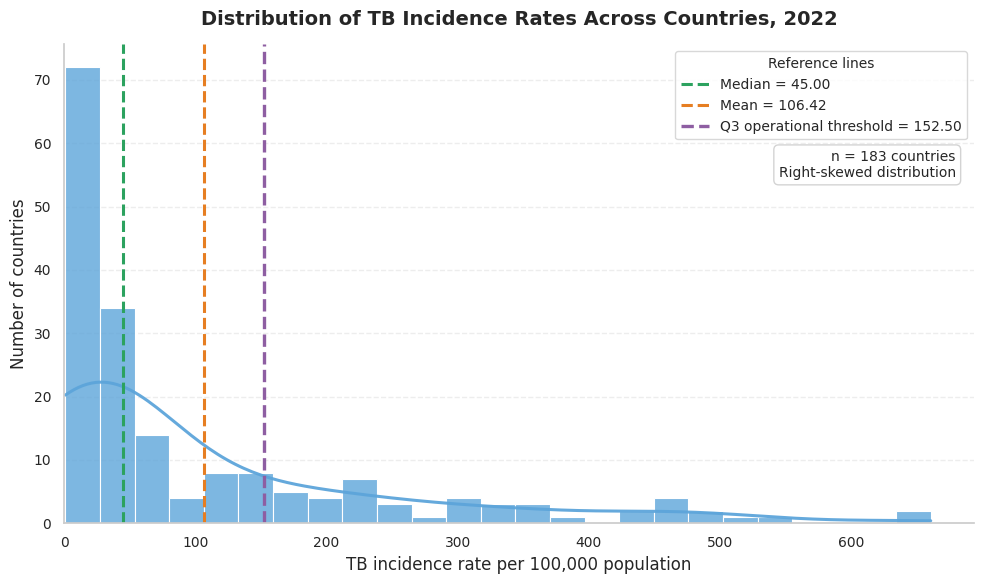

Number of histogram bins: 25
Mean TB incidence: 106.42
Median TB incidence: 45.0
Q3 operational threshold: 152.5
Figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/01_tb_incidence_distribution_histogram.png
Figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/01_tb_incidence_distribution_histogram.pdf


In [34]:
# TB incidence distribution histogram

# This visualization shows the distribution of TB incidence rates across countries.
# The Q3 line is shown as a data-driven operational threshold, not as an official WHO threshold.

tb_incidence = tb_dataset["TB_incidence_2022"].dropna()

mean_tb_incidence = tb_incidence.mean()
median_tb_incidence = tb_incidence.median()
q3_threshold = tb_incidence.quantile(0.75)

TB_HISTOGRAM_PATH = FIGURES_DIR / "01_tb_incidence_distribution_histogram.png"
TB_HISTOGRAM_PDF_PATH = FIGURES_DIR / "01_tb_incidence_distribution_histogram.pdf"

N_HISTOGRAM_BINS = 25

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    x=tb_incidence,
    bins=N_HISTOGRAM_BINS,
    stat="count",
    kde=True,
    color="#5DA5DA",
    edgecolor="white",
    linewidth=0.8,
    alpha=0.80,
    kde_kws={"bw_adjust": 1.1},
    line_kws={"linewidth": 2.2, "alpha": 0.95},
    ax=ax
)

ax.axvline(
    median_tb_incidence,
    color="#2CA25F",
    linestyle="--",
    linewidth=2.2,
    label=f"Median = {median_tb_incidence:.2f}"
)

ax.axvline(
    mean_tb_incidence,
    color="#E67E22",
    linestyle="--",
    linewidth=2.2,
    label=f"Mean = {mean_tb_incidence:.2f}"
)

ax.axvline(
    q3_threshold,
    color="#8E5EA2",
    linestyle="--",
    linewidth=2.4,
    label=f"Q3 operational threshold = {q3_threshold:.2f}"
)

ax.set_title(
    "Distribution of TB Incidence Rates Across Countries, 2022",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "TB incidence rate per 100,000 population",
    fontsize=12
)

ax.set_ylabel(
    "Number of countries",
    fontsize=12
)

ax.set_xlim(left=0)

ax.text(
    0.98,
    0.78,
    f"n = {len(tb_incidence)} countries\nRight-skewed distribution",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#CFCFCF",
        alpha=0.90
    )
)

ax.legend(
    title="Reference lines",
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=10)

plt.tight_layout()

fig.savefig(
    TB_HISTOGRAM_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    TB_HISTOGRAM_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("Number of histogram bins:", N_HISTOGRAM_BINS)
print("Mean TB incidence:", round(mean_tb_incidence, 2))
print("Median TB incidence:", round(median_tb_incidence, 2))
print("Q3 operational threshold:", round(q3_threshold, 2))
print("Figure saved as PNG:", TB_HISTOGRAM_PATH.exists())
print("PNG path:", TB_HISTOGRAM_PATH)
print("Figure saved as PDF:", TB_HISTOGRAM_PDF_PATH.exists())
print("PDF path:", TB_HISTOGRAM_PDF_PATH)

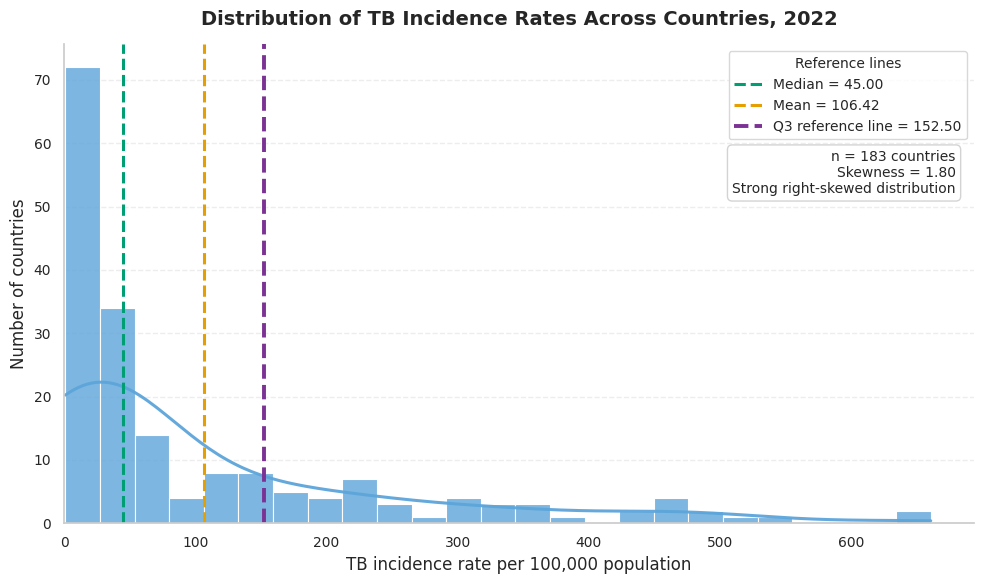

Number of histogram bins: 25
Mean TB incidence: 106.42
Median TB incidence: 45.00
Q3 reference value: 152.50
Skewness: 1.80
Skewness interpretation: Strong right-skewed distribution
Figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/01_tb_incidence_distribution_histogram.png
Figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/01_tb_incidence_distribution_histogram.pdf


In [35]:
# TB incidence distribution histogram

# This visualization shows the distribution of TB incidence rates across countries.
# The Q3 line is shown as a descriptive reference line / candidate threshold,
# not as an official WHO threshold.

tb_incidence_column = "TB_incidence_2022"

if tb_incidence_column not in tb_dataset.columns:
    raise KeyError(
        f"Required column '{tb_incidence_column}' was not found in the dataset."
    )

tb_incidence = tb_dataset[tb_incidence_column].copy()

if tb_incidence.isna().any():
    raise ValueError(
        "TB incidence contains missing values. Review before visualization."
    )

if np.isinf(tb_incidence).any():
    raise ValueError(
        "TB incidence contains infinite values. Review before visualization."
    )

if (tb_incidence < 0).any():
    raise ValueError(
        "TB incidence contains negative values. Review before visualization."
    )

mean_tb_incidence = tb_incidence.mean()
median_tb_incidence = tb_incidence.median()
q3_reference_value = tb_incidence.quantile(0.75)
tb_incidence_skewness = tb_incidence.skew()

if tb_incidence_skewness > 1:
    skewness_interpretation = "Strong right-skewed distribution"
elif tb_incidence_skewness > 0.5:
    skewness_interpretation = "Moderate right-skewed distribution"
elif tb_incidence_skewness < -1:
    skewness_interpretation = "Strong left-skewed distribution"
elif tb_incidence_skewness < -0.5:
    skewness_interpretation = "Moderate left-skewed distribution"
else:
    skewness_interpretation = "Approximately symmetric distribution"

TB_HISTOGRAM_PATH = FIGURES_DIR / "01_tb_incidence_distribution_histogram.png"
TB_HISTOGRAM_PDF_PATH = FIGURES_DIR / "01_tb_incidence_distribution_histogram.pdf"

N_HISTOGRAM_BINS = 25

HIST_COLOR = "#5DA5DA"    # Original blue for histogram bins
KDE_COLOR = "#1F78B4"     # Darker blue for KDE line
MEAN_COLOR = "#E69F00"    # Orange for mean
MEDIAN_COLOR = "#009E73"  # Green for median
Q3_COLOR = "#7B3294"      # Purple for Q3 reference line

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    x=tb_incidence,
    bins=N_HISTOGRAM_BINS,
    stat="count",
    kde=True,
    color=HIST_COLOR,
    edgecolor="white",
    linewidth=0.8,
    alpha=0.80,
    kde_kws={
        "bw_adjust": 1.1,
        "cut": 0
    },
    line_kws={
        "color": KDE_COLOR,
        "linewidth": 2.2,
        "alpha": 0.95
    },
    ax=ax
)

ax.axvline(
    median_tb_incidence,
    color=MEDIAN_COLOR,
    linestyle="--",
    linewidth=2.2,
    label=f"Median = {median_tb_incidence:.2f}"
)

ax.axvline(
    mean_tb_incidence,
    color=MEAN_COLOR,
    linestyle="--",
    linewidth=2.2,
    label=f"Mean = {mean_tb_incidence:.2f}"
)

ax.axvline(
    q3_reference_value,
    color=Q3_COLOR,
    linestyle="--",
    linewidth=2.8,
    label=f"Q3 reference line = {q3_reference_value:.2f}"
)

ax.set_title(
    "Distribution of TB Incidence Rates Across Countries, 2022",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "TB incidence rate per 100,000 population",
    fontsize=12
)

ax.set_ylabel(
    "Number of countries",
    fontsize=12
)

ax.set_xlim(left=0)

ax.text(
    0.98,
    0.78,
    (
        f"n = {len(tb_incidence)} countries\n"
        f"Skewness = {tb_incidence_skewness:.2f}\n"
        f"{skewness_interpretation}"
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#CFCFCF",
        alpha=0.90
    )
)

ax.legend(
    title="Reference lines",
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=10)

plt.tight_layout()

fig.savefig(
    TB_HISTOGRAM_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    TB_HISTOGRAM_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Number of histogram bins: {N_HISTOGRAM_BINS}")
print(f"Mean TB incidence: {mean_tb_incidence:.2f}")
print(f"Median TB incidence: {median_tb_incidence:.2f}")
print(f"Q3 reference value: {q3_reference_value:.2f}")
print(f"Skewness: {tb_incidence_skewness:.2f}")
print(f"Skewness interpretation: {skewness_interpretation}")
print(f"Figure saved as PNG: {TB_HISTOGRAM_PATH.exists()}")
print(f"PNG path: {TB_HISTOGRAM_PATH}")
print(f"Figure saved as PDF: {TB_HISTOGRAM_PDF_PATH.exists()}")
print(f"PDF path: {TB_HISTOGRAM_PDF_PATH}")

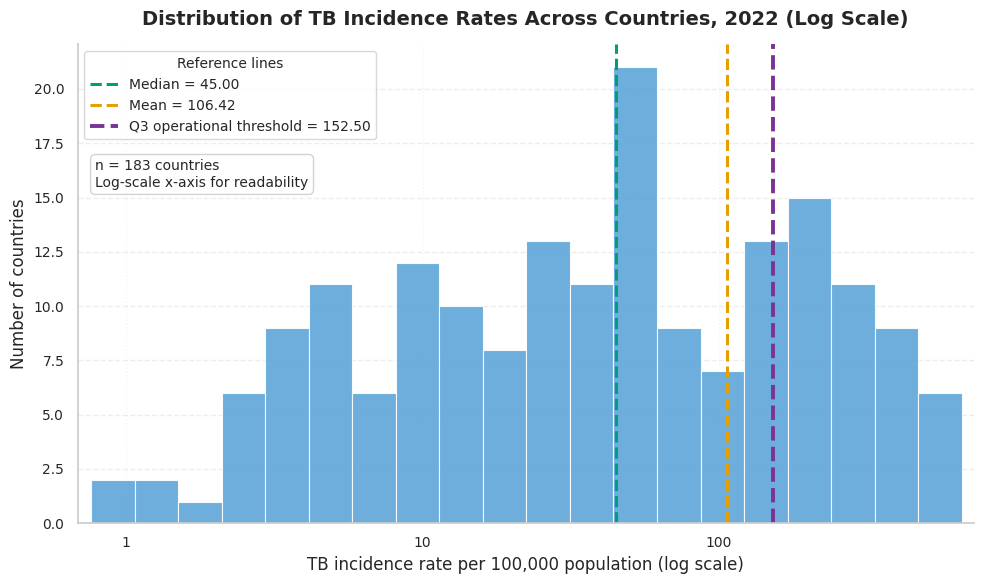

Number of log-scale histogram bins: 20
Mean TB incidence: 106.42
Median TB incidence: 45.0
Q3 operational threshold: 152.5
Figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/02_tb_incidence_distribution_histogram_log_scale.png
Figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/02_tb_incidence_distribution_histogram_log_scale.pdf


In [36]:
# Log-scale histogram of TB incidence distribution

# This visualization is used as a complementary view of the TB incidence distribution.
# The original TB incidence values are not transformed.
# Only the x-axis is shown on a logarithmic scale to improve readability because
# the distribution is strongly right-skewed.

from matplotlib.ticker import ScalarFormatter

tb_incidence = tb_dataset["TB_incidence_2022"].dropna()

mean_tb_incidence = tb_incidence.mean()
median_tb_incidence = tb_incidence.median()
q3_threshold = tb_incidence.quantile(0.75)

TB_LOG_HISTOGRAM_PATH = FIGURES_DIR / "02_tb_incidence_distribution_histogram_log_scale.png"
TB_LOG_HISTOGRAM_PDF_PATH = FIGURES_DIR / "02_tb_incidence_distribution_histogram_log_scale.pdf"

if (tb_incidence <= 0).any():
    raise ValueError("Log-scale visualization requires strictly positive TB incidence values.")

N_LOG_HISTOGRAM_BINS = 20

log_bin_edges = np.logspace(
    np.log10(tb_incidence.min()),
    np.log10(tb_incidence.max()),
    N_LOG_HISTOGRAM_BINS + 1
)

HIST_COLOR = "#5DA5DA"
MEAN_COLOR = "#E69F00"
MEDIAN_COLOR = "#009E73"
Q3_COLOR = "#7B3294"

fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(
    tb_incidence,
    bins=log_bin_edges,
    color=HIST_COLOR,
    edgecolor="white",
    linewidth=0.8,
    alpha=0.90
)

ax.axvline(
    median_tb_incidence,
    color=MEDIAN_COLOR,
    linestyle="--",
    linewidth=2.2,
    label=f"Median = {median_tb_incidence:.2f}"
)

ax.axvline(
    mean_tb_incidence,
    color=MEAN_COLOR,
    linestyle="--",
    linewidth=2.2,
    label=f"Mean = {mean_tb_incidence:.2f}"
)

ax.axvline(
    q3_threshold,
    color=Q3_COLOR,
    linestyle="--",
    linewidth=2.8,
    label=f"Q3 operational threshold = {q3_threshold:.2f}"
)

ax.set_xscale("log")

ax.set_title(
    "Distribution of TB Incidence Rates Across Countries, 2022 (Log Scale)",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "TB incidence rate per 100,000 population (log scale)",
    fontsize=12
)

ax.set_ylabel(
    "Number of countries",
    fontsize=12
)

ax.set_xlim(
    left=tb_incidence.min() * 0.9,
    right=tb_incidence.max() * 1.1
)

ax.xaxis.set_major_formatter(ScalarFormatter())
ax.ticklabel_format(axis="x", style="plain")

ax.text(
    0.02,
    0.76,
    f"n = {len(tb_incidence)} countries\nLog-scale x-axis for readability",
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#CFCFCF",
        alpha=0.90
    )
)

ax.legend(
    title="Reference lines",
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.grid(axis="x", linestyle=":", alpha=0.20)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=10)

plt.tight_layout()

fig.savefig(
    TB_LOG_HISTOGRAM_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    TB_LOG_HISTOGRAM_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("Number of log-scale histogram bins:", N_LOG_HISTOGRAM_BINS)
print("Mean TB incidence:", round(mean_tb_incidence, 2))
print("Median TB incidence:", round(median_tb_incidence, 2))
print("Q3 operational threshold:", round(q3_threshold, 2))
print("Figure saved as PNG:", TB_LOG_HISTOGRAM_PATH.exists())
print("PNG path:", TB_LOG_HISTOGRAM_PATH)
print("Figure saved as PDF:", TB_LOG_HISTOGRAM_PDF_PATH.exists())
print("PDF path:", TB_LOG_HISTOGRAM_PDF_PATH)

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


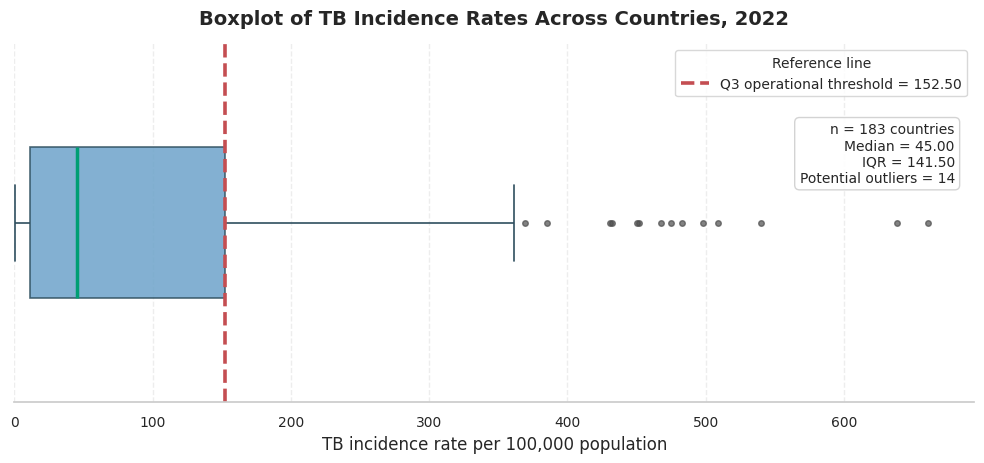

Q1 TB incidence: 11.0
Median TB incidence: 45.0
Q3 operational threshold: 152.5
IQR TB incidence: 141.5
Upper outlier cutoff: 364.75
Potential outliers: 14
Figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/03_tb_incidence_distribution_boxplot.png
Figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/03_tb_incidence_distribution_boxplot.pdf


In [37]:
tb_incidence = tb_dataset["TB_incidence_2022"].dropna()

q1_tb_incidence = tb_incidence.quantile(0.25)
median_tb_incidence = tb_incidence.median()
q3_threshold = tb_incidence.quantile(0.75)
iqr_tb_incidence = q3_threshold - q1_tb_incidence

upper_outlier_cutoff = q3_threshold + 1.5 * iqr_tb_incidence
lower_outlier_cutoff = q1_tb_incidence - 1.5 * iqr_tb_incidence

potential_outliers_count = (
    (tb_incidence < lower_outlier_cutoff) |
    (tb_incidence > upper_outlier_cutoff)
).sum()

TB_BOXPLOT_PATH = FIGURES_DIR / "03_tb_incidence_distribution_boxplot.png"
TB_BOXPLOT_PDF_PATH = FIGURES_DIR / "03_tb_incidence_distribution_boxplot.pdf"

BOX_COLOR = "#5DA5DA"
EDGE_COLOR = "#2F4F5F"
MEDIAN_COLOR = "#009E73"
Q3_COLOR = "#7B3294"
OUTLIER_COLOR = "#4D4D4D"

fig, ax = plt.subplots(figsize=(10, 4.8))

sns.boxplot(
    x=tb_incidence,
    color=BOX_COLOR,
    width=0.42,
    showfliers=True,
    boxprops={
        "edgecolor": EDGE_COLOR,
        "linewidth": 1.2,
        "alpha": 0.85
    },
    whiskerprops={
        "color": EDGE_COLOR,
        "linewidth": 1.2
    },
    capprops={
        "color": EDGE_COLOR,
        "linewidth": 1.2
    },
    medianprops={
        "color": MEDIAN_COLOR,
        "linewidth": 2.5
    },
    flierprops={
        "marker": "o",
        "markerfacecolor": OUTLIER_COLOR,
        "markeredgecolor": OUTLIER_COLOR,
        "markersize": 4,
        "alpha": 0.70
    },
    ax=ax
)

ax.axvline(
    q3_threshold,
    color="#C44E52",
    linestyle="--",
    linewidth=2.6,
    label=f"Q3 operational threshold = {q3_threshold:.2f}"
)

ax.set_title(
    "Boxplot of TB Incidence Rates Across Countries, 2022",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "TB incidence rate per 100,000 population",
    fontsize=12
)

ax.set_ylabel("")

ax.set_xlim(left=0)

ax.text(
    0.98,
    0.78,
    (
        f"n = {len(tb_incidence)} countries\n"
        f"Median = {median_tb_incidence:.2f}\n"
        f"IQR = {iqr_tb_incidence:.2f}\n"
        f"Potential outliers = {potential_outliers_count}"
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#CFCFCF",
        alpha=0.90
    )
)

ax.legend(
    title="Reference line",
    loc="upper right",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.grid(axis="y", visible=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", left=False, labelleft=False)

plt.tight_layout()

fig.savefig(
    TB_BOXPLOT_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    TB_BOXPLOT_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("Q1 TB incidence:", round(q1_tb_incidence, 2))
print("Median TB incidence:", round(median_tb_incidence, 2))
print("Q3 operational threshold:", round(q3_threshold, 2))
print("IQR TB incidence:", round(iqr_tb_incidence, 2))
print("Upper outlier cutoff:", round(upper_outlier_cutoff, 2))
print("Potential outliers:", potential_outliers_count)
print("Figure saved as PNG:", TB_BOXPLOT_PATH.exists())
print("PNG path:", TB_BOXPLOT_PATH)
print("Figure saved as PDF:", TB_BOXPLOT_PDF_PATH.exists())
print("PDF path:", TB_BOXPLOT_PDF_PATH)

In [38]:
# Top countries by TB incidence

# This table identifies the countries with the highest TB incidence rates in 2022.
# These countries contribute to the upper tail of the strongly right-skewed distribution.
# The Q3 operational threshold is included for comparison because it is later used
# to define the binary high_tb_burden target.

required_top_tb_columns = ["Area", "TB_incidence_2022"]

missing_top_tb_columns = [
    column for column in required_top_tb_columns
    if column not in tb_dataset.columns
]

if missing_top_tb_columns:
    raise KeyError(
        f"Missing required columns for top TB incidence table: {missing_top_tb_columns}"
    )

tb_incidence = tb_dataset["TB_incidence_2022"].dropna()
q3_threshold = tb_incidence.quantile(0.75)

TOP_N_TB_INCIDENCE = 60

top_tb_incidence = (
    tb_dataset[required_top_tb_columns]
    .copy()
    .sort_values(
        by=["TB_incidence_2022", "Area"],
        ascending=[False, True]
    )
    .head(TOP_N_TB_INCIDENCE)
    .reset_index(drop=True)
)

top_tb_incidence.insert(
    0,
    "rank",
    range(1, len(top_tb_incidence) + 1)
)

top_tb_incidence["above_q3_operational_threshold"] = (
    top_tb_incidence["TB_incidence_2022"] > q3_threshold
)

top_tb_incidence["difference_from_q3_operational_threshold"] = (
    top_tb_incidence["TB_incidence_2022"] - q3_threshold
).round(2)

top_tb_incidence = top_tb_incidence.rename(columns={
    "Area": "country",
    "TB_incidence_2022": "tb_incidence_rate_per_100k"
})

top_tb_incidence["tb_incidence_rate_per_100k"] = (
    top_tb_incidence["tb_incidence_rate_per_100k"].round(2)
)

display(top_tb_incidence)

top_tb_incidence_csv_path = (
    TABLES_DIR / f"01_top_{TOP_N_TB_INCIDENCE}_countries_by_tb_incidence.csv"
)

top_tb_incidence_excel_path = (
    TABLES_DIR / f"01_top_{TOP_N_TB_INCIDENCE}_countries_by_tb_incidence.xlsx"
)

top_tb_incidence.to_csv(top_tb_incidence_csv_path, index=False)
top_tb_incidence.to_excel(top_tb_incidence_excel_path, index=False)

expected_number_of_rows = min(TOP_N_TB_INCIDENCE, len(tb_dataset))

if len(top_tb_incidence) != expected_number_of_rows:
    raise ValueError(
        f"Expected {expected_number_of_rows} countries in the top TB incidence table, "
        f"got {len(top_tb_incidence)}."
    )

if not top_tb_incidence["tb_incidence_rate_per_100k"].is_monotonic_decreasing:
    raise ValueError("Top TB incidence table is not sorted in descending order.")

print(f"Top {TOP_N_TB_INCIDENCE} TB incidence table created successfully.")
print(f"Q3 operational threshold used for comparison: {q3_threshold:.2f}")
print(f"Top {TOP_N_TB_INCIDENCE} table saved as CSV: {top_tb_incidence_csv_path}")
print(f"Top {TOP_N_TB_INCIDENCE} table saved as Excel: {top_tb_incidence_excel_path}")

,rank,country,tb_incidence_rate_per_100k,above_q3_operational_threshold,difference_from_q3_operational_threshold
0,1,Lesotho,661.0,True,508.5
1,2,Philippines,638.0,True,485.5
2,3,Central African Republic,540.0,True,387.5
3,4,Gabon,509.0,True,356.5
4,5,Timor-Leste,498.0,True,345.5
5,6,Marshall Islands,483.0,True,330.5
6,7,Myanmar,475.0,True,322.5
7,8,South Africa,468.0,True,315.5
8,9,Mongolia,452.0,True,299.5
9,10,Namibia,450.0,True,297.5


Top 60 TB incidence table created successfully.
Q3 operational threshold used for comparison: 152.50
Top 60 table saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/01_top_60_countries_by_tb_incidence.csv
Top 60 table saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/01_top_60_countries_by_tb_incidence.xlsx


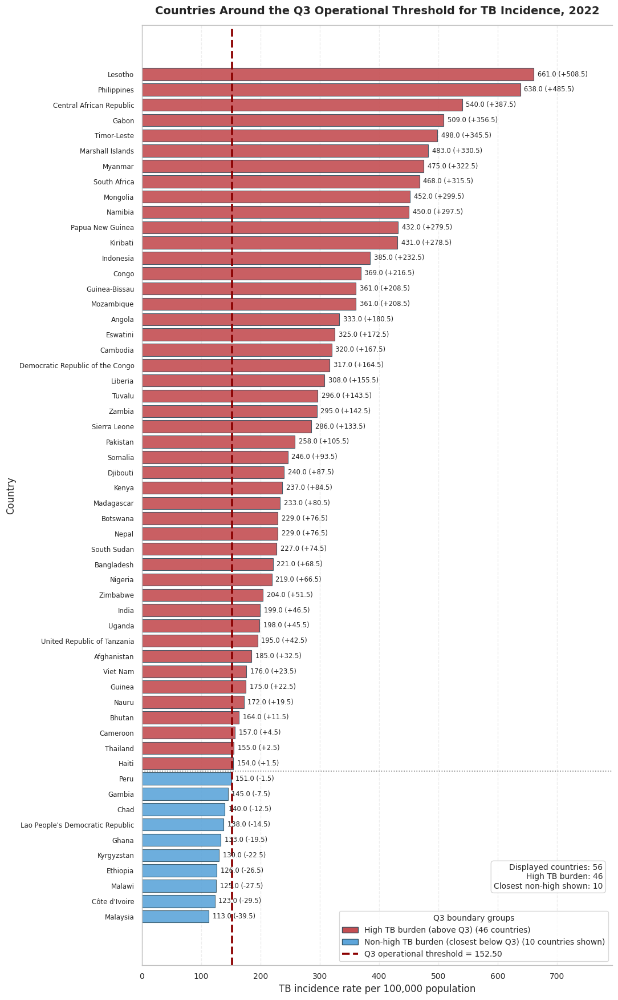

Q3 operational threshold: 152.5
Countries above Q3 threshold: 46
Closest countries below Q3 shown: 10
Figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/04_q3_threshold_boundary_countries_by_tb_incidence.png
Figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/04_q3_threshold_boundary_countries_by_tb_incidence.pdf


In [39]:
# Countries above the Q3 operational threshold and the 10 closest countries below it

# This figure shows all countries classified as high TB burden using the Q3 operational threshold,
# together with the 10 countries immediately below the threshold.
# This helps visualize the decision boundary used to define the binary target.

from matplotlib.patches import Patch
from matplotlib.lines import Line2D

required_tb_columns = ["Area", "TB_incidence_2022"]

missing_tb_columns = [
    column for column in required_tb_columns
    if column not in tb_dataset.columns
]

if missing_tb_columns:
    raise KeyError(
        f"Missing required columns for Q3 boundary plot: {missing_tb_columns}"
    )

tb_incidence = tb_dataset["TB_incidence_2022"].dropna()
q3_threshold = tb_incidence.quantile(0.75)

N_BELOW_Q3_TO_SHOW = 10

countries_above_q3 = (
    tb_dataset[required_tb_columns]
    .copy()
    .loc[lambda df: df["TB_incidence_2022"] > q3_threshold]
    .assign(q3_group="High TB burden (above Q3)")
)

countries_below_q3_closest = (
    tb_dataset[required_tb_columns]
    .copy()
    .loc[lambda df: df["TB_incidence_2022"] <= q3_threshold]
    .sort_values(
        by=["TB_incidence_2022", "Area"],
        ascending=[False, True]
    )
    .head(N_BELOW_Q3_TO_SHOW)
    .assign(q3_group="Non-high TB burden (closest below Q3)")
)

q3_boundary_plot_data = (
    pd.concat(
        [countries_above_q3, countries_below_q3_closest],
        axis=0
    )
    .sort_values(
        by=["TB_incidence_2022", "Area"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

q3_boundary_plot_data.insert(
    0,
    "rank",
    range(1, len(q3_boundary_plot_data) + 1)
)

q3_boundary_plot_data["difference_from_q3_operational_threshold"] = (
    q3_boundary_plot_data["TB_incidence_2022"] - q3_threshold
).round(2)

q3_boundary_plot_data = q3_boundary_plot_data.rename(columns={
    "Area": "country",
    "TB_incidence_2022": "tb_incidence_rate_per_100k"
})

q3_boundary_plot_data["tb_incidence_rate_per_100k"] = (
    q3_boundary_plot_data["tb_incidence_rate_per_100k"].round(2)
)

n_above_q3 = (
    q3_boundary_plot_data["q3_group"] == "High TB burden (above Q3)"
).sum()

n_below_q3_shown = (
    q3_boundary_plot_data["q3_group"] == "Non-high TB burden (closest below Q3)"
).sum()

Q3_BOUNDARY_FIGURE_PATH = (
    FIGURES_DIR / "04_q3_threshold_boundary_countries_by_tb_incidence.png"
)

Q3_BOUNDARY_FIGURE_PDF_PATH = (
    FIGURES_DIR / "04_q3_threshold_boundary_countries_by_tb_incidence.pdf"
)

HIGH_COLOR = "#C44E52"       # red for high TB burden
LOW_COLOR = "#5DA5DA"        # blue for non-high countries closest below Q3
BAR_EDGE_COLOR = "#2F4F5F"
Q3_COLOR = "#8B0000"         # darker red for Q3 threshold line
FRAME_COLOR = "#BFBFBF"

bar_colors = q3_boundary_plot_data["q3_group"].map({
    "High TB burden (above Q3)": HIGH_COLOR,
    "Non-high TB burden (closest below Q3)": LOW_COLOR
})

figure_height = max(9, 0.28 * len(q3_boundary_plot_data) + 2)

fig, ax = plt.subplots(figsize=(11, figure_height))

ax.barh(
    y=q3_boundary_plot_data["country"],
    width=q3_boundary_plot_data["tb_incidence_rate_per_100k"],
    color=bar_colors,
    edgecolor=BAR_EDGE_COLOR,
    linewidth=0.8,
    alpha=0.90
)

ax.invert_yaxis()

ax.axvline(
    q3_threshold,
    color=Q3_COLOR,
    linestyle="--",
    linewidth=2.6,
    label=f"Q3 operational threshold = {q3_threshold:.2f}"
)

# Separator between high TB burden countries and closest countries below Q3
ax.axhline(
    y=n_above_q3 - 0.5,
    color="#666666",
    linestyle=":",
    linewidth=1.2,
    alpha=0.80
)

max_incidence = q3_boundary_plot_data["tb_incidence_rate_per_100k"].max()
label_offset = max_incidence * 0.01

for i, row in q3_boundary_plot_data.iterrows():
    incidence_value = row["tb_incidence_rate_per_100k"]
    difference_from_q3 = row["difference_from_q3_operational_threshold"]

    sign = "+" if difference_from_q3 > 0 else ""

    ax.text(
        incidence_value + label_offset,
        i,
        f"{incidence_value:.1f} ({sign}{difference_from_q3:.1f})",
        va="center",
        fontsize=8.3
    )

ax.set_xlim(
    0,
    max_incidence * 1.20
)

ax.set_title(
    "Countries Around the Q3 Operational Threshold for TB Incidence, 2022",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "TB incidence rate per 100,000 population",
    fontsize=12
)

ax.set_ylabel(
    "Country",
    fontsize=12
)

legend_handles = [
    Patch(
        facecolor=HIGH_COLOR,
        edgecolor=BAR_EDGE_COLOR,
        label=f"High TB burden (above Q3) ({n_above_q3} countries)"
    ),
    Patch(
        facecolor=LOW_COLOR,
        edgecolor=BAR_EDGE_COLOR,
        label=f"Non-high TB burden (closest below Q3) ({n_below_q3_shown} countries shown)"
    ),
    Line2D(
        [0],
        [0],
        color=Q3_COLOR,
        linestyle="--",
        linewidth=2.6,
        label=f"Q3 operational threshold = {q3_threshold:.2f}"
    )
]

ax.legend(
    handles=legend_handles,
    title="Q3 boundary groups",
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.text(
    0.98,
    0.08,
    (
        f"Displayed countries: {len(q3_boundary_plot_data)}\n"
        f"High TB burden: {n_above_q3}\n"
        f"Closest non-high shown: {n_below_q3_shown}"
    ),
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#CFCFCF",
        alpha=0.90
    )
)

ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.grid(axis="y", visible=False)

# Keep a clear but subtle plot frame
ax.spines["top"].set_visible(True)
ax.spines["top"].set_color(FRAME_COLOR)
ax.spines["top"].set_linewidth(1.0)

ax.spines["left"].set_visible(True)
ax.spines["left"].set_color(FRAME_COLOR)
ax.spines["left"].set_linewidth(1.0)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color(FRAME_COLOR)
ax.spines["bottom"].set_linewidth(1.0)

ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=8.5)

plt.tight_layout()

fig.savefig(
    Q3_BOUNDARY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    Q3_BOUNDARY_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("Q3 operational threshold:", round(q3_threshold, 2))
print("Countries above Q3 threshold:", n_above_q3)
print("Closest countries below Q3 shown:", n_below_q3_shown)
print("Figure saved as PNG:", Q3_BOUNDARY_FIGURE_PATH.exists())
print("PNG path:", Q3_BOUNDARY_FIGURE_PATH)
print("Figure saved as PDF:", Q3_BOUNDARY_FIGURE_PDF_PATH.exists())
print("PDF path:", Q3_BOUNDARY_FIGURE_PDF_PATH)

In [40]:
target_source_column = "TB_incidence_2022"
target_column = "high_tb_burden"
target_label_column = "tb_burden_group"

if target_source_column not in tb_dataset.columns:
    raise KeyError(
        f"Required target source column '{target_source_column}' was not found."
    )

if tb_dataset[target_source_column].isna().sum() > 0:
    raise ValueError(
        f"Target source column '{target_source_column}' contains missing values."
    )

if not np.isfinite(tb_dataset[target_source_column]).all():
    raise ValueError(
        f"Target source column '{target_source_column}' contains infinite or non-finite values."
    )

if (tb_dataset[target_source_column] < 0).any():
    raise ValueError(
        f"Target source column '{target_source_column}' contains negative values."
    )

q3_threshold = float(tb_dataset[target_source_column].quantile(0.75))

countries_equal_to_q3 = int(
    (tb_dataset[target_source_column] == q3_threshold).sum()
)

tb_dataset[target_column] = (
    tb_dataset[target_source_column] >= q3_threshold
).astype(int)

tb_dataset[target_label_column] = np.where(
    tb_dataset[target_column] == 1,
    "high_tb_burden",
    "non_high_tb_burden"
)

target_distribution_summary = (
    tb_dataset
    .groupby([target_column, target_label_column])
    .size()
    .reset_index(name="number_of_countries")
)

target_distribution_summary["percentage"] = (
    target_distribution_summary["number_of_countries"]
    / len(tb_dataset)
    * 100
).round(2)

target_distribution_summary = target_distribution_summary.sort_values(
    by=target_column,
    ascending=True
).reset_index(drop=True)

high_tb_burden_count = int((tb_dataset[target_column] == 1).sum())
non_high_tb_burden_count = int((tb_dataset[target_column] == 0).sum())

target_creation_summary = pd.DataFrame({
    "metric": [
        "target_source_column",
        "q3_operational_threshold",
        "classification_rule",
        "countries_equal_to_q3_threshold",
        "number_of_rows",
        "number_of_columns_after_target_creation",
        "high_tb_burden_count",
        "non_high_tb_burden_count",
        "high_tb_burden_percentage",
        "non_high_tb_burden_percentage"
    ],
    "value": [
        target_source_column,
        round(q3_threshold, 3),
        "high_tb_burden = 1 if TB_incidence_2022 >= Q3 operational threshold",
        countries_equal_to_q3,
        tb_dataset.shape[0],
        tb_dataset.shape[1],
        high_tb_burden_count,
        non_high_tb_burden_count,
        round(high_tb_burden_count / len(tb_dataset) * 100, 2),
        round(non_high_tb_burden_count / len(tb_dataset) * 100, 2)
    ]
})

display(target_creation_summary)
display(target_distribution_summary)

target_creation_summary_csv_path = TABLES_DIR / "02_target_creation_summary.csv"
target_creation_summary_excel_path = TABLES_DIR / "02_target_creation_summary.xlsx"

target_distribution_csv_path = TABLES_DIR / "02_target_distribution_summary.csv"
target_distribution_excel_path = TABLES_DIR / "02_target_distribution_summary.xlsx"

target_creation_summary.to_csv(target_creation_summary_csv_path, index=False)
target_creation_summary.to_excel(target_creation_summary_excel_path, index=False)

target_distribution_summary.to_csv(target_distribution_csv_path, index=False)
target_distribution_summary.to_excel(target_distribution_excel_path, index=False)

if set(tb_dataset[target_column].unique()) != {0, 1}:
    raise ValueError("Target column must contain only binary values 0 and 1.")

if tb_dataset[[target_column, target_label_column]].isna().sum().sum() > 0:
    raise ValueError("Target columns contain missing values.")

if len(tb_dataset) != target_distribution_summary["number_of_countries"].sum():
    raise ValueError(
        "Target distribution counts do not match the number of dataset rows."
    )

if high_tb_burden_count == 0 or non_high_tb_burden_count == 0:
    raise ValueError(
        "Both target classes must contain at least one country."
    )

print(f"Q3 operational threshold: {q3_threshold:.3f}")
print(f"Classification rule: high_tb_burden = 1 if TB_incidence_2022 >= {q3_threshold:.3f}")
print(f"Countries exactly equal to Q3 threshold: {countries_equal_to_q3}")
print(f"High TB burden countries: {high_tb_burden_count}")
print(f"Non-high TB burden countries: {non_high_tb_burden_count}")
print(f"Updated dataset shape: {tb_dataset.shape}")
print("Target creation check passed.")
print(f"Target creation summary saved as CSV: {target_creation_summary_csv_path}")
print(f"Target creation summary saved as Excel: {target_creation_summary_excel_path}")
print(f"Target distribution summary saved as CSV: {target_distribution_csv_path}")
print(f"Target distribution summary saved as Excel: {target_distribution_excel_path}")

,metric,value
0,target_source_column,TB_incidence_2022
1,q3_operational_threshold,152.5
2,classification_rule,high_tb_burden = 1 if TB_incidence_2022 >= Q3 ...
3,countries_equal_to_q3_threshold,0
4,number_of_rows,183
5,number_of_columns_after_target_creation,51
6,high_tb_burden_count,46
7,non_high_tb_burden_count,137
8,high_tb_burden_percentage,25.14
9,non_high_tb_burden_percentage,74.86


,high_tb_burden,tb_burden_group,number_of_countries,percentage
0,0,non_high_tb_burden,137,74.86
1,1,high_tb_burden,46,25.14


Q3 operational threshold: 152.500
Classification rule: high_tb_burden = 1 if TB_incidence_2022 >= 152.500
Countries exactly equal to Q3 threshold: 0
High TB burden countries: 46
Non-high TB burden countries: 137
Updated dataset shape: (183, 51)
Target creation check passed.
Target creation summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/02_target_creation_summary.csv
Target creation summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/02_target_creation_summary.xlsx
Target distribution summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/02_target_distribution_summary.csv
Target distribution summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/02_target_distribution_summary.xlsx


In [41]:
# Global visualization style settings

FIGURE_DPI = 300

CLASS_ORDER = [
    "non_high_tb_burden",
    "high_tb_burden"
]

CLASS_DISPLAY_LABELS = {
    "non_high_tb_burden": "Non-high TB burden",
    "high_tb_burden": "High TB burden"
}

CLASS_COLORS = {
    "non_high_tb_burden": "#4C78A8",
    "high_tb_burden": "#C44E52"
}

Q3_THRESHOLD_COLOR = "#8B0000"
MEDIAN_COLOR = "#009E73"
MEAN_COLOR = "#E69F00"
HISTOGRAM_COLOR = "#5DA5DA"
NEUTRAL_DARK_COLOR = "#2F2F2F"
GRID_COLOR_ALPHA = 0.35

sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": FIGURE_DPI,
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "axes.titlepad": 14,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("Visualization style settings configured successfully.")

Visualization style settings configured successfully.


,tb_burden_group,number_of_countries,percentage,display_label,high_tb_burden
0,non_high_tb_burden,137,74.86,Non-high TB burden,0
1,high_tb_burden,46,25.14,High TB burden,1


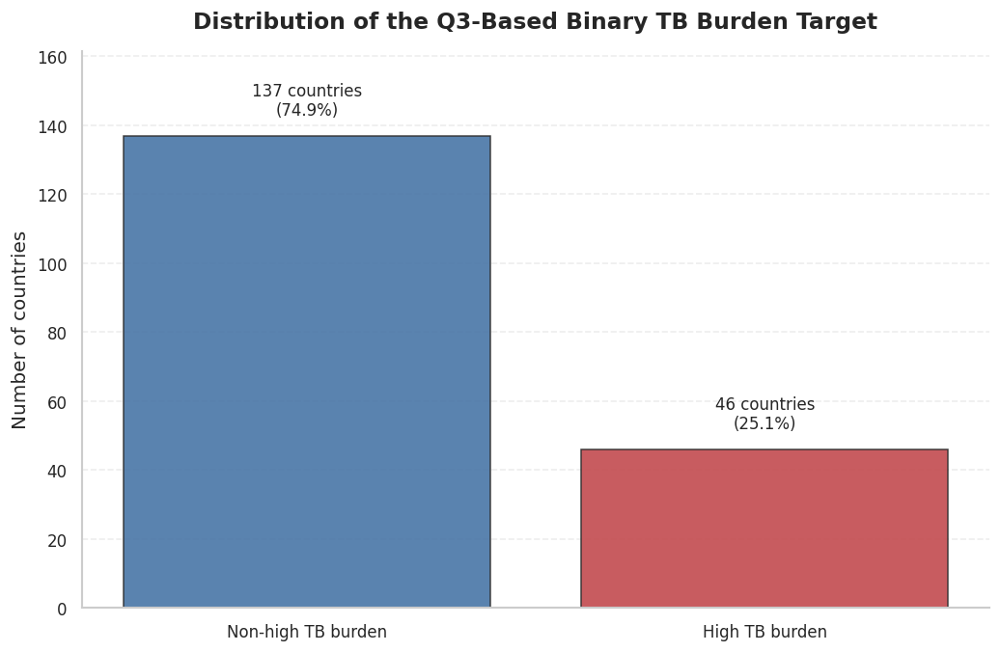

Target class distribution figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/05_target_class_distribution.png
Target class distribution figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/05_target_class_distribution.pdf
Target distribution visualization check passed.


In [42]:
TARGET_DISTRIBUTION_FIGURE_PATH = (
    FIGURES_DIR / "05_target_class_distribution.png"
)

TARGET_DISTRIBUTION_FIGURE_PDF_PATH = (
    FIGURES_DIR / "05_target_class_distribution.pdf"
)

required_target_distribution_columns = [
    "high_tb_burden",
    "tb_burden_group"
]

missing_target_distribution_columns = [
    column for column in required_target_distribution_columns
    if column not in tb_dataset.columns
]

if missing_target_distribution_columns:
    raise KeyError(
        "Missing required columns for target distribution visualization: "
        f"{missing_target_distribution_columns}"
    )

expected_group_from_target = {
    0: "non_high_tb_burden",
    1: "high_tb_burden"
}

target_group_consistency_check = (
    tb_dataset["high_tb_burden"]
    .map(expected_group_from_target)
    .eq(tb_dataset["tb_burden_group"])
)

if not target_group_consistency_check.all():
    inconsistent_rows = tb_dataset.loc[
        ~target_group_consistency_check,
        ["Area", "high_tb_burden", "tb_burden_group"]
    ]

    raise ValueError(
        "Inconsistency detected between 'high_tb_burden' and "
        "'tb_burden_group'. Review target creation before plotting. "
        f"Number of inconsistent rows: {len(inconsistent_rows)}"
    )

target_class_distribution = (
    tb_dataset["tb_burden_group"]
    .value_counts()
    .reindex(CLASS_ORDER, fill_value=0)
    .rename_axis("tb_burden_group")
    .reset_index(name="number_of_countries")
)

target_class_distribution["percentage"] = (
    target_class_distribution["number_of_countries"]
    / len(tb_dataset)
    * 100
).round(2)

target_class_distribution["display_label"] = (
    target_class_distribution["tb_burden_group"]
    .map(CLASS_DISPLAY_LABELS)
)

if target_class_distribution["display_label"].isna().any():
    missing_display_labels = target_class_distribution.loc[
        target_class_distribution["display_label"].isna(),
        "tb_burden_group"
    ].tolist()

    raise ValueError(
        "Missing display labels for the following target classes: "
        f"{missing_display_labels}"
    )

target_class_distribution["high_tb_burden"] = (
    target_class_distribution["tb_burden_group"]
    .map({
        "non_high_tb_burden": 0,
        "high_tb_burden": 1
    })
)

display(target_class_distribution)

if target_class_distribution["number_of_countries"].sum() != len(tb_dataset):
    raise ValueError(
        "Target class distribution counts do not match the total number of countries."
    )

if (target_class_distribution["number_of_countries"] == 0).any():
    raise ValueError(
        "At least one target class has zero observations. Review target creation."
    )

bar_colors = [
    CLASS_COLORS[group]
    for group in target_class_distribution["tb_burden_group"]
]

max_count = target_class_distribution["number_of_countries"].max()
label_offset = max_count * 0.035

fig, ax = plt.subplots(figsize=(8.8, 5.8))

bars = ax.bar(
    target_class_distribution["display_label"],
    target_class_distribution["number_of_countries"],
    color=bar_colors,
    edgecolor=NEUTRAL_DARK_COLOR,
    linewidth=0.9,
    alpha=0.92
)

for bar, count, percentage in zip(
    bars,
    target_class_distribution["number_of_countries"],
    target_class_distribution["percentage"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + label_offset,
        f"{count} countries\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Distribution of the Q3-Based Binary TB Burden Target",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("")
ax.set_ylabel("Number of countries")

ax.set_ylim(
    0,
    max_count * 1.18
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=GRID_COLOR_ALPHA
)

ax.grid(
    axis="x",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)

plt.tight_layout()

fig.savefig(
    TARGET_DISTRIBUTION_FIGURE_PATH,
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

fig.savefig(
    TARGET_DISTRIBUTION_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print(
    "Target class distribution figure saved as PNG:",
    TARGET_DISTRIBUTION_FIGURE_PATH.exists()
)
print("PNG path:", TARGET_DISTRIBUTION_FIGURE_PATH)
print(
    "Target class distribution figure saved as PDF:",
    TARGET_DISTRIBUTION_FIGURE_PDF_PATH.exists()
)
print("PDF path:", TARGET_DISTRIBUTION_FIGURE_PDF_PATH)
print("Target distribution visualization check passed.")

,high_tb_burden,tb_burden_group,display_label,number_of_countries,minimum,q1,median,mean,q3,maximum
0,0,non_high_tb_burden,Non-high TB burden,137,0.76,7.20,24.0,36.56,52.0,151.0
1,1,high_tb_burden,High TB burden,46,154.00,207.75,290.5,314.48,419.5,661.0


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


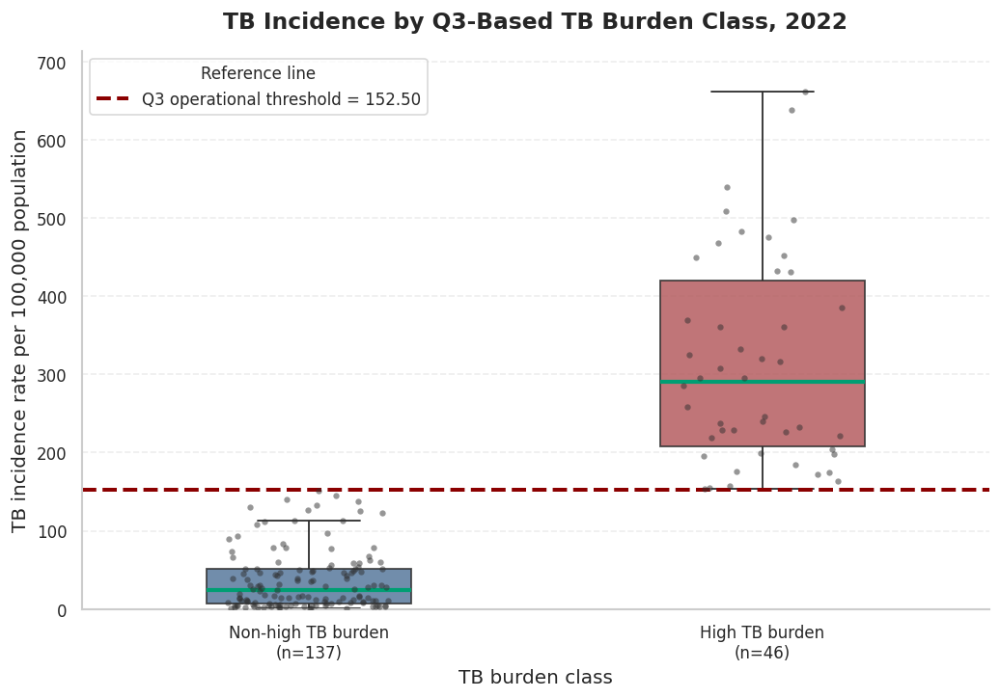

TB incidence by class summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/03_tb_incidence_by_target_class_summary.csv
TB incidence by class summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/03_tb_incidence_by_target_class_summary.xlsx
TB incidence by class figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/06_tb_incidence_by_target_class_box_strip.png
TB incidence by class figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/06_tb_incidence_by_target_class_box_strip.pdf
TB incidence by target class visualization check passed.


In [43]:
# Visualization 2: TB incidence by Q3-based TB burden class

# This visualization shows how TB incidence values are distributed across the two
# Q3-based target classes. Since the target was defined from TB_incidence_2022,
# this figure should be interpreted as a target-definition validation and explanation,
# not as an independent statistical finding.

TB_BY_CLASS_FIGURE_PATH = (
    FIGURES_DIR / "06_tb_incidence_by_target_class_box_strip.png"
)

TB_BY_CLASS_FIGURE_PDF_PATH = (
    FIGURES_DIR / "06_tb_incidence_by_target_class_box_strip.pdf"
)

required_tb_by_class_columns = [
    "Area",
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group"
]

missing_tb_by_class_columns = [
    column for column in required_tb_by_class_columns
    if column not in tb_dataset.columns
]

if missing_tb_by_class_columns:
    raise KeyError(
        "Missing required columns for TB incidence by class visualization: "
        f"{missing_tb_by_class_columns}"
    )

if not pd.api.types.is_numeric_dtype(tb_dataset["TB_incidence_2022"]):
    raise TypeError(
        "'TB_incidence_2022' must be numeric before creating this visualization."
    )

if tb_dataset["TB_incidence_2022"].isna().any():
    raise ValueError(
        "'TB_incidence_2022' contains missing values. Review the target-source column."
    )

tb_incidence = tb_dataset["TB_incidence_2022"].dropna()
q3_threshold = float(tb_incidence.quantile(0.75))

plot_data = tb_dataset[required_tb_by_class_columns].copy()

plot_data["display_label"] = (
    plot_data["tb_burden_group"]
    .map(CLASS_DISPLAY_LABELS)
)

if plot_data["display_label"].isna().any():
    missing_display_label_groups = (
        plot_data.loc[
            plot_data["display_label"].isna(),
            "tb_burden_group"
        ]
        .drop_duplicates()
        .tolist()
    )

    raise ValueError(
        "Missing display labels for the following target groups: "
        f"{missing_display_label_groups}"
    )

high_class_threshold_check = (
    plot_data.loc[
        plot_data["high_tb_burden"] == 1,
        "TB_incidence_2022"
    ] >= q3_threshold
).all()

non_high_class_threshold_check = (
    plot_data.loc[
        plot_data["high_tb_burden"] == 0,
        "TB_incidence_2022"
    ] < q3_threshold
).all()

if not high_class_threshold_check:
    raise ValueError(
        "At least one high TB burden country has TB incidence below the Q3 threshold."
    )

if not non_high_class_threshold_check:
    raise ValueError(
        "At least one non-high TB burden country has TB incidence equal to or above the Q3 threshold."
    )

class_counts = (
    plot_data["tb_burden_group"]
    .value_counts()
    .reindex(CLASS_ORDER)
)

display_order = [
    f"{CLASS_DISPLAY_LABELS[group]}\n(n={class_counts[group]})"
    for group in CLASS_ORDER
]

display_label_with_n_mapping = {
    CLASS_DISPLAY_LABELS[group]: f"{CLASS_DISPLAY_LABELS[group]}\n(n={class_counts[group]})"
    for group in CLASS_ORDER
}

plot_data["display_label_with_n"] = (
    plot_data["display_label"]
    .map(display_label_with_n_mapping)
)

class_color_by_display_label_with_n = {
    f"{CLASS_DISPLAY_LABELS[group]}\n(n={class_counts[group]})": CLASS_COLORS[group]
    for group in CLASS_ORDER
}

tb_incidence_by_class_summary = (
    plot_data
    .groupby(
        ["high_tb_burden", "tb_burden_group", "display_label"],
        observed=True
    )["TB_incidence_2022"]
    .agg(
        number_of_countries="count",
        minimum="min",
        q1=lambda values: values.quantile(0.25),
        median="median",
        mean="mean",
        q3=lambda values: values.quantile(0.75),
        maximum="max"
    )
    .reset_index()
    .sort_values("high_tb_burden")
    .reset_index(drop=True)
)

numeric_summary_columns = [
    "minimum",
    "q1",
    "median",
    "mean",
    "q3",
    "maximum"
]

tb_incidence_by_class_summary[numeric_summary_columns] = (
    tb_incidence_by_class_summary[numeric_summary_columns]
    .round(2)
)

display(tb_incidence_by_class_summary)

tb_by_class_summary_csv_path = (
    TABLES_DIR / "03_tb_incidence_by_target_class_summary.csv"
)

tb_by_class_summary_excel_path = (
    TABLES_DIR / "03_tb_incidence_by_target_class_summary.xlsx"
)

tb_incidence_by_class_summary.to_csv(
    tb_by_class_summary_csv_path,
    index=False
)

tb_incidence_by_class_summary.to_excel(
    tb_by_class_summary_excel_path,
    index=False
)

fig, ax = plt.subplots(figsize=(8.8, 6.2))

sns.boxplot(
    data=plot_data,
    x="display_label_with_n",
    y="TB_incidence_2022",
    order=display_order,
    hue="display_label_with_n",
    palette=class_color_by_display_label_with_n,
    width=0.45,
    showfliers=False,
    legend=False,
    boxprops={
        "edgecolor": NEUTRAL_DARK_COLOR,
        "linewidth": 1.1,
        "alpha": 0.85
    },
    whiskerprops={
        "color": NEUTRAL_DARK_COLOR,
        "linewidth": 1.1
    },
    capprops={
        "color": NEUTRAL_DARK_COLOR,
        "linewidth": 1.1
    },
    medianprops={
        "color": MEDIAN_COLOR,
        "linewidth": 2.5
    },
    ax=ax
)

sns.stripplot(
    data=plot_data,
    x="display_label_with_n",
    y="TB_incidence_2022",
    order=display_order,
    color="#2F2F2F",
    size=3.8,
    alpha=0.50,
    jitter=0.18,
    ax=ax
)

ax.axhline(
    q3_threshold,
    color=Q3_THRESHOLD_COLOR,
    linestyle="--",
    linewidth=2.4,
    label=f"Q3 operational threshold = {q3_threshold:.2f}"
)

ax.set_title(
    "TB Incidence by Q3-Based TB Burden Class, 2022",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "TB burden class",
    fontsize=12
)

ax.set_ylabel(
    "TB incidence rate per 100,000 population",
    fontsize=12
)

ax.set_ylim(
    0,
    plot_data["TB_incidence_2022"].max() * 1.08
)

ax.legend(
    title="Reference line",
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=GRID_COLOR_ALPHA
)

ax.grid(
    axis="x",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)

plt.tight_layout()

fig.savefig(
    TB_BY_CLASS_FIGURE_PATH,
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

fig.savefig(
    TB_BY_CLASS_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("TB incidence by class summary saved as CSV:", tb_by_class_summary_csv_path)
print("TB incidence by class summary saved as Excel:", tb_by_class_summary_excel_path)
print("TB incidence by class figure saved as PNG:", TB_BY_CLASS_FIGURE_PATH.exists())
print("PNG path:", TB_BY_CLASS_FIGURE_PATH)
print("TB incidence by class figure saved as PDF:", TB_BY_CLASS_FIGURE_PDF_PATH.exists())
print("PDF path:", TB_BY_CLASS_FIGURE_PDF_PATH)
print("TB incidence by target class visualization check passed.")

,country,tb_incidence_rate_per_100k,target_binary,target_group,distance_from_q3,absolute_distance_from_q3,target_label,group_order
0,Morocco,93.0,0,non_high_tb_burden,-59.5,59.5,Non-high TB burden,0
1,Burundi,97.0,0,non_high_tb_burden,-55.5,55.5,Non-high TB burden,0
2,Bolivia (Plurinational State of),108.0,0,non_high_tb_burden,-44.5,44.5,Non-high TB burden,0
3,Senegal,112.0,0,non_high_tb_burden,-40.5,40.5,Non-high TB burden,0
4,Malaysia,113.0,0,non_high_tb_burden,-39.5,39.5,Non-high TB burden,0
5,Sao Tome and Principe,113.0,0,non_high_tb_burden,-39.5,39.5,Non-high TB burden,0
6,Côte d'Ivoire,123.0,0,non_high_tb_burden,-29.5,29.5,Non-high TB burden,0
7,Malawi,125.0,0,non_high_tb_burden,-27.5,27.5,Non-high TB burden,0
8,Ethiopia,126.0,0,non_high_tb_burden,-26.5,26.5,Non-high TB burden,0
9,Kyrgyzstan,130.0,0,non_high_tb_burden,-22.5,22.5,Non-high TB burden,0


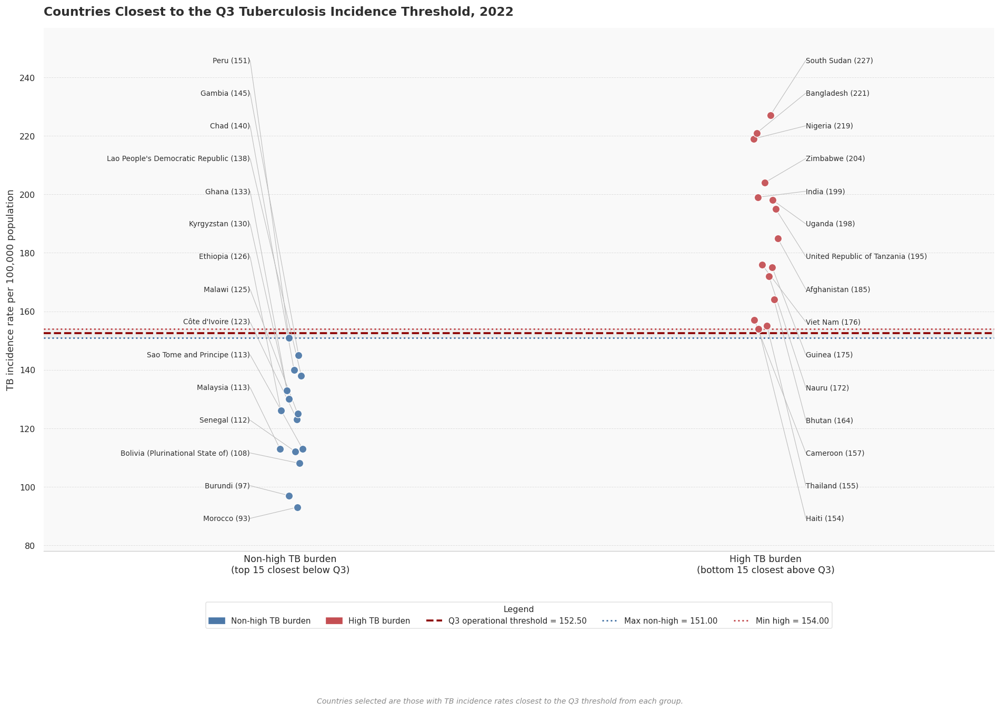

Threshold-focused figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/08_countries_closest_to_q3_threshold.png
Threshold-focused figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/08_countries_closest_to_q3_threshold.pdf
Threshold-focused table saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/04_countries_closest_to_q3_threshold.csv
Threshold-focused table saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/04_countries_closest_to_q3_threshold.xlsx
Threshold-focused visualization check passed.


In [44]:
# Visualization 3: Countries closest to the Q3 TB incidence threshold

import matplotlib.patches as mpatches

THRESHOLD_FOCUS_FIGURE_PATH = (
    FIGURES_DIR / "08_countries_closest_to_q3_threshold.png"
)

THRESHOLD_FOCUS_FIGURE_PDF_PATH = (
    FIGURES_DIR / "08_countries_closest_to_q3_threshold.pdf"
)

THRESHOLD_FOCUS_TABLE_CSV_PATH = (
    TABLES_DIR / "04_countries_closest_to_q3_threshold.csv"
)

THRESHOLD_FOCUS_TABLE_EXCEL_PATH = (
    TABLES_DIR / "04_countries_closest_to_q3_threshold.xlsx"
)

required_threshold_focus_columns = [
    "Area",
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group"
]

missing_threshold_focus_columns = [
    column for column in required_threshold_focus_columns
    if column not in tb_dataset.columns
]

if missing_threshold_focus_columns:
    raise KeyError(
        "Missing required columns for threshold-focused visualization: "
        f"{missing_threshold_focus_columns}"
    )

if "q3_threshold" not in globals():
    raise NameError(
        "'q3_threshold' is not defined. Run the target creation cell before this visualization."
    )

if not pd.api.types.is_numeric_dtype(tb_dataset["TB_incidence_2022"]):
    raise TypeError(
        "'TB_incidence_2022' must be numeric before creating this visualization."
    )

if tb_dataset["TB_incidence_2022"].isna().any():
    raise ValueError(
        "'TB_incidence_2022' contains missing values. Review the target-source column."
    )

if tb_dataset["high_tb_burden"].nunique() != 2:
    raise ValueError(
        "Both target classes must be present before creating the threshold-focused visualization."
    )

n_countries_per_group = 15

non_high_count = (tb_dataset["high_tb_burden"] == 0).sum()
high_count = (tb_dataset["high_tb_burden"] == 1).sum()

if non_high_count < n_countries_per_group or high_count < n_countries_per_group:
    raise ValueError(
        "Not enough countries in one of the classes for the selected "
        f"n_countries_per_group = {n_countries_per_group}."
    )

maximum_non_high_burden_incidence = tb_dataset.loc[
    tb_dataset["high_tb_burden"] == 0,
    "TB_incidence_2022"
].max()

minimum_high_burden_incidence = tb_dataset.loc[
    tb_dataset["high_tb_burden"] == 1,
    "TB_incidence_2022"
].min()

if maximum_non_high_burden_incidence >= q3_threshold:
    raise ValueError(
        "The maximum TB incidence in the non-high group is not below the Q3 threshold."
    )

if minimum_high_burden_incidence < q3_threshold:
    raise ValueError(
        "The minimum TB incidence in the high group is below the Q3 threshold."
    )

closest_non_high = (
    tb_dataset.loc[
        tb_dataset["high_tb_burden"] == 0,
        ["Area", "TB_incidence_2022", "high_tb_burden", "tb_burden_group"]
    ]
    .copy()
    .sort_values(
        by=["TB_incidence_2022", "Area"],
        ascending=[False, True]
    )
    .head(n_countries_per_group)
)

closest_high = (
    tb_dataset.loc[
        tb_dataset["high_tb_burden"] == 1,
        ["Area", "TB_incidence_2022", "high_tb_burden", "tb_burden_group"]
    ]
    .copy()
    .sort_values(
        by=["TB_incidence_2022", "Area"],
        ascending=[True, True]
    )
    .head(n_countries_per_group)
)

threshold_focus_data = pd.concat(
    [closest_non_high, closest_high],
    ignore_index=True
)

threshold_focus_data["distance_from_q3"] = (
    threshold_focus_data["TB_incidence_2022"] - q3_threshold
).round(2)

threshold_focus_data["absolute_distance_from_q3"] = (
    threshold_focus_data["distance_from_q3"]
    .abs()
    .round(2)
)

threshold_focus_data["display_label"] = (
    threshold_focus_data["tb_burden_group"]
    .map(CLASS_DISPLAY_LABELS)
)

if threshold_focus_data["display_label"].isna().any():
    missing_display_label_groups = (
        threshold_focus_data.loc[
            threshold_focus_data["display_label"].isna(),
            "tb_burden_group"
        ]
        .drop_duplicates()
        .tolist()
    )

    raise ValueError(
        "Missing display labels for the following target groups: "
        f"{missing_display_label_groups}"
    )

threshold_focus_data["group_order"] = (
    threshold_focus_data["tb_burden_group"]
    .map({
        "non_high_tb_burden": 0,
        "high_tb_burden": 1
    })
)

threshold_focus_data = threshold_focus_data.sort_values(
    by=["group_order", "TB_incidence_2022", "Area"],
    ascending=[True, True, True]
).reset_index(drop=True)

threshold_focus_display = threshold_focus_data.rename(columns={
    "Area": "country",
    "TB_incidence_2022": "tb_incidence_rate_per_100k",
    "high_tb_burden": "target_binary",
    "tb_burden_group": "target_group",
    "display_label": "target_label"
})

display(threshold_focus_display)

threshold_focus_display.to_csv(
    THRESHOLD_FOCUS_TABLE_CSV_PATH,
    index=False
)

threshold_focus_display.to_excel(
    THRESHOLD_FOCUS_TABLE_EXCEL_PATH,
    index=False
)

group_x_positions = {
    "non_high_tb_burden": 0.0,
    "high_tb_burden": 2.6
}

rng = np.random.default_rng(RANDOM_STATE)

threshold_focus_data["x_base"] = (
    threshold_focus_data["tb_burden_group"]
    .map(group_x_positions)
)

threshold_focus_data["x_jitter"] = rng.uniform(
    low=-0.07,
    high=0.07,
    size=len(threshold_focus_data)
)

threshold_focus_data["x_position"] = (
    threshold_focus_data["x_base"] + threshold_focus_data["x_jitter"]
)

y_min = max(
    0,
    threshold_focus_data["TB_incidence_2022"].min() - 15
)

y_max = threshold_focus_data["TB_incidence_2022"].max() + 30


def create_label_positions(group_df, x_anchor, side, y_min, y_max, n_slots):
    """
    Create evenly spaced label positions to avoid text overlap.
    Labels are placed in a sorted vertical column beside each scatter group.
    """
    sorted_group_df = (
        group_df
        .sort_values("TB_incidence_2022")
        .reset_index(drop=True)
    )

    slot_height = (y_max - y_min) / (n_slots + 1)

    if side == "left":
        x_offset = -0.22
        horizontal_alignment = "right"
    elif side == "right":
        x_offset = 0.22
        horizontal_alignment = "left"
    else:
        raise ValueError("side must be either 'left' or 'right'.")

    label_positions = []

    for index, (_, row) in enumerate(sorted_group_df.iterrows()):
        label_positions.append({
            "text": f"{row['Area']} ({row['TB_incidence_2022']:.0f})",
            "x_point": row["x_position"],
            "y_point": row["TB_incidence_2022"],
            "x_text": x_anchor + x_offset,
            "y_text": y_min + slot_height * (index + 1),
            "horizontal_alignment": horizontal_alignment
        })

    return label_positions


non_high_threshold_subset = threshold_focus_data[
    threshold_focus_data["tb_burden_group"] == "non_high_tb_burden"
]

high_threshold_subset = threshold_focus_data[
    threshold_focus_data["tb_burden_group"] == "high_tb_burden"
]

non_high_label_positions = create_label_positions(
    group_df=non_high_threshold_subset,
    x_anchor=group_x_positions["non_high_tb_burden"],
    side="left",
    y_min=y_min,
    y_max=y_max,
    n_slots=n_countries_per_group
)

high_label_positions = create_label_positions(
    group_df=high_threshold_subset,
    x_anchor=group_x_positions["high_tb_burden"],
    side="right",
    y_min=y_min,
    y_max=y_max,
    n_slots=n_countries_per_group
)

fig, ax = plt.subplots(figsize=(16, 11))

fig.patch.set_facecolor("white")
ax.set_facecolor("#F9F9F9")

ax.axhspan(
    maximum_non_high_burden_incidence,
    minimum_high_burden_incidence,
    color="#888888",
    alpha=0.09,
    zorder=1
)

ax.axhline(
    q3_threshold,
    color=Q3_THRESHOLD_COLOR,
    linestyle="--",
    linewidth=2.2,
    zorder=2,
    label=f"Q3 operational threshold = {q3_threshold:.2f}"
)

ax.axhline(
    maximum_non_high_burden_incidence,
    color=CLASS_COLORS["non_high_tb_burden"],
    linestyle=":",
    linewidth=1.8,
    zorder=2,
    label=f"Max non-high = {maximum_non_high_burden_incidence:.2f}"
)

ax.axhline(
    minimum_high_burden_incidence,
    color=CLASS_COLORS["high_tb_burden"],
    linestyle=":",
    linewidth=1.8,
    zorder=2,
    label=f"Min high = {minimum_high_burden_incidence:.2f}"
)

for group_name in CLASS_ORDER:
    group_subset = threshold_focus_data[
        threshold_focus_data["tb_burden_group"] == group_name
    ]

    ax.scatter(
        group_subset["x_position"],
        group_subset["TB_incidence_2022"],
        color=CLASS_COLORS[group_name],
        edgecolor="white",
        linewidth=0.9,
        s=75,
        alpha=0.93,
        zorder=4
    )

all_label_positions = (
    [(label_position, "non_high_tb_burden") for label_position in non_high_label_positions]
    + [(label_position, "high_tb_burden") for label_position in high_label_positions]
)

for label_position, group_name in all_label_positions:
    ax.annotate(
        "",
        xy=(label_position["x_point"], label_position["y_point"]),
        xytext=(label_position["x_text"], label_position["y_text"]),
        arrowprops={
            "arrowstyle": "-",
            "color": "#BBBBBB",
            "lw": 0.65,
            "shrinkA": 0,
            "shrinkB": 4
        },
        zorder=3
    )

    ax.text(
        label_position["x_text"],
        label_position["y_text"],
        label_position["text"],
        ha=label_position["horizontal_alignment"],
        va="center",
        fontsize=8.2,
        color=NEUTRAL_DARK_COLOR,
        zorder=5
    )

ax.set_xlim(-1.35, 3.85)
ax.set_ylim(y_min, y_max)

ax.set_xticks([
    group_x_positions["non_high_tb_burden"],
    group_x_positions["high_tb_burden"]
])

ax.set_xticklabels(
    [
        f"Non-high TB burden\n(top {n_countries_per_group} closest below Q3)",
        f"High TB burden\n(bottom {n_countries_per_group} closest above Q3)"
    ],
    fontsize=11
)

ax.set_title(
    "Countries Closest to the Q3 Tuberculosis Incidence Threshold, 2022",
    fontsize=14,
    fontweight="bold",
    pad=14,
    loc="left",
    color=NEUTRAL_DARK_COLOR
)

ax.set_xlabel("")

ax.set_ylabel(
    "TB incidence rate per 100,000 population",
    fontsize=11,
    color=NEUTRAL_DARK_COLOR
)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.55,
    alpha=GRID_COLOR_ALPHA,
    color="#AAAAAA",
    zorder=0
)

ax.grid(
    axis="x",
    visible=False
)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_linewidth(0.8)
ax.spines["bottom"].set_color("#CCCCCC")

ax.tick_params(
    axis="x",
    length=0,
    labelsize=10.5
)

ax.tick_params(
    axis="y",
    labelsize=9.5,
    color="#CCCCCC"
)

patch_non_high = mpatches.Patch(
    color=CLASS_COLORS["non_high_tb_burden"],
    label=CLASS_DISPLAY_LABELS["non_high_tb_burden"]
)

patch_high = mpatches.Patch(
    color=CLASS_COLORS["high_tb_burden"],
    label=CLASS_DISPLAY_LABELS["high_tb_burden"]
)

reference_handles, _ = ax.get_legend_handles_labels()

ax.legend(
    handles=[patch_non_high, patch_high] + reference_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.09),
    ncol=5,
    frameon=True,
    facecolor="white",
    edgecolor="#DDDDDD",
    fontsize=9,
    title="Legend",
    title_fontsize=9.5
)

fig.text(
    0.5,
    -0.02,
    "Countries selected are those with TB incidence rates closest to the Q3 threshold from each group.",
    ha="center",
    fontsize=8.5,
    color="#888888",
    style="italic"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

fig.savefig(
    THRESHOLD_FOCUS_FIGURE_PATH,
    dpi=FIGURE_DPI,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    THRESHOLD_FOCUS_FIGURE_PDF_PATH,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

expected_number_of_countries = n_countries_per_group * 2

if len(threshold_focus_data) != expected_number_of_countries:
    raise ValueError(
        f"Expected {expected_number_of_countries} countries in threshold-focused data, "
        f"got {len(threshold_focus_data)}."
    )

print("Threshold-focused figure saved as PNG:", THRESHOLD_FOCUS_FIGURE_PATH.exists())
print("PNG path:", THRESHOLD_FOCUS_FIGURE_PATH)
print("Threshold-focused figure saved as PDF:", THRESHOLD_FOCUS_FIGURE_PDF_PATH.exists())
print("PDF path:", THRESHOLD_FOCUS_FIGURE_PDF_PATH)
print("Threshold-focused table saved as CSV:", THRESHOLD_FOCUS_TABLE_CSV_PATH)
print("Threshold-focused table saved as Excel:", THRESHOLD_FOCUS_TABLE_EXCEL_PATH)
print("Threshold-focused visualization check passed.")

,rank_by_absolute_correlation,feature,point_biserial_correlation,absolute_correlation,correlation_direction,interpretation
0,1,Life Expectancy at Birth (years),-0.567039,0.567039,negative,Lower feature values are associated with high ...
1,2,HDI Rank,0.522248,0.522248,positive,Higher feature values are associated with high...
2,3,Human Development Index (value),-0.508129,0.508129,negative,Lower feature values are associated with high ...
3,4,Gross National Income Per Capita (2017 PPP$),-0.413749,0.413749,negative,Lower feature values are associated with high ...
4,5,Energy supply - Sweets and sugars,-0.411196,0.411196,negative,Lower feature values are associated with high ...
5,6,Zinc supply - Milk and milk products,-0.406659,0.406659,negative,Lower feature values are associated with high ...
6,7,Mean Years of Schooling (years),-0.403071,0.403071,negative,Lower feature values are associated with high ...
7,8,Protein supply - Milk and milk products,-0.402081,0.402081,negative,Lower feature values are associated with high ...
8,9,BCG_coverage_pct,-0.397142,0.397142,negative,Lower feature values are associated with high ...
9,10,Expected Years of Schooling (years),-0.395161,0.395161,negative,Lower feature values are associated with high ...


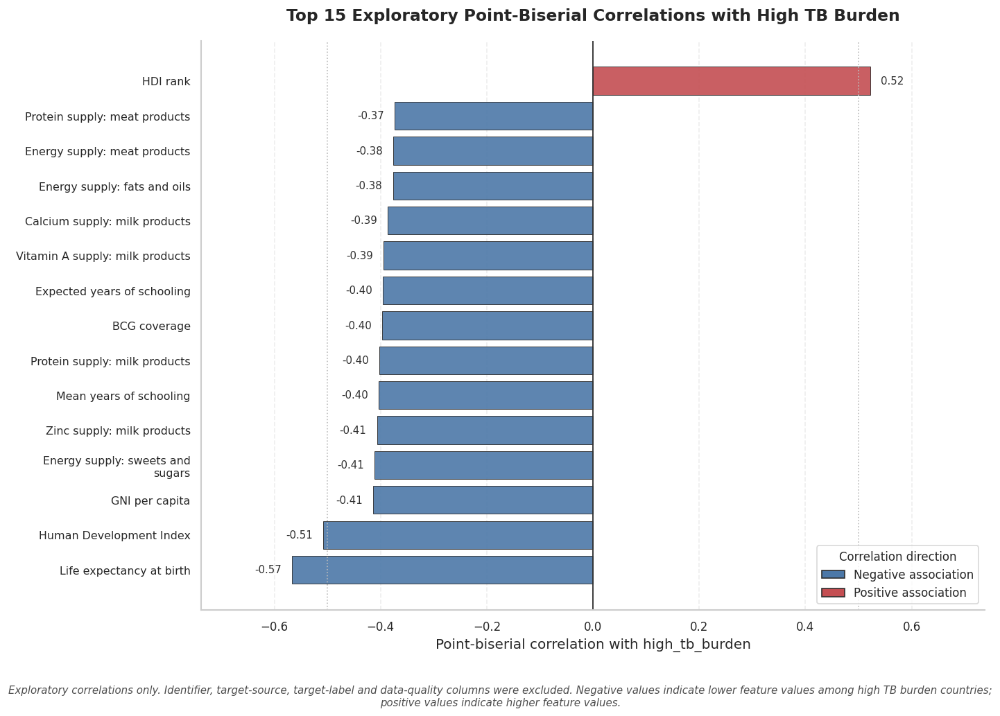

Number of predictor columns used for correlation analysis: 46
Feature-target correlation table saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/05_feature_target_correlation_ranking.csv
Feature-target correlation table saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/05_feature_target_correlation_ranking.xlsx
Feature-target correlation figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/09_feature_target_correlation_ranking.png
Feature-target correlation figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/09_feature_target_correlation_ranking.pdf
Feature-target correlation visualization check passed.


In [45]:
# Visualization 4: Exploratory feature-target correlation ranking

# This visualization ranks numeric candidate predictors by their point-biserial
# correlation with the binary high_tb_burden target.
# Since high_tb_burden is binary, Pearson correlation with this target is equivalent
# to point-biserial correlation.
# This is an exploratory EDA step, not a formal feature selection step.

import textwrap
from matplotlib.patches import Patch

FEATURE_TARGET_CORRELATION_FIGURE_PATH = (
    FIGURES_DIR / "09_feature_target_correlation_ranking.png"
)

FEATURE_TARGET_CORRELATION_FIGURE_PDF_PATH = (
    FIGURES_DIR / "09_feature_target_correlation_ranking.pdf"
)

FEATURE_TARGET_CORRELATION_TABLE_CSV_PATH = (
    TABLES_DIR / "05_feature_target_correlation_ranking.csv"
)

FEATURE_TARGET_CORRELATION_TABLE_EXCEL_PATH = (
    TABLES_DIR / "05_feature_target_correlation_ranking.xlsx"
)

target_column = "high_tb_burden"

if target_column not in tb_dataset.columns:
    raise KeyError(f"Required target column '{target_column}' was not found.")

if "candidate_predictor_cols" not in globals():
    raise NameError(
        "candidate_predictor_cols is not defined. Run the column role definition cell first."
    )

target_unique_values = sorted(tb_dataset[target_column].dropna().unique().tolist())

if target_unique_values != [0, 1]:
    raise ValueError(
        f"The target column '{target_column}' must be binary with values [0, 1]. "
        f"Observed values: {target_unique_values}"
    )

non_predictor_columns_for_correlation = [
    "Area",
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group",
    "BCG_was_missing"
]

correlation_predictor_columns = [
    column for column in candidate_predictor_cols
    if column in tb_dataset.columns
    and column not in non_predictor_columns_for_correlation
]

if len(correlation_predictor_columns) == 0:
    raise ValueError(
        "No valid predictor columns were found for feature-target correlation analysis."
    )

leakage_columns_in_correlation = sorted(
    set(correlation_predictor_columns)
    .intersection(non_predictor_columns_for_correlation)
)

if leakage_columns_in_correlation:
    raise ValueError(
        f"Leakage columns found in correlation predictors: {leakage_columns_in_correlation}"
    )

non_numeric_correlation_predictors = [
    column for column in correlation_predictor_columns
    if not pd.api.types.is_numeric_dtype(tb_dataset[column])
]

if non_numeric_correlation_predictors:
    raise ValueError(
        "Non-numeric predictors found in correlation analysis: "
        f"{non_numeric_correlation_predictors}"
    )

missing_values_in_correlation_predictors = (
    tb_dataset[correlation_predictor_columns]
    .isna()
    .sum()
)

missing_values_in_correlation_predictors = (
    missing_values_in_correlation_predictors[
        missing_values_in_correlation_predictors > 0
    ]
)

if not missing_values_in_correlation_predictors.empty:
    raise ValueError(
        "Missing values found in correlation predictor columns. "
        "Review or impute missing values before correlation analysis.\n"
        f"{missing_values_in_correlation_predictors}"
    )

infinite_values_in_correlation_predictors = (
    np.isinf(tb_dataset[correlation_predictor_columns])
    .sum()
)

infinite_values_in_correlation_predictors = (
    infinite_values_in_correlation_predictors[
        infinite_values_in_correlation_predictors > 0
    ]
)

if not infinite_values_in_correlation_predictors.empty:
    raise ValueError(
        "Infinite values found in correlation predictor columns. "
        "Review the data before correlation analysis.\n"
        f"{infinite_values_in_correlation_predictors}"
    )

constant_correlation_predictors = [
    column for column in correlation_predictor_columns
    if tb_dataset[column].nunique(dropna=True) <= 1
]

if constant_correlation_predictors:
    raise ValueError(
        "Constant predictor columns cannot be used in correlation analysis: "
        f"{constant_correlation_predictors}"
    )

target_correlations = (
    tb_dataset[correlation_predictor_columns]
    .corrwith(
        tb_dataset[target_column],
        method="pearson"
    )
)

feature_target_correlation = (
    target_correlations
    .rename("point_biserial_correlation")
    .reset_index()
    .rename(columns={"index": "feature"})
    .dropna()
)

feature_target_correlation["absolute_correlation"] = (
    feature_target_correlation["point_biserial_correlation"]
    .abs()
)

feature_target_correlation["correlation_direction"] = np.where(
    feature_target_correlation["point_biserial_correlation"] >= 0,
    "positive",
    "negative"
)

feature_target_correlation["interpretation"] = np.where(
    feature_target_correlation["point_biserial_correlation"] >= 0,
    "Higher feature values are associated with high TB burden",
    "Lower feature values are associated with high TB burden"
)

feature_target_correlation = (
    feature_target_correlation
    .sort_values(
        by="absolute_correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

feature_target_correlation.insert(
    0,
    "rank_by_absolute_correlation",
    range(1, len(feature_target_correlation) + 1)
)

display(feature_target_correlation.head(15))

feature_target_correlation.to_csv(
    FEATURE_TARGET_CORRELATION_TABLE_CSV_PATH,
    index=False
)

feature_target_correlation.to_excel(
    FEATURE_TARGET_CORRELATION_TABLE_EXCEL_PATH,
    index=False
)

TOP_N_FEATURES = 15

plot_data = (
    feature_target_correlation
    .head(TOP_N_FEATURES)
    .copy()
    .sort_values(
        by="point_biserial_correlation",
        ascending=True
    )
    .reset_index(drop=True)
)

feature_display_name_map = {
    "HDI Rank": "HDI rank",
    "Human Development Index (value)": "Human Development Index",
    "Life Expectancy at Birth (years)": "Life expectancy at birth",
    "Expected Years of Schooling (years)": "Expected years of schooling",
    "Mean Years of Schooling (years)": "Mean years of schooling",
    "Gross National Income Per Capita (2017 PPP$)": "GNI per capita",
    "BCG_coverage_pct": "BCG coverage",
    "Protein supply - Meat and meat products": "Protein supply: meat products",
    "Energy supply - Meat and meat products": "Energy supply: meat products",
    "Energy supply - Fats and oils": "Energy supply: fats and oils",
    "Calcium supply - Milk and milk products": "Calcium supply: milk products",
    "Vitamin A supply (retinol activity equivalents) - Milk and milk products": "Vitamin A supply: milk products",
    "Protein supply - Milk and milk products": "Protein supply: milk products",
    "Zinc supply - Milk and milk products": "Zinc supply: milk products",
    "Energy supply - Sweets and sugars": "Energy supply: sweets and sugars"
}

def format_feature_label(feature_name, wrap_width=31):
    """
    Create shorter, thesis-ready labels for predictor names.
    If a feature is not in the manual mapping, use a cleaned version of its original name.
    """
    cleaned_label = feature_display_name_map.get(feature_name, feature_name)

    cleaned_label = (
        cleaned_label
        .replace("_", " ")
        .replace("pct", "(%)")
        .replace("Per Capita", "per capita")
    )

    return "\n".join(
        textwrap.wrap(
            cleaned_label,
            width=wrap_width,
            break_long_words=False
        )
    )

plot_data["feature_label"] = plot_data["feature"].apply(format_feature_label)

NEGATIVE_ASSOCIATION_COLOR = CLASS_COLORS["non_high_tb_burden"]
POSITIVE_ASSOCIATION_COLOR = CLASS_COLORS["high_tb_burden"]

bar_colors = np.where(
    plot_data["point_biserial_correlation"] >= 0,
    POSITIVE_ASSOCIATION_COLOR,
    NEGATIVE_ASSOCIATION_COLOR
)

fig, ax = plt.subplots(figsize=(12, 9))

bars = ax.barh(
    plot_data["feature_label"],
    plot_data["point_biserial_correlation"],
    color=bar_colors,
    edgecolor=NEUTRAL_DARK_COLOR,
    linewidth=0.6,
    alpha=0.90
)

ax.axvline(
    0,
    color=NEUTRAL_DARK_COLOR,
    linewidth=1.1
)

ax.axvline(
    -0.5,
    color="#BBBBBB",
    linestyle=":",
    linewidth=1.0
)

ax.axvline(
    0.5,
    color="#BBBBBB",
    linestyle=":",
    linewidth=1.0
)

max_absolute_correlation = plot_data["point_biserial_correlation"].abs().max()

ax.set_xlim(
    -max_absolute_correlation * 1.30,
    max_absolute_correlation * 1.30
)

for bar, correlation_value in zip(
    bars,
    plot_data["point_biserial_correlation"]
):
    if correlation_value >= 0:
        label_x_position = correlation_value + max_absolute_correlation * 0.035
        horizontal_alignment = "left"
    else:
        label_x_position = correlation_value - max_absolute_correlation * 0.035
        horizontal_alignment = "right"

    ax.text(
        label_x_position,
        bar.get_y() + bar.get_height() / 2,
        f"{correlation_value:.2f}",
        va="center",
        ha=horizontal_alignment,
        fontsize=9,
        color=NEUTRAL_DARK_COLOR
    )

ax.set_title(
    "Top 15 Exploratory Point-Biserial Correlations with High TB Burden",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Point-biserial correlation with high_tb_burden",
    fontsize=12
)

ax.set_ylabel("")

legend_handles = [
    Patch(
        facecolor=NEGATIVE_ASSOCIATION_COLOR,
        edgecolor=NEUTRAL_DARK_COLOR,
        label="Negative association"
    ),
    Patch(
        facecolor=POSITIVE_ASSOCIATION_COLOR,
        edgecolor=NEUTRAL_DARK_COLOR,
        label="Positive association"
    )
]

ax.legend(
    handles=legend_handles,
    title="Correlation direction",
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=GRID_COLOR_ALPHA
)

ax.grid(
    axis="y",
    visible=False
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=9.5)

fig.text(
    0.5,
    0.025,
    (
        "Exploratory correlations only. Identifier, target-source, target-label and "
        "data-quality columns were excluded. Negative values indicate lower feature values "
        "among high TB burden countries; positive values indicate higher feature values."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
    color="#4D4D4D",
    style="italic",
    wrap=True
)

plt.tight_layout(rect=[0, 0.08, 1, 0.98])

fig.savefig(
    FEATURE_TARGET_CORRELATION_FIGURE_PATH,
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

fig.savefig(
    FEATURE_TARGET_CORRELATION_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("Number of predictor columns used for correlation analysis:", len(correlation_predictor_columns))
print("Feature-target correlation table saved as CSV:", FEATURE_TARGET_CORRELATION_TABLE_CSV_PATH)
print("Feature-target correlation table saved as Excel:", FEATURE_TARGET_CORRELATION_TABLE_EXCEL_PATH)
print("Feature-target correlation figure saved as PNG:", FEATURE_TARGET_CORRELATION_FIGURE_PATH.exists())
print("PNG path:", FEATURE_TARGET_CORRELATION_FIGURE_PATH)
print("Feature-target correlation figure saved as PDF:", FEATURE_TARGET_CORRELATION_FIGURE_PDF_PATH.exists())
print("PDF path:", FEATURE_TARGET_CORRELATION_FIGURE_PDF_PATH)
print("Feature-target correlation visualization check passed.")

,Life Expectancy at Birth (years),HDI Rank,Human Development Index (value),Gross National Income Per Capita (2017 PPP$),Energy supply - Sweets and sugars,Zinc supply - Milk and milk products,Mean Years of Schooling (years),Protein supply - Milk and milk products,BCG_coverage_pct,Expected Years of Schooling (years),Vitamin A supply (retinol activity equivalents) - Milk and milk products,Calcium supply - Milk and milk products,Energy supply - Fats and oils,Energy supply - Meat and meat products,Protein supply - Meat and meat products
Life Expectancy at Birth (years),1.000,-0.898,0.902,0.758,0.607,0.636,0.724,0.631,0.548,0.771,0.578,0.604,0.646,0.572,0.568
HDI Rank,-0.898,1.000,-0.989,-0.865,-0.688,-0.744,-0.893,-0.734,-0.564,-0.891,-0.678,-0.706,-0.733,-0.707,-0.701
Human Development Index (value),0.902,-0.989,1.000,0.826,0.691,0.707,0.910,0.698,0.573,0.896,0.648,0.673,0.713,0.705,0.703
Gross National Income Per Capita (2017 PPP$),0.758,-0.865,0.826,1.000,0.568,0.690,0.692,0.677,0.475,0.704,0.595,0.645,0.686,0.575,0.575
Energy supply - Sweets and sugars,0.607,-0.688,0.691,0.568,1.000,0.553,0.644,0.546,0.417,0.575,0.512,0.530,0.532,0.582,0.590
Zinc supply - Milk and milk products,0.636,-0.744,0.707,0.690,0.553,1.000,0.665,0.996,0.407,0.623,0.953,0.991,0.621,0.518,0.480
Mean Years of Schooling (years),0.724,-0.893,0.910,0.692,0.644,0.665,1.000,0.656,0.498,0.785,0.627,0.636,0.618,0.708,0.698
Protein supply - Milk and milk products,0.631,-0.734,0.698,0.677,0.546,0.996,0.656,1.000,0.412,0.614,0.964,0.993,0.617,0.514,0.478
BCG_coverage_pct,0.548,-0.564,0.573,0.475,0.417,0.407,0.498,0.412,1.000,0.492,0.388,0.405,0.363,0.380,0.372
Expected Years of Schooling (years),0.771,-0.891,0.896,0.704,0.575,0.623,0.785,0.614,0.492,1.000,0.571,0.587,0.644,0.661,0.656


,feature_1,feature_2,pearson_correlation,absolute_correlation
0,Zinc supply - Milk and milk products,Protein supply - Milk and milk products,0.996,0.996
1,Protein supply - Milk and milk products,Calcium supply - Milk and milk products,0.993,0.993
2,Zinc supply - Milk and milk products,Calcium supply - Milk and milk products,0.991,0.991
3,HDI Rank,Human Development Index (value),-0.989,0.989
4,Energy supply - Meat and meat products,Protein supply - Meat and meat products,0.986,0.986
5,Vitamin A supply (retinol activity equivalents...,Calcium supply - Milk and milk products,0.970,0.970
6,Protein supply - Milk and milk products,Vitamin A supply (retinol activity equivalents...,0.964,0.964
7,Zinc supply - Milk and milk products,Vitamin A supply (retinol activity equivalents...,0.953,0.953
8,Human Development Index (value),Mean Years of Schooling (years),0.910,0.910
9,Life Expectancy at Birth (years),Human Development Index (value),0.902,0.902


/usr/local/lib/python3.12/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


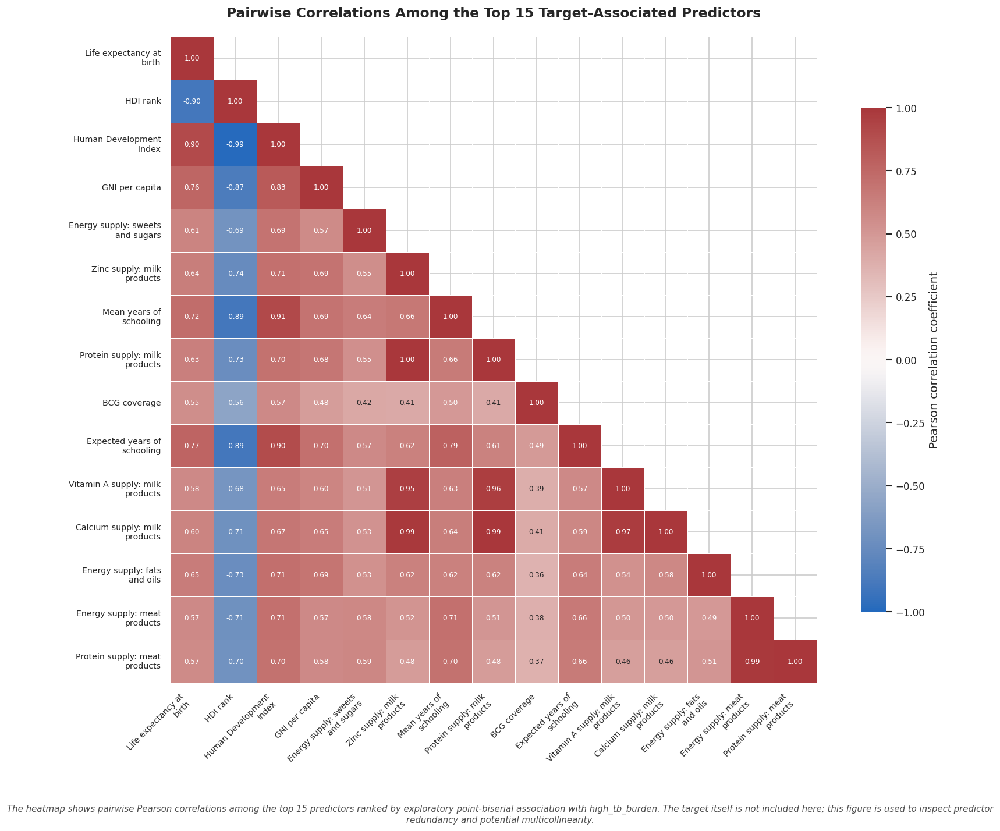

Number of predictors included in heatmap: 15
Target column included in heatmap: False
Top 15 predictors correlation matrix saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/06_top_15_predictors_correlation_matrix.csv
Top 15 predictors correlation matrix saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/06_top_15_predictors_correlation_matrix.xlsx
Highly correlated predictor pairs saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/06_top_15_predictors_high_correlation_pairs.csv
Highly correlated predictor pairs saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/06_top_15_predictors_high_correlation_pairs.xlsx
Top 15 predictors heatmap saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/10_top_15_predictors_correlation_heatmap.png
Top 15 predictors heatmap saved as PDF: True
PDF path: /content/drive/MyDri

In [46]:
# Visualization 5: Correlation heatmap of the top 15 target-associated predictors

# This heatmap shows pairwise Pearson correlations among the top 15 predictors
# most strongly associated with the binary high_tb_burden target in the previous
# exploratory point-biserial correlation ranking.
#
# The target itself is not included in this heatmap, because the previous visualization
# already shows feature-target associations. Here, the goal is to inspect redundancy
# and multicollinearity among the top target-associated predictors.

import textwrap

TOP_FEATURES_HEATMAP_FIGURE_PATH = (
    FIGURES_DIR / "10_top_15_predictors_correlation_heatmap.png"
)

TOP_FEATURES_HEATMAP_FIGURE_PDF_PATH = (
    FIGURES_DIR / "10_top_15_predictors_correlation_heatmap.pdf"
)

TOP_FEATURES_HEATMAP_TABLE_CSV_PATH = (
    TABLES_DIR / "06_top_15_predictors_correlation_matrix.csv"
)

TOP_FEATURES_HEATMAP_TABLE_EXCEL_PATH = (
    TABLES_DIR / "06_top_15_predictors_correlation_matrix.xlsx"
)

HIGH_CORRELATION_PAIRS_CSV_PATH = (
    TABLES_DIR / "06_top_15_predictors_high_correlation_pairs.csv"
)

HIGH_CORRELATION_PAIRS_EXCEL_PATH = (
    TABLES_DIR / "06_top_15_predictors_high_correlation_pairs.xlsx"
)

target_column = "high_tb_burden"

if target_column not in tb_dataset.columns:
    raise KeyError(f"Required target column '{target_column}' was not found.")

if "feature_target_correlation" not in globals():
    raise NameError(
        "feature_target_correlation is not defined. "
        "Run the feature-target correlation ranking visualization first."
    )

target_unique_values = sorted(
    tb_dataset[target_column]
    .dropna()
    .unique()
    .tolist()
)

if target_unique_values != [0, 1]:
    raise ValueError(
        f"The target column '{target_column}' must be binary with values [0, 1]. "
        f"Observed values: {target_unique_values}"
    )

top_n_heatmap_features = 15

if len(feature_target_correlation) < top_n_heatmap_features:
    raise ValueError(
        f"feature_target_correlation contains fewer than {top_n_heatmap_features} features."
    )

top_heatmap_features = (
    feature_target_correlation
    .head(top_n_heatmap_features)["feature"]
    .tolist()
)

excluded_columns_for_heatmap_features = [
    "Area",
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group",
    "BCG_was_missing"
]

leakage_features_in_heatmap = sorted(
    set(top_heatmap_features)
    .intersection(excluded_columns_for_heatmap_features)
)

if leakage_features_in_heatmap:
    raise ValueError(
        f"Leakage columns found in heatmap features: {leakage_features_in_heatmap}"
    )

missing_heatmap_features = [
    column for column in top_heatmap_features
    if column not in tb_dataset.columns
]

if missing_heatmap_features:
    raise KeyError(
        f"Top heatmap features missing from dataset: {missing_heatmap_features}"
    )

non_numeric_heatmap_features = [
    column for column in top_heatmap_features
    if not pd.api.types.is_numeric_dtype(tb_dataset[column])
]

if non_numeric_heatmap_features:
    raise ValueError(
        f"Non-numeric features found in heatmap: {non_numeric_heatmap_features}"
    )

missing_values_in_heatmap_features = (
    tb_dataset[top_heatmap_features]
    .isna()
    .sum()
)

missing_values_in_heatmap_features = (
    missing_values_in_heatmap_features[
        missing_values_in_heatmap_features > 0
    ]
)

if not missing_values_in_heatmap_features.empty:
    raise ValueError(
        "Missing values found in heatmap features. Review the data before plotting.\n"
        f"{missing_values_in_heatmap_features}"
    )

infinite_values_in_heatmap_features = (
    np.isinf(tb_dataset[top_heatmap_features])
    .sum()
)

infinite_values_in_heatmap_features = (
    infinite_values_in_heatmap_features[
        infinite_values_in_heatmap_features > 0
    ]
)

if not infinite_values_in_heatmap_features.empty:
    raise ValueError(
        "Infinite values found in heatmap features. Review the data before plotting.\n"
        f"{infinite_values_in_heatmap_features}"
    )

constant_heatmap_features = [
    column for column in top_heatmap_features
    if tb_dataset[column].nunique(dropna=True) <= 1
]

if constant_heatmap_features:
    raise ValueError(
        "Constant feature columns cannot be used in the correlation heatmap: "
        f"{constant_heatmap_features}"
    )

correlation_matrix = (
    tb_dataset[top_heatmap_features]
    .corr(method="pearson")
)

correlation_matrix.to_csv(
    TOP_FEATURES_HEATMAP_TABLE_CSV_PATH,
    index=True
)

correlation_matrix.to_excel(
    TOP_FEATURES_HEATMAP_TABLE_EXCEL_PATH,
    index=True
)

display(correlation_matrix.round(3))

# Identify highly correlated predictor pairs for multicollinearity inspection
HIGH_CORRELATION_THRESHOLD = 0.85

upper_triangle_mask = np.triu(
    np.ones(correlation_matrix.shape, dtype=bool),
    k=1
)

high_correlation_pairs = (
    correlation_matrix
    .where(upper_triangle_mask)
    .stack()
    .reset_index()
)

high_correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "pearson_correlation"
]

high_correlation_pairs["absolute_correlation"] = (
    high_correlation_pairs["pearson_correlation"]
    .abs()
)

high_correlation_pairs = (
    high_correlation_pairs[
        high_correlation_pairs["absolute_correlation"] >= HIGH_CORRELATION_THRESHOLD
    ]
    .sort_values(
        by="absolute_correlation",
        ascending=False
    )
    .reset_index(drop=True)
)

high_correlation_pairs[
    ["pearson_correlation", "absolute_correlation"]
] = high_correlation_pairs[
    ["pearson_correlation", "absolute_correlation"]
].round(3)

display(high_correlation_pairs)

high_correlation_pairs.to_csv(
    HIGH_CORRELATION_PAIRS_CSV_PATH,
    index=False
)

high_correlation_pairs.to_excel(
    HIGH_CORRELATION_PAIRS_EXCEL_PATH,
    index=False
)

feature_display_name_map = {
    "HDI Rank": "HDI rank",
    "Human Development Index (value)": "Human Development Index",
    "Life Expectancy at Birth (years)": "Life expectancy at birth",
    "Expected Years of Schooling (years)": "Expected years of schooling",
    "Mean Years of Schooling (years)": "Mean years of schooling",
    "Gross National Income Per Capita (2017 PPP$)": "GNI per capita",
    "BCG_coverage_pct": "BCG coverage",
    "Protein supply - Meat and meat products": "Protein supply: meat products",
    "Energy supply - Meat and meat products": "Energy supply: meat products",
    "Energy supply - Fats and oils": "Energy supply: fats and oils",
    "Calcium supply - Milk and milk products": "Calcium supply: milk products",
    "Vitamin A supply (retinol activity equivalents) - Milk and milk products": "Vitamin A supply: milk products",
    "Protein supply - Milk and milk products": "Protein supply: milk products",
    "Zinc supply - Milk and milk products": "Zinc supply: milk products",
    "Energy supply - Sweets and sugars": "Energy supply: sweets and sugars"
}

def format_heatmap_label(feature_name, wrap_width=22):
    """
    Create shorter, readable labels for heatmap axes.
    """
    cleaned_label = feature_display_name_map.get(feature_name, feature_name)

    cleaned_label = (
        cleaned_label
        .replace("_", " ")
        .replace("pct", "(%)")
        .replace("Per Capita", "per capita")
    )

    return "\n".join(
        textwrap.wrap(
            cleaned_label,
            width=wrap_width,
            break_long_words=False
        )
    )

wrapped_labels = [
    format_heatmap_label(column)
    for column in correlation_matrix.columns
]

mask = np.triu(
    np.ones_like(correlation_matrix, dtype=bool),
    k=1
)

fig, ax = plt.subplots(figsize=(14.5, 12))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    cmap="vlag",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={
        "size": 7.2
    },
    square=True,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={
        "label": "Pearson correlation coefficient",
        "shrink": 0.78,
        "ticks": [-1, -0.75, -0.50, -0.25, 0, 0.25, 0.50, 0.75, 1]
    },
    ax=ax
)

ax.set_title(
    "Pairwise Correlations Among the Top 15 Target-Associated Predictors",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.set_xticklabels(
    wrapped_labels,
    rotation=45,
    ha="right",
    fontsize=8.5
)

ax.set_yticklabels(
    wrapped_labels,
    rotation=0,
    fontsize=8.5
)

ax.set_xlabel("")
ax.set_ylabel("")

fig.text(
    0.5,
    0.02,
    (
        "The heatmap shows pairwise Pearson correlations among the top 15 predictors "
        "ranked by exploratory point-biserial association with high_tb_burden. "
        "The target itself is not included here; this figure is used to inspect "
        "predictor redundancy and potential multicollinearity."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
    color="#4D4D4D",
    style="italic",
    wrap=True
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

fig.savefig(
    TOP_FEATURES_HEATMAP_FIGURE_PATH,
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

fig.savefig(
    TOP_FEATURES_HEATMAP_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

if len(top_heatmap_features) != top_n_heatmap_features:
    raise ValueError(
        f"Expected {top_n_heatmap_features} heatmap features, "
        f"got {len(top_heatmap_features)}."
    )

print("Number of predictors included in heatmap:", len(top_heatmap_features))
print("Target column included in heatmap: False")
print("Top 15 predictors correlation matrix saved as CSV:", TOP_FEATURES_HEATMAP_TABLE_CSV_PATH)
print("Top 15 predictors correlation matrix saved as Excel:", TOP_FEATURES_HEATMAP_TABLE_EXCEL_PATH)
print("Highly correlated predictor pairs saved as CSV:", HIGH_CORRELATION_PAIRS_CSV_PATH)
print("Highly correlated predictor pairs saved as Excel:", HIGH_CORRELATION_PAIRS_EXCEL_PATH)
print("Top 15 predictors heatmap saved as PNG:", TOP_FEATURES_HEATMAP_FIGURE_PATH.exists())
print("PNG path:", TOP_FEATURES_HEATMAP_FIGURE_PATH)
print("Top 15 predictors heatmap saved as PDF:", TOP_FEATURES_HEATMAP_FIGURE_PDF_PATH.exists())
print("PDF path:", TOP_FEATURES_HEATMAP_FIGURE_PDF_PATH)
print("Top 15 predictors correlation heatmap check passed.")

,feature,feature_display_name,tb_burden_group,display_label,display_label_with_n,number_of_countries,minimum,q1,median,mean,q3,maximum
0,Energy supply - Sweets and sugars,Energy supply: sweets and sugars,high_tb_burden,High TB burden,High TB burden\n(n=46),46,28.000,109.500,177.000,223.696,311.000,664.000
1,Energy supply - Sweets and sugars,Energy supply: sweets and sugars,non_high_tb_burden,Non-high TB burden,Non-high TB burden\n(n=137),137,54.000,289.000,388.000,371.321,452.000,676.000
2,Gross National Income Per Capita (2017 PPP$),GNI per capita,high_tb_burden,High TB burden,High TB burden\n(n=46),46,690.661,2119.335,4031.630,5434.438,8031.523,16886.511
3,Gross National Income Per Capita (2017 PPP$),GNI per capita,non_high_tb_burden,Non-high TB burden,Non-high TB burden\n(n=137),137,712.026,7987.842,16571.413,24132.030,35782.910,95944.378
4,HDI Rank,HDI rank,high_tb_burden,High TB burden,High TB burden\n(n=46),46,66.000,129.750,150.500,148.435,170.250,193.000
5,HDI Rank,HDI rank,non_high_tb_burden,Non-high TB burden,Non-high TB burden\n(n=137),137,1.000,39.000,77.000,81.876,119.000,189.000
6,Human Development Index (value),Human Development Index,high_tb_burden,High TB burden,High TB burden\n(n=46),46,0.380,0.516,0.589,0.584,0.666,0.803
7,Human Development Index (value),Human Development Index,non_high_tb_burden,Non-high TB burden,Non-high TB burden\n(n=137),137,0.394,0.699,0.781,0.765,0.878,0.967
8,Life Expectancy at Birth (years),Life expectancy at birth,high_tb_burden,High TB burden,High TB burden\n(n=46),46,53.036,59.998,63.683,64.047,67.560,79.680
9,Life Expectancy at Birth (years),Life expectancy at birth,non_high_tb_burden,Non-high TB burden,Non-high TB burden\n(n=137),137,52.997,70.492,74.263,74.147,79.196,84.820


/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: PendingDeprecationWarning: vert: bool will be deprecated in a future version. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:700: 

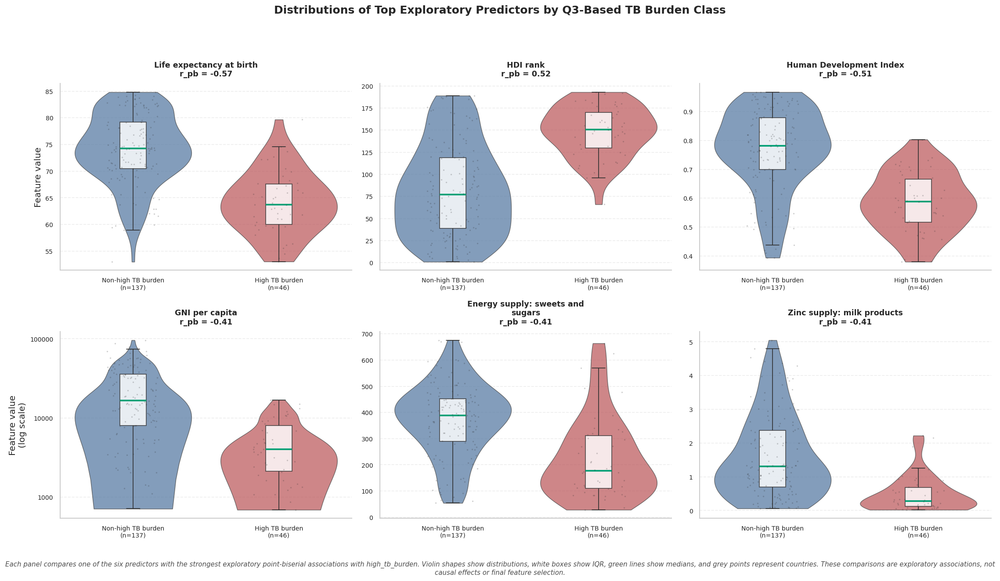

Number of predictors included in distribution plots: 6
Predictors included: ['Life Expectancy at Birth (years)', 'HDI Rank', 'Human Development Index (value)', 'Gross National Income Per Capita (2017 PPP$)', 'Energy supply - Sweets and sugars', 'Zinc supply - Milk and milk products']
Correlation column used: point_biserial_correlation
Top predictor distribution summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/07_top_predictor_distributions_by_class_summary.csv
Top predictor distribution summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/07_top_predictor_distributions_by_class_summary.xlsx
Top predictor distribution figure saved as PNG: True
PNG path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/11_top_predictor_distributions_by_class.png
Top predictor distribution figure saved as PDF: True
PDF path: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/11_top

In [47]:
import textwrap
from matplotlib.ticker import ScalarFormatter

TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PATH = (
    FIGURES_DIR / "11_top_predictor_distributions_by_class.png"
)

TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PDF_PATH = (
    FIGURES_DIR / "11_top_predictor_distributions_by_class.pdf"
)

TOP_PREDICTOR_DISTRIBUTIONS_TABLE_CSV_PATH = (
    TABLES_DIR / "07_top_predictor_distributions_by_class_summary.csv"
)

TOP_PREDICTOR_DISTRIBUTIONS_TABLE_EXCEL_PATH = (
    TABLES_DIR / "07_top_predictor_distributions_by_class_summary.xlsx"
)

if "feature_target_correlation" not in globals():
    raise NameError(
        "feature_target_correlation is not defined. "
        "Run the feature-target correlation ranking visualization first."
    )

target_group_column = "tb_burden_group"

if target_group_column not in tb_dataset.columns:
    raise KeyError(f"Required column '{target_group_column}' was not found.")

if "feature" not in feature_target_correlation.columns:
    raise KeyError(
        "The feature_target_correlation table must contain a 'feature' column."
    )

if "point_biserial_correlation" in feature_target_correlation.columns:
    correlation_value_column = "point_biserial_correlation"
elif "pearson_correlation" in feature_target_correlation.columns:
    correlation_value_column = "pearson_correlation"
else:
    raise KeyError(
        "The feature_target_correlation table must contain either "
        "'point_biserial_correlation' or 'pearson_correlation'."
    )

top_n_distribution_features = 6

if len(feature_target_correlation) < top_n_distribution_features:
    raise ValueError(
        f"feature_target_correlation contains fewer than "
        f"{top_n_distribution_features} features."
    )

top_distribution_features = (
    feature_target_correlation
    .head(top_n_distribution_features)["feature"]
    .tolist()
)

leakage_columns_for_distribution_plot = [
    "Area",
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group",
    "BCG_was_missing"
]

leakage_features_in_distribution_plot = sorted(
    set(top_distribution_features)
    .intersection(leakage_columns_for_distribution_plot)
)

if leakage_features_in_distribution_plot:
    raise ValueError(
        "Leakage columns found in distribution plot features: "
        f"{leakage_features_in_distribution_plot}"
    )

missing_distribution_features = [
    column for column in top_distribution_features
    if column not in tb_dataset.columns
]

if missing_distribution_features:
    raise KeyError(
        f"Selected distribution features missing from dataset: "
        f"{missing_distribution_features}"
    )

non_numeric_distribution_features = [
    column for column in top_distribution_features
    if not pd.api.types.is_numeric_dtype(tb_dataset[column])
]

if non_numeric_distribution_features:
    raise ValueError(
        f"Non-numeric features found in distribution plot: "
        f"{non_numeric_distribution_features}"
    )

missing_values_in_distribution_features = (
    tb_dataset[top_distribution_features]
    .isna()
    .sum()
)

missing_values_in_distribution_features = (
    missing_values_in_distribution_features[
        missing_values_in_distribution_features > 0
    ]
)

if not missing_values_in_distribution_features.empty:
    raise ValueError(
        "Missing values found in selected distribution features. "
        "Review the data before plotting.\n"
        f"{missing_values_in_distribution_features}"
    )

infinite_values_in_distribution_features = (
    np.isinf(tb_dataset[top_distribution_features])
    .sum()
)

infinite_values_in_distribution_features = (
    infinite_values_in_distribution_features[
        infinite_values_in_distribution_features > 0
    ]
)

if not infinite_values_in_distribution_features.empty:
    raise ValueError(
        "Infinite values found in selected distribution features. "
        "Review the data before plotting.\n"
        f"{infinite_values_in_distribution_features}"
    )

constant_distribution_features = [
    column for column in top_distribution_features
    if tb_dataset[column].nunique(dropna=True) <= 1
]

if constant_distribution_features:
    raise ValueError(
        "Constant feature columns cannot be used in distribution plots: "
        f"{constant_distribution_features}"
    )

feature_display_name_map = {
    "HDI Rank": "HDI rank",
    "Human Development Index (value)": "Human Development Index",
    "Life Expectancy at Birth (years)": "Life expectancy at birth",
    "Expected Years of Schooling (years)": "Expected years of schooling",
    "Mean Years of Schooling (years)": "Mean years of schooling",
    "Gross National Income Per Capita (2017 PPP$)": "GNI per capita",
    "BCG_coverage_pct": "BCG coverage",
    "Protein supply - Meat and meat products": "Protein supply: meat products",
    "Energy supply - Meat and meat products": "Energy supply: meat products",
    "Energy supply - Fats and oils": "Energy supply: fats and oils",
    "Calcium supply - Milk and milk products": "Calcium supply: milk products",
    "Vitamin A supply (retinol activity equivalents) - Milk and milk products": "Vitamin A supply: milk products",
    "Protein supply - Milk and milk products": "Protein supply: milk products",
    "Zinc supply - Milk and milk products": "Zinc supply: milk products",
    "Energy supply - Sweets and sugars": "Energy supply: sweets and sugars"
}

def get_clean_feature_name(feature_name):
    """
    Return a shorter, thesis-ready feature name.
    """
    cleaned_name = feature_display_name_map.get(feature_name, feature_name)

    cleaned_name = (
        cleaned_name
        .replace("_", " ")
        .replace("pct", "(%)")
        .replace("Per Capita", "per capita")
    )

    return cleaned_name


def wrap_feature_name(feature_name, wrap_width=28):
    """
    Wrap long feature names for subplot titles.
    """
    return "\n".join(
        textwrap.wrap(
            get_clean_feature_name(feature_name),
            width=wrap_width,
            break_long_words=False
        )
    )


distribution_plot_data = (
    tb_dataset[
        [target_group_column] + top_distribution_features
    ]
    .copy()
)

distribution_plot_data["display_label"] = (
    distribution_plot_data[target_group_column]
    .map(CLASS_DISPLAY_LABELS)
)

if distribution_plot_data["display_label"].isna().any():
    missing_display_label_groups = (
        distribution_plot_data.loc[
            distribution_plot_data["display_label"].isna(),
            target_group_column
        ]
        .drop_duplicates()
        .tolist()
    )

    raise ValueError(
        "Missing display labels for the following target groups: "
        f"{missing_display_label_groups}"
    )

class_counts = (
    distribution_plot_data[target_group_column]
    .value_counts()
    .reindex(CLASS_ORDER)
)

display_label_with_n_mapping = {
    CLASS_DISPLAY_LABELS[group]: f"{CLASS_DISPLAY_LABELS[group]}\n(n={class_counts[group]})"
    for group in CLASS_ORDER
}

distribution_plot_data["display_label_with_n"] = (
    distribution_plot_data["display_label"]
    .map(display_label_with_n_mapping)
)

display_order = [
    f"{CLASS_DISPLAY_LABELS[group]}\n(n={class_counts[group]})"
    for group in CLASS_ORDER
]

class_color_by_display_label_with_n = {
    f"{CLASS_DISPLAY_LABELS[group]}\n(n={class_counts[group]})": CLASS_COLORS[group]
    for group in CLASS_ORDER
}

distribution_summary = (
    distribution_plot_data
    .melt(
        id_vars=[target_group_column, "display_label", "display_label_with_n"],
        value_vars=top_distribution_features,
        var_name="feature",
        value_name="value"
    )
    .groupby(
        ["feature", target_group_column, "display_label", "display_label_with_n"],
        observed=True
    )["value"]
    .agg(
        number_of_countries="count",
        minimum="min",
        q1=lambda values: values.quantile(0.25),
        median="median",
        mean="mean",
        q3=lambda values: values.quantile(0.75),
        maximum="max"
    )
    .reset_index()
)

distribution_summary["feature_display_name"] = (
    distribution_summary["feature"]
    .apply(get_clean_feature_name)
)

distribution_summary = distribution_summary[
    [
        "feature",
        "feature_display_name",
        target_group_column,
        "display_label",
        "display_label_with_n",
        "number_of_countries",
        "minimum",
        "q1",
        "median",
        "mean",
        "q3",
        "maximum"
    ]
]

numeric_distribution_summary_columns = [
    "minimum",
    "q1",
    "median",
    "mean",
    "q3",
    "maximum"
]

distribution_summary[numeric_distribution_summary_columns] = (
    distribution_summary[numeric_distribution_summary_columns]
    .round(3)
)

display(distribution_summary)

distribution_summary.to_csv(
    TOP_PREDICTOR_DISTRIBUTIONS_TABLE_CSV_PATH,
    index=False
)

distribution_summary.to_excel(
    TOP_PREDICTOR_DISTRIBUTIONS_TABLE_EXCEL_PATH,
    index=False
)

LOG_SCALE_FEATURES = {
    "Gross National Income Per Capita (2017 PPP$)"
}

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(19, 11.2),
    sharey=False
)

axes = axes.flatten()

for index, feature in enumerate(top_distribution_features):
    ax = axes[index]

    feature_correlation = (
        feature_target_correlation
        .loc[
            feature_target_correlation["feature"] == feature,
            correlation_value_column
        ]
        .iloc[0]
    )

    sns.violinplot(
        data=distribution_plot_data,
        x="display_label_with_n",
        y=feature,
        order=display_order,
        hue="display_label_with_n",
        palette=class_color_by_display_label_with_n,
        inner=None,
        cut=0,
        linewidth=0.9,
        saturation=0.85,
        dodge=False,
        legend=False,
        ax=ax
    )

    for collection in ax.collections:
        collection.set_alpha(0.72)

    sns.boxplot(
        data=distribution_plot_data,
        x="display_label_with_n",
        y=feature,
        order=display_order,
        width=0.18,
        showfliers=False,
        boxprops={
            "facecolor": "white",
            "edgecolor": NEUTRAL_DARK_COLOR,
            "linewidth": 1.0,
            "alpha": 0.82
        },
        whiskerprops={
            "color": NEUTRAL_DARK_COLOR,
            "linewidth": 1.0
        },
        capprops={
            "color": NEUTRAL_DARK_COLOR,
            "linewidth": 1.0
        },
        medianprops={
            "color": MEDIAN_COLOR,
            "linewidth": 2.2
        },
        ax=ax
    )

    sns.stripplot(
        data=distribution_plot_data,
        x="display_label_with_n",
        y=feature,
        order=display_order,
        color="#2F2F2F",
        size=2.0,
        alpha=0.22,
        jitter=0.18,
        ax=ax
    )

    short_feature_name = wrap_feature_name(
        feature,
        wrap_width=28
    )

    ax.set_title(
        f"{short_feature_name}\nr_pb = {feature_correlation:.2f}",
        fontsize=10.5,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel("")

    if index % 3 == 0:
        ax.set_ylabel("Feature value")
    else:
        ax.set_ylabel("")

    if feature in LOG_SCALE_FEATURES:
        if (distribution_plot_data[feature] <= 0).any():
            raise ValueError(
                f"{feature} contains zero or negative values and cannot be "
                "displayed on a logarithmic scale."
            )

        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(ScalarFormatter())

        if index % 3 == 0:
            ax.set_ylabel("Feature value\n(log scale)")
        else:
            ax.set_ylabel("Log scale")

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=GRID_COLOR_ALPHA
    )

    ax.grid(
        axis="x",
        visible=False
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="x",
        labelsize=8.5,
        rotation=0
    )

    ax.tick_params(
        axis="y",
        labelsize=8.5
    )

fig.suptitle(
    "Distributions of Top Exploratory Predictors by Q3-Based TB Burden Class",
    fontsize=15,
    fontweight="bold",
    y=0.985
)

fig.text(
    0.5,
    0.018,
    (
        "Each panel compares one of the six predictors with the strongest exploratory "
        "point-biserial associations with high_tb_burden. Violin shapes show distributions, "
        "white boxes show IQR, green lines show medians, and grey points represent countries. "
        "These comparisons are exploratory associations, not causal effects or final feature selection."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
    color="#4D4D4D",
    style="italic",
    wrap=True
)

plt.tight_layout(rect=[0, 0.065, 1, 0.94])

fig.savefig(
    TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PATH,
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

fig.savefig(
    TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

if len(top_distribution_features) != top_n_distribution_features:
    raise ValueError(
        f"Expected {top_n_distribution_features} distribution features, "
        f"got {len(top_distribution_features)}."
    )

print("Number of predictors included in distribution plots:", len(top_distribution_features))
print("Predictors included:", top_distribution_features)
print("Correlation column used:", correlation_value_column)
print("Top predictor distribution summary saved as CSV:", TOP_PREDICTOR_DISTRIBUTIONS_TABLE_CSV_PATH)
print("Top predictor distribution summary saved as Excel:", TOP_PREDICTOR_DISTRIBUTIONS_TABLE_EXCEL_PATH)
print("Top predictor distribution figure saved as PNG:", TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PATH.exists())
print("PNG path:", TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PATH)
print("Top predictor distribution figure saved as PDF:", TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PDF_PATH.exists())
print("PDF path:", TOP_PREDICTOR_DISTRIBUTIONS_FIGURE_PDF_PATH)
print("Top predictor distributions by class visualization check passed.")

,principal_component,explained_variance_ratio,explained_variance_percentage,cumulative_explained_variance_percentage
0,PC1,0.3225,32.2497,32.2497
1,PC2,0.1551,15.5100,47.7596


,feature,PC1_loading,PC2_loading,absolute_PC1_loading,absolute_PC2_loading,maximum_absolute_loading
0,Iron supply - Cereals and their products,0.0386,0.2781,0.0386,0.2781,0.2781
1,"Total saturated fatty acids supply - Fish, she...",-0.0699,-0.2752,0.0699,0.2752,0.2752
2,"Vitamin B6 supply - Fish, shellfish and their ...",-0.0727,-0.2749,0.0727,0.2749,0.2749
3,Total monounsaturated fatty acids supply - Fis...,-0.0683,-0.2720,0.0683,0.2720,0.2720
4,"Selenium supply - Fish, shellfish and their pr...",-0.0941,-0.2693,0.0941,0.2693,0.2693
5,Protein supply - Cereals and their products,0.0223,0.2678,0.0223,0.2678,0.2678
6,"Protein supply - Fish, shellfish and their pro...",-0.0859,-0.2671,0.0859,0.2671,0.2671
7,"Vitamin B12 supply - Fish, shellfish and their...",-0.0726,-0.2659,0.0726,0.2659,0.2659
8,HDI Rank,0.2421,0.0032,0.2421,0.0032,0.2421
9,Human Development Index (value),-0.2406,-0.0079,0.2406,0.0079,0.2406


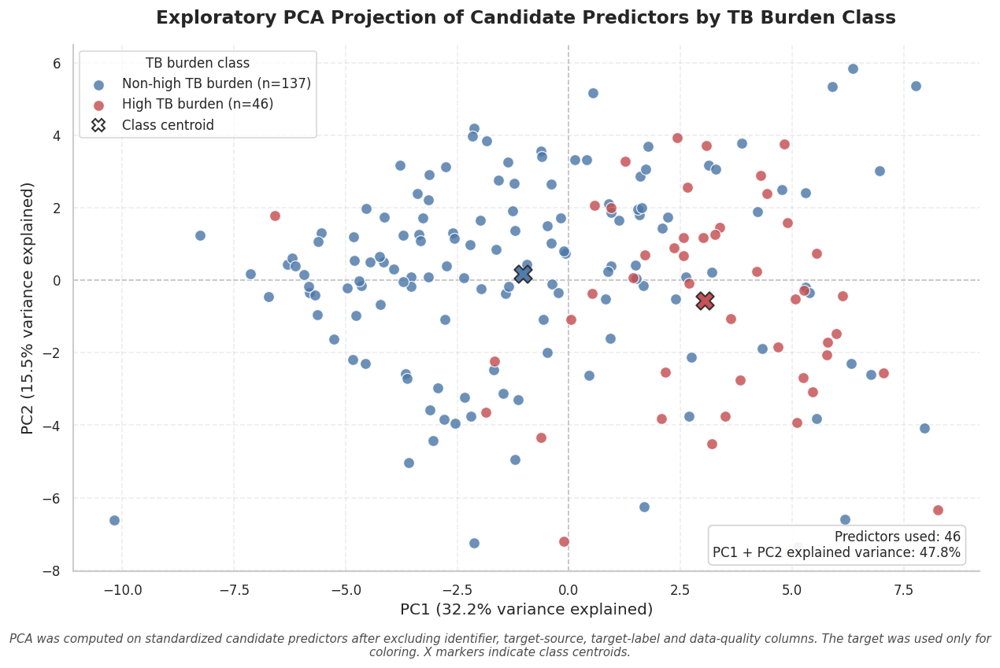

Number of candidate predictors used for PCA: 46
PC1 explained variance (%): 32.25
PC2 explained variance (%): 15.51
PC1 + PC2 explained variance (%): 47.76
PCA coordinates saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/08_pca_country_coordinates.csv
PCA coordinates saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/08_pca_country_coordinates.xlsx
PCA explained variance saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/08_pca_explained_variance.csv
PCA explained variance saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/08_pca_explained_variance.xlsx
PCA feature loadings saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/08_pca_feature_loadings.csv
PCA feature loadings saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/08_pca_feature_loadings.xlsx
PCA figure saved as PNG: True
PNG

In [48]:
# Visualization 7: Exploratory PCA projection of the candidate predictor space

# This visualization provides an exploratory two-dimensional PCA projection of the
# candidate predictor space. Each point represents one country, colored by the
# Q3-based TB burden class. PCA is computed using standardized candidate predictors.
#
# This visualization is descriptive only. It is not used for model training,
# model evaluation or formal feature selection.

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

PCA_FIGURE_PATH = (
    FIGURES_DIR / "12_pca_projection_candidate_predictors_by_tb_burden_class.png"
)

PCA_FIGURE_PDF_PATH = (
    FIGURES_DIR / "12_pca_projection_candidate_predictors_by_tb_burden_class.pdf"
)

PCA_COORDINATES_TABLE_CSV_PATH = (
    TABLES_DIR / "08_pca_country_coordinates.csv"
)

PCA_COORDINATES_TABLE_EXCEL_PATH = (
    TABLES_DIR / "08_pca_country_coordinates.xlsx"
)

PCA_EXPLAINED_VARIANCE_TABLE_CSV_PATH = (
    TABLES_DIR / "08_pca_explained_variance.csv"
)

PCA_EXPLAINED_VARIANCE_TABLE_EXCEL_PATH = (
    TABLES_DIR / "08_pca_explained_variance.xlsx"
)

PCA_LOADINGS_TABLE_CSV_PATH = (
    TABLES_DIR / "08_pca_feature_loadings.csv"
)

PCA_LOADINGS_TABLE_EXCEL_PATH = (
    TABLES_DIR / "08_pca_feature_loadings.xlsx"
)

required_pca_columns = [
    "Area",
    "high_tb_burden",
    "tb_burden_group"
]

missing_pca_columns = [
    column for column in required_pca_columns
    if column not in tb_dataset.columns
]

if missing_pca_columns:
    raise KeyError(
        f"Missing required columns for PCA visualization: {missing_pca_columns}"
    )

if "candidate_predictor_cols" not in globals():
    raise NameError(
        "candidate_predictor_cols is not defined. Run the column role definition cell first."
    )

excluded_columns_for_pca = [
    "Area",
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group",
    "BCG_was_missing"
]

pca_predictor_columns = [
    column for column in candidate_predictor_cols
    if column in tb_dataset.columns
    and column not in excluded_columns_for_pca
]

if len(pca_predictor_columns) == 0:
    raise ValueError(
        "No valid candidate predictor columns were found for PCA."
    )

leakage_columns_in_pca = sorted(
    set(pca_predictor_columns)
    .intersection(excluded_columns_for_pca)
)

if leakage_columns_in_pca:
    raise ValueError(
        f"Leakage columns found in PCA predictors: {leakage_columns_in_pca}"
    )

non_numeric_pca_predictors = [
    column for column in pca_predictor_columns
    if not pd.api.types.is_numeric_dtype(tb_dataset[column])
]

if non_numeric_pca_predictors:
    raise ValueError(
        "Non-numeric predictors found in PCA predictor set: "
        f"{non_numeric_pca_predictors}"
    )

missing_values_in_pca_predictors = (
    tb_dataset[pca_predictor_columns]
    .isna()
    .sum()
)

missing_values_in_pca_predictors = (
    missing_values_in_pca_predictors[
        missing_values_in_pca_predictors > 0
    ]
)

if not missing_values_in_pca_predictors.empty:
    raise ValueError(
        "Missing values found in PCA predictor columns. "
        "Review or impute missing values before PCA.\n"
        f"{missing_values_in_pca_predictors}"
    )

infinite_values_in_pca_predictors = (
    np.isinf(tb_dataset[pca_predictor_columns])
    .sum()
)

infinite_values_in_pca_predictors = (
    infinite_values_in_pca_predictors[
        infinite_values_in_pca_predictors > 0
    ]
)

if not infinite_values_in_pca_predictors.empty:
    raise ValueError(
        "Infinite values found in PCA predictor columns. "
        "Review the data before PCA.\n"
        f"{infinite_values_in_pca_predictors}"
    )

constant_pca_predictors = [
    column for column in pca_predictor_columns
    if tb_dataset[column].nunique(dropna=True) <= 1
]

if constant_pca_predictors:
    raise ValueError(
        "Constant predictor columns cannot be used in PCA: "
        f"{constant_pca_predictors}"
    )

target_unique_values = sorted(
    tb_dataset["high_tb_burden"]
    .dropna()
    .unique()
    .tolist()
)

if target_unique_values != [0, 1]:
    raise ValueError(
        "'high_tb_burden' must be binary with values [0, 1]. "
        f"Observed values: {target_unique_values}"
    )

if tb_dataset["tb_burden_group"].isna().any():
    raise ValueError(
        "'tb_burden_group' contains missing values."
    )

if not set(tb_dataset["tb_burden_group"].unique()).issubset(set(CLASS_ORDER)):
    raise ValueError(
        "Unexpected class labels found in 'tb_burden_group'. "
        f"Observed labels: {sorted(tb_dataset['tb_burden_group'].unique())}"
    )

X_pca = tb_dataset[pca_predictor_columns].copy()

scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca)

pca_model = PCA(
    n_components=2,
    svd_solver="full"
)

pca_coordinates = pca_model.fit_transform(X_pca_scaled)

pc1_explained_variance = pca_model.explained_variance_ratio_[0] * 100
pc2_explained_variance = pca_model.explained_variance_ratio_[1] * 100
total_explained_variance = pc1_explained_variance + pc2_explained_variance

pca_plot_data = pd.DataFrame({
    "country": tb_dataset["Area"],
    "high_tb_burden": tb_dataset["high_tb_burden"],
    "tb_burden_group": tb_dataset["tb_burden_group"],
    "PC1": pca_coordinates[:, 0],
    "PC2": pca_coordinates[:, 1]
})

pca_plot_data["display_label"] = (
    pca_plot_data["tb_burden_group"]
    .map(CLASS_DISPLAY_LABELS)
)

if pca_plot_data["display_label"].isna().any():
    missing_display_labels = (
        pca_plot_data.loc[
            pca_plot_data["display_label"].isna(),
            "tb_burden_group"
        ]
        .drop_duplicates()
        .tolist()
    )

    raise ValueError(
        "Missing display labels for PCA classes: "
        f"{missing_display_labels}"
    )

pca_coordinates_output = pca_plot_data.copy()

pca_coordinates_output.to_csv(
    PCA_COORDINATES_TABLE_CSV_PATH,
    index=False
)

pca_coordinates_output.to_excel(
    PCA_COORDINATES_TABLE_EXCEL_PATH,
    index=False
)

pca_explained_variance = pd.DataFrame({
    "principal_component": ["PC1", "PC2"],
    "explained_variance_ratio": pca_model.explained_variance_ratio_,
    "explained_variance_percentage": [
        pc1_explained_variance,
        pc2_explained_variance
    ],
    "cumulative_explained_variance_percentage": [
        pc1_explained_variance,
        total_explained_variance
    ]
})

pca_explained_variance[
    [
        "explained_variance_ratio",
        "explained_variance_percentage",
        "cumulative_explained_variance_percentage"
    ]
] = pca_explained_variance[
    [
        "explained_variance_ratio",
        "explained_variance_percentage",
        "cumulative_explained_variance_percentage"
    ]
].round(4)

display(pca_explained_variance)

pca_explained_variance.to_csv(
    PCA_EXPLAINED_VARIANCE_TABLE_CSV_PATH,
    index=False
)

pca_explained_variance.to_excel(
    PCA_EXPLAINED_VARIANCE_TABLE_EXCEL_PATH,
    index=False
)

pca_feature_loadings = pd.DataFrame({
    "feature": pca_predictor_columns,
    "PC1_loading": pca_model.components_[0],
    "PC2_loading": pca_model.components_[1]
})

pca_feature_loadings["absolute_PC1_loading"] = (
    pca_feature_loadings["PC1_loading"]
    .abs()
)

pca_feature_loadings["absolute_PC2_loading"] = (
    pca_feature_loadings["PC2_loading"]
    .abs()
)

pca_feature_loadings["maximum_absolute_loading"] = (
    pca_feature_loadings[
        ["absolute_PC1_loading", "absolute_PC2_loading"]
    ]
    .max(axis=1)
)

pca_feature_loadings = (
    pca_feature_loadings
    .sort_values(
        by="maximum_absolute_loading",
        ascending=False
    )
    .reset_index(drop=True)
)

pca_feature_loadings[
    [
        "PC1_loading",
        "PC2_loading",
        "absolute_PC1_loading",
        "absolute_PC2_loading",
        "maximum_absolute_loading"
    ]
] = pca_feature_loadings[
    [
        "PC1_loading",
        "PC2_loading",
        "absolute_PC1_loading",
        "absolute_PC2_loading",
        "maximum_absolute_loading"
    ]
].round(4)

display(pca_feature_loadings.head(15))

pca_feature_loadings.to_csv(
    PCA_LOADINGS_TABLE_CSV_PATH,
    index=False
)

pca_feature_loadings.to_excel(
    PCA_LOADINGS_TABLE_EXCEL_PATH,
    index=False
)

fig, ax = plt.subplots(figsize=(10.5, 7.2))

for group_name in CLASS_ORDER:
    group_subset = pca_plot_data[
        pca_plot_data["tb_burden_group"] == group_name
    ]

    ax.scatter(
        group_subset["PC1"],
        group_subset["PC2"],
        s=70,
        color=CLASS_COLORS[group_name],
        edgecolor="white",
        linewidth=0.8,
        alpha=0.82,
        label=f"{CLASS_DISPLAY_LABELS[group_name]} (n={len(group_subset)})"
    )

class_centroids = (
    pca_plot_data
    .groupby("tb_burden_group", observed=True)[["PC1", "PC2"]]
    .mean()
)

for group_name in CLASS_ORDER:
    if group_name in class_centroids.index:
        ax.scatter(
            class_centroids.loc[group_name, "PC1"],
            class_centroids.loc[group_name, "PC2"],
            s=180,
            color=CLASS_COLORS[group_name],
            edgecolor=NEUTRAL_DARK_COLOR,
            linewidth=1.2,
            marker="X",
            alpha=0.98,
            zorder=5
        )

ax.axhline(
    0,
    color="#BFBFBF",
    linewidth=1.0,
    linestyle="--",
    zorder=0
)

ax.axvline(
    0,
    color="#BFBFBF",
    linewidth=1.0,
    linestyle="--",
    zorder=0
)

ax.set_title(
    "Exploratory PCA Projection of Candidate Predictors by TB Burden Class",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel(
    f"PC1 ({pc1_explained_variance:.1f}% variance explained)",
    fontsize=12
)

ax.set_ylabel(
    f"PC2 ({pc2_explained_variance:.1f}% variance explained)",
    fontsize=12
)

centroid_legend_handle = Line2D(
    [0],
    [0],
    marker="X",
    color="white",
    markerfacecolor="#FFFFFF",
    markeredgecolor=NEUTRAL_DARK_COLOR,
    markeredgewidth=1.2,
    markersize=10,
    linestyle="None",
    label="Class centroid"
)

handles, labels = ax.get_legend_handles_labels()
handles.append(centroid_legend_handle)
labels.append("Class centroid")

ax.legend(
    handles=handles,
    labels=labels,
    title="TB burden class",
    loc="best",
    frameon=True,
    facecolor="white",
    edgecolor="#CFCFCF",
    fontsize=10,
    title_fontsize=10
)

ax.text(
    0.98,
    0.02,
    (
        f"Predictors used: {len(pca_predictor_columns)}\n"
        f"PC1 + PC2 explained variance: {total_explained_variance:.1f}%"
    ),
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#CFCFCF",
        alpha=0.92
    )
)

ax.grid(
    axis="both",
    linestyle="--",
    alpha=GRID_COLOR_ALPHA
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=10)

fig.text(
    0.5,
    0.02,
    (
        "PCA was computed on standardized candidate predictors after excluding identifier, "
        "target-source, target-label and data-quality columns. The target was used only for "
        "coloring. X markers indicate class centroids."
    ),
    ha="center",
    va="bottom",
    fontsize=9,
    color="#4D4D4D",
    style="italic",
    wrap=True
)

plt.tight_layout(rect=[0, 0.055, 1, 1])

fig.savefig(
    PCA_FIGURE_PATH,
    dpi=FIGURE_DPI,
    bbox_inches="tight"
)

fig.savefig(
    PCA_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()

print("Number of candidate predictors used for PCA:", len(pca_predictor_columns))
print("PC1 explained variance (%):", round(pc1_explained_variance, 2))
print("PC2 explained variance (%):", round(pc2_explained_variance, 2))
print("PC1 + PC2 explained variance (%):", round(total_explained_variance, 2))
print("PCA coordinates saved as CSV:", PCA_COORDINATES_TABLE_CSV_PATH)
print("PCA coordinates saved as Excel:", PCA_COORDINATES_TABLE_EXCEL_PATH)
print("PCA explained variance saved as CSV:", PCA_EXPLAINED_VARIANCE_TABLE_CSV_PATH)
print("PCA explained variance saved as Excel:", PCA_EXPLAINED_VARIANCE_TABLE_EXCEL_PATH)
print("PCA feature loadings saved as CSV:", PCA_LOADINGS_TABLE_CSV_PATH)
print("PCA feature loadings saved as Excel:", PCA_LOADINGS_TABLE_EXCEL_PATH)
print("PCA figure saved as PNG:", PCA_FIGURE_PATH.exists())
print("PNG path:", PCA_FIGURE_PATH)
print("PCA figure saved as PDF:", PCA_FIGURE_PDF_PATH.exists())
print("PDF path:", PCA_FIGURE_PDF_PATH)
print("PCA visualization check passed.")

In [49]:
# Step 1: Define final ML predictor columns and prevent data leakage

# This cell defines the final predictor columns used for machine learning and
# statistical feature screening. Identifier, target-source, target-label and
# data-quality indicator columns are excluded to prevent data leakage.
#
# Important: this cell only defines the candidate ML predictor set.
# Formal statistical feature screening must be performed later on the training set only.

identifier_column = "Area"
target_source_column = "TB_incidence_2022"
target_column = "high_tb_burden"
target_label_column = "tb_burden_group"
data_quality_indicator_column = "BCG_was_missing"

excluded_from_ml_predictors = [
    identifier_column,
    target_source_column,
    target_column,
    target_label_column,
    data_quality_indicator_column
]

required_ml_role_columns = [
    identifier_column,
    target_source_column,
    target_column,
    target_label_column,
    data_quality_indicator_column
]

missing_required_ml_role_columns = [
    column for column in required_ml_role_columns
    if column not in tb_dataset.columns
]

if missing_required_ml_role_columns:
    raise KeyError(
        "Missing required ML role columns: "
        f"{missing_required_ml_role_columns}"
    )

if "candidate_predictor_cols" not in globals():
    raise NameError(
        "candidate_predictor_cols is not defined. "
        "Run the candidate predictor column definition cell first."
    )

if "TABLES_DIR" not in globals():
    raise NameError(
        "TABLES_DIR is not defined. Run the output directory definition cell first."
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if len(candidate_predictor_cols) != len(set(candidate_predictor_cols)):
    duplicate_candidate_predictors = sorted({
        column
        for column in candidate_predictor_cols
        if candidate_predictor_cols.count(column) > 1
    })

    raise ValueError(
        "Duplicate predictor names found in candidate_predictor_cols: "
        f"{duplicate_candidate_predictors}"
    )

missing_candidate_predictors = [
    column for column in candidate_predictor_cols
    if column not in tb_dataset.columns
]

if missing_candidate_predictors:
    raise KeyError(
        "Candidate predictor columns missing from dataset: "
        f"{missing_candidate_predictors}"
    )

target_unique_values = sorted(
    tb_dataset[target_column]
    .dropna()
    .unique()
    .tolist()
)

if target_unique_values != [0, 1]:
    raise ValueError(
        f"The target column '{target_column}' must be binary with values [0, 1]. "
        f"Observed values: {target_unique_values}"
    )

if tb_dataset[target_column].isna().any():
    raise ValueError(
        f"The target column '{target_column}' contains missing values."
    )

final_ml_predictor_cols = [
    column for column in candidate_predictor_cols
    if column not in excluded_from_ml_predictors
]

if len(final_ml_predictor_cols) == 0:
    raise ValueError(
        "No valid ML predictor columns were found after excluding leakage columns."
    )

if len(final_ml_predictor_cols) != len(set(final_ml_predictor_cols)):
    raise ValueError(
        "Duplicate predictor names found in final_ml_predictor_cols."
    )

leakage_columns_found_in_predictors = sorted(
    set(final_ml_predictor_cols)
    .intersection(excluded_from_ml_predictors)
)

if leakage_columns_found_in_predictors:
    raise ValueError(
        "Leakage columns found in final ML predictor set: "
        f"{leakage_columns_found_in_predictors}"
    )

non_numeric_predictors = [
    column for column in final_ml_predictor_cols
    if not pd.api.types.is_numeric_dtype(tb_dataset[column])
]

if non_numeric_predictors:
    raise TypeError(
        "Non-numeric columns found in final ML predictor set: "
        f"{non_numeric_predictors}"
    )

missing_values_in_final_predictors = (
    tb_dataset[final_ml_predictor_cols]
    .isna()
    .sum()
)

missing_values_in_final_predictors = (
    missing_values_in_final_predictors[
        missing_values_in_final_predictors > 0
    ]
)

if not missing_values_in_final_predictors.empty:
    raise ValueError(
        "Missing values found in final ML predictor columns. "
        "Review the preprocessing step before statistical tests and modeling.\n"
        f"{missing_values_in_final_predictors}"
    )

infinite_values_in_final_predictors = (
    np.isinf(tb_dataset[final_ml_predictor_cols])
    .sum()
)

infinite_values_in_final_predictors = (
    infinite_values_in_final_predictors[
        infinite_values_in_final_predictors > 0
    ]
)

if not infinite_values_in_final_predictors.empty:
    raise ValueError(
        "Infinite values found in final ML predictor columns. "
        "Review the preprocessing step before statistical tests and modeling.\n"
        f"{infinite_values_in_final_predictors}"
    )

constant_final_predictors = [
    column for column in final_ml_predictor_cols
    if tb_dataset[column].nunique(dropna=True) <= 1
]

if constant_final_predictors:
    raise ValueError(
        "Constant predictor columns found in final ML predictor set: "
        f"{constant_final_predictors}"
    )

numeric_columns_for_ml = (
    tb_dataset
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)

predictor_role_summary = pd.DataFrame({
    "column_group": [
        "Total dataset columns",
        "Numeric columns",
        "Candidate predictor columns",
        "Excluded from ML predictors",
        "Final valid ML predictors"
    ],
    "number_of_columns": [
        tb_dataset.shape[1],
        len(numeric_columns_for_ml),
        len(candidate_predictor_cols),
        len(excluded_from_ml_predictors),
        len(final_ml_predictor_cols)
    ]
})

excluded_columns_summary = pd.DataFrame({
    "excluded_column": excluded_from_ml_predictors,
    "reason_for_exclusion": [
        "Country identifier, not a predictive variable",
        "Target-source column used to define high_tb_burden",
        "Binary target variable",
        "Text label version of the target variable",
        "Data-quality indicator, not used as a main ML predictor"
    ]
})

valid_predictors_summary = pd.DataFrame({
    "predictor_column": final_ml_predictor_cols,
    "dtype": [
        str(tb_dataset[column].dtype)
        for column in final_ml_predictor_cols
    ],
    "number_of_missing_values": [
        int(tb_dataset[column].isna().sum())
        for column in final_ml_predictor_cols
    ],
    "number_of_unique_values": [
        int(tb_dataset[column].nunique(dropna=True))
        for column in final_ml_predictor_cols
    ]
})

predictor_role_summary_csv_path = TABLES_DIR / "09_predictor_role_summary.csv"
predictor_role_summary_excel_path = TABLES_DIR / "09_predictor_role_summary.xlsx"

excluded_columns_summary_csv_path = TABLES_DIR / "09_excluded_ml_columns_summary.csv"
excluded_columns_summary_excel_path = TABLES_DIR / "09_excluded_ml_columns_summary.xlsx"

valid_predictors_summary_csv_path = TABLES_DIR / "09_final_ml_predictors_summary.csv"
valid_predictors_summary_excel_path = TABLES_DIR / "09_final_ml_predictors_summary.xlsx"

predictor_role_summary.to_csv(
    predictor_role_summary_csv_path,
    index=False
)

predictor_role_summary.to_excel(
    predictor_role_summary_excel_path,
    index=False
)

excluded_columns_summary.to_csv(
    excluded_columns_summary_csv_path,
    index=False
)

excluded_columns_summary.to_excel(
    excluded_columns_summary_excel_path,
    index=False
)

valid_predictors_summary.to_csv(
    valid_predictors_summary_csv_path,
    index=False
)

valid_predictors_summary.to_excel(
    valid_predictors_summary_excel_path,
    index=False
)

display(predictor_role_summary)
display(excluded_columns_summary)
display(valid_predictors_summary)

# Keep this alias for compatibility with later cells, if they already use this name.
all_valid_predictor_cols = final_ml_predictor_cols.copy()

X_all = tb_dataset[final_ml_predictor_cols].copy()
y_all = tb_dataset[target_column].copy()
country_ids = tb_dataset[identifier_column].copy()

print("Number of final valid ML predictors:", len(final_ml_predictor_cols))
print("Excluded columns:", excluded_from_ml_predictors)
print("Target column:", target_column)
print("X_all shape:", X_all.shape)
print("y_all shape:", y_all.shape)
print("Duplicate predictor name check passed.")
print("Missing value check passed.")
print("Infinite value check passed.")
print("Constant predictor check passed.")
print("Leakage quality gate passed: no excluded columns are present in final_ml_predictor_cols.")
print("Predictor role summary saved as CSV:", predictor_role_summary_csv_path)
print("Predictor role summary saved as Excel:", predictor_role_summary_excel_path)
print("Excluded columns summary saved as CSV:", excluded_columns_summary_csv_path)
print("Excluded columns summary saved as Excel:", excluded_columns_summary_excel_path)
print("Final ML predictors summary saved as CSV:", valid_predictors_summary_csv_path)
print("Final ML predictors summary saved as Excel:", valid_predictors_summary_excel_path)
print("Final ML predictor definition check passed.")

,column_group,number_of_columns
0,Total dataset columns,51
1,Numeric columns,48
2,Candidate predictor columns,46
3,Excluded from ML predictors,5
4,Final valid ML predictors,46


,excluded_column,reason_for_exclusion
0,Area,"Country identifier, not a predictive variable"
1,TB_incidence_2022,Target-source column used to define high_tb_bu...
2,high_tb_burden,Binary target variable
3,tb_burden_group,Text label version of the target variable
4,BCG_was_missing,"Data-quality indicator, not used as a main ML ..."


,predictor_column,dtype,number_of_missing_values,number_of_unique_values
0,Calcium supply - Cereals and their products,int64,0,80
1,Calcium supply - Milk and milk products,int64,0,163
2,"Calcium supply - Pulses, seeds and nuts and th...",int64,0,71
3,Calcium supply - Vegetables and their products,int64,0,116
4,Energy supply - Cereals and their products,int64,0,170
5,Energy supply - Fats and oils,int64,0,154
6,Energy supply - Meat and meat products,int64,0,151
7,"Energy supply - Roots, tubers, plantains and t...",int64,0,135
8,Energy supply - Sweets and sugars,int64,0,155
9,Iron supply - Cereals and their products,float64,0,73


Number of final valid ML predictors: 46
Excluded columns: ['Area', 'TB_incidence_2022', 'high_tb_burden', 'tb_burden_group', 'BCG_was_missing']
Target column: high_tb_burden
X_all shape: (183, 46)
y_all shape: (183,)
Duplicate predictor name check passed.
Missing value check passed.
Infinite value check passed.
Constant predictor check passed.
Leakage quality gate passed: no excluded columns are present in final_ml_predictor_cols.
Predictor role summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/09_predictor_role_summary.csv
Predictor role summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/09_predictor_role_summary.xlsx
Excluded columns summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/09_excluded_ml_columns_summary.csv
Excluded columns summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/09_excluded_ml_columns_summary.xl

In [50]:
# Step 2: ML input quality check before train/test split

# This cell verifies that the final ML input objects created in the previous step
# are valid before performing the train/test split.
#
# It checks shape consistency, index alignment, binary target encoding,
# predictor data types, missing values, infinite values, constant predictors
# and target class distribution.
#
# Important: this cell does not perform statistical feature screening.
# Statistical tests must be performed later on the training set only.

required_ml_input_objects = [
    "X_all",
    "y_all",
    "country_ids",
    "all_valid_predictor_cols",
    "target_column"
]

missing_ml_input_objects = [
    object_name for object_name in required_ml_input_objects
    if object_name not in globals()
]

if missing_ml_input_objects:
    raise NameError(
        "Missing required ML input objects. "
        "Run the final predictor definition cell first. "
        f"Missing objects: {missing_ml_input_objects}"
    )

if "TABLES_DIR" not in globals():
    raise NameError(
        "TABLES_DIR is not defined. Run the output directory definition cell first."
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(X_all, pd.DataFrame):
    raise TypeError(
        "X_all must be a pandas DataFrame."
    )

if not isinstance(y_all, pd.Series):
    raise TypeError(
        "y_all must be a pandas Series."
    )

if not isinstance(country_ids, pd.Series):
    raise TypeError(
        "country_ids must be a pandas Series."
    )

if not isinstance(all_valid_predictor_cols, list):
    raise TypeError(
        "all_valid_predictor_cols must be a list."
    )

if X_all.shape[0] != y_all.shape[0]:
    raise ValueError(
        "The number of rows in X_all and y_all does not match."
    )

if X_all.shape[0] != country_ids.shape[0]:
    raise ValueError(
        "The number of rows in X_all and country_ids does not match."
    )

if not X_all.index.equals(y_all.index):
    raise ValueError(
        "The index of X_all and y_all does not match. "
        "Predictors and target may be misaligned."
    )

if not X_all.index.equals(country_ids.index):
    raise ValueError(
        "The index of X_all and country_ids does not match. "
        "Predictors and country identifiers may be misaligned."
    )

if X_all.shape[1] != len(all_valid_predictor_cols):
    raise ValueError(
        "The number of columns in X_all does not match all_valid_predictor_cols."
    )

if list(X_all.columns) != list(all_valid_predictor_cols):
    raise ValueError(
        "The columns in X_all do not match all_valid_predictor_cols in the same order."
    )

if len(X_all.columns) != len(set(X_all.columns)):
    duplicated_predictor_names = (
        X_all.columns[
            X_all.columns.duplicated()
        ]
        .tolist()
    )

    raise ValueError(
        "Duplicate predictor names found in X_all: "
        f"{duplicated_predictor_names}"
    )

target_unique_values = sorted(
    y_all
    .dropna()
    .unique()
    .tolist()
)

if target_unique_values != [0, 1]:
    raise ValueError(
        f"The target column '{target_column}' must be binary with values [0, 1]. "
        f"Observed values: {target_unique_values}"
    )

if y_all.isna().any():
    raise ValueError(
        f"The target column '{target_column}' contains missing values."
    )

non_numeric_predictors_in_X = [
    column for column in X_all.columns
    if not pd.api.types.is_numeric_dtype(X_all[column])
]

if non_numeric_predictors_in_X:
    raise TypeError(
        "Non-numeric predictors found in X_all: "
        f"{non_numeric_predictors_in_X}"
    )

missing_values_per_predictor = (
    X_all
    .isna()
    .sum()
)

predictors_with_missing_values = (
    missing_values_per_predictor[
        missing_values_per_predictor > 0
    ]
)

if not predictors_with_missing_values.empty:
    raise ValueError(
        "Missing values found in ML predictor columns. "
        "Review or impute missing values before train/test split and modeling.\n"
        f"{predictors_with_missing_values}"
    )

infinite_values_per_predictor = (
    np.isinf(X_all)
    .sum()
)

predictors_with_infinite_values = (
    infinite_values_per_predictor[
        infinite_values_per_predictor > 0
    ]
)

if not predictors_with_infinite_values.empty:
    raise ValueError(
        "Infinite values found in ML predictor columns. "
        "Review the data before train/test split and modeling.\n"
        f"{predictors_with_infinite_values}"
    )

constant_predictors = [
    column for column in X_all.columns
    if X_all[column].nunique(dropna=True) <= 1
]

if constant_predictors:
    raise ValueError(
        "Constant predictors found in X_all. "
        "These columns do not contain useful variation for modeling: "
        f"{constant_predictors}"
    )

target_distribution_for_ml = (
    y_all
    .value_counts()
    .sort_index()
    .rename_axis(target_column)
    .reset_index(name="number_of_countries")
)

target_distribution_for_ml["percentage"] = (
    target_distribution_for_ml["number_of_countries"]
    / len(y_all)
    * 100
).round(2)

if "CLASS_DISPLAY_LABELS" in globals():
    target_label_mapping = {
        0: CLASS_DISPLAY_LABELS.get(
            "non_high_tb_burden",
            "Non-high TB burden"
        ),
        1: CLASS_DISPLAY_LABELS.get(
            "high_tb_burden",
            "High TB burden"
        )
    }
else:
    target_label_mapping = {
        0: "Non-high TB burden",
        1: "High TB burden"
    }

target_distribution_for_ml["target_label"] = (
    target_distribution_for_ml[target_column]
    .map(target_label_mapping)
)

number_of_target_classes = target_distribution_for_ml.shape[0]

minimum_class_count = int(
    target_distribution_for_ml["number_of_countries"].min()
)

if number_of_target_classes != 2:
    raise ValueError(
        "The target must contain exactly two classes before train/test split. "
        f"Observed number of classes: {number_of_target_classes}"
    )

if minimum_class_count < 2:
    raise ValueError(
        "At least two observations are required in each target class "
        "for a stratified train/test split."
    )

ml_input_quality_summary = pd.DataFrame({
    "quality_check": [
        "Number of countries",
        "Number of valid predictors",
        "Index alignment check",
        "Missing values in predictors",
        "Infinite values in predictors",
        "Missing values in target",
        "Non-numeric predictors",
        "Constant predictors",
        "Target classes",
        "Minimum class count"
    ],
    "value": [
        X_all.shape[0],
        X_all.shape[1],
        "Passed",
        int(missing_values_per_predictor.sum()),
        int(infinite_values_per_predictor.sum()),
        int(y_all.isna().sum()),
        len(non_numeric_predictors_in_X),
        len(constant_predictors),
        number_of_target_classes,
        minimum_class_count
    ]
})

ml_input_quality_summary_csv_path = (
    TABLES_DIR / "10_ml_input_quality_summary.csv"
)

ml_input_quality_summary_excel_path = (
    TABLES_DIR / "10_ml_input_quality_summary.xlsx"
)

target_distribution_for_ml_csv_path = (
    TABLES_DIR / "10_ml_target_distribution_before_split.csv"
)

target_distribution_for_ml_excel_path = (
    TABLES_DIR / "10_ml_target_distribution_before_split.xlsx"
)

ml_input_quality_summary.to_csv(
    ml_input_quality_summary_csv_path,
    index=False
)

ml_input_quality_summary.to_excel(
    ml_input_quality_summary_excel_path,
    index=False
)

target_distribution_for_ml.to_csv(
    target_distribution_for_ml_csv_path,
    index=False
)

target_distribution_for_ml.to_excel(
    target_distribution_for_ml_excel_path,
    index=False
)

display(ml_input_quality_summary)
display(target_distribution_for_ml)

print("X_all shape:", X_all.shape)
print("y_all shape:", y_all.shape)
print("country_ids shape:", country_ids.shape)
print("Number of target classes:", number_of_target_classes)
print("Minimum class count:", minimum_class_count)
print("Index alignment check passed.")
print("ML input quality summary saved as CSV:", ml_input_quality_summary_csv_path)
print("ML input quality summary saved as Excel:", ml_input_quality_summary_excel_path)
print("Target distribution before split saved as CSV:", target_distribution_for_ml_csv_path)
print("Target distribution before split saved as Excel:", target_distribution_for_ml_excel_path)
print("ML input quality check passed. Data are ready for stratified train/test split.")

,quality_check,value
0,Number of countries,183
1,Number of valid predictors,46
2,Index alignment check,Passed
3,Missing values in predictors,0
4,Infinite values in predictors,0
5,Missing values in target,0
6,Non-numeric predictors,0
7,Constant predictors,0
8,Target classes,2
9,Minimum class count,46


,high_tb_burden,number_of_countries,percentage,target_label
0,0,137,74.86,Non-high TB burden
1,1,46,25.14,High TB burden


X_all shape: (183, 46)
y_all shape: (183,)
country_ids shape: (183,)
Number of target classes: 2
Minimum class count: 46
Index alignment check passed.
ML input quality summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/10_ml_input_quality_summary.csv
ML input quality summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/10_ml_input_quality_summary.xlsx
Target distribution before split saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/10_ml_target_distribution_before_split.csv
Target distribution before split saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/10_ml_target_distribution_before_split.xlsx
ML input quality check passed. Data are ready for stratified train/test split.


In [51]:
# Step 3: Stratified train/test split

# This cell splits the dataset into training and test sets using stratified sampling.
# Stratification preserves the class distribution of the binary high_tb_burden target
# in both the training and test sets.
#
# Important:
# - Statistical feature screening must be performed only on the training set.
# - The test set must remain untouched until final model evaluation.

from sklearn.model_selection import train_test_split

test_size = 0.20

required_split_objects = [
    "tb_dataset",
    "X_all",
    "y_all",
    "country_ids",
    "all_valid_predictor_cols",
    "identifier_column",
    "target_source_column",
    "target_column",
    "target_label_column",
    "RANDOM_STATE",
    "TABLES_DIR"
]

missing_split_objects = [
    object_name for object_name in required_split_objects
    if object_name not in globals()
]

if missing_split_objects:
    raise NameError(
        "Missing required objects for train/test split. "
        "Run the previous ML input definition and quality check cells first. "
        f"Missing objects: {missing_split_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(X_all, pd.DataFrame):
    raise TypeError(
        "X_all must be a pandas DataFrame."
    )

if not isinstance(y_all, pd.Series):
    raise TypeError(
        "y_all must be a pandas Series."
    )

if not isinstance(country_ids, pd.Series):
    raise TypeError(
        "country_ids must be a pandas Series."
    )

if not isinstance(all_valid_predictor_cols, list):
    raise TypeError(
        "all_valid_predictor_cols must be a list."
    )

if not 0 < test_size < 1:
    raise ValueError(
        f"test_size must be between 0 and 1. Observed value: {test_size}"
    )

if X_all.shape[0] != y_all.shape[0]:
    raise ValueError(
        "The number of rows in X_all and y_all does not match."
    )

if X_all.shape[0] != country_ids.shape[0]:
    raise ValueError(
        "The number of rows in X_all and country_ids does not match."
    )

if not X_all.index.equals(y_all.index):
    raise ValueError(
        "The index of X_all and y_all does not match. "
        "Predictors and target may be misaligned."
    )

if not X_all.index.equals(country_ids.index):
    raise ValueError(
        "The index of X_all and country_ids does not match. "
        "Predictors and country identifiers may be misaligned."
    )

if not X_all.index.is_unique:
    raise ValueError(
        "X_all index must be unique before train/test split."
    )

if not y_all.index.is_unique:
    raise ValueError(
        "y_all index must be unique before train/test split."
    )

if not country_ids.index.is_unique:
    raise ValueError(
        "country_ids index must be unique before train/test split."
    )

if not country_ids.is_unique:
    duplicated_country_ids = (
        country_ids[country_ids.duplicated()]
        .drop_duplicates()
        .tolist()
    )

    raise ValueError(
        "Duplicate country identifiers found before train/test split: "
        f"{duplicated_country_ids}"
    )

if list(X_all.columns) != list(all_valid_predictor_cols):
    raise ValueError(
        "The columns in X_all do not match all_valid_predictor_cols in the same order."
    )

target_unique_values = sorted(
    y_all
    .dropna()
    .unique()
    .tolist()
)

if target_unique_values != [0, 1]:
    raise ValueError(
        f"The target column '{target_column}' must be binary with values [0, 1]. "
        f"Observed values: {target_unique_values}"
    )

if y_all.isna().any():
    raise ValueError(
        f"The target column '{target_column}' contains missing values."
    )

target_class_counts = (
    y_all
    .value_counts()
    .sort_index()
)

minimum_class_count = int(target_class_counts.min())

if minimum_class_count < 2:
    raise ValueError(
        "At least two observations are required in each target class "
        "for a stratified train/test split."
    )

metadata_columns_for_split = [
    identifier_column,
    target_source_column,
    target_column,
    target_label_column
]

missing_metadata_columns_for_split = [
    column for column in metadata_columns_for_split
    if column not in tb_dataset.columns
]

if missing_metadata_columns_for_split:
    raise KeyError(
        "Missing metadata columns needed for train/test tracking: "
        f"{missing_metadata_columns_for_split}"
    )

ml_metadata = (
    tb_dataset
    .loc[X_all.index, metadata_columns_for_split]
    .copy()
)

if not ml_metadata.index.equals(X_all.index):
    raise ValueError(
        "The index of ml_metadata and X_all does not match."
    )

if not ml_metadata[identifier_column].equals(country_ids):
    raise ValueError(
        "The country identifiers in ml_metadata and country_ids do not match."
    )

(
    X_train_all,
    X_test_all,
    y_train,
    y_test,
    train_metadata,
    test_metadata
) = train_test_split(
    X_all,
    y_all,
    ml_metadata,
    test_size=test_size,
    random_state=RANDOM_STATE,
    stratify=y_all
)

if X_train_all.shape[0] != y_train.shape[0]:
    raise ValueError(
        "The number of rows in X_train_all and y_train does not match."
    )

if X_test_all.shape[0] != y_test.shape[0]:
    raise ValueError(
        "The number of rows in X_test_all and y_test does not match."
    )

if X_train_all.shape[0] != train_metadata.shape[0]:
    raise ValueError(
        "The number of rows in X_train_all and train_metadata does not match."
    )

if X_test_all.shape[0] != test_metadata.shape[0]:
    raise ValueError(
        "The number of rows in X_test_all and test_metadata does not match."
    )

if not X_train_all.index.equals(y_train.index):
    raise ValueError(
        "The index of X_train_all and y_train does not match."
    )

if not X_test_all.index.equals(y_test.index):
    raise ValueError(
        "The index of X_test_all and y_test does not match."
    )

if not X_train_all.index.equals(train_metadata.index):
    raise ValueError(
        "The index of X_train_all and train_metadata does not match."
    )

if not X_test_all.index.equals(test_metadata.index):
    raise ValueError(
        "The index of X_test_all and test_metadata does not match."
    )

if X_train_all.shape[1] != X_all.shape[1]:
    raise ValueError(
        "The number of training predictor columns does not match X_all."
    )

if X_test_all.shape[1] != X_all.shape[1]:
    raise ValueError(
        "The number of test predictor columns does not match X_all."
    )

if list(X_train_all.columns) != list(X_all.columns):
    raise ValueError(
        "The training predictor columns do not match X_all columns."
    )

if list(X_test_all.columns) != list(X_all.columns):
    raise ValueError(
        "The test predictor columns do not match X_all columns."
    )

overlapping_indices = (
    set(X_train_all.index)
    .intersection(set(X_test_all.index))
)

if overlapping_indices:
    raise ValueError(
        "Overlapping rows found between train and test sets."
    )

if len(X_train_all) + len(X_test_all) != len(X_all):
    raise ValueError(
        "Train and test row counts do not sum to the full dataset size."
    )

train_country_ids = train_metadata[identifier_column].copy()
test_country_ids = test_metadata[identifier_column].copy()

# Compatibility aliases for later cells, if older names are already used.
X_train_all_valid = X_train_all.copy()
X_test_all_valid = X_test_all.copy()


def create_target_distribution_table(y_values, split_name):
    distribution_table = (
        y_values
        .value_counts()
        .reindex([0, 1], fill_value=0)
        .rename_axis(target_column)
        .reset_index(name="number_of_countries")
    )

    distribution_table["percentage"] = (
        distribution_table["number_of_countries"]
        / len(y_values)
        * 100
    ).round(2)

    if "CLASS_DISPLAY_LABELS" in globals():
        target_label_mapping = {
            0: CLASS_DISPLAY_LABELS.get(
                "non_high_tb_burden",
                "Non-high TB burden"
            ),
            1: CLASS_DISPLAY_LABELS.get(
                "high_tb_burden",
                "High TB burden"
            )
        }
    else:
        target_label_mapping = {
            0: "Non-high TB burden",
            1: "High TB burden"
        }

    distribution_table["target_label"] = (
        distribution_table[target_column]
        .map(target_label_mapping)
    )

    distribution_table.insert(
        0,
        "split",
        split_name
    )

    return distribution_table


full_target_distribution = create_target_distribution_table(
    y_all,
    "Full dataset"
)

train_target_distribution = create_target_distribution_table(
    y_train,
    "Training set"
)

test_target_distribution = create_target_distribution_table(
    y_test,
    "Test set"
)

split_target_distribution = pd.concat(
    [
        full_target_distribution,
        train_target_distribution,
        test_target_distribution
    ],
    ignore_index=True
)

train_class_counts = (
    y_train
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

test_class_counts = (
    y_test
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

if (train_class_counts == 0).any():
    raise ValueError(
        "At least one target class is missing from the training set."
    )

if (test_class_counts == 0).any():
    raise ValueError(
        "At least one target class is missing from the test set."
    )

split_shape_summary = pd.DataFrame({
    "dataset_part": [
        "Full dataset",
        "Training set",
        "Test set"
    ],
    "number_of_countries": [
        X_all.shape[0],
        X_train_all.shape[0],
        X_test_all.shape[0]
    ],
    "number_of_predictors": [
        X_all.shape[1],
        X_train_all.shape[1],
        X_test_all.shape[1]
    ],
    "percentage_of_full_dataset": [
        100.00,
        round(X_train_all.shape[0] / X_all.shape[0] * 100, 2),
        round(X_test_all.shape[0] / X_all.shape[0] * 100, 2)
    ]
})

train_test_assignment = pd.concat(
    [
        train_metadata.assign(split="Training set"),
        test_metadata.assign(split="Test set")
    ],
    axis=0
)

train_test_assignment = (
    train_test_assignment
    .reset_index()
    .rename(columns={"index": "original_index"})
)

train_test_assignment = train_test_assignment[
    [
        "original_index",
        "split",
        identifier_column,
        target_source_column,
        target_column,
        target_label_column
    ]
]

train_test_assignment = (
    train_test_assignment
    .sort_values(by="original_index")
    .reset_index(drop=True)
)

split_shape_summary_csv_path = (
    TABLES_DIR / "11_train_test_split_shape_summary.csv"
)

split_shape_summary_excel_path = (
    TABLES_DIR / "11_train_test_split_shape_summary.xlsx"
)

split_target_distribution_csv_path = (
    TABLES_DIR / "11_train_test_split_target_distribution.csv"
)

split_target_distribution_excel_path = (
    TABLES_DIR / "11_train_test_split_target_distribution.xlsx"
)

train_test_assignment_csv_path = (
    TABLES_DIR / "11_train_test_split_assignment.csv"
)

train_test_assignment_excel_path = (
    TABLES_DIR / "11_train_test_split_assignment.xlsx"
)

split_shape_summary.to_csv(
    split_shape_summary_csv_path,
    index=False
)

split_shape_summary.to_excel(
    split_shape_summary_excel_path,
    index=False
)

split_target_distribution.to_csv(
    split_target_distribution_csv_path,
    index=False
)

split_target_distribution.to_excel(
    split_target_distribution_excel_path,
    index=False
)

train_test_assignment.to_csv(
    train_test_assignment_csv_path,
    index=False
)

train_test_assignment.to_excel(
    train_test_assignment_excel_path,
    index=False
)

display(split_shape_summary)
display(split_target_distribution)
display(train_test_assignment.head(10))

print("Train/test split completed successfully.")
print("Test size:", test_size)
print("Random state:", RANDOM_STATE)
print("X_train_all shape:", X_train_all.shape)
print("X_test_all shape:", X_test_all.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("Training class counts:")
print(train_class_counts)
print("Test class counts:")
print(test_class_counts)
print("Unique index check passed.")
print("Unique country identifier check passed.")
print("No overlapping indices between train and test sets.")
print("Stratified split check passed.")
print("Split shape summary saved as CSV:", split_shape_summary_csv_path)
print("Split shape summary saved as Excel:", split_shape_summary_excel_path)
print("Split target distribution saved as CSV:", split_target_distribution_csv_path)
print("Split target distribution saved as Excel:", split_target_distribution_excel_path)
print("Train/test assignment saved as CSV:", train_test_assignment_csv_path)
print("Train/test assignment saved as Excel:", train_test_assignment_excel_path)
print("Train/test split check passed. Data are ready for training-set-only statistical feature screening.")

,dataset_part,number_of_countries,number_of_predictors,percentage_of_full_dataset
0,Full dataset,183,46,100.00
1,Training set,146,46,79.78
2,Test set,37,46,20.22


,split,high_tb_burden,number_of_countries,percentage,target_label
0,Full dataset,0,137,74.86,Non-high TB burden
1,Full dataset,1,46,25.14,High TB burden
2,Training set,0,109,74.66,Non-high TB burden
3,Training set,1,37,25.34,High TB burden
4,Test set,0,28,75.68,Non-high TB burden
5,Test set,1,9,24.32,High TB burden


,original_index,split,Area,TB_incidence_2022,high_tb_burden,tb_burden_group
0,0,Test set,Afghanistan,185.0,1,high_tb_burden
1,1,Training set,Albania,15.0,0,non_high_tb_burden
2,2,Test set,Algeria,51.0,0,non_high_tb_burden
3,3,Training set,Angola,333.0,1,high_tb_burden
4,4,Test set,Antigua and Barbuda,1.2,0,non_high_tb_burden
5,5,Training set,Argentina,29.0,0,non_high_tb_burden
6,6,Training set,Armenia,25.0,0,non_high_tb_burden
7,7,Training set,Australia,5.6,0,non_high_tb_burden
8,8,Training set,Austria,4.4,0,non_high_tb_burden
9,9,Training set,Azerbaijan,68.0,0,non_high_tb_burden


Train/test split completed successfully.
Test size: 0.2
Random state: 42
X_train_all shape: (146, 46)
X_test_all shape: (37, 46)
y_train shape: (146,)
y_test shape: (37,)
Training class counts:
high_tb_burden
0    109
1     37
Name: count, dtype: int64
Test class counts:
high_tb_burden
0    28
1     9
Name: count, dtype: int64
Unique index check passed.
Unique country identifier check passed.
No overlapping indices between train and test sets.
Stratified split check passed.
Split shape summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/11_train_test_split_shape_summary.csv
Split shape summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/11_train_test_split_shape_summary.xlsx
Split target distribution saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/11_train_test_split_target_distribution.csv
Split target distribution saved as Excel: /content/drive/MyDrive/TB_Burden_Class

In [52]:
# Step 4: Prepare training-only data for statistical feature screening

# This cell prepares the training-only data used for statistical feature screening.
#
# Important:
# - Statistical feature screening must be performed only on the training set.
# - The test set must remain untouched until final model evaluation.
# - This cell does not perform statistical tests; it only prepares and validates
#   the training data that will be used in the next steps.

required_screening_objects = [
    "X_train_all",
    "y_train",
    "all_valid_predictor_cols",
    "excluded_from_ml_predictors",
    "target_column",
    "TABLES_DIR"
]

missing_screening_objects = [
    object_name for object_name in required_screening_objects
    if object_name not in globals()
]

if missing_screening_objects:
    raise NameError(
        "Missing required objects for training-only statistical screening. "
        "Run the final predictor definition and stratified train/test split cells first. "
        f"Missing objects: {missing_screening_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(X_train_all, pd.DataFrame):
    raise TypeError(
        "X_train_all must be a pandas DataFrame."
    )

if not isinstance(y_train, pd.Series):
    raise TypeError(
        "y_train must be a pandas Series."
    )

if not isinstance(all_valid_predictor_cols, list):
    raise TypeError(
        "all_valid_predictor_cols must be a list."
    )

if len(all_valid_predictor_cols) == 0:
    raise ValueError(
        "all_valid_predictor_cols is empty. No predictors are available for screening."
    )

if X_train_all.shape[0] != y_train.shape[0]:
    raise ValueError(
        "The number of rows in X_train_all and y_train does not match."
    )

if not X_train_all.index.equals(y_train.index):
    raise ValueError(
        "The index of X_train_all and y_train does not match. "
        "Training predictors and target may be misaligned."
    )

if not X_train_all.index.is_unique:
    raise ValueError(
        "X_train_all index must be unique before statistical feature screening."
    )

if not y_train.index.is_unique:
    raise ValueError(
        "y_train index must be unique before statistical feature screening."
    )

screening_predictor_cols = all_valid_predictor_cols.copy()

missing_screening_predictors = [
    column for column in screening_predictor_cols
    if column not in X_train_all.columns
]

if missing_screening_predictors:
    raise KeyError(
        "The following screening predictors are missing from X_train_all: "
        f"{missing_screening_predictors}"
    )

X_screening_train = X_train_all[screening_predictor_cols].copy()
y_screening_train = y_train.copy()
y_screening_train.name = target_column

if X_screening_train.shape[0] != y_screening_train.shape[0]:
    raise ValueError(
        "The number of rows in X_screening_train and y_screening_train does not match."
    )

if X_screening_train.shape[1] != len(screening_predictor_cols):
    raise ValueError(
        "The number of columns in X_screening_train does not match screening_predictor_cols."
    )

if list(X_screening_train.columns) != list(screening_predictor_cols):
    raise ValueError(
        "The columns in X_screening_train do not match screening_predictor_cols in the same order."
    )

if len(X_screening_train.columns) != len(set(X_screening_train.columns)):
    duplicated_screening_predictors = (
        X_screening_train.columns[
            X_screening_train.columns.duplicated()
        ]
        .tolist()
    )

    raise ValueError(
        "Duplicate predictor names found in X_screening_train: "
        f"{duplicated_screening_predictors}"
    )

screening_leakage_columns = sorted(
    set(screening_predictor_cols)
    .intersection(excluded_from_ml_predictors)
)

if screening_leakage_columns:
    raise ValueError(
        "Leakage columns found in screening predictors: "
        f"{screening_leakage_columns}"
    )

non_numeric_screening_predictors = [
    column for column in screening_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_screening_train[column])
]

if non_numeric_screening_predictors:
    raise TypeError(
        "Non-numeric predictors found in X_screening_train: "
        f"{non_numeric_screening_predictors}"
    )

missing_values_in_screening_predictors = (
    X_screening_train
    .isna()
    .sum()
)

predictors_with_missing_values_for_screening = (
    missing_values_in_screening_predictors[
        missing_values_in_screening_predictors > 0
    ]
)

if not predictors_with_missing_values_for_screening.empty:
    raise ValueError(
        "Missing values found in training predictors for statistical screening.\n"
        f"{predictors_with_missing_values_for_screening}"
    )

infinite_values_in_screening_predictors = (
    np.isinf(X_screening_train)
    .sum()
)

predictors_with_infinite_values_for_screening = (
    infinite_values_in_screening_predictors[
        infinite_values_in_screening_predictors > 0
    ]
)

if not predictors_with_infinite_values_for_screening.empty:
    raise ValueError(
        "Infinite values found in training predictors for statistical screening.\n"
        f"{predictors_with_infinite_values_for_screening}"
    )

constant_screening_predictors = [
    column for column in screening_predictor_cols
    if X_screening_train[column].nunique(dropna=True) <= 1
]

if constant_screening_predictors:
    raise ValueError(
        "Constant predictors found in X_screening_train: "
        f"{constant_screening_predictors}"
    )

screening_target_values = sorted(
    y_screening_train
    .dropna()
    .unique()
    .tolist()
)

if screening_target_values != [0, 1]:
    raise ValueError(
        f"y_screening_train must contain binary values [0, 1]. "
        f"Observed values: {screening_target_values}"
    )

if y_screening_train.isna().any():
    raise ValueError(
        "y_screening_train contains missing values."
    )

screening_class_distribution = (
    y_screening_train
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis(target_column)
    .reset_index(name="number_of_countries")
)

screening_class_distribution["percentage"] = (
    screening_class_distribution["number_of_countries"]
    / len(y_screening_train)
    * 100
).round(2)

if "CLASS_DISPLAY_LABELS" in globals():
    screening_target_label_mapping = {
        0: CLASS_DISPLAY_LABELS.get(
            "non_high_tb_burden",
            "Non-high TB burden"
        ),
        1: CLASS_DISPLAY_LABELS.get(
            "high_tb_burden",
            "High TB burden"
        )
    }
else:
    screening_target_label_mapping = {
        0: "Non-high TB burden",
        1: "High TB burden"
    }

screening_class_distribution["target_label"] = (
    screening_class_distribution[target_column]
    .map(screening_target_label_mapping)
)

number_of_screening_classes = screening_class_distribution.shape[0]

minimum_screening_class_count = int(
    screening_class_distribution["number_of_countries"].min()
)

if number_of_screening_classes != 2:
    raise ValueError(
        "The screening target must contain exactly two classes. "
        f"Observed number of classes: {number_of_screening_classes}"
    )

if minimum_screening_class_count < 2:
    raise ValueError(
        "At least two observations are required in each class "
        "for training-only statistical feature screening."
    )

screening_input_summary = pd.DataFrame({
    "item": [
        "Training countries used for screening",
        "Predictors used for screening",
        "Index alignment check",
        "Leakage columns in screening predictors",
        "Missing values in screening predictors",
        "Infinite values in screening predictors",
        "Non-numeric screening predictors",
        "Constant screening predictors",
        "Target classes in screening data",
        "Minimum class count in screening data"
    ],
    "value": [
        X_screening_train.shape[0],
        X_screening_train.shape[1],
        "Passed",
        len(screening_leakage_columns),
        int(missing_values_in_screening_predictors.sum()),
        int(infinite_values_in_screening_predictors.sum()),
        len(non_numeric_screening_predictors),
        len(constant_screening_predictors),
        len(screening_target_values),
        minimum_screening_class_count
    ]
})

screening_predictor_summary = pd.DataFrame({
    "predictor_column": screening_predictor_cols,
    "dtype": [
        str(X_screening_train[column].dtype)
        for column in screening_predictor_cols
    ],
    "number_of_missing_values": [
        int(X_screening_train[column].isna().sum())
        for column in screening_predictor_cols
    ],
    "number_of_unique_values": [
        int(X_screening_train[column].nunique(dropna=True))
        for column in screening_predictor_cols
    ]
})

screening_input_summary_csv_path = (
    TABLES_DIR / "12_training_screening_input_summary.csv"
)

screening_input_summary_excel_path = (
    TABLES_DIR / "12_training_screening_input_summary.xlsx"
)

screening_class_distribution_csv_path = (
    TABLES_DIR / "12_training_screening_class_distribution.csv"
)

screening_class_distribution_excel_path = (
    TABLES_DIR / "12_training_screening_class_distribution.xlsx"
)

screening_predictor_summary_csv_path = (
    TABLES_DIR / "12_training_screening_predictor_summary.csv"
)

screening_predictor_summary_excel_path = (
    TABLES_DIR / "12_training_screening_predictor_summary.xlsx"
)

screening_input_summary.to_csv(
    screening_input_summary_csv_path,
    index=False
)

screening_input_summary.to_excel(
    screening_input_summary_excel_path,
    index=False
)

screening_class_distribution.to_csv(
    screening_class_distribution_csv_path,
    index=False
)

screening_class_distribution.to_excel(
    screening_class_distribution_excel_path,
    index=False
)

screening_predictor_summary.to_csv(
    screening_predictor_summary_csv_path,
    index=False
)

screening_predictor_summary.to_excel(
    screening_predictor_summary_excel_path,
    index=False
)

display(screening_input_summary)
display(screening_class_distribution)
display(screening_predictor_summary)

print("Training-only statistical screening data prepared successfully.")
print("X_screening_train shape:", X_screening_train.shape)
print("y_screening_train shape:", y_screening_train.shape)
print("Number of screening predictors:", len(screening_predictor_cols))
print("Training class distribution:")
print(screening_class_distribution)
print("Index alignment check passed.")
print("Leakage check passed: no excluded columns are present in screening_predictor_cols.")
print("Missing value check passed.")
print("Infinite value check passed.")
print("Constant predictor check passed.")
print("Screening input summary saved as CSV:", screening_input_summary_csv_path)
print("Screening input summary saved as Excel:", screening_input_summary_excel_path)
print("Screening class distribution saved as CSV:", screening_class_distribution_csv_path)
print("Screening class distribution saved as Excel:", screening_class_distribution_excel_path)
print("Screening predictor summary saved as CSV:", screening_predictor_summary_csv_path)
print("Screening predictor summary saved as Excel:", screening_predictor_summary_excel_path)
print("Training-only screening data are ready for statistical tests.")

,item,value
0,Training countries used for screening,146
1,Predictors used for screening,46
2,Index alignment check,Passed
3,Leakage columns in screening predictors,0
4,Missing values in screening predictors,0
5,Infinite values in screening predictors,0
6,Non-numeric screening predictors,0
7,Constant screening predictors,0
8,Target classes in screening data,2
9,Minimum class count in screening data,37


,high_tb_burden,number_of_countries,percentage,target_label
0,0,109,74.66,Non-high TB burden
1,1,37,25.34,High TB burden


,predictor_column,dtype,number_of_missing_values,number_of_unique_values
0,Calcium supply - Cereals and their products,int64,0,71
1,Calcium supply - Milk and milk products,int64,0,132
2,"Calcium supply - Pulses, seeds and nuts and th...",int64,0,62
3,Calcium supply - Vegetables and their products,int64,0,103
4,Energy supply - Cereals and their products,int64,0,138
5,Energy supply - Fats and oils,int64,0,133
6,Energy supply - Meat and meat products,int64,0,126
7,"Energy supply - Roots, tubers, plantains and t...",int64,0,113
8,Energy supply - Sweets and sugars,int64,0,129
9,Iron supply - Cereals and their products,float64,0,67


Training-only statistical screening data prepared successfully.
X_screening_train shape: (146, 46)
y_screening_train shape: (146,)
Number of screening predictors: 46
Training class distribution:
   high_tb_burden  number_of_countries  percentage        target_label
0               0                  109       74.66  Non-high TB burden
1               1                   37       25.34      High TB burden
Index alignment check passed.
Leakage check passed: no excluded columns are present in screening_predictor_cols.
Missing value check passed.
Infinite value check passed.
Constant predictor check passed.
Screening input summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/12_training_screening_input_summary.csv
Screening input summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/12_training_screening_input_summary.xlsx
Screening class distribution saved as CSV: /content/drive/MyDrive/TB_Burden_Classification

In [105]:
# Step 5.0A: Class-specific distribution diagnostics before statistical screening

# Purpose:
#   To calculate class-specific skewness and IQR-based outlier rates for
#   each candidate predictor before Welch's t-test and Mann–Whitney U test.
#
# Important:
#   - This cell uses only the training set.
#   - The test set is not used.
#   - The target is used only to split the training data into the two classes.
#   - No feature selection is performed in this cell.
#   - This cell creates class_specific_distribution_diagnostics_summary,
#     which is required by Step 5.0B.1 and Step 5.0B.2.

import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_class_distribution_diagnostics = [
    "X_screening_train",
    "y_screening_train",
    "screening_predictor_cols",
    "TABLES_DIR"
]

missing_objects_for_class_distribution_diagnostics = [
    object_name
    for object_name in required_objects_for_class_distribution_diagnostics
    if object_name not in globals()
]

if missing_objects_for_class_distribution_diagnostics:
    raise NameError(
        "Missing required objects for class-specific distribution diagnostics: "
        f"{missing_objects_for_class_distribution_diagnostics}. "
        "Run the training-only statistical screening input cell first."
    )

if not isinstance(X_screening_train, pd.DataFrame):
    raise TypeError("X_screening_train must be a pandas DataFrame.")

if not isinstance(y_screening_train, pd.Series):
    raise TypeError("y_screening_train must be a pandas Series.")

if not isinstance(screening_predictor_cols, list):
    raise TypeError("screening_predictor_cols must be a list.")

if X_screening_train.shape[0] != y_screening_train.shape[0]:
    raise ValueError(
        "The number of rows in X_screening_train and y_screening_train does not match."
    )

if not X_screening_train.index.equals(y_screening_train.index):
    raise ValueError(
        "The index of X_screening_train and y_screening_train does not match."
    )

unique_training_classes = sorted(
    y_screening_train
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

if unique_training_classes != [0, 1]:
    raise ValueError(
        "y_screening_train must contain binary classes [0, 1]. "
        f"Found classes: {unique_training_classes}"
    )

missing_screening_predictors = [
    feature
    for feature in screening_predictor_cols
    if feature not in X_screening_train.columns
]

if missing_screening_predictors:
    raise KeyError(
        "The following predictors are missing from X_screening_train: "
        f"{missing_screening_predictors}"
    )

non_numeric_screening_predictors = [
    feature
    for feature in screening_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_screening_train[feature])
]

if non_numeric_screening_predictors:
    raise TypeError(
        "All predictors used for class-specific distribution diagnostics must be numeric. "
        f"Non-numeric predictors found: {non_numeric_screening_predictors}"
    )

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_CSV_PATH = (
    TABLES_DIR / "12_class_specific_distribution_diagnostics_summary.csv"
)

CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_EXCEL_PATH = (
    TABLES_DIR / "12_class_specific_distribution_diagnostics_summary.xlsx"
)

CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_OVERVIEW_CSV_PATH = (
    TABLES_DIR / "12_class_specific_distribution_diagnostics_overview.csv"
)

CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_OVERVIEW_EXCEL_PATH = (
    TABLES_DIR / "12_class_specific_distribution_diagnostics_overview.xlsx"
)

# -------------------------------------------------------------------
# 3. Diagnostic settings
# -------------------------------------------------------------------

HIGH_SKEWNESS_THRESHOLD = 1.0
VERY_HIGH_SKEWNESS_THRESHOLD = 2.0
NOTABLE_OUTLIER_RATE_THRESHOLD_PERCENT = 5.0

CLASS_LABELS = {
    0: "Non-high TB burden",
    1: "High TB burden"
}

# -------------------------------------------------------------------
# 4. Helper functions
# -------------------------------------------------------------------

def calculate_unbiased_skewness(values):
    """
    Calculates sample skewness for a numeric vector.

    Returns NaN if fewer than 3 valid observations are available
    or if the values have zero variance.
    """
    clean_values = (
        pd.Series(values)
        .dropna()
        .astype(float)
    )

    if len(clean_values) < 3:
        return np.nan

    if clean_values.nunique(dropna=True) <= 1:
        return 0.0

    skewness_value = stats.skew(
        clean_values,
        bias=False,
        nan_policy="omit"
    )

    return float(skewness_value)


def calculate_iqr_outlier_diagnostics(values):
    """
    Calculates IQR-based outlier diagnostics using the 1.5 x IQR rule.
    """
    clean_values = (
        pd.Series(values)
        .dropna()
        .astype(float)
    )

    n_values = int(len(clean_values))

    if n_values == 0:
        return {
            "n": 0,
            "q1": np.nan,
            "q3": np.nan,
            "iqr": np.nan,
            "lower_fence": np.nan,
            "upper_fence": np.nan,
            "outlier_count": 0,
            "outlier_rate_percent": np.nan
        }

    q1 = float(clean_values.quantile(0.25))
    q3 = float(clean_values.quantile(0.75))
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outlier_mask = (
        (clean_values < lower_fence)
        | (clean_values > upper_fence)
    )

    outlier_count = int(outlier_mask.sum())
    outlier_rate_percent = float(
        100 * outlier_count / n_values
    )

    return {
        "n": n_values,
        "q1": q1,
        "q3": q3,
        "iqr": float(iqr),
        "lower_fence": float(lower_fence),
        "upper_fence": float(upper_fence),
        "outlier_count": outlier_count,
        "outlier_rate_percent": outlier_rate_percent
    }


def classify_skewness(abs_skewness):
    """
    Classifies skewness magnitude using practical descriptive thresholds.
    """
    if pd.isna(abs_skewness):
        return "Not available"

    if abs_skewness >= VERY_HIGH_SKEWNESS_THRESHOLD:
        return "Very high skewness"

    if abs_skewness >= HIGH_SKEWNESS_THRESHOLD:
        return "High skewness"

    if abs_skewness >= 0.5:
        return "Moderate skewness"

    return "Low skewness"


def identify_larger_absolute_value_class(non_high_value, high_value):
    """
    Identifies which class has the larger absolute diagnostic value.
    """
    if pd.isna(non_high_value) and pd.isna(high_value):
        return "Not available"

    non_high_abs = abs(non_high_value) if pd.notna(non_high_value) else -np.inf
    high_abs = abs(high_value) if pd.notna(high_value) else -np.inf

    if high_abs > non_high_abs:
        return "High TB burden"

    if non_high_abs > high_abs:
        return "Non-high TB burden"

    return "Equal"


def identify_larger_value_class(non_high_value, high_value):
    """
    Identifies which class has the larger raw diagnostic value.
    """
    if pd.isna(non_high_value) and pd.isna(high_value):
        return "Not available"

    non_high_clean = non_high_value if pd.notna(non_high_value) else -np.inf
    high_clean = high_value if pd.notna(high_value) else -np.inf

    if high_clean > non_high_clean:
        return "High TB burden"

    if non_high_clean > high_clean:
        return "Non-high TB burden"

    return "Equal"


def create_practical_diagnostic_note(
    maximum_absolute_class_skewness,
    maximum_class_outlier_rate_percent
):
    """
    Creates a compact interpretation note for the predictor.
    """
    notes = []

    if (
        pd.notna(maximum_absolute_class_skewness)
        and maximum_absolute_class_skewness >= VERY_HIGH_SKEWNESS_THRESHOLD
    ):
        notes.append("Very high class-specific skewness")
    elif (
        pd.notna(maximum_absolute_class_skewness)
        and maximum_absolute_class_skewness >= HIGH_SKEWNESS_THRESHOLD
    ):
        notes.append("High class-specific skewness")

    if (
        pd.notna(maximum_class_outlier_rate_percent)
        and maximum_class_outlier_rate_percent >= NOTABLE_OUTLIER_RATE_THRESHOLD_PERCENT
    ):
        notes.append("Notable class-specific outlier rate")

    if not notes:
        return "No major class-specific distribution concern based on these diagnostics."

    return "; ".join(notes) + "."

# -------------------------------------------------------------------
# 5. Calculate diagnostics
# -------------------------------------------------------------------

class_specific_distribution_records = []

for feature in screening_predictor_cols:
    non_high_values = (
        X_screening_train
        .loc[y_screening_train.astype(int) == 0, feature]
        .dropna()
        .astype(float)
    )

    high_values = (
        X_screening_train
        .loc[y_screening_train.astype(int) == 1, feature]
        .dropna()
        .astype(float)
    )

    if len(non_high_values) < 2 or len(high_values) < 2:
        raise ValueError(
            f"Feature '{feature}' does not have at least two observations "
            "in each class for class-specific diagnostics."
        )

    if (
        not np.isfinite(non_high_values).all()
        or not np.isfinite(high_values).all()
    ):
        raise ValueError(
            f"Feature '{feature}' contains non-finite values after missing values were removed."
        )

    skewness_non_high = calculate_unbiased_skewness(non_high_values)
    skewness_high = calculate_unbiased_skewness(high_values)

    absolute_skewness_non_high = (
        abs(skewness_non_high)
        if pd.notna(skewness_non_high)
        else np.nan
    )

    absolute_skewness_high = (
        abs(skewness_high)
        if pd.notna(skewness_high)
        else np.nan
    )

    maximum_absolute_class_skewness = np.nanmax([
        absolute_skewness_non_high,
        absolute_skewness_high
    ])

    if not np.isfinite(maximum_absolute_class_skewness):
        maximum_absolute_class_skewness = np.nan

    class_with_larger_absolute_skewness = identify_larger_absolute_value_class(
        skewness_non_high,
        skewness_high
    )

    skewness_category_largest_class_specific = classify_skewness(
        maximum_absolute_class_skewness
    )

    high_class_specific_skewness_flag = (
        pd.notna(maximum_absolute_class_skewness)
        and maximum_absolute_class_skewness >= HIGH_SKEWNESS_THRESHOLD
    )

    very_high_class_specific_skewness_flag = (
        pd.notna(maximum_absolute_class_skewness)
        and maximum_absolute_class_skewness >= VERY_HIGH_SKEWNESS_THRESHOLD
    )

    non_high_outlier_diagnostics = calculate_iqr_outlier_diagnostics(
        non_high_values
    )

    high_outlier_diagnostics = calculate_iqr_outlier_diagnostics(
        high_values
    )

    outlier_rate_percent_non_high = (
        non_high_outlier_diagnostics["outlier_rate_percent"]
    )

    outlier_rate_percent_high = (
        high_outlier_diagnostics["outlier_rate_percent"]
    )

    maximum_class_outlier_rate_percent = np.nanmax([
        outlier_rate_percent_non_high,
        outlier_rate_percent_high
    ])

    if not np.isfinite(maximum_class_outlier_rate_percent):
        maximum_class_outlier_rate_percent = np.nan

    class_with_larger_outlier_rate = identify_larger_value_class(
        outlier_rate_percent_non_high,
        outlier_rate_percent_high
    )

    notable_class_specific_outlier_flag = (
        pd.notna(maximum_class_outlier_rate_percent)
        and maximum_class_outlier_rate_percent
        >= NOTABLE_OUTLIER_RATE_THRESHOLD_PERCENT
    )

    practical_diagnostic_note = create_practical_diagnostic_note(
        maximum_absolute_class_skewness,
        maximum_class_outlier_rate_percent
    )

    class_specific_distribution_records.append({
        "feature": feature,

        "non_high_n": int(len(non_high_values)),
        "high_n": int(len(high_values)),

        "skewness_non_high_tb_burden": skewness_non_high,
        "skewness_high_tb_burden": skewness_high,
        "absolute_skewness_non_high_tb_burden": absolute_skewness_non_high,
        "absolute_skewness_high_tb_burden": absolute_skewness_high,
        "maximum_absolute_class_skewness": maximum_absolute_class_skewness,
        "class_with_larger_absolute_skewness": class_with_larger_absolute_skewness,
        "skewness_category_largest_class_specific": skewness_category_largest_class_specific,
        "high_class_specific_skewness_flag": high_class_specific_skewness_flag,
        "very_high_class_specific_skewness_flag": very_high_class_specific_skewness_flag,

        "q1_non_high_tb_burden": non_high_outlier_diagnostics["q1"],
        "q3_non_high_tb_burden": non_high_outlier_diagnostics["q3"],
        "iqr_non_high_tb_burden": non_high_outlier_diagnostics["iqr"],
        "lower_fence_non_high_tb_burden": non_high_outlier_diagnostics["lower_fence"],
        "upper_fence_non_high_tb_burden": non_high_outlier_diagnostics["upper_fence"],
        "outlier_count_non_high_tb_burden": non_high_outlier_diagnostics["outlier_count"],
        "outlier_rate_percent_non_high_tb_burden": outlier_rate_percent_non_high,

        "q1_high_tb_burden": high_outlier_diagnostics["q1"],
        "q3_high_tb_burden": high_outlier_diagnostics["q3"],
        "iqr_high_tb_burden": high_outlier_diagnostics["iqr"],
        "lower_fence_high_tb_burden": high_outlier_diagnostics["lower_fence"],
        "upper_fence_high_tb_burden": high_outlier_diagnostics["upper_fence"],
        "outlier_count_high_tb_burden": high_outlier_diagnostics["outlier_count"],
        "outlier_rate_percent_high_tb_burden": outlier_rate_percent_high,

        "maximum_class_outlier_rate_percent": maximum_class_outlier_rate_percent,
        "class_with_larger_outlier_rate": class_with_larger_outlier_rate,
        "notable_class_specific_outlier_flag": notable_class_specific_outlier_flag,

        "practical_diagnostic_note": practical_diagnostic_note
    })

class_specific_distribution_diagnostics_summary = pd.DataFrame(
    class_specific_distribution_records
)

class_specific_distribution_diagnostics_summary = (
    class_specific_distribution_diagnostics_summary
    .sort_values(
        by=[
            "very_high_class_specific_skewness_flag",
            "high_class_specific_skewness_flag",
            "notable_class_specific_outlier_flag",
            "maximum_absolute_class_skewness",
            "maximum_class_outlier_rate_percent"
        ],
        ascending=[
            False,
            False,
            False,
            False,
            False
        ],
        na_position="last"
    )
    .reset_index(drop=True)
)

class_specific_distribution_diagnostics_summary.insert(
    0,
    "distribution_diagnostic_rank",
    range(1, len(class_specific_distribution_diagnostics_summary) + 1)
)

# Compatibility aliases
distribution_diagnostics_summary = (
    class_specific_distribution_diagnostics_summary.copy()
)

training_class_specific_distribution_diagnostics_summary = (
    class_specific_distribution_diagnostics_summary.copy()
)

# -------------------------------------------------------------------
# 6. Create overview table
# -------------------------------------------------------------------

number_of_predictors_checked = int(
    class_specific_distribution_diagnostics_summary.shape[0]
)

number_of_high_skewness_predictors = int(
    class_specific_distribution_diagnostics_summary[
        "high_class_specific_skewness_flag"
    ].sum()
)

number_of_very_high_skewness_predictors = int(
    class_specific_distribution_diagnostics_summary[
        "very_high_class_specific_skewness_flag"
    ].sum()
)

number_of_notable_outlier_rate_predictors = int(
    class_specific_distribution_diagnostics_summary[
        "notable_class_specific_outlier_flag"
    ].sum()
)

maximum_observed_absolute_skewness = float(
    class_specific_distribution_diagnostics_summary[
        "maximum_absolute_class_skewness"
    ]
    .replace([np.inf, -np.inf], np.nan)
    .max()
)

maximum_observed_outlier_rate_percent = float(
    class_specific_distribution_diagnostics_summary[
        "maximum_class_outlier_rate_percent"
    ]
    .replace([np.inf, -np.inf], np.nan)
    .max()
)

class_specific_distribution_diagnostics_overview = pd.DataFrame({
    "item": [
        "Diagnostic step",
        "Data used",
        "Target variable used",
        "Test set used",
        "Feature selection performed in this cell",
        "Number of predictors checked",
        "Non-high TB burden training samples",
        "High TB burden training samples",
        "High skewness threshold",
        "Very high skewness threshold",
        "Notable outlier-rate threshold percent",
        "Predictors with high class-specific skewness",
        "Predictors with very high class-specific skewness",
        "Predictors with notable class-specific outlier rate",
        "Maximum observed absolute class-specific skewness",
        "Maximum observed class-specific outlier rate percent",
        "Main interpretation"
    ],
    "value": [
        "Class-specific distribution diagnostics before statistical screening",
        "X_screening_train only",
        "Used only to split the training data into target classes",
        "No",
        "No",
        number_of_predictors_checked,
        int((y_screening_train.astype(int) == 0).sum()),
        int((y_screening_train.astype(int) == 1).sum()),
        HIGH_SKEWNESS_THRESHOLD,
        VERY_HIGH_SKEWNESS_THRESHOLD,
        NOTABLE_OUTLIER_RATE_THRESHOLD_PERCENT,
        number_of_high_skewness_predictors,
        number_of_very_high_skewness_predictors,
        number_of_notable_outlier_rate_predictors,
        maximum_observed_absolute_skewness,
        maximum_observed_outlier_rate_percent,
        (
            "These diagnostics describe class-specific skewness and IQR-based "
            "outlier rates in the training set. They motivate the combined use "
            "of Welch's t-test and the Mann–Whitney U test but do not select predictors."
        )
    ]
})

# -------------------------------------------------------------------
# 7. Save outputs
# -------------------------------------------------------------------

class_specific_distribution_diagnostics_summary.to_csv(
    CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_CSV_PATH,
    index=False
)

class_specific_distribution_diagnostics_summary.to_excel(
    CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_EXCEL_PATH,
    index=False
)

class_specific_distribution_diagnostics_overview.to_csv(
    CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_OVERVIEW_CSV_PATH,
    index=False
)

class_specific_distribution_diagnostics_overview.to_excel(
    CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_OVERVIEW_EXCEL_PATH,
    index=False
)

# -------------------------------------------------------------------
# 8. Display outputs
# -------------------------------------------------------------------

def format_distribution_diagnostics_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(include=[np.number]).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(6)

    return display_table


print("Step 5.0A completed successfully.")
print("Class-specific distribution diagnostics were calculated.")
print()

print("Data used: X_screening_train only")
print("Target variable used: Yes, only to split training data into target classes")
print("Test set used: No")
print("Feature selection performed in this cell: No")
print()

print("Number of predictors checked:", number_of_predictors_checked)
print("Non-high TB burden training samples:", int((y_screening_train.astype(int) == 0).sum()))
print("High TB burden training samples:", int((y_screening_train.astype(int) == 1).sum()))
print()

print("Predictors with high class-specific skewness:", number_of_high_skewness_predictors)
print("Predictors with very high class-specific skewness:", number_of_very_high_skewness_predictors)
print("Predictors with notable class-specific outlier rate:", number_of_notable_outlier_rate_predictors)
print()

print("Maximum observed absolute class-specific skewness:", round(maximum_observed_absolute_skewness, 6))
print("Maximum observed class-specific outlier rate percent:", round(maximum_observed_outlier_rate_percent, 6))
print()

print("Class-specific distribution diagnostics table saved to:")
print(CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_CSV_PATH)
print(CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_EXCEL_PATH)
print()

print("Class-specific distribution diagnostics overview saved to:")
print(CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_OVERVIEW_CSV_PATH)
print(CLASS_SPECIFIC_DISTRIBUTION_DIAGNOSTICS_OVERVIEW_EXCEL_PATH)
print()

print("Top predictors by distribution diagnostics:")
display(
    format_distribution_diagnostics_display_table(
        class_specific_distribution_diagnostics_summary[
            [
                "distribution_diagnostic_rank",
                "feature",
                "skewness_non_high_tb_burden",
                "skewness_high_tb_burden",
                "maximum_absolute_class_skewness",
                "class_with_larger_absolute_skewness",
                "skewness_category_largest_class_specific",
                "outlier_rate_percent_non_high_tb_burden",
                "outlier_rate_percent_high_tb_burden",
                "maximum_class_outlier_rate_percent",
                "class_with_larger_outlier_rate",
                "notable_class_specific_outlier_flag",
                "practical_diagnostic_note"
            ]
        ]
    )
)

print("Class-specific distribution diagnostics overview:")
display(
    class_specific_distribution_diagnostics_overview
)

Step 5.0A completed successfully.
Class-specific distribution diagnostics were calculated.

Data used: X_screening_train only
Target variable used: Yes, only to split training data into target classes
Test set used: No
Feature selection performed in this cell: No

Number of predictors checked: 46
Non-high TB burden training samples: 109
High TB burden training samples: 37

Predictors with high class-specific skewness: 38
Predictors with very high class-specific skewness: 26
Predictors with notable class-specific outlier rate: 32

Maximum observed absolute class-specific skewness: 5.504696
Maximum observed class-specific outlier rate percent: 17.431193

Class-specific distribution diagnostics table saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/12_class_specific_distribution_diagnostics_summary.csv
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/12_class_specific_distribution_diagnostics_summary.xlsx

Class-specific distribution dia

,distribution_diagnostic_rank,feature,skewness_non_high_tb_burden,skewness_high_tb_burden,maximum_absolute_class_skewness,class_with_larger_absolute_skewness,skewness_category_largest_class_specific,outlier_rate_percent_non_high_tb_burden,outlier_rate_percent_high_tb_burden,maximum_class_outlier_rate_percent,class_with_larger_outlier_rate,notable_class_specific_outlier_flag,practical_diagnostic_note
0,1,Vitamin A supply (retinol activity equivalents...,5.504696,1.472790,5.504696,Non-high TB burden,Very high skewness,17.431193,13.513514,17.431193,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
1,2,"Zinc supply - Roots, tubers, plantains and the...",4.759359,3.452615,4.759359,Non-high TB burden,Very high skewness,11.926606,2.702703,11.926606,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
2,3,Vitamin A supply (retinol activity equivalents...,1.890156,4.715300,4.715300,High TB burden,Very high skewness,7.339450,8.108108,8.108108,High TB burden,True,Very high class-specific skewness; Notable cla...
3,4,"Calcium supply - Pulses, seeds and nuts and th...",4.226026,3.343824,4.226026,Non-high TB burden,Very high skewness,1.834862,5.405405,5.405405,High TB burden,True,Very high class-specific skewness; Notable cla...
4,5,Vitamin C supply - Fruits and their products,2.113030,4.202559,4.202559,High TB burden,Very high skewness,4.587156,5.405405,5.405405,High TB burden,True,Very high class-specific skewness; Notable cla...
5,6,"Vitamin C supply - Roots, tubers, plantains an...",4.121124,3.266483,4.121124,Non-high TB burden,Very high skewness,7.339450,2.702703,7.339450,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
6,7,"Energy supply - Roots, tubers, plantains and t...",3.820908,1.663732,3.820908,Non-high TB burden,Very high skewness,14.678899,2.702703,14.678899,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
7,8,Zinc supply - Meat and meat products,0.152448,3.392495,3.392495,High TB burden,Very high skewness,0.000000,5.405405,5.405405,High TB burden,True,Very high class-specific skewness; Notable cla...
8,9,Calcium supply - Vegetables and their products,3.140550,3.055628,3.140550,Non-high TB burden,Very high skewness,8.256881,5.405405,8.256881,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
9,10,Vitamin C supply - Vegetables and their products,3.031316,2.203943,3.031316,Non-high TB burden,Very high skewness,11.009174,5.405405,11.009174,Non-high TB burden,True,Very high class-specific skewness; Notable cla...


Class-specific distribution diagnostics overview:


,item,value
0,Diagnostic step,Class-specific distribution diagnostics before...
1,Data used,X_screening_train only
2,Target variable used,Used only to split the training data into targ...
3,Test set used,No
4,Feature selection performed in this cell,No
5,Number of predictors checked,46
6,Non-high TB burden training samples,109
7,High TB burden training samples,37
8,High skewness threshold,1.0
9,Very high skewness threshold,2.0


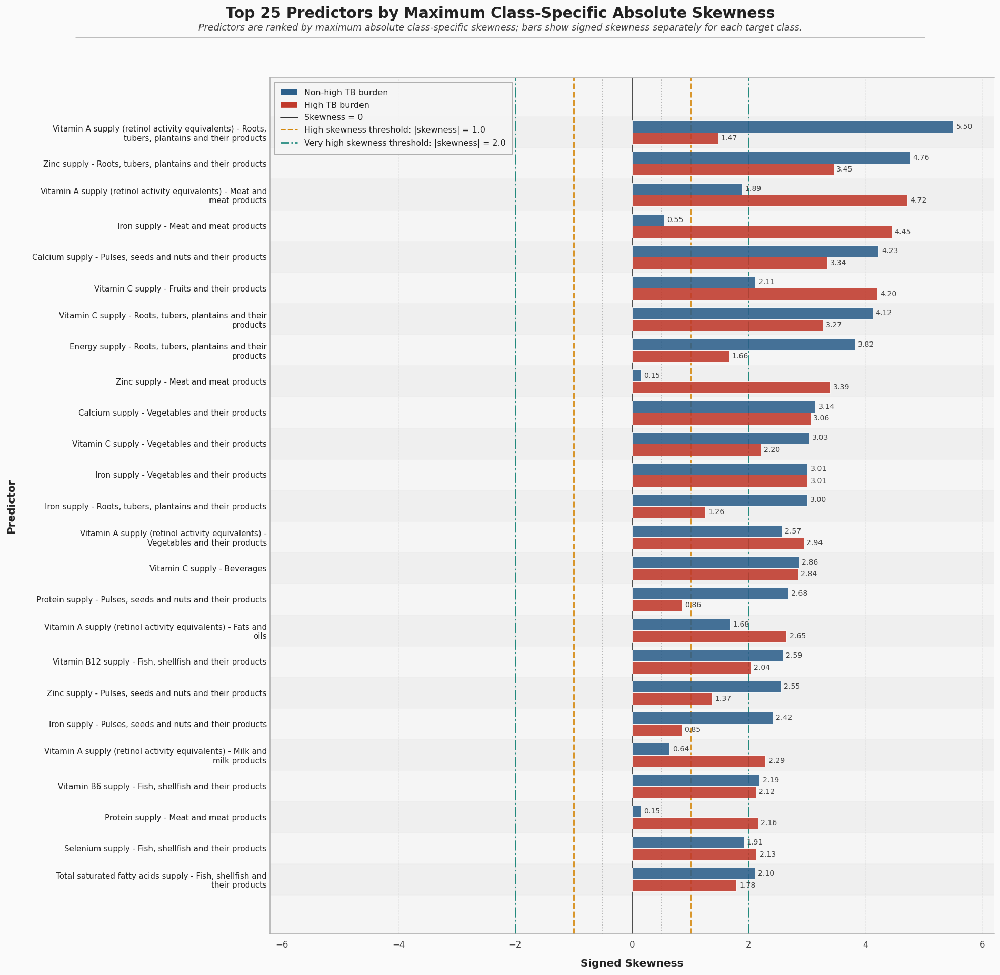

Class-specific skewness plot completed successfully.
Test set used: No
Data modified: No
Feature selection performed in this cell: No

Class-specific skewness figure:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/05a_final_class_specific_skewness_diagnostics.png

Top predictors by class-specific skewness:


,feature,skewness_non_high_tb_burden,skewness_high_tb_burden,maximum_absolute_class_skewness,class_with_larger_absolute_skewness,skewness_category_largest_class_specific,high_class_specific_skewness_flag,very_high_class_specific_skewness_flag,practical_diagnostic_note
0,Vitamin A supply (retinol activity equivalents...,5.504696,1.472790,5.504696,Non-high TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
1,"Zinc supply - Roots, tubers, plantains and the...",4.759359,3.452615,4.759359,Non-high TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
2,Vitamin A supply (retinol activity equivalents...,1.890156,4.715300,4.715300,High TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
22,Iron supply - Meat and meat products,0.551054,4.445660,4.445660,High TB burden,Very high skewness,True,True,Very high class-specific skewness.
3,"Calcium supply - Pulses, seeds and nuts and th...",4.226026,3.343824,4.226026,Non-high TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
4,Vitamin C supply - Fruits and their products,2.113030,4.202559,4.202559,High TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
5,"Vitamin C supply - Roots, tubers, plantains an...",4.121124,3.266483,4.121124,Non-high TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
6,"Energy supply - Roots, tubers, plantains and t...",3.820908,1.663732,3.820908,Non-high TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
7,Zinc supply - Meat and meat products,0.152448,3.392495,3.392495,High TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...
8,Calcium supply - Vegetables and their products,3.140550,3.055628,3.140550,Non-high TB burden,Very high skewness,True,True,Very high class-specific skewness; Notable cla...


In [113]:
# Step 5.0B.1: Final class-specific skewness visualization

# Purpose:
#   To visualize class-specific skewness before Welch's t-test
#   and the Mann–Whitney U test.
#
# Important:
#   - Predictors are ranked by maximum absolute class-specific skewness.
#   - The plot displays signed skewness values.
#   - This preserves both the magnitude and direction of skewness.
#   - Test set is not used.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from matplotlib.lines import Line2D
import textwrap

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_skewness_plot = [
    "class_specific_distribution_diagnostics_summary"
]

missing_objects_for_skewness_plot = [
    object_name
    for object_name in required_objects_for_skewness_plot
    if object_name not in globals()
]

if missing_objects_for_skewness_plot:
    raise NameError(
        "Missing required objects for skewness plot: "
        f"{missing_objects_for_skewness_plot}. "
        "Run the class-specific distribution diagnostics cell first."
    )

if not isinstance(class_specific_distribution_diagnostics_summary, pd.DataFrame):
    raise TypeError(
        "class_specific_distribution_diagnostics_summary must be a pandas DataFrame."
    )

if "FIGURES_DIR" in globals():
    FIGURES_DIR = Path(FIGURES_DIR)
elif "RESULTS_DIR" in globals():
    FIGURES_DIR = Path(RESULTS_DIR) / "figures"
else:
    FIGURES_DIR = Path("results") / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# -------------------------------------------------------------------
# 2. Settings
# -------------------------------------------------------------------

TOP_N_SKEWNESS_PLOT = 25

# Refined palette — deeper, more distinguished hues
CLASS_0_COLOR = "#2C5F8A"   # Non-high TB burden (deep steel blue)
CLASS_1_COLOR = "#C0392B"   # High TB burden (deep crimson)

VERY_HIGH_SKEWNESS_THRESHOLD = 2.0

CLASS_SPECIFIC_SKEWNESS_FIGURE_PATH = (
    FIGURES_DIR / "05a_final_class_specific_skewness_diagnostics.png"
)

# Academic background palette
BG_FIGURE    = "#FAFAFA"   # near-white figure background
BG_AXES      = "#F5F5F5"   # very light grey axes area
GRID_COLOR   = "#DDDDDD"
SPINE_COLOR  = "#AAAAAA"
LABEL_COLOR  = "#222222"
ANNOT_COLOR  = "#444444"


# -------------------------------------------------------------------
# 3. Helper function
# -------------------------------------------------------------------

def wrap_label(text, width=58):
    """
    Wraps long predictor names for readable y-axis labels.
    """
    return "\n".join(textwrap.wrap(str(text), width=width))


# -------------------------------------------------------------------
# 4. Prepare data
# -------------------------------------------------------------------

top_class_specific_skewness_predictors = (
    class_specific_distribution_diagnostics_summary
    .sort_values(
        by="maximum_absolute_class_skewness",
        ascending=False
    )
    .head(TOP_N_SKEWNESS_PLOT)
    .copy()
)

top_class_specific_skewness_predictors["wrapped_feature"] = (
    top_class_specific_skewness_predictors["feature"]
    .apply(lambda value: wrap_label(value, width=58))
)


# -------------------------------------------------------------------
# 5. Create skewness plot
# -------------------------------------------------------------------

# Font settings — clean, academic
plt.rcParams.update({
    "font.family":        "DejaVu Sans",
    "axes.titlesize":     14,
    "axes.labelsize":     12,
    "xtick.labelsize":    10,
    "ytick.labelsize":    9,
    "legend.fontsize":    9.5,
    "figure.facecolor":   BG_FIGURE,
    "axes.facecolor":     BG_AXES,
    "axes.edgecolor":     SPINE_COLOR,
    "text.color":         LABEL_COLOR,
    "xtick.color":        ANNOT_COLOR,
    "ytick.color":        ANNOT_COLOR,
})

number_of_rows = top_class_specific_skewness_predictors.shape[0]
figure_height = max(8, number_of_rows * 0.62)

fig, ax = plt.subplots(figsize=(16, figure_height))
fig.patch.set_facecolor(BG_FIGURE)
ax.set_facecolor(BG_AXES)

y_positions = np.arange(number_of_rows)
bar_height = 0.38

bars_non_high = ax.barh(
    y_positions - bar_height / 2,
    top_class_specific_skewness_predictors[
        "skewness_non_high_tb_burden"
    ],
    height=bar_height,
    color=CLASS_0_COLOR,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.88,
    label="Non-high TB burden",
    zorder=3
)

bars_high = ax.barh(
    y_positions + bar_height / 2,
    top_class_specific_skewness_predictors[
        "skewness_high_tb_burden"
    ],
    height=bar_height,
    color=CLASS_1_COLOR,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.88,
    label="High TB burden",
    zorder=3
)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    top_class_specific_skewness_predictors["wrapped_feature"],
    fontsize=9,
    color=LABEL_COLOR
)

ax.invert_yaxis()

ax.set_ylabel(
    "Predictor",
    fontsize=12,
    labelpad=18,
    color=LABEL_COLOR,
    fontweight="semibold"
)

ax.yaxis.set_label_position("left")
ax.yaxis.tick_left()

ax.set_xlabel(
    "Signed Skewness",
    fontsize=12,
    color=LABEL_COLOR,
    fontweight="semibold",
    labelpad=10
)

# Alternating row shading for readability
for i in range(number_of_rows):
    if i % 2 == 0:
        ax.axhspan(
            i - 0.5, i + 0.5,
            color="#EBEBEB",
            alpha=0.55,
            zorder=0
        )

# Reference lines for skewness thresholds
reference_lines = [
    (0.0,  "#333333", "-",  "Skewness = 0",               1.8),
    (0.5,  "#AAAAAA", ":",  "|skewness| = 0.5",            1.2),
    (-0.5, "#AAAAAA", ":",  "|skewness| = 0.5",            1.2),
    (1.0,  "#D4870A", "--", "|skewness| = 1.0",            1.8),
    (-1.0, "#D4870A", "--", "|skewness| = 1.0",            1.8),
    (2.0,  "#00796B", "-.", "|skewness| = 2.0",            1.8),
    (-2.0, "#00796B", "-.", "|skewness| = 2.0",            1.8)
]

for threshold_value, threshold_color, threshold_style, _, lw in reference_lines:
    ax.axvline(
        x=threshold_value,
        color=threshold_color,
        linestyle=threshold_style,
        linewidth=lw,
        zorder=2,
        alpha=0.85
    )

maximum_absolute_skewness_value = np.nanmax([
    top_class_specific_skewness_predictors[
        "skewness_non_high_tb_burden"
    ].abs().max(),
    top_class_specific_skewness_predictors[
        "skewness_high_tb_burden"
    ].abs().max(),
    VERY_HIGH_SKEWNESS_THRESHOLD
])

ax.set_xlim(
    -maximum_absolute_skewness_value - 0.7,
    maximum_absolute_skewness_value + 0.7
)

# Refined grid
ax.xaxis.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.5,
    color=GRID_COLOR,
    zorder=1
)
ax.yaxis.grid(False)
ax.set_axisbelow(True)

# Spines — all visible except right
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(True)
ax.spines["top"].set_linewidth(0.9)
ax.spines["top"].set_color(SPINE_COLOR)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_linewidth(0.9)
ax.spines["bottom"].set_color(SPINE_COLOR)
ax.spines["left"].set_visible(True)
ax.spines["left"].set_linewidth(0.9)
ax.spines["left"].set_color(SPINE_COLOR)

# Tick styling
ax.tick_params(axis="x", length=4, width=0.8, color=SPINE_COLOR)
ax.tick_params(axis="y", length=0)

# Value labels — tighter offset, slightly bolder
for bars in [bars_non_high, bars_high]:
    for bar in bars:
        value = bar.get_width()

        if pd.notna(value):
            if value >= 0:
                text_x = value + 0.05
                horizontal_alignment = "left"
            else:
                text_x = value - 0.05
                horizontal_alignment = "right"

            ax.text(
                text_x,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.2f}",
                va="center",
                ha=horizontal_alignment,
                fontsize=8.5,
                color=ANNOT_COLOR,
                fontweight="medium"
            )

# Legend — clean box with subtle border
legend_handles = [
    Line2D(
        [0], [0],
        color=CLASS_0_COLOR,
        linewidth=7,
        solid_capstyle="butt",
        label="Non-high TB burden"
    ),
    Line2D(
        [0], [0],
        color=CLASS_1_COLOR,
        linewidth=7,
        solid_capstyle="butt",
        label="High TB burden"
    ),
    Line2D(
        [0], [0],
        color="#333333",
        linestyle="-",
        linewidth=1.5,
        label="Skewness = 0"
    ),
    Line2D(
        [0], [0],
        color="#D4870A",
        linestyle="--",
        linewidth=1.5,
        label="High skewness threshold: |skewness| = 1.0"
    ),
    Line2D(
        [0], [0],
        color="#00796B",
        linestyle="-.",
        linewidth=1.5,
        label="Very high skewness threshold: |skewness| = 2.0"
    )
]

legend = ax.legend(
    handles=legend_handles,
    loc="upper left",
    fontsize=9.5,
    frameon=True,
    framealpha=0.92,
    edgecolor=SPINE_COLOR,
    fancybox=False,
    borderpad=0.8,
    labelspacing=0.55
)
legend.get_frame().set_linewidth(0.8)

# Title block — two-level hierarchy
fig.suptitle(
    (
        f"Top {TOP_N_SKEWNESS_PLOT} Predictors by Maximum "
        "Class-Specific Absolute Skewness"
    ),
    fontsize=17,
    fontweight="bold",
    color=LABEL_COLOR,
    y=0.995
)

fig.text(
    0.5,
    0.970,
    (
        "Predictors are ranked by maximum absolute class-specific skewness; "
        "bars show signed skewness separately for each target class."
    ),
    ha="center",
    fontsize=10.5,
    color=ANNOT_COLOR,
    style="italic"
)

# Thin decorative separator line beneath subtitle
fig.add_artist(
    plt.Line2D(
        [0.08, 0.92], [0.963, 0.963],
        transform=fig.transFigure,
        color=SPINE_COLOR,
        linewidth=0.9
    )
)

plt.tight_layout(rect=[0, 0, 1, 0.960])

plt.savefig(
    CLASS_SPECIFIC_SKEWNESS_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor=BG_FIGURE
)

plt.show()
plt.close(fig)


# -------------------------------------------------------------------
# 6. Display table
# -------------------------------------------------------------------

print("Class-specific skewness plot completed successfully.")
print("Test set used: No")
print("Data modified: No")
print("Feature selection performed in this cell: No")
print()

print("Class-specific skewness figure:")
print(CLASS_SPECIFIC_SKEWNESS_FIGURE_PATH)
print()

print("Top predictors by class-specific skewness:")
display(
    top_class_specific_skewness_predictors[
        [
            "feature",
            "skewness_non_high_tb_burden",
            "skewness_high_tb_burden",
            "maximum_absolute_class_skewness",
            "class_with_larger_absolute_skewness",
            "skewness_category_largest_class_specific",
            "high_class_specific_skewness_flag",
            "very_high_class_specific_skewness_flag",
            "practical_diagnostic_note"
        ]
    ]
)


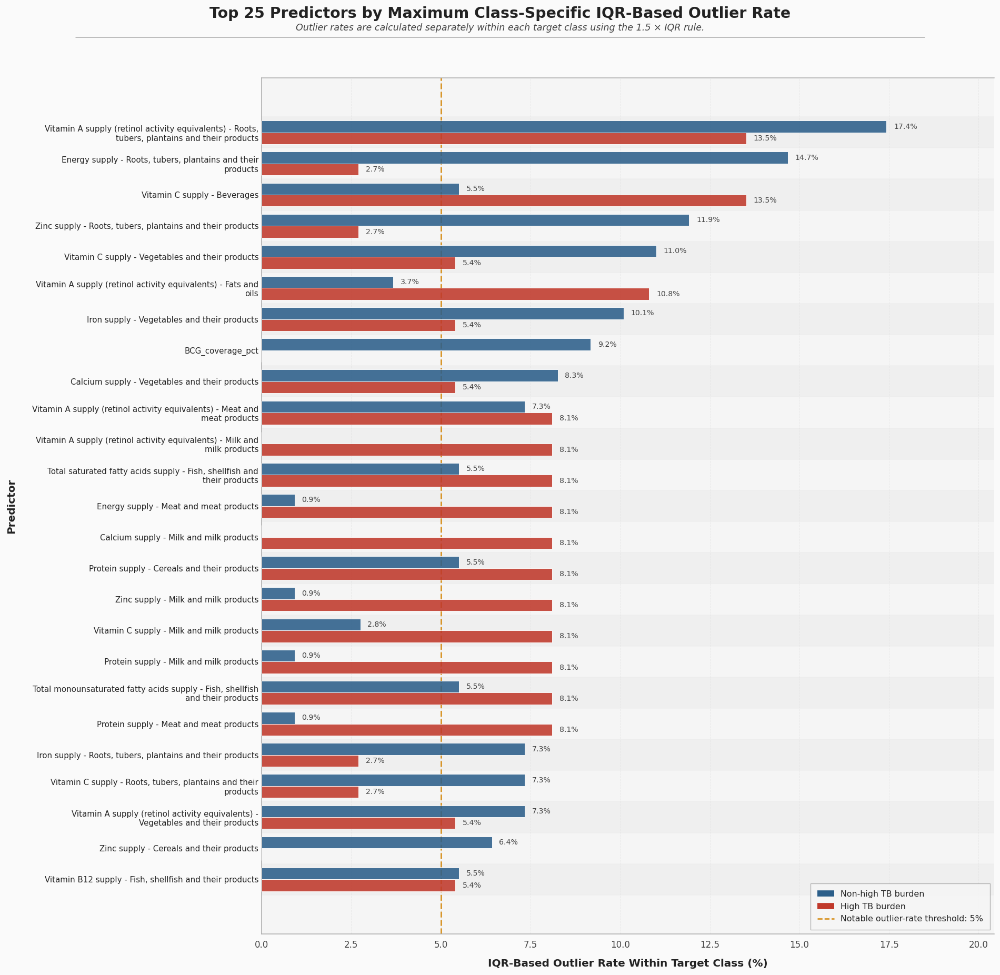

Class-specific outlier-rate plot completed successfully.
Test set used: No
Data modified: No
Feature selection performed in this cell: No

Class-specific outlier-rate figure:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/05a_final_class_specific_outlier_rate_diagnostics.png

Top predictors by class-specific outlier rate:


,feature,outlier_rate_percent_non_high_tb_burden,outlier_rate_percent_high_tb_burden,maximum_class_outlier_rate_percent,class_with_larger_outlier_rate,notable_class_specific_outlier_flag,practical_diagnostic_note
0,Vitamin A supply (retinol activity equivalents...,17.431193,13.513514,17.431193,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
6,"Energy supply - Roots, tubers, plantains and t...",14.678899,2.702703,14.678899,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
13,Vitamin C supply - Beverages,5.504587,13.513514,13.513514,High TB burden,True,Very high class-specific skewness; Notable cla...
1,"Zinc supply - Roots, tubers, plantains and the...",11.926606,2.702703,11.926606,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
9,Vitamin C supply - Vegetables and their products,11.009174,5.405405,11.009174,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
15,Vitamin A supply (retinol activity equivalents...,3.669725,10.810811,10.810811,High TB burden,True,Very high class-specific skewness; Notable cla...
10,Iron supply - Vegetables and their products,10.091743,5.405405,10.091743,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
27,BCG_coverage_pct,9.174312,0.000000,9.174312,Non-high TB burden,True,High class-specific skewness; Notable class-sp...
8,Calcium supply - Vegetables and their products,8.256881,5.405405,8.256881,Non-high TB burden,True,Very high class-specific skewness; Notable cla...
2,Vitamin A supply (retinol activity equivalents...,7.339450,8.108108,8.108108,High TB burden,True,Very high class-specific skewness; Notable cla...


In [114]:
# Step 5.0B.2: Final class-specific outlier-rate visualization

# Purpose:
#   To visualize class-specific IQR-based outlier rates before Welch's t-test
#   and the Mann–Whitney U test.
#
# Important:
#   - Outlier rates are calculated separately within each target class.
#   - Predictors are ranked by maximum class-specific outlier rate.
#   - Test set is not used.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap
from matplotlib.lines import Line2D

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_outlier_plot = [
    "class_specific_distribution_diagnostics_summary"
]

missing_objects_for_outlier_plot = [
    object_name
    for object_name in required_objects_for_outlier_plot
    if object_name not in globals()
]

if missing_objects_for_outlier_plot:
    raise NameError(
        "Missing required objects for outlier-rate plot: "
        f"{missing_objects_for_outlier_plot}. "
        "Run the class-specific distribution diagnostics cell first."
    )

if not isinstance(class_specific_distribution_diagnostics_summary, pd.DataFrame):
    raise TypeError(
        "class_specific_distribution_diagnostics_summary must be a pandas DataFrame."
    )

if "FIGURES_DIR" in globals():
    FIGURES_DIR = Path(FIGURES_DIR)
elif "RESULTS_DIR" in globals():
    FIGURES_DIR = Path(RESULTS_DIR) / "figures"
else:
    FIGURES_DIR = Path("results") / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# -------------------------------------------------------------------
# 2. Settings
# -------------------------------------------------------------------

TOP_N_OUTLIER_PLOT = 25

CLASS_0_COLOR = "#2C5F8A"   # Non-high TB burden (deep steel blue)
CLASS_1_COLOR = "#C0392B"   # High TB burden (deep crimson)

NOTABLE_OUTLIER_RATE_THRESHOLD_PERCENT = 5.0

CLASS_SPECIFIC_OUTLIER_FIGURE_PATH = (
    FIGURES_DIR / "05a_final_class_specific_outlier_rate_diagnostics.png"
)

# Academic background palette
BG_FIGURE   = "#FAFAFA"
BG_AXES     = "#F5F5F5"
GRID_COLOR  = "#DDDDDD"
SPINE_COLOR = "#AAAAAA"
LABEL_COLOR = "#222222"
ANNOT_COLOR = "#444444"


# -------------------------------------------------------------------
# 3. Helper function
# -------------------------------------------------------------------

def wrap_label(text, width=58):
    """
    Wraps long predictor names for readable y-axis labels.
    """
    return "\n".join(textwrap.wrap(str(text), width=width))


# -------------------------------------------------------------------
# 4. Prepare data
# -------------------------------------------------------------------

top_class_specific_outlier_predictors = (
    class_specific_distribution_diagnostics_summary
    .sort_values(
        by="maximum_class_outlier_rate_percent",
        ascending=False
    )
    .head(TOP_N_OUTLIER_PLOT)
    .copy()
)

top_class_specific_outlier_predictors["wrapped_feature"] = (
    top_class_specific_outlier_predictors["feature"]
    .apply(lambda value: wrap_label(value, width=58))
)


# -------------------------------------------------------------------
# 5. Create outlier-rate plot
# -------------------------------------------------------------------

plt.rcParams.update({
    "font.family":      "DejaVu Sans",
    "axes.titlesize":   14,
    "axes.labelsize":   12,
    "xtick.labelsize":  10,
    "ytick.labelsize":  9,
    "legend.fontsize":  9.5,
    "figure.facecolor": BG_FIGURE,
    "axes.facecolor":   BG_AXES,
    "axes.edgecolor":   SPINE_COLOR,
    "text.color":       LABEL_COLOR,
    "xtick.color":      ANNOT_COLOR,
    "ytick.color":      ANNOT_COLOR,
})

number_of_rows = top_class_specific_outlier_predictors.shape[0]
figure_height = max(8, number_of_rows * 0.62)

fig, ax = plt.subplots(figsize=(16, figure_height))
fig.patch.set_facecolor(BG_FIGURE)
ax.set_facecolor(BG_AXES)

y_positions = np.arange(number_of_rows)
bar_height = 0.38

bars_non_high = ax.barh(
    y_positions - bar_height / 2,
    top_class_specific_outlier_predictors[
        "outlier_rate_percent_non_high_tb_burden"
    ],
    height=bar_height,
    color=CLASS_0_COLOR,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.88,
    label="Non-high TB burden",
    zorder=3
)

bars_high = ax.barh(
    y_positions + bar_height / 2,
    top_class_specific_outlier_predictors[
        "outlier_rate_percent_high_tb_burden"
    ],
    height=bar_height,
    color=CLASS_1_COLOR,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.88,
    label="High TB burden",
    zorder=3
)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    top_class_specific_outlier_predictors["wrapped_feature"],
    fontsize=9,
    color=LABEL_COLOR
)

ax.invert_yaxis()

ax.set_ylabel(
    "Predictor",
    fontsize=12,
    labelpad=18,
    color=LABEL_COLOR,
    fontweight="semibold"
)

ax.yaxis.set_label_position("left")
ax.yaxis.tick_left()

ax.set_xlabel(
    "IQR-Based Outlier Rate Within Target Class (%)",
    fontsize=12,
    color=LABEL_COLOR,
    fontweight="semibold",
    labelpad=10
)

# Alternating row shading
for i in range(number_of_rows):
    if i % 2 == 0:
        ax.axhspan(
            i - 0.5, i + 0.5,
            color="#EBEBEB",
            alpha=0.55,
            zorder=0
        )

# Notable outlier threshold line
ax.axvline(
    x=NOTABLE_OUTLIER_RATE_THRESHOLD_PERCENT,
    color="#D4870A",
    linestyle="--",
    linewidth=1.8,
    zorder=2,
    alpha=0.85
)

maximum_outlier_value = np.nanmax([
    top_class_specific_outlier_predictors[
        "outlier_rate_percent_non_high_tb_burden"
    ].max(),
    top_class_specific_outlier_predictors[
        "outlier_rate_percent_high_tb_burden"
    ].max(),
    NOTABLE_OUTLIER_RATE_THRESHOLD_PERCENT
])

ax.set_xlim(0, maximum_outlier_value + 3)

# Refined grid
ax.xaxis.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.5,
    color=GRID_COLOR,
    zorder=1
)
ax.yaxis.grid(False)
ax.set_axisbelow(True)

# Spines
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(True)
ax.spines["top"].set_linewidth(0.9)
ax.spines["top"].set_color(SPINE_COLOR)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_linewidth(0.9)
ax.spines["bottom"].set_color(SPINE_COLOR)
ax.spines["left"].set_visible(True)
ax.spines["left"].set_linewidth(0.9)
ax.spines["left"].set_color(SPINE_COLOR)

# Tick styling
ax.tick_params(axis="x", length=4, width=0.8, color=SPINE_COLOR)
ax.tick_params(axis="y", length=0)

# Value labels
for bars in [bars_non_high, bars_high]:
    for bar in bars:
        value = bar.get_width()

        if pd.notna(value) and value > 0:
            ax.text(
                value + 0.20,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                va="center",
                ha="left",
                fontsize=8.5,
                color=ANNOT_COLOR,
                fontweight="medium"
            )

# Legend
legend_handles = [
    Line2D(
        [0], [0],
        color=CLASS_0_COLOR,
        linewidth=7,
        solid_capstyle="butt",
        label="Non-high TB burden"
    ),
    Line2D(
        [0], [0],
        color=CLASS_1_COLOR,
        linewidth=7,
        solid_capstyle="butt",
        label="High TB burden"
    ),
    Line2D(
        [0], [0],
        color="#D4870A",
        linestyle="--",
        linewidth=1.5,
        label="Notable outlier-rate threshold: 5%"
    )
]

legend = ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=9.5,
    frameon=True,
    framealpha=0.92,
    edgecolor=SPINE_COLOR,
    fancybox=False,
    borderpad=0.8,
    labelspacing=0.55
)
legend.get_frame().set_linewidth(0.8)

# Title block
fig.suptitle(
    (
        f"Top {TOP_N_OUTLIER_PLOT} Predictors by Maximum "
        "Class-Specific IQR-Based Outlier Rate"
    ),
    fontsize=17,
    fontweight="bold",
    color=LABEL_COLOR,
    y=0.995
)

fig.text(
    0.5,
    0.970,
    (
        "Outlier rates are calculated separately within each target class "
        "using the 1.5 × IQR rule."
    ),
    ha="center",
    fontsize=10.5,
    color=ANNOT_COLOR,
    style="italic"
)

# Thin decorative separator line beneath subtitle
fig.add_artist(
    plt.Line2D(
        [0.08, 0.92], [0.963, 0.963],
        transform=fig.transFigure,
        color=SPINE_COLOR,
        linewidth=0.9
    )
)

plt.tight_layout(rect=[0, 0, 1, 0.960])

plt.savefig(
    CLASS_SPECIFIC_OUTLIER_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor=BG_FIGURE
)

plt.show()
plt.close(fig)


# -------------------------------------------------------------------
# 6. Display table
# -------------------------------------------------------------------

print("Class-specific outlier-rate plot completed successfully.")
print("Test set used: No")
print("Data modified: No")
print("Feature selection performed in this cell: No")
print()

print("Class-specific outlier-rate figure:")
print(CLASS_SPECIFIC_OUTLIER_FIGURE_PATH)
print()

print("Top predictors by class-specific outlier rate:")
display(
    top_class_specific_outlier_predictors[
        [
            "feature",
            "outlier_rate_percent_non_high_tb_burden",
            "outlier_rate_percent_high_tb_burden",
            "maximum_class_outlier_rate_percent",
            "class_with_larger_outlier_rate",
            "notable_class_specific_outlier_flag",
            "practical_diagnostic_note"
        ]
    ]
)


In [108]:
# Step 5A: Training-only Welch's t-test with standardized effect sizes for predictor screening

# Welch's t-test compares the mean value of each numeric predictor between:
#   1) Non-high TB burden countries
#   2) High TB burden countries
#
# This cell combines:
# - Welch's t-test for statistical evidence of mean differences.
# - Benjamini-Hochberg FDR correction for multiple testing.
# - Cohen's d and Hedges' g for standardized effect size.
# - Approximate 95% confidence intervals for both:
#     1) raw mean difference
#     2) Hedges' g
#
# Important:
# - This is performed only on the training set.
# - The test set remains untouched until final model evaluation.
# - Welch's t-test provides p-values.
# - Hedges' g provides practical effect size information.
# - Hedges' g is NOT a separate statistical test.

import numpy as np
import pandas as pd

from scipy import stats
from statsmodels.stats.multitest import multipletests

FDR_ALPHA = 0.05

EFFECT_SIZE_SMALL = 0.20
EFFECT_SIZE_MEDIUM = 0.50
EFFECT_SIZE_LARGE = 0.80

TOP_N_WELCH_DISPLAY = 15

required_welch_objects = [
    "X_screening_train",
    "y_screening_train",
    "screening_predictor_cols",
    "target_column",
    "TABLES_DIR"
]

missing_welch_objects = [
    object_name for object_name in required_welch_objects
    if object_name not in globals()
]

if missing_welch_objects:
    raise NameError(
        "Missing required objects for Welch's t-test. "
        "Run the training-only statistical screening input cell first. "
        f"Missing objects: {missing_welch_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(X_screening_train, pd.DataFrame):
    raise TypeError(
        "X_screening_train must be a pandas DataFrame."
    )

if not isinstance(y_screening_train, pd.Series):
    raise TypeError(
        "y_screening_train must be a pandas Series."
    )

if not isinstance(screening_predictor_cols, list):
    raise TypeError(
        "screening_predictor_cols must be a list."
    )

if X_screening_train.shape[0] != y_screening_train.shape[0]:
    raise ValueError(
        "The number of rows in X_screening_train and y_screening_train does not match."
    )

if not X_screening_train.index.equals(y_screening_train.index):
    raise ValueError(
        "The index of X_screening_train and y_screening_train does not match."
    )

if sorted(y_screening_train.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_screening_train must contain binary values [0, 1]."
    )

missing_welch_predictors = [
    feature for feature in screening_predictor_cols
    if feature not in X_screening_train.columns
]

if missing_welch_predictors:
    raise KeyError(
        "The following predictors are missing from X_screening_train: "
        f"{missing_welch_predictors}"
    )

# Safety check:
# The target column and known leakage-related columns must not be used
# as predictors in the training-only Welch's t-test screening.
if target_column in screening_predictor_cols:
    raise ValueError(
        f"Target column '{target_column}' was found in screening_predictor_cols. "
        "The target must not be used as a predictor in Welch's t-test screening."
    )

known_leakage_columns = [
    target_column,
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group",
    "BCG_was_missing"
]

leakage_columns_in_screening = [
    column
    for column in sorted(set(known_leakage_columns))
    if column in screening_predictor_cols
]

if leakage_columns_in_screening:
    raise ValueError(
        "Potential leakage columns were found in screening_predictor_cols: "
        f"{leakage_columns_in_screening}. "
        "These columns must be excluded from statistical screening."
    )

print("Leakage safety check passed for Welch's t-test screening.")

non_numeric_welch_predictors = [
    feature for feature in screening_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_screening_train[feature])
]

if non_numeric_welch_predictors:
    raise TypeError(
        "All predictors used for Welch's t-test must be numeric. "
        f"Non-numeric predictors found: {non_numeric_welch_predictors}"
    )


def classify_effect_size(abs_effect_size):
    if pd.isna(abs_effect_size):
        return "Not available"

    if abs_effect_size < EFFECT_SIZE_SMALL:
        return "Negligible"

    if abs_effect_size < EFFECT_SIZE_MEDIUM:
        return "Small"

    if abs_effect_size < EFFECT_SIZE_LARGE:
        return "Medium"

    return "Large"


welch_test_records = []

for feature in screening_predictor_cols:
    non_high_values = (
        X_screening_train
        .loc[y_screening_train == 0, feature]
        .dropna()
        .astype(float)
    )

    high_values = (
        X_screening_train
        .loc[y_screening_train == 1, feature]
        .dropna()
        .astype(float)
    )

    non_high_n = len(non_high_values)
    high_n = len(high_values)

    if non_high_n < 2 or high_n < 2:
        raise ValueError(
            f"Feature '{feature}' does not have at least two observations "
            "in each class for Welch's t-test."
        )

    if (
        not np.isfinite(non_high_values).all()
        or not np.isfinite(high_values).all()
    ):
        raise ValueError(
            f"Feature '{feature}' contains non-finite values after missing values were removed."
        )

    non_high_mean = non_high_values.mean()
    high_mean = high_values.mean()

    non_high_median = non_high_values.median()
    high_median = high_values.median()

    non_high_std = non_high_values.std(ddof=1)
    high_std = high_values.std(ddof=1)

    non_high_iqr = (
        non_high_values.quantile(0.75)
        - non_high_values.quantile(0.25)
    )

    high_iqr = (
        high_values.quantile(0.75)
        - high_values.quantile(0.25)
    )

    mean_difference = high_mean - non_high_mean

    welch_t_statistic, welch_p_value = stats.ttest_ind(
        high_values,
        non_high_values,
        equal_var=False,
        nan_policy="raise"
    )

    high_standard_error_component = (high_std ** 2) / high_n
    non_high_standard_error_component = (non_high_std ** 2) / non_high_n

    mean_difference_standard_error = np.sqrt(
        high_standard_error_component
        + non_high_standard_error_component
    )

    welch_denominator = (
        (high_standard_error_component ** 2) / (high_n - 1)
        + (non_high_standard_error_component ** 2) / (non_high_n - 1)
    )

    if (
        mean_difference_standard_error > 0
        and np.isfinite(mean_difference_standard_error)
        and welch_denominator > 0
        and np.isfinite(welch_denominator)
    ):
        welch_degrees_of_freedom = (
            (
                high_standard_error_component
                + non_high_standard_error_component
            ) ** 2
            / welch_denominator
        )

        confidence_interval_critical_value = stats.t.ppf(
            0.975,
            df=welch_degrees_of_freedom
        )

        mean_difference_95_ci_lower = (
            mean_difference
            - confidence_interval_critical_value * mean_difference_standard_error
        )

        mean_difference_95_ci_upper = (
            mean_difference
            + confidence_interval_critical_value * mean_difference_standard_error
        )

        mean_difference_95_ci_includes_zero = (
            mean_difference_95_ci_lower <= 0 <= mean_difference_95_ci_upper
        )
    else:
        welch_degrees_of_freedom = np.nan
        mean_difference_95_ci_lower = np.nan
        mean_difference_95_ci_upper = np.nan
        mean_difference_95_ci_includes_zero = np.nan

    smd_pooled_standard_deviation = np.sqrt(
        (
            ((non_high_n - 1) * (non_high_std ** 2))
            + ((high_n - 1) * (high_std ** 2))
        )
        / (non_high_n + high_n - 2)
    )

    if (
        smd_pooled_standard_deviation > 0
        and np.isfinite(smd_pooled_standard_deviation)
    ):
        cohens_d = mean_difference / smd_pooled_standard_deviation

        hedges_correction = (
            1
            - (3 / (4 * (non_high_n + high_n) - 9))
        )

        hedges_g = cohens_d * hedges_correction

        # Approximate standard error and 95% confidence interval for Hedges' g.
        # This is effect-size uncertainty information, not a separate significance test.
        cohens_d_variance = (
            (non_high_n + high_n) / (non_high_n * high_n)
            + (cohens_d ** 2) / (2 * (non_high_n + high_n - 2))
        )

        hedges_g_standard_error = np.sqrt(
            (hedges_correction ** 2) * cohens_d_variance
        )

        hedges_g_95_ci_lower = (
            hedges_g
            - 1.96 * hedges_g_standard_error
        )

        hedges_g_95_ci_upper = (
            hedges_g
            + 1.96 * hedges_g_standard_error
        )

        hedges_g_95_ci_includes_zero = (
            hedges_g_95_ci_lower <= 0 <= hedges_g_95_ci_upper
        )
    else:
        cohens_d = np.nan
        hedges_g = np.nan
        hedges_g_standard_error = np.nan
        hedges_g_95_ci_lower = np.nan
        hedges_g_95_ci_upper = np.nan
        hedges_g_95_ci_includes_zero = np.nan

    absolute_hedges_g = (
        abs(hedges_g)
        if pd.notna(hedges_g)
        else np.nan
    )

    if pd.isna(mean_difference):
        mean_difference_direction = "Not available"
    elif mean_difference > 0:
        mean_difference_direction = "Higher mean in high TB burden"
    elif mean_difference < 0:
        mean_difference_direction = "Lower mean in high TB burden"
    else:
        mean_difference_direction = "No mean difference"

    welch_test_records.append({
        "feature": feature,

        "non_high_n": non_high_n,
        "high_n": high_n,

        "non_high_mean": non_high_mean,
        "high_mean": high_mean,
        "mean_difference_high_minus_non_high": mean_difference,
        "mean_difference_standard_error": mean_difference_standard_error,
        "mean_difference_95_ci_lower": mean_difference_95_ci_lower,
        "mean_difference_95_ci_upper": mean_difference_95_ci_upper,
        "mean_difference_95_ci_includes_zero": mean_difference_95_ci_includes_zero,

        "non_high_std": non_high_std,
        "high_std": high_std,
        "non_high_median": non_high_median,
        "high_median": high_median,
        "non_high_iqr": non_high_iqr,
        "high_iqr": high_iqr,

        "welch_t_statistic": welch_t_statistic,
        "welch_degrees_of_freedom": welch_degrees_of_freedom,
        "welch_p_value_unadjusted": welch_p_value,

        "smd_pooled_standard_deviation": smd_pooled_standard_deviation,
        "cohens_d_high_minus_non_high": cohens_d,
        "hedges_g_high_minus_non_high": hedges_g,
        "hedges_g_standard_error": hedges_g_standard_error,
        "hedges_g_95_ci_lower": hedges_g_95_ci_lower,
        "hedges_g_95_ci_upper": hedges_g_95_ci_upper,
        "hedges_g_95_ci_includes_zero": hedges_g_95_ci_includes_zero,
        "absolute_hedges_g": absolute_hedges_g,

        "mean_difference_direction": mean_difference_direction,
        "direction": mean_difference_direction
    })

welch_screening_results = pd.DataFrame(welch_test_records)

valid_welch_p_value_mask = (
    welch_screening_results["welch_p_value_unadjusted"].notna()
    & np.isfinite(welch_screening_results["welch_p_value_unadjusted"])
)

welch_screening_results["welch_p_value_fdr_bh"] = np.nan

welch_screening_results.loc[
    valid_welch_p_value_mask,
    "welch_p_value_fdr_bh"
] = multipletests(
    welch_screening_results.loc[
        valid_welch_p_value_mask,
        "welch_p_value_unadjusted"
    ],
    alpha=FDR_ALPHA,
    method="fdr_bh"
)[1]

welch_screening_results["significant_after_fdr_0_05"] = (
    welch_screening_results["welch_p_value_fdr_bh"] < FDR_ALPHA
)

welch_screening_results["effect_size_magnitude"] = (
    welch_screening_results["absolute_hedges_g"]
    .apply(classify_effect_size)
)

welch_screening_results = (
    welch_screening_results
    .sort_values(
        by=[
            "welch_p_value_fdr_bh",
            "absolute_hedges_g"
        ],
        ascending=[
            True,
            False
        ],
        na_position="last"
    )
    .reset_index(drop=True)
)

welch_screening_results.insert(
    0,
    "rank_by_welch_fdr",
    range(1, len(welch_screening_results) + 1)
)

welch_absolute_hedges_g_ranking = (
    welch_screening_results
    .sort_values(
        by="absolute_hedges_g",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
    .copy()
)

welch_absolute_hedges_g_ranking.insert(
    0,
    "rank_by_absolute_hedges_g",
    range(1, len(welch_absolute_hedges_g_ranking) + 1)
)

significant_welch_predictors = (
    welch_screening_results[
        welch_screening_results["significant_after_fdr_0_05"]
    ]
    .copy()
)

welch_medium_or_large_effect_predictors = (
    welch_absolute_hedges_g_ranking[
        welch_absolute_hedges_g_ranking["absolute_hedges_g"]
        >= EFFECT_SIZE_MEDIUM
    ]
    .copy()
)

welch_large_effect_predictors = (
    welch_absolute_hedges_g_ranking[
        welch_absolute_hedges_g_ranking["absolute_hedges_g"]
        >= EFFECT_SIZE_LARGE
    ]
    .copy()
)

number_of_fdr_significant_predictors = len(significant_welch_predictors)

effect_size_order = [
    "Negligible",
    "Small",
    "Medium",
    "Large",
    "Not available"
]

welch_effect_size_magnitude_summary = (
    welch_screening_results["effect_size_magnitude"]
    .value_counts()
    .reindex(effect_size_order, fill_value=0)
    .rename_axis("effect_size_magnitude")
    .reset_index(name="number_of_predictors")
)

welch_summary = pd.DataFrame({
    "item": [
        "Predictors tested",
        "FDR alpha",
        "FDR-significant predictors",
        "Predictors with medium or large Hedges g",
        "Predictors with large Hedges g",
        "Largest absolute Hedges g",
        "Small effect threshold",
        "Medium effect threshold",
        "Large effect threshold"
    ],
    "value": [
        len(welch_screening_results),
        FDR_ALPHA,
        number_of_fdr_significant_predictors,
        len(welch_medium_or_large_effect_predictors),
        len(welch_large_effect_predictors),
        round(welch_screening_results["absolute_hedges_g"].max(), 4),
        EFFECT_SIZE_SMALL,
        EFFECT_SIZE_MEDIUM,
        EFFECT_SIZE_LARGE
    ]
})

welch_screening_results_csv_path = (
    TABLES_DIR / "13_welch_t_test_training_only_results.csv"
)

welch_screening_results_excel_path = (
    TABLES_DIR / "13_welch_t_test_training_only_results.xlsx"
)

welch_absolute_hedges_g_ranking_csv_path = (
    TABLES_DIR / "13_welch_t_test_training_only_absolute_hedges_g_ranking.csv"
)

welch_absolute_hedges_g_ranking_excel_path = (
    TABLES_DIR / "13_welch_t_test_training_only_absolute_hedges_g_ranking.xlsx"
)

welch_summary_csv_path = (
    TABLES_DIR / "13_welch_t_test_training_only_summary.csv"
)

welch_summary_excel_path = (
    TABLES_DIR / "13_welch_t_test_training_only_summary.xlsx"
)

welch_effect_size_magnitude_summary_csv_path = (
    TABLES_DIR / "13_welch_t_test_training_only_effect_size_magnitude_summary.csv"
)

welch_effect_size_magnitude_summary_excel_path = (
    TABLES_DIR / "13_welch_t_test_training_only_effect_size_magnitude_summary.xlsx"
)

significant_welch_predictors_csv_path = (
    TABLES_DIR / "13_welch_t_test_training_only_significant_predictors.csv"
)

significant_welch_predictors_excel_path = (
    TABLES_DIR / "13_welch_t_test_training_only_significant_predictors.xlsx"
)

welch_medium_or_large_effect_predictors_csv_path = (
    TABLES_DIR / "13_welch_t_test_training_only_medium_or_large_hedges_g_predictors.csv"
)

welch_medium_or_large_effect_predictors_excel_path = (
    TABLES_DIR / "13_welch_t_test_training_only_medium_or_large_hedges_g_predictors.xlsx"
)

welch_large_effect_predictors_csv_path = (
    TABLES_DIR / "13_welch_t_test_training_only_large_hedges_g_predictors.csv"
)

welch_large_effect_predictors_excel_path = (
    TABLES_DIR / "13_welch_t_test_training_only_large_hedges_g_predictors.xlsx"
)

welch_screening_results.to_csv(
    welch_screening_results_csv_path,
    index=False
)

welch_screening_results.to_excel(
    welch_screening_results_excel_path,
    index=False
)

welch_absolute_hedges_g_ranking.to_csv(
    welch_absolute_hedges_g_ranking_csv_path,
    index=False
)

welch_absolute_hedges_g_ranking.to_excel(
    welch_absolute_hedges_g_ranking_excel_path,
    index=False
)

welch_summary.to_csv(
    welch_summary_csv_path,
    index=False
)

welch_summary.to_excel(
    welch_summary_excel_path,
    index=False
)

welch_effect_size_magnitude_summary.to_csv(
    welch_effect_size_magnitude_summary_csv_path,
    index=False
)

welch_effect_size_magnitude_summary.to_excel(
    welch_effect_size_magnitude_summary_excel_path,
    index=False
)

significant_welch_predictors.to_csv(
    significant_welch_predictors_csv_path,
    index=False
)

significant_welch_predictors.to_excel(
    significant_welch_predictors_excel_path,
    index=False
)

welch_medium_or_large_effect_predictors.to_csv(
    welch_medium_or_large_effect_predictors_csv_path,
    index=False
)

welch_medium_or_large_effect_predictors.to_excel(
    welch_medium_or_large_effect_predictors_excel_path,
    index=False
)

welch_large_effect_predictors.to_csv(
    welch_large_effect_predictors_csv_path,
    index=False
)

welch_large_effect_predictors.to_excel(
    welch_large_effect_predictors_excel_path,
    index=False
)

welch_screening_results_display = welch_screening_results.copy()
significant_welch_predictors_display = significant_welch_predictors.copy()
welch_absolute_hedges_g_ranking_display = welch_absolute_hedges_g_ranking.copy()
welch_medium_or_large_effect_predictors_display = (
    welch_medium_or_large_effect_predictors.copy()
)
welch_large_effect_predictors_display = (
    welch_large_effect_predictors.copy()
)

columns_to_round_for_display = [
    "non_high_mean",
    "high_mean",
    "mean_difference_high_minus_non_high",
    "mean_difference_standard_error",
    "mean_difference_95_ci_lower",
    "mean_difference_95_ci_upper",
    "non_high_std",
    "high_std",
    "non_high_median",
    "high_median",
    "non_high_iqr",
    "high_iqr",
    "welch_t_statistic",
    "welch_degrees_of_freedom",
    "smd_pooled_standard_deviation",
    "cohens_d_high_minus_non_high",
    "hedges_g_high_minus_non_high",
    "hedges_g_standard_error",
    "hedges_g_95_ci_lower",
    "hedges_g_95_ci_upper",
    "absolute_hedges_g"
]

display_tables = [
    welch_screening_results_display,
    significant_welch_predictors_display,
    welch_absolute_hedges_g_ranking_display,
    welch_medium_or_large_effect_predictors_display,
    welch_large_effect_predictors_display
]

for display_table in display_tables:
    if not display_table.empty:
        display_table[columns_to_round_for_display] = (
            display_table[columns_to_round_for_display]
            .round(4)
        )

        display_table["welch_p_value_unadjusted"] = (
            display_table["welch_p_value_unadjusted"]
            .map(lambda value: f"{value:.3e}" if pd.notna(value) else "NA")
        )

        display_table["welch_p_value_fdr_bh"] = (
            display_table["welch_p_value_fdr_bh"]
            .map(lambda value: f"{value:.3e}" if pd.notna(value) else "NA")
        )

display(
    welch_screening_results_display
    .head(TOP_N_WELCH_DISPLAY)
)

display(welch_summary)

display(welch_effect_size_magnitude_summary)

print("All FDR-significant predictors after Welch's t-test:")

if significant_welch_predictors_display.empty:
    print("No predictors were significant after Benjamini-Hochberg FDR correction.")
else:
    display(significant_welch_predictors_display)

    significant_feature_names = (
        significant_welch_predictors["feature"]
        .tolist()
    )

    print("Significant predictor names:")
    for index, feature_name in enumerate(significant_feature_names, start=1):
        print(f"{index}. {feature_name}")

print("Predictors with medium or large Hedges' g:")

if welch_medium_or_large_effect_predictors_display.empty:
    print("No predictors had medium or large Hedges' g values.")
else:
    display(welch_medium_or_large_effect_predictors_display)

    medium_or_large_feature_names = (
        welch_medium_or_large_effect_predictors["feature"]
        .tolist()
    )

    print("Medium or large Hedges' g predictor names:")
    for index, feature_name in enumerate(
        medium_or_large_feature_names,
        start=1
    ):
        print(f"{index}. {feature_name}")

print("Predictors with large Hedges' g:")

if welch_large_effect_predictors_display.empty:
    print("No predictors had large Hedges' g values.")
else:
    display(welch_large_effect_predictors_display)

    large_effect_feature_names = (
        welch_large_effect_predictors["feature"]
        .tolist()
    )

    print("Large Hedges' g predictor names:")
    for index, feature_name in enumerate(
        large_effect_feature_names,
        start=1
    ):
        print(f"{index}. {feature_name}")

print("Welch's t-test with standardized effect sizes completed successfully.")
print("Predictors tested:", len(welch_screening_results))
print("FDR alpha:", FDR_ALPHA)
print("FDR-significant predictors:", number_of_fdr_significant_predictors)
print(
    "Predictors with medium or large Hedges' g:",
    len(welch_medium_or_large_effect_predictors)
)
print(
    "Predictors with large Hedges' g:",
    len(welch_large_effect_predictors)
)
print("Results saved as CSV:", welch_screening_results_csv_path)
print("Results saved as Excel:", welch_screening_results_excel_path)
print("Absolute Hedges' g ranking saved as CSV:", welch_absolute_hedges_g_ranking_csv_path)
print("Absolute Hedges' g ranking saved as Excel:", welch_absolute_hedges_g_ranking_excel_path)
print("Summary saved as CSV:", welch_summary_csv_path)
print("Summary saved as Excel:", welch_summary_excel_path)
print("Effect size magnitude summary saved as CSV:", welch_effect_size_magnitude_summary_csv_path)
print("Effect size magnitude summary saved as Excel:", welch_effect_size_magnitude_summary_excel_path)
print("Significant predictors saved as CSV:", significant_welch_predictors_csv_path)
print("Significant predictors saved as Excel:", significant_welch_predictors_excel_path)
print("Medium or large Hedges' g predictors saved as CSV:", welch_medium_or_large_effect_predictors_csv_path)
print("Medium or large Hedges' g predictors saved as Excel:", welch_medium_or_large_effect_predictors_excel_path)
print("Large Hedges' g predictors saved as CSV:", welch_large_effect_predictors_csv_path)
print("Large Hedges' g predictors saved as Excel:", welch_large_effect_predictors_excel_path)
print("Training-only Welch's t-test screening check passed.")

Leakage safety check passed for Welch's t-test screening.


,rank_by_welch_fdr,feature,non_high_n,high_n,non_high_mean,high_mean,mean_difference_high_minus_non_high,mean_difference_standard_error,mean_difference_95_ci_lower,mean_difference_95_ci_upper,mean_difference_95_ci_includes_zero,non_high_std,high_std,non_high_median,high_median,non_high_iqr,high_iqr,welch_t_statistic,welch_degrees_of_freedom,welch_p_value_unadjusted,smd_pooled_standard_deviation,cohens_d_high_minus_non_high,hedges_g_high_minus_non_high,hedges_g_standard_error,hedges_g_95_ci_lower,hedges_g_95_ci_upper,hedges_g_95_ci_includes_zero,absolute_hedges_g,mean_difference_direction,direction,welch_p_value_fdr_bh,significant_after_fdr_0_05,effect_size_magnitude
0,1,HDI Rank,109,37,78.2752,150.4324,72.1572,6.4310,59.4253,84.8891,False,50.2630,25.9353,74.000,151.000,81.000,34.000,11.2203,120.8390,1.868e-20,45.4196,1.5887,1.5804,0.2109,1.1669,1.9938,False,1.5804,Higher mean in high TB burden,Higher mean in high TB burden,8.592e-19,True,Large
1,2,Gross National Income Per Capita (2017 PPP$),109,37,24990.0773,5037.9914,-19952.0860,2102.5870,-24113.1021,-15791.0698,False,20993.4919,3737.3501,18425.011,4025.555,28265.460,4871.609,-9.4893,125.8180,1.941e-16,18276.6784,-1.0917,-1.0860,0.1998,-1.4776,-0.6944,False,1.0860,Lower mean in high TB burden,Lower mean in high TB burden,4.465e-15,True,Large
2,3,Human Development Index (value),109,37,0.7761,0.5782,-0.1979,0.0204,-0.2384,-0.1573,False,0.1325,0.0972,0.789,0.587,0.180,0.123,-9.6971,84.5829,2.201e-15,0.1246,-1.5875,-1.5792,0.2109,-1.9926,-1.1658,False,1.5792,Lower mean in high TB burden,Lower mean in high TB burden,3.374e-14,True,Large
3,4,Life Expectancy at Birth (years),109,37,74.7390,63.6440,-11.0950,1.0998,-13.2891,-8.9010,False,6.2620,5.6071,74.416,63.728,9.339,7.800,-10.0886,68.8230,3.333e-15,6.1048,-1.8174,-1.8079,0.2172,-2.2336,-1.3822,False,1.8079,Lower mean in high TB burden,Lower mean in high TB burden,3.832e-14,True,Large
4,5,Zinc supply - Milk and milk products,109,37,1.6785,0.5219,-1.1566,0.1537,-1.4608,-0.8525,False,1.2533,0.5842,1.330,0.260,1.660,0.570,-7.5237,130.3189,7.725e-12,1.1240,-1.0291,-1.0237,0.1987,-1.4131,-0.6343,False,1.0237,Lower mean in high TB burden,Lower mean in high TB burden,7.107e-11,True,Large
5,6,Energy supply - Fats and oils,109,37,444.1284,259.0811,-185.0474,26.1147,-236.7206,-133.3741,False,210.4273,101.0070,421.000,258.000,262.000,134.000,-7.0860,127.7704,8.292e-11,189.1041,-0.9785,-0.9734,0.1978,-1.3611,-0.5858,False,0.9734,Lower mean in high TB burden,Lower mean in high TB burden,6.357e-10,True,Large
6,7,Protein supply - Milk and milk products,109,37,13.6963,4.5595,-9.1369,1.2977,-11.7069,-6.5668,False,9.9699,5.3448,10.900,2.300,13.700,4.900,-7.0409,116.9028,1.406e-10,9.0383,-1.0109,-1.0056,0.1983,-1.3944,-0.6169,False,1.0056,Lower mean in high TB burden,Lower mean in high TB burden,9.238e-10,True,Large
7,8,Vitamin A supply (retinol activity equivalents...,109,37,100.6972,26.5946,-74.1027,10.8251,-95.5043,-52.7010,False,93.0929,37.3367,78.000,12.000,108.000,26.000,-6.8454,140.1764,2.193e-10,82.7540,-0.8955,-0.8908,0.1964,-1.2758,-0.5058,False,0.8908,Lower mean in high TB burden,Lower mean in high TB burden,1.261e-09,True,Large
8,9,Mean Years of Schooling (years),109,37,9.9117,6.6691,-3.2426,0.4681,-4.1744,-2.3109,False,2.9085,2.2879,10.556,6.235,4.199,3.258,-6.9278,78.4630,1.055e-09,2.7665,-1.1721,-1.1660,0.2014,-1.5607,-0.7713,False,1.1660,Lower mean in high TB burden,Lower mean in high TB burden,5.393e-09,True,Large
9,10,Expected Years of Schooling (years),109,37,14.4478,11.3244,-3.1234,0.4671,-4.0533,-2.1936,False,2.8916,2.2876,14.504,11.561,3.752,2.179,-6.6875,77.9947,3.079e-09,2.7531,-1.1345,-1.1286,0.2006,-1.5218,-0.7354,False,1.1286,Lower mean in high TB burden,Lower mean in high TB burden,1.416e-08,True,Large


,item,value
0,Predictors tested,46.0000
1,FDR alpha,0.0500
2,FDR-significant predictors,23.0000
3,Predictors with medium or large Hedges g,22.0000
4,Predictors with large Hedges g,16.0000
5,Largest absolute Hedges g,1.8079
6,Small effect threshold,0.2000
7,Medium effect threshold,0.5000
8,Large effect threshold,0.8000


,effect_size_magnitude,number_of_predictors
0,Negligible,10
1,Small,14
2,Medium,6
3,Large,16
4,Not available,0


All FDR-significant predictors after Welch's t-test:


...

Significant predictor names:
1. HDI Rank
2. Gross National Income Per Capita (2017 PPP$)
3. Human Development Index (value)
4. Life Expectancy at Birth (years)
5. Zinc supply - Milk and milk products
6. Energy supply - Fats and oils
7. Protein supply - Milk and milk products
8. Vitamin A supply (retinol activity equivalents) - Fats and oils
9. Mean Years of Schooling (years)
10. Expected Years of Schooling (years)
11. Vitamin A supply (retinol activity equivalents) - Milk and milk products
12. Calcium supply - Milk and milk products
13. Energy supply - Sweets and sugars
14. BCG_coverage_pct
15. Energy supply - Meat and meat products
16. Vitamin C supply - Vegetables and their products
17. Protein supply - Meat and meat products
18. Vitamin C supply - Milk and milk products
19. Zinc supply - Meat and meat products
20. Iron supply - Cereals and their products
21. Energy supply - Roots, tubers, plantains and their products
22. Iron supply - Roots, tubers, plantains and their products
23. 

,rank_by_absolute_hedges_g,rank_by_welch_fdr,feature,non_high_n,high_n,non_high_mean,high_mean,mean_difference_high_minus_non_high,mean_difference_standard_error,mean_difference_95_ci_lower,mean_difference_95_ci_upper,mean_difference_95_ci_includes_zero,non_high_std,high_std,non_high_median,high_median,non_high_iqr,high_iqr,welch_t_statistic,welch_degrees_of_freedom,welch_p_value_unadjusted,smd_pooled_standard_deviation,cohens_d_high_minus_non_high,hedges_g_high_minus_non_high,hedges_g_standard_error,hedges_g_95_ci_lower,hedges_g_95_ci_upper,hedges_g_95_ci_includes_zero,absolute_hedges_g,mean_difference_direction,direction,welch_p_value_fdr_bh,significant_after_fdr_0_05,effect_size_magnitude
0,1,4,Life Expectancy at Birth (years),109,37,74.7390,63.6440,-11.0950,1.0998,-13.2891,-8.9010,False,6.2620,5.6071,74.416,63.728,9.339,7.800,-10.0886,68.8230,3.333e-15,6.1048,-1.8174,-1.8079,0.2172,-2.2336,-1.3822,False,1.8079,Lower mean in high TB burden,Lower mean in high TB burden,3.832e-14,True,Large
1,2,1,HDI Rank,109,37,78.2752,150.4324,72.1572,6.4310,59.4253,84.8891,False,50.2630,25.9353,74.000,151.000,81.000,34.000,11.2203,120.8390,1.868e-20,45.4196,1.5887,1.5804,0.2109,1.1669,1.9938,False,1.5804,Higher mean in high TB burden,Higher mean in high TB burden,8.592e-19,True,Large
2,3,3,Human Development Index (value),109,37,0.7761,0.5782,-0.1979,0.0204,-0.2384,-0.1573,False,0.1325,0.0972,0.789,0.587,0.180,0.123,-9.6971,84.5829,2.201e-15,0.1246,-1.5875,-1.5792,0.2109,-1.9926,-1.1658,False,1.5792,Lower mean in high TB burden,Lower mean in high TB burden,3.374e-14,True,Large
3,4,9,Mean Years of Schooling (years),109,37,9.9117,6.6691,-3.2426,0.4681,-4.1744,-2.3109,False,2.9085,2.2879,10.556,6.235,4.199,3.258,-6.9278,78.4630,1.055e-09,2.7665,-1.1721,-1.1660,0.2014,-1.5607,-0.7713,False,1.1660,Lower mean in high TB burden,Lower mean in high TB burden,5.393e-09,True,Large
4,5,14,BCG_coverage_pct,109,37,94.1936,83.1351,-11.0585,2.4787,-16.0582,-6.0588,False,7.4546,14.4379,97.000,90.000,6.000,26.000,-4.4615,42.6938,5.838e-05,9.6846,-1.1419,-1.1359,0.2008,-1.5294,-0.7424,False,1.1359,Lower mean in high TB burden,Lower mean in high TB burden,1.918e-04,True,Large
5,6,10,Expected Years of Schooling (years),109,37,14.4478,11.3244,-3.1234,0.4671,-4.0533,-2.1936,False,2.8916,2.2876,14.504,11.561,3.752,2.179,-6.6875,77.9947,3.079e-09,2.7531,-1.1345,-1.1286,0.2006,-1.5218,-0.7354,False,1.1286,Lower mean in high TB burden,Lower mean in high TB burden,1.416e-08,True,Large
6,7,13,Energy supply - Sweets and sugars,109,37,383.7706,229.1892,-154.5815,29.5757,-213.8897,-95.2732,False,133.4857,162.2231,407.000,180.000,149.000,209.000,-5.2266,53.5078,2.915e-06,141.2194,-1.0946,-1.0889,0.1999,-1.4806,-0.6972,False,1.0889,Lower mean in high TB burden,Lower mean in high TB burden,1.031e-05,True,Large
7,8,2,Gross National Income Per Capita (2017 PPP$),109,37,24990.0773,5037.9914,-19952.0860,2102.5870,-24113.1021,-15791.0698,False,20993.4919,3737.3501,18425.011,4025.555,28265.460,4871.609,-9.4893,125.8180,1.941e-16,18276.6784,-1.0917,-1.0860,0.1998,-1.4776,-0.6944,False,1.0860,Lower mean in high TB burden,Lower mean in high TB burden,4.465e-15,True,Large
8,9,5,Zinc supply - Milk and milk products,109,37,1.6785,0.5219,-1.1566,0.1537,-1.4608,-0.8525,False,1.2533,0.5842,1.330,0.260,1.660,0.570,-7.5237,130.3189,7.725e-12,1.1240,-1.0291,-1.0237,0.1987,-1.4131,-0.6343,False,1.0237,Lower mean in high TB burden,Lower mean in high TB burden,7.107e-11,True,Large
9,10,7,Protein supply - Milk and milk products,109,37,13.6963,4.5595,-9.1369,1.2977,-11.7069,-6.5668,False,9.9699,5.3448,10.900,2.300,13.700,4.900,-7.0409,116.9028,1.406e-10,9.0383,-1.0109,-1.0056,0.1983,-1.3944,-0.6169,False,1.0056,Lower mean in high TB burden,Lower mean in high TB burden,9.238e-10,True,Large


Medium or large Hedges' g predictor names:
1. Life Expectancy at Birth (years)
2. HDI Rank
3. Human Development Index (value)
4. Mean Years of Schooling (years)
5. BCG_coverage_pct
6. Expected Years of Schooling (years)
7. Energy supply - Sweets and sugars
8. Gross National Income Per Capita (2017 PPP$)
9. Zinc supply - Milk and milk products
10. Protein supply - Milk and milk products
11. Vitamin A supply (retinol activity equivalents) - Milk and milk products
12. Energy supply - Fats and oils
13. Calcium supply - Milk and milk products
14. Vitamin A supply (retinol activity equivalents) - Fats and oils
15. Energy supply - Meat and meat products
16. Protein supply - Meat and meat products
17. Zinc supply - Meat and meat products
18. Vitamin C supply - Milk and milk products
19. Energy supply - Roots, tubers, plantains and their products
20. Vitamin C supply - Vegetables and their products
21. Zinc supply - Roots, tubers, plantains and their products
22. Iron supply - Roots, tubers, pl

,rank_by_absolute_hedges_g,rank_by_welch_fdr,feature,non_high_n,high_n,non_high_mean,high_mean,mean_difference_high_minus_non_high,mean_difference_standard_error,mean_difference_95_ci_lower,mean_difference_95_ci_upper,mean_difference_95_ci_includes_zero,non_high_std,high_std,non_high_median,high_median,non_high_iqr,high_iqr,welch_t_statistic,welch_degrees_of_freedom,welch_p_value_unadjusted,smd_pooled_standard_deviation,cohens_d_high_minus_non_high,hedges_g_high_minus_non_high,hedges_g_standard_error,hedges_g_95_ci_lower,hedges_g_95_ci_upper,hedges_g_95_ci_includes_zero,absolute_hedges_g,mean_difference_direction,direction,welch_p_value_fdr_bh,significant_after_fdr_0_05,effect_size_magnitude
0,1,4,Life Expectancy at Birth (years),109,37,74.7390,63.6440,-11.0950,1.0998,-13.2891,-8.9010,False,6.2620,5.6071,74.416,63.728,9.339,7.800,-10.0886,68.8230,3.333e-15,6.1048,-1.8174,-1.8079,0.2172,-2.2336,-1.3822,False,1.8079,Lower mean in high TB burden,Lower mean in high TB burden,3.832e-14,True,Large
1,2,1,HDI Rank,109,37,78.2752,150.4324,72.1572,6.4310,59.4253,84.8891,False,50.2630,25.9353,74.000,151.000,81.000,34.000,11.2203,120.8390,1.868e-20,45.4196,1.5887,1.5804,0.2109,1.1669,1.9938,False,1.5804,Higher mean in high TB burden,Higher mean in high TB burden,8.592e-19,True,Large
2,3,3,Human Development Index (value),109,37,0.7761,0.5782,-0.1979,0.0204,-0.2384,-0.1573,False,0.1325,0.0972,0.789,0.587,0.180,0.123,-9.6971,84.5829,2.201e-15,0.1246,-1.5875,-1.5792,0.2109,-1.9926,-1.1658,False,1.5792,Lower mean in high TB burden,Lower mean in high TB burden,3.374e-14,True,Large
3,4,9,Mean Years of Schooling (years),109,37,9.9117,6.6691,-3.2426,0.4681,-4.1744,-2.3109,False,2.9085,2.2879,10.556,6.235,4.199,3.258,-6.9278,78.4630,1.055e-09,2.7665,-1.1721,-1.1660,0.2014,-1.5607,-0.7713,False,1.1660,Lower mean in high TB burden,Lower mean in high TB burden,5.393e-09,True,Large
4,5,14,BCG_coverage_pct,109,37,94.1936,83.1351,-11.0585,2.4787,-16.0582,-6.0588,False,7.4546,14.4379,97.000,90.000,6.000,26.000,-4.4615,42.6938,5.838e-05,9.6846,-1.1419,-1.1359,0.2008,-1.5294,-0.7424,False,1.1359,Lower mean in high TB burden,Lower mean in high TB burden,1.918e-04,True,Large
5,6,10,Expected Years of Schooling (years),109,37,14.4478,11.3244,-3.1234,0.4671,-4.0533,-2.1936,False,2.8916,2.2876,14.504,11.561,3.752,2.179,-6.6875,77.9947,3.079e-09,2.7531,-1.1345,-1.1286,0.2006,-1.5218,-0.7354,False,1.1286,Lower mean in high TB burden,Lower mean in high TB burden,1.416e-08,True,Large
6,7,13,Energy supply - Sweets and sugars,109,37,383.7706,229.1892,-154.5815,29.5757,-213.8897,-95.2732,False,133.4857,162.2231,407.000,180.000,149.000,209.000,-5.2266,53.5078,2.915e-06,141.2194,-1.0946,-1.0889,0.1999,-1.4806,-0.6972,False,1.0889,Lower mean in high TB burden,Lower mean in high TB burden,1.031e-05,True,Large
7,8,2,Gross National Income Per Capita (2017 PPP$),109,37,24990.0773,5037.9914,-19952.0860,2102.5870,-24113.1021,-15791.0698,False,20993.4919,3737.3501,18425.011,4025.555,28265.460,4871.609,-9.4893,125.8180,1.941e-16,18276.6784,-1.0917,-1.0860,0.1998,-1.4776,-0.6944,False,1.0860,Lower mean in high TB burden,Lower mean in high TB burden,4.465e-15,True,Large
8,9,5,Zinc supply - Milk and milk products,109,37,1.6785,0.5219,-1.1566,0.1537,-1.4608,-0.8525,False,1.2533,0.5842,1.330,0.260,1.660,0.570,-7.5237,130.3189,7.725e-12,1.1240,-1.0291,-1.0237,0.1987,-1.4131,-0.6343,False,1.0237,Lower mean in high TB burden,Lower mean in high TB burden,7.107e-11,True,Large
9,10,7,Protein supply - Milk and milk products,109,37,13.6963,4.5595,-9.1369,1.2977,-11.7069,-6.5668,False,9.9699,5.3448,10.900,2.300,13.700,4.900,-7.0409,116.9028,1.406e-10,9.0383,-1.0109,-1.0056,0.1983,-1.3944,-0.6169,False,1.0056,Lower mean in high TB burden,Lower mean in high TB burden,9.238e-10,True,Large


Large Hedges' g predictor names:
1. Life Expectancy at Birth (years)
2. HDI Rank
3. Human Development Index (value)
4. Mean Years of Schooling (years)
5. BCG_coverage_pct
6. Expected Years of Schooling (years)
7. Energy supply - Sweets and sugars
8. Gross National Income Per Capita (2017 PPP$)
9. Zinc supply - Milk and milk products
10. Protein supply - Milk and milk products
11. Vitamin A supply (retinol activity equivalents) - Milk and milk products
12. Energy supply - Fats and oils
13. Calcium supply - Milk and milk products
14. Vitamin A supply (retinol activity equivalents) - Fats and oils
15. Energy supply - Meat and meat products
16. Protein supply - Meat and meat products
Welch's t-test with standardized effect sizes completed successfully.
Predictors tested: 46
FDR alpha: 0.05
FDR-significant predictors: 23
Predictors with medium or large Hedges' g: 22
Predictors with large Hedges' g: 16
Results saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/table

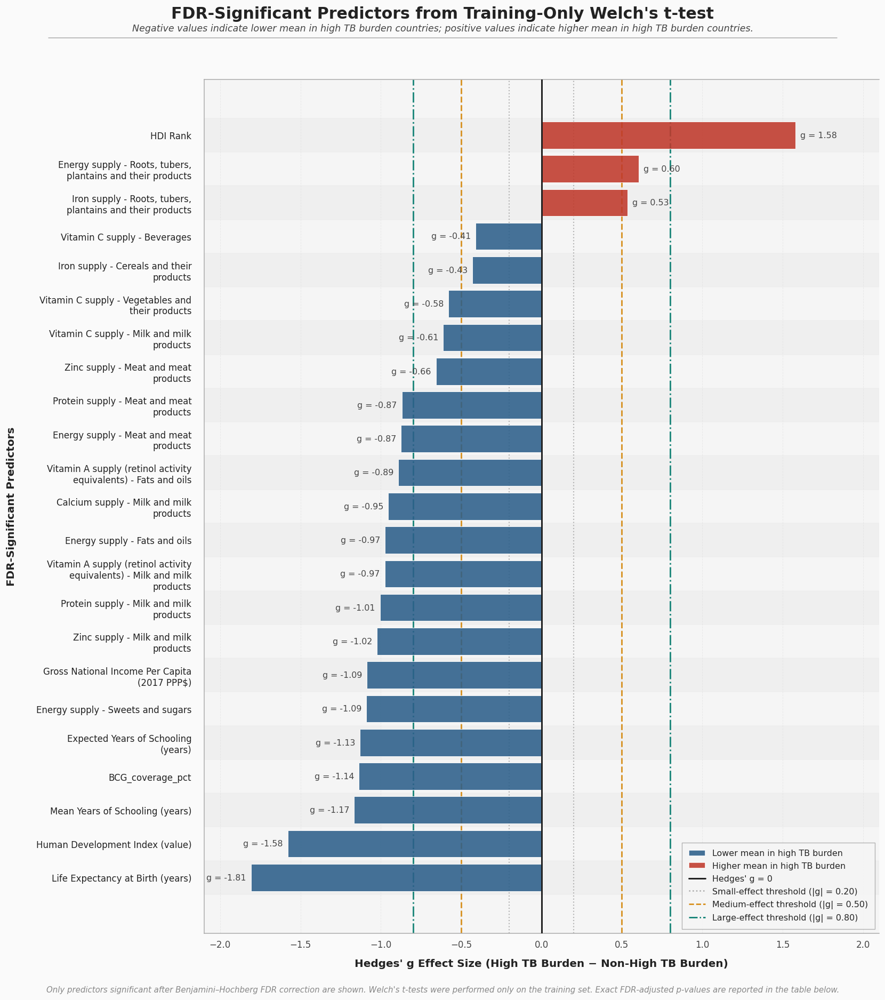

Improved Welch summary figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/13_welch_t_test_significant_predictors_effect_sizes.png


In [116]:
# Step 5A Visualization: Improved summary plot for FDR-significant predictors
# from the training-only Welch's t-test

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import textwrap

required_welch_viz_objects = [
    "welch_screening_results",
    "FIGURES_DIR"
]

missing_welch_viz_objects = [
    object_name for object_name in required_welch_viz_objects
    if object_name not in globals()
]

if missing_welch_viz_objects:
    raise NameError(
        "Missing required objects for Welch visualization. "
        f"Missing objects: {missing_welch_viz_objects}"
    )

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------
# Settings
# -------------------------------------------------------------------

SMALL_EFFECT  = 0.20
MEDIUM_EFFECT = 0.50
LARGE_EFFECT  = 0.80

TOP_N_WELCH_VISUALIZED = None   # None = show all significant predictors

# Academic palette — matches the rest of the thesis figures
CLASS_0_COLOR = "#2C5F8A"   # Lower mean in high TB burden (deep steel blue)
CLASS_1_COLOR = "#C0392B"   # Higher mean in high TB burden (deep crimson)

BG_FIGURE   = "#FAFAFA"
BG_AXES     = "#F5F5F5"
GRID_COLOR  = "#DDDDDD"
SPINE_COLOR = "#AAAAAA"
LABEL_COLOR = "#222222"
ANNOT_COLOR = "#444444"

# -------------------------------------------------------------------
# Data preparation
# -------------------------------------------------------------------

welch_significant_for_plot = (
    welch_screening_results.loc[
        welch_screening_results["significant_after_fdr_0_05"]
    ].copy()
)

if welch_significant_for_plot.empty:
    raise ValueError(
        "No FDR-significant predictors are available for Welch visualization."
    )

welch_significant_for_plot = welch_significant_for_plot.sort_values(
    by="hedges_g_high_minus_non_high",
    ascending=True
).reset_index(drop=True)

if TOP_N_WELCH_VISUALIZED is not None:
    welch_significant_for_plot = (
        welch_significant_for_plot
        .reindex(
            welch_significant_for_plot["absolute_hedges_g"]
            .sort_values(ascending=False)
            .index
        )
        .head(TOP_N_WELCH_VISUALIZED)
        .sort_values(by="hedges_g_high_minus_non_high", ascending=True)
        .reset_index(drop=True)
    )

def wrap_feature_name(feature_name, width=34):
    return "\n".join(textwrap.wrap(str(feature_name), width=width))

welch_significant_for_plot["feature_wrapped"] = (
    welch_significant_for_plot["feature"]
    .apply(wrap_feature_name)
)

effect_values  = welch_significant_for_plot["hedges_g_high_minus_non_high"]
feature_labels = welch_significant_for_plot["feature_wrapped"]

bar_colors = [
    CLASS_0_COLOR if value < 0 else CLASS_1_COLOR
    for value in effect_values
]

# -------------------------------------------------------------------
# Figure
# -------------------------------------------------------------------

plt.rcParams.update({
    "font.family":      "DejaVu Sans",
    "axes.titlesize":   14,
    "axes.labelsize":   12,
    "xtick.labelsize":  10,
    "ytick.labelsize":  10,
    "legend.fontsize":  9.5,
    "figure.facecolor": BG_FIGURE,
    "axes.facecolor":   BG_AXES,
    "axes.edgecolor":   SPINE_COLOR,
    "text.color":       LABEL_COLOR,
    "xtick.color":      ANNOT_COLOR,
    "ytick.color":      ANNOT_COLOR,
})

n_predictors  = len(welch_significant_for_plot)
figure_height = max(8, 0.57 * n_predictors + 2.5)

fig, ax = plt.subplots(figsize=(14, figure_height))
fig.patch.set_facecolor(BG_FIGURE)
ax.set_facecolor(BG_AXES)

y_positions = np.arange(n_predictors)

bars = ax.barh(
    y=y_positions,
    width=effect_values,
    color=bar_colors,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.88,
    zorder=3
)

# Alternating row shading
for i in range(n_predictors):
    if i % 2 == 0:
        ax.axhspan(
            i - 0.5, i + 0.5,
            color="#EBEBEB",
            alpha=0.55,
            zorder=0
        )

# Zero reference line
ax.axvline(
    x=0,
    color="#222222",
    linewidth=1.8,
    linestyle="-",
    zorder=4
)

# Effect size threshold lines
threshold_line_specs = [
    (SMALL_EFFECT,  "#AAAAAA", ":",  1.3),
    (MEDIUM_EFFECT, "#D4870A", "--", 1.8),
    (LARGE_EFFECT,  "#00796B", "-.", 1.8),
]

for threshold_value, threshold_color, threshold_style, lw in threshold_line_specs:
    for sign in [1, -1]:
        ax.axvline(
            x=sign * threshold_value,
            color=threshold_color,
            linestyle=threshold_style,
            linewidth=lw,
            zorder=2,
            alpha=0.85
        )

# Y-axis
ax.set_yticks(y_positions)
ax.set_yticklabels(feature_labels, fontsize=10, color=LABEL_COLOR)
ax.tick_params(axis="y", which="major", pad=14, length=0)
ax.tick_params(axis="x", length=4, width=0.8, color=SPINE_COLOR)

ax.set_xlabel(
    "Hedges' g Effect Size (High TB Burden − Non-High TB Burden)",
    fontsize=12,
    labelpad=10,
    color=LABEL_COLOR,
    fontweight="semibold"
)

ax.set_ylabel(
    "FDR-Significant Predictors",
    fontsize=12,
    labelpad=22,
    color=LABEL_COLOR,
    fontweight="semibold"
)

# Symmetric x-axis
max_abs_effect = max(LARGE_EFFECT, np.nanmax(np.abs(effect_values)))
x_limit = np.ceil((max_abs_effect + 0.25) * 10) / 10
ax.set_xlim(-x_limit, x_limit)

# Grid
ax.xaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.5, color=GRID_COLOR, zorder=1)
ax.yaxis.grid(False)
ax.set_axisbelow(True)

# Spines
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(True)
ax.spines["top"].set_linewidth(0.9)
ax.spines["top"].set_color(SPINE_COLOR)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_linewidth(0.9)
ax.spines["bottom"].set_color(SPINE_COLOR)
ax.spines["left"].set_visible(True)
ax.spines["left"].set_linewidth(0.9)
ax.spines["left"].set_color(SPINE_COLOR)

# Value labels
for bar, effect_value in zip(bars, effect_values):
    x_position = bar.get_width()
    y_position = bar.get_y() + bar.get_height() / 2

    if effect_value >= 0:
        text_x = x_position + 0.03
        ha = "left"
    else:
        text_x = x_position - 0.03
        ha = "right"

    ax.text(
        text_x,
        y_position,
        f"g = {effect_value:.2f}",
        va="center",
        ha=ha,
        fontsize=9.5,
        color=ANNOT_COLOR,
        fontweight="medium"
    )

# Legend — embedded inside axes, upper left
legend_handles = [
    Patch(
        facecolor=CLASS_0_COLOR,
        edgecolor="white",
        alpha=0.88,
        label="Lower mean in high TB burden"
    ),
    Patch(
        facecolor=CLASS_1_COLOR,
        edgecolor="white",
        alpha=0.88,
        label="Higher mean in high TB burden"
    ),
    Line2D(
        [0], [0],
        color="#222222",
        linestyle="-",
        linewidth=1.8,
        label="Hedges' g = 0"
    ),
    Line2D(
        [0], [0],
        color="#AAAAAA",
        linestyle=":",
        linewidth=1.5,
        label="Small-effect threshold (|g| = 0.20)"
    ),
    Line2D(
        [0], [0],
        color="#D4870A",
        linestyle="--",
        linewidth=1.5,
        label="Medium-effect threshold (|g| = 0.50)"
    ),
    Line2D(
        [0], [0],
        color="#00796B",
        linestyle="-.",
        linewidth=1.5,
        label="Large-effect threshold (|g| = 0.80)"
    ),
]

legend = ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=9.5,
    frameon=True,
    framealpha=0.92,
    edgecolor=SPINE_COLOR,
    fancybox=False,
    borderpad=0.8,
    labelspacing=0.55
)
legend.get_frame().set_linewidth(0.8)

# Title block
fig.suptitle(
    "FDR-Significant Predictors from Training-Only Welch's t-test",
    fontsize=18,
    fontweight="bold",
    color=LABEL_COLOR,
    y=0.995
)

fig.text(
    0.5,
    0.970,
    (
        "Negative values indicate lower mean in high TB burden countries; "
        "positive values indicate higher mean in high TB burden countries."
    ),
    ha="center",
    fontsize=10.5,
    color=ANNOT_COLOR,
    style="italic"
)

# Thin decorative separator line beneath subtitle
fig.add_artist(
    plt.Line2D(
        [0.06, 0.94], [0.963, 0.963],
        transform=fig.transFigure,
        color=SPINE_COLOR,
        linewidth=0.9
    )
)

# Footer note
fig.text(
    0.5,
    0.008,
    (
        "Only predictors significant after Benjamini–Hochberg FDR correction are shown. "
        "Welch's t-tests were performed only on the training set. "
        "Exact FDR-adjusted p-values are reported in the table below."
    ),
    ha="center",
    fontsize=9,
    color="#888888",
    style="italic"
)

plt.tight_layout(rect=[0, 0.02, 1, 0.960])

welch_figure_path = FIGURES_DIR / "13_welch_t_test_significant_predictors_effect_sizes.png"
plt.savefig(
    welch_figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor=BG_FIGURE
)
plt.show()
plt.close(fig)

print("Improved Welch summary figure saved to:")
print(welch_figure_path)


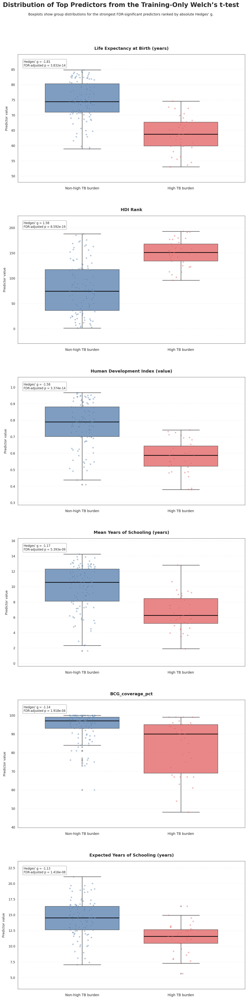

Welch boxplot figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/13_welch_t_test_top_predictors_boxplots_large_panels.png
Welch boxplot PDF figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/13_welch_t_test_top_predictors_boxplots_large_panels.pdf
Top predictors visualized:
1. Life Expectancy at Birth (years)
2. HDI Rank
3. Human Development Index (value)
4. Mean Years of Schooling (years)
5. BCG_coverage_pct
6. Expected Years of Schooling (years)


In [55]:
# Step 5A Visualization 2: Large boxplots for top predictors
# from the training-only Welch's t-test

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

required_welch_boxplot_objects = [
    "X_screening_train",
    "y_screening_train",
    "welch_screening_results",
    "FIGURES_DIR"
]

missing_welch_boxplot_objects = [
    object_name for object_name in required_welch_boxplot_objects
    if object_name not in globals()
]

if missing_welch_boxplot_objects:
    raise NameError(
        "Missing required objects for the Welch boxplot visualization. "
        f"Missing objects: {missing_welch_boxplot_objects}"
    )

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TOP_N_WELCH_BOXPLOTS = 6

welch_significant_predictors_for_boxplots = (
    welch_screening_results.loc[
        welch_screening_results["significant_after_fdr_0_05"]
    ]
    .copy()
)

if welch_significant_predictors_for_boxplots.empty:
    raise ValueError(
        "No FDR-significant predictors are available for the Welch boxplot visualization."
    )

required_boxplot_columns = [
    "feature",
    "absolute_hedges_g",
    "hedges_g_high_minus_non_high",
    "welch_p_value_fdr_bh"
]

missing_boxplot_columns = [
    column for column in required_boxplot_columns
    if column not in welch_significant_predictors_for_boxplots.columns
]

if missing_boxplot_columns:
    raise KeyError(
        "The following required columns are missing from welch_screening_results: "
        f"{missing_boxplot_columns}"
    )

top_welch_predictors = (
    welch_significant_predictors_for_boxplots
    .sort_values(by="absolute_hedges_g", ascending=False)
    .head(TOP_N_WELCH_BOXPLOTS)
    .reset_index(drop=True)
)

top_welch_predictor_names = top_welch_predictors["feature"].tolist()

missing_top_predictors = [
    predictor_name for predictor_name in top_welch_predictor_names
    if predictor_name not in X_screening_train.columns
]

if missing_top_predictors:
    raise KeyError(
        "The following top Welch predictors are missing from X_screening_train: "
        f"{missing_top_predictors}"
    )

boxplot_data = X_screening_train[top_welch_predictor_names].copy()
boxplot_data["high_tb_burden"] = y_screening_train.values

boxplot_data["TB burden group"] = boxplot_data["high_tb_burden"].map({
    0: "Non-high TB burden",
    1: "High TB burden"
})

n_predictors = len(top_welch_predictor_names)

# IMPORTANT CHANGE:
# One subplot per row. This makes every boxplot panel much larger and clearer.
n_columns = 1
n_rows = n_predictors

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_columns,
    figsize=(12.5, 8 * n_rows)
)

if n_predictors == 1:
    axes = np.array([axes])

axes = np.array(axes).reshape(-1)

group_order = ["Non-high TB burden", "High TB burden"]

group_colors = {
    "Non-high TB burden": "#4C78A8",
    "High TB burden": "#E15759"
}

rng = np.random.default_rng(42)


def wrap_feature_name(feature_name, width=60):
    return "\n".join(textwrap.wrap(str(feature_name), width=width))


for plot_index, (ax, predictor_name) in enumerate(
    zip(axes, top_welch_predictor_names)
):
    predictor_values_non_high = (
        boxplot_data.loc[
            boxplot_data["TB burden group"] == "Non-high TB burden",
            predictor_name
        ]
        .dropna()
        .astype(float)
    )

    predictor_values_high = (
        boxplot_data.loc[
            boxplot_data["TB burden group"] == "High TB burden",
            predictor_name
        ]
        .dropna()
        .astype(float)
    )

    data_to_plot = [
        predictor_values_non_high.values,
        predictor_values_high.values
    ]

    combined_values = np.concatenate(data_to_plot)

    y_min = np.nanmin(combined_values)
    y_max = np.nanmax(combined_values)
    y_range = y_max - y_min

    if y_range == 0:
        y_padding = 1
    else:
        y_padding = 0.16 * y_range

    ax.set_ylim(
        y_min - y_padding,
        y_max + y_padding
    )

    bp = ax.boxplot(
        data_to_plot,
        positions=[1, 2],
        widths=0.75,
        patch_artist=True,
        showfliers=True,
        medianprops=dict(
            color="black",
            linewidth=2.2
        ),
        whiskerprops=dict(
            color="#444444",
            linewidth=1.5
        ),
        capprops=dict(
            color="#444444",
            linewidth=1.5
        ),
        boxprops=dict(
            edgecolor="#333333",
            linewidth=1.4
        ),
        flierprops=dict(
            marker="o",
            markerfacecolor="#777777",
            markeredgecolor="#555555",
            markersize=4.5,
            alpha=0.45
        )
    )

    for patch, group_name in zip(bp["boxes"], group_order):
        patch.set_facecolor(group_colors[group_name])
        patch.set_alpha(0.72)
        patch.set_zorder(2)

    # Overlay individual observations with jitter.
    for x_position, group_name, values in zip(
        [1, 2],
        group_order,
        [predictor_values_non_high, predictor_values_high]
    ):
        jitter = rng.uniform(
            low=-0.13,
            high=0.13,
            size=len(values)
        )

        ax.scatter(
            np.full(len(values), x_position) + jitter,
            values,
            s=26,
            alpha=0.42,
            color=group_colors[group_name],
            edgecolors="white",
            linewidths=0.25,
            zorder=3
        )

    predictor_stats = top_welch_predictors.loc[
        top_welch_predictors["feature"] == predictor_name
    ].iloc[0]

    wrapped_title = wrap_feature_name(predictor_name, width=60)

    ax.set_title(
        wrapped_title,
        fontsize=14,
        fontweight="bold",
        pad=16
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(
        group_order,
        fontsize=11.5
    )

    ax.tick_params(
        axis="x",
        pad=9
    )

    ax.tick_params(
        axis="y",
        labelsize=10.5
    )

    ax.set_ylabel(
        "Predictor value",
        fontsize=11,
        labelpad=10
    )

    # More horizontal space around the two boxplots.
    ax.set_xlim(0.35, 2.65)

    ax.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.30
    )

    ax.xaxis.grid(False)

    for spine_name in ["top", "right", "bottom", "left"]:
        ax.spines[spine_name].set_visible(True)
        ax.spines[spine_name].set_linewidth(0.95)
        ax.spines[spine_name].set_color("#666666")

    annotation_text = (
        f"Hedges' g = {predictor_stats['hedges_g_high_minus_non_high']:.2f}\n"
        f"FDR-adjusted p = {predictor_stats['welch_p_value_fdr_bh']:.3e}"
    )

    ax.text(
        0.025,
        0.955,
        annotation_text,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="#999999",
            alpha=0.92
        ),
        zorder=5
    )

fig.suptitle(
    "Distribution of Top Predictors from the Training-Only Welch’s t-test",
    fontsize=21,
    fontweight="bold",
    y=0.995
)

fig.text(
    0.5,
    0.982,
    "Boxplots show group distributions for the strongest FDR-significant predictors ranked by absolute Hedges’ g.",
    ha="center",
    fontsize=11.5
)

plt.tight_layout(
    rect=[0.04, 0.02, 0.98, 0.965],
    h_pad=5.0
)

welch_boxplot_figure_path = (
    FIGURES_DIR / "13_welch_t_test_top_predictors_boxplots_large_panels.png"
)

welch_boxplot_figure_pdf_path = (
    FIGURES_DIR / "13_welch_t_test_top_predictors_boxplots_large_panels.pdf"
)

plt.savefig(
    welch_boxplot_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    welch_boxplot_figure_pdf_path,
    bbox_inches="tight"
)

plt.show()

print("Welch boxplot figure saved to:")
print(welch_boxplot_figure_path)

print("Welch boxplot PDF figure saved to:")
print(welch_boxplot_figure_pdf_path)

print("Top predictors visualized:")
for index, predictor_name in enumerate(top_welch_predictor_names, start=1):
    print(f"{index}. {predictor_name}")

In [56]:
# Step 6A: Training-only Mann–Whitney U test for predictor screening

# The Mann–Whitney U test is a non-parametric statistical test used to compare
# the rank/distribution tendency of a numeric predictor between two independent groups:
#   1) Non-high TB burden countries
#   2) High TB burden countries
#
# For each predictor:
#
# H0 (null hypothesis):
#   The distribution/rank tendency of the predictor is the same in the two TB burden classes.
#   In practical terms, there is no systematic tendency for values in one group
#   to be higher or lower than values in the other group.
#
# Ha (alternative hypothesis):
#   The distribution/rank tendency of the predictor differs between the two TB burden classes.
#   In practical terms, values in one group tend to be systematically higher
#   or lower than values in the other group.
#
# Important:
# - This test is performed only on the training set.
# - The test set remains untouched until final model evaluation.
# - Mann–Whitney U is useful when predictors are skewed, non-normal, ordinal-like,
#   or when we want a rank-based comparison rather than a mean-based comparison.
# - Since many predictors are tested, Benjamini-Hochberg FDR correction is applied.
# - Rank-biserial correlation is calculated as a rank-based effect size.
#
# Important interpretation note:
# - Mann–Whitney U is not strictly a "median test" unless the two group distributions
#   have a similar shape. Therefore, the test is interpreted as a rank/distribution
#   comparison, while medians and IQRs are reported descriptively.

import numpy as np
import pandas as pd

from scipy import stats
from statsmodels.stats.multitest import multipletests

FDR_ALPHA = 0.05

MANN_WHITNEY_EFFECT_SIZE_SMALL = 0.10
MANN_WHITNEY_EFFECT_SIZE_MEDIUM = 0.30
MANN_WHITNEY_EFFECT_SIZE_LARGE = 0.50

TOP_N_MANN_WHITNEY_DISPLAY = 15

required_mann_whitney_objects = [
    "X_screening_train",
    "y_screening_train",
    "screening_predictor_cols",
    "target_column",
    "TABLES_DIR"
]

missing_mann_whitney_objects = [
    object_name for object_name in required_mann_whitney_objects
    if object_name not in globals()
]

if missing_mann_whitney_objects:
    raise NameError(
        "Missing required objects for the Mann–Whitney U test. "
        "Run the training-only statistical screening input cell first. "
        f"Missing objects: {missing_mann_whitney_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(X_screening_train, pd.DataFrame):
    raise TypeError(
        "X_screening_train must be a pandas DataFrame."
    )

if not isinstance(y_screening_train, pd.Series):
    raise TypeError(
        "y_screening_train must be a pandas Series."
    )

if not isinstance(screening_predictor_cols, list):
    raise TypeError(
        "screening_predictor_cols must be a list."
    )

if X_screening_train.shape[0] != y_screening_train.shape[0]:
    raise ValueError(
        "The number of rows in X_screening_train and y_screening_train does not match."
    )

if not X_screening_train.index.equals(y_screening_train.index):
    raise ValueError(
        "The index of X_screening_train and y_screening_train does not match."
    )

if sorted(y_screening_train.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_screening_train must contain binary values [0, 1]."
    )

missing_mann_whitney_predictors = [
    feature for feature in screening_predictor_cols
    if feature not in X_screening_train.columns
]

if missing_mann_whitney_predictors:
    raise KeyError(
        "The following predictors are missing from X_screening_train: "
        f"{missing_mann_whitney_predictors}"
    )

# Safety check:
# The target column and known leakage-related columns must not be used
# as predictors in the training-only Mann–Whitney U screening.
if target_column in screening_predictor_cols:
    raise ValueError(
        f"Target column '{target_column}' was found in screening_predictor_cols. "
        "The target must not be used as a predictor in Mann–Whitney U screening."
    )

known_leakage_columns = [
    target_column,
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group",
    "BCG_was_missing"
]

leakage_columns_in_screening = [
    column
    for column in sorted(set(known_leakage_columns))
    if column in screening_predictor_cols
]

if leakage_columns_in_screening:
    raise ValueError(
        "Potential leakage columns were found in screening_predictor_cols: "
        f"{leakage_columns_in_screening}. "
        "These columns must be excluded from Mann–Whitney U screening."
    )

print("Leakage safety check passed for Mann–Whitney U screening.")

non_numeric_mann_whitney_predictors = [
    feature for feature in screening_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_screening_train[feature])
]

if non_numeric_mann_whitney_predictors:
    raise TypeError(
        "All predictors used for the Mann–Whitney U test must be numeric. "
        f"Non-numeric predictors found: {non_numeric_mann_whitney_predictors}"
    )


def classify_rank_biserial_effect_size(abs_effect_size):
    if pd.isna(abs_effect_size):
        return "Not available"

    if abs_effect_size < MANN_WHITNEY_EFFECT_SIZE_SMALL:
        return "Negligible"

    if abs_effect_size < MANN_WHITNEY_EFFECT_SIZE_MEDIUM:
        return "Small"

    if abs_effect_size < MANN_WHITNEY_EFFECT_SIZE_LARGE:
        return "Medium"

    return "Large"


mann_whitney_test_records = []

for feature in screening_predictor_cols:
    non_high_values = (
        X_screening_train
        .loc[y_screening_train == 0, feature]
        .dropna()
        .astype(float)
    )

    high_values = (
        X_screening_train
        .loc[y_screening_train == 1, feature]
        .dropna()
        .astype(float)
    )

    non_high_n = len(non_high_values)
    high_n = len(high_values)

    if non_high_n < 2 or high_n < 2:
        raise ValueError(
            f"Feature '{feature}' does not have at least two observations "
            "in each class for the Mann–Whitney U test."
        )

    if (
        not np.isfinite(non_high_values).all()
        or not np.isfinite(high_values).all()
    ):
        raise ValueError(
            f"Feature '{feature}' contains non-finite values after missing values were removed."
        )

    mann_whitney_u_statistic, mann_whitney_p_value = stats.mannwhitneyu(
        high_values,
        non_high_values,
        alternative="two-sided",
        method="asymptotic"
    )

    if not np.isfinite(mann_whitney_u_statistic):
        raise ValueError(
            f"Non-finite Mann–Whitney U statistic obtained for feature '{feature}'."
        )

    if not np.isfinite(mann_whitney_p_value):
        raise ValueError(
            f"Non-finite Mann–Whitney p-value obtained for feature '{feature}'."
        )

    combined_values = pd.concat(
        [
            high_values.rename("value"),
            non_high_values.rename("value")
        ],
        axis=0
    )

    combined_ranks = pd.Series(
        stats.rankdata(
            combined_values,
            method="average"
        ),
        index=combined_values.index
    )

    high_mean_rank = combined_ranks.loc[high_values.index].mean()
    non_high_mean_rank = combined_ranks.loc[non_high_values.index].mean()

    non_high_median = non_high_values.median()
    high_median = high_values.median()

    non_high_iqr = (
        non_high_values.quantile(0.75)
        - non_high_values.quantile(0.25)
    )

    high_iqr = (
        high_values.quantile(0.75)
        - high_values.quantile(0.25)
    )

    median_difference = high_median - non_high_median
    mean_rank_difference = high_mean_rank - non_high_mean_rank

    common_language_effect_size = (
        mann_whitney_u_statistic
        / (high_n * non_high_n)
    )

    rank_biserial_correlation = (
        2 * common_language_effect_size
        - 1
    )

    if rank_biserial_correlation > 0:
        direction = "Higher values in high TB burden"
    elif rank_biserial_correlation < 0:
        direction = "Lower values in high TB burden"
    else:
        direction = "No rank-based difference"

    mann_whitney_test_records.append({
        "feature": feature,
        "non_high_n": non_high_n,
        "high_n": high_n,
        "non_high_median": non_high_median,
        "high_median": high_median,
        "median_difference_high_minus_non_high": median_difference,
        "non_high_iqr": non_high_iqr,
        "high_iqr": high_iqr,
        "non_high_mean_rank": non_high_mean_rank,
        "high_mean_rank": high_mean_rank,
        "mean_rank_difference_high_minus_non_high": mean_rank_difference,
        "mann_whitney_u_statistic": mann_whitney_u_statistic,
        "mann_whitney_p_value_unadjusted": mann_whitney_p_value,
        "common_language_effect_size": common_language_effect_size,
        "rank_biserial_correlation_high_minus_non_high": rank_biserial_correlation,
        "absolute_rank_biserial_correlation": abs(rank_biserial_correlation),
        "direction": direction
    })

mann_whitney_screening_results = pd.DataFrame(
    mann_whitney_test_records
)

valid_mann_whitney_p_value_mask = (
    mann_whitney_screening_results["mann_whitney_p_value_unadjusted"].notna()
    & np.isfinite(
        mann_whitney_screening_results["mann_whitney_p_value_unadjusted"]
    )
)

mann_whitney_screening_results["mann_whitney_p_value_fdr_bh"] = np.nan

mann_whitney_screening_results.loc[
    valid_mann_whitney_p_value_mask,
    "mann_whitney_p_value_fdr_bh"
] = multipletests(
    mann_whitney_screening_results.loc[
        valid_mann_whitney_p_value_mask,
        "mann_whitney_p_value_unadjusted"
    ],
    alpha=FDR_ALPHA,
    method="fdr_bh"
)[1]

mann_whitney_screening_results["significant_after_fdr_0_05"] = (
    mann_whitney_screening_results["mann_whitney_p_value_fdr_bh"] < FDR_ALPHA
)

mann_whitney_screening_results["effect_size_magnitude"] = (
    mann_whitney_screening_results["absolute_rank_biserial_correlation"]
    .apply(classify_rank_biserial_effect_size)
)

mann_whitney_screening_results = (
    mann_whitney_screening_results
    .sort_values(
        by=[
            "mann_whitney_p_value_fdr_bh",
            "absolute_rank_biserial_correlation"
        ],
        ascending=[
            True,
            False
        ],
        na_position="last"
    )
    .reset_index(drop=True)
)

mann_whitney_screening_results.insert(
    0,
    "rank_by_mann_whitney_fdr",
    range(1, len(mann_whitney_screening_results) + 1)
)

significant_mann_whitney_predictors = (
    mann_whitney_screening_results[
        mann_whitney_screening_results["significant_after_fdr_0_05"]
    ]
    .copy()
)

number_of_fdr_significant_mann_whitney_predictors = len(
    significant_mann_whitney_predictors
)

mann_whitney_summary = pd.DataFrame({
    "item": [
        "Predictors tested",
        "FDR alpha",
        "FDR-significant predictors",
        "Largest absolute rank-biserial correlation",
        "Small effect threshold",
        "Medium effect threshold",
        "Large effect threshold"
    ],
    "value": [
        len(mann_whitney_screening_results),
        FDR_ALPHA,
        number_of_fdr_significant_mann_whitney_predictors,
        round(
            mann_whitney_screening_results[
                "absolute_rank_biserial_correlation"
            ].max(),
            4
        ),
        MANN_WHITNEY_EFFECT_SIZE_SMALL,
        MANN_WHITNEY_EFFECT_SIZE_MEDIUM,
        MANN_WHITNEY_EFFECT_SIZE_LARGE
    ]
})

mann_whitney_screening_results_csv_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_results.csv"
)

mann_whitney_screening_results_excel_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_results.xlsx"
)

mann_whitney_summary_csv_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_summary.csv"
)

mann_whitney_summary_excel_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_summary.xlsx"
)

significant_mann_whitney_predictors_csv_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_significant_predictors.csv"
)

significant_mann_whitney_predictors_excel_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_significant_predictors.xlsx"
)

mann_whitney_screening_results.to_csv(
    mann_whitney_screening_results_csv_path,
    index=False
)

mann_whitney_screening_results.to_excel(
    mann_whitney_screening_results_excel_path,
    index=False
)

mann_whitney_summary.to_csv(
    mann_whitney_summary_csv_path,
    index=False
)

mann_whitney_summary.to_excel(
    mann_whitney_summary_excel_path,
    index=False
)

significant_mann_whitney_predictors.to_csv(
    significant_mann_whitney_predictors_csv_path,
    index=False
)

significant_mann_whitney_predictors.to_excel(
    significant_mann_whitney_predictors_excel_path,
    index=False
)

mann_whitney_screening_results_display = (
    mann_whitney_screening_results
    .copy()
)

significant_mann_whitney_predictors_display = (
    significant_mann_whitney_predictors
    .copy()
)

columns_to_round_for_display = [
    "non_high_median",
    "high_median",
    "median_difference_high_minus_non_high",
    "non_high_iqr",
    "high_iqr",
    "non_high_mean_rank",
    "high_mean_rank",
    "mean_rank_difference_high_minus_non_high",
    "mann_whitney_u_statistic",
    "common_language_effect_size",
    "rank_biserial_correlation_high_minus_non_high",
    "absolute_rank_biserial_correlation"
]

for display_table in [
    mann_whitney_screening_results_display,
    significant_mann_whitney_predictors_display
]:
    if not display_table.empty:
        display_table[columns_to_round_for_display] = (
            display_table[columns_to_round_for_display]
            .round(4)
        )

        display_table["mann_whitney_p_value_unadjusted"] = (
            display_table["mann_whitney_p_value_unadjusted"]
            .map(lambda value: f"{value:.3e}" if pd.notna(value) else "NA")
        )

        display_table["mann_whitney_p_value_fdr_bh"] = (
            display_table["mann_whitney_p_value_fdr_bh"]
            .map(lambda value: f"{value:.3e}" if pd.notna(value) else "NA")
        )

display(
    mann_whitney_screening_results_display
    .head(TOP_N_MANN_WHITNEY_DISPLAY)
)

display(mann_whitney_summary)

print("All FDR-significant predictors after Mann–Whitney U test:")

if significant_mann_whitney_predictors_display.empty:
    print("No predictors were significant after Benjamini-Hochberg FDR correction.")
else:
    display(significant_mann_whitney_predictors_display)

    significant_mann_whitney_feature_names = (
        significant_mann_whitney_predictors["feature"]
        .tolist()
    )

    print("Significant predictor names:")
    for index, feature_name in enumerate(
        significant_mann_whitney_feature_names,
        start=1
    ):
        print(f"{index}. {feature_name}")

print("Mann–Whitney U test completed successfully.")
print("Predictors tested:", len(mann_whitney_screening_results))
print("FDR alpha:", FDR_ALPHA)
print(
    "FDR-significant predictors:",
    number_of_fdr_significant_mann_whitney_predictors
)
print("Results saved as CSV:", mann_whitney_screening_results_csv_path)
print("Results saved as Excel:", mann_whitney_screening_results_excel_path)
print("Summary saved as CSV:", mann_whitney_summary_csv_path)
print("Summary saved as Excel:", mann_whitney_summary_excel_path)
print("Significant predictors saved as CSV:", significant_mann_whitney_predictors_csv_path)
print("Significant predictors saved as Excel:", significant_mann_whitney_predictors_excel_path)
print("Training-only Mann–Whitney U screening check passed.")

Leakage safety check passed for Mann–Whitney U screening.


,rank_by_mann_whitney_fdr,feature,non_high_n,high_n,non_high_median,high_median,median_difference_high_minus_non_high,non_high_iqr,high_iqr,non_high_mean_rank,high_mean_rank,mean_rank_difference_high_minus_non_high,mann_whitney_u_statistic,mann_whitney_p_value_unadjusted,common_language_effect_size,rank_biserial_correlation_high_minus_non_high,absolute_rank_biserial_correlation,direction,mann_whitney_p_value_fdr_bh,significant_after_fdr_0_05,effect_size_magnitude
0,1,Life Expectancy at Birth (years),109,37,74.416,63.728,-10.688,9.339,7.800,88.3716,29.6892,-58.6824,395.5,3.084e-13,0.0981,-0.8039,0.8039,Lower values in high TB burden,1.419e-11,True,Large
1,2,HDI Rank,109,37,74.000,151.000,77.000,81.000,34.000,59.4862,114.7838,55.2975,3544.0,6.415e-12,0.8788,0.7575,0.7575,Higher values in high TB burden,9.836e-11,True,Large
2,3,Human Development Index (value),109,37,0.789,0.587,-0.202,0.180,0.123,87.5138,32.2162,-55.2975,489.0,6.415e-12,0.1212,-0.7575,0.7575,Lower values in high TB burden,9.836e-11,True,Large
3,4,Gross National Income Per Capita (2017 PPP$),109,37,18425.011,4025.555,-14399.456,28265.460,4871.609,87.0826,33.4865,-53.5961,536.0,2.765e-11,0.1329,-0.7342,0.7342,Lower values in high TB burden,3.180e-10,True,Large
4,5,Zinc supply - Milk and milk products,109,37,1.330,0.260,-1.070,1.660,0.570,85.2339,38.9324,-46.3015,737.5,8.801e-09,0.1829,-0.6343,0.6343,Lower values in high TB burden,8.097e-08,True,Large
5,6,Mean Years of Schooling (years),109,37,10.556,6.235,-4.321,4.199,3.258,85.0229,39.5541,-45.4689,760.5,1.618e-08,0.1886,-0.6229,0.6229,Lower values in high TB burden,1.241e-07,True,Large
6,7,Protein supply - Milk and milk products,109,37,10.900,2.300,-8.600,13.700,4.900,84.9404,39.7973,-45.1431,769.5,2.042e-08,0.1908,-0.6184,0.6184,Lower values in high TB burden,1.282e-07,True,Large
7,8,Expected Years of Schooling (years),109,37,14.504,11.561,-2.943,3.752,2.179,84.8761,39.9865,-44.8897,776.5,2.454e-08,0.1925,-0.6149,0.6149,Lower values in high TB burden,1.282e-07,True,Large
8,9,Vitamin A supply (retinol activity equivalents...,109,37,78.000,12.000,-66.000,108.000,26.000,84.8670,40.0135,-44.8535,777.5,2.507e-08,0.1928,-0.6144,0.6144,Lower values in high TB burden,1.282e-07,True,Large
9,10,Vitamin A supply (retinol activity equivalents...,109,37,102.000,23.000,-79.000,130.000,48.000,84.6927,40.5270,-44.1656,796.5,4.092e-08,0.1975,-0.6050,0.6050,Lower values in high TB burden,1.882e-07,True,Large


,item,value
0,Predictors tested,46.0000
1,FDR alpha,0.0500
2,FDR-significant predictors,32.0000
3,Largest absolute rank-biserial correlation,0.8039
4,Small effect threshold,0.1000
5,Medium effect threshold,0.3000
6,Large effect threshold,0.5000


All FDR-significant predictors after Mann–Whitney U test:


,rank_by_mann_whitney_fdr,feature,non_high_n,high_n,non_high_median,high_median,median_difference_high_minus_non_high,non_high_iqr,high_iqr,non_high_mean_rank,high_mean_rank,mean_rank_difference_high_minus_non_high,mann_whitney_u_statistic,mann_whitney_p_value_unadjusted,common_language_effect_size,rank_biserial_correlation_high_minus_non_high,absolute_rank_biserial_correlation,direction,mann_whitney_p_value_fdr_bh,significant_after_fdr_0_05,effect_size_magnitude
0,1,Life Expectancy at Birth (years),109,37,74.416,63.728,-10.688,9.339,7.800,88.3716,29.6892,-58.6824,395.5,3.084e-13,0.0981,-0.8039,0.8039,Lower values in high TB burden,1.419e-11,True,Large
1,2,HDI Rank,109,37,74.000,151.000,77.000,81.000,34.000,59.4862,114.7838,55.2975,3544.0,6.415e-12,0.8788,0.7575,0.7575,Higher values in high TB burden,9.836e-11,True,Large
2,3,Human Development Index (value),109,37,0.789,0.587,-0.202,0.180,0.123,87.5138,32.2162,-55.2975,489.0,6.415e-12,0.1212,-0.7575,0.7575,Lower values in high TB burden,9.836e-11,True,Large
3,4,Gross National Income Per Capita (2017 PPP$),109,37,18425.011,4025.555,-14399.456,28265.460,4871.609,87.0826,33.4865,-53.5961,536.0,2.765e-11,0.1329,-0.7342,0.7342,Lower values in high TB burden,3.180e-10,True,Large
4,5,Zinc supply - Milk and milk products,109,37,1.330,0.260,-1.070,1.660,0.570,85.2339,38.9324,-46.3015,737.5,8.801e-09,0.1829,-0.6343,0.6343,Lower values in high TB burden,8.097e-08,True,Large
5,6,Mean Years of Schooling (years),109,37,10.556,6.235,-4.321,4.199,3.258,85.0229,39.5541,-45.4689,760.5,1.618e-08,0.1886,-0.6229,0.6229,Lower values in high TB burden,1.241e-07,True,Large
6,7,Protein supply - Milk and milk products,109,37,10.900,2.300,-8.600,13.700,4.900,84.9404,39.7973,-45.1431,769.5,2.042e-08,0.1908,-0.6184,0.6184,Lower values in high TB burden,1.282e-07,True,Large
7,8,Expected Years of Schooling (years),109,37,14.504,11.561,-2.943,3.752,2.179,84.8761,39.9865,-44.8897,776.5,2.454e-08,0.1925,-0.6149,0.6149,Lower values in high TB burden,1.282e-07,True,Large
8,9,Vitamin A supply (retinol activity equivalents...,109,37,78.000,12.000,-66.000,108.000,26.000,84.8670,40.0135,-44.8535,777.5,2.507e-08,0.1928,-0.6144,0.6144,Lower values in high TB burden,1.282e-07,True,Large
9,10,Vitamin A supply (retinol activity equivalents...,109,37,102.000,23.000,-79.000,130.000,48.000,84.6927,40.5270,-44.1656,796.5,4.092e-08,0.1975,-0.6050,0.6050,Lower values in high TB burden,1.882e-07,True,Large


Significant predictor names:
1. Life Expectancy at Birth (years)
2. HDI Rank
3. Human Development Index (value)
4. Gross National Income Per Capita (2017 PPP$)
5. Zinc supply - Milk and milk products
6. Mean Years of Schooling (years)
7. Protein supply - Milk and milk products
8. Expected Years of Schooling (years)
9. Vitamin A supply (retinol activity equivalents) - Fats and oils
10. Vitamin A supply (retinol activity equivalents) - Milk and milk products
11. Calcium supply - Milk and milk products
12. Energy supply - Sweets and sugars
13. Energy supply - Fats and oils
14. Protein supply - Meat and meat products
15. BCG_coverage_pct
16. Energy supply - Meat and meat products
17. Zinc supply - Meat and meat products
18. Vitamin C supply - Vegetables and their products
19. Vitamin C supply - Milk and milk products
20. Iron supply - Meat and meat products
21. Vitamin C supply - Beverages
22. Vitamin A supply (retinol activity equivalents) - Roots, tubers, plantains and their products
23.

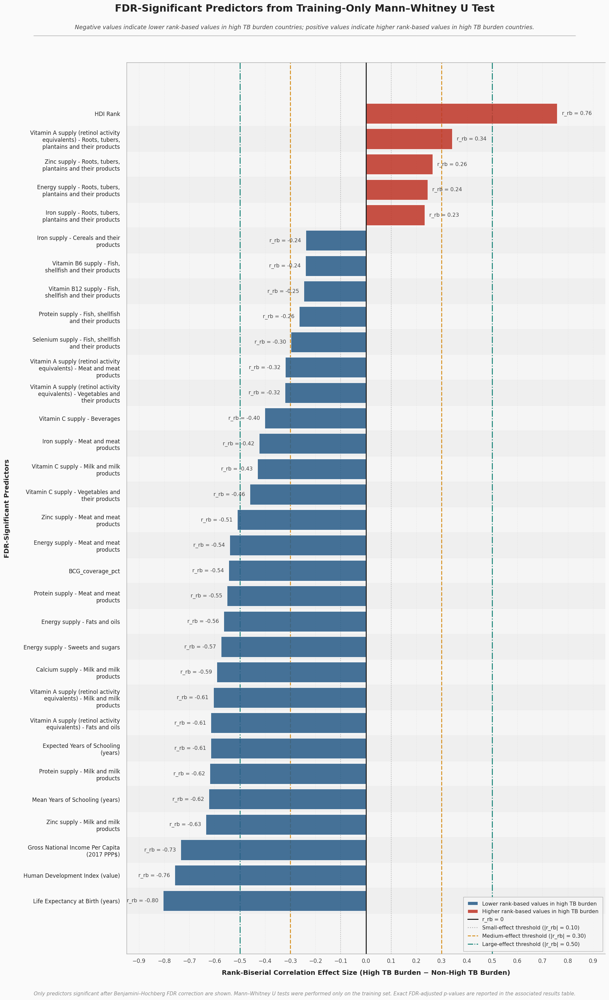

,feature,rank_biserial_correlation_high_minus_non_high,mann_whitney_p_value_fdr_bh,effect_size_magnitude,direction
0,Life Expectancy at Birth (years),-0.8039,1.419e-11,Large,Lower values in high TB burden
1,Human Development Index (value),-0.7575,9.836e-11,Large,Lower values in high TB burden
2,Gross National Income Per Capita (2017 PPP$),-0.7342,3.180e-10,Large,Lower values in high TB burden
3,Zinc supply - Milk and milk products,-0.6343,8.097e-08,Large,Lower values in high TB burden
4,Mean Years of Schooling (years),-0.6229,1.241e-07,Large,Lower values in high TB burden
5,Protein supply - Milk and milk products,-0.6184,1.282e-07,Large,Lower values in high TB burden
6,Expected Years of Schooling (years),-0.6149,1.282e-07,Large,Lower values in high TB burden
7,Vitamin A supply (retinol activity equivalents...,-0.6144,1.282e-07,Large,Lower values in high TB burden
8,Vitamin A supply (retinol activity equivalents...,-0.6050,1.882e-07,Large,Lower values in high TB burden
9,Calcium supply - Milk and milk products,-0.5909,3.511e-07,Large,Lower values in high TB burden


Improved Mann–Whitney U effect-size visualization completed successfully.
FDR-significant predictors plotted: 32
PNG: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/14_mann_whitney_u_test_training_only_fdr_significant_effect_sizes_improved.png
PDF: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/14_mann_whitney_u_test_training_only_fdr_significant_effect_sizes_improved.pdf
Plot data CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/14_mann_whitney_u_test_training_only_fdr_significant_effect_size_plot_data_improved.csv
Plot data Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/14_mann_whitney_u_test_training_only_fdr_significant_effect_size_plot_data_improved.xlsx


In [117]:
# Step 6B: Improved visualization of training-only Mann–Whitney U test results

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import textwrap

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# -------------------------------------------------------------------
# Settings
# -------------------------------------------------------------------

TOP_N_MANN_WHITNEY_EFFECT_SIZE_PLOT = None
FEATURE_LABEL_WRAP_WIDTH = 34

required_mann_whitney_visualization_objects = [
    "mann_whitney_screening_results",
    "MANN_WHITNEY_EFFECT_SIZE_SMALL",
    "MANN_WHITNEY_EFFECT_SIZE_MEDIUM",
    "MANN_WHITNEY_EFFECT_SIZE_LARGE",
    "TABLES_DIR",
    "FIGURES_DIR"
]

missing_mann_whitney_visualization_objects = [
    object_name
    for object_name in required_mann_whitney_visualization_objects
    if object_name not in globals()
]

if missing_mann_whitney_visualization_objects:
    raise NameError(
        "Missing required objects for Mann–Whitney visualization. "
        f"Missing objects: {missing_mann_whitney_visualization_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_dpi = FIGURE_DPI if "FIGURE_DPI" in globals() else 300

required_mann_whitney_result_columns = [
    "feature",
    "rank_biserial_correlation_high_minus_non_high",
    "absolute_rank_biserial_correlation",
    "mann_whitney_p_value_fdr_bh",
    "significant_after_fdr_0_05",
    "effect_size_magnitude",
    "direction"
]

missing_mann_whitney_result_columns = [
    column
    for column in required_mann_whitney_result_columns
    if column not in mann_whitney_screening_results.columns
]

if missing_mann_whitney_result_columns:
    raise KeyError(
        "Missing required columns in mann_whitney_screening_results: "
        f"{missing_mann_whitney_result_columns}"
    )

# -------------------------------------------------------------------
# Data preparation
# -------------------------------------------------------------------

mann_whitney_significant_plot_data = (
    mann_whitney_screening_results[
        mann_whitney_screening_results["significant_after_fdr_0_05"]
    ]
    .dropna(
        subset=[
            "rank_biserial_correlation_high_minus_non_high",
            "absolute_rank_biserial_correlation",
            "mann_whitney_p_value_fdr_bh"
        ]
    )
    .copy()
)

if mann_whitney_significant_plot_data.empty:
    raise ValueError(
        "No predictors were significant after Benjamini-Hochberg FDR correction."
    )

mann_whitney_significant_plot_data = (
    mann_whitney_significant_plot_data
    .sort_values(
        by="rank_biserial_correlation_high_minus_non_high",
        ascending=True
    )
    .reset_index(drop=True)
)

if TOP_N_MANN_WHITNEY_EFFECT_SIZE_PLOT is not None:
    mann_whitney_significant_plot_data = (
        mann_whitney_significant_plot_data
        .reindex(
            mann_whitney_significant_plot_data[
                "absolute_rank_biserial_correlation"
            ]
            .sort_values(ascending=False)
            .head(TOP_N_MANN_WHITNEY_EFFECT_SIZE_PLOT)
            .index
        )
        .sort_values(
            by="rank_biserial_correlation_high_minus_non_high",
            ascending=True
        )
        .reset_index(drop=True)
    )

mann_whitney_significant_plot_data["wrapped_feature_label"] = (
    mann_whitney_significant_plot_data["feature"]
    .apply(
        lambda value: textwrap.fill(
            str(value),
            width=FEATURE_LABEL_WRAP_WIDTH
        )
    )
)

# Academic palette — matches the rest of the thesis figures
CLASS_0_COLOR = "#2C5F8A"   # Lower mean in high TB burden (deep steel blue)
CLASS_1_COLOR = "#C0392B"   # Higher mean in high TB burden (deep crimson)

BG_FIGURE   = "#FAFAFA"
BG_AXES     = "#F5F5F5"
GRID_COLOR  = "#DDDDDD"
SPINE_COLOR = "#AAAAAA"
LABEL_COLOR = "#222222"
ANNOT_COLOR = "#444444"

mann_whitney_significant_plot_data["bar_color"] = np.where(
    mann_whitney_significant_plot_data[
        "rank_biserial_correlation_high_minus_non_high"
    ] >= 0,
    CLASS_1_COLOR,
    CLASS_0_COLOR
)

# -------------------------------------------------------------------
# Figure
# -------------------------------------------------------------------

plt.rcParams.update({
    "font.family":      "DejaVu Sans",
    "axes.titlesize":   14,
    "axes.labelsize":   12,
    "xtick.labelsize":  10,
    "ytick.labelsize":  10,
    "legend.fontsize":  9.5,
    "figure.facecolor": BG_FIGURE,
    "axes.facecolor":   BG_AXES,
    "axes.edgecolor":   SPINE_COLOR,
    "text.color":       LABEL_COLOR,
    "xtick.color":      ANNOT_COLOR,
    "ytick.color":      ANNOT_COLOR,
})

number_of_plotted_predictors = len(mann_whitney_significant_plot_data)
figure_height = max(10.0, 0.68 * number_of_plotted_predictors + 3.5)

fig, ax = plt.subplots(figsize=(15.5, figure_height))
fig.patch.set_facecolor(BG_FIGURE)
ax.set_facecolor(BG_AXES)

y_positions = np.arange(number_of_plotted_predictors)

bars = ax.barh(
    y_positions,
    mann_whitney_significant_plot_data[
        "rank_biserial_correlation_high_minus_non_high"
    ],
    color=mann_whitney_significant_plot_data["bar_color"],
    alpha=0.88,
    edgecolor="white",
    linewidth=0.6,
    zorder=3
)

# Alternating row shading
for i in range(number_of_plotted_predictors):
    if i % 2 == 0:
        ax.axhspan(
            i - 0.5, i + 0.5,
            color="#EBEBEB",
            alpha=0.55,
            zorder=0
        )

# Zero reference line
ax.axvline(
    0,
    color="#222222",
    linewidth=1.8,
    linestyle="-",
    zorder=4
)

# Effect size threshold lines
effect_reference_lines = [
    (MANN_WHITNEY_EFFECT_SIZE_SMALL,  "#AAAAAA", ":",  1.3),
    (MANN_WHITNEY_EFFECT_SIZE_MEDIUM, "#D4870A", "--", 1.8),
    (MANN_WHITNEY_EFFECT_SIZE_LARGE,  "#00796B", "-.", 1.8),
]

for threshold_value, line_color, line_style, lw in effect_reference_lines:
    for sign in [1, -1]:
        ax.axvline(
            sign * threshold_value,
            color=line_color,
            linestyle=line_style,
            linewidth=lw,
            zorder=2,
            alpha=0.85
        )

# Y-axis
ax.set_yticks(y_positions)
ax.set_yticklabels(
    mann_whitney_significant_plot_data["wrapped_feature_label"],
    fontsize=10,
    color=LABEL_COLOR
)
ax.tick_params(axis="y", which="major", pad=12, length=0)
ax.tick_params(axis="x", length=4, width=0.8, color=SPINE_COLOR)

# X-axis limit
maximum_absolute_effect = (
    mann_whitney_significant_plot_data[
        "rank_biserial_correlation_high_minus_non_high"
    ]
    .abs()
    .max()
)
x_axis_limit = max(
    MANN_WHITNEY_EFFECT_SIZE_LARGE + 0.20,
    maximum_absolute_effect * 1.18
)
ax.set_xlim(-x_axis_limit, x_axis_limit)
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.1))

ax.set_xlabel(
    "Rank-Biserial Correlation Effect Size (High TB Burden − Non-High TB Burden)",
    fontsize=12,
    labelpad=10,
    color=LABEL_COLOR,
    fontweight="semibold"
)

ax.set_ylabel(
    "FDR-Significant Predictors",
    fontsize=12,
    labelpad=24,
    color=LABEL_COLOR,
    fontweight="semibold"
)

# Grid
ax.xaxis.grid(True, linestyle="--", linewidth=0.6, alpha=0.5, color=GRID_COLOR, zorder=1)
ax.yaxis.grid(False)
ax.set_axisbelow(True)

# Spines
ax.spines["right"].set_visible(False)
ax.spines["top"].set_visible(True)
ax.spines["top"].set_linewidth(0.9)
ax.spines["top"].set_color(SPINE_COLOR)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_linewidth(0.9)
ax.spines["bottom"].set_color(SPINE_COLOR)
ax.spines["left"].set_visible(True)
ax.spines["left"].set_linewidth(0.9)
ax.spines["left"].set_color(SPINE_COLOR)

# Value labels
for y_position, (_, row) in zip(
    y_positions,
    mann_whitney_significant_plot_data.iterrows()
):
    effect_size_value = row["rank_biserial_correlation_high_minus_non_high"]
    label_text = f"r_rb = {effect_size_value:.2f}"

    if effect_size_value >= 0:
        text_x_position = effect_size_value + (x_axis_limit * 0.02)
        horizontal_alignment = "left"
    else:
        text_x_position = effect_size_value - (x_axis_limit * 0.02)
        horizontal_alignment = "right"

    ax.text(
        text_x_position,
        y_position,
        label_text,
        va="center",
        ha=horizontal_alignment,
        fontsize=9.5,
        color=ANNOT_COLOR,
        fontweight="medium"
    )

# Legend — embedded inside axes, lower right
legend_handles = [
    Patch(
        facecolor=CLASS_0_COLOR,
        edgecolor="white",
        alpha=0.88,
        label="Lower rank-based values in high TB burden"
    ),
    Patch(
        facecolor=CLASS_1_COLOR,
        edgecolor="white",
        alpha=0.88,
        label="Higher rank-based values in high TB burden"
    ),
    Line2D(
        [0], [0],
        color="#222222",
        linestyle="-",
        linewidth=1.8,
        label="r_rb = 0"
    ),
    Line2D(
        [0], [0],
        color="#AAAAAA",
        linestyle=":",
        linewidth=1.5,
        label="Small-effect threshold (|r_rb| = 0.10)"
    ),
    Line2D(
        [0], [0],
        color="#D4870A",
        linestyle="--",
        linewidth=1.5,
        label="Medium-effect threshold (|r_rb| = 0.30)"
    ),
    Line2D(
        [0], [0],
        color="#00796B",
        linestyle="-.",
        linewidth=1.5,
        label="Large-effect threshold (|r_rb| = 0.50)"
    ),
]

legend = ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=9.5,
    frameon=True,
    framealpha=0.92,
    edgecolor=SPINE_COLOR,
    fancybox=False,
    borderpad=0.8,
    labelspacing=0.55
)
legend.get_frame().set_linewidth(0.8)

# Title block
fig.suptitle(
    "FDR-Significant Predictors from Training-Only Mann–Whitney U Test",
    fontsize=18,
    fontweight="bold",
    color=LABEL_COLOR,
    y=0.995
)

fig.text(
    0.5,
    0.970,
    (
        "Negative values indicate lower rank-based values in high TB burden countries; "
        "positive values indicate higher rank-based values in high TB burden countries."
    ),
    ha="center",
    fontsize=10.5,
    color=ANNOT_COLOR,
    style="italic"
)

# Thin decorative separator line beneath subtitle
fig.add_artist(
    plt.Line2D(
        [0.06, 0.94], [0.963, 0.963],
        transform=fig.transFigure,
        color=SPINE_COLOR,
        linewidth=0.9
    )
)

# Footer note
fig.text(
    0.5,
    0.008,
    (
        "Only predictors significant after Benjamini–Hochberg FDR correction are shown. "
        "Mann–Whitney U tests were performed only on the training set. "
        "Exact FDR-adjusted p-values are reported in the associated results table."
    ),
    ha="center",
    fontsize=9,
    color="#888888",
    style="italic"
)

plt.tight_layout(rect=[0, 0.02, 1, 0.960])

# -------------------------------------------------------------------
# Save
# -------------------------------------------------------------------

mann_whitney_effect_size_plot_path = (
    FIGURES_DIR / "14_mann_whitney_u_test_training_only_fdr_significant_effect_sizes_improved.png"
)

mann_whitney_effect_size_plot_pdf_path = (
    FIGURES_DIR / "14_mann_whitney_u_test_training_only_fdr_significant_effect_sizes_improved.pdf"
)

mann_whitney_effect_size_plot_data_csv_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_fdr_significant_effect_size_plot_data_improved.csv"
)

mann_whitney_effect_size_plot_data_excel_path = (
    TABLES_DIR / "14_mann_whitney_u_test_training_only_fdr_significant_effect_size_plot_data_improved.xlsx"
)

mann_whitney_significant_plot_data.to_csv(
    mann_whitney_effect_size_plot_data_csv_path,
    index=False
)

mann_whitney_significant_plot_data.to_excel(
    mann_whitney_effect_size_plot_data_excel_path,
    index=False
)

fig.savefig(
    mann_whitney_effect_size_plot_path,
    dpi=figure_dpi,
    bbox_inches="tight",
    facecolor=BG_FIGURE
)

fig.savefig(
    mann_whitney_effect_size_plot_pdf_path,
    bbox_inches="tight",
    facecolor=BG_FIGURE
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# Display table
# -------------------------------------------------------------------

display_columns_for_plot_data = [
    "feature",
    "rank_biserial_correlation_high_minus_non_high",
    "mann_whitney_p_value_fdr_bh",
    "effect_size_magnitude",
    "direction"
]

mann_whitney_significant_plot_data_display = (
    mann_whitney_significant_plot_data[display_columns_for_plot_data]
    .copy()
)

mann_whitney_significant_plot_data_display[
    "rank_biserial_correlation_high_minus_non_high"
] = (
    mann_whitney_significant_plot_data_display[
        "rank_biserial_correlation_high_minus_non_high"
    ]
    .round(4)
)

mann_whitney_significant_plot_data_display[
    "mann_whitney_p_value_fdr_bh"
] = (
    mann_whitney_significant_plot_data_display[
        "mann_whitney_p_value_fdr_bh"
    ]
    .map(lambda value: f"{value:.3e}")
)

display(mann_whitney_significant_plot_data_display)

print("Improved Mann–Whitney U effect-size visualization completed successfully.")
print("FDR-significant predictors plotted:", number_of_plotted_predictors)
print("PNG:", mann_whitney_effect_size_plot_path)
print("PDF:", mann_whitney_effect_size_plot_pdf_path)
print("Plot data CSV:", mann_whitney_effect_size_plot_data_csv_path)
print("Plot data Excel:", mann_whitney_effect_size_plot_data_excel_path)

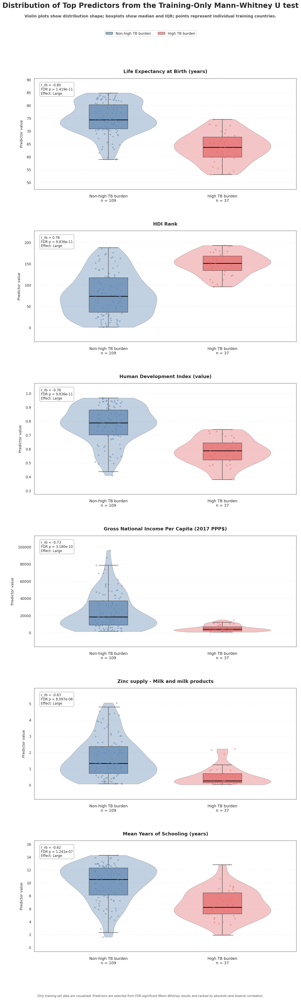

,feature,rank_biserial_correlation_high_minus_non_high,absolute_rank_biserial_correlation,mann_whitney_p_value_fdr_bh,effect_size_magnitude,direction
0,Life Expectancy at Birth (years),-0.803868,0.803868,1.418745e-11,Large,Lower values in high TB burden
1,HDI Rank,0.757501,0.757501,9.835911e-11,Large,Higher values in high TB burden
2,Human Development Index (value),-0.757501,0.757501,9.835911e-11,Large,Lower values in high TB burden
3,Gross National Income Per Capita (2017 PPP$),-0.734193,0.734193,3.180270e-10,Large,Lower values in high TB burden
4,Zinc supply - Milk and milk products,-0.634267,0.634267,8.097265e-08,Large,Lower values in high TB burden
5,Mean Years of Schooling (years),-0.622861,0.622861,1.240667e-07,Large,Lower values in high TB burden


Mann–Whitney distribution visualization completed successfully.
Top predictors visualized: 6
PNG: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/14_mann_whitney_u_test_top_predictors_distribution_violin_boxplots_large_panels.png
PDF: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/14_mann_whitney_u_test_top_predictors_distribution_violin_boxplots_large_panels.pdf
Plot data CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/14_mann_whitney_u_test_top_predictors_distribution_plot_data_large_panels.csv
Plot data Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/14_mann_whitney_u_test_top_predictors_distribution_plot_data_large_panels.xlsx
Top predictors visualized:
1. Life Expectancy at Birth (years)
2. HDI Rank
3. Human Development Index (value)
4. Gross National Income Per Capita (2017 PPP$)
5. Zinc supply - Milk and milk products
6. Mean Years of Schooling (years)


In [58]:
# Step 6C: Large-panel distribution visualization for top predictors
# from the training-only Mann–Whitney U test

# This visualization complements the Mann–Whitney U test by showing the
# group distributions of the strongest FDR-significant predictors.
#
# The Mann–Whitney U test is rank-based / distribution-based, so violin plots
# are useful because they show the distribution shape, spread, overlap and
# group separation between:
#   1) Non-high TB burden countries
#   2) High TB burden countries
#
# Important:
# - Only training-set data are used.
# - The test set remains untouched.
# - This visualization is descriptive and supports interpretation of the
#   Mann–Whitney screening results.
# - It should not be interpreted causally.

import math
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

required_mann_whitney_distribution_objects = [
    "X_screening_train",
    "y_screening_train",
    "mann_whitney_screening_results",
    "TABLES_DIR",
    "FIGURES_DIR"
]

missing_mann_whitney_distribution_objects = [
    object_name
    for object_name in required_mann_whitney_distribution_objects
    if object_name not in globals()
]

if missing_mann_whitney_distribution_objects:
    raise NameError(
        "Missing required objects for Mann–Whitney distribution visualization. "
        f"Missing objects: {missing_mann_whitney_distribution_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_dpi = FIGURE_DPI if "FIGURE_DPI" in globals() else 300

TOP_N_MANN_WHITNEY_DISTRIBUTION_PLOTS = 6
FEATURE_TITLE_WRAP_WIDTH = 62

required_mann_whitney_distribution_columns = [
    "feature",
    "absolute_rank_biserial_correlation",
    "rank_biserial_correlation_high_minus_non_high",
    "mann_whitney_p_value_fdr_bh",
    "significant_after_fdr_0_05",
    "effect_size_magnitude",
    "direction"
]

missing_mann_whitney_distribution_columns = [
    column
    for column in required_mann_whitney_distribution_columns
    if column not in mann_whitney_screening_results.columns
]

if missing_mann_whitney_distribution_columns:
    raise KeyError(
        "Missing required columns in mann_whitney_screening_results: "
        f"{missing_mann_whitney_distribution_columns}"
    )

mann_whitney_top_distribution_predictors = (
    mann_whitney_screening_results[
        mann_whitney_screening_results["significant_after_fdr_0_05"]
    ]
    .dropna(
        subset=[
            "absolute_rank_biserial_correlation",
            "rank_biserial_correlation_high_minus_non_high",
            "mann_whitney_p_value_fdr_bh"
        ]
    )
    .sort_values(
        by="absolute_rank_biserial_correlation",
        ascending=False
    )
    .head(TOP_N_MANN_WHITNEY_DISTRIBUTION_PLOTS)
    .copy()
    .reset_index(drop=True)
)

if mann_whitney_top_distribution_predictors.empty:
    raise ValueError(
        "No FDR-significant Mann–Whitney predictors are available for distribution visualization."
    )

top_mann_whitney_predictor_names = (
    mann_whitney_top_distribution_predictors["feature"]
    .tolist()
)

missing_top_mann_whitney_predictors = [
    predictor_name
    for predictor_name in top_mann_whitney_predictor_names
    if predictor_name not in X_screening_train.columns
]

if missing_top_mann_whitney_predictors:
    raise KeyError(
        "The following top Mann–Whitney predictors are missing from X_screening_train: "
        f"{missing_top_mann_whitney_predictors}"
    )

mann_whitney_distribution_plot_data = (
    X_screening_train[top_mann_whitney_predictor_names]
    .copy()
)

mann_whitney_distribution_plot_data["high_tb_burden"] = (
    y_screening_train
    .astype(int)
    .values
)

mann_whitney_distribution_plot_data["TB burden group"] = (
    mann_whitney_distribution_plot_data["high_tb_burden"]
    .map({
        0: "Non-high TB burden",
        1: "High TB burden"
    })
)

group_order = [
    "Non-high TB burden",
    "High TB burden"
]

group_colors = {
    "Non-high TB burden": "#4C78A8",
    "High TB burden": "#E15759"
}

non_high_n = int((y_screening_train == 0).sum())
high_n = int((y_screening_train == 1).sum())

x_tick_labels = [
    f"Non-high TB burden\nn = {non_high_n}",
    f"High TB burden\nn = {high_n}"
]

n_predictors = len(top_mann_whitney_predictor_names)

# IMPORTANT CHANGE:
# One subplot per row. This gives every violin + boxplot panel much more space.
n_columns = 1
n_rows = n_predictors

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_columns,
    figsize=(13.0, 7.0 * n_rows)
)

if n_predictors == 1:
    axes = np.array([axes])

axes = np.array(axes).reshape(-1)

random_generator = np.random.default_rng(42)


def wrap_predictor_title(predictor_name, width=62):
    return "\n".join(
        textwrap.wrap(
            str(predictor_name),
            width=width
        )
    )


for ax, predictor_name in zip(axes, top_mann_whitney_predictor_names):
    non_high_values = (
        mann_whitney_distribution_plot_data.loc[
            mann_whitney_distribution_plot_data["TB burden group"] == "Non-high TB burden",
            predictor_name
        ]
        .dropna()
        .astype(float)
        .values
    )

    high_values = (
        mann_whitney_distribution_plot_data.loc[
            mann_whitney_distribution_plot_data["TB burden group"] == "High TB burden",
            predictor_name
        ]
        .dropna()
        .astype(float)
        .values
    )

    values_to_plot = [
        non_high_values,
        high_values
    ]

    combined_values = np.concatenate(values_to_plot)

    y_min = np.nanmin(combined_values)
    y_max = np.nanmax(combined_values)
    y_range = y_max - y_min

    if y_range == 0:
        y_padding = 1
    else:
        y_padding = 0.18 * y_range

    ax.set_ylim(
        y_min - y_padding,
        y_max + y_padding
    )

    # Violin plot: distribution shape
    violin_parts = ax.violinplot(
        values_to_plot,
        positions=[1, 2],
        widths=0.85,
        showmeans=False,
        showmedians=False,
        showextrema=False
    )

    for body, group_name in zip(violin_parts["bodies"], group_order):
        body.set_facecolor(group_colors[group_name])
        body.set_edgecolor("#333333")
        body.set_alpha(0.34)
        body.set_linewidth(1.0)
        body.set_zorder(1)

    # Boxplot overlay: median, IQR, whiskers
    boxplot_parts = ax.boxplot(
        values_to_plot,
        positions=[1, 2],
        widths=0.34,
        patch_artist=True,
        showfliers=False,
        medianprops=dict(
            color="black",
            linewidth=2.0
        ),
        whiskerprops=dict(
            color="#555555",
            linewidth=1.35
        ),
        capprops=dict(
            color="#555555",
            linewidth=1.35
        ),
        boxprops=dict(
            edgecolor="#333333",
            linewidth=1.35
        )
    )

    for patch, group_name in zip(boxplot_parts["boxes"], group_order):
        patch.set_facecolor(group_colors[group_name])
        patch.set_alpha(0.62)
        patch.set_zorder(2)

    # Individual observations with jitter
    for x_position, group_name, group_values in zip(
        [1, 2],
        group_order,
        values_to_plot
    ):
        jitter = random_generator.uniform(
            low=-0.12,
            high=0.12,
            size=len(group_values)
        )

        ax.scatter(
            np.full(len(group_values), x_position) + jitter,
            group_values,
            s=25,
            alpha=0.42,
            color=group_colors[group_name],
            edgecolors="white",
            linewidths=0.25,
            zorder=3
        )

    predictor_result = (
        mann_whitney_top_distribution_predictors[
            mann_whitney_top_distribution_predictors["feature"] == predictor_name
        ]
        .iloc[0]
    )

    wrapped_predictor_title = wrap_predictor_title(
        predictor_name,
        width=FEATURE_TITLE_WRAP_WIDTH
    )

    ax.set_title(
        wrapped_predictor_title,
        fontsize=14,
        fontweight="bold",
        pad=16
    )

    ax.set_xticks([1, 2])

    ax.set_xticklabels(
        x_tick_labels,
        fontsize=11.5
    )

    ax.tick_params(
        axis="x",
        pad=9
    )

    ax.tick_params(
        axis="y",
        labelsize=10.5
    )

    ax.set_ylabel(
        "Predictor value",
        fontsize=11,
        labelpad=10
    )

    ax.set_xlim(0.35, 2.65)

    ax.yaxis.grid(
        True,
        linestyle="--",
        linewidth=0.7,
        alpha=0.30
    )

    ax.xaxis.grid(False)

    for spine_name in ["top", "right", "bottom", "left"]:
        ax.spines[spine_name].set_visible(True)
        ax.spines[spine_name].set_linewidth(0.95)
        ax.spines[spine_name].set_color("#666666")

    annotation_text = (
        f"r_rb = "
        f"{predictor_result['rank_biserial_correlation_high_minus_non_high']:.2f}\n"
        f"FDR p = "
        f"{predictor_result['mann_whitney_p_value_fdr_bh']:.3e}\n"
        f"Effect: "
        f"{predictor_result['effect_size_magnitude']}"
    )

    ax.text(
        0.025,
        0.955,
        annotation_text,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor="#999999",
            alpha=0.92
        ),
        zorder=5
    )

# Hide unused axes if needed.
for ax in axes[n_predictors:]:
    ax.axis("off")

legend_handles = [
    Patch(
        facecolor=group_colors["Non-high TB burden"],
        edgecolor="#333333",
        alpha=0.60,
        label="Non-high TB burden"
    ),
    Patch(
        facecolor=group_colors["High TB burden"],
        edgecolor="#333333",
        alpha=0.60,
        label="High TB burden"
    )
]

fig.suptitle(
    "Distribution of Top Predictors from the Training-Only Mann–Whitney U test",
    fontsize=21,
    fontweight="bold",
    y=0.996
)

fig.text(
    0.5,
    0.984,
    (
        "Violin plots show distribution shape; boxplots show median and IQR; "
        "points represent individual training countries."
    ),
    ha="center",
    va="top",
    fontsize=11.5,
    fontweight="semibold",
    color="#4D4D4D"
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.970),
    ncol=2,
    frameon=True,
    fontsize=10.5
)

fig.text(
    0.5,
    0.012,
    (
        "Only training-set data are visualized. Predictors are selected from "
        "FDR-significant Mann–Whitney results and ranked by absolute rank-biserial correlation."
    ),
    ha="center",
    va="bottom",
    fontsize=8.8,
    color="#4D4D4D",
    style="italic"
)

plt.tight_layout(
    rect=[
        0.04,
        0.04,
        0.98,
        0.945
    ],
    h_pad=4.8
)

mann_whitney_distribution_plot_path = (
    FIGURES_DIR / "14_mann_whitney_u_test_top_predictors_distribution_violin_boxplots_large_panels.png"
)

mann_whitney_distribution_plot_pdf_path = (
    FIGURES_DIR / "14_mann_whitney_u_test_top_predictors_distribution_violin_boxplots_large_panels.pdf"
)

mann_whitney_distribution_plot_data_csv_path = (
    TABLES_DIR / "14_mann_whitney_u_test_top_predictors_distribution_plot_data_large_panels.csv"
)

mann_whitney_distribution_plot_data_excel_path = (
    TABLES_DIR / "14_mann_whitney_u_test_top_predictors_distribution_plot_data_large_panels.xlsx"
)

mann_whitney_distribution_plot_data.to_csv(
    mann_whitney_distribution_plot_data_csv_path,
    index=False
)

mann_whitney_distribution_plot_data.to_excel(
    mann_whitney_distribution_plot_data_excel_path,
    index=False
)

fig.savefig(
    mann_whitney_distribution_plot_path,
    dpi=figure_dpi,
    bbox_inches="tight"
)

fig.savefig(
    mann_whitney_distribution_plot_pdf_path,
    bbox_inches="tight"
)

plt.show()

display(
    mann_whitney_top_distribution_predictors[
        [
            "feature",
            "rank_biserial_correlation_high_minus_non_high",
            "absolute_rank_biserial_correlation",
            "mann_whitney_p_value_fdr_bh",
            "effect_size_magnitude",
            "direction"
        ]
    ]
)

print("Mann–Whitney distribution visualization completed successfully.")
print("Top predictors visualized:", len(top_mann_whitney_predictor_names))
print("PNG:", mann_whitney_distribution_plot_path)
print("PDF:", mann_whitney_distribution_plot_pdf_path)
print("Plot data CSV:", mann_whitney_distribution_plot_data_csv_path)
print("Plot data Excel:", mann_whitney_distribution_plot_data_excel_path)

print("Top predictors visualized:")
for index, predictor_name in enumerate(top_mann_whitney_predictor_names, start=1):
    print(f"{index}. {predictor_name}")

In [59]:
# Step 7A: Combined training-only screening summary and candidate predictor selection

# This cell combines the training-only screening results from:
#   1) Welch's t-test with Hedges' g effect sizes
#   2) Mann–Whitney U test with rank-biserial effect sizes
#
# Purpose:
#   To define an initial set of candidate predictors before multicollinearity analysis.
#
# Candidate predictor retention policy:
#
#   A predictor is retained as a candidate before multicollinearity pruning if:
#
#   1) It has statistical evidence of group separation:
#          Welch FDR-adjusted p-value < 0.05
#          OR
#          Mann–Whitney FDR-adjusted p-value < 0.05
#
#      AND
#
#   2) It has a practically meaningful effect size:
#          |Hedges' g| >= 0.50
#          OR
#          |rank-biserial correlation| >= 0.30
#
# Important:
# - This step uses only training-set screening results.
# - The test set remains untouched.
# - This step creates candidate predictors before multicollinearity pruning.
# - This is not the final predictor set.
# - Hedges' g is taken from the Welch's t-test results.
# - Hedges' g and rank-biserial correlation are kept as separate effect-size measures.

import numpy as np
import pandas as pd

COMBINED_SCREENING_FDR_ALPHA = 0.05

MIN_ABSOLUTE_HEDGES_G_FOR_RETENTION = 0.50
MIN_ABSOLUTE_RANK_BISERIAL_FOR_RETENTION = 0.30

TOP_N_COMBINED_SCREENING_DISPLAY = 30

required_combined_screening_objects = [
    "welch_screening_results",
    "mann_whitney_screening_results",
    "screening_predictor_cols",
    "TABLES_DIR"
]

missing_combined_screening_objects = [
    object_name for object_name in required_combined_screening_objects
    if object_name not in globals()
]

if missing_combined_screening_objects:
    raise NameError(
        "Missing required objects for combined screening summary. "
        "Run Welch's t-test with Hedges' g and Mann–Whitney U test first. "
        f"Missing objects: {missing_combined_screening_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(screening_predictor_cols, (list, tuple, pd.Index)):
    raise TypeError(
        "screening_predictor_cols must be a list, tuple, or pandas Index."
    )

screening_predictor_cols = list(screening_predictor_cols)

if len(screening_predictor_cols) == 0:
    raise ValueError(
        "screening_predictor_cols is empty. No predictors are available for screening."
    )

if len(screening_predictor_cols) != len(set(screening_predictor_cols)):
    raise ValueError(
        "screening_predictor_cols contains duplicated predictor names."
    )


# -------------------------------------------------------------------
# 1. Validation
# -------------------------------------------------------------------

required_welch_columns = [
    "feature",
    "welch_p_value_fdr_bh",
    "significant_after_fdr_0_05",
    "hedges_g_high_minus_non_high",
    "absolute_hedges_g",
    "effect_size_magnitude",
    "direction"
]

required_mann_whitney_columns = [
    "feature",
    "mann_whitney_p_value_fdr_bh",
    "significant_after_fdr_0_05",
    "rank_biserial_correlation_high_minus_non_high",
    "absolute_rank_biserial_correlation",
    "effect_size_magnitude",
    "direction"
]


def validate_screening_table(table_name, table, required_columns):
    if not isinstance(table, pd.DataFrame):
        raise TypeError(
            f"{table_name} must be a pandas DataFrame."
        )

    missing_columns = [
        column for column in required_columns
        if column not in table.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing required columns in {table_name}: {missing_columns}"
        )

    if table["feature"].duplicated().any():
        duplicated_features = (
            table.loc[table["feature"].duplicated(), "feature"]
            .tolist()
        )

        raise ValueError(
            f"{table_name} contains duplicated feature names: {duplicated_features}"
        )


validate_screening_table(
    "welch_screening_results",
    welch_screening_results,
    required_welch_columns
)

validate_screening_table(
    "mann_whitney_screening_results",
    mann_whitney_screening_results,
    required_mann_whitney_columns
)


# -------------------------------------------------------------------
# 2. Prepare Welch source table
# -------------------------------------------------------------------

welch_source = welch_screening_results.copy()

# Optional columns from the improved Welch cell.
# If they do not exist, keep the combined cell robust by filling them.
optional_welch_columns_with_defaults = {
    "welch_t_statistic": np.nan,
    "welch_degrees_of_freedom": np.nan,
    "mean_difference_high_minus_non_high": np.nan,
    "mean_difference_95_ci_lower": np.nan,
    "mean_difference_95_ci_upper": np.nan,
    "mean_difference_95_ci_includes_zero": np.nan,
    "cohens_d_high_minus_non_high": np.nan,
    "hedges_g_standard_error": np.nan,
    "hedges_g_95_ci_lower": np.nan,
    "hedges_g_95_ci_upper": np.nan,
    "hedges_g_95_ci_includes_zero": np.nan
}

for column, default_value in optional_welch_columns_with_defaults.items():
    if column not in welch_source.columns:
        welch_source[column] = default_value

if "mean_difference_direction" not in welch_source.columns:
    welch_source["mean_difference_direction"] = welch_source["direction"]

welch_for_combined = (
    welch_source[
        [
            "feature",
            "welch_p_value_fdr_bh",
            "significant_after_fdr_0_05",
            "welch_t_statistic",
            "welch_degrees_of_freedom",
            "mean_difference_high_minus_non_high",
            "mean_difference_95_ci_lower",
            "mean_difference_95_ci_upper",
            "mean_difference_95_ci_includes_zero",
            "cohens_d_high_minus_non_high",
            "hedges_g_high_minus_non_high",
            "hedges_g_standard_error",
            "hedges_g_95_ci_lower",
            "hedges_g_95_ci_upper",
            "hedges_g_95_ci_includes_zero",
            "absolute_hedges_g",
            "effect_size_magnitude",
            "mean_difference_direction"
        ]
    ]
    .rename(
        columns={
            "welch_p_value_fdr_bh": "welch_fdr_p_value",
            "significant_after_fdr_0_05": "welch_fdr_significant_0_05",
            "mean_difference_high_minus_non_high": "welch_mean_difference_high_minus_non_high",
            "mean_difference_95_ci_lower": "welch_mean_difference_95_ci_lower",
            "mean_difference_95_ci_upper": "welch_mean_difference_95_ci_upper",
            "mean_difference_95_ci_includes_zero": "welch_mean_difference_95_ci_includes_zero",
            "cohens_d_high_minus_non_high": "welch_cohens_d_high_minus_non_high",
            "hedges_g_high_minus_non_high": "welch_hedges_g_high_minus_non_high",
            "hedges_g_standard_error": "welch_hedges_g_standard_error",
            "hedges_g_95_ci_lower": "welch_hedges_g_95_ci_lower",
            "hedges_g_95_ci_upper": "welch_hedges_g_95_ci_upper",
            "hedges_g_95_ci_includes_zero": "welch_hedges_g_95_ci_includes_zero",
            "absolute_hedges_g": "welch_absolute_hedges_g",
            "effect_size_magnitude": "welch_hedges_g_magnitude",
            "mean_difference_direction": "welch_direction"
        }
    )
    .copy()
)


# -------------------------------------------------------------------
# 3. Prepare Mann–Whitney source table
# -------------------------------------------------------------------

mann_whitney_for_combined = (
    mann_whitney_screening_results[
        [
            "feature",
            "mann_whitney_p_value_fdr_bh",
            "significant_after_fdr_0_05",
            "rank_biserial_correlation_high_minus_non_high",
            "absolute_rank_biserial_correlation",
            "effect_size_magnitude",
            "direction"
        ]
    ]
    .rename(
        columns={
            "mann_whitney_p_value_fdr_bh": "mann_whitney_fdr_p_value",
            "significant_after_fdr_0_05": "mann_whitney_fdr_significant_0_05",
            "rank_biserial_correlation_high_minus_non_high": "mann_whitney_rank_biserial_high_minus_non_high",
            "absolute_rank_biserial_correlation": "mann_whitney_absolute_rank_biserial",
            "effect_size_magnitude": "mann_whitney_rank_biserial_magnitude",
            "direction": "mann_whitney_direction"
        }
    )
    .copy()
)


# -------------------------------------------------------------------
# 4. Merge tables
# -------------------------------------------------------------------

combined_screening_summary = pd.DataFrame({
    "feature": screening_predictor_cols
})

combined_screening_summary = (
    combined_screening_summary
    .merge(
        welch_for_combined,
        on="feature",
        how="left"
    )
    .merge(
        mann_whitney_for_combined,
        on="feature",
        how="left"
    )
)

missing_welch_rows = combined_screening_summary[
    combined_screening_summary["welch_fdr_p_value"].isna()
]["feature"].tolist()

missing_mann_whitney_rows = combined_screening_summary[
    combined_screening_summary["mann_whitney_fdr_p_value"].isna()
]["feature"].tolist()

if missing_welch_rows:
    raise ValueError(
        "Some predictors are missing Welch results: "
        f"{missing_welch_rows}"
    )

if missing_mann_whitney_rows:
    raise ValueError(
        "Some predictors are missing Mann–Whitney results: "
        f"{missing_mann_whitney_rows}"
    )


# -------------------------------------------------------------------
# 5. Convert numeric columns safely
# -------------------------------------------------------------------

numeric_columns_to_convert = [
    "welch_fdr_p_value",
    "mann_whitney_fdr_p_value",
    "welch_t_statistic",
    "welch_degrees_of_freedom",
    "welch_mean_difference_high_minus_non_high",
    "welch_mean_difference_95_ci_lower",
    "welch_mean_difference_95_ci_upper",
    "welch_cohens_d_high_minus_non_high",
    "welch_hedges_g_high_minus_non_high",
    "welch_hedges_g_standard_error",
    "welch_hedges_g_95_ci_lower",
    "welch_hedges_g_95_ci_upper",
    "welch_absolute_hedges_g",
    "mann_whitney_rank_biserial_high_minus_non_high",
    "mann_whitney_absolute_rank_biserial"
]

for column in numeric_columns_to_convert:
    combined_screening_summary[column] = pd.to_numeric(
        combined_screening_summary[column],
        errors="coerce"
    )


# -------------------------------------------------------------------
# 6. Statistical evidence flags
# -------------------------------------------------------------------

combined_screening_summary["has_mean_based_statistical_evidence"] = (
    combined_screening_summary["welch_fdr_p_value"]
    < COMBINED_SCREENING_FDR_ALPHA
)

combined_screening_summary["has_rank_based_statistical_evidence"] = (
    combined_screening_summary["mann_whitney_fdr_p_value"]
    < COMBINED_SCREENING_FDR_ALPHA
)

combined_screening_summary["has_any_statistical_evidence"] = (
    combined_screening_summary["has_mean_based_statistical_evidence"]
    | combined_screening_summary["has_rank_based_statistical_evidence"]
)


# -------------------------------------------------------------------
# 7. Practical effect-size flags
# -------------------------------------------------------------------

combined_screening_summary["has_mean_based_practical_effect"] = (
    combined_screening_summary["welch_absolute_hedges_g"]
    >= MIN_ABSOLUTE_HEDGES_G_FOR_RETENTION
)

combined_screening_summary["has_rank_based_practical_effect"] = (
    combined_screening_summary["mann_whitney_absolute_rank_biserial"]
    >= MIN_ABSOLUTE_RANK_BISERIAL_FOR_RETENTION
)

combined_screening_summary["has_any_practical_effect"] = (
    combined_screening_summary["has_mean_based_practical_effect"]
    | combined_screening_summary["has_rank_based_practical_effect"]
)


# -------------------------------------------------------------------
# 8. Candidate retention flag
# -------------------------------------------------------------------

combined_screening_summary["retained_as_candidate_before_collinearity"] = (
    combined_screening_summary["has_any_statistical_evidence"]
    & combined_screening_summary["has_any_practical_effect"]
)


# -------------------------------------------------------------------
# 9. Evidence source counts
# -------------------------------------------------------------------

combined_screening_summary["statistical_evidence_source_count"] = (
    combined_screening_summary[
        [
            "has_mean_based_statistical_evidence",
            "has_rank_based_statistical_evidence"
        ]
    ]
    .astype(int)
    .sum(axis=1)
)

combined_screening_summary["practical_effect_source_count"] = (
    combined_screening_summary[
        [
            "has_mean_based_practical_effect",
            "has_rank_based_practical_effect"
        ]
    ]
    .astype(int)
    .sum(axis=1)
)

combined_screening_summary["minimum_fdr_p_value"] = (
    combined_screening_summary[
        [
            "welch_fdr_p_value",
            "mann_whitney_fdr_p_value"
        ]
    ]
    .min(axis=1)
)


# -------------------------------------------------------------------
# 10. Direction consistency
# -------------------------------------------------------------------

def normalize_direction(direction_value):
    direction_text = str(direction_value).lower()

    if "higher" in direction_text:
        return "Higher in high TB burden"

    if "lower" in direction_text:
        return "Lower in high TB burden"

    if (
        "no" in direction_text
        or "similar" in direction_text
        or "not available" in direction_text
        or direction_text == "nan"
    ):
        return "No clear direction"

    return "No clear direction"


combined_screening_summary["welch_direction_normalized"] = (
    combined_screening_summary["welch_direction"]
    .apply(normalize_direction)
)

combined_screening_summary["mann_whitney_direction_normalized"] = (
    combined_screening_summary["mann_whitney_direction"]
    .apply(normalize_direction)
)


def assign_direction_consistency(row):
    welch_direction = row["welch_direction_normalized"]
    mann_whitney_direction = row["mann_whitney_direction_normalized"]

    if (
        welch_direction == "No clear direction"
        or mann_whitney_direction == "No clear direction"
    ):
        return "Direction not fully comparable"

    if welch_direction == mann_whitney_direction:
        return "Consistent direction"

    return "Inconsistent direction"


combined_screening_summary["direction_consistency"] = (
    combined_screening_summary
    .apply(assign_direction_consistency, axis=1)
)


# -------------------------------------------------------------------
# 11. Evidence tier and decision reason
# -------------------------------------------------------------------

def assign_screening_evidence_tier(row):
    if (
        row["statistical_evidence_source_count"] == 2
        and row["practical_effect_source_count"] == 2
    ):
        return "Strong candidate: both statistical tests and both effect-size criteria"

    if (
        row["has_any_statistical_evidence"]
        and row["has_any_practical_effect"]
    ):
        return "Candidate: statistical evidence and practical effect"

    if (
        row["has_any_statistical_evidence"]
        and not row["has_any_practical_effect"]
    ):
        return "Not retained: statistical evidence only"

    if (
        not row["has_any_statistical_evidence"]
        and row["has_any_practical_effect"]
    ):
        return "Not retained: practical effect only"

    return "Not retained: insufficient evidence"


combined_screening_summary["screening_evidence_tier"] = (
    combined_screening_summary
    .apply(assign_screening_evidence_tier, axis=1)
)


def assign_retention_decision_reason(row):
    if row["retained_as_candidate_before_collinearity"]:
        return (
            "Retained before collinearity: predictor has statistical evidence "
            "and at least one practically meaningful effect size."
        )

    if (
        not row["has_any_statistical_evidence"]
        and not row["has_any_practical_effect"]
    ):
        return (
            "Not retained before collinearity: predictor lacks both statistical "
            "evidence and practically meaningful effect size."
        )

    if (
        row["has_any_statistical_evidence"]
        and not row["has_any_practical_effect"]
    ):
        return (
            "Not retained before collinearity: predictor has statistical evidence "
            "but effect size is below the practical threshold."
        )

    if (
        not row["has_any_statistical_evidence"]
        and row["has_any_practical_effect"]
    ):
        return (
            "Not retained before collinearity: predictor has practical effect size "
            "but no FDR-significant statistical evidence."
        )

    return "Not retained before collinearity: unspecified reason."


combined_screening_summary["retention_decision_reason"] = (
    combined_screening_summary
    .apply(assign_retention_decision_reason, axis=1)
)


# -------------------------------------------------------------------
# 12. Sorting and priority order
# -------------------------------------------------------------------

combined_screening_summary = (
    combined_screening_summary
    .sort_values(
        by=[
            "retained_as_candidate_before_collinearity",
            "statistical_evidence_source_count",
            "practical_effect_source_count",
            "minimum_fdr_p_value",
            "welch_absolute_hedges_g",
            "mann_whitney_absolute_rank_biserial"
        ],
        ascending=[
            False,
            False,
            False,
            True,
            False,
            False
        ],
        na_position="last"
    )
    .reset_index(drop=True)
)

combined_screening_summary.insert(
    0,
    "screening_priority_order",
    range(1, len(combined_screening_summary) + 1)
)


# -------------------------------------------------------------------
# 13. Candidate and non-retained tables
# -------------------------------------------------------------------

candidate_predictors_before_collinearity = (
    combined_screening_summary.loc[
        combined_screening_summary["retained_as_candidate_before_collinearity"],
        "feature"
    ]
    .tolist()
)

candidate_predictors_before_collinearity_table = (
    combined_screening_summary.loc[
        combined_screening_summary["retained_as_candidate_before_collinearity"],
        [
            "screening_priority_order",
            "feature",
            "screening_evidence_tier",
            "minimum_fdr_p_value",
            "welch_fdr_p_value",
            "mann_whitney_fdr_p_value",
            "welch_absolute_hedges_g",
            "mann_whitney_absolute_rank_biserial",
            "statistical_evidence_source_count",
            "practical_effect_source_count",
            "direction_consistency",
            "retention_decision_reason"
        ]
    ]
    .copy()
    .rename(
        columns={
            "feature": "candidate_predictor_before_collinearity"
        }
    )
)

non_retained_predictors_table = (
    combined_screening_summary.loc[
        ~combined_screening_summary["retained_as_candidate_before_collinearity"],
        [
            "screening_priority_order",
            "feature",
            "screening_evidence_tier",
            "minimum_fdr_p_value",
            "welch_fdr_p_value",
            "mann_whitney_fdr_p_value",
            "welch_absolute_hedges_g",
            "mann_whitney_absolute_rank_biserial",
            "statistical_evidence_source_count",
            "practical_effect_source_count",
            "direction_consistency",
            "retention_decision_reason"
        ]
    ]
    .copy()
    .rename(
        columns={
            "feature": "non_retained_predictor_before_collinearity"
        }
    )
)


# -------------------------------------------------------------------
# 14. Counts summary
# -------------------------------------------------------------------

combined_screening_counts = pd.DataFrame({
    "item": [
        "Predictors evaluated",
        "Welch FDR-significant predictors",
        "Mann-Whitney FDR-significant predictors",
        "Predictors with any statistical evidence",
        "Predictors with mean-based practical effect",
        "Predictors with rank-based practical effect",
        "Predictors with any practical effect",
        "Candidate predictors before collinearity",
        "Non-retained predictors before collinearity",
        "Predictors with consistent Welch and Mann-Whitney direction",
        "FDR alpha",
        "Minimum absolute Hedges g for retention",
        "Minimum absolute rank-biserial correlation for retention"
    ],
    "value": [
        len(combined_screening_summary),
        int(combined_screening_summary["has_mean_based_statistical_evidence"].sum()),
        int(combined_screening_summary["has_rank_based_statistical_evidence"].sum()),
        int(combined_screening_summary["has_any_statistical_evidence"].sum()),
        int(combined_screening_summary["has_mean_based_practical_effect"].sum()),
        int(combined_screening_summary["has_rank_based_practical_effect"].sum()),
        int(combined_screening_summary["has_any_practical_effect"].sum()),
        len(candidate_predictors_before_collinearity),
        len(non_retained_predictors_table),
        int((combined_screening_summary["direction_consistency"] == "Consistent direction").sum()),
        COMBINED_SCREENING_FDR_ALPHA,
        MIN_ABSOLUTE_HEDGES_G_FOR_RETENTION,
        MIN_ABSOLUTE_RANK_BISERIAL_FOR_RETENTION
    ]
})


# -------------------------------------------------------------------
# 15. Save outputs
# -------------------------------------------------------------------

combined_screening_summary_table_path_csv = (
    TABLES_DIR / "16_combined_training_only_screening_summary.csv"
)

combined_screening_summary_table_path_excel = (
    TABLES_DIR / "16_combined_training_only_screening_summary.xlsx"
)

candidate_predictors_before_collinearity_table_path_csv = (
    TABLES_DIR / "16_candidate_predictors_before_collinearity.csv"
)

candidate_predictors_before_collinearity_table_path_excel = (
    TABLES_DIR / "16_candidate_predictors_before_collinearity.xlsx"
)

non_retained_predictors_table_path_csv = (
    TABLES_DIR / "16_non_retained_predictors_before_collinearity.csv"
)

non_retained_predictors_table_path_excel = (
    TABLES_DIR / "16_non_retained_predictors_before_collinearity.xlsx"
)

combined_screening_counts_path_csv = (
    TABLES_DIR / "16_combined_training_only_screening_counts.csv"
)

combined_screening_counts_path_excel = (
    TABLES_DIR / "16_combined_training_only_screening_counts.xlsx"
)

combined_screening_summary.to_csv(
    combined_screening_summary_table_path_csv,
    index=False
)

combined_screening_summary.to_excel(
    combined_screening_summary_table_path_excel,
    index=False
)

candidate_predictors_before_collinearity_table.to_csv(
    candidate_predictors_before_collinearity_table_path_csv,
    index=False
)

candidate_predictors_before_collinearity_table.to_excel(
    candidate_predictors_before_collinearity_table_path_excel,
    index=False
)

non_retained_predictors_table.to_csv(
    non_retained_predictors_table_path_csv,
    index=False
)

non_retained_predictors_table.to_excel(
    non_retained_predictors_table_path_excel,
    index=False
)

combined_screening_counts.to_csv(
    combined_screening_counts_path_csv,
    index=False
)

combined_screening_counts.to_excel(
    combined_screening_counts_path_excel,
    index=False
)


# -------------------------------------------------------------------
# 16. Display outputs
# -------------------------------------------------------------------

def format_combined_screening_display_table(display_table):
    display_table = display_table.copy()

    p_value_columns = [
        "minimum_fdr_p_value",
        "welch_fdr_p_value",
        "mann_whitney_fdr_p_value"
    ]

    numeric_columns_to_round = [
        "welch_t_statistic",
        "welch_degrees_of_freedom",
        "welch_mean_difference_high_minus_non_high",
        "welch_mean_difference_95_ci_lower",
        "welch_mean_difference_95_ci_upper",
        "welch_cohens_d_high_minus_non_high",
        "welch_hedges_g_high_minus_non_high",
        "welch_hedges_g_standard_error",
        "welch_hedges_g_95_ci_lower",
        "welch_hedges_g_95_ci_upper",
        "welch_absolute_hedges_g",
        "mann_whitney_rank_biserial_high_minus_non_high",
        "mann_whitney_absolute_rank_biserial"
    ]

    for column in numeric_columns_to_round:
        if column in display_table.columns:
            display_table[column] = display_table[column].round(4)

    for column in p_value_columns:
        if column in display_table.columns:
            display_table[column] = (
                display_table[column]
                .map(lambda value: f"{value:.3e}" if pd.notna(value) else "NA")
            )

    return display_table


combined_screening_summary_display = (
    format_combined_screening_display_table(
        combined_screening_summary
    )
)

candidate_predictors_display = (
    format_combined_screening_display_table(
        candidate_predictors_before_collinearity_table
    )
)

non_retained_predictors_display = (
    format_combined_screening_display_table(
        non_retained_predictors_table
    )
)

compact_combined_display_columns = [
    "screening_priority_order",
    "feature",
    "retained_as_candidate_before_collinearity",
    "screening_evidence_tier",
    "minimum_fdr_p_value",
    "welch_absolute_hedges_g",
    "mann_whitney_absolute_rank_biserial",
    "statistical_evidence_source_count",
    "practical_effect_source_count",
    "direction_consistency",
    "retention_decision_reason"
]

display(
    combined_screening_summary_display[
        compact_combined_display_columns
    ]
    .head(TOP_N_COMBINED_SCREENING_DISPLAY)
)

display(combined_screening_counts)

print("Candidate predictors before multicollinearity pruning:")

if len(candidate_predictors_before_collinearity) == 0:
    print("No predictors met the combined screening retention policy.")
else:
    display(candidate_predictors_display)

    for index, feature_name in enumerate(
        candidate_predictors_before_collinearity,
        start=1
    ):
        print(f"{index}. {feature_name}")

print("Non-retained predictors before multicollinearity pruning:")

if non_retained_predictors_display.empty:
    print("No predictors were excluded before collinearity pruning.")
else:
    display(non_retained_predictors_display)

print("Combined training-only screening summary completed successfully.")
print("Predictors evaluated:", len(combined_screening_summary))
print("Candidate predictors before collinearity:", len(candidate_predictors_before_collinearity))
print("Non-retained predictors before collinearity:", len(non_retained_predictors_table))
print("Combined summary saved as CSV:", combined_screening_summary_table_path_csv)
print("Combined summary saved as Excel:", combined_screening_summary_table_path_excel)
print("Candidate predictors saved as CSV:", candidate_predictors_before_collinearity_table_path_csv)
print("Candidate predictors saved as Excel:", candidate_predictors_before_collinearity_table_path_excel)
print("Non-retained predictors saved as CSV:", non_retained_predictors_table_path_csv)
print("Non-retained predictors saved as Excel:", non_retained_predictors_table_path_excel)
print("Screening counts saved as CSV:", combined_screening_counts_path_csv)
print("Screening counts saved as Excel:", combined_screening_counts_path_excel)

,screening_priority_order,feature,retained_as_candidate_before_collinearity,screening_evidence_tier,minimum_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,statistical_evidence_source_count,practical_effect_source_count,direction_consistency,retention_decision_reason
0,1,HDI Rank,True,Strong candidate: both statistical tests and b...,8.592e-19,1.5804,0.7575,2,2,Consistent direction,Retained before collinearity: predictor has st...
1,2,Gross National Income Per Capita (2017 PPP$),True,Strong candidate: both statistical tests and b...,4.465e-15,1.0860,0.7342,2,2,Consistent direction,Retained before collinearity: predictor has st...
2,3,Human Development Index (value),True,Strong candidate: both statistical tests and b...,3.374e-14,1.5792,0.7575,2,2,Consistent direction,Retained before collinearity: predictor has st...
3,4,Life Expectancy at Birth (years),True,Strong candidate: both statistical tests and b...,3.832e-14,1.8079,0.8039,2,2,Consistent direction,Retained before collinearity: predictor has st...
4,5,Zinc supply - Milk and milk products,True,Strong candidate: both statistical tests and b...,7.107e-11,1.0237,0.6343,2,2,Consistent direction,Retained before collinearity: predictor has st...
5,6,Energy supply - Fats and oils,True,Strong candidate: both statistical tests and b...,6.357e-10,0.9734,0.5631,2,2,Consistent direction,Retained before collinearity: predictor has st...
6,7,Protein supply - Milk and milk products,True,Strong candidate: both statistical tests and b...,9.238e-10,1.0056,0.6184,2,2,Consistent direction,Retained before collinearity: predictor has st...
7,8,Vitamin A supply (retinol activity equivalents...,True,Strong candidate: both statistical tests and b...,1.261e-09,0.8908,0.6144,2,2,Consistent direction,Retained before collinearity: predictor has st...
8,9,Mean Years of Schooling (years),True,Strong candidate: both statistical tests and b...,5.393e-09,1.1660,0.6229,2,2,Consistent direction,Retained before collinearity: predictor has st...
9,10,Expected Years of Schooling (years),True,Strong candidate: both statistical tests and b...,1.416e-08,1.1286,0.6149,2,2,Consistent direction,Retained before collinearity: predictor has st...


,item,value
0,Predictors evaluated,46.00
1,Welch FDR-significant predictors,23.00
2,Mann-Whitney FDR-significant predictors,32.00
3,Predictors with any statistical evidence,32.00
4,Predictors with mean-based practical effect,22.00
5,Predictors with rank-based practical effect,24.00
6,Predictors with any practical effect,27.00
7,Candidate predictors before collinearity,27.00
8,Non-retained predictors before collinearity,19.00
9,Predictors with consistent Welch and Mann-Whit...,45.00


Candidate predictors before multicollinearity pruning:


,screening_priority_order,candidate_predictor_before_collinearity,screening_evidence_tier,minimum_fdr_p_value,welch_fdr_p_value,mann_whitney_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,statistical_evidence_source_count,practical_effect_source_count,direction_consistency,retention_decision_reason
0,1,HDI Rank,Strong candidate: both statistical tests and b...,8.592e-19,8.592e-19,9.836e-11,1.5804,0.7575,2,2,Consistent direction,Retained before collinearity: predictor has st...
1,2,Gross National Income Per Capita (2017 PPP$),Strong candidate: both statistical tests and b...,4.465e-15,4.465e-15,3.180e-10,1.0860,0.7342,2,2,Consistent direction,Retained before collinearity: predictor has st...
2,3,Human Development Index (value),Strong candidate: both statistical tests and b...,3.374e-14,3.374e-14,9.836e-11,1.5792,0.7575,2,2,Consistent direction,Retained before collinearity: predictor has st...
3,4,Life Expectancy at Birth (years),Strong candidate: both statistical tests and b...,3.832e-14,3.832e-14,1.419e-11,1.8079,0.8039,2,2,Consistent direction,Retained before collinearity: predictor has st...
4,5,Zinc supply - Milk and milk products,Strong candidate: both statistical tests and b...,7.107e-11,7.107e-11,8.097e-08,1.0237,0.6343,2,2,Consistent direction,Retained before collinearity: predictor has st...
5,6,Energy supply - Fats and oils,Strong candidate: both statistical tests and b...,6.357e-10,6.357e-10,1.162e-06,0.9734,0.5631,2,2,Consistent direction,Retained before collinearity: predictor has st...
6,7,Protein supply - Milk and milk products,Strong candidate: both statistical tests and b...,9.238e-10,9.238e-10,1.282e-07,1.0056,0.6184,2,2,Consistent direction,Retained before collinearity: predictor has st...
7,8,Vitamin A supply (retinol activity equivalents...,Strong candidate: both statistical tests and b...,1.261e-09,1.261e-09,1.282e-07,0.8908,0.6144,2,2,Consistent direction,Retained before collinearity: predictor has st...
8,9,Mean Years of Schooling (years),Strong candidate: both statistical tests and b...,5.393e-09,5.393e-09,1.241e-07,1.1660,0.6229,2,2,Consistent direction,Retained before collinearity: predictor has st...
9,10,Expected Years of Schooling (years),Strong candidate: both statistical tests and b...,1.416e-08,1.416e-08,1.282e-07,1.1286,0.6149,2,2,Consistent direction,Retained before collinearity: predictor has st...


1. HDI Rank
2. Gross National Income Per Capita (2017 PPP$)
3. Human Development Index (value)
4. Life Expectancy at Birth (years)
5. Zinc supply - Milk and milk products
6. Energy supply - Fats and oils
7. Protein supply - Milk and milk products
8. Vitamin A supply (retinol activity equivalents) - Fats and oils
9. Mean Years of Schooling (years)
10. Expected Years of Schooling (years)
11. Vitamin A supply (retinol activity equivalents) - Milk and milk products
12. Calcium supply - Milk and milk products
13. Energy supply - Sweets and sugars
14. Protein supply - Meat and meat products
15. BCG_coverage_pct
16. Energy supply - Meat and meat products
17. Zinc supply - Meat and meat products
18. Vitamin C supply - Vegetables and their products
19. Vitamin C supply - Milk and milk products
20. Vitamin C supply - Beverages
21. Energy supply - Roots, tubers, plantains and their products
22. Iron supply - Roots, tubers, plantains and their products
23. Iron supply - Meat and meat products
24. 

,screening_priority_order,non_retained_predictor_before_collinearity,screening_evidence_tier,minimum_fdr_p_value,welch_fdr_p_value,mann_whitney_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,statistical_evidence_source_count,practical_effect_source_count,direction_consistency,retention_decision_reason
27,28,Iron supply - Cereals and their products,Not retained: statistical evidence only,2.814e-02,2.814e-02,4.565e-02,0.4287,0.2383,2,0,Consistent direction,Not retained before collinearity: predictor ha...
28,29,"Selenium supply - Fish, shellfish and their pr...",Not retained: statistical evidence only,1.271e-02,2.543e-01,1.271e-02,0.2780,0.2975,1,0,Consistent direction,Not retained before collinearity: predictor ha...
29,30,"Protein supply - Fish, shellfish and their pro...",Not retained: statistical evidence only,2.841e-02,4.174e-01,2.841e-02,0.2020,0.2641,1,0,Consistent direction,Not retained before collinearity: predictor ha...
30,31,"Vitamin B12 supply - Fish, shellfish and their...",Not retained: statistical evidence only,4.188e-02,4.311e-01,4.188e-02,0.1816,0.2465,1,0,Consistent direction,Not retained before collinearity: predictor ha...
31,32,"Vitamin B6 supply - Fish, shellfish and their ...",Not retained: statistical evidence only,4.556e-02,5.341e-01,4.556e-02,0.1570,0.2393,1,0,Consistent direction,Not retained before collinearity: predictor ha...
32,33,"Total saturated fatty acids supply - Fish, she...",Not retained: insufficient evidence,5.186e-02,5.820e-01,5.186e-02,0.1386,0.2299,0,0,Consistent direction,Not retained before collinearity: predictor la...
33,34,Iron supply - Vegetables and their products,Not retained: insufficient evidence,6.236e-02,3.662e-01,6.236e-02,0.2043,0.2199,0,0,Consistent direction,Not retained before collinearity: predictor la...
34,35,Protein supply - Cereals and their products,Not retained: insufficient evidence,6.243e-02,6.243e-02,6.754e-02,0.3984,0.2150,0,0,Consistent direction,Not retained before collinearity: predictor la...
35,36,Total monounsaturated fatty acids supply - Fis...,Not retained: insufficient evidence,8.525e-02,6.654e-01,8.525e-02,0.1079,0.2023,0,0,Consistent direction,Not retained before collinearity: predictor la...
36,37,Vitamin C supply - Fruits and their products,Not retained: insufficient evidence,9.387e-02,6.349e-01,9.387e-02,0.1309,0.1961,0,0,Consistent direction,Not retained before collinearity: predictor la...


Combined training-only screening summary completed successfully.
Predictors evaluated: 46
Candidate predictors before collinearity: 27
Non-retained predictors before collinearity: 19
Combined summary saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/16_combined_training_only_screening_summary.csv
Combined summary saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/16_combined_training_only_screening_summary.xlsx
Candidate predictors saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/16_candidate_predictors_before_collinearity.csv
Candidate predictors saved as Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/16_candidate_predictors_before_collinearity.xlsx
Non-retained predictors saved as CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/16_non_retained_predictors_before_collinearity.csv
Non-retained predictors saved as Excel: /content

/usr/local/lib/python3.12/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


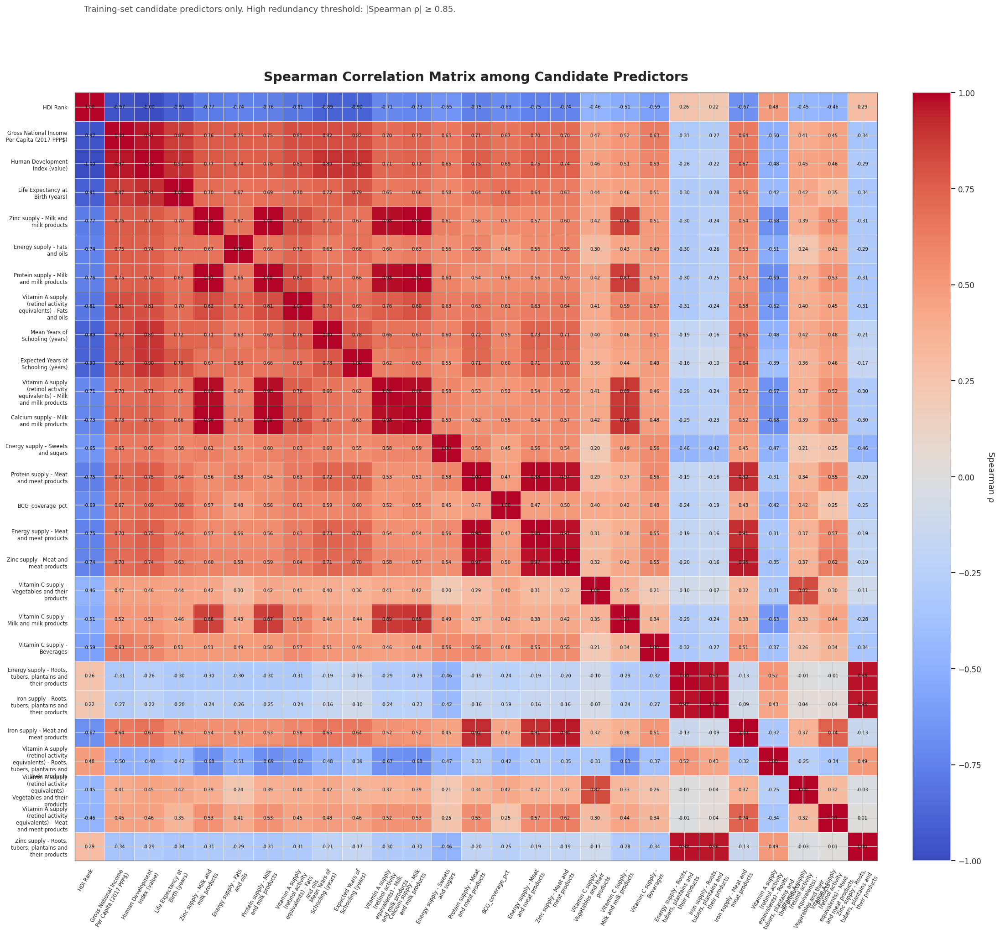

,item,value
0,Candidate predictors analyzed,27.00
1,Spearman high-correlation threshold,0.85
2,Highly correlated predictor pairs,29.00
3,Predictors included in high-correlation groups,18.00
4,High-correlation groups identified,4.00
5,Candidate predictors not in high-correlation g...,9.00


Highly correlated candidate predictor pairs:


,high_correlation_pair_rank,feature_1,feature_2,spearman_rho,absolute_spearman_rho,pairwise_non_missing_n,correlation_direction,feature_1_screening_priority_order,feature_2_screening_priority_order,preliminary_preferred_feature_by_screening_priority,lower_priority_feature_in_pair,feature_1_minimum_fdr_p_value,feature_2_minimum_fdr_p_value,feature_1_absolute_hedges_g,feature_2_absolute_hedges_g,feature_1_absolute_rank_biserial,feature_2_absolute_rank_biserial,feature_1_direction_consistency,feature_2_direction_consistency
0,1,HDI Rank,Human Development Index (value),-1.0000,1.0000,146,Negative monotonic association,1,3,HDI Rank,Human Development Index (value),0.0000,0.0000,1.5804,1.5792,0.7575,0.7575,Consistent direction,Consistent direction
1,2,Zinc supply - Milk and milk products,Protein supply - Milk and milk products,0.9969,0.9969,146,Positive monotonic association,5,7,Zinc supply - Milk and milk products,Protein supply - Milk and milk products,0.0000,0.0000,1.0237,1.0056,0.6343,0.6184,Consistent direction,Consistent direction
2,3,Protein supply - Milk and milk products,Calcium supply - Milk and milk products,0.9968,0.9968,146,Positive monotonic association,7,12,Protein supply - Milk and milk products,Calcium supply - Milk and milk products,0.0000,0.0000,1.0056,0.9530,0.6184,0.5909,Consistent direction,Consistent direction
3,4,Zinc supply - Milk and milk products,Calcium supply - Milk and milk products,0.9934,0.9934,146,Positive monotonic association,5,12,Zinc supply - Milk and milk products,Calcium supply - Milk and milk products,0.0000,0.0000,1.0237,0.9530,0.6343,0.5909,Consistent direction,Consistent direction
4,5,Protein supply - Meat and meat products,Energy supply - Meat and meat products,0.9844,0.9844,146,Positive monotonic association,14,16,Protein supply - Meat and meat products,Energy supply - Meat and meat products,0.0000,0.0000,0.8688,0.8744,0.5510,0.5398,Consistent direction,Consistent direction
5,6,Vitamin A supply (retinol activity equivalents...,Calcium supply - Milk and milk products,0.9833,0.9833,146,Positive monotonic association,11,12,Vitamin A supply (retinol activity equivalents...,Calcium supply - Milk and milk products,0.0000,0.0000,0.9747,0.9530,0.6050,0.5909,Consistent direction,Consistent direction
6,7,Protein supply - Milk and milk products,Vitamin A supply (retinol activity equivalents...,0.9810,0.9810,146,Positive monotonic association,7,11,Protein supply - Milk and milk products,Vitamin A supply (retinol activity equivalents...,0.0000,0.0000,1.0056,0.9747,0.6184,0.6050,Consistent direction,Consistent direction
7,8,Zinc supply - Milk and milk products,Vitamin A supply (retinol activity equivalents...,0.9780,0.9780,146,Positive monotonic association,5,11,Zinc supply - Milk and milk products,Vitamin A supply (retinol activity equivalents...,0.0000,0.0000,1.0237,0.9747,0.6343,0.6050,Consistent direction,Consistent direction
8,9,"Energy supply - Roots, tubers, plantains and t...","Zinc supply - Roots, tubers, plantains and the...",0.9764,0.9764,146,Positive monotonic association,21,27,"Energy supply - Roots, tubers, plantains and t...","Zinc supply - Roots, tubers, plantains and the...",0.0284,0.0284,0.6041,0.5512,0.2440,0.2641,Consistent direction,Consistent direction
9,10,"Energy supply - Roots, tubers, plantains and t...","Iron supply - Roots, tubers, plantains and the...",0.9747,0.9747,146,Positive monotonic association,21,22,"Energy supply - Roots, tubers, plantains and t...","Iron supply - Roots, tubers, plantains and the...",0.0284,0.0375,0.6041,0.5344,0.2440,0.2326,Consistent direction,Consistent direction


Spearman high-correlation groups:


,spearman_group_id,group_size,preliminary_representative_by_screening_priority,group_members,maximum_absolute_spearman_rho_inside_group,minimum_absolute_spearman_rho_inside_group
0,Spearman_group_01,6,HDI Rank,HDI Rank | Gross National Income Per Capita (2...,1.0000,0.7239
1,Spearman_group_02,5,Zinc supply - Milk and milk products,Zinc supply - Milk and milk products | Protein...,0.9969,0.8564
2,Spearman_group_03,4,Protein supply - Meat and meat products,Protein supply - Meat and meat products | Ener...,0.9844,0.9105
3,Spearman_group_04,3,"Energy supply - Roots, tubers, plantains and t...","Energy supply - Roots, tubers, plantains and t...",0.9764,0.9637


,spearman_group_id,feature,screening_priority_order,is_preliminary_representative_by_screening_priority,minimum_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,direction_consistency
0,Spearman_group_01,HDI Rank,1,True,0.0000,1.5804,0.7575,Consistent direction
1,Spearman_group_01,Gross National Income Per Capita (2017 PPP$),2,False,0.0000,1.0860,0.7342,Consistent direction
2,Spearman_group_01,Human Development Index (value),3,False,0.0000,1.5792,0.7575,Consistent direction
3,Spearman_group_01,Life Expectancy at Birth (years),4,False,0.0000,1.8079,0.8039,Consistent direction
4,Spearman_group_01,Mean Years of Schooling (years),9,False,0.0000,1.1660,0.6229,Consistent direction
5,Spearman_group_01,Expected Years of Schooling (years),10,False,0.0000,1.1286,0.6149,Consistent direction
6,Spearman_group_02,Zinc supply - Milk and milk products,5,True,0.0000,1.0237,0.6343,Consistent direction
7,Spearman_group_02,Protein supply - Milk and milk products,7,False,0.0000,1.0056,0.6184,Consistent direction
8,Spearman_group_02,Vitamin A supply (retinol activity equivalents...,11,False,0.0000,0.9747,0.6050,Consistent direction
9,Spearman_group_02,Calcium supply - Milk and milk products,12,False,0.0000,0.9530,0.5909,Consistent direction


Candidate predictors not included in high-correlation groups:


,screening_priority_order,feature,minimum_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,screening_evidence_tier,direction_consistency
0,6,Energy supply - Fats and oils,0.0000,0.9734,0.5631,Strong candidate: both statistical tests and b...,Consistent direction
1,8,Vitamin A supply (retinol activity equivalents...,0.0000,0.8908,0.6144,Strong candidate: both statistical tests and b...,Consistent direction
2,13,Energy supply - Sweets and sugars,0.0000,1.0889,0.5748,Strong candidate: both statistical tests and b...,Consistent direction
3,15,BCG_coverage_pct,0.0000,1.1359,0.5438,Strong candidate: both statistical tests and b...,Consistent direction
4,18,Vitamin C supply - Vegetables and their products,0.0001,0.5788,0.4600,Strong candidate: both statistical tests and b...,Consistent direction
5,20,Vitamin C supply - Beverages,0.0006,0.4093,0.4012,Candidate: statistical evidence and practical ...,Consistent direction
6,24,Vitamin A supply (retinol activity equivalents...,0.0039,0.3785,0.3412,Candidate: statistical evidence and practical ...,Consistent direction
7,25,Vitamin A supply (retinol activity equivalents...,0.0071,0.3518,0.3213,Candidate: statistical evidence and practical ...,Consistent direction
8,26,Vitamin A supply (retinol activity equivalents...,0.0071,0.0613,0.3201,Candidate: statistical evidence and practical ...,Consistent direction


Training-only Spearman multicollinearity analysis completed successfully.
Candidate predictors analyzed: 27
High-correlation threshold: 0.85
Highly correlated pairs: 29
High-correlation groups: 4
Correlation matrix CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/17_spearman_candidate_predictor_correlation_matrix.csv
Correlation matrix Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/17_spearman_candidate_predictor_correlation_matrix.xlsx
Highly correlated pairs CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/17_spearman_candidate_highly_correlated_pairs.csv
Highly correlated pairs Excel: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/17_spearman_candidate_highly_correlated_pairs.xlsx
Correlation groups CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/17_spearman_candidate_correlation_groups.csv
Correlation groups Excel: /content/drive/MyDrive/TB_Burden_Clas

In [60]:
# Step 8A: Training-only Spearman multicollinearity analysis among candidate predictors

# This cell evaluates redundancy / multicollinearity among the candidate predictors
# retained by the combined training-only screening step.
#
# Purpose:
#   To identify candidate predictors that are highly correlated with each other
#   before selecting the final predictor set.
#
# Important:
# - Only candidate predictors before collinearity pruning are analyzed.
# - Only the training set is used.
# - The test set remains untouched.
# - This step does NOT select the final predictors.
# - Highly correlated groups are used to guide later predictor pruning.
#
# Spearman correlation is used because:
# - It captures monotonic relationships.
# - It is more robust for skewed country-level indicators than Pearson correlation.
# - It is suitable for redundancy screening among numeric predictors.
#
# High-correlation threshold:
# - |Spearman rho| >= 0.85 is treated as a high redundancy signal.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

SPEARMAN_HIGH_CORRELATION_THRESHOLD = 0.85

TOP_N_HIGHLY_CORRELATED_PAIRS_DISPLAY = 30
FEATURE_LABEL_WRAP_WIDTH = 22          # wrap width for axis labels
HEATMAP_X_LABEL_FONT_SIZE = 7          # x-axis label font size
HEATMAP_Y_LABEL_FONT_SIZE = 7          # y-axis label font size
HEATMAP_X_LABEL_ROTATION = 60          # x-axis label rotation angle
ANNOTATE_HEATMAP_CELLS = True
HEATMAP_ANNOTATION_DECIMALS = 2
HEATMAP_MAX_ANNOTATED_FEATURES = 35

required_spearman_objects = [
    "X_screening_train",
    "candidate_predictors_before_collinearity",
    "combined_screening_summary",
    "TABLES_DIR",
    "FIGURES_DIR"
]

missing_spearman_objects = [
    object_name
    for object_name in required_spearman_objects
    if object_name not in globals()
]

if missing_spearman_objects:
    raise NameError(
        "Missing required objects for Spearman multicollinearity analysis. "
        "Run the combined screening summary cell first. "
        f"Missing objects: {missing_spearman_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

figure_dpi = FIGURE_DPI if "FIGURE_DPI" in globals() else 300

if not isinstance(X_screening_train, pd.DataFrame):
    raise TypeError(
        "X_screening_train must be a pandas DataFrame."
    )

if not isinstance(candidate_predictors_before_collinearity, (list, tuple, pd.Index)):
    raise TypeError(
        "candidate_predictors_before_collinearity must be a list, tuple, or pandas Index."
    )

candidate_predictors_before_collinearity = list(
    candidate_predictors_before_collinearity
)

if len(candidate_predictors_before_collinearity) == 0:
    raise ValueError(
        "candidate_predictors_before_collinearity is empty. "
        "No predictors are available for multicollinearity analysis."
    )

if len(candidate_predictors_before_collinearity) != len(
    set(candidate_predictors_before_collinearity)
):
    raise ValueError(
        "candidate_predictors_before_collinearity contains duplicated predictor names."
    )

missing_candidate_predictors = [
    feature
    for feature in candidate_predictors_before_collinearity
    if feature not in X_screening_train.columns
]

if missing_candidate_predictors:
    raise KeyError(
        "The following candidate predictors are missing from X_screening_train: "
        f"{missing_candidate_predictors}"
    )

non_numeric_candidate_predictors = [
    feature
    for feature in candidate_predictors_before_collinearity
    if not pd.api.types.is_numeric_dtype(X_screening_train[feature])
]

if non_numeric_candidate_predictors:
    raise TypeError(
        "All candidate predictors used for Spearman correlation must be numeric. "
        f"Non-numeric predictors found: {non_numeric_candidate_predictors}"
    )

required_combined_summary_columns = [
    "feature",
    "screening_priority_order",
    "retained_as_candidate_before_collinearity",
    "minimum_fdr_p_value",
    "welch_absolute_hedges_g",
    "mann_whitney_absolute_rank_biserial",
    "statistical_evidence_source_count",
    "practical_effect_source_count",
    "direction_consistency",
    "screening_evidence_tier"
]

missing_combined_summary_columns = [
    column
    for column in required_combined_summary_columns
    if column not in combined_screening_summary.columns
]

if missing_combined_summary_columns:
    raise KeyError(
        "Missing required columns in combined_screening_summary: "
        f"{missing_combined_summary_columns}"
    )

candidate_metadata = (
    combined_screening_summary[
        combined_screening_summary["feature"].isin(
            candidate_predictors_before_collinearity
        )
    ]
    [
        required_combined_summary_columns
    ]
    .copy()
)

if candidate_metadata["feature"].duplicated().any():
    duplicated_candidate_metadata_features = (
        candidate_metadata.loc[
            candidate_metadata["feature"].duplicated(),
            "feature"
        ]
        .tolist()
    )

    raise ValueError(
        "combined_screening_summary contains duplicated candidate feature rows: "
        f"{duplicated_candidate_metadata_features}"
    )

candidate_metadata_features = set(candidate_metadata["feature"].tolist())
candidate_predictor_set = set(candidate_predictors_before_collinearity)

if candidate_metadata_features != candidate_predictor_set:
    missing_from_metadata = sorted(
        candidate_predictor_set - candidate_metadata_features
    )

    extra_in_metadata = sorted(
        candidate_metadata_features - candidate_predictor_set
    )

    raise ValueError(
        "Mismatch between candidate_predictors_before_collinearity and "
        "combined_screening_summary candidate rows. "
        f"Missing from metadata: {missing_from_metadata}. "
        f"Extra in metadata: {extra_in_metadata}."
    )

candidate_metadata = (
    candidate_metadata
    .sort_values(
        by="screening_priority_order",
        ascending=True
    )
    .reset_index(drop=True)
)

ordered_candidate_predictors = (
    candidate_metadata["feature"]
    .tolist()
)

candidate_training_data = (
    X_screening_train[ordered_candidate_predictors]
    .copy()
    .astype(float)
)

if np.isinf(candidate_training_data.to_numpy()).any():
    features_with_infinite_values = (
        candidate_training_data
        .columns[np.isinf(candidate_training_data).any(axis=0)]
        .tolist()
    )

    raise ValueError(
        "Candidate training data contains infinite values. "
        "Please handle them before Spearman analysis. "
        f"Features with infinite values: {features_with_infinite_values}"
    )

missing_values_summary = (
    candidate_training_data
    .isna()
    .sum()
    .rename("missing_values")
    .reset_index()
    .rename(columns={"index": "feature"})
)

features_with_missing_values = (
    missing_values_summary[
        missing_values_summary["missing_values"] > 0
    ]
    .copy()
)

if not features_with_missing_values.empty:
    print(
        "Warning: Some candidate predictors contain missing values. "
        "Spearman correlations will use pairwise complete observations."
    )
    display(features_with_missing_values)

spearman_candidate_correlation_matrix = (
    candidate_training_data
    .corr(method="spearman")
)

spearman_candidate_absolute_correlation_matrix = (
    spearman_candidate_correlation_matrix
    .abs()
)

if spearman_candidate_correlation_matrix.isna().any().any():
    print(
        "Warning: Some Spearman correlations are NaN. "
        "This can happen when a candidate predictor has constant values "
        "or insufficient non-missing observations."
    )

candidate_priority_lookup = (
    candidate_metadata
    .set_index("feature")["screening_priority_order"]
    .to_dict()
)

candidate_minimum_fdr_lookup = (
    candidate_metadata
    .set_index("feature")["minimum_fdr_p_value"]
    .to_dict()
)

candidate_hedges_g_lookup = (
    candidate_metadata
    .set_index("feature")["welch_absolute_hedges_g"]
    .to_dict()
)

candidate_rank_biserial_lookup = (
    candidate_metadata
    .set_index("feature")["mann_whitney_absolute_rank_biserial"]
    .to_dict()
)

candidate_direction_consistency_lookup = (
    candidate_metadata
    .set_index("feature")["direction_consistency"]
    .to_dict()
)

highly_correlated_pair_records = []

for first_index in range(len(ordered_candidate_predictors)):
    for second_index in range(first_index + 1, len(ordered_candidate_predictors)):
        feature_1 = ordered_candidate_predictors[first_index]
        feature_2 = ordered_candidate_predictors[second_index]

        spearman_rho = spearman_candidate_correlation_matrix.loc[
            feature_1,
            feature_2
        ]

        absolute_spearman_rho = (
            abs(spearman_rho)
            if pd.notna(spearman_rho)
            else np.nan
        )

        if (
            pd.notna(absolute_spearman_rho)
            and absolute_spearman_rho >= SPEARMAN_HIGH_CORRELATION_THRESHOLD
        ):
            feature_1_priority = candidate_priority_lookup[feature_1]
            feature_2_priority = candidate_priority_lookup[feature_2]

            if feature_1_priority < feature_2_priority:
                preliminary_preferred_feature = feature_1
                lower_priority_feature = feature_2
            else:
                preliminary_preferred_feature = feature_2
                lower_priority_feature = feature_1

            pairwise_non_missing_n = int(
                (
                    candidate_training_data[feature_1].notna()
                    & candidate_training_data[feature_2].notna()
                )
                .sum()
            )

            if spearman_rho > 0:
                correlation_direction = "Positive monotonic association"
            elif spearman_rho < 0:
                correlation_direction = "Negative monotonic association"
            else:
                correlation_direction = "No monotonic association"

            highly_correlated_pair_records.append({
                "feature_1": feature_1,
                "feature_2": feature_2,
                "spearman_rho": spearman_rho,
                "absolute_spearman_rho": absolute_spearman_rho,
                "pairwise_non_missing_n": pairwise_non_missing_n,
                "correlation_direction": correlation_direction,
                "feature_1_screening_priority_order": feature_1_priority,
                "feature_2_screening_priority_order": feature_2_priority,
                "preliminary_preferred_feature_by_screening_priority": preliminary_preferred_feature,
                "lower_priority_feature_in_pair": lower_priority_feature,
                "feature_1_minimum_fdr_p_value": candidate_minimum_fdr_lookup[feature_1],
                "feature_2_minimum_fdr_p_value": candidate_minimum_fdr_lookup[feature_2],
                "feature_1_absolute_hedges_g": candidate_hedges_g_lookup[feature_1],
                "feature_2_absolute_hedges_g": candidate_hedges_g_lookup[feature_2],
                "feature_1_absolute_rank_biserial": candidate_rank_biserial_lookup[feature_1],
                "feature_2_absolute_rank_biserial": candidate_rank_biserial_lookup[feature_2],
                "feature_1_direction_consistency": candidate_direction_consistency_lookup[feature_1],
                "feature_2_direction_consistency": candidate_direction_consistency_lookup[feature_2]
            })

highly_correlated_candidate_pairs = pd.DataFrame(
    highly_correlated_pair_records
)

if not highly_correlated_candidate_pairs.empty:
    highly_correlated_candidate_pairs = (
        highly_correlated_candidate_pairs
        .sort_values(
            by=[
                "absolute_spearman_rho",
                "feature_1_screening_priority_order",
                "feature_2_screening_priority_order"
            ],
            ascending=[
                False,
                True,
                True
            ]
        )
        .reset_index(drop=True)
    )

    highly_correlated_candidate_pairs.insert(
        0,
        "high_correlation_pair_rank",
        range(1, len(highly_correlated_candidate_pairs) + 1)
    )


# -------------------------------------------------------------------
# Build correlated predictor groups using graph connected components.
# A group is formed when predictors are connected through at least one
# high-correlation edge.
# -------------------------------------------------------------------

candidate_adjacency = {
    feature: set()
    for feature in ordered_candidate_predictors
}

if not highly_correlated_candidate_pairs.empty:
    for _, row in highly_correlated_candidate_pairs.iterrows():
        feature_1 = row["feature_1"]
        feature_2 = row["feature_2"]

        candidate_adjacency[feature_1].add(feature_2)
        candidate_adjacency[feature_2].add(feature_1)

visited_features = set()
correlated_groups = []

for feature in ordered_candidate_predictors:
    if feature in visited_features:
        continue

    stack = [feature]
    connected_component = []

    while stack:
        current_feature = stack.pop()

        if current_feature in visited_features:
            continue

        visited_features.add(current_feature)
        connected_component.append(current_feature)

        for neighbor_feature in candidate_adjacency[current_feature]:
            if neighbor_feature not in visited_features:
                stack.append(neighbor_feature)

    if len(connected_component) > 1:
        connected_component = sorted(
            connected_component,
            key=lambda value: candidate_priority_lookup[value]
        )

        correlated_groups.append(connected_component)

correlation_group_records = []
correlation_group_summary_records = []

for group_index, group_features in enumerate(correlated_groups, start=1):
    group_id = f"Spearman_group_{group_index:02d}"

    preliminary_representative = min(
        group_features,
        key=lambda value: candidate_priority_lookup[value]
    )

    group_pair_abs_correlations = []

    for first_index in range(len(group_features)):
        for second_index in range(first_index + 1, len(group_features)):
            feature_1 = group_features[first_index]
            feature_2 = group_features[second_index]

            absolute_rho = spearman_candidate_absolute_correlation_matrix.loc[
                feature_1,
                feature_2
            ]

            if pd.notna(absolute_rho):
                group_pair_abs_correlations.append(absolute_rho)

    maximum_absolute_rho_inside_group = (
        max(group_pair_abs_correlations)
        if group_pair_abs_correlations
        else np.nan
    )

    minimum_absolute_rho_inside_group = (
        min(group_pair_abs_correlations)
        if group_pair_abs_correlations
        else np.nan
    )

    for feature in group_features:
        correlation_group_records.append({
            "spearman_group_id": group_id,
            "feature": feature,
            "screening_priority_order": candidate_priority_lookup[feature],
            "is_preliminary_representative_by_screening_priority": (
                feature == preliminary_representative
            ),
            "minimum_fdr_p_value": candidate_minimum_fdr_lookup[feature],
            "welch_absolute_hedges_g": candidate_hedges_g_lookup[feature],
            "mann_whitney_absolute_rank_biserial": candidate_rank_biserial_lookup[feature],
            "direction_consistency": candidate_direction_consistency_lookup[feature]
        })

    correlation_group_summary_records.append({
        "spearman_group_id": group_id,
        "group_size": len(group_features),
        "preliminary_representative_by_screening_priority": preliminary_representative,
        "group_members": " | ".join(group_features),
        "maximum_absolute_spearman_rho_inside_group": maximum_absolute_rho_inside_group,
        "minimum_absolute_spearman_rho_inside_group": minimum_absolute_rho_inside_group
    })

spearman_candidate_correlation_groups = pd.DataFrame(
    correlation_group_records
)

spearman_candidate_correlation_group_summary = pd.DataFrame(
    correlation_group_summary_records
)

if not spearman_candidate_correlation_groups.empty:
    spearman_candidate_correlation_groups = (
        spearman_candidate_correlation_groups
        .sort_values(
            by=[
                "spearman_group_id",
                "screening_priority_order"
            ],
            ascending=[
                True,
                True
            ]
        )
        .reset_index(drop=True)
    )

if not spearman_candidate_correlation_group_summary.empty:
    spearman_candidate_correlation_group_summary = (
        spearman_candidate_correlation_group_summary
        .sort_values(
            by=[
                "group_size",
                "maximum_absolute_spearman_rho_inside_group"
            ],
            ascending=[
                False,
                False
            ],
            na_position="last"
        )
        .reset_index(drop=True)
    )

features_in_high_correlation_groups = set(
    spearman_candidate_correlation_groups["feature"].tolist()
    if not spearman_candidate_correlation_groups.empty
    else []
)

candidate_predictors_not_in_high_correlation_groups = (
    candidate_metadata[
        ~candidate_metadata["feature"].isin(features_in_high_correlation_groups)
    ]
    .copy()
    .sort_values(
        by="screening_priority_order",
        ascending=True
    )
    .reset_index(drop=True)
)

spearman_multicollinearity_summary = pd.DataFrame({
    "item": [
        "Candidate predictors analyzed",
        "Spearman high-correlation threshold",
        "Highly correlated predictor pairs",
        "Predictors included in high-correlation groups",
        "High-correlation groups identified",
        "Candidate predictors not in high-correlation groups"
    ],
    "value": [
        len(ordered_candidate_predictors),
        SPEARMAN_HIGH_CORRELATION_THRESHOLD,
        len(highly_correlated_candidate_pairs),
        len(features_in_high_correlation_groups),
        len(spearman_candidate_correlation_group_summary),
        len(candidate_predictors_not_in_high_correlation_groups)
    ]
})


# -------------------------------------------------------------------
# Save outputs
# -------------------------------------------------------------------

spearman_candidate_correlation_matrix_csv_path = (
    TABLES_DIR / "17_spearman_candidate_predictor_correlation_matrix.csv"
)

spearman_candidate_correlation_matrix_excel_path = (
    TABLES_DIR / "17_spearman_candidate_predictor_correlation_matrix.xlsx"
)

highly_correlated_candidate_pairs_csv_path = (
    TABLES_DIR / "17_spearman_candidate_highly_correlated_pairs.csv"
)

highly_correlated_candidate_pairs_excel_path = (
    TABLES_DIR / "17_spearman_candidate_highly_correlated_pairs.xlsx"
)

spearman_candidate_correlation_groups_csv_path = (
    TABLES_DIR / "17_spearman_candidate_correlation_groups.csv"
)

spearman_candidate_correlation_groups_excel_path = (
    TABLES_DIR / "17_spearman_candidate_correlation_groups.xlsx"
)

spearman_candidate_correlation_group_summary_csv_path = (
    TABLES_DIR / "17_spearman_candidate_correlation_group_summary.csv"
)

spearman_candidate_correlation_group_summary_excel_path = (
    TABLES_DIR / "17_spearman_candidate_correlation_group_summary.xlsx"
)

candidate_predictors_not_in_high_correlation_groups_csv_path = (
    TABLES_DIR / "17_candidate_predictors_not_in_high_correlation_groups.csv"
)

candidate_predictors_not_in_high_correlation_groups_excel_path = (
    TABLES_DIR / "17_candidate_predictors_not_in_high_correlation_groups.xlsx"
)

spearman_multicollinearity_summary_csv_path = (
    TABLES_DIR / "17_spearman_candidate_multicollinearity_summary.csv"
)

spearman_multicollinearity_summary_excel_path = (
    TABLES_DIR / "17_spearman_candidate_multicollinearity_summary.xlsx"
)

spearman_candidate_correlation_matrix.to_csv(
    spearman_candidate_correlation_matrix_csv_path
)

spearman_candidate_correlation_matrix.to_excel(
    spearman_candidate_correlation_matrix_excel_path
)

highly_correlated_candidate_pairs.to_csv(
    highly_correlated_candidate_pairs_csv_path,
    index=False
)

highly_correlated_candidate_pairs.to_excel(
    highly_correlated_candidate_pairs_excel_path,
    index=False
)

spearman_candidate_correlation_groups.to_csv(
    spearman_candidate_correlation_groups_csv_path,
    index=False
)

spearman_candidate_correlation_groups.to_excel(
    spearman_candidate_correlation_groups_excel_path,
    index=False
)

spearman_candidate_correlation_group_summary.to_csv(
    spearman_candidate_correlation_group_summary_csv_path,
    index=False
)

spearman_candidate_correlation_group_summary.to_excel(
    spearman_candidate_correlation_group_summary_excel_path,
    index=False
)

candidate_predictors_not_in_high_correlation_groups.to_csv(
    candidate_predictors_not_in_high_correlation_groups_csv_path,
    index=False
)

candidate_predictors_not_in_high_correlation_groups.to_excel(
    candidate_predictors_not_in_high_correlation_groups_excel_path,
    index=False
)

spearman_multicollinearity_summary.to_csv(
    spearman_multicollinearity_summary_csv_path,
    index=False
)

spearman_multicollinearity_summary.to_excel(
    spearman_multicollinearity_summary_excel_path,
    index=False
)


# -------------------------------------------------------------------
# Spearman heatmap — improved version
# (larger canvas, better label spacing, larger annotations)
# -------------------------------------------------------------------

wrapped_feature_labels = [
    textwrap.fill(
        feature,
        width=FEATURE_LABEL_WRAP_WIDTH
    )
    for feature in ordered_candidate_predictors
]

number_of_candidate_predictors = len(ordered_candidate_predictors)

# Extra-wide canvas — enough room for long predictor names on both axes
figure_width  = max(26, 1.10 * number_of_candidate_predictors)
figure_height = max(22, 1.00 * number_of_candidate_predictors)

fig, ax = plt.subplots(figsize=(figure_width, figure_height))

heatmap_matrix = spearman_candidate_correlation_matrix.loc[
    ordered_candidate_predictors,
    ordered_candidate_predictors
]

heatmap_image = ax.imshow(
    heatmap_matrix,
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    aspect="auto"
)

ax.set_xticks(np.arange(number_of_candidate_predictors))
ax.set_yticks(np.arange(number_of_candidate_predictors))

ax.set_xticklabels(
    wrapped_feature_labels,
    rotation=HEATMAP_X_LABEL_ROTATION,
    ha="right",
    va="top",
    rotation_mode="anchor",
    fontsize=HEATMAP_X_LABEL_FONT_SIZE
)

ax.set_yticklabels(
    wrapped_feature_labels,
    fontsize=HEATMAP_Y_LABEL_FONT_SIZE
)

# Grid lines between cells
ax.set_xticks(
    np.arange(number_of_candidate_predictors + 1) - 0.5,
    minor=True
)

ax.set_yticks(
    np.arange(number_of_candidate_predictors + 1) - 0.5,
    minor=True
)

ax.grid(
    which="minor",
    color="#FFFFFF",
    linestyle="-",
    linewidth=0.45
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Larger numeric annotations inside cells
if (
    ANNOTATE_HEATMAP_CELLS
    and number_of_candidate_predictors <= HEATMAP_MAX_ANNOTATED_FEATURES
):
    if number_of_candidate_predictors <= 18:
        heatmap_annotation_font_size = 8
    elif number_of_candidate_predictors <= 24:
        heatmap_annotation_font_size = 7
    elif number_of_candidate_predictors <= 30:
        heatmap_annotation_font_size = 6
    else:
        heatmap_annotation_font_size = 5

    for row_index in range(number_of_candidate_predictors):
        for column_index in range(number_of_candidate_predictors):
            correlation_value = heatmap_matrix.iloc[row_index, column_index]

            if pd.notna(correlation_value):
                ax.text(
                    column_index,
                    row_index,
                    f"{correlation_value:.{HEATMAP_ANNOTATION_DECIMALS}f}",
                    ha="center",
                    va="center",
                    fontsize=heatmap_annotation_font_size,
                    color="black"
                )
else:
    print(
        "Heatmap cell annotations were not added because the number of "
        "candidate predictors is above the annotation limit."
    )

ax.set_title(
    "Spearman Correlation Matrix among Candidate Predictors",
    fontsize=17,
    fontweight="bold",
    pad=16
)

fig.text(
    0.5,
    0.955,
    (
        "Training-set candidate predictors only. "
        f"High redundancy threshold: |Spearman ρ| ≥ {SPEARMAN_HIGH_CORRELATION_THRESHOLD}."
    ),
    ha="center",
    fontsize=11,
    color="#4D4D4D"
)

colorbar = fig.colorbar(
    heatmap_image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

colorbar.set_label(
    "Spearman ρ",
    rotation=270,
    labelpad=18,
    fontsize=11
)

colorbar.ax.tick_params(labelsize=10)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.8)
    ax.spines[spine_name].set_color("#666666")

# Wide margins — left for y-labels, bottom for x-labels (both can be long)
plt.subplots_adjust(
    left=0.38,
    right=0.92,
    bottom=0.38,
    top=0.90
)

spearman_candidate_correlation_heatmap_png_path = (
    FIGURES_DIR / "17_spearman_candidate_predictor_correlation_heatmap_annotated.png"
)

spearman_candidate_correlation_heatmap_pdf_path = (
    FIGURES_DIR / "17_spearman_candidate_predictor_correlation_heatmap_annotated.pdf"
)

fig.savefig(
    spearman_candidate_correlation_heatmap_png_path,
    dpi=figure_dpi,
    bbox_inches="tight"
)

fig.savefig(
    spearman_candidate_correlation_heatmap_pdf_path,
    bbox_inches="tight"
)

plt.show()


# -------------------------------------------------------------------
# Display outputs
# -------------------------------------------------------------------

def round_spearman_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(
        include=[
            "number",
            "float",
            "int"
        ]
    ).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(4)

    return display_table


display(spearman_multicollinearity_summary)

print("Highly correlated candidate predictor pairs:")

if highly_correlated_candidate_pairs.empty:
    print(
        "No highly correlated candidate predictor pairs were found at "
        f"|Spearman rho| >= {SPEARMAN_HIGH_CORRELATION_THRESHOLD}."
    )
else:
    display(
        round_spearman_display_table(
            highly_correlated_candidate_pairs
            .head(TOP_N_HIGHLY_CORRELATED_PAIRS_DISPLAY)
        )
    )

print("Spearman high-correlation groups:")

if spearman_candidate_correlation_group_summary.empty:
    print("No high-correlation groups were identified.")
else:
    display(
        round_spearman_display_table(
            spearman_candidate_correlation_group_summary
        )
    )

    display(
        round_spearman_display_table(
            spearman_candidate_correlation_groups
        )
    )

print("Candidate predictors not included in high-correlation groups:")

if candidate_predictors_not_in_high_correlation_groups.empty:
    print("All candidate predictors were part of at least one high-correlation group.")
else:
    display(
        round_spearman_display_table(
            candidate_predictors_not_in_high_correlation_groups[
                [
                    "screening_priority_order",
                    "feature",
                    "minimum_fdr_p_value",
                    "welch_absolute_hedges_g",
                    "mann_whitney_absolute_rank_biserial",
                    "screening_evidence_tier",
                    "direction_consistency"
                ]
            ]
        )
    )

print("Training-only Spearman multicollinearity analysis completed successfully.")
print("Candidate predictors analyzed:", len(ordered_candidate_predictors))
print("High-correlation threshold:", SPEARMAN_HIGH_CORRELATION_THRESHOLD)
print("Highly correlated pairs:", len(highly_correlated_candidate_pairs))
print("High-correlation groups:", len(spearman_candidate_correlation_group_summary))
print("Correlation matrix CSV:", spearman_candidate_correlation_matrix_csv_path)
print("Correlation matrix Excel:", spearman_candidate_correlation_matrix_excel_path)
print("Highly correlated pairs CSV:", highly_correlated_candidate_pairs_csv_path)
print("Highly correlated pairs Excel:", highly_correlated_candidate_pairs_excel_path)
print("Correlation groups CSV:", spearman_candidate_correlation_groups_csv_path)
print("Correlation groups Excel:", spearman_candidate_correlation_groups_excel_path)
print("Correlation group summary CSV:", spearman_candidate_correlation_group_summary_csv_path)
print("Correlation group summary Excel:", spearman_candidate_correlation_group_summary_excel_path)
print("Candidates outside high-correlation groups CSV:", candidate_predictors_not_in_high_correlation_groups_csv_path)
print("Candidates outside high-correlation groups Excel:", candidate_predictors_not_in_high_correlation_groups_excel_path)
print("Summary CSV:", spearman_multicollinearity_summary_csv_path)
print("Summary Excel:", spearman_multicollinearity_summary_excel_path)
print("Annotated heatmap PNG:", spearman_candidate_correlation_heatmap_png_path)
print("Annotated heatmap PDF:", spearman_candidate_correlation_heatmap_pdf_path)

In [61]:
# Step 8B: Final predictor set after Spearman multicollinearity pruning

# Purpose:
#   To create a reduced and interpretable input predictor set for modelling.
#
# Policy:
#   1) Candidate predictors that are NOT part of a high-correlation group are retained.
#   2) From each high-correlation group, only one representative predictor is retained.
#   3) The representative predictor is selected using:
#        - absence of leakage,
#        - domain interpretability,
#        - domain-preferred representative rules,
#        - statistical evidence,
#        - effect-size strength,
#        - direction consistency,
#        - data quality,
#        - screening priority.
#
# Important:
# - This step uses only training-set screening and Spearman results.
# - The test set remains untouched.
# - This step creates the reduced predictor set to be used as model input.
# - The selected predictors are still associations, not causal factors.

import numpy as np
import pandas as pd

# -------------------------------------------------------------------
# 1. Configuration
# -------------------------------------------------------------------

FINAL_PREDICTOR_SELECTION_STEP_NAME = (
    "Training-only predictor selection after Spearman multicollinearity pruning"
)

SPEARMAN_REPRESENTATIVE_SELECTION_POLICY = (
    "Retain all candidate predictors outside high-correlation groups; "
    "select one representative predictor from each high-correlation group."
)

MIN_ABSOLUTE_HEDGES_G_FOR_REPRESENTATIVE_SELECTION = (
    MIN_ABSOLUTE_HEDGES_G_FOR_RETENTION
    if "MIN_ABSOLUTE_HEDGES_G_FOR_RETENTION" in globals()
    else 0.50
)

MIN_ABSOLUTE_RANK_BISERIAL_FOR_REPRESENTATIVE_SELECTION = (
    MIN_ABSOLUTE_RANK_BISERIAL_FOR_RETENTION
    if "MIN_ABSOLUTE_RANK_BISERIAL_FOR_RETENTION" in globals()
    else 0.30
)

SPEARMAN_HIGH_CORRELATION_THRESHOLD_USED = (
    SPEARMAN_HIGH_CORRELATION_THRESHOLD
    if "SPEARMAN_HIGH_CORRELATION_THRESHOLD" in globals()
    else 0.85
)

# Domain-preferred representative order.
# These predictors are preferred only when they are already present
# inside an identified high-correlation group.
DOMAIN_PREFERRED_REPRESENTATIVE_ORDER = [
    "Human Development Index (value)",
    "Zinc supply - Milk and milk products",
    "Protein supply - Meat and meat products",
    "Energy supply - Roots, tubers, plantains and their products"
]

DOMAIN_PREFERENCE_REASONS = {
    "Human Development Index (value)": (
        "Preferred over HDI Rank because the HDI value is directly interpretable; "
        "higher values indicate higher human development."
    ),
    "Zinc supply - Milk and milk products": (
        "Preferred representative for the milk-products nutrition block because it "
        "showed strong screening evidence and represents the milk-products group clearly."
    ),
    "Protein supply - Meat and meat products": (
        "Preferred representative for the meat-products nutrition block because protein "
        "supply is interpretable and showed strong screening evidence."
    ),
    "Energy supply - Roots, tubers, plantains and their products": (
        "Preferred representative for the roots/tubers/plantains block because energy "
        "supply is a clear and interpretable food-group indicator."
    )
}

INTERPRETABILITY_DEPRIORITIZED_FEATURES = {
    "HDI Rank": (
        "HDI Rank is statistically strong, but it is less direct to interpret because "
        "a higher rank number indicates a worse development position. If HDI value is "
        "available in the same group, HDI value is preferred."
    )
}

# -------------------------------------------------------------------
# 2. Required objects validation
# -------------------------------------------------------------------

required_final_selection_objects = [
    "X_screening_train",
    "candidate_predictors_before_collinearity",
    "combined_screening_summary",
    "spearman_candidate_correlation_groups",
    "target_column",
    "TABLES_DIR"
]

missing_final_selection_objects = [
    object_name
    for object_name in required_final_selection_objects
    if object_name not in globals()
]

if missing_final_selection_objects:
    raise NameError(
        "Missing required objects for final predictor selection after Spearman pruning. "
        "Run the combined screening and Spearman multicollinearity cells first. "
        f"Missing objects: {missing_final_selection_objects}"
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(X_screening_train, pd.DataFrame):
    raise TypeError(
        "X_screening_train must be a pandas DataFrame."
    )

if not isinstance(candidate_predictors_before_collinearity, (list, tuple, pd.Index)):
    raise TypeError(
        "candidate_predictors_before_collinearity must be a list, tuple, or pandas Index."
    )

candidate_predictors_before_collinearity = list(
    candidate_predictors_before_collinearity
)

if len(candidate_predictors_before_collinearity) == 0:
    raise ValueError(
        "candidate_predictors_before_collinearity is empty. "
        "No predictors are available for final selection."
    )

if len(candidate_predictors_before_collinearity) != len(
    set(candidate_predictors_before_collinearity)
):
    raise ValueError(
        "candidate_predictors_before_collinearity contains duplicated predictor names."
    )

missing_candidate_predictors_in_training_data = [
    feature
    for feature in candidate_predictors_before_collinearity
    if feature not in X_screening_train.columns
]

if missing_candidate_predictors_in_training_data:
    raise KeyError(
        "Some candidate predictors are missing from X_screening_train: "
        f"{missing_candidate_predictors_in_training_data}"
    )

known_leakage_columns = [
    target_column,
    "TB_incidence_2022",
    "high_tb_burden",
    "tb_burden_group",
    "BCG_was_missing"
]

known_leakage_columns = sorted(set(known_leakage_columns))

leakage_candidates_before_selection = [
    feature
    for feature in candidate_predictors_before_collinearity
    if feature in known_leakage_columns
]

if leakage_candidates_before_selection:
    raise ValueError(
        "Potential leakage columns were found among candidate predictors: "
        f"{leakage_candidates_before_selection}. "
        "These columns must not enter the final modelling input set."
    )

# -------------------------------------------------------------------
# 3. Combined screening metadata validation
# -------------------------------------------------------------------

required_combined_summary_columns_for_selection = [
    "feature",
    "screening_priority_order",
    "retained_as_candidate_before_collinearity",
    "minimum_fdr_p_value",
    "welch_absolute_hedges_g",
    "mann_whitney_absolute_rank_biserial",
    "statistical_evidence_source_count",
    "practical_effect_source_count",
    "direction_consistency",
    "screening_evidence_tier"
]

missing_combined_summary_columns_for_selection = [
    column
    for column in required_combined_summary_columns_for_selection
    if column not in combined_screening_summary.columns
]

if missing_combined_summary_columns_for_selection:
    raise KeyError(
        "Missing required columns in combined_screening_summary: "
        f"{missing_combined_summary_columns_for_selection}"
    )

candidate_selection_metadata = (
    combined_screening_summary[
        combined_screening_summary["feature"].isin(
            candidate_predictors_before_collinearity
        )
    ]
    [
        required_combined_summary_columns_for_selection
    ]
    .copy()
)

if candidate_selection_metadata["feature"].duplicated().any():
    duplicated_features = (
        candidate_selection_metadata.loc[
            candidate_selection_metadata["feature"].duplicated(),
            "feature"
        ]
        .tolist()
    )

    raise ValueError(
        "combined_screening_summary contains duplicated candidate feature rows: "
        f"{duplicated_features}"
    )

candidate_metadata_feature_set = set(candidate_selection_metadata["feature"])
candidate_predictor_set = set(candidate_predictors_before_collinearity)

if candidate_metadata_feature_set != candidate_predictor_set:
    missing_from_metadata = sorted(
        candidate_predictor_set - candidate_metadata_feature_set
    )

    extra_in_metadata = sorted(
        candidate_metadata_feature_set - candidate_predictor_set
    )

    raise ValueError(
        "Mismatch between candidate predictors and combined screening metadata. "
        f"Missing from metadata: {missing_from_metadata}. "
        f"Extra in metadata: {extra_in_metadata}."
    )

candidate_selection_metadata = (
    candidate_selection_metadata
    .sort_values(
        by="screening_priority_order",
        ascending=True
    )
    .reset_index(drop=True)
)

numeric_metadata_columns = [
    "screening_priority_order",
    "minimum_fdr_p_value",
    "welch_absolute_hedges_g",
    "mann_whitney_absolute_rank_biserial",
    "statistical_evidence_source_count",
    "practical_effect_source_count"
]

for column in numeric_metadata_columns:
    candidate_selection_metadata[column] = pd.to_numeric(
        candidate_selection_metadata[column],
        errors="coerce"
    )

if candidate_selection_metadata[numeric_metadata_columns].isna().any().any():
    raise ValueError(
        "Some required numeric metadata columns contain NaN after conversion. "
        "Check combined_screening_summary before final predictor selection."
    )

# -------------------------------------------------------------------
# 4. Data-quality metadata
# -------------------------------------------------------------------

candidate_training_data_for_selection = (
    X_screening_train[candidate_predictors_before_collinearity]
    .copy()
)

candidate_data_quality = pd.DataFrame({
    "feature": candidate_predictors_before_collinearity,
    "missing_values_in_training": [
        int(candidate_training_data_for_selection[feature].isna().sum())
        for feature in candidate_predictors_before_collinearity
    ],
    "missing_fraction_in_training": [
        float(candidate_training_data_for_selection[feature].isna().mean())
        for feature in candidate_predictors_before_collinearity
    ],
    "unique_values_in_training": [
        int(candidate_training_data_for_selection[feature].nunique(dropna=True))
        for feature in candidate_predictors_before_collinearity
    ]
})

candidate_selection_metadata = (
    candidate_selection_metadata
    .merge(
        candidate_data_quality,
        on="feature",
        how="left"
    )
)

candidate_selection_metadata["scaled_hedges_g_strength"] = (
    candidate_selection_metadata["welch_absolute_hedges_g"]
    / MIN_ABSOLUTE_HEDGES_G_FOR_REPRESENTATIVE_SELECTION
)

candidate_selection_metadata["scaled_rank_biserial_strength"] = (
    candidate_selection_metadata["mann_whitney_absolute_rank_biserial"]
    / MIN_ABSOLUTE_RANK_BISERIAL_FOR_REPRESENTATIVE_SELECTION
)

candidate_selection_metadata["combined_effect_strength_score"] = (
    candidate_selection_metadata[
        [
            "scaled_hedges_g_strength",
            "scaled_rank_biserial_strength"
        ]
    ]
    .max(axis=1)
)

candidate_selection_metadata["negative_log10_minimum_fdr_p_value"] = (
    -np.log10(
        candidate_selection_metadata["minimum_fdr_p_value"]
        .clip(lower=np.finfo(float).tiny)
    )
)

candidate_selection_metadata["direction_consistency_score"] = np.where(
    candidate_selection_metadata["direction_consistency"] == "Consistent direction",
    1,
    0
)

domain_preference_rank_lookup = {
    feature: rank
    for rank, feature in enumerate(
        DOMAIN_PREFERRED_REPRESENTATIVE_ORDER,
        start=1
    )
}

candidate_selection_metadata["domain_preference_rank"] = (
    candidate_selection_metadata["feature"]
    .map(domain_preference_rank_lookup)
)

candidate_selection_metadata["is_domain_preferred_representative"] = (
    candidate_selection_metadata["domain_preference_rank"].notna()
)

candidate_selection_metadata["domain_preference_rank"] = (
    candidate_selection_metadata["domain_preference_rank"]
    .fillna(9999)
    .astype(int)
)

candidate_selection_metadata["is_interpretability_deprioritized"] = (
    candidate_selection_metadata["feature"]
    .isin(INTERPRETABILITY_DEPRIORITIZED_FEATURES.keys())
)

candidate_selection_metadata["interpretability_penalty"] = np.where(
    candidate_selection_metadata["is_interpretability_deprioritized"],
    1,
    0
)

# -------------------------------------------------------------------
# 5. Spearman group validation
# -------------------------------------------------------------------

if not isinstance(spearman_candidate_correlation_groups, pd.DataFrame):
    raise TypeError(
        "spearman_candidate_correlation_groups must be a pandas DataFrame."
    )

if not spearman_candidate_correlation_groups.empty:
    required_spearman_group_columns = [
        "spearman_group_id",
        "feature",
        "screening_priority_order"
    ]

    missing_spearman_group_columns = [
        column
        for column in required_spearman_group_columns
        if column not in spearman_candidate_correlation_groups.columns
    ]

    if missing_spearman_group_columns:
        raise KeyError(
            "Missing required columns in spearman_candidate_correlation_groups: "
            f"{missing_spearman_group_columns}"
        )

    unknown_group_features = sorted(
        set(spearman_candidate_correlation_groups["feature"])
        - candidate_predictor_set
    )

    if unknown_group_features:
        raise ValueError(
            "Spearman correlation groups contain features that are not candidate predictors: "
            f"{unknown_group_features}"
        )

features_in_high_correlation_groups = (
    set(spearman_candidate_correlation_groups["feature"].tolist())
    if not spearman_candidate_correlation_groups.empty
    else set()
)

candidate_predictors_outside_high_correlation_groups = [
    feature
    for feature in candidate_predictors_before_collinearity
    if feature not in features_in_high_correlation_groups
]

# -------------------------------------------------------------------
# 6. Representative selection functions
# -------------------------------------------------------------------

def get_feature_metadata_row(feature_name):
    metadata_rows = candidate_selection_metadata[
        candidate_selection_metadata["feature"] == feature_name
    ]

    if metadata_rows.empty:
        raise KeyError(
            f"Missing metadata for feature: {feature_name}"
        )

    return metadata_rows.iloc[0]


def select_representative_from_group(group_id, group_features):
    group_metadata = (
        candidate_selection_metadata[
            candidate_selection_metadata["feature"].isin(group_features)
        ]
        .copy()
    )

    if group_metadata.empty:
        raise ValueError(
            f"No metadata found for Spearman group {group_id}."
        )

    domain_preferred_in_group = (
        group_metadata[
            group_metadata["is_domain_preferred_representative"]
        ]
        .copy()
    )

    if not domain_preferred_in_group.empty:
        ranked_group_metadata = (
            domain_preferred_in_group
            .sort_values(
                by=[
                    "domain_preference_rank",
                    "interpretability_penalty",
                    "direction_consistency_score",
                    "statistical_evidence_source_count",
                    "practical_effect_source_count",
                    "combined_effect_strength_score",
                    "negative_log10_minimum_fdr_p_value",
                    "missing_fraction_in_training",
                    "screening_priority_order"
                ],
                ascending=[
                    True,
                    True,
                    False,
                    False,
                    False,
                    False,
                    False,
                    True,
                    True
                ],
                na_position="last"
            )
            .reset_index(drop=True)
        )

        selected_feature = ranked_group_metadata.loc[0, "feature"]

        selection_rule = "Domain-preferred representative"

        selection_reason = DOMAIN_PREFERENCE_REASONS.get(
            selected_feature,
            (
                "Selected because it is listed as a domain-preferred representative "
                "and is present in this high-correlation group."
            )
        )

        return selected_feature, selection_rule, selection_reason

    ranked_group_metadata = (
        group_metadata
        .sort_values(
            by=[
                "interpretability_penalty",
                "direction_consistency_score",
                "statistical_evidence_source_count",
                "practical_effect_source_count",
                "combined_effect_strength_score",
                "negative_log10_minimum_fdr_p_value",
                "missing_fraction_in_training",
                "screening_priority_order"
            ],
            ascending=[
                True,
                False,
                False,
                False,
                False,
                False,
                True,
                True
            ],
            na_position="last"
        )
        .reset_index(drop=True)
    )

    selected_feature = ranked_group_metadata.loc[0, "feature"]

    selection_rule = "Automatic evidence-based representative"

    selection_reason = (
        "Selected by automatic ranking using interpretability penalty, direction "
        "consistency, number of statistical evidence sources, number of practical "
        "effect-size sources, scaled effect-size strength, minimum FDR p-value, "
        "training-set missingness, and screening priority."
    )

    return selected_feature, selection_rule, selection_reason

# -------------------------------------------------------------------
# 7. Select representatives and retain outside-group predictors
# -------------------------------------------------------------------

# IMPORTANT FIX:
# This list must be initialized before the if/else block.
selected_representatives_from_high_correlation_groups = []

selected_representative_records = []
excluded_due_to_collinearity_records = []

if not spearman_candidate_correlation_groups.empty:
    for group_id in sorted(
        spearman_candidate_correlation_groups["spearman_group_id"].unique()
    ):
        group_features = (
            spearman_candidate_correlation_groups.loc[
                spearman_candidate_correlation_groups["spearman_group_id"] == group_id,
                "feature"
            ]
            .tolist()
        )

        group_features = sorted(
            group_features,
            key=lambda feature: int(
                get_feature_metadata_row(feature)["screening_priority_order"]
            )
        )

        selected_feature, selection_rule, selection_reason = (
            select_representative_from_group(
                group_id=group_id,
                group_features=group_features
            )
        )

        selected_representatives_from_high_correlation_groups.append(
            selected_feature
        )

        selected_metadata = get_feature_metadata_row(selected_feature)

        selected_representative_records.append({
            "spearman_group_id": group_id,
            "selected_representative_predictor": selected_feature,
            "selection_rule": selection_rule,
            "selection_reason": selection_reason,
            "group_members": " | ".join(group_features),
            "group_size": len(group_features),
            "selected_screening_priority_order": selected_metadata["screening_priority_order"],
            "selected_minimum_fdr_p_value": selected_metadata["minimum_fdr_p_value"],
            "selected_welch_absolute_hedges_g": selected_metadata["welch_absolute_hedges_g"],
            "selected_mann_whitney_absolute_rank_biserial": selected_metadata["mann_whitney_absolute_rank_biserial"],
            "selected_statistical_evidence_source_count": selected_metadata["statistical_evidence_source_count"],
            "selected_practical_effect_source_count": selected_metadata["practical_effect_source_count"],
            "selected_direction_consistency": selected_metadata["direction_consistency"],
            "selected_missing_fraction_in_training": selected_metadata["missing_fraction_in_training"]
        })

        for feature in group_features:
            if feature == selected_feature:
                continue

            feature_metadata = get_feature_metadata_row(feature)

            exclusion_reason = (
                f"Excluded due to high Spearman-correlation group {group_id}; "
                f"represented by '{selected_feature}'."
            )

            if feature in INTERPRETABILITY_DEPRIORITIZED_FEATURES:
                exclusion_reason += (
                    " Additional interpretability note: "
                    + INTERPRETABILITY_DEPRIORITIZED_FEATURES[feature]
                )

            excluded_due_to_collinearity_records.append({
                "spearman_group_id": group_id,
                "excluded_predictor": feature,
                "selected_representative_predictor": selected_feature,
                "exclusion_reason": exclusion_reason,
                "excluded_screening_priority_order": feature_metadata["screening_priority_order"],
                "excluded_minimum_fdr_p_value": feature_metadata["minimum_fdr_p_value"],
                "excluded_welch_absolute_hedges_g": feature_metadata["welch_absolute_hedges_g"],
                "excluded_mann_whitney_absolute_rank_biserial": feature_metadata["mann_whitney_absolute_rank_biserial"],
                "excluded_statistical_evidence_source_count": feature_metadata["statistical_evidence_source_count"],
                "excluded_practical_effect_source_count": feature_metadata["practical_effect_source_count"],
                "excluded_direction_consistency": feature_metadata["direction_consistency"],
                "excluded_missing_fraction_in_training": feature_metadata["missing_fraction_in_training"]
            })

final_predictor_columns_after_collinearity = (
    selected_representatives_from_high_correlation_groups
    + candidate_predictors_outside_high_correlation_groups
)

final_predictor_columns_after_collinearity = list(
    dict.fromkeys(final_predictor_columns_after_collinearity)
)

final_predictor_columns_after_collinearity = (
    candidate_selection_metadata[
        candidate_selection_metadata["feature"].isin(
            final_predictor_columns_after_collinearity
        )
    ]
    .sort_values(
        by="screening_priority_order",
        ascending=True
    )
    ["feature"]
    .tolist()
)

excluded_predictors_due_to_spearman_collinearity = (
    candidate_selection_metadata[
        ~candidate_selection_metadata["feature"].isin(
            final_predictor_columns_after_collinearity
        )
    ]
    ["feature"]
    .tolist()
)

# -------------------------------------------------------------------
# 8. Final leakage and data validation
# -------------------------------------------------------------------

leakage_columns_in_final_predictors = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if feature in known_leakage_columns
]

if leakage_columns_in_final_predictors:
    raise ValueError(
        "Potential leakage columns were found in the final predictor set: "
        f"{leakage_columns_in_final_predictors}. "
        "These columns must be removed before modelling."
    )

missing_final_predictors_in_training_data = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if feature not in X_screening_train.columns
]

if missing_final_predictors_in_training_data:
    raise KeyError(
        "Some final predictors are missing from X_screening_train: "
        f"{missing_final_predictors_in_training_data}"
    )

non_numeric_final_predictors = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if not pd.api.types.is_numeric_dtype(X_screening_train[feature])
]

if non_numeric_final_predictors:
    raise TypeError(
        "All final predictors must be numeric before modelling. "
        f"Non-numeric final predictors found: {non_numeric_final_predictors}"
    )

# -------------------------------------------------------------------
# 9. Create final input predictor tables
# -------------------------------------------------------------------

X_screening_train_final_predictors = (
    X_screening_train[final_predictor_columns_after_collinearity]
    .copy()
)

final_input_predictor_table = (
    candidate_selection_metadata[
        candidate_selection_metadata["feature"].isin(
            final_predictor_columns_after_collinearity
        )
    ]
    .copy()
    .sort_values(
        by="screening_priority_order",
        ascending=True
    )
    .reset_index(drop=True)
)

final_input_predictor_table.insert(
    0,
    "final_predictor_order",
    range(1, len(final_input_predictor_table) + 1)
)

final_input_predictor_table["selection_status"] = (
    "Retained in final input predictor set"
)

final_input_predictor_table["selection_role"] = np.where(
    final_input_predictor_table["feature"].isin(
        selected_representatives_from_high_correlation_groups
    ),
    "Representative of a high-correlation group",
    "Retained because it is outside high-correlation groups"
)

representative_selection_columns = [
    "spearman_group_id",
    "selected_representative_predictor",
    "selection_rule",
    "selection_reason",
    "group_members",
    "group_size",
    "selected_screening_priority_order",
    "selected_minimum_fdr_p_value",
    "selected_welch_absolute_hedges_g",
    "selected_mann_whitney_absolute_rank_biserial",
    "selected_statistical_evidence_source_count",
    "selected_practical_effect_source_count",
    "selected_direction_consistency",
    "selected_missing_fraction_in_training"
]

representative_selection_table = pd.DataFrame(
    selected_representative_records,
    columns=representative_selection_columns
)

excluded_predictors_due_to_collinearity_columns = [
    "spearman_group_id",
    "excluded_predictor",
    "selected_representative_predictor",
    "exclusion_reason",
    "excluded_screening_priority_order",
    "excluded_minimum_fdr_p_value",
    "excluded_welch_absolute_hedges_g",
    "excluded_mann_whitney_absolute_rank_biserial",
    "excluded_statistical_evidence_source_count",
    "excluded_practical_effect_source_count",
    "excluded_direction_consistency",
    "excluded_missing_fraction_in_training"
]

excluded_predictors_due_to_collinearity_table = pd.DataFrame(
    excluded_due_to_collinearity_records,
    columns=excluded_predictors_due_to_collinearity_columns
)

final_predictor_selection_summary = pd.DataFrame({
    "item": [
        "Selection step",
        "Selection policy",
        "Candidate predictors before collinearity",
        "Spearman high-correlation threshold",
        "Predictors in high-correlation groups",
        "High-correlation groups",
        "Representatives retained from high-correlation groups",
        "Candidate predictors outside high-correlation groups retained",
        "Final predictors after Spearman pruning",
        "Predictors excluded due to Spearman collinearity",
        "Minimum absolute Hedges g used for screening",
        "Minimum absolute rank-biserial correlation used for screening"
    ],
    "value": [
        FINAL_PREDICTOR_SELECTION_STEP_NAME,
        SPEARMAN_REPRESENTATIVE_SELECTION_POLICY,
        len(candidate_predictors_before_collinearity),
        SPEARMAN_HIGH_CORRELATION_THRESHOLD_USED,
        len(features_in_high_correlation_groups),
        (
            spearman_candidate_correlation_groups["spearman_group_id"].nunique()
            if not spearman_candidate_correlation_groups.empty
            else 0
        ),
        len(selected_representatives_from_high_correlation_groups),
        len(candidate_predictors_outside_high_correlation_groups),
        len(final_predictor_columns_after_collinearity),
        len(excluded_predictors_due_to_spearman_collinearity),
        MIN_ABSOLUTE_HEDGES_G_FOR_REPRESENTATIVE_SELECTION,
        MIN_ABSOLUTE_RANK_BISERIAL_FOR_REPRESENTATIVE_SELECTION
    ]
})

# -------------------------------------------------------------------
# 10. Optional creation of reduced train/test matrices if available
# -------------------------------------------------------------------

if "X_train" in globals() and isinstance(X_train, pd.DataFrame):
    missing_from_X_train = [
        feature
        for feature in final_predictor_columns_after_collinearity
        if feature not in X_train.columns
    ]

    if not missing_from_X_train:
        X_train_final_predictors = (
            X_train[final_predictor_columns_after_collinearity]
            .copy()
        )

if "X_test" in globals() and isinstance(X_test, pd.DataFrame):
    missing_from_X_test = [
        feature
        for feature in final_predictor_columns_after_collinearity
        if feature not in X_test.columns
    ]

    if not missing_from_X_test:
        X_test_final_predictors = (
            X_test[final_predictor_columns_after_collinearity]
            .copy()
        )

# -------------------------------------------------------------------
# 11. Save outputs
# -------------------------------------------------------------------

final_input_predictor_table_csv_path = (
    TABLES_DIR / "18_final_input_predictors_after_spearman_pruning.csv"
)

final_input_predictor_table_excel_path = (
    TABLES_DIR / "18_final_input_predictors_after_spearman_pruning.xlsx"
)

representative_selection_table_csv_path = (
    TABLES_DIR / "18_high_correlation_group_representative_selection.csv"
)

representative_selection_table_excel_path = (
    TABLES_DIR / "18_high_correlation_group_representative_selection.xlsx"
)

excluded_predictors_due_to_collinearity_csv_path = (
    TABLES_DIR / "18_excluded_predictors_due_to_spearman_collinearity.csv"
)

excluded_predictors_due_to_collinearity_excel_path = (
    TABLES_DIR / "18_excluded_predictors_due_to_spearman_collinearity.xlsx"
)

final_predictor_selection_summary_csv_path = (
    TABLES_DIR / "18_final_predictor_selection_summary.csv"
)

final_predictor_selection_summary_excel_path = (
    TABLES_DIR / "18_final_predictor_selection_summary.xlsx"
)

X_screening_train_final_predictors_csv_path = (
    TABLES_DIR / "18_X_screening_train_final_predictors.csv"
)

final_input_predictor_table.to_csv(
    final_input_predictor_table_csv_path,
    index=False
)

final_input_predictor_table.to_excel(
    final_input_predictor_table_excel_path,
    index=False
)

representative_selection_table.to_csv(
    representative_selection_table_csv_path,
    index=False
)

representative_selection_table.to_excel(
    representative_selection_table_excel_path,
    index=False
)

excluded_predictors_due_to_collinearity_table.to_csv(
    excluded_predictors_due_to_collinearity_csv_path,
    index=False
)

excluded_predictors_due_to_collinearity_table.to_excel(
    excluded_predictors_due_to_collinearity_excel_path,
    index=False
)

final_predictor_selection_summary.to_csv(
    final_predictor_selection_summary_csv_path,
    index=False
)

final_predictor_selection_summary.to_excel(
    final_predictor_selection_summary_excel_path,
    index=False
)

X_screening_train_final_predictors.to_csv(
    X_screening_train_final_predictors_csv_path,
    index=False
)

# -------------------------------------------------------------------
# 12. Display outputs
# -------------------------------------------------------------------

def format_final_selection_display_table(display_table):
    display_table = display_table.copy()

    p_value_columns = [
        column
        for column in display_table.columns
        if "p_value" in column
    ]

    numeric_columns_to_round = [
        "minimum_fdr_p_value",
        "welch_absolute_hedges_g",
        "mann_whitney_absolute_rank_biserial",
        "scaled_hedges_g_strength",
        "scaled_rank_biserial_strength",
        "combined_effect_strength_score",
        "negative_log10_minimum_fdr_p_value",
        "missing_fraction_in_training",
        "selected_minimum_fdr_p_value",
        "selected_welch_absolute_hedges_g",
        "selected_mann_whitney_absolute_rank_biserial",
        "selected_missing_fraction_in_training",
        "excluded_minimum_fdr_p_value",
        "excluded_welch_absolute_hedges_g",
        "excluded_mann_whitney_absolute_rank_biserial",
        "excluded_missing_fraction_in_training"
    ]

    for column in numeric_columns_to_round:
        if column in display_table.columns:
            display_table[column] = display_table[column].round(4)

    for column in p_value_columns:
        if column in display_table.columns:
            display_table[column] = (
                display_table[column]
                .map(lambda value: f"{value:.3e}" if pd.notna(value) else "NA")
            )

    return display_table


display(final_predictor_selection_summary)

print("Selected representatives from high-correlation groups:")

if representative_selection_table.empty:
    print("No high-correlation groups were present; no representatives were selected.")
else:
    display(
        format_final_selection_display_table(
            representative_selection_table
        )
    )

print("Final input predictor set after Spearman pruning:")

final_input_predictor_display_columns = [
    "final_predictor_order",
    "feature",
    "selection_role",
    "screening_priority_order",
    "minimum_fdr_p_value",
    "welch_absolute_hedges_g",
    "mann_whitney_absolute_rank_biserial",
    "statistical_evidence_source_count",
    "practical_effect_source_count",
    "direction_consistency",
    "screening_evidence_tier",
    "missing_values_in_training",
    "missing_fraction_in_training"
]

display(
    format_final_selection_display_table(
        final_input_predictor_table[
            final_input_predictor_display_columns
        ]
    )
)

print("Predictors excluded due to Spearman multicollinearity:")

if excluded_predictors_due_to_collinearity_table.empty:
    print("No predictors were excluded due to Spearman multicollinearity.")
else:
    display(
        format_final_selection_display_table(
            excluded_predictors_due_to_collinearity_table
        )
    )

print("Final predictor names:")

for index, feature_name in enumerate(
    final_predictor_columns_after_collinearity,
    start=1
):
    print(f"{index}. {feature_name}")

print("Final predictor selection after Spearman pruning completed successfully.")
print("Candidate predictors before collinearity:", len(candidate_predictors_before_collinearity))
print("Final predictors after Spearman pruning:", len(final_predictor_columns_after_collinearity))
print("Excluded predictors due to Spearman collinearity:", len(excluded_predictors_due_to_spearman_collinearity))
print("Final predictor table CSV:", final_input_predictor_table_csv_path)
print("Final predictor table Excel:", final_input_predictor_table_excel_path)
print("Representative selection CSV:", representative_selection_table_csv_path)
print("Representative selection Excel:", representative_selection_table_excel_path)
print("Excluded predictors CSV:", excluded_predictors_due_to_collinearity_csv_path)
print("Excluded predictors Excel:", excluded_predictors_due_to_collinearity_excel_path)
print("Final predictor selection summary CSV:", final_predictor_selection_summary_csv_path)
print("Final predictor selection summary Excel:", final_predictor_selection_summary_excel_path)
print("Reduced training input CSV:", X_screening_train_final_predictors_csv_path)

,item,value
0,Selection step,Training-only predictor selection after Spearm...
1,Selection policy,Retain all candidate predictors outside high-c...
2,Candidate predictors before collinearity,27
3,Spearman high-correlation threshold,0.85
4,Predictors in high-correlation groups,18
5,High-correlation groups,4
6,Representatives retained from high-correlation...,4
7,Candidate predictors outside high-correlation ...,9
8,Final predictors after Spearman pruning,13
9,Predictors excluded due to Spearman collinearity,14


Selected representatives from high-correlation groups:


,spearman_group_id,selected_representative_predictor,selection_rule,selection_reason,group_members,group_size,selected_screening_priority_order,selected_minimum_fdr_p_value,selected_welch_absolute_hedges_g,selected_mann_whitney_absolute_rank_biserial,selected_statistical_evidence_source_count,selected_practical_effect_source_count,selected_direction_consistency,selected_missing_fraction_in_training
0,Spearman_group_01,Human Development Index (value),Domain-preferred representative,Preferred over HDI Rank because the HDI value ...,HDI Rank | Gross National Income Per Capita (2...,6,3,0.000e+00,1.5792,0.7575,2,2,Consistent direction,0.0
1,Spearman_group_02,Zinc supply - Milk and milk products,Domain-preferred representative,Preferred representative for the milk-products...,Zinc supply - Milk and milk products | Protein...,5,5,0.000e+00,1.0237,0.6343,2,2,Consistent direction,0.0
2,Spearman_group_03,Protein supply - Meat and meat products,Domain-preferred representative,Preferred representative for the meat-products...,Protein supply - Meat and meat products | Ener...,4,14,0.000e+00,0.8688,0.5510,2,2,Consistent direction,0.0
3,Spearman_group_04,"Energy supply - Roots, tubers, plantains and t...",Domain-preferred representative,Preferred representative for the roots/tubers/...,"Energy supply - Roots, tubers, plantains and t...",3,21,2.840e-02,0.6041,0.2440,2,1,Consistent direction,0.0


Final input predictor set after Spearman pruning:


,final_predictor_order,feature,selection_role,screening_priority_order,minimum_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,statistical_evidence_source_count,practical_effect_source_count,direction_consistency,screening_evidence_tier,missing_values_in_training,missing_fraction_in_training
0,1,Human Development Index (value),Representative of a high-correlation group,3,0.000e+00,1.5792,0.7575,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
1,2,Zinc supply - Milk and milk products,Representative of a high-correlation group,5,0.000e+00,1.0237,0.6343,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
2,3,Energy supply - Fats and oils,Retained because it is outside high-correlatio...,6,0.000e+00,0.9734,0.5631,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
3,4,Vitamin A supply (retinol activity equivalents...,Retained because it is outside high-correlatio...,8,0.000e+00,0.8908,0.6144,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
4,5,Energy supply - Sweets and sugars,Retained because it is outside high-correlatio...,13,0.000e+00,1.0889,0.5748,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
5,6,Protein supply - Meat and meat products,Representative of a high-correlation group,14,0.000e+00,0.8688,0.5510,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
6,7,BCG_coverage_pct,Retained because it is outside high-correlatio...,15,0.000e+00,1.1359,0.5438,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
7,8,Vitamin C supply - Vegetables and their products,Retained because it is outside high-correlatio...,18,1.000e-04,0.5788,0.4600,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0.0
8,9,Vitamin C supply - Beverages,Retained because it is outside high-correlatio...,20,6.000e-04,0.4093,0.4012,2,1,Consistent direction,Candidate: statistical evidence and practical ...,0,0.0
9,10,"Energy supply - Roots, tubers, plantains and t...",Representative of a high-correlation group,21,2.840e-02,0.6041,0.2440,2,1,Consistent direction,Candidate: statistical evidence and practical ...,0,0.0


Predictors excluded due to Spearman multicollinearity:


,spearman_group_id,excluded_predictor,selected_representative_predictor,exclusion_reason,excluded_screening_priority_order,excluded_minimum_fdr_p_value,excluded_welch_absolute_hedges_g,excluded_mann_whitney_absolute_rank_biserial,excluded_statistical_evidence_source_count,excluded_practical_effect_source_count,excluded_direction_consistency,excluded_missing_fraction_in_training
0,Spearman_group_01,HDI Rank,Human Development Index (value),Excluded due to high Spearman-correlation grou...,1,0.000e+00,1.5804,0.7575,2,2,Consistent direction,0.0
1,Spearman_group_01,Gross National Income Per Capita (2017 PPP$),Human Development Index (value),Excluded due to high Spearman-correlation grou...,2,0.000e+00,1.0860,0.7342,2,2,Consistent direction,0.0
2,Spearman_group_01,Life Expectancy at Birth (years),Human Development Index (value),Excluded due to high Spearman-correlation grou...,4,0.000e+00,1.8079,0.8039,2,2,Consistent direction,0.0
3,Spearman_group_01,Mean Years of Schooling (years),Human Development Index (value),Excluded due to high Spearman-correlation grou...,9,0.000e+00,1.1660,0.6229,2,2,Consistent direction,0.0
4,Spearman_group_01,Expected Years of Schooling (years),Human Development Index (value),Excluded due to high Spearman-correlation grou...,10,0.000e+00,1.1286,0.6149,2,2,Consistent direction,0.0
5,Spearman_group_02,Protein supply - Milk and milk products,Zinc supply - Milk and milk products,Excluded due to high Spearman-correlation grou...,7,0.000e+00,1.0056,0.6184,2,2,Consistent direction,0.0
6,Spearman_group_02,Vitamin A supply (retinol activity equivalents...,Zinc supply - Milk and milk products,Excluded due to high Spearman-correlation grou...,11,0.000e+00,0.9747,0.6050,2,2,Consistent direction,0.0
7,Spearman_group_02,Calcium supply - Milk and milk products,Zinc supply - Milk and milk products,Excluded due to high Spearman-correlation grou...,12,0.000e+00,0.9530,0.5909,2,2,Consistent direction,0.0
8,Spearman_group_02,Vitamin C supply - Milk and milk products,Zinc supply - Milk and milk products,Excluded due to high Spearman-correlation grou...,19,2.000e-04,0.6127,0.4302,2,2,Consistent direction,0.0
9,Spearman_group_03,Energy supply - Meat and meat products,Protein supply - Meat and meat products,Excluded due to high Spearman-correlation grou...,16,0.000e+00,0.8744,0.5398,2,2,Consistent direction,0.0


Final predictor names:
1. Human Development Index (value)
2. Zinc supply - Milk and milk products
3. Energy supply - Fats and oils
4. Vitamin A supply (retinol activity equivalents) - Fats and oils
5. Energy supply - Sweets and sugars
6. Protein supply - Meat and meat products
7. BCG_coverage_pct
8. Vitamin C supply - Vegetables and their products
9. Vitamin C supply - Beverages
10. Energy supply - Roots, tubers, plantains and their products
11. Vitamin A supply (retinol activity equivalents) - Roots, tubers, plantains and their products
12. Vitamin A supply (retinol activity equivalents) - Vegetables and their products
13. Vitamin A supply (retinol activity equivalents) - Meat and meat products
Final predictor selection after Spearman pruning completed successfully.
Candidate predictors before collinearity: 27
Final predictors after Spearman pruning: 13
Excluded predictors due to Spearman collinearity: 14
Final predictor table CSV: /content/drive/MyDrive/TB_Burden_Classification_Thesi

In [62]:
# Step 9A: Prepare final modelling input data after statistical screening and Spearman pruning

# Purpose:
#   To prepare the final training and testing input matrices for model training.
#
# This cell uses the final predictor set obtained after:
#   1) training-only Welch's t-test screening,
#   2) training-only Mann–Whitney U screening,
#   3) combined statistical + practical effect-size selection,
#   4) training-only Spearman multicollinearity pruning.
#
# Important:
# - No new feature selection is performed in this cell.
# - No new train-test split is performed in this cell.
# - The final predictor set is taken from final_predictor_columns_after_collinearity.
# - The test set is not used for feature selection.
# - The same final predictors are applied to both X_train_all and X_test_all.
# - X_screening_train was used only for training-only statistical screening.
# - X_train_all and X_test_all are used here for final model input preparation.

import numpy as np
import pandas as pd

# -------------------------------------------------------------------
# 1. Output paths
# -------------------------------------------------------------------

FINAL_MODELLING_PREDICTORS_TABLE_CSV_PATH = (
    TABLES_DIR / "19_final_modelling_predictors.csv"
)

FINAL_MODELLING_PREDICTORS_TABLE_EXCEL_PATH = (
    TABLES_DIR / "19_final_modelling_predictors.xlsx"
)

FINAL_MODELLING_SUMMARY_CSV_PATH = (
    TABLES_DIR / "19_final_modelling_input_summary.csv"
)

FINAL_MODELLING_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "19_final_modelling_input_summary.xlsx"
)

FINAL_TARGET_DISTRIBUTION_CSV_PATH = (
    TABLES_DIR / "19_final_train_test_target_distribution.csv"
)

FINAL_TARGET_DISTRIBUTION_EXCEL_PATH = (
    TABLES_DIR / "19_final_train_test_target_distribution.xlsx"
)

X_TRAIN_FINAL_MODELLING_CSV_PATH = (
    TABLES_DIR / "19_X_train_final_modelling_input.csv"
)

X_TEST_FINAL_MODELLING_CSV_PATH = (
    TABLES_DIR / "19_X_test_final_modelling_input.csv"
)


# -------------------------------------------------------------------
# 2. Required objects validation
# -------------------------------------------------------------------

required_objects_for_final_modelling_input = [
    "X_train_all",
    "X_test_all",
    "y_train",
    "y_test",
    "final_predictor_columns_after_collinearity",
    "final_input_predictor_table",
    "TABLES_DIR"
]

missing_objects_for_final_modelling_input = [
    object_name
    for object_name in required_objects_for_final_modelling_input
    if object_name not in globals()
]

if missing_objects_for_final_modelling_input:
    raise NameError(
        "Missing required objects for final modelling input preparation: "
        f"{missing_objects_for_final_modelling_input}. "
        "Run the stratified train-test split cell and the final predictor "
        "selection after Spearman pruning cell first."
    )

TABLES_DIR.mkdir(parents=True, exist_ok=True)

if not isinstance(X_train_all, pd.DataFrame):
    raise TypeError(
        "X_train_all must be a pandas DataFrame."
    )

if not isinstance(X_test_all, pd.DataFrame):
    raise TypeError(
        "X_test_all must be a pandas DataFrame."
    )

if not isinstance(y_train, pd.Series):
    raise TypeError(
        "y_train must be a pandas Series."
    )

if not isinstance(y_test, pd.Series):
    raise TypeError(
        "y_test must be a pandas Series."
    )

if not isinstance(final_input_predictor_table, pd.DataFrame):
    raise TypeError(
        "final_input_predictor_table must be a pandas DataFrame."
    )

if not isinstance(final_predictor_columns_after_collinearity, (list, tuple, pd.Index)):
    raise TypeError(
        "final_predictor_columns_after_collinearity must be a list, tuple, or pandas Index."
    )

final_predictor_columns_after_collinearity = list(
    final_predictor_columns_after_collinearity
)

if len(final_predictor_columns_after_collinearity) == 0:
    raise ValueError(
        "final_predictor_columns_after_collinearity is empty. "
        "No final predictors are available for modelling."
    )

if len(final_predictor_columns_after_collinearity) != len(
    set(final_predictor_columns_after_collinearity)
):
    duplicated_final_predictors = (
        pd.Series(final_predictor_columns_after_collinearity)
        .loc[pd.Series(final_predictor_columns_after_collinearity).duplicated()]
        .tolist()
    )

    raise ValueError(
        "final_predictor_columns_after_collinearity contains duplicated predictors: "
        f"{duplicated_final_predictors}"
    )


# -------------------------------------------------------------------
# 3. Train-test consistency validation
# -------------------------------------------------------------------

if X_train_all.shape[0] != y_train.shape[0]:
    raise ValueError(
        "The number of rows in X_train_all and y_train does not match: "
        f"X_train_all={X_train_all.shape[0]}, y_train={y_train.shape[0]}."
    )

if X_test_all.shape[0] != y_test.shape[0]:
    raise ValueError(
        "The number of rows in X_test_all and y_test does not match: "
        f"X_test_all={X_test_all.shape[0]}, y_test={y_test.shape[0]}."
    )

if not X_train_all.index.equals(y_train.index):
    raise ValueError(
        "The index of X_train_all and y_train does not match. "
        "Training predictors and target may be misaligned."
    )

if not X_test_all.index.equals(y_test.index):
    raise ValueError(
        "The index of X_test_all and y_test does not match. "
        "Testing predictors and target may be misaligned."
    )

if not X_train_all.index.is_unique:
    raise ValueError(
        "X_train_all index must be unique."
    )

if not X_test_all.index.is_unique:
    raise ValueError(
        "X_test_all index must be unique."
    )

if not y_train.index.is_unique:
    raise ValueError(
        "y_train index must be unique."
    )

if not y_test.index.is_unique:
    raise ValueError(
        "y_test index must be unique."
    )

overlapping_train_test_indices = (
    set(X_train_all.index)
    .intersection(set(X_test_all.index))
)

if overlapping_train_test_indices:
    raise ValueError(
        "Training and testing sets have overlapping indices. "
        "This should not happen after a proper train-test split."
    )

if sorted(y_train.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_train must contain binary values [0, 1]."
    )

if sorted(y_test.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_test must contain binary values [0, 1]."
    )

if y_train.isna().any():
    raise ValueError(
        "y_train contains missing values."
    )

if y_test.isna().any():
    raise ValueError(
        "y_test contains missing values."
    )


# -------------------------------------------------------------------
# 4. Leakage safety check
# -------------------------------------------------------------------

known_leakage_columns = [
    "high_tb_burden",
    "TB_incidence_2022",
    "tb_burden_group",
    "BCG_was_missing"
]

if "target_column" in globals():
    known_leakage_columns.append(target_column)

known_leakage_columns = sorted(set(known_leakage_columns))

leakage_columns_in_final_predictors = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if feature in known_leakage_columns
]

if leakage_columns_in_final_predictors:
    raise ValueError(
        "Potential leakage columns were found in the final modelling predictors: "
        f"{leakage_columns_in_final_predictors}. "
        "These columns must not be used as model inputs."
    )

print("Leakage safety check passed for final modelling predictors.")


# -------------------------------------------------------------------
# 5. Check that all final predictors exist in train and test data
# -------------------------------------------------------------------

missing_final_predictors_in_train = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if feature not in X_train_all.columns
]

missing_final_predictors_in_test = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if feature not in X_test_all.columns
]

if missing_final_predictors_in_train:
    raise KeyError(
        "The following final predictors are missing from X_train_all: "
        f"{missing_final_predictors_in_train}"
    )

if missing_final_predictors_in_test:
    raise KeyError(
        "The following final predictors are missing from X_test_all: "
        f"{missing_final_predictors_in_test}"
    )


# -------------------------------------------------------------------
# 6. Numeric predictor validation
# -------------------------------------------------------------------

non_numeric_final_predictors_train = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if not pd.api.types.is_numeric_dtype(X_train_all[feature])
]

non_numeric_final_predictors_test = [
    feature
    for feature in final_predictor_columns_after_collinearity
    if not pd.api.types.is_numeric_dtype(X_test_all[feature])
]

if non_numeric_final_predictors_train:
    raise TypeError(
        "All final predictors in X_train_all must be numeric. "
        f"Non-numeric predictors found: {non_numeric_final_predictors_train}"
    )

if non_numeric_final_predictors_test:
    raise TypeError(
        "All final predictors in X_test_all must be numeric. "
        f"Non-numeric predictors found: {non_numeric_final_predictors_test}"
    )


# -------------------------------------------------------------------
# 7. Create final modelling input matrices
# -------------------------------------------------------------------

X_train_final = (
    X_train_all[final_predictor_columns_after_collinearity]
    .copy()
)

X_test_final = (
    X_test_all[final_predictor_columns_after_collinearity]
    .copy()
)

y_train_final = y_train.copy()
y_test_final = y_test.copy()

# Compatibility aliases for later modelling cells.
selected_predictor_cols = final_predictor_columns_after_collinearity.copy()

X_train_selected = X_train_final.copy()
X_test_selected = X_test_final.copy()

X_train_final_predictors = X_train_final.copy()
X_test_final_predictors = X_test_final.copy()

print("Final modelling matrices created successfully.")


# -------------------------------------------------------------------
# 8. Missing, infinite and unique-value checks
# -------------------------------------------------------------------

missing_values_train = (
    X_train_final
    .isna()
    .sum()
    .rename("missing_values_train")
    .reset_index()
    .rename(columns={"index": "feature"})
)

missing_values_test = (
    X_test_final
    .isna()
    .sum()
    .rename("missing_values_test")
    .reset_index()
    .rename(columns={"index": "feature"})
)

infinite_values_train = pd.DataFrame({
    "feature": final_predictor_columns_after_collinearity,
    "infinite_values_train": [
        int(np.isinf(X_train_final[feature].to_numpy(dtype=float)).sum())
        for feature in final_predictor_columns_after_collinearity
    ]
})

infinite_values_test = pd.DataFrame({
    "feature": final_predictor_columns_after_collinearity,
    "infinite_values_test": [
        int(np.isinf(X_test_final[feature].to_numpy(dtype=float)).sum())
        for feature in final_predictor_columns_after_collinearity
    ]
})

unique_values_train = pd.DataFrame({
    "feature": final_predictor_columns_after_collinearity,
    "unique_values_train": [
        int(X_train_final[feature].nunique(dropna=True))
        for feature in final_predictor_columns_after_collinearity
    ]
})

unique_values_test = pd.DataFrame({
    "feature": final_predictor_columns_after_collinearity,
    "unique_values_test": [
        int(X_test_final[feature].nunique(dropna=True))
        for feature in final_predictor_columns_after_collinearity
    ]
})

final_modelling_predictor_quality_table = (
    missing_values_train
    .merge(
        missing_values_test,
        on="feature",
        how="inner"
    )
    .merge(
        infinite_values_train,
        on="feature",
        how="inner"
    )
    .merge(
        infinite_values_test,
        on="feature",
        how="inner"
    )
    .merge(
        unique_values_train,
        on="feature",
        how="inner"
    )
    .merge(
        unique_values_test,
        on="feature",
        how="inner"
    )
)

features_with_missing_or_infinite_values = (
    final_modelling_predictor_quality_table[
        (
            final_modelling_predictor_quality_table["missing_values_train"] > 0
        )
        | (
            final_modelling_predictor_quality_table["missing_values_test"] > 0
        )
        | (
            final_modelling_predictor_quality_table["infinite_values_train"] > 0
        )
        | (
            final_modelling_predictor_quality_table["infinite_values_test"] > 0
        )
    ]
    .copy()
)

if not features_with_missing_or_infinite_values.empty:
    print(
        "Warning: Some final modelling predictors contain missing or infinite values. "
        "These must be handled before or inside the modelling pipeline."
    )
    display(features_with_missing_or_infinite_values)
else:
    print("No missing or infinite values were found in the final modelling input matrices.")


# -------------------------------------------------------------------
# 9. Prepare final predictor documentation table
# -------------------------------------------------------------------

required_final_input_table_columns = [
    "feature",
    "selection_role",
    "screening_priority_order",
    "minimum_fdr_p_value",
    "welch_absolute_hedges_g",
    "mann_whitney_absolute_rank_biserial",
    "statistical_evidence_source_count",
    "practical_effect_source_count",
    "direction_consistency",
    "screening_evidence_tier"
]

missing_final_input_table_columns = [
    column
    for column in required_final_input_table_columns
    if column not in final_input_predictor_table.columns
]

if missing_final_input_table_columns:
    raise KeyError(
        "Missing required columns in final_input_predictor_table: "
        f"{missing_final_input_table_columns}"
    )

final_modelling_predictors_table = (
    final_input_predictor_table[
        required_final_input_table_columns
    ]
    .copy()
    .merge(
        final_modelling_predictor_quality_table,
        on="feature",
        how="left"
    )
)

final_modelling_predictors_table.insert(
    0,
    "final_modelling_predictor_order",
    range(1, len(final_modelling_predictors_table) + 1)
)

final_modelling_predictors_table["used_as_model_input"] = True


# -------------------------------------------------------------------
# 10. Target distribution summary
# -------------------------------------------------------------------

training_target_distribution = (
    pd.Series(y_train_final)
    .value_counts(dropna=False)
    .reindex([0, 1], fill_value=0)
    .rename_axis("target_class")
    .reset_index(name="training_count")
)

testing_target_distribution = (
    pd.Series(y_test_final)
    .value_counts(dropna=False)
    .reindex([0, 1], fill_value=0)
    .rename_axis("target_class")
    .reset_index(name="testing_count")
)

target_distribution_summary = (
    training_target_distribution
    .merge(
        testing_target_distribution,
        on="target_class",
        how="outer"
    )
    .fillna(0)
)

target_distribution_summary["training_count"] = (
    target_distribution_summary["training_count"]
    .astype(int)
)

target_distribution_summary["testing_count"] = (
    target_distribution_summary["testing_count"]
    .astype(int)
)

total_training_count = int(
    target_distribution_summary["training_count"]
    .sum()
)

total_testing_count = int(
    target_distribution_summary["testing_count"]
    .sum()
)

if total_training_count == 0:
    raise ValueError(
        "Training target distribution has zero total count. Check y_train_final."
    )

if total_testing_count == 0:
    raise ValueError(
        "Testing target distribution has zero total count. Check y_test_final."
    )

target_distribution_summary["training_fraction"] = (
    target_distribution_summary["training_count"]
    / total_training_count
)

target_distribution_summary["testing_fraction"] = (
    target_distribution_summary["testing_count"]
    / total_testing_count
)

target_distribution_summary["training_percentage"] = (
    target_distribution_summary["training_fraction"]
    * 100
)

target_distribution_summary["testing_percentage"] = (
    target_distribution_summary["testing_fraction"]
    * 100
)

if "CLASS_DISPLAY_LABELS" in globals():
    target_label_mapping = {
        0: CLASS_DISPLAY_LABELS.get(
            "non_high_tb_burden",
            "Non-high TB burden"
        ),
        1: CLASS_DISPLAY_LABELS.get(
            "high_tb_burden",
            "High TB burden"
        )
    }
else:
    target_label_mapping = {
        0: "Non-high TB burden",
        1: "High TB burden"
    }

target_distribution_summary["target_label"] = (
    target_distribution_summary["target_class"]
    .map(target_label_mapping)
)

target_distribution_summary = (
    target_distribution_summary[
        [
            "target_class",
            "target_label",
            "training_count",
            "testing_count",
            "training_fraction",
            "testing_fraction",
            "training_percentage",
            "testing_percentage"
        ]
    ]
    .sort_values(
        by="target_class",
        ascending=True
    )
    .reset_index(drop=True)
)


# -------------------------------------------------------------------
# 11. Modelling input summary
# -------------------------------------------------------------------

final_modelling_input_summary = pd.DataFrame({
    "item": [
        "Final predictors used as model inputs",
        "Training samples",
        "Testing samples",
        "Training input shape",
        "Testing input shape",
        "Target training samples",
        "Target testing samples",
        "Missing values in X_train_final",
        "Missing values in X_test_final",
        "Infinite values in X_train_final",
        "Infinite values in X_test_final",
        "Training input source",
        "Testing input source",
        "Training target source",
        "Testing target source",
        "Feature selection source",
        "Test set used for feature selection",
        "New train-test split created in this cell"
    ],
    "value": [
        len(final_predictor_columns_after_collinearity),
        X_train_final.shape[0],
        X_test_final.shape[0],
        str(X_train_final.shape),
        str(X_test_final.shape),
        len(y_train_final),
        len(y_test_final),
        int(X_train_final.isna().sum().sum()),
        int(X_test_final.isna().sum().sum()),
        int(np.isinf(X_train_final.to_numpy(dtype=float)).sum()),
        int(np.isinf(X_test_final.to_numpy(dtype=float)).sum()),
        "X_train_all",
        "X_test_all",
        "y_train",
        "y_test",
        (
            "Training-only combined screening followed by "
            "training-only Spearman multicollinearity pruning"
        ),
        "No",
        "No"
    ]
})


# -------------------------------------------------------------------
# 12. Save outputs
# -------------------------------------------------------------------

final_modelling_predictors_table.to_csv(
    FINAL_MODELLING_PREDICTORS_TABLE_CSV_PATH,
    index=False
)

final_modelling_predictors_table.to_excel(
    FINAL_MODELLING_PREDICTORS_TABLE_EXCEL_PATH,
    index=False
)

final_modelling_input_summary.to_csv(
    FINAL_MODELLING_SUMMARY_CSV_PATH,
    index=False
)

final_modelling_input_summary.to_excel(
    FINAL_MODELLING_SUMMARY_EXCEL_PATH,
    index=False
)

target_distribution_summary.to_csv(
    FINAL_TARGET_DISTRIBUTION_CSV_PATH,
    index=False
)

target_distribution_summary.to_excel(
    FINAL_TARGET_DISTRIBUTION_EXCEL_PATH,
    index=False
)

X_train_final.to_csv(
    X_TRAIN_FINAL_MODELLING_CSV_PATH,
    index=False
)

X_test_final.to_csv(
    X_TEST_FINAL_MODELLING_CSV_PATH,
    index=False
)


# -------------------------------------------------------------------
# 13. Display outputs
# -------------------------------------------------------------------

def format_final_modelling_display_table(display_table):
    display_table = display_table.copy()

    p_value_columns = [
        column
        for column in display_table.columns
        if "p_value" in column
    ]

    numeric_columns_to_round = [
        "minimum_fdr_p_value",
        "welch_absolute_hedges_g",
        "mann_whitney_absolute_rank_biserial",
        "missing_values_train",
        "missing_values_test",
        "infinite_values_train",
        "infinite_values_test",
        "unique_values_train",
        "unique_values_test",
        "training_fraction",
        "testing_fraction",
        "training_percentage",
        "testing_percentage"
    ]

    for column in numeric_columns_to_round:
        if column in display_table.columns:
            display_table[column] = (
                display_table[column]
                .round(4)
            )

    for column in p_value_columns:
        if column in display_table.columns:
            display_table[column] = (
                display_table[column]
                .map(lambda value: f"{value:.3e}" if pd.notna(value) else "NA")
            )

    return display_table


display(final_modelling_input_summary)

print("Target distribution in final train/test split:")
display(
    format_final_modelling_display_table(
        target_distribution_summary
    )
)

print("Final modelling predictors:")
display(
    format_final_modelling_display_table(
        final_modelling_predictors_table
    )
)

print("Final modelling input preparation completed successfully.")
print("Final selected predictors:", len(selected_predictor_cols))
print("X_train_final shape:", X_train_final.shape)
print("X_test_final shape:", X_test_final.shape)
print("y_train_final shape:", y_train_final.shape)
print("y_test_final shape:", y_test_final.shape)

print("Final predictors used for modelling:")

for index, feature_name in enumerate(selected_predictor_cols, start=1):
    print(f"{index}. {feature_name}")

print("Final modelling predictors table CSV:", FINAL_MODELLING_PREDICTORS_TABLE_CSV_PATH)
print("Final modelling predictors table Excel:", FINAL_MODELLING_PREDICTORS_TABLE_EXCEL_PATH)
print("Final modelling summary CSV:", FINAL_MODELLING_SUMMARY_CSV_PATH)
print("Final modelling summary Excel:", FINAL_MODELLING_SUMMARY_EXCEL_PATH)
print("Target distribution CSV:", FINAL_TARGET_DISTRIBUTION_CSV_PATH)
print("Target distribution Excel:", FINAL_TARGET_DISTRIBUTION_EXCEL_PATH)
print("X_train_final CSV:", X_TRAIN_FINAL_MODELLING_CSV_PATH)
print("X_test_final CSV:", X_TEST_FINAL_MODELLING_CSV_PATH)

Leakage safety check passed for final modelling predictors.
Final modelling matrices created successfully.
No missing or infinite values were found in the final modelling input matrices.


,item,value
0,Final predictors used as model inputs,13
1,Training samples,146
2,Testing samples,37
3,Training input shape,"(146, 13)"
4,Testing input shape,"(37, 13)"
5,Target training samples,146
6,Target testing samples,37
7,Missing values in X_train_final,0
8,Missing values in X_test_final,0
9,Infinite values in X_train_final,0


Target distribution in final train/test split:


,target_class,target_label,training_count,testing_count,training_fraction,testing_fraction,training_percentage,testing_percentage
0,0,Non-high TB burden,109,28,0.7466,0.7568,74.6575,75.6757
1,1,High TB burden,37,9,0.2534,0.2432,25.3425,24.3243


Final modelling predictors:


,final_modelling_predictor_order,feature,selection_role,screening_priority_order,minimum_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,statistical_evidence_source_count,practical_effect_source_count,direction_consistency,screening_evidence_tier,missing_values_train,missing_values_test,infinite_values_train,infinite_values_test,unique_values_train,unique_values_test,used_as_model_input
0,1,Human Development Index (value),Representative of a high-correlation group,3,0.000e+00,1.5792,0.7575,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,128,36,True
1,2,Zinc supply - Milk and milk products,Representative of a high-correlation group,5,0.000e+00,1.0237,0.6343,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,114,35,True
2,3,Energy supply - Fats and oils,Retained because it is outside high-correlatio...,6,0.000e+00,0.9734,0.5631,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,133,36,True
3,4,Vitamin A supply (retinol activity equivalents...,Retained because it is outside high-correlatio...,8,0.000e+00,0.8908,0.6144,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,99,29,True
4,5,Energy supply - Sweets and sugars,Retained because it is outside high-correlatio...,13,0.000e+00,1.0889,0.5748,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,129,36,True
5,6,Protein supply - Meat and meat products,Representative of a high-correlation group,14,0.000e+00,0.8688,0.5510,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,126,35,True
6,7,BCG_coverage_pct,Retained because it is outside high-correlatio...,15,0.000e+00,1.1359,0.5438,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,49,22,True
7,8,Vitamin C supply - Vegetables and their products,Retained because it is outside high-correlatio...,18,1.000e-04,0.5788,0.4600,2,2,Consistent direction,Strong candidate: both statistical tests and b...,0,0,0,0,79,30,True
8,9,Vitamin C supply - Beverages,Retained because it is outside high-correlatio...,20,6.000e-04,0.4093,0.4012,2,1,Consistent direction,Candidate: statistical evidence and practical ...,0,0,0,0,32,16,True
9,10,"Energy supply - Roots, tubers, plantains and t...",Representative of a high-correlation group,21,2.840e-02,0.6041,0.2440,2,1,Consistent direction,Candidate: statistical evidence and practical ...,0,0,0,0,113,34,True


Final modelling input preparation completed successfully.
Final selected predictors: 13
X_train_final shape: (146, 13)
X_test_final shape: (37, 13)
y_train_final shape: (146,)
y_test_final shape: (37,)
Final predictors used for modelling:
1. Human Development Index (value)
2. Zinc supply - Milk and milk products
3. Energy supply - Fats and oils
4. Vitamin A supply (retinol activity equivalents) - Fats and oils
5. Energy supply - Sweets and sugars
6. Protein supply - Meat and meat products
7. BCG_coverage_pct
8. Vitamin C supply - Vegetables and their products
9. Vitamin C supply - Beverages
10. Energy supply - Roots, tubers, plantains and their products
11. Vitamin A supply (retinol activity equivalents) - Roots, tubers, plantains and their products
12. Vitamin A supply (retinol activity equivalents) - Vegetables and their products
13. Vitamin A supply (retinol activity equivalents) - Meat and meat products
Final modelling predictors table CSV: /content/drive/MyDrive/TB_Burden_Classifi

In [104]:
# Step 10A: VIF diagnostics for Set B predictors

# Purpose:
#   To calculate Variance Inflation Factor (VIF) diagnostics for the final
#   Set B predictors using only the training set.
#
# Important:
#   - VIF is calculated only on X_train_final.
#   - The test set is not used.
#   - The target variable is not used.
#   - No feature selection is performed in this cell.
#   - This cell creates vif_diagnostics_set_b, which is used by Step 10B
#     for VIF visualization and later coefficient interpretation.

import numpy as np
import pandas as pd
from pathlib import Path

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_set_b_vif = [
    "X_train_final",
    "X_test_final",
    "y_train_final",
    "y_test_final",
    "selected_predictor_cols",
    "TABLES_DIR"
]

missing_objects_for_set_b_vif = [
    object_name
    for object_name in required_objects_for_set_b_vif
    if object_name not in globals()
]

if missing_objects_for_set_b_vif:
    raise NameError(
        "Missing required objects for Set B VIF diagnostics: "
        f"{missing_objects_for_set_b_vif}. "
        "Run the final modelling input preparation cell first."
    )

if not isinstance(X_train_final, pd.DataFrame):
    raise TypeError("X_train_final must be a pandas DataFrame.")

if not isinstance(X_test_final, pd.DataFrame):
    raise TypeError("X_test_final must be a pandas DataFrame.")

if not isinstance(y_train_final, pd.Series):
    raise TypeError("y_train_final must be a pandas Series.")

if not isinstance(y_test_final, pd.Series):
    raise TypeError("y_test_final must be a pandas Series.")

if not isinstance(selected_predictor_cols, (list, tuple, pd.Index)):
    raise TypeError(
        "selected_predictor_cols must be a list, tuple, or pandas Index."
    )

selected_predictor_cols = list(selected_predictor_cols)

if len(selected_predictor_cols) == 0:
    raise ValueError("selected_predictor_cols is empty.")

if len(selected_predictor_cols) != len(set(selected_predictor_cols)):
    duplicated_predictors = (
        pd.Series(selected_predictor_cols)
        .loc[pd.Series(selected_predictor_cols).duplicated()]
        .tolist()
    )

    raise ValueError(
        "selected_predictor_cols contains duplicated predictors: "
        f"{duplicated_predictors}"
    )

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

SET_B_VIF_DIAGNOSTICS_CSV_PATH = (
    TABLES_DIR / "20_set_b_vif_diagnostics.csv"
)

SET_B_VIF_DIAGNOSTICS_EXCEL_PATH = (
    TABLES_DIR / "20_set_b_vif_diagnostics.xlsx"
)

SET_B_VIF_SUMMARY_CSV_PATH = (
    TABLES_DIR / "20_set_b_vif_summary.csv"
)

SET_B_VIF_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "20_set_b_vif_summary.xlsx"
)

# -------------------------------------------------------------------
# 3. Train/test and predictor validation
# -------------------------------------------------------------------

if X_train_final.shape[0] != y_train_final.shape[0]:
    raise ValueError(
        "X_train_final and y_train_final have different numbers of rows: "
        f"{X_train_final.shape[0]} vs {y_train_final.shape[0]}."
    )

if X_test_final.shape[0] != y_test_final.shape[0]:
    raise ValueError(
        "X_test_final and y_test_final have different numbers of rows: "
        f"{X_test_final.shape[0]} vs {y_test_final.shape[0]}."
    )

if not X_train_final.index.equals(y_train_final.index):
    raise ValueError(
        "The indices of X_train_final and y_train_final do not match."
    )

if not X_test_final.index.equals(y_test_final.index):
    raise ValueError(
        "The indices of X_test_final and y_test_final do not match."
    )

missing_predictors_in_train = [
    feature
    for feature in selected_predictor_cols
    if feature not in X_train_final.columns
]

missing_predictors_in_test = [
    feature
    for feature in selected_predictor_cols
    if feature not in X_test_final.columns
]

if missing_predictors_in_train:
    raise KeyError(
        "The following Set B predictors are missing from X_train_final: "
        f"{missing_predictors_in_train}"
    )

if missing_predictors_in_test:
    raise KeyError(
        "The following Set B predictors are missing from X_test_final: "
        f"{missing_predictors_in_test}"
    )

# VIF should not use leakage columns.
known_leakage_columns_for_vif = [
    "high_tb_burden",
    "TB_incidence_2022",
    "tb_burden_group",
    "BCG_was_missing"
]

if "target_column" in globals():
    known_leakage_columns_for_vif.append(target_column)

known_leakage_columns_for_vif = sorted(
    set(known_leakage_columns_for_vif)
)

leakage_columns_in_vif_predictors = [
    feature
    for feature in selected_predictor_cols
    if feature in known_leakage_columns_for_vif
]

if leakage_columns_in_vif_predictors:
    raise ValueError(
        "Potential leakage columns were found in Set B VIF predictors: "
        f"{leakage_columns_in_vif_predictors}. "
        "These columns must not be used as model inputs."
    )

# -------------------------------------------------------------------
# 4. Prepare Set B training matrix for VIF
# -------------------------------------------------------------------

X_train_vif_set_b = (
    X_train_final[selected_predictor_cols]
    .copy()
)

non_numeric_vif_predictors = [
    feature
    for feature in selected_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_train_vif_set_b[feature])
]

if non_numeric_vif_predictors:
    raise TypeError(
        "All Set B predictors used for VIF must be numeric. "
        f"Non-numeric predictors found: {non_numeric_vif_predictors}"
    )

missing_values_in_vif_input = int(
    X_train_vif_set_b
    .isna()
    .sum()
    .sum()
)

if missing_values_in_vif_input > 0:
    raise ValueError(
        "Missing values found in X_train_vif_set_b. "
        "VIF diagnostics require complete numeric predictors."
    )

infinite_values_in_vif_input = int(
    np.isinf(
        X_train_vif_set_b
        .to_numpy(dtype=float)
    )
    .sum()
)

if infinite_values_in_vif_input > 0:
    raise ValueError(
        "Infinite values found in X_train_vif_set_b."
    )

zero_variance_predictors_vif = [
    feature
    for feature in selected_predictor_cols
    if X_train_vif_set_b[feature].nunique(dropna=True) <= 1
]

if zero_variance_predictors_vif:
    raise ValueError(
        "The following Set B predictors have zero variance in the training set "
        "and cannot be used for VIF calculation: "
        f"{zero_variance_predictors_vif}"
    )

# -------------------------------------------------------------------
# 5. Calculate VIF
# -------------------------------------------------------------------

X_train_vif_design_matrix = sm.add_constant(
    X_train_vif_set_b,
    has_constant="add"
)

if "const" not in X_train_vif_design_matrix.columns:
    raise ValueError(
        "Constant column was not added to the VIF design matrix."
    )

vif_records = []

for feature in selected_predictor_cols:
    feature_index = X_train_vif_design_matrix.columns.get_loc(feature)

    try:
        vif_value = float(
            variance_inflation_factor(
                X_train_vif_design_matrix.to_numpy(dtype=float),
                feature_index
            )
        )
    except Exception as error:
        raise RuntimeError(
            f"VIF calculation failed for predictor: {feature}"
        ) from error

    if np.isfinite(vif_value):
        tolerance_value = 1.0 / vif_value
        r_squared_against_other_predictors = 1.0 - tolerance_value
    else:
        tolerance_value = np.nan
        r_squared_against_other_predictors = np.nan

    vif_records.append({
        "feature": feature,
        "vif": vif_value,
        "vif_value": vif_value,
        "variance_inflation_factor": vif_value,
        "tolerance": tolerance_value,
        "r_squared_against_other_predictors": r_squared_against_other_predictors
    })

vif_diagnostics_set_b = pd.DataFrame(vif_records)

# -------------------------------------------------------------------
# 6. VIF interpretation categories
# -------------------------------------------------------------------

def classify_vif_value(vif_value):
    """
    Interprets VIF using common diagnostic thresholds.
    """
    if pd.isna(vif_value):
        return "Not available"

    if not np.isfinite(vif_value):
        return "Infinite VIF"

    if vif_value >= 10:
        return "High multicollinearity concern (VIF >= 10)"

    if vif_value >= 5:
        return "Moderate multicollinearity concern (VIF >= 5)"

    return "Low multicollinearity concern (VIF < 5)"


def create_vif_caution_note(vif_value):
    if pd.isna(vif_value):
        return "VIF not available."

    if not np.isfinite(vif_value):
        return (
            "Infinite VIF indicates perfect or near-perfect linear dependence "
            "with other predictors."
        )

    if vif_value >= 10:
        return (
            "High VIF. Coefficient-level interpretation should be treated "
            "with strong caution."
        )

    if vif_value >= 5:
        return (
            "Moderate VIF. Coefficient-level interpretation should be treated "
            "with caution."
        )

    return "No major VIF concern based on the VIF < 5 threshold."


vif_diagnostics_set_b["vif_category"] = (
    vif_diagnostics_set_b["vif"]
    .apply(classify_vif_value)
)

vif_diagnostics_set_b["vif_interpretation"] = (
    vif_diagnostics_set_b["vif"]
    .apply(create_vif_caution_note)
)

vif_diagnostics_set_b["vif_ge_5_flag"] = (
    vif_diagnostics_set_b["vif"] >= 5
)

vif_diagnostics_set_b["vif_ge_10_flag"] = (
    vif_diagnostics_set_b["vif"] >= 10
)

vif_diagnostics_set_b["vif_caution_flag"] = (
    vif_diagnostics_set_b["vif_ge_5_flag"]
    | vif_diagnostics_set_b["vif_ge_10_flag"]
)

vif_diagnostics_set_b = (
    vif_diagnostics_set_b
    .sort_values(by="vif", ascending=False)
    .reset_index(drop=True)
)

vif_diagnostics_set_b.insert(
    0,
    "vif_rank_descending",
    range(1, len(vif_diagnostics_set_b) + 1)
)

# -------------------------------------------------------------------
# 7. Optional merge with final predictor documentation table
# -------------------------------------------------------------------

if "final_modelling_predictors_table" in globals() and isinstance(
    final_modelling_predictors_table,
    pd.DataFrame
):
    optional_documentation_columns = [
        column
        for column in [
            "feature",
            "selection_role",
            "screening_priority_order",
            "minimum_fdr_p_value",
            "welch_absolute_hedges_g",
            "mann_whitney_absolute_rank_biserial",
            "statistical_evidence_source_count",
            "practical_effect_source_count",
            "direction_consistency",
            "screening_evidence_tier"
        ]
        if column in final_modelling_predictors_table.columns
    ]

    if "feature" in optional_documentation_columns:
        vif_diagnostics_set_b = (
            vif_diagnostics_set_b
            .merge(
                final_modelling_predictors_table[
                    optional_documentation_columns
                ],
                on="feature",
                how="left"
            )
        )

# -------------------------------------------------------------------
# 8. Design matrix diagnostics
# -------------------------------------------------------------------

# Raw design matrix diagnostics.
# Note: the raw condition number can be large because predictors are measured
# on different scales. Therefore, a standardized condition number is also
# calculated for clearer interpretation.

vif_design_matrix_array = (
    X_train_vif_design_matrix
    .to_numpy(dtype=float)
)

vif_design_matrix_rank = int(
    np.linalg.matrix_rank(vif_design_matrix_array)
)

vif_design_matrix_columns = int(
    vif_design_matrix_array.shape[1]
)

vif_design_matrix_full_rank = bool(
    vif_design_matrix_rank == vif_design_matrix_columns
)

try:
    vif_design_matrix_condition_number_raw = float(
        np.linalg.cond(vif_design_matrix_array)
    )
except Exception:
    vif_design_matrix_condition_number_raw = np.nan


# Standardized design matrix diagnostics.
# This is more appropriate for condition-number interpretation because
# it removes scale differences between predictors.

X_train_vif_set_b_standardized_for_condition = (
    X_train_vif_set_b
    .copy()
)

X_train_vif_set_b_standardized_for_condition = (
    X_train_vif_set_b_standardized_for_condition
    - X_train_vif_set_b_standardized_for_condition.mean(axis=0)
) / X_train_vif_set_b_standardized_for_condition.std(axis=0, ddof=0)

X_train_vif_standardized_design_matrix = sm.add_constant(
    X_train_vif_set_b_standardized_for_condition,
    has_constant="add"
)

vif_standardized_design_matrix_array = (
    X_train_vif_standardized_design_matrix
    .to_numpy(dtype=float)
)

vif_standardized_design_matrix_rank = int(
    np.linalg.matrix_rank(vif_standardized_design_matrix_array)
)

vif_standardized_design_matrix_columns = int(
    vif_standardized_design_matrix_array.shape[1]
)

vif_standardized_design_matrix_full_rank = bool(
    vif_standardized_design_matrix_rank
    == vif_standardized_design_matrix_columns
)

try:
    vif_design_matrix_condition_number_standardized = float(
        np.linalg.cond(vif_standardized_design_matrix_array)
    )
except Exception:
    vif_design_matrix_condition_number_standardized = np.nan


max_vif_value = float(
    vif_diagnostics_set_b["vif"]
    .replace([np.inf, -np.inf], np.nan)
    .max()
)

median_vif_value = float(
    vif_diagnostics_set_b["vif"]
    .replace([np.inf, -np.inf], np.nan)
    .median()
)

predictors_with_vif_ge_5 = int(
    vif_diagnostics_set_b["vif_ge_5_flag"]
    .sum()
)

predictors_with_vif_ge_10 = int(
    vif_diagnostics_set_b["vif_ge_10_flag"]
    .sum()
)

vif_diagnostics_set_b_summary = pd.DataFrame({
    "item": [
        "Diagnostic step",
        "Predictor set",
        "Data used",
        "Target variable used",
        "Test set used",
        "Feature selection performed in this cell",
        "Number of predictors checked",
        "Training samples",
        "Maximum VIF",
        "Median VIF",
        "Predictors with VIF >= 5",
        "Predictors with VIF >= 10",
        "Raw design matrix rank",
        "Raw design matrix columns including constant",
        "Raw design matrix full rank",
        "Raw design matrix condition number",
        "Standardized design matrix rank",
        "Standardized design matrix columns including constant",
        "Standardized design matrix full rank",
        "Standardized design matrix condition number",
        "Main interpretation"
    ],
    "value": [
        "VIF diagnostics for Set B predictors",
        "Set B - final predictors after Spearman pruning",
        "X_train_final only",
        "No",
        "No",
        "No",
        len(selected_predictor_cols),
        X_train_vif_set_b.shape[0],
        max_vif_value,
        median_vif_value,
        predictors_with_vif_ge_5,
        predictors_with_vif_ge_10,
        vif_design_matrix_rank,
        vif_design_matrix_columns,
        vif_design_matrix_full_rank,
        vif_design_matrix_condition_number_raw,
        vif_standardized_design_matrix_rank,
        vif_standardized_design_matrix_columns,
        vif_standardized_design_matrix_full_rank,
        vif_design_matrix_condition_number_standardized,
        (
            "VIF diagnostics evaluate remaining linear multicollinearity "
            "among Set B predictors after Spearman-based pruning. "
            "The standardized condition number is reported because the raw "
            "condition number is sensitive to predictor scale."
        )
    ]
})

# -------------------------------------------------------------------
# 9. Save outputs
# -------------------------------------------------------------------

vif_diagnostics_set_b.to_csv(
    SET_B_VIF_DIAGNOSTICS_CSV_PATH,
    index=False
)

vif_diagnostics_set_b.to_excel(
    SET_B_VIF_DIAGNOSTICS_EXCEL_PATH,
    index=False
)

vif_diagnostics_set_b_summary.to_csv(
    SET_B_VIF_SUMMARY_CSV_PATH,
    index=False
)

vif_diagnostics_set_b_summary.to_excel(
    SET_B_VIF_SUMMARY_EXCEL_PATH,
    index=False
)

# -------------------------------------------------------------------
# 10. Display outputs
# -------------------------------------------------------------------

def format_vif_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(include=[np.number]).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(6)

    return display_table


print("Step 10A completed successfully.")
print("VIF diagnostics for Set B predictors were calculated.")
print()

print("Data used for VIF calculation: X_train_final only")
print("Target variable used: No")
print("Test set used: No")
print("Feature selection performed in this cell: No")
print()

print("Number of Set B predictors checked:", len(selected_predictor_cols))
print("Training samples:", X_train_vif_set_b.shape[0])
print()

print("Maximum VIF:", round(max_vif_value, 6))
print("Median VIF:", round(median_vif_value, 6))
print("Predictors with VIF >= 5:", predictors_with_vif_ge_5)
print("Predictors with VIF >= 10:", predictors_with_vif_ge_10)
print()

print("Design matrix full rank:", vif_design_matrix_full_rank)
print("Design matrix rank:", vif_design_matrix_rank)
print("Design matrix columns including constant:", vif_design_matrix_columns)
print("Raw design matrix condition number:", round(vif_design_matrix_condition_number_raw, 6))
print("Standardized design matrix condition number:", round(vif_design_matrix_condition_number_standardized, 6))
print()

print("VIF diagnostics table saved to:")
print(SET_B_VIF_DIAGNOSTICS_CSV_PATH)
print(SET_B_VIF_DIAGNOSTICS_EXCEL_PATH)
print()

print("VIF summary saved to:")
print(SET_B_VIF_SUMMARY_CSV_PATH)
print(SET_B_VIF_SUMMARY_EXCEL_PATH)
print()

print("Set B VIF diagnostics:")
display(
    format_vif_display_table(
        vif_diagnostics_set_b
    )
)

print("Set B VIF summary:")
display(
    vif_diagnostics_set_b_summary
)

Step 10A completed successfully.
VIF diagnostics for Set B predictors were calculated.

Data used for VIF calculation: X_train_final only
Target variable used: No
Test set used: No
Feature selection performed in this cell: No

Number of Set B predictors checked: 13
Training samples: 146

Maximum VIF: 5.051186
Median VIF: 2.290558
Predictors with VIF >= 5: 1
Predictors with VIF >= 10: 0

Design matrix full rank: True
Design matrix rank: 14
Design matrix columns including constant: 14
Raw design matrix condition number: 10900.756924
Standardized design matrix condition number: 6.18883

VIF diagnostics table saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/20_set_b_vif_diagnostics.csv
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/20_set_b_vif_diagnostics.xlsx

VIF summary saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/20_set_b_vif_summary.csv
/content/drive/MyDrive/TB_Burden_Classification_Thesis/resul

,vif_rank_descending,feature,vif,vif_value,variance_inflation_factor,tolerance,r_squared_against_other_predictors,vif_category,vif_interpretation,vif_ge_5_flag,vif_ge_10_flag,vif_caution_flag,selection_role,screening_priority_order,minimum_fdr_p_value,welch_absolute_hedges_g,mann_whitney_absolute_rank_biserial,statistical_evidence_source_count,practical_effect_source_count,direction_consistency,screening_evidence_tier
0,1,Human Development Index (value),5.051186,5.051186,5.051186,0.197973,0.802027,Moderate multicollinearity concern (VIF >= 5),Moderate VIF. Coefficient-level interpretation...,True,False,True,Representative of a high-correlation group,3,0.000000,1.579201,0.757501,2,2,Consistent direction,Strong candidate: both statistical tests and b...
1,2,Vitamin A supply (retinol activity equivalents...,3.101954,3.101954,3.101954,0.322377,0.677623,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Retained because it is outside high-correlatio...,8,0.000000,0.890785,0.614431,2,2,Consistent direction,Strong candidate: both statistical tests and b...
2,3,Protein supply - Meat and meat products,2.945737,2.945737,2.945737,0.339474,0.660526,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Representative of a high-correlation group,14,0.000002,0.868797,0.550955,2,2,Consistent direction,Strong candidate: both statistical tests and b...
3,4,Zinc supply - Milk and milk products,2.942827,2.942827,2.942827,0.339809,0.660191,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Representative of a high-correlation group,5,0.000000,1.023698,0.634267,2,2,Consistent direction,Strong candidate: both statistical tests and b...
4,5,Energy supply - Fats and oils,2.490522,2.490522,2.490522,0.401522,0.598478,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Retained because it is outside high-correlatio...,6,0.000000,0.973442,0.563104,2,2,Consistent direction,Strong candidate: both statistical tests and b...
5,6,Energy supply - Sweets and sugars,2.464291,2.464291,2.464291,0.405796,0.594204,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Retained because it is outside high-correlatio...,13,0.000001,1.088908,0.574758,2,2,Consistent direction,Strong candidate: both statistical tests and b...
6,7,Vitamin C supply - Vegetables and their products,2.290558,2.290558,2.290558,0.436575,0.563425,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Retained because it is outside high-correlatio...,18,0.000077,0.578771,0.459955,2,2,Consistent direction,Strong candidate: both statistical tests and b...
7,8,Vitamin A supply (retinol activity equivalents...,2.275087,2.275087,2.275087,0.439544,0.560456,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Retained because it is outside high-correlatio...,25,0.007108,0.351832,0.321349,1,1,Consistent direction,Candidate: statistical evidence and practical ...
8,9,"Energy supply - Roots, tubers, plantains and t...",2.143734,2.143734,2.143734,0.466476,0.533524,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Representative of a high-correlation group,21,0.028408,0.604104,0.243987,2,1,Consistent direction,Candidate: statistical evidence and practical ...
9,10,Vitamin A supply (retinol activity equivalents...,1.942257,1.942257,1.942257,0.514865,0.485135,Low multicollinearity concern (VIF < 5),No major VIF concern based on the VIF < 5 thre...,False,False,False,Retained because it is outside high-correlatio...,24,0.003910,0.378540,0.341185,1,1,Consistent direction,Candidate: statistical evidence and practical ...


Set B VIF summary:


,item,value
0,Diagnostic step,VIF diagnostics for Set B predictors
1,Predictor set,Set B - final predictors after Spearman pruning
2,Data used,X_train_final only
3,Target variable used,No
4,Test set used,No
5,Feature selection performed in this cell,No
6,Number of predictors checked,13
7,Training samples,146
8,Maximum VIF,5.051186
9,Median VIF,2.290558


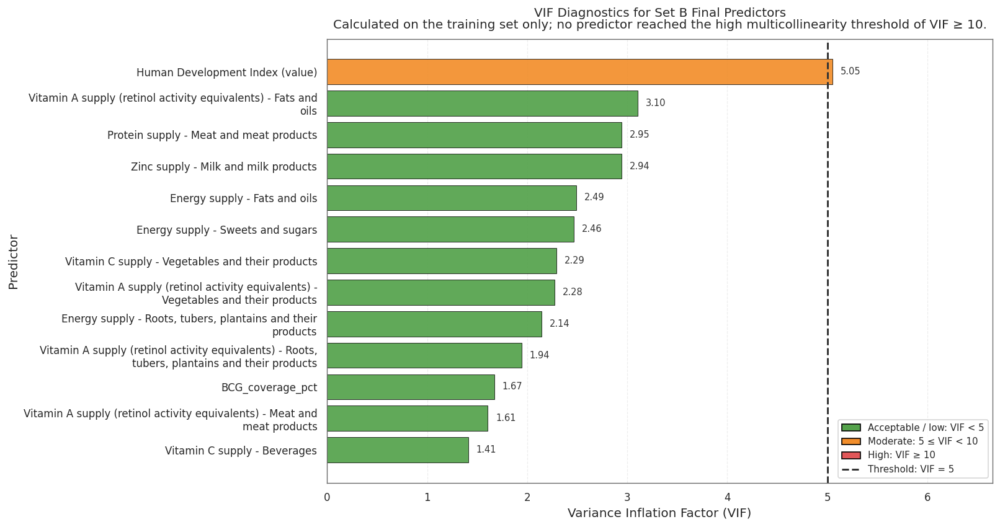

Improved VIF plot created successfully.
Test set used: No
Data modified: No
Feature selection performed in this cell: No

Improved VIF figure:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/20_improved_vif_diagnostics_set_b_final_predictors.png



,feature,r_squared_against_other_predictors,tolerance,vif,vif_category,vif_ge_5_flag,vif_ge_10_flag
0,Human Development Index (value),0.802027,0.197973,5.051186,Moderate multicollinearity,True,False
1,Vitamin A supply (retinol activity equivalents...,0.677623,0.322377,3.101954,Low / acceptable multicollinearity,False,False
2,Protein supply - Meat and meat products,0.660526,0.339474,2.945737,Low / acceptable multicollinearity,False,False
3,Zinc supply - Milk and milk products,0.660191,0.339809,2.942827,Low / acceptable multicollinearity,False,False
4,Energy supply - Fats and oils,0.598478,0.401522,2.490522,Low / acceptable multicollinearity,False,False
5,Energy supply - Sweets and sugars,0.594204,0.405796,2.464291,Low / acceptable multicollinearity,False,False
6,Vitamin C supply - Vegetables and their products,0.563425,0.436575,2.290558,Low / acceptable multicollinearity,False,False
7,Vitamin A supply (retinol activity equivalents...,0.560456,0.439544,2.275087,Low / acceptable multicollinearity,False,False
8,"Energy supply - Roots, tubers, plantains and t...",0.533524,0.466476,2.143734,Low / acceptable multicollinearity,False,False
9,Vitamin A supply (retinol activity equivalents...,0.485135,0.514865,1.942257,Low / acceptable multicollinearity,False,False


In [77]:
# Step 10B: Improved VIF visualization for Set B

# Purpose:
#   To create a cleaner and more interpretable VIF visualization
#   for the final Set B predictors.
#
# Important:
#   - This cell uses the already calculated vif_diagnostics_set_b table.
#   - It does not recalculate VIF.
#   - It does not use the test set.
#   - It does not modify the data.
#   - It does not perform feature selection.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_improved_vif_plot = [
    "vif_diagnostics_set_b"
]

missing_objects_for_improved_vif_plot = [
    object_name
    for object_name in required_objects_for_improved_vif_plot
    if object_name not in globals()
]

if missing_objects_for_improved_vif_plot:
    raise NameError(
        "Missing required objects for improved VIF plot: "
        f"{missing_objects_for_improved_vif_plot}. "
        "Run the VIF diagnostics cell first."
    )

if not isinstance(vif_diagnostics_set_b, pd.DataFrame):
    raise TypeError(
        "vif_diagnostics_set_b must be a pandas DataFrame."
    )

required_vif_columns = [
    "feature",
    "vif",
    "vif_category",
    "vif_ge_5_flag",
    "vif_ge_10_flag"
]

missing_vif_columns = [
    column
    for column in required_vif_columns
    if column not in vif_diagnostics_set_b.columns
]

if missing_vif_columns:
    raise KeyError(
        "Missing required columns in vif_diagnostics_set_b: "
        f"{missing_vif_columns}"
    )

if "FIGURES_DIR" in globals():
    FIGURES_DIR = Path(FIGURES_DIR)
elif "RESULTS_DIR" in globals():
    FIGURES_DIR = Path(RESULTS_DIR) / "figures"
else:
    FIGURES_DIR = Path("results") / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

IMPROVED_VIF_FIGURE_PATH = (
    FIGURES_DIR / "20_improved_vif_diagnostics_set_b_final_predictors.png"
)

# -------------------------------------------------------------------
# 2. Settings
# -------------------------------------------------------------------

ACCEPTABLE_VIF_COLOR = "#54A24B"   # green
MODERATE_VIF_COLOR = "#F28E2B"     # orange
HIGH_VIF_COLOR = "#E15759"         # red

VIF_MODERATE_THRESHOLD = 5.0
VIF_HIGH_THRESHOLD = 10.0

# -------------------------------------------------------------------
# 3. Helper functions
# -------------------------------------------------------------------

def wrap_label(text, width=58):
    """
    Wrap long predictor names for readable y-axis labels.
    """
    return "\n".join(textwrap.wrap(str(text), width=width))


def get_vif_bar_color(vif_value):
    """
    Assign bar color based on VIF category.
    """
    if pd.isna(vif_value):
        return "#999999"

    if np.isinf(vif_value):
        return HIGH_VIF_COLOR

    if vif_value >= VIF_HIGH_THRESHOLD:
        return HIGH_VIF_COLOR

    if vif_value >= VIF_MODERATE_THRESHOLD:
        return MODERATE_VIF_COLOR

    return ACCEPTABLE_VIF_COLOR

# -------------------------------------------------------------------
# 4. Prepare plot table
# -------------------------------------------------------------------

vif_plot_table = (
    vif_diagnostics_set_b
    .copy()
    .sort_values(by="vif", ascending=True)
    .reset_index(drop=True)
)

vif_plot_table["wrapped_feature"] = (
    vif_plot_table["feature"]
    .apply(lambda value: wrap_label(value, width=58))
)

vif_plot_table["bar_color"] = (
    vif_plot_table["vif"]
    .apply(get_vif_bar_color)
)

finite_vif_values = (
    vif_plot_table["vif"]
    .replace(np.inf, np.nan)
    .dropna()
)

if finite_vif_values.empty:
    maximum_vif_for_axis = 6.0
else:
    maximum_vif_for_axis = max(
        VIF_MODERATE_THRESHOLD + 0.8,
        float(finite_vif_values.max()) + 0.8
    )

vif_plot_table["vif_for_plot"] = (
    vif_plot_table["vif"]
    .replace(np.inf, maximum_vif_for_axis)
)

# -------------------------------------------------------------------
# 5. Create improved VIF plot
# -------------------------------------------------------------------

figure_height = max(
    6,
    vif_plot_table.shape[0] * 0.55
)

fig, ax = plt.subplots(figsize=(13.5, figure_height))

bars = ax.barh(
    vif_plot_table["wrapped_feature"],
    vif_plot_table["vif_for_plot"],
    color=vif_plot_table["bar_color"],
    edgecolor="black",
    linewidth=0.5,
    alpha=0.92
)

# Threshold line at VIF = 5
ax.axvline(
    x=VIF_MODERATE_THRESHOLD,
    linestyle="--",
    linewidth=1.8,
    color="#333333",
    label="Moderate multicollinearity threshold: VIF = 5"
)

ax.set_xlabel("Variance Inflation Factor (VIF)", fontsize=12)
ax.set_ylabel("Predictor", fontsize=12)

ax.xaxis.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.yaxis.grid(False)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.8)
    ax.spines[spine_name].set_color("#666666")

# Value labels
for bar, original_vif_value in zip(bars, vif_plot_table["vif"]):
    width = bar.get_width()

    if np.isinf(original_vif_value):
        label = "inf"
    else:
        label = f"{original_vif_value:.2f}"

    ax.text(
        width + 0.08,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center",
        ha="left",
        fontsize=8.8,
        color="#333333"
    )

ax.set_xlim(0, maximum_vif_for_axis + 0.8)

legend_handles = [
    Patch(
        facecolor=ACCEPTABLE_VIF_COLOR,
        edgecolor="black",
        label="Acceptable / low: VIF < 5"
    ),
    Patch(
        facecolor=MODERATE_VIF_COLOR,
        edgecolor="black",
        label="Moderate: 5 ≤ VIF < 10"
    ),
    Patch(
        facecolor=HIGH_VIF_COLOR,
        edgecolor="black",
        label="High: VIF ≥ 10"
    ),
    Line2D(
        [0],
        [0],
        color="#333333",
        linestyle="--",
        linewidth=1.8,
        label="Threshold: VIF = 5"
    )
]

ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=9,
    frameon=True
)

# Title + subtitle with a bit more spacing from the plot
compact_vif_title = (
    "VIF Diagnostics for Set B Final Predictors\n"
    "Calculated on the training set only; no predictor reached the high multicollinearity threshold of VIF ≥ 10."
)

title_object = ax.set_title(
    compact_vif_title,
    fontsize=12,
    fontweight="normal",
    pad=10
)

title_object.set_linespacing(1.0)

plt.tight_layout(pad=0.8)

plt.savefig(
    IMPROVED_VIF_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 6. Display output
# -------------------------------------------------------------------

print("Improved VIF plot created successfully.")
print("Test set used: No")
print("Data modified: No")
print("Feature selection performed in this cell: No")
print()

print("Improved VIF figure:")
print(IMPROVED_VIF_FIGURE_PATH)
print()

display(
    vif_diagnostics_set_b[
        [
            "feature",
            "r_squared_against_other_predictors",
            "tolerance",
            "vif",
            "vif_category",
            "vif_ge_5_flag",
            "vif_ge_10_flag"
        ]
    ]
)

In [78]:
# Step 11A: Standardized Set B input preparation for ordinary logistic regression

# Purpose:
#   To prepare standardized Set B predictors for ordinary logistic regression.
#
# Important:
#   - The scaler is fitted only on X_train_final.
#   - The same fitted scaler is applied to X_test_final.
#   - The test set is not used to estimate scaling parameters.
#   - No feature selection is performed in this cell.
#   - No model is fitted in this cell.
#   - No new train-test split is created.

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.preprocessing import StandardScaler

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logistic_regression_input = [
    "X_train_final",
    "X_test_final",
    "y_train_final",
    "y_test_final",
    "selected_predictor_cols",
    "TABLES_DIR"
]

missing_objects_for_logistic_regression_input = [
    object_name
    for object_name in required_objects_for_logistic_regression_input
    if object_name not in globals()
]

if missing_objects_for_logistic_regression_input:
    raise NameError(
        "Missing required objects for logistic regression input preparation: "
        f"{missing_objects_for_logistic_regression_input}. "
        "Run Step 9A first to create the final modelling input matrices."
    )

if not isinstance(X_train_final, pd.DataFrame):
    raise TypeError("X_train_final must be a pandas DataFrame.")

if not isinstance(X_test_final, pd.DataFrame):
    raise TypeError("X_test_final must be a pandas DataFrame.")

if not isinstance(y_train_final, pd.Series):
    raise TypeError("y_train_final must be a pandas Series.")

if not isinstance(y_test_final, pd.Series):
    raise TypeError("y_test_final must be a pandas Series.")

if not isinstance(selected_predictor_cols, (list, tuple, pd.Index)):
    raise TypeError(
        "selected_predictor_cols must be a list, tuple, or pandas Index."
    )

selected_predictor_cols = list(selected_predictor_cols)

if len(selected_predictor_cols) == 0:
    raise ValueError("selected_predictor_cols is empty.")

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)


# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_B_SCALER_PARAMETERS_CSV_PATH = (
    TABLES_DIR / "21_logistic_regression_set_b_scaler_parameters.csv"
)

LOGREG_SET_B_SCALER_PARAMETERS_EXCEL_PATH = (
    TABLES_DIR / "21_logistic_regression_set_b_scaler_parameters.xlsx"
)

X_TRAIN_LOGREG_SET_B_STANDARDIZED_CSV_PATH = (
    TABLES_DIR / "21_X_train_logistic_regression_set_b_standardized.csv"
)

X_TEST_LOGREG_SET_B_STANDARDIZED_CSV_PATH = (
    TABLES_DIR / "21_X_test_logistic_regression_set_b_standardized.csv"
)

LOGREG_SET_B_INPUT_SUMMARY_CSV_PATH = (
    TABLES_DIR / "21_logistic_regression_set_b_input_summary.csv"
)

LOGREG_SET_B_INPUT_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "21_logistic_regression_set_b_input_summary.xlsx"
)


# -------------------------------------------------------------------
# 3. Train-test alignment validation
# -------------------------------------------------------------------

if X_train_final.shape[0] != y_train_final.shape[0]:
    raise ValueError(
        "X_train_final and y_train_final have different numbers of rows: "
        f"{X_train_final.shape[0]} vs {y_train_final.shape[0]}."
    )

if X_test_final.shape[0] != y_test_final.shape[0]:
    raise ValueError(
        "X_test_final and y_test_final have different numbers of rows: "
        f"{X_test_final.shape[0]} vs {y_test_final.shape[0]}."
    )

if not X_train_final.index.equals(y_train_final.index):
    raise ValueError(
        "The indices of X_train_final and y_train_final do not match."
    )

if not X_test_final.index.equals(y_test_final.index):
    raise ValueError(
        "The indices of X_test_final and y_test_final do not match."
    )

overlapping_train_test_indices = (
    set(X_train_final.index)
    .intersection(set(X_test_final.index))
)

if overlapping_train_test_indices:
    raise ValueError(
        "Training and testing sets have overlapping indices. "
        "This should not happen after a proper train-test split."
    )


# -------------------------------------------------------------------
# 4. Predictor validation
# -------------------------------------------------------------------

missing_selected_predictors_in_train = [
    feature
    for feature in selected_predictor_cols
    if feature not in X_train_final.columns
]

missing_selected_predictors_in_test = [
    feature
    for feature in selected_predictor_cols
    if feature not in X_test_final.columns
]

if missing_selected_predictors_in_train:
    raise KeyError(
        "The following selected predictors are missing from X_train_final: "
        f"{missing_selected_predictors_in_train}"
    )

if missing_selected_predictors_in_test:
    raise KeyError(
        "The following selected predictors are missing from X_test_final: "
        f"{missing_selected_predictors_in_test}"
    )

if len(selected_predictor_cols) != len(set(selected_predictor_cols)):
    duplicated_predictors = (
        pd.Series(selected_predictor_cols)
        .loc[pd.Series(selected_predictor_cols).duplicated()]
        .tolist()
    )

    raise ValueError(
        "selected_predictor_cols contains duplicated predictors: "
        f"{duplicated_predictors}"
    )


# -------------------------------------------------------------------
# 5. Prepare original Set B matrices
# -------------------------------------------------------------------

X_train_logreg_set_b_original = (
    X_train_final[selected_predictor_cols]
    .copy()
)

X_test_logreg_set_b_original = (
    X_test_final[selected_predictor_cols]
    .copy()
)

y_train_logreg_set_b = y_train_final.copy()
y_test_logreg_set_b = y_test_final.copy()


# -------------------------------------------------------------------
# 6. Numeric, missing, infinite and zero-variance validation
# -------------------------------------------------------------------

non_numeric_train_predictors = [
    feature
    for feature in selected_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_train_logreg_set_b_original[feature])
]

non_numeric_test_predictors = [
    feature
    for feature in selected_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_test_logreg_set_b_original[feature])
]

if non_numeric_train_predictors:
    raise TypeError(
        "All Set B training predictors must be numeric. "
        f"Non-numeric predictors found: {non_numeric_train_predictors}"
    )

if non_numeric_test_predictors:
    raise TypeError(
        "All Set B testing predictors must be numeric. "
        f"Non-numeric predictors found: {non_numeric_test_predictors}"
    )

missing_values_train = int(
    X_train_logreg_set_b_original
    .isna()
    .sum()
    .sum()
)

missing_values_test = int(
    X_test_logreg_set_b_original
    .isna()
    .sum()
    .sum()
)

if missing_values_train > 0:
    raise ValueError(
        "Missing values found in X_train_logreg_set_b_original. "
        "Handle missing values before logistic regression."
    )

if missing_values_test > 0:
    raise ValueError(
        "Missing values found in X_test_logreg_set_b_original. "
        "Handle missing values before logistic regression."
    )

infinite_values_train = int(
    np.isinf(
        X_train_logreg_set_b_original
        .to_numpy(dtype=float)
    )
    .sum()
)

infinite_values_test = int(
    np.isinf(
        X_test_logreg_set_b_original
        .to_numpy(dtype=float)
    )
    .sum()
)

if infinite_values_train > 0:
    raise ValueError(
        "Infinite values found in X_train_logreg_set_b_original."
    )

if infinite_values_test > 0:
    raise ValueError(
        "Infinite values found in X_test_logreg_set_b_original."
    )

zero_variance_predictors = [
    feature
    for feature in selected_predictor_cols
    if X_train_logreg_set_b_original[feature].nunique(dropna=True) <= 1
]

if zero_variance_predictors:
    raise ValueError(
        "The following predictors have zero variance in the training set "
        "and cannot be used in logistic regression: "
        f"{zero_variance_predictors}"
    )

if sorted(y_train_logreg_set_b.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_train_logreg_set_b must contain binary values [0, 1]."
    )

if sorted(y_test_logreg_set_b.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_test_logreg_set_b must contain binary values [0, 1]."
    )


# -------------------------------------------------------------------
# 7. Fit StandardScaler on training set only
# -------------------------------------------------------------------

logreg_set_b_scaler = StandardScaler()

X_train_logreg_set_b_standardized_array = (
    logreg_set_b_scaler
    .fit_transform(X_train_logreg_set_b_original)
)

X_test_logreg_set_b_standardized_array = (
    logreg_set_b_scaler
    .transform(X_test_logreg_set_b_original)
)

X_train_logreg_set_b_standardized = pd.DataFrame(
    X_train_logreg_set_b_standardized_array,
    columns=selected_predictor_cols,
    index=X_train_logreg_set_b_original.index
)

X_test_logreg_set_b_standardized = pd.DataFrame(
    X_test_logreg_set_b_standardized_array,
    columns=selected_predictor_cols,
    index=X_test_logreg_set_b_original.index
)


# -------------------------------------------------------------------
# 8. Compatibility aliases for next logistic regression cells
# -------------------------------------------------------------------

X_train_logreg_set_b = X_train_logreg_set_b_standardized.copy()
X_test_logreg_set_b = X_test_logreg_set_b_standardized.copy()

X_train_logistic_regression_set_b = X_train_logreg_set_b_standardized.copy()
X_test_logistic_regression_set_b = X_test_logreg_set_b_standardized.copy()

logistic_regression_set_b_predictor_cols = selected_predictor_cols.copy()


# -------------------------------------------------------------------
# 9. Create scaler parameter table
# -------------------------------------------------------------------

logreg_set_b_scaler_parameters = pd.DataFrame({
    "feature": selected_predictor_cols,
    "training_mean_used_by_scaler": logreg_set_b_scaler.mean_,
    "training_scale_used_by_scaler": logreg_set_b_scaler.scale_,
    "training_variance_used_by_scaler": logreg_set_b_scaler.var_,
    "original_training_mean": [
        X_train_logreg_set_b_original[feature].mean()
        for feature in selected_predictor_cols
    ],
    "original_training_std_ddof_1": [
        X_train_logreg_set_b_original[feature].std(ddof=1)
        for feature in selected_predictor_cols
    ],
    "standardized_training_mean": [
        X_train_logreg_set_b_standardized[feature].mean()
        for feature in selected_predictor_cols
    ],
    "standardized_training_std_ddof_0": [
        X_train_logreg_set_b_standardized[feature].std(ddof=0)
        for feature in selected_predictor_cols
    ],
    "standardized_training_std_ddof_1": [
        X_train_logreg_set_b_standardized[feature].std(ddof=1)
        for feature in selected_predictor_cols
    ]
})


# -------------------------------------------------------------------
# 10. Create input preparation summary
# -------------------------------------------------------------------

logreg_set_b_input_summary = pd.DataFrame({
    "item": [
        "Model preparation step",
        "Predictor set",
        "Number of predictors",
        "Training samples",
        "Testing samples",
        "Training input source",
        "Testing input source",
        "Training target source",
        "Testing target source",
        "Scaler",
        "Scaler fitted on",
        "Scaler applied to",
        "Test set used to fit scaler",
        "Target variable used to fit scaler",
        "Feature selection performed in this cell",
        "New train-test split created in this cell",
        "Missing values in standardized training input",
        "Missing values in standardized testing input",
        "Infinite values in standardized training input",
        "Infinite values in standardized testing input",
        "Interpretation of standardized coefficients"
    ],
    "value": [
        "Standardized input preparation for ordinary logistic regression",
        "Set B - final predictors after statistical screening, Spearman pruning and VIF diagnostics",
        len(selected_predictor_cols),
        X_train_logreg_set_b_standardized.shape[0],
        X_test_logreg_set_b_standardized.shape[0],
        "X_train_final",
        "X_test_final",
        "y_train_final",
        "y_test_final",
        "StandardScaler",
        "X_train_final only",
        "X_train_final and X_test_final",
        "No",
        "No",
        "No",
        "No",
        int(X_train_logreg_set_b_standardized.isna().sum().sum()),
        int(X_test_logreg_set_b_standardized.isna().sum().sum()),
        int(np.isinf(X_train_logreg_set_b_standardized.to_numpy(dtype=float)).sum()),
        int(np.isinf(X_test_logreg_set_b_standardized.to_numpy(dtype=float)).sum()),
        "Per one standard deviation increase in the predictor"
    ]
})


# -------------------------------------------------------------------
# 11. Save outputs
# -------------------------------------------------------------------

logreg_set_b_scaler_parameters.to_csv(
    LOGREG_SET_B_SCALER_PARAMETERS_CSV_PATH,
    index=False
)

logreg_set_b_scaler_parameters.to_excel(
    LOGREG_SET_B_SCALER_PARAMETERS_EXCEL_PATH,
    index=False
)

X_train_logreg_set_b_standardized.to_csv(
    X_TRAIN_LOGREG_SET_B_STANDARDIZED_CSV_PATH,
    index=False
)

X_test_logreg_set_b_standardized.to_csv(
    X_TEST_LOGREG_SET_B_STANDARDIZED_CSV_PATH,
    index=False
)

logreg_set_b_input_summary.to_csv(
    LOGREG_SET_B_INPUT_SUMMARY_CSV_PATH,
    index=False
)

logreg_set_b_input_summary.to_excel(
    LOGREG_SET_B_INPUT_SUMMARY_EXCEL_PATH,
    index=False
)


# -------------------------------------------------------------------
# 12. Display outputs
# -------------------------------------------------------------------

def format_logreg_input_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(include=[np.number]).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(6)

    return display_table


print("Step 11A completed successfully.")
print("Standardized Set B input prepared for ordinary logistic regression.")
print()

print("Training input used to fit scaler: X_train_final")
print("Testing input transformed with fitted scaler: X_test_final")
print("Test set used to fit scaler: No")
print("Target variable used to fit scaler: No")
print("Feature selection performed in this cell: No")
print("New train-test split created in this cell: No")
print()

print("X_train_logreg_set_b shape:", X_train_logreg_set_b.shape)
print("X_test_logreg_set_b shape:", X_test_logreg_set_b.shape)
print("y_train_logreg_set_b shape:", y_train_logreg_set_b.shape)
print("y_test_logreg_set_b shape:", y_test_logreg_set_b.shape)
print()

print("Scaler parameters CSV:")
print(LOGREG_SET_B_SCALER_PARAMETERS_CSV_PATH)
print()

print("Logistic regression Set B input summary CSV:")
print(LOGREG_SET_B_INPUT_SUMMARY_CSV_PATH)
print()

print("Scaler parameter table:")
display(
    format_logreg_input_display_table(
        logreg_set_b_scaler_parameters
    )
)

print("Logistic regression Set B input summary:")
display(logreg_set_b_input_summary)

Step 11A completed successfully.
Standardized Set B input prepared for ordinary logistic regression.

Training input used to fit scaler: X_train_final
Testing input transformed with fitted scaler: X_test_final
Test set used to fit scaler: No
Target variable used to fit scaler: No
Feature selection performed in this cell: No
New train-test split created in this cell: No

X_train_logreg_set_b shape: (146, 13)
X_test_logreg_set_b shape: (37, 13)
y_train_logreg_set_b shape: (146,)
y_test_logreg_set_b shape: (37,)

Scaler parameters CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/21_logistic_regression_set_b_scaler_parameters.csv

Logistic regression Set B input summary CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/21_logistic_regression_set_b_input_summary.csv

Scaler parameter table:


,feature,training_mean_used_by_scaler,training_scale_used_by_scaler,training_variance_used_by_scaler,original_training_mean,original_training_std_ddof_1,standardized_training_mean,standardized_training_std_ddof_0,standardized_training_std_ddof_1
0,Human Development Index (value),0.725959,0.150758,0.022728,0.725959,0.151277,-0.0,1.0,1.003442
1,Zinc supply - Milk and milk products,1.385411,1.224385,1.499118,1.385411,1.228599,-0.0,1.0,1.003442
2,Energy supply - Fats and oils,397.232877,204.326191,41749.192344,397.232877,205.029553,-0.0,1.0,1.003442
3,Vitamin A supply (retinol activity equivalents...,81.917808,88.279949,7793.349409,81.917808,88.583840,-0.0,1.0,1.003442
4,Energy supply - Sweets and sugars,344.595890,155.533751,24190.747654,344.595890,156.069153,-0.0,1.0,1.003442
5,Protein supply - Meat and meat products,24.552740,14.044539,197.249068,24.552740,14.092885,0.0,1.0,1.003442
6,BCG_coverage_pct,91.391117,10.753808,115.644395,91.391117,10.790827,-0.0,1.0,1.003442
7,Vitamin C supply - Vegetables and their products,50.212329,45.075767,2031.824780,50.212329,45.230934,-0.0,1.0,1.003442
8,Vitamin C supply - Beverages,8.164384,10.484187,109.918184,8.164384,10.520278,-0.0,1.0,1.003442
9,"Energy supply - Roots, tubers, plantains and t...",204.863014,250.809255,62905.282605,204.863014,251.672629,-0.0,1.0,1.003442


Logistic regression Set B input summary:


,item,value
0,Model preparation step,Standardized input preparation for ordinary lo...
1,Predictor set,Set B - final predictors after statistical scr...
2,Number of predictors,13
3,Training samples,146
4,Testing samples,37
5,Training input source,X_train_final
6,Testing input source,X_test_final
7,Training target source,y_train_final
8,Testing target source,y_test_final
9,Scaler,StandardScaler


In [79]:
# Step 11B: Fit ordinary logistic regression on standardized Set B predictors

# Purpose:
#   To fit an ordinary, unregularized logistic regression model
#   using the standardized Set B predictors.
#
# Important:
#   - The model is fitted only on the training set.
#   - The test set is not used for model fitting.
#   - No regularization is applied.
#   - No class weighting is applied.
#   - No threshold tuning is performed in this cell.
#   - This is the main interpretable logistic regression model.

import numpy as np
import pandas as pd
from pathlib import Path

import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationError

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logreg_set_b_fit = [
    "X_train_logreg_set_b",
    "X_test_logreg_set_b",
    "y_train_logreg_set_b",
    "y_test_logreg_set_b",
    "logistic_regression_set_b_predictor_cols",
    "TABLES_DIR"
]

missing_objects_for_logreg_set_b_fit = [
    object_name
    for object_name in required_objects_for_logreg_set_b_fit
    if object_name not in globals()
]

if missing_objects_for_logreg_set_b_fit:
    raise NameError(
        "Missing required objects for ordinary logistic regression fitting: "
        f"{missing_objects_for_logreg_set_b_fit}. "
        "Run Step 11A first to prepare standardized Set B input."
    )

if not isinstance(X_train_logreg_set_b, pd.DataFrame):
    raise TypeError(
        "X_train_logreg_set_b must be a pandas DataFrame."
    )

if not isinstance(X_test_logreg_set_b, pd.DataFrame):
    raise TypeError(
        "X_test_logreg_set_b must be a pandas DataFrame."
    )

if not isinstance(y_train_logreg_set_b, pd.Series):
    raise TypeError(
        "y_train_logreg_set_b must be a pandas Series."
    )

if not isinstance(y_test_logreg_set_b, pd.Series):
    raise TypeError(
        "y_test_logreg_set_b must be a pandas Series."
    )

if not isinstance(logistic_regression_set_b_predictor_cols, (list, tuple, pd.Index)):
    raise TypeError(
        "logistic_regression_set_b_predictor_cols must be a list, tuple, or pandas Index."
    )

logistic_regression_set_b_predictor_cols = list(
    logistic_regression_set_b_predictor_cols
)

if len(logistic_regression_set_b_predictor_cols) == 0:
    raise ValueError(
        "logistic_regression_set_b_predictor_cols is empty."
    )

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)


# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_B_MODEL_FIT_SUMMARY_CSV_PATH = (
    TABLES_DIR / "22_logistic_regression_set_b_model_fit_summary.csv"
)

LOGREG_SET_B_MODEL_FIT_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "22_logistic_regression_set_b_model_fit_summary.xlsx"
)

LOGREG_SET_B_MODEL_SUMMARY_TXT_PATH = (
    TABLES_DIR / "22_logistic_regression_set_b_statsmodels_summary.txt"
)

LOGREG_SET_B_MODEL_SUMMARY_HTML_PATH = (
    TABLES_DIR / "22_logistic_regression_set_b_statsmodels_summary.html"
)


# -------------------------------------------------------------------
# 3. Alignment and data validation
# -------------------------------------------------------------------

if X_train_logreg_set_b.shape[0] != y_train_logreg_set_b.shape[0]:
    raise ValueError(
        "X_train_logreg_set_b and y_train_logreg_set_b have different numbers of rows: "
        f"{X_train_logreg_set_b.shape[0]} vs {y_train_logreg_set_b.shape[0]}."
    )

if X_test_logreg_set_b.shape[0] != y_test_logreg_set_b.shape[0]:
    raise ValueError(
        "X_test_logreg_set_b and y_test_logreg_set_b have different numbers of rows: "
        f"{X_test_logreg_set_b.shape[0]} vs {y_test_logreg_set_b.shape[0]}."
    )

if not X_train_logreg_set_b.index.equals(y_train_logreg_set_b.index):
    raise ValueError(
        "The indices of X_train_logreg_set_b and y_train_logreg_set_b do not match."
    )

if not X_test_logreg_set_b.index.equals(y_test_logreg_set_b.index):
    raise ValueError(
        "The indices of X_test_logreg_set_b and y_test_logreg_set_b do not match."
    )

missing_logreg_predictors_train = [
    feature
    for feature in logistic_regression_set_b_predictor_cols
    if feature not in X_train_logreg_set_b.columns
]

missing_logreg_predictors_test = [
    feature
    for feature in logistic_regression_set_b_predictor_cols
    if feature not in X_test_logreg_set_b.columns
]

if missing_logreg_predictors_train:
    raise KeyError(
        "The following predictors are missing from X_train_logreg_set_b: "
        f"{missing_logreg_predictors_train}"
    )

if missing_logreg_predictors_test:
    raise KeyError(
        "The following predictors are missing from X_test_logreg_set_b: "
        f"{missing_logreg_predictors_test}"
    )

if sorted(y_train_logreg_set_b.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_train_logreg_set_b must contain binary values [0, 1]."
    )

if sorted(y_test_logreg_set_b.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_test_logreg_set_b must contain binary values [0, 1]."
    )

if X_train_logreg_set_b.isna().sum().sum() > 0:
    raise ValueError(
        "Missing values found in X_train_logreg_set_b."
    )

if X_test_logreg_set_b.isna().sum().sum() > 0:
    raise ValueError(
        "Missing values found in X_test_logreg_set_b."
    )

if np.isinf(X_train_logreg_set_b.to_numpy(dtype=float)).sum() > 0:
    raise ValueError(
        "Infinite values found in X_train_logreg_set_b."
    )

if np.isinf(X_test_logreg_set_b.to_numpy(dtype=float)).sum() > 0:
    raise ValueError(
        "Infinite values found in X_test_logreg_set_b."
    )


# -------------------------------------------------------------------
# 4. Prepare statsmodels design matrices
# -------------------------------------------------------------------

X_train_logreg_set_b_model = (
    X_train_logreg_set_b[logistic_regression_set_b_predictor_cols]
    .copy()
)

X_test_logreg_set_b_model = (
    X_test_logreg_set_b[logistic_regression_set_b_predictor_cols]
    .copy()
)

# Add intercept term.
X_train_logreg_set_b_model_with_constant = sm.add_constant(
    X_train_logreg_set_b_model,
    has_constant="add"
)

X_test_logreg_set_b_model_with_constant = sm.add_constant(
    X_test_logreg_set_b_model,
    has_constant="add"
)

y_train_logreg_set_b_model = (
    y_train_logreg_set_b
    .astype(int)
    .copy()
)

y_test_logreg_set_b_model = (
    y_test_logreg_set_b
    .astype(int)
    .copy()
)

if "const" not in X_train_logreg_set_b_model_with_constant.columns:
    raise ValueError(
        "Intercept column 'const' was not added to the training design matrix."
    )

if "const" not in X_test_logreg_set_b_model_with_constant.columns:
    raise ValueError(
        "Intercept column 'const' was not added to the testing design matrix."
    )


# -------------------------------------------------------------------
# 5. Fit ordinary logistic regression model
# -------------------------------------------------------------------

ordinary_logistic_regression_set_b_model = sm.Logit(
    y_train_logreg_set_b_model,
    X_train_logreg_set_b_model_with_constant
)

try:
    ordinary_logistic_regression_set_b_results = (
        ordinary_logistic_regression_set_b_model
        .fit(
            method="lbfgs",
            maxiter=1000,
            disp=False
        )
    )

except PerfectSeparationError as error:
    raise RuntimeError(
        "Perfect separation was detected while fitting the ordinary logistic "
        "regression model. This means one or more predictors may separate the "
        "two classes too strongly. Consider checking predictors, reducing the "
        "model, or using regularized logistic regression as a sensitivity model."
    ) from error


# -------------------------------------------------------------------
# 6. Check convergence
# -------------------------------------------------------------------

logreg_set_b_mle_retvals = (
    ordinary_logistic_regression_set_b_results
    .mle_retvals
)

logreg_set_b_converged = bool(
    logreg_set_b_mle_retvals.get("converged", False)
)

if not logreg_set_b_converged:
    print(
        "Warning: The ordinary logistic regression model did not fully converge. "
        "Interpret coefficients and p-values with caution."
    )
else:
    print("Ordinary logistic regression model converged successfully.")


# -------------------------------------------------------------------
# 7. Extract model fit statistics
# -------------------------------------------------------------------

log_likelihood_model = ordinary_logistic_regression_set_b_results.llf
log_likelihood_null = ordinary_logistic_regression_set_b_results.llnull

if log_likelihood_null == 0:
    mcfadden_pseudo_r_squared = np.nan
else:
    mcfadden_pseudo_r_squared = 1 - (
        log_likelihood_model / log_likelihood_null
    )

logreg_set_b_model_fit_summary = pd.DataFrame({
    "item": [
        "Model",
        "Predictor set",
        "Model type",
        "Regularization used",
        "Class weighting used",
        "Training input",
        "Test set used for fitting",
        "Target positive class",
        "Number of training samples",
        "Number of predictors",
        "Intercept included",
        "Optimization method",
        "Maximum iterations",
        "Converged",
        "Log-likelihood",
        "Null log-likelihood",
        "McFadden pseudo R-squared",
        "AIC",
        "BIC",
        "Degrees of freedom model",
        "Degrees of freedom residuals"
    ],
    "value": [
        "Ordinary Logistic Regression - Set B",
        "Set B - final standardized predictors",
        "Statsmodels Logit",
        "No",
        "No",
        "X_train_logreg_set_b",
        "No",
        "high_tb_burden = 1",
        X_train_logreg_set_b_model_with_constant.shape[0],
        len(logistic_regression_set_b_predictor_cols),
        "Yes",
        "lbfgs",
        1000,
        logreg_set_b_converged,
        log_likelihood_model,
        log_likelihood_null,
        mcfadden_pseudo_r_squared,
        ordinary_logistic_regression_set_b_results.aic,
        ordinary_logistic_regression_set_b_results.bic,
        ordinary_logistic_regression_set_b_results.df_model,
        ordinary_logistic_regression_set_b_results.df_resid
    ]
})


# -------------------------------------------------------------------
# 8. Save statsmodels summaries
# -------------------------------------------------------------------

with open(LOGREG_SET_B_MODEL_SUMMARY_TXT_PATH, "w", encoding="utf-8") as file:
    file.write(
        ordinary_logistic_regression_set_b_results
        .summary2()
        .as_text()
    )

with open(LOGREG_SET_B_MODEL_SUMMARY_HTML_PATH, "w", encoding="utf-8") as file:
    file.write(
        ordinary_logistic_regression_set_b_results
        .summary2()
        .as_html()
    )

logreg_set_b_model_fit_summary.to_csv(
    LOGREG_SET_B_MODEL_FIT_SUMMARY_CSV_PATH,
    index=False
)

logreg_set_b_model_fit_summary.to_excel(
    LOGREG_SET_B_MODEL_FIT_SUMMARY_EXCEL_PATH,
    index=False
)


# -------------------------------------------------------------------
# 9. Compatibility aliases for later cells
# -------------------------------------------------------------------

logreg_set_b_model = ordinary_logistic_regression_set_b_model
logreg_set_b_results = ordinary_logistic_regression_set_b_results

X_train_logreg_set_b_with_constant = (
    X_train_logreg_set_b_model_with_constant
    .copy()
)

X_test_logreg_set_b_with_constant = (
    X_test_logreg_set_b_model_with_constant
    .copy()
)


# -------------------------------------------------------------------
# 10. Display outputs
# -------------------------------------------------------------------

def format_logreg_fit_summary_table(display_table):
    display_table = display_table.copy()

    numeric_items = [
        "Log-likelihood",
        "Null log-likelihood",
        "McFadden pseudo R-squared",
        "AIC",
        "BIC",
        "Degrees of freedom model",
        "Degrees of freedom residuals"
    ]

    display_table["value"] = display_table.apply(
        lambda row: (
            round(float(row["value"]), 6)
            if row["item"] in numeric_items and pd.notna(row["value"])
            else row["value"]
        ),
        axis=1
    )

    return display_table


print("Step 11B completed successfully.")
print("Ordinary Logistic Regression on Set B was fitted using statsmodels Logit.")
print()

print("Model converged:", logreg_set_b_converged)
print("Training samples:", X_train_logreg_set_b_with_constant.shape[0])
print("Predictors:", len(logistic_regression_set_b_predictor_cols))
print("Intercept included: Yes")
print("Test set used for fitting: No")
print("Regularization used: No")
print("Class weighting used: No")
print()

print("Model fit summary CSV:")
print(LOGREG_SET_B_MODEL_FIT_SUMMARY_CSV_PATH)
print()

print("Statsmodels summary TXT:")
print(LOGREG_SET_B_MODEL_SUMMARY_TXT_PATH)
print()

print("Model fit summary:")
display(
    format_logreg_fit_summary_table(
        logreg_set_b_model_fit_summary
    )
)

print("Statsmodels model summary:")
display(
    ordinary_logistic_regression_set_b_results
    .summary2()
    .tables[0]
)

Ordinary logistic regression model converged successfully.
Step 11B completed successfully.
Ordinary Logistic Regression on Set B was fitted using statsmodels Logit.

Model converged: True
Training samples: 146
Predictors: 13
Intercept included: Yes
Test set used for fitting: No
Regularization used: No
Class weighting used: No

Model fit summary CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/22_logistic_regression_set_b_model_fit_summary.csv

Statsmodels summary TXT:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/22_logistic_regression_set_b_statsmodels_summary.txt

Model fit summary:


,item,value
0,Model,Ordinary Logistic Regression - Set B
1,Predictor set,Set B - final standardized predictors
2,Model type,Statsmodels Logit
3,Regularization used,No
4,Class weighting used,No
5,Training input,X_train_logreg_set_b
6,Test set used for fitting,No
7,Target positive class,high_tb_burden = 1
8,Number of training samples,146
9,Number of predictors,13


Statsmodels model summary:


,0,1,2,3
0,Model:,Logit,Method:,MLE
1,Dependent Variable:,high_tb_burden,Pseudo R-squared:,0.415
2,Date:,2026-06-28 13:46,AIC:,124.6449
3,No. Observations:,146,BIC:,166.4154
4,Df Model:,13,Log-Likelihood:,-48.322
5,Df Residuals:,132,LL-Null:,-82.646
6,Converged:,1.0000,LLR p-value:,1.4233e-09
7,No. Iterations:,28.0000,Scale:,1.0000


In [80]:
# Step 11C: Logistic regression coefficients, odds ratios and statistical inference

# Purpose:
#   To extract and interpret coefficients from the ordinary logistic
#   regression model fitted on standardized Set B predictors.
#
# Important:
#   - Coefficients are in log-odds scale.
#   - Odds ratios are exp(coefficients).
#   - Predictors were standardized, so odds ratios are interpreted per
#     one standard deviation increase in the predictor.
#   - This cell does not perform model fitting.
#   - This cell does not evaluate classification performance.
#   - The test set is not used in this cell.

import numpy as np
import pandas as pd
from pathlib import Path

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logreg_set_b_coefficients = [
    "logreg_set_b_results",
    "logistic_regression_set_b_predictor_cols",
    "TABLES_DIR"
]

missing_objects_for_logreg_set_b_coefficients = [
    object_name
    for object_name in required_objects_for_logreg_set_b_coefficients
    if object_name not in globals()
]

if missing_objects_for_logreg_set_b_coefficients:
    raise NameError(
        "Missing required objects for logistic regression coefficient extraction: "
        f"{missing_objects_for_logreg_set_b_coefficients}. "
        "Run Step 11B first to fit the ordinary logistic regression model."
    )

if not isinstance(logistic_regression_set_b_predictor_cols, (list, tuple, pd.Index)):
    raise TypeError(
        "logistic_regression_set_b_predictor_cols must be a list, tuple, or pandas Index."
    )

logistic_regression_set_b_predictor_cols = list(
    logistic_regression_set_b_predictor_cols
)

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)


# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_B_COEFFICIENTS_CSV_PATH = (
    TABLES_DIR / "23_logistic_regression_set_b_coefficients_odds_ratios.csv"
)

LOGREG_SET_B_COEFFICIENTS_EXCEL_PATH = (
    TABLES_DIR / "23_logistic_regression_set_b_coefficients_odds_ratios.xlsx"
)

LOGREG_SET_B_SIGNIFICANT_COEFFICIENTS_CSV_PATH = (
    TABLES_DIR / "23_logistic_regression_set_b_significant_predictors.csv"
)

LOGREG_SET_B_SIGNIFICANT_COEFFICIENTS_EXCEL_PATH = (
    TABLES_DIR / "23_logistic_regression_set_b_significant_predictors.xlsx"
)

LOGREG_SET_B_COEFFICIENT_SUMMARY_CSV_PATH = (
    TABLES_DIR / "23_logistic_regression_set_b_coefficient_summary.csv"
)

LOGREG_SET_B_COEFFICIENT_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "23_logistic_regression_set_b_coefficient_summary.xlsx"
)


# -------------------------------------------------------------------
# 3. Helper functions
# -------------------------------------------------------------------

def safe_exponential(value):
    """
    Safely calculates exp(value), avoiding overflow issues.
    """
    if pd.isna(value):
        return np.nan

    if value > 700:
        return np.inf

    if value < -700:
        return 0.0

    return np.exp(value)


def classify_p_value(p_value):
    """
    Classifies p-values using common reporting thresholds.
    """
    if pd.isna(p_value):
        return "Not available"

    if p_value < 0.001:
        return "p < 0.001"

    if p_value < 0.01:
        return "p < 0.01"

    if p_value < 0.05:
        return "p < 0.05"

    if p_value < 0.10:
        return "p < 0.10"

    return "Not statistically significant at 0.10"


def classify_effect_direction(coefficient):
    """
    Classifies the effect direction based on the coefficient sign.
    """
    if pd.isna(coefficient):
        return "Not available"

    if coefficient > 0:
        return "Positive association with high TB burden"

    if coefficient < 0:
        return "Negative association with high TB burden"

    return "No direction"


def interpret_odds_ratio(odds_ratio):
    """
    Creates a short interpretation of the odds ratio.
    """
    if pd.isna(odds_ratio):
        return "Not available"

    if np.isinf(odds_ratio):
        return "Extremely large odds ratio"

    if odds_ratio > 1:
        return "Higher predictor values are associated with higher odds of high TB burden"

    if odds_ratio < 1:
        return "Higher predictor values are associated with lower odds of high TB burden"

    return "No change in odds"


def format_p_value_for_display(p_value):
    """
    Formats p-values for readable display.
    """
    if pd.isna(p_value):
        return "NA"

    if p_value < 0.001:
        return f"{p_value:.3e}"

    return f"{p_value:.4f}"


# -------------------------------------------------------------------
# 4. Extract coefficient-level results
# -------------------------------------------------------------------

logreg_params = logreg_set_b_results.params
logreg_standard_errors = logreg_set_b_results.bse
logreg_z_statistics = logreg_set_b_results.tvalues
logreg_p_values = logreg_set_b_results.pvalues
logreg_confidence_intervals = logreg_set_b_results.conf_int(alpha=0.05)

logreg_confidence_intervals.columns = [
    "ci_lower_log_odds_95",
    "ci_upper_log_odds_95"
]

coefficient_records = []

for term in logreg_params.index:
    coefficient = logreg_params.loc[term]
    standard_error = logreg_standard_errors.loc[term]
    z_statistic = logreg_z_statistics.loc[term]
    p_value = logreg_p_values.loc[term]

    ci_lower_log_odds = logreg_confidence_intervals.loc[
        term,
        "ci_lower_log_odds_95"
    ]

    ci_upper_log_odds = logreg_confidence_intervals.loc[
        term,
        "ci_upper_log_odds_95"
    ]

    odds_ratio = safe_exponential(coefficient)
    odds_ratio_ci_lower_95 = safe_exponential(ci_lower_log_odds)
    odds_ratio_ci_upper_95 = safe_exponential(ci_upper_log_odds)

    coefficient_records.append({
        "term": term,
        "feature": "Intercept" if term == "const" else term,
        "is_intercept": bool(term == "const"),
        "coefficient_log_odds": coefficient,
        "standard_error": standard_error,
        "z_statistic": z_statistic,
        "p_value": p_value,
        "p_value_display": format_p_value_for_display(p_value),
        "p_value_category": classify_p_value(p_value),
        "ci_lower_log_odds_95": ci_lower_log_odds,
        "ci_upper_log_odds_95": ci_upper_log_odds,
        "odds_ratio": odds_ratio,
        "odds_ratio_ci_lower_95": odds_ratio_ci_lower_95,
        "odds_ratio_ci_upper_95": odds_ratio_ci_upper_95,
        "effect_direction": classify_effect_direction(coefficient),
        "odds_ratio_interpretation": interpret_odds_ratio(odds_ratio),
        "significant_at_0_05": bool(p_value < 0.05),
        "significant_at_0_10": bool(p_value < 0.10),
        "standardized_predictor_interpretation": (
            "Intercept"
            if term == "const"
            else "Per one standard deviation increase in the predictor"
        )
    })

logreg_set_b_coefficients_table = pd.DataFrame(
    coefficient_records
)


# -------------------------------------------------------------------
# 5. Add optional VIF information if available
# -------------------------------------------------------------------

if "vif_diagnostics_set_b" in globals():
    if isinstance(vif_diagnostics_set_b, pd.DataFrame):
        required_vif_merge_columns = [
            "feature",
            "vif",
            "vif_category",
            "vif_ge_5_flag",
            "vif_ge_10_flag"
        ]

        missing_vif_merge_columns = [
            column
            for column in required_vif_merge_columns
            if column not in vif_diagnostics_set_b.columns
        ]

        if not missing_vif_merge_columns:
            vif_merge_table = (
                vif_diagnostics_set_b[
                    required_vif_merge_columns
                ]
                .copy()
            )

            logreg_set_b_coefficients_table = (
                logreg_set_b_coefficients_table
                .merge(
                    vif_merge_table,
                    on="feature",
                    how="left"
                )
            )

        else:
            logreg_set_b_coefficients_table["vif"] = np.nan
            logreg_set_b_coefficients_table["vif_category"] = "Not available"
            logreg_set_b_coefficients_table["vif_ge_5_flag"] = np.nan
            logreg_set_b_coefficients_table["vif_ge_10_flag"] = np.nan

else:
    logreg_set_b_coefficients_table["vif"] = np.nan
    logreg_set_b_coefficients_table["vif_category"] = "Not available"
    logreg_set_b_coefficients_table["vif_ge_5_flag"] = np.nan
    logreg_set_b_coefficients_table["vif_ge_10_flag"] = np.nan


# -------------------------------------------------------------------
# 6. Add caution notes
# -------------------------------------------------------------------

def create_interpretation_caution(row):
    """
    Creates interpretation caution note for each term.
    """
    if row["is_intercept"]:
        return "Intercept is not interpreted as a predictor effect."

    caution_notes = []

    vif_ge_5_flag = bool(row.get("vif_ge_5_flag", False))
    vif_ge_10_flag = bool(row.get("vif_ge_10_flag", False))

    if vif_ge_5_flag:
        caution_notes.append(
            "Coefficient should be interpreted cautiously because VIF is at least 5."
        )

    if vif_ge_10_flag:
        caution_notes.append(
            "High multicollinearity warning because VIF is at least 10."
        )

    if row["significant_at_0_05"]:
        caution_notes.append(
            "Statistically significant at the 0.05 level in the multivariable model."
        )
    elif row["significant_at_0_10"]:
        caution_notes.append(
            "Marginally significant at the 0.10 level in the multivariable model."
        )
    else:
        caution_notes.append(
            "Not statistically significant at the 0.05 level in the multivariable model."
        )

    return " ".join(caution_notes)


logreg_set_b_coefficients_table["interpretation_caution_note"] = (
    logreg_set_b_coefficients_table
    .apply(create_interpretation_caution, axis=1)
)


# -------------------------------------------------------------------
# 7. Sort table for interpretation
# -------------------------------------------------------------------

logreg_set_b_coefficients_table["absolute_coefficient_log_odds"] = (
    logreg_set_b_coefficients_table["coefficient_log_odds"]
    .abs()
)

logreg_set_b_coefficients_table["absolute_log_odds_rank"] = (
    logreg_set_b_coefficients_table["absolute_coefficient_log_odds"]
    .rank(
        method="dense",
        ascending=False
    )
)

logreg_set_b_predictor_coefficients_table = (
    logreg_set_b_coefficients_table
    .loc[
        ~logreg_set_b_coefficients_table["is_intercept"]
    ]
    .copy()
    .sort_values(
        by="absolute_coefficient_log_odds",
        ascending=False
    )
    .reset_index(drop=True)
)

logreg_set_b_predictor_coefficients_table.insert(
    0,
    "coefficient_importance_rank_by_absolute_log_odds",
    range(1, len(logreg_set_b_predictor_coefficients_table) + 1)
)

logreg_set_b_significant_predictors_table = (
    logreg_set_b_predictor_coefficients_table
    .loc[
        logreg_set_b_predictor_coefficients_table["significant_at_0_05"]
    ]
    .copy()
    .reset_index(drop=True)
)


# -------------------------------------------------------------------
# 8. Create coefficient summary
# -------------------------------------------------------------------

number_of_predictors = len(logistic_regression_set_b_predictor_cols)

number_of_significant_predictors_005 = int(
    logreg_set_b_predictor_coefficients_table["significant_at_0_05"]
    .sum()
)

number_of_significant_predictors_010 = int(
    logreg_set_b_predictor_coefficients_table["significant_at_0_10"]
    .sum()
)

number_of_positive_coefficients = int(
    (
        logreg_set_b_predictor_coefficients_table[
            "coefficient_log_odds"
        ] > 0
    )
    .sum()
)

number_of_negative_coefficients = int(
    (
        logreg_set_b_predictor_coefficients_table[
            "coefficient_log_odds"
        ] < 0
    )
    .sum()
)

largest_positive_effect = (
    logreg_set_b_predictor_coefficients_table
    .sort_values(
        by="coefficient_log_odds",
        ascending=False
    )
    .head(1)
)

largest_negative_effect = (
    logreg_set_b_predictor_coefficients_table
    .sort_values(
        by="coefficient_log_odds",
        ascending=True
    )
    .head(1)
)

largest_absolute_effect = (
    logreg_set_b_predictor_coefficients_table
    .sort_values(
        by="absolute_coefficient_log_odds",
        ascending=False
    )
    .head(1)
)

if not largest_positive_effect.empty:
    largest_positive_feature = largest_positive_effect.iloc[0]["feature"]
else:
    largest_positive_feature = "Not available"

if not largest_negative_effect.empty:
    largest_negative_feature = largest_negative_effect.iloc[0]["feature"]
else:
    largest_negative_feature = "Not available"

if not largest_absolute_effect.empty:
    largest_absolute_feature = largest_absolute_effect.iloc[0]["feature"]
else:
    largest_absolute_feature = "Not available"

logreg_set_b_coefficient_summary = pd.DataFrame({
    "item": [
        "Model",
        "Predictor set",
        "Predictors included",
        "Standardized predictors",
        "Coefficient interpretation",
        "Odds ratio interpretation",
        "Predictors significant at p < 0.05",
        "Predictors significant at p < 0.10",
        "Predictors with positive coefficients",
        "Predictors with negative coefficients",
        "Largest positive coefficient feature",
        "Largest negative coefficient feature",
        "Largest absolute coefficient feature",
        "VIF information included if available",
        "Test set used in this coefficient extraction",
        "Classification performance evaluated in this cell"
    ],
    "value": [
        "Ordinary Logistic Regression - Set B",
        "Set B - final standardized predictors",
        number_of_predictors,
        "Yes",
        "Change in log-odds of high TB burden per one standard deviation increase in the predictor",
        "Multiplicative change in odds of high TB burden per one standard deviation increase in the predictor",
        number_of_significant_predictors_005,
        number_of_significant_predictors_010,
        number_of_positive_coefficients,
        number_of_negative_coefficients,
        largest_positive_feature,
        largest_negative_feature,
        largest_absolute_feature,
        "Yes" if "vif" in logreg_set_b_coefficients_table.columns else "No",
        "No",
        "No"
    ]
})


# -------------------------------------------------------------------
# 9. Save outputs
# -------------------------------------------------------------------

logreg_set_b_coefficients_table.to_csv(
    LOGREG_SET_B_COEFFICIENTS_CSV_PATH,
    index=False
)

logreg_set_b_coefficients_table.to_excel(
    LOGREG_SET_B_COEFFICIENTS_EXCEL_PATH,
    index=False
)

logreg_set_b_significant_predictors_table.to_csv(
    LOGREG_SET_B_SIGNIFICANT_COEFFICIENTS_CSV_PATH,
    index=False
)

logreg_set_b_significant_predictors_table.to_excel(
    LOGREG_SET_B_SIGNIFICANT_COEFFICIENTS_EXCEL_PATH,
    index=False
)

logreg_set_b_coefficient_summary.to_csv(
    LOGREG_SET_B_COEFFICIENT_SUMMARY_CSV_PATH,
    index=False
)

logreg_set_b_coefficient_summary.to_excel(
    LOGREG_SET_B_COEFFICIENT_SUMMARY_EXCEL_PATH,
    index=False
)


# -------------------------------------------------------------------
# 10. Compatibility aliases for visualization and reporting
# -------------------------------------------------------------------

logreg_set_b_coefficients = logreg_set_b_coefficients_table.copy()
logreg_set_b_predictor_coefficients = logreg_set_b_predictor_coefficients_table.copy()
logreg_set_b_significant_predictors = logreg_set_b_significant_predictors_table.copy()


# -------------------------------------------------------------------
# 11. Display outputs
# -------------------------------------------------------------------

def format_logreg_coefficient_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns_to_round = [
        "coefficient_log_odds",
        "standard_error",
        "z_statistic",
        "p_value",
        "ci_lower_log_odds_95",
        "ci_upper_log_odds_95",
        "odds_ratio",
        "odds_ratio_ci_lower_95",
        "odds_ratio_ci_upper_95",
        "absolute_coefficient_log_odds",
        "absolute_log_odds_rank",
        "vif"
    ]

    for column in numeric_columns_to_round:
        if column in display_table.columns:
            display_table[column] = (
                display_table[column]
                .replace(np.inf, np.nan)
                .round(4)
            )

    return display_table


print("Step 11C completed successfully.")
print("Logistic regression coefficients, odds ratios and confidence intervals were extracted.")
print()

print("Predictors included:", number_of_predictors)
print("Predictors significant at p < 0.05:", number_of_significant_predictors_005)
print("Predictors significant at p < 0.10:", number_of_significant_predictors_010)
print("Predictors with positive coefficients:", number_of_positive_coefficients)
print("Predictors with negative coefficients:", number_of_negative_coefficients)
print()

print("Largest positive coefficient feature:")
print(largest_positive_feature)
print()

print("Largest negative coefficient feature:")
print(largest_negative_feature)
print()

print("Largest absolute coefficient feature:")
print(largest_absolute_feature)
print()

print("Coefficient table CSV:")
print(LOGREG_SET_B_COEFFICIENTS_CSV_PATH)
print()

print("Significant predictors CSV:")
print(LOGREG_SET_B_SIGNIFICANT_COEFFICIENTS_CSV_PATH)
print()

print("Coefficient summary CSV:")
print(LOGREG_SET_B_COEFFICIENT_SUMMARY_CSV_PATH)
print()

print("Coefficient summary:")
display(logreg_set_b_coefficient_summary)

print("Predictor coefficient table sorted by absolute log-odds coefficient:")
display(
    format_logreg_coefficient_display_table(
        logreg_set_b_predictor_coefficients_table[
            [
                "coefficient_importance_rank_by_absolute_log_odds",
                "feature",
                "coefficient_log_odds",
                "standard_error",
                "z_statistic",
                "p_value",
                "p_value_display",
                "p_value_category",
                "odds_ratio",
                "odds_ratio_ci_lower_95",
                "odds_ratio_ci_upper_95",
                "effect_direction",
                "significant_at_0_05",
                "significant_at_0_10",
                "vif",
                "vif_category",
                "interpretation_caution_note"
            ]
        ]
    )
)

print("Full coefficient table including intercept:")
display(
    format_logreg_coefficient_display_table(
        logreg_set_b_coefficients_table[
            [
                "feature",
                "is_intercept",
                "coefficient_log_odds",
                "standard_error",
                "z_statistic",
                "p_value",
                "p_value_display",
                "p_value_category",
                "ci_lower_log_odds_95",
                "ci_upper_log_odds_95",
                "odds_ratio",
                "odds_ratio_ci_lower_95",
                "odds_ratio_ci_upper_95",
                "effect_direction",
                "standardized_predictor_interpretation",
                "interpretation_caution_note"
            ]
        ]
    )
)

Step 11C completed successfully.
Logistic regression coefficients, odds ratios and confidence intervals were extracted.

Predictors included: 13
Predictors significant at p < 0.05: 0
Predictors significant at p < 0.10: 3
Predictors with positive coefficients: 4
Predictors with negative coefficients: 9

Largest positive coefficient feature:
Vitamin A supply (retinol activity equivalents) - Vegetables and their products

Largest negative coefficient feature:
Vitamin C supply - Vegetables and their products

Largest absolute coefficient feature:
Vitamin C supply - Vegetables and their products

Coefficient table CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/23_logistic_regression_set_b_coefficients_odds_ratios.csv

Significant predictors CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/23_logistic_regression_set_b_significant_predictors.csv

Coefficient summary CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables

,item,value
0,Model,Ordinary Logistic Regression - Set B
1,Predictor set,Set B - final standardized predictors
2,Predictors included,13
3,Standardized predictors,Yes
4,Coefficient interpretation,Change in log-odds of high TB burden per one s...
5,Odds ratio interpretation,Multiplicative change in odds of high TB burde...
6,Predictors significant at p < 0.05,0
7,Predictors significant at p < 0.10,3
8,Predictors with positive coefficients,4
9,Predictors with negative coefficients,9


Predictor coefficient table sorted by absolute log-odds coefficient:


,coefficient_importance_rank_by_absolute_log_odds,feature,coefficient_log_odds,standard_error,z_statistic,p_value,p_value_display,p_value_category,odds_ratio,odds_ratio_ci_lower_95,odds_ratio_ci_upper_95,effect_direction,significant_at_0_05,significant_at_0_10,vif,vif_category,interpretation_caution_note
0,1,Vitamin C supply - Vegetables and their products,-1.6233,1.0938,-1.4840,0.1378,0.1378,Not statistically significant at 0.10,0.1973,0.0231,1.6830,Negative association with high TB burden,False,False,2.2906,Low / acceptable multicollinearity,Not statistically significant at the 0.05 leve...
1,2,Zinc supply - Milk and milk products,-1.2602,0.7244,-1.7395,0.0819,0.0819,p < 0.10,0.2836,0.0686,1.1732,Negative association with high TB burden,False,True,2.9428,Low / acceptable multicollinearity,Marginally significant at the 0.10 level in th...
2,3,Human Development Index (value),-1.0771,0.5783,-1.8626,0.0625,0.0625,p < 0.10,0.3406,0.1097,1.0579,Negative association with high TB burden,False,True,5.0512,Moderate multicollinearity,Coefficient should be interpreted cautiously b...
3,4,Vitamin A supply (retinol activity equivalents...,1.0050,0.6783,1.4817,0.1384,0.1384,Not statistically significant at 0.10,2.7319,0.7230,10.3233,Positive association with high TB burden,False,False,2.2751,Low / acceptable multicollinearity,Not statistically significant at the 0.05 leve...
4,5,Vitamin A supply (retinol activity equivalents...,0.5941,0.3309,1.7957,0.0725,0.0725,p < 0.10,1.8114,0.9471,3.4646,Positive association with high TB burden,False,True,1.6072,Low / acceptable multicollinearity,Marginally significant at the 0.10 level in th...
5,6,Vitamin C supply - Beverages,0.3556,0.2810,1.2654,0.2057,0.2057,Not statistically significant at 0.10,1.4270,0.8227,2.4751,Positive association with high TB burden,False,False,1.4096,Low / acceptable multicollinearity,Not statistically significant at the 0.05 leve...
6,7,BCG_coverage_pct,-0.3339,0.2631,-1.2692,0.2044,0.2044,Not statistically significant at 0.10,0.7161,0.4276,1.1993,Negative association with high TB burden,False,False,1.6725,Low / acceptable multicollinearity,Not statistically significant at the 0.05 leve...
7,8,Protein supply - Meat and meat products,-0.3162,0.4511,-0.7009,0.4834,0.4834,Not statistically significant at 0.10,0.7289,0.3011,1.7646,Negative association with high TB burden,False,False,2.9457,Low / acceptable multicollinearity,Not statistically significant at the 0.05 leve...
8,9,Vitamin A supply (retinol activity equivalents...,-0.2631,0.2782,-0.9457,0.3443,0.3443,Not statistically significant at 0.10,0.7686,0.4456,1.3260,Negative association with high TB burden,False,False,1.9423,Low / acceptable multicollinearity,Not statistically significant at the 0.05 leve...
9,10,Vitamin A supply (retinol activity equivalents...,0.2460,0.7089,0.3470,0.7286,0.7286,Not statistically significant at 0.10,1.2789,0.3187,5.1315,Positive association with high TB burden,False,False,3.1020,Low / acceptable multicollinearity,Not statistically significant at the 0.05 leve...


Full coefficient table including intercept:


,feature,is_intercept,coefficient_log_odds,standard_error,z_statistic,p_value,p_value_display,p_value_category,ci_lower_log_odds_95,ci_upper_log_odds_95,odds_ratio,odds_ratio_ci_lower_95,odds_ratio_ci_upper_95,effect_direction,standardized_predictor_interpretation,interpretation_caution_note
0,Intercept,True,-2.2726,0.4719,-4.8161,0.0000,1.464e-06,p < 0.001,-3.1974,-1.3477,0.1030,0.0409,0.2598,Negative association with high TB burden,Intercept,Intercept is not interpreted as a predictor ef...
1,Human Development Index (value),False,-1.0771,0.5783,-1.8626,0.0625,0.0625,p < 0.10,-2.2105,0.0563,0.3406,0.1097,1.0579,Negative association with high TB burden,Per one standard deviation increase in the pre...,Coefficient should be interpreted cautiously b...
2,Zinc supply - Milk and milk products,False,-1.2602,0.7244,-1.7395,0.0819,0.0819,p < 0.10,-2.6801,0.1597,0.2836,0.0686,1.1732,Negative association with high TB burden,Per one standard deviation increase in the pre...,Marginally significant at the 0.10 level in th...
3,Energy supply - Fats and oils,False,-0.1496,0.5481,-0.2729,0.7849,0.7849,Not statistically significant at 0.10,-1.2238,0.9247,0.8611,0.2941,2.5211,Negative association with high TB burden,Per one standard deviation increase in the pre...,Not statistically significant at the 0.05 leve...
4,Vitamin A supply (retinol activity equivalents...,False,0.2460,0.7089,0.3470,0.7286,0.7286,Not statistically significant at 0.10,-1.1435,1.6354,1.2789,0.3187,5.1315,Positive association with high TB burden,Per one standard deviation increase in the pre...,Not statistically significant at the 0.05 leve...
5,Energy supply - Sweets and sugars,False,-0.1979,0.3854,-0.5136,0.6075,0.6075,Not statistically significant at 0.10,-0.9533,0.5574,0.8204,0.3855,1.7461,Negative association with high TB burden,Per one standard deviation increase in the pre...,Not statistically significant at the 0.05 leve...
6,Protein supply - Meat and meat products,False,-0.3162,0.4511,-0.7009,0.4834,0.4834,Not statistically significant at 0.10,-1.2002,0.5679,0.7289,0.3011,1.7646,Negative association with high TB burden,Per one standard deviation increase in the pre...,Not statistically significant at the 0.05 leve...
7,BCG_coverage_pct,False,-0.3339,0.2631,-1.2692,0.2044,0.2044,Not statistically significant at 0.10,-0.8495,0.1817,0.7161,0.4276,1.1993,Negative association with high TB burden,Per one standard deviation increase in the pre...,Not statistically significant at the 0.05 leve...
8,Vitamin C supply - Vegetables and their products,False,-1.6233,1.0938,-1.4840,0.1378,0.1378,Not statistically significant at 0.10,-3.7671,0.5206,0.1973,0.0231,1.6830,Negative association with high TB burden,Per one standard deviation increase in the pre...,Not statistically significant at the 0.05 leve...
9,Vitamin C supply - Beverages,False,0.3556,0.2810,1.2654,0.2057,0.2057,Not statistically significant at 0.10,-0.1952,0.9063,1.4270,0.8227,2.4751,Positive association with high TB burden,Per one standard deviation increase in the pre...,Not statistically significant at the 0.05 leve...


In [81]:
# Step 11D: Predictions and evaluation metrics for ordinary logistic regression

# Purpose:
#   To generate predictions and evaluate the ordinary logistic regression
#   model fitted on standardized Set B predictors.
#
# Important:
#   - The model was already fitted on the training set in Step 11B.
#   - This cell evaluates predictions on both training and test sets.
#   - The test set is used only for final evaluation.
#   - A fixed classification threshold of 0.5 is used.
#   - No threshold tuning is performed in this cell.
#   - No model refitting is performed in this cell.

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    log_loss,
    brier_score_loss
)

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logreg_set_b_evaluation = [
    "logreg_set_b_results",
    "X_train_logreg_set_b_with_constant",
    "X_test_logreg_set_b_with_constant",
    "y_train_logreg_set_b",
    "y_test_logreg_set_b",
    "TABLES_DIR"
]

missing_objects_for_logreg_set_b_evaluation = [
    object_name
    for object_name in required_objects_for_logreg_set_b_evaluation
    if object_name not in globals()
]

if missing_objects_for_logreg_set_b_evaluation:
    raise NameError(
        "Missing required objects for logistic regression evaluation: "
        f"{missing_objects_for_logreg_set_b_evaluation}. "
        "Run Step 11B first to fit the model."
    )

if not isinstance(X_train_logreg_set_b_with_constant, pd.DataFrame):
    raise TypeError(
        "X_train_logreg_set_b_with_constant must be a pandas DataFrame."
    )

if not isinstance(X_test_logreg_set_b_with_constant, pd.DataFrame):
    raise TypeError(
        "X_test_logreg_set_b_with_constant must be a pandas DataFrame."
    )

if not isinstance(y_train_logreg_set_b, pd.Series):
    raise TypeError(
        "y_train_logreg_set_b must be a pandas Series."
    )

if not isinstance(y_test_logreg_set_b, pd.Series):
    raise TypeError(
        "y_test_logreg_set_b must be a pandas Series."
    )

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)


# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_B_EVALUATION_METRICS_CSV_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_evaluation_metrics.csv"
)

LOGREG_SET_B_EVALUATION_METRICS_EXCEL_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_evaluation_metrics.xlsx"
)

LOGREG_SET_B_CONFUSION_MATRIX_CSV_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_confusion_matrix.csv"
)

LOGREG_SET_B_CONFUSION_MATRIX_EXCEL_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_confusion_matrix.xlsx"
)

LOGREG_SET_B_TRAIN_PREDICTIONS_CSV_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_train_predictions.csv"
)

LOGREG_SET_B_TEST_PREDICTIONS_CSV_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_test_predictions.csv"
)

LOGREG_SET_B_EVALUATION_SUMMARY_CSV_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_evaluation_summary.csv"
)

LOGREG_SET_B_EVALUATION_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "24_logistic_regression_set_b_evaluation_summary.xlsx"
)


# -------------------------------------------------------------------
# 3. Evaluation settings
# -------------------------------------------------------------------

CLASSIFICATION_THRESHOLD = 0.5
POSITIVE_CLASS_LABEL = 1
NEGATIVE_CLASS_LABEL = 0

positive_class_description = "high_tb_burden = 1"
negative_class_description = "non_high_tb_burden = 0"


# -------------------------------------------------------------------
# 4. Alignment and target validation
# -------------------------------------------------------------------

if X_train_logreg_set_b_with_constant.shape[0] != y_train_logreg_set_b.shape[0]:
    raise ValueError(
        "X_train_logreg_set_b_with_constant and y_train_logreg_set_b "
        "have different numbers of rows."
    )

if X_test_logreg_set_b_with_constant.shape[0] != y_test_logreg_set_b.shape[0]:
    raise ValueError(
        "X_test_logreg_set_b_with_constant and y_test_logreg_set_b "
        "have different numbers of rows."
    )

if not X_train_logreg_set_b_with_constant.index.equals(y_train_logreg_set_b.index):
    raise ValueError(
        "The indices of X_train_logreg_set_b_with_constant and "
        "y_train_logreg_set_b do not match."
    )

if not X_test_logreg_set_b_with_constant.index.equals(y_test_logreg_set_b.index):
    raise ValueError(
        "The indices of X_test_logreg_set_b_with_constant and "
        "y_test_logreg_set_b do not match."
    )

if sorted(y_train_logreg_set_b.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_train_logreg_set_b must contain binary values [0, 1]."
    )

if sorted(y_test_logreg_set_b.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_test_logreg_set_b must contain binary values [0, 1]."
    )


# -------------------------------------------------------------------
# 5. Generate predicted probabilities and predicted classes
# -------------------------------------------------------------------

y_train_logreg_set_b_pred_proba = pd.Series(
    logreg_set_b_results.predict(
        X_train_logreg_set_b_with_constant
    ),
    index=y_train_logreg_set_b.index,
    name="predicted_probability_high_tb_burden"
)

y_test_logreg_set_b_pred_proba = pd.Series(
    logreg_set_b_results.predict(
        X_test_logreg_set_b_with_constant
    ),
    index=y_test_logreg_set_b.index,
    name="predicted_probability_high_tb_burden"
)

if (
    (y_train_logreg_set_b_pred_proba < 0).any()
    or (y_train_logreg_set_b_pred_proba > 1).any()
):
    raise ValueError(
        "Training predicted probabilities must be between 0 and 1."
    )

if (
    (y_test_logreg_set_b_pred_proba < 0).any()
    or (y_test_logreg_set_b_pred_proba > 1).any()
):
    raise ValueError(
        "Testing predicted probabilities must be between 0 and 1."
    )

y_train_logreg_set_b_pred = pd.Series(
    (y_train_logreg_set_b_pred_proba >= CLASSIFICATION_THRESHOLD).astype(int),
    index=y_train_logreg_set_b.index,
    name="predicted_class"
)

y_test_logreg_set_b_pred = pd.Series(
    (y_test_logreg_set_b_pred_proba >= CLASSIFICATION_THRESHOLD).astype(int),
    index=y_test_logreg_set_b.index,
    name="predicted_class"
)


# -------------------------------------------------------------------
# 6. Helper functions for metrics
# -------------------------------------------------------------------

def calculate_binary_classification_metrics(
    y_true,
    y_pred,
    y_pred_proba,
    dataset_name
):
    """
    Calculates binary classification metrics for one dataset.
    Positive class is high_tb_burden = 1.
    """
    y_true = pd.Series(y_true).astype(int)
    y_pred = pd.Series(y_pred).astype(int)
    y_pred_proba = pd.Series(y_pred_proba).astype(float)

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[NEGATIVE_CLASS_LABEL, POSITIVE_CLASS_LABEL]
    )

    tn, fp, fn, tp = cm.ravel()

    total_samples = int(tn + fp + fn + tp)

    if total_samples == 0:
        raise ValueError(
            f"No samples found for {dataset_name}."
        )

    accuracy = accuracy_score(y_true, y_pred)

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        pos_label=POSITIVE_CLASS_LABEL,
        zero_division=0
    )

    recall_sensitivity = recall_score(
        y_true,
        y_pred,
        pos_label=POSITIVE_CLASS_LABEL,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        pos_label=POSITIVE_CLASS_LABEL,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    negative_predictive_value = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )

    predicted_positive_rate = (
        (tp + fp) / total_samples
    )

    true_positive_class_fraction = (
        (tp + fn) / total_samples
    )

    if len(np.unique(y_true)) == 2:
        roc_auc = roc_auc_score(
            y_true,
            y_pred_proba
        )

        average_precision = average_precision_score(
            y_true,
            y_pred_proba
        )

        model_log_loss = log_loss(
            y_true,
            y_pred_proba,
            labels=[NEGATIVE_CLASS_LABEL, POSITIVE_CLASS_LABEL]
        )

        brier_score = brier_score_loss(
            y_true,
            y_pred_proba,
            pos_label=POSITIVE_CLASS_LABEL
        )
    else:
        roc_auc = np.nan
        average_precision = np.nan
        model_log_loss = np.nan
        brier_score = np.nan

    metrics_record = {
        "dataset": dataset_name,
        "threshold": CLASSIFICATION_THRESHOLD,
        "samples": total_samples,
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
        "actual_positive_count": int(tp + fn),
        "actual_negative_count": int(tn + fp),
        "predicted_positive_count": int(tp + fp),
        "predicted_negative_count": int(tn + fn),
        "actual_positive_fraction": true_positive_class_fraction,
        "predicted_positive_fraction": predicted_positive_rate,
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "precision_positive_class": precision,
        "recall_sensitivity_positive_class": recall_sensitivity,
        "specificity_negative_class": specificity,
        "f1_positive_class": f1,
        "negative_predictive_value": negative_predictive_value,
        "false_positive_rate": false_positive_rate,
        "false_negative_rate": false_negative_rate,
        "roc_auc": roc_auc,
        "average_precision_pr_auc": average_precision,
        "log_loss": model_log_loss,
        "brier_score": brier_score
    }

    confusion_matrix_records = [
        {
            "dataset": dataset_name,
            "actual_class": 0,
            "predicted_class": 0,
            "count": int(tn),
            "cell": "true_negative"
        },
        {
            "dataset": dataset_name,
            "actual_class": 0,
            "predicted_class": 1,
            "count": int(fp),
            "cell": "false_positive"
        },
        {
            "dataset": dataset_name,
            "actual_class": 1,
            "predicted_class": 0,
            "count": int(fn),
            "cell": "false_negative"
        },
        {
            "dataset": dataset_name,
            "actual_class": 1,
            "predicted_class": 1,
            "count": int(tp),
            "cell": "true_positive"
        }
    ]

    return metrics_record, confusion_matrix_records


# -------------------------------------------------------------------
# 7. Calculate train and test metrics
# -------------------------------------------------------------------

train_metrics_record, train_confusion_matrix_records = (
    calculate_binary_classification_metrics(
        y_true=y_train_logreg_set_b,
        y_pred=y_train_logreg_set_b_pred,
        y_pred_proba=y_train_logreg_set_b_pred_proba,
        dataset_name="train"
    )
)

test_metrics_record, test_confusion_matrix_records = (
    calculate_binary_classification_metrics(
        y_true=y_test_logreg_set_b,
        y_pred=y_test_logreg_set_b_pred,
        y_pred_proba=y_test_logreg_set_b_pred_proba,
        dataset_name="test"
    )
)

logreg_set_b_evaluation_metrics = pd.DataFrame([
    train_metrics_record,
    test_metrics_record
])

logreg_set_b_confusion_matrix_table = pd.DataFrame(
    train_confusion_matrix_records
    + test_confusion_matrix_records
)


# -------------------------------------------------------------------
# 8. Create prediction tables
# -------------------------------------------------------------------

logreg_set_b_train_predictions = pd.DataFrame({
    "actual_class": y_train_logreg_set_b.astype(int),
    "predicted_probability_high_tb_burden": y_train_logreg_set_b_pred_proba,
    "predicted_class": y_train_logreg_set_b_pred.astype(int),
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "correct_prediction": (
        y_train_logreg_set_b.astype(int)
        == y_train_logreg_set_b_pred.astype(int)
    )
})

logreg_set_b_train_predictions.index.name = "original_index"

logreg_set_b_test_predictions = pd.DataFrame({
    "actual_class": y_test_logreg_set_b.astype(int),
    "predicted_probability_high_tb_burden": y_test_logreg_set_b_pred_proba,
    "predicted_class": y_test_logreg_set_b_pred.astype(int),
    "classification_threshold": CLASSIFICATION_THRESHOLD,
    "correct_prediction": (
        y_test_logreg_set_b.astype(int)
        == y_test_logreg_set_b_pred.astype(int)
    )
})

logreg_set_b_test_predictions.index.name = "original_index"


# -------------------------------------------------------------------
# 9. Create evaluation summary
# -------------------------------------------------------------------

test_metrics = (
    logreg_set_b_evaluation_metrics
    .loc[
        logreg_set_b_evaluation_metrics["dataset"] == "test"
    ]
    .iloc[0]
)

train_metrics = (
    logreg_set_b_evaluation_metrics
    .loc[
        logreg_set_b_evaluation_metrics["dataset"] == "train"
    ]
    .iloc[0]
)

balanced_accuracy_gap_train_minus_test = (
    train_metrics["balanced_accuracy"]
    - test_metrics["balanced_accuracy"]
)

roc_auc_gap_train_minus_test = (
    train_metrics["roc_auc"]
    - test_metrics["roc_auc"]
)

average_precision_gap_train_minus_test = (
    train_metrics["average_precision_pr_auc"]
    - test_metrics["average_precision_pr_auc"]
)

if test_metrics["recall_sensitivity_positive_class"] == 0:
    high_tb_burden_detection_note = (
        "The model did not detect any high TB burden countries on the test set at threshold 0.5."
    )
elif test_metrics["recall_sensitivity_positive_class"] < 0.5:
    high_tb_burden_detection_note = (
        "The model detected fewer than half of the high TB burden countries on the test set at threshold 0.5."
    )
else:
    high_tb_burden_detection_note = (
        "The model detected at least half of the high TB burden countries on the test set at threshold 0.5."
    )

if test_metrics["specificity_negative_class"] >= 0.8:
    non_high_tb_burden_detection_note = (
        "The model showed high specificity for non-high TB burden countries on the test set."
    )
else:
    non_high_tb_burden_detection_note = (
        "The model showed limited specificity for non-high TB burden countries on the test set."
    )

logreg_set_b_evaluation_summary = pd.DataFrame({
    "item": [
        "Model",
        "Predictor set",
        "Evaluation threshold",
        "Positive class",
        "Negative class",
        "Training samples",
        "Testing samples",
        "Test accuracy",
        "Test balanced accuracy",
        "Test precision for high TB burden",
        "Test recall/sensitivity for high TB burden",
        "Test specificity for non-high TB burden",
        "Test F1-score for high TB burden",
        "Test ROC-AUC",
        "Test average precision / PR-AUC",
        "Train-test balanced accuracy gap",
        "Train-test ROC-AUC gap",
        "Train-test average precision gap",
        "High TB burden detection note",
        "Non-high TB burden detection note",
        "Threshold tuning performed",
        "Test set used for model fitting",
        "Model refitted in this cell"
    ],
    "value": [
        "Ordinary Logistic Regression - Set B",
        "Set B - final standardized predictors",
        CLASSIFICATION_THRESHOLD,
        positive_class_description,
        negative_class_description,
        int(train_metrics["samples"]),
        int(test_metrics["samples"]),
        test_metrics["accuracy"],
        test_metrics["balanced_accuracy"],
        test_metrics["precision_positive_class"],
        test_metrics["recall_sensitivity_positive_class"],
        test_metrics["specificity_negative_class"],
        test_metrics["f1_positive_class"],
        test_metrics["roc_auc"],
        test_metrics["average_precision_pr_auc"],
        balanced_accuracy_gap_train_minus_test,
        roc_auc_gap_train_minus_test,
        average_precision_gap_train_minus_test,
        high_tb_burden_detection_note,
        non_high_tb_burden_detection_note,
        "No",
        "No",
        "No"
    ]
})


# -------------------------------------------------------------------
# 10. Save outputs
# -------------------------------------------------------------------

logreg_set_b_evaluation_metrics.to_csv(
    LOGREG_SET_B_EVALUATION_METRICS_CSV_PATH,
    index=False
)

logreg_set_b_evaluation_metrics.to_excel(
    LOGREG_SET_B_EVALUATION_METRICS_EXCEL_PATH,
    index=False
)

logreg_set_b_confusion_matrix_table.to_csv(
    LOGREG_SET_B_CONFUSION_MATRIX_CSV_PATH,
    index=False
)

logreg_set_b_confusion_matrix_table.to_excel(
    LOGREG_SET_B_CONFUSION_MATRIX_EXCEL_PATH,
    index=False
)

logreg_set_b_train_predictions.to_csv(
    LOGREG_SET_B_TRAIN_PREDICTIONS_CSV_PATH,
    index=True
)

logreg_set_b_test_predictions.to_csv(
    LOGREG_SET_B_TEST_PREDICTIONS_CSV_PATH,
    index=True
)

logreg_set_b_evaluation_summary.to_csv(
    LOGREG_SET_B_EVALUATION_SUMMARY_CSV_PATH,
    index=False
)

logreg_set_b_evaluation_summary.to_excel(
    LOGREG_SET_B_EVALUATION_SUMMARY_EXCEL_PATH,
    index=False
)


# -------------------------------------------------------------------
# 11. Compatibility aliases for visualization and reporting
# -------------------------------------------------------------------

logreg_set_b_train_pred_proba = y_train_logreg_set_b_pred_proba.copy()
logreg_set_b_test_pred_proba = y_test_logreg_set_b_pred_proba.copy()

logreg_set_b_train_pred = y_train_logreg_set_b_pred.copy()
logreg_set_b_test_pred = y_test_logreg_set_b_pred.copy()

logreg_set_b_metrics = logreg_set_b_evaluation_metrics.copy()
logreg_set_b_confusion_matrix = logreg_set_b_confusion_matrix_table.copy()

logreg_set_b_train_prediction_table = logreg_set_b_train_predictions.copy()
logreg_set_b_test_prediction_table = logreg_set_b_test_predictions.copy()


# -------------------------------------------------------------------
# 12. Display outputs
# -------------------------------------------------------------------

def format_logreg_evaluation_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns_to_round = [
        "actual_positive_fraction",
        "predicted_positive_fraction",
        "accuracy",
        "balanced_accuracy",
        "precision_positive_class",
        "recall_sensitivity_positive_class",
        "specificity_negative_class",
        "f1_positive_class",
        "negative_predictive_value",
        "false_positive_rate",
        "false_negative_rate",
        "roc_auc",
        "average_precision_pr_auc",
        "log_loss",
        "brier_score"
    ]

    for column in numeric_columns_to_round:
        if column in display_table.columns:
            display_table[column] = (
                display_table[column]
                .round(4)
            )

    return display_table


def format_logreg_summary_display_table(display_table):
    display_table = display_table.copy()

    numeric_summary_items = [
        "Evaluation threshold",
        "Test accuracy",
        "Test balanced accuracy",
        "Test precision for high TB burden",
        "Test recall/sensitivity for high TB burden",
        "Test specificity for non-high TB burden",
        "Test F1-score for high TB burden",
        "Test ROC-AUC",
        "Test average precision / PR-AUC",
        "Train-test balanced accuracy gap",
        "Train-test ROC-AUC gap",
        "Train-test average precision gap"
    ]

    display_table["value"] = display_table.apply(
        lambda row: (
            round(float(row["value"]), 4)
            if row["item"] in numeric_summary_items and pd.notna(row["value"])
            else row["value"]
        ),
        axis=1
    )

    return display_table


print("Step 11D completed successfully.")
print("Predictions and evaluation metrics were calculated for ordinary Logistic Regression on Set B.")
print()

print("Classification threshold:", CLASSIFICATION_THRESHOLD)
print("Positive class:", positive_class_description)
print("Negative class:", negative_class_description)
print()

print("Test set used for model fitting: No")
print("Threshold tuning performed: No")
print("Model refitted in this cell: No")
print()

print("Evaluation metrics CSV:")
print(LOGREG_SET_B_EVALUATION_METRICS_CSV_PATH)
print()

print("Confusion matrix CSV:")
print(LOGREG_SET_B_CONFUSION_MATRIX_CSV_PATH)
print()

print("Test predictions CSV:")
print(LOGREG_SET_B_TEST_PREDICTIONS_CSV_PATH)
print()

print("Evaluation summary CSV:")
print(LOGREG_SET_B_EVALUATION_SUMMARY_CSV_PATH)
print()

print("Evaluation metrics:")
display(
    format_logreg_evaluation_display_table(
        logreg_set_b_evaluation_metrics
    )
)

print("Confusion matrix counts:")
display(logreg_set_b_confusion_matrix_table)

print("Evaluation summary:")
display(
    format_logreg_summary_display_table(
        logreg_set_b_evaluation_summary
    )
)

Step 11D completed successfully.
Predictions and evaluation metrics were calculated for ordinary Logistic Regression on Set B.

Classification threshold: 0.5
Positive class: high_tb_burden = 1
Negative class: non_high_tb_burden = 0

Test set used for model fitting: No
Threshold tuning performed: No
Model refitted in this cell: No

Evaluation metrics CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/24_logistic_regression_set_b_evaluation_metrics.csv

Confusion matrix CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/24_logistic_regression_set_b_confusion_matrix.csv

Test predictions CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/24_logistic_regression_set_b_test_predictions.csv

Evaluation summary CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/24_logistic_regression_set_b_evaluation_summary.csv

Evaluation metrics:


,dataset,threshold,samples,true_negatives,false_positives,false_negatives,true_positives,actual_positive_count,actual_negative_count,predicted_positive_count,predicted_negative_count,actual_positive_fraction,predicted_positive_fraction,accuracy,balanced_accuracy,precision_positive_class,recall_sensitivity_positive_class,specificity_negative_class,f1_positive_class,negative_predictive_value,false_positive_rate,false_negative_rate,roc_auc,average_precision_pr_auc,log_loss,brier_score
0,train,0.5,146,98,11,16,21,37,109,32,114,0.2534,0.2192,0.8151,0.7333,0.6562,0.5676,0.8991,0.6087,0.8596,0.1009,0.4324,0.9048,0.7424,0.331,0.1114
1,test,0.5,37,22,6,4,5,9,28,11,26,0.2432,0.2973,0.7297,0.6706,0.4545,0.5556,0.7857,0.5000,0.8462,0.2143,0.4444,0.7619,0.4182,0.625,0.1959


Confusion matrix counts:


,dataset,actual_class,predicted_class,count,cell
0,train,0,0,98,true_negative
1,train,0,1,11,false_positive
2,train,1,0,16,false_negative
3,train,1,1,21,true_positive
4,test,0,0,22,true_negative
5,test,0,1,6,false_positive
6,test,1,0,4,false_negative
7,test,1,1,5,true_positive


Evaluation summary:


,item,value
0,Model,Ordinary Logistic Regression - Set B
1,Predictor set,Set B - final standardized predictors
2,Evaluation threshold,0.5
3,Positive class,high_tb_burden = 1
4,Negative class,non_high_tb_burden = 0
5,Training samples,146
6,Testing samples,37
7,Test accuracy,0.7297
8,Test balanced accuracy,0.6706
9,Test precision for high TB burden,0.4545


/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.12/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.12/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


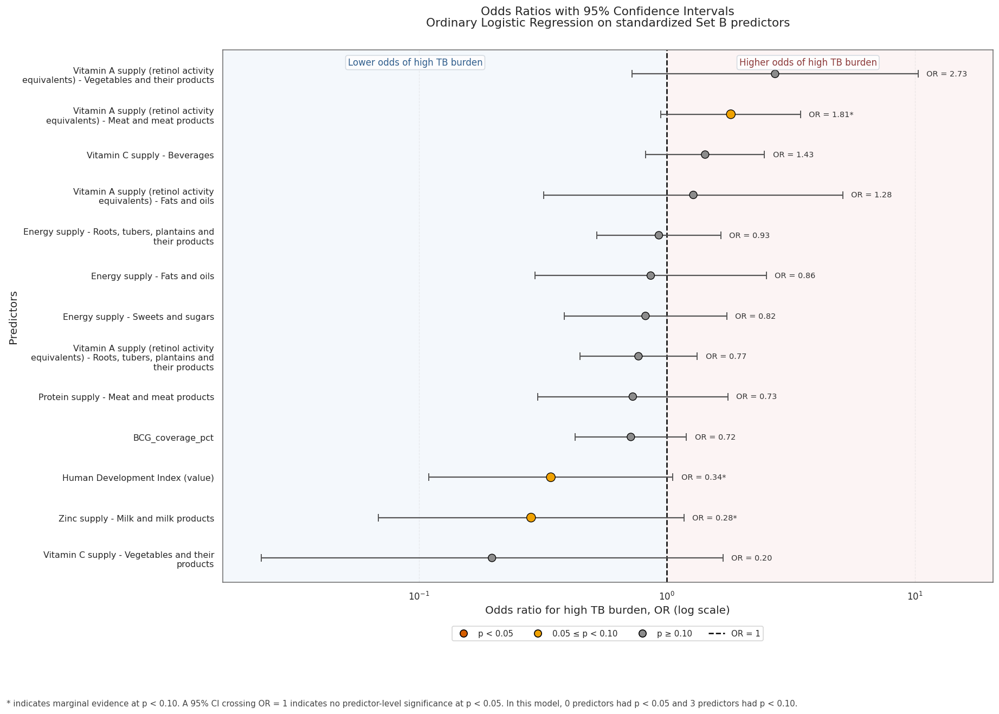

Final thesis-ready odds ratio figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/25_final_logistic_regression_set_b_odds_ratios_95ci.png

Odds ratio plot interpretation:
- OR < 1 indicates lower odds of high TB burden.
- OR > 1 indicates higher odds of high TB burden.
- A 95% confidence interval crossing OR = 1 indicates no predictor-level significance at p < 0.05.
- Predictors marked with * have marginal evidence at p < 0.10.
- Predictors with p < 0.05: 0
- Predictors with p < 0.10: 3


In [87]:
# Step 11E1: Final thesis-ready odds ratio plot with 95% confidence intervals
# for ordinary Logistic Regression on Set B

# Purpose:
#   To visualize odds ratios and 95% confidence intervals for the
#   ordinary Logistic Regression model fitted on standardized Set B predictors.
#
# Important:
#   - This cell uses coefficient results from Step 11C.
#   - It does not refit the model.
#   - It does not use the test set.
#   - It does not perform feature selection.
#   - Odds ratios are interpreted per one standard deviation increase
#     because predictors were standardized before model fitting.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap
from matplotlib.lines import Line2D

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_final_or_plot = [
    "logreg_set_b_predictor_coefficients",
    "FIGURES_DIR"
]

missing_objects_for_final_or_plot = [
    object_name
    for object_name in required_objects_for_final_or_plot
    if object_name not in globals()
]

if missing_objects_for_final_or_plot:
    raise NameError(
        "Missing required objects for final odds ratio plot: "
        f"{missing_objects_for_final_or_plot}. "
        "Run Step 11C first."
    )

if not isinstance(logreg_set_b_predictor_coefficients, pd.DataFrame):
    raise TypeError(
        "logreg_set_b_predictor_coefficients must be a pandas DataFrame."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FINAL_LOGREG_SET_B_ODDS_RATIO_FIGURE_PATH = (
    FIGURES_DIR / "25_final_logistic_regression_set_b_odds_ratios_95ci.png"
)

# -------------------------------------------------------------------
# 2. Required columns
# -------------------------------------------------------------------

required_or_columns = [
    "feature",
    "odds_ratio",
    "odds_ratio_ci_lower_95",
    "odds_ratio_ci_upper_95",
    "p_value",
    "significant_at_0_05",
    "significant_at_0_10"
]

missing_or_columns = [
    column
    for column in required_or_columns
    if column not in logreg_set_b_predictor_coefficients.columns
]

if missing_or_columns:
    raise KeyError(
        "Missing required columns for final odds ratio plot: "
        f"{missing_or_columns}"
    )

# -------------------------------------------------------------------
# 3. Prepare plot table
# -------------------------------------------------------------------

odds_ratio_plot_table = (
    logreg_set_b_predictor_coefficients
    .copy()
    .sort_values(by="odds_ratio", ascending=True)
    .reset_index(drop=True)
)

def wrap_predictor_name(feature_name, width=46):
    """
    Wraps long predictor names for readable y-axis labels.
    """
    return "\n".join(textwrap.wrap(str(feature_name), width=width))


def classify_p_value_for_plot(p_value):
    """
    Classifies predictors by statistical evidence.
    """
    if pd.isna(p_value):
        return "Not available"

    if p_value < 0.05:
        return "p < 0.05"

    if p_value < 0.10:
        return "0.05 ≤ p < 0.10"

    return "p ≥ 0.10"


def get_marker_color(p_value):
    """
    Assigns marker color based on p-value category.
    """
    if pd.isna(p_value):
        return "#9A9A9A"

    if p_value < 0.05:
        return "#D55E00"   # statistically significant

    if p_value < 0.10:
        return "#F0A202"   # marginal evidence

    return "#8C8C8C"       # not statistically significant


def get_marker_size(p_value):
    """
    Slightly enlarges markers for predictors with p < 0.10.
    """
    if pd.isna(p_value):
        return 70

    if p_value < 0.10:
        return 95

    return 70


def format_or_label(row):
    """
    Creates compact odds ratio label.
    Adds an asterisk for marginal or stronger evidence at p < 0.10.
    """
    odds_ratio = row["odds_ratio"]
    p_value = row["p_value"]

    if pd.isna(odds_ratio):
        return "OR = NA"

    if pd.notna(p_value) and p_value < 0.10:
        return f"OR = {odds_ratio:.2f}*"

    return f"OR = {odds_ratio:.2f}"


odds_ratio_plot_table["feature_wrapped"] = (
    odds_ratio_plot_table["feature"]
    .apply(wrap_predictor_name)
)

odds_ratio_plot_table["p_value_plot_category"] = (
    odds_ratio_plot_table["p_value"]
    .apply(classify_p_value_for_plot)
)

odds_ratio_plot_table["marker_color"] = (
    odds_ratio_plot_table["p_value"]
    .apply(get_marker_color)
)

odds_ratio_plot_table["marker_size"] = (
    odds_ratio_plot_table["p_value"]
    .apply(get_marker_size)
)

odds_ratio_plot_table["or_label"] = (
    odds_ratio_plot_table
    .apply(format_or_label, axis=1)
)

# -------------------------------------------------------------------
# 4. Axis limits
# -------------------------------------------------------------------

finite_ci_lower = (
    odds_ratio_plot_table["odds_ratio_ci_lower_95"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

finite_ci_upper = (
    odds_ratio_plot_table["odds_ratio_ci_upper_95"]
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

if finite_ci_lower.empty or finite_ci_upper.empty:
    x_axis_lower = 0.05
    x_axis_upper = 12.0
else:
    x_axis_lower = max(
        0.01,
        float(finite_ci_lower.min()) * 0.70
    )

    # Extra right margin so OR labels are not clipped.
    x_axis_upper = float(finite_ci_upper.max()) * 2.00

    # Keep a reasonable minimum right side.
    x_axis_upper = max(x_axis_upper, 6.0)

# -------------------------------------------------------------------
# 5. Create plot
# -------------------------------------------------------------------

number_of_predictors = len(odds_ratio_plot_table)
figure_height = max(8.8, 0.70 * number_of_predictors + 2.6)

fig, ax = plt.subplots(figsize=(15.5, figure_height))

y_positions = np.arange(number_of_predictors)

lower_errors = (
    odds_ratio_plot_table["odds_ratio"]
    - odds_ratio_plot_table["odds_ratio_ci_lower_95"]
).values

upper_errors = (
    odds_ratio_plot_table["odds_ratio_ci_upper_95"]
    - odds_ratio_plot_table["odds_ratio"]
).values

# Background interpretation regions
ax.axvspan(
    x_axis_lower,
    1.0,
    color="#F4F8FC",
    alpha=0.95,
    zorder=0
)

ax.axvspan(
    1.0,
    x_axis_upper,
    color="#FCF4F4",
    alpha=0.95,
    zorder=0
)

# 95% confidence intervals
ax.errorbar(
    odds_ratio_plot_table["odds_ratio"],
    y_positions,
    xerr=[lower_errors, upper_errors],
    fmt="none",
    ecolor="#555555",
    elinewidth=1.35,
    capsize=4,
    capthick=1.15,
    zorder=2
)

# Odds ratio markers
ax.scatter(
    odds_ratio_plot_table["odds_ratio"],
    y_positions,
    s=odds_ratio_plot_table["marker_size"],
    c=odds_ratio_plot_table["marker_color"],
    edgecolors="black",
    linewidths=0.8,
    zorder=3
)

# Reference line OR = 1
ax.axvline(
    x=1.0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    zorder=1
)

ax.set_xscale("log")
ax.set_xlim(x_axis_lower, x_axis_upper)

ax.set_yticks(y_positions)
ax.set_yticklabels(
    odds_ratio_plot_table["feature_wrapped"],
    fontsize=9.5
)

ax.set_xlabel(
    "Odds ratio for high TB burden, OR (log scale)",
    fontsize=12
)

ax.set_ylabel(
    "Predictors",
    fontsize=12
)

# Main title and subtitle
title_text = (
    "Odds Ratios with 95% Confidence Intervals\n"
    "Ordinary Logistic Regression on standardized Set B predictors"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=26
)

title_object.set_linespacing(1.08)

# Direction labels inside the plot area
ax.text(
    0.25,
    0.985,
    "Lower odds of high TB burden",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    color="#2F5D8C",
    bbox=dict(
        boxstyle="round,pad=0.25",
        facecolor="white",
        edgecolor="#D0D7DE",
        alpha=0.85
    )
)

ax.text(
    0.76,
    0.985,
    "Higher odds of high TB burden",
    transform=ax.transAxes,
    ha="center",
    va="top",
    fontsize=10,
    color="#8C3A3A",
    bbox=dict(
        boxstyle="round,pad=0.25",
        facecolor="white",
        edgecolor="#D0D7DE",
        alpha=0.85
    )
)

# Grid and frame
ax.xaxis.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.yaxis.grid(False)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

# OR labels
for y_pos, (_, row) in enumerate(odds_ratio_plot_table.iterrows()):
    text_x = row["odds_ratio_ci_upper_95"] * 1.08

    ax.text(
        text_x,
        y_pos,
        row["or_label"],
        va="center",
        ha="left",
        fontsize=8.7,
        color="#333333"
    )

# Legend below the plot, not inside the data area
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#D55E00",
        markeredgecolor="black",
        markersize=8,
        label="p < 0.05"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#F0A202",
        markeredgecolor="black",
        markersize=8,
        label="0.05 ≤ p < 0.10"
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="w",
        markerfacecolor="#8C8C8C",
        markeredgecolor="black",
        markersize=8,
        label="p ≥ 0.10"
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="OR = 1"
    )
]

ax.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.075),
    ncol=4,
    fontsize=9,
    frameon=True
)

# Figure note
number_p_005 = int(
    (odds_ratio_plot_table["p_value"] < 0.05)
    .sum()
)

number_p_010 = int(
    (odds_ratio_plot_table["p_value"] < 0.10)
    .sum()
)

figure_note = (
    "* indicates marginal evidence at p < 0.10. "
    "A 95% CI crossing OR = 1 indicates no predictor-level significance at p < 0.05. "
    f"In this model, {number_p_005} predictors had p < 0.05 and {number_p_010} predictors had p < 0.10."
)

fig.text(
    0.01,
    0.018,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.085, 1, 0.955])

plt.savefig(
    FINAL_LOGREG_SET_B_ODDS_RATIO_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Final thesis-ready odds ratio figure saved to:")
print(FINAL_LOGREG_SET_B_ODDS_RATIO_FIGURE_PATH)

print()
print("Odds ratio plot interpretation:")
print("- OR < 1 indicates lower odds of high TB burden.")
print("- OR > 1 indicates higher odds of high TB burden.")
print("- A 95% confidence interval crossing OR = 1 indicates no predictor-level significance at p < 0.05.")
print("- Predictors marked with * have marginal evidence at p < 0.10.")
print(f"- Predictors with p < 0.05: {number_p_005}")
print(f"- Predictors with p < 0.10: {number_p_010}")

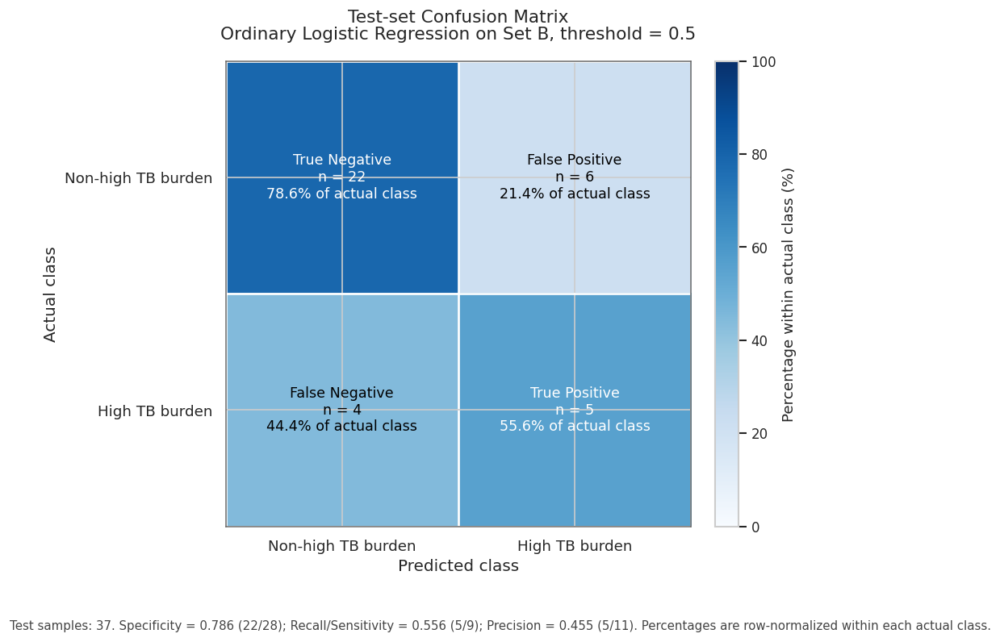

Final thesis-ready confusion matrix figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/26_final_logistic_regression_set_b_test_confusion_matrix.png

Confusion matrix counts:
TN = 22, FP = 6, FN = 4, TP = 5

Row-normalized interpretation:
Specificity for non-high TB burden = 0.7857 (22/28)
Recall/Sensitivity for high TB burden = 0.5556 (5/9)
Precision for predicted high TB burden = 0.4545 (5/11)


In [88]:
# Step 11E2: Final thesis-ready test-set confusion matrix
# for ordinary Logistic Regression on Set B

# Purpose:
#   To visualize the test-set confusion matrix for the ordinary Logistic
#   Regression model fitted on standardized Set B predictors.
#
# Important:
#   - This cell uses predictions from Step 11D.
#   - It does not refit the model.
#   - It does not tune the threshold.
#   - It uses the fixed threshold of 0.5 from Step 11D.
#   - Cell colors are based on row-normalized percentages so that
#     each actual class is interpreted separately.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_final_cm_plot = [
    "y_test_logreg_set_b",
    "logreg_set_b_test_pred",
    "FIGURES_DIR"
]

missing_objects_for_final_cm_plot = [
    object_name
    for object_name in required_objects_for_final_cm_plot
    if object_name not in globals()
]

if missing_objects_for_final_cm_plot:
    raise NameError(
        "Missing required objects for final confusion matrix plot: "
        f"{missing_objects_for_final_cm_plot}. "
        "Run Step 11D first."
    )

if not isinstance(y_test_logreg_set_b, pd.Series):
    raise TypeError(
        "y_test_logreg_set_b must be a pandas Series."
    )

if not isinstance(logreg_set_b_test_pred, pd.Series):
    raise TypeError(
        "logreg_set_b_test_pred must be a pandas Series."
    )

if not y_test_logreg_set_b.index.equals(logreg_set_b_test_pred.index):
    raise ValueError(
        "The indices of y_test_logreg_set_b and logreg_set_b_test_pred do not match."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

FINAL_LOGREG_SET_B_CONFUSION_MATRIX_FIGURE_PATH = (
    FIGURES_DIR / "26_final_logistic_regression_set_b_test_confusion_matrix.png"
)

# -------------------------------------------------------------------
# 2. Calculate confusion matrix
# -------------------------------------------------------------------

cm_counts = confusion_matrix(
    y_test_logreg_set_b.astype(int),
    logreg_set_b_test_pred.astype(int),
    labels=[0, 1]
)

tn, fp, fn, tp = cm_counts.ravel()

row_sums = cm_counts.sum(axis=1, keepdims=True)

cm_row_percentages = np.divide(
    cm_counts,
    row_sums,
    out=np.zeros_like(cm_counts, dtype=float),
    where=row_sums != 0
) * 100

total_test_samples = int(cm_counts.sum())

specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
recall_sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

# -------------------------------------------------------------------
# 3. Create plot
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.4, 7.0))

image = ax.imshow(
    cm_row_percentages,
    cmap="Blues",
    vmin=0,
    vmax=100
)

class_labels = [
    "Non-high TB burden",
    "High TB burden"
]

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(
    class_labels,
    fontsize=11
)

ax.set_yticklabels(
    class_labels,
    fontsize=11
)

ax.set_xlabel(
    "Predicted class",
    fontsize=12
)

ax.set_ylabel(
    "Actual class",
    fontsize=12
)

title_text = (
    "Test-set Confusion Matrix\n"
    "Ordinary Logistic Regression on Set B, threshold = 0.5"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

cell_names = np.array([
    ["True Negative", "False Positive"],
    ["False Negative", "True Positive"]
])

for i in range(2):
    for j in range(2):
        percentage_value = cm_row_percentages[i, j]
        count_value = cm_counts[i, j]

        text_color = "white" if percentage_value >= 55 else "black"

        ax.text(
            j,
            i,
            (
                f"{cell_names[i, j]}\n"
                f"n = {count_value}\n"
                f"{percentage_value:.1f}% of actual class"
            ),
            ha="center",
            va="center",
            fontsize=10.5,
            color=text_color
        )

# Grid lines between cells
ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1.6
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Colorbar
cbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Percentage within actual class (%)",
    fontsize=11
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

# Note under the figure
figure_note = (
    f"Test samples: {total_test_samples}. "
    f"Specificity = {specificity:.3f} ({tn}/{tn + fp}); "
    f"Recall/Sensitivity = {recall_sensitivity:.3f} ({tp}/{tp + fn}); "
    f"Precision = {precision:.3f} ({tp}/{tp + fp}). "
    "Percentages are row-normalized within each actual class."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.075, 1, 0.96])

plt.savefig(
    FINAL_LOGREG_SET_B_CONFUSION_MATRIX_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Final thesis-ready confusion matrix figure saved to:")
print(FINAL_LOGREG_SET_B_CONFUSION_MATRIX_FIGURE_PATH)

print()
print("Confusion matrix counts:")
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

print()
print("Row-normalized interpretation:")
print(f"Specificity for non-high TB burden = {specificity:.4f} ({tn}/{tn + fp})")
print(f"Recall/Sensitivity for high TB burden = {recall_sensitivity:.4f} ({tp}/{tp + fn})")
print(f"Precision for predicted high TB burden = {precision:.4f} ({tp}/{tp + fp})")

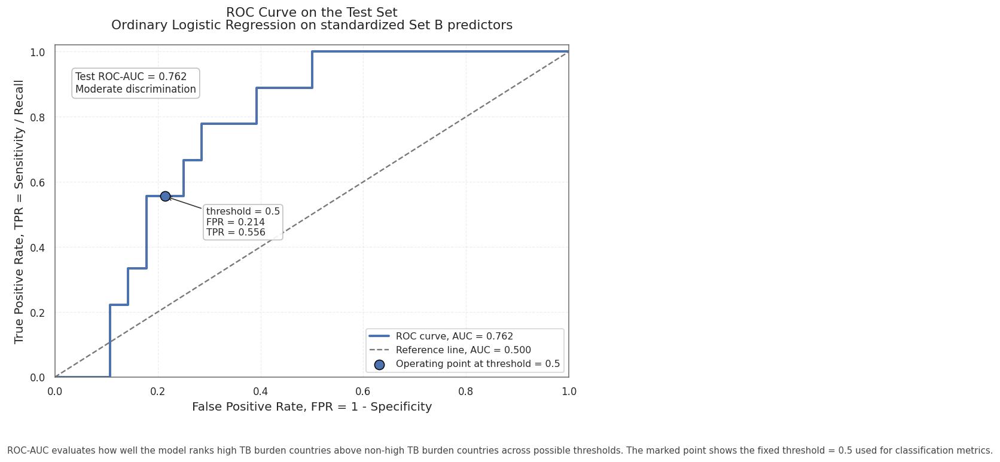

Final thesis-ready ROC figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/27_final_logistic_regression_set_b_test_roc_curve.png
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/27_final_logistic_regression_set_b_test_roc_curve.pdf

ROC threshold table saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/27_logistic_regression_set_b_test_roc_thresholds.csv

Test ROC-AUC = 0.7619
Threshold = 0.5 FPR = 0.2143
Threshold = 0.5 TPR / Recall = 0.5556
Threshold = 0.5 Specificity = 0.7857


In [89]:
# Step 11E3: Final thesis-ready ROC curve for test set
# for ordinary Logistic Regression on Set B

# Purpose:
#   To visualize the ROC curve on the test set for the ordinary Logistic
#   Regression model fitted on standardized Set B predictors.
#
# Important:
#   - This cell uses predicted probabilities from Step 11D.
#   - It does not refit the model.
#   - It does not tune the threshold.
#   - ROC curve evaluates discrimination across possible thresholds.
#   - The fixed threshold = 0.5 operating point is marked for reference.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix
)

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_final_roc_plot = [
    "y_test_logreg_set_b",
    "logreg_set_b_test_pred_proba",
    "FIGURES_DIR"
]

missing_objects_for_final_roc_plot = [
    object_name
    for object_name in required_objects_for_final_roc_plot
    if object_name not in globals()
]

if missing_objects_for_final_roc_plot:
    raise NameError(
        "Missing required objects for final ROC plot: "
        f"{missing_objects_for_final_roc_plot}. "
        "Run Step 11D first."
    )

if not isinstance(y_test_logreg_set_b, pd.Series):
    raise TypeError(
        "y_test_logreg_set_b must be a pandas Series."
    )

if not isinstance(logreg_set_b_test_pred_proba, pd.Series):
    raise TypeError(
        "logreg_set_b_test_pred_proba must be a pandas Series."
    )

if not y_test_logreg_set_b.index.equals(logreg_set_b_test_pred_proba.index):
    raise ValueError(
        "The indices of y_test_logreg_set_b and logreg_set_b_test_pred_proba do not match."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if "TABLES_DIR" in globals():
    TABLES_DIR = Path(TABLES_DIR)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
else:
    TABLES_DIR = Path("results") / "tables"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)

FINAL_LOGREG_SET_B_ROC_FIGURE_PNG_PATH = (
    FIGURES_DIR / "27_final_logistic_regression_set_b_test_roc_curve.png"
)

FINAL_LOGREG_SET_B_ROC_FIGURE_PDF_PATH = (
    FIGURES_DIR / "27_final_logistic_regression_set_b_test_roc_curve.pdf"
)

FINAL_LOGREG_SET_B_ROC_THRESHOLDS_CSV_PATH = (
    TABLES_DIR / "27_logistic_regression_set_b_test_roc_thresholds.csv"
)

# -------------------------------------------------------------------
# 2. Compute ROC curve and AUC
# -------------------------------------------------------------------

y_test_true = y_test_logreg_set_b.astype(int).copy()
y_test_probability = logreg_set_b_test_pred_proba.astype(float).copy()

if sorted(y_test_true.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_test_logreg_set_b must contain binary values [0, 1]."
    )

if (
    (y_test_probability < 0).any()
    or (y_test_probability > 1).any()
):
    raise ValueError(
        "Predicted probabilities must be between 0 and 1."
    )

fpr, tpr, roc_thresholds = roc_curve(
    y_test_true,
    y_test_probability
)

roc_auc_value = auc(
    fpr,
    tpr
)

roc_threshold_table = pd.DataFrame({
    "false_positive_rate": fpr,
    "true_positive_rate_sensitivity": tpr,
    "threshold": roc_thresholds
})

roc_threshold_table.to_csv(
    FINAL_LOGREG_SET_B_ROC_THRESHOLDS_CSV_PATH,
    index=False
)

# -------------------------------------------------------------------
# 3. Calculate operating point at threshold = 0.5
# -------------------------------------------------------------------

FIXED_CLASSIFICATION_THRESHOLD = 0.5

y_test_pred_threshold_05 = (
    y_test_probability >= FIXED_CLASSIFICATION_THRESHOLD
).astype(int)

cm_threshold_05 = confusion_matrix(
    y_test_true,
    y_test_pred_threshold_05,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_threshold_05.ravel()

threshold_05_fpr = (
    fp / (fp + tn)
    if (fp + tn) > 0
    else np.nan
)

threshold_05_tpr = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else np.nan
)

threshold_05_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

threshold_05_recall = threshold_05_tpr

# -------------------------------------------------------------------
# 4. Create thesis-ready ROC plot
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.2, 6.8))

# ROC curve
ax.plot(
    fpr,
    tpr,
    linewidth=2.4,
    label=f"ROC curve, AUC = {roc_auc_value:.3f}"
)

# Reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.4,
    color="#777777",
    label="Reference line, AUC = 0.500"
)

# Threshold = 0.5 operating point
ax.scatter(
    threshold_05_fpr,
    threshold_05_tpr,
    s=95,
    edgecolor="black",
    linewidth=0.9,
    zorder=4,
    label="Operating point at threshold = 0.5"
)

ax.annotate(
    (
        "threshold = 0.5\n"
        f"FPR = {threshold_05_fpr:.3f}\n"
        f"TPR = {threshold_05_tpr:.3f}"
    ),
    xy=(threshold_05_fpr, threshold_05_tpr),
    xytext=(threshold_05_fpr + 0.08, threshold_05_tpr - 0.12),
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.0,
        color="#333333"
    ),
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.30",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.90
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xlabel(
    "False Positive Rate, FPR = 1 - Specificity",
    fontsize=12
)

ax.set_ylabel(
    "True Positive Rate, TPR = Sensitivity / Recall",
    fontsize=12
)

title_text = (
    "ROC Curve on the Test Set\n"
    "Ordinary Logistic Regression on standardized Set B predictors"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

ax.legend(
    loc="lower right",
    fontsize=9.5,
    frameon=True
)

# AUC interpretation box
auc_interpretation_text = (
    f"Test ROC-AUC = {roc_auc_value:.3f}\n"
    "Moderate discrimination"
)

ax.text(
    0.04,
    0.92,
    auc_interpretation_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.92
    )
)

# Figure note
figure_note = (
    "ROC-AUC evaluates how well the model ranks high TB burden countries above non-high TB burden countries "
    "across possible thresholds. The marked point shows the fixed threshold = 0.5 used for classification metrics."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.075, 1, 0.96])

plt.savefig(
    FINAL_LOGREG_SET_B_ROC_FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FINAL_LOGREG_SET_B_ROC_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 5. Display outputs
# -------------------------------------------------------------------

print("Final thesis-ready ROC figure saved to:")
print(FINAL_LOGREG_SET_B_ROC_FIGURE_PNG_PATH)
print(FINAL_LOGREG_SET_B_ROC_FIGURE_PDF_PATH)

print()
print("ROC threshold table saved to:")
print(FINAL_LOGREG_SET_B_ROC_THRESHOLDS_CSV_PATH)

print()
print(f"Test ROC-AUC = {roc_auc_value:.4f}")
print(f"Threshold = 0.5 FPR = {threshold_05_fpr:.4f}")
print(f"Threshold = 0.5 TPR / Recall = {threshold_05_tpr:.4f}")
print(f"Threshold = 0.5 Specificity = {threshold_05_specificity:.4f}")

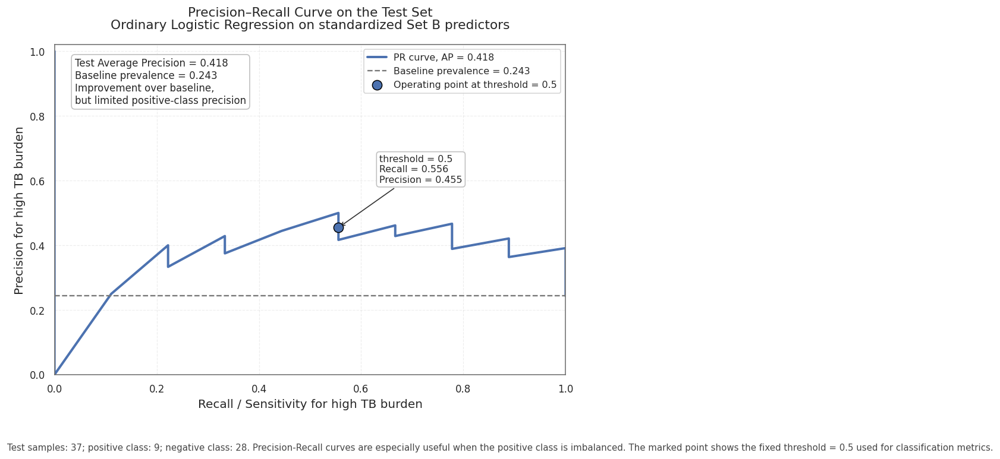

Final thesis-ready Precision-Recall figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/28_final_logistic_regression_set_b_test_precision_recall_curve.png
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/28_final_logistic_regression_set_b_test_precision_recall_curve.pdf

Precision-Recall threshold table saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/28_logistic_regression_set_b_test_precision_recall_thresholds.csv

Test Average Precision = 0.4182
Baseline positive prevalence = 0.2432
Threshold = 0.5 Precision = 0.4545
Threshold = 0.5 Recall / Sensitivity = 0.5556
Threshold = 0.5 F1-score = 0.5000
Test positives = 9
Test negatives = 28


In [90]:
# Step 11E4: Final thesis-ready Precision-Recall curve for test set
# for ordinary Logistic Regression on Set B

# Purpose:
#   To visualize the Precision-Recall curve on the test set for the ordinary
#   Logistic Regression model fitted on standardized Set B predictors.
#
# Important:
#   - This cell uses predicted probabilities from Step 11D.
#   - It does not refit the model.
#   - It does not tune the threshold.
#   - Precision-Recall curve is especially informative for imbalanced
#     binary classification.
#   - The fixed threshold = 0.5 operating point is marked for reference.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_final_pr_plot = [
    "y_test_logreg_set_b",
    "logreg_set_b_test_pred_proba",
    "FIGURES_DIR"
]

missing_objects_for_final_pr_plot = [
    object_name
    for object_name in required_objects_for_final_pr_plot
    if object_name not in globals()
]

if missing_objects_for_final_pr_plot:
    raise NameError(
        "Missing required objects for final Precision-Recall plot: "
        f"{missing_objects_for_final_pr_plot}. "
        "Run Step 11D first."
    )

if not isinstance(y_test_logreg_set_b, pd.Series):
    raise TypeError(
        "y_test_logreg_set_b must be a pandas Series."
    )

if not isinstance(logreg_set_b_test_pred_proba, pd.Series):
    raise TypeError(
        "logreg_set_b_test_pred_proba must be a pandas Series."
    )

if not y_test_logreg_set_b.index.equals(logreg_set_b_test_pred_proba.index):
    raise ValueError(
        "The indices of y_test_logreg_set_b and logreg_set_b_test_pred_proba do not match."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if "TABLES_DIR" in globals():
    TABLES_DIR = Path(TABLES_DIR)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
else:
    TABLES_DIR = Path("results") / "tables"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)

FINAL_LOGREG_SET_B_PR_FIGURE_PNG_PATH = (
    FIGURES_DIR / "28_final_logistic_regression_set_b_test_precision_recall_curve.png"
)

FINAL_LOGREG_SET_B_PR_FIGURE_PDF_PATH = (
    FIGURES_DIR / "28_final_logistic_regression_set_b_test_precision_recall_curve.pdf"
)

FINAL_LOGREG_SET_B_PR_THRESHOLDS_CSV_PATH = (
    TABLES_DIR / "28_logistic_regression_set_b_test_precision_recall_thresholds.csv"
)

# -------------------------------------------------------------------
# 2. Prepare data
# -------------------------------------------------------------------

y_test_true = y_test_logreg_set_b.astype(int).copy()
y_test_probability = logreg_set_b_test_pred_proba.astype(float).copy()

if sorted(y_test_true.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_test_logreg_set_b must contain binary values [0, 1]."
    )

if (
    (y_test_probability < 0).any()
    or (y_test_probability > 1).any()
):
    raise ValueError(
        "Predicted probabilities must be between 0 and 1."
    )

# -------------------------------------------------------------------
# 3. Compute Precision-Recall curve and Average Precision
# -------------------------------------------------------------------

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test_true,
    y_test_probability
)

average_precision_value = average_precision_score(
    y_test_true,
    y_test_probability
)

positive_prevalence = float(
    np.mean(y_test_true)
)

actual_positive_count = int(
    y_test_true.sum()
)

actual_negative_count = int(
    (y_test_true == 0).sum()
)

total_test_samples = int(
    y_test_true.shape[0]
)

# Threshold table has one fewer threshold than precision/recall arrays.
pr_threshold_table = pd.DataFrame({
    "threshold": pr_thresholds,
    "precision": precision_values[:-1],
    "recall_sensitivity": recall_values[:-1]
})

pr_threshold_table.to_csv(
    FINAL_LOGREG_SET_B_PR_THRESHOLDS_CSV_PATH,
    index=False
)

# -------------------------------------------------------------------
# 4. Calculate operating point at threshold = 0.5
# -------------------------------------------------------------------

FIXED_CLASSIFICATION_THRESHOLD = 0.5

y_test_pred_threshold_05 = (
    y_test_probability >= FIXED_CLASSIFICATION_THRESHOLD
).astype(int)

cm_threshold_05 = confusion_matrix(
    y_test_true,
    y_test_pred_threshold_05,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_threshold_05.ravel()

threshold_05_precision = (
    tp / (tp + fp)
    if (tp + fp) > 0
    else np.nan
)

threshold_05_recall = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else np.nan
)

threshold_05_f1 = (
    2 * threshold_05_precision * threshold_05_recall
    / (threshold_05_precision + threshold_05_recall)
    if (
        pd.notna(threshold_05_precision)
        and pd.notna(threshold_05_recall)
        and (threshold_05_precision + threshold_05_recall) > 0
    )
    else np.nan
)

# -------------------------------------------------------------------
# 5. Create thesis-ready Precision-Recall plot
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.2, 6.8))

# Precision-Recall curve
ax.plot(
    recall_values,
    precision_values,
    linewidth=2.4,
    label=f"PR curve, AP = {average_precision_value:.3f}"
)

# Baseline prevalence
ax.axhline(
    y=positive_prevalence,
    linestyle="--",
    linewidth=1.4,
    color="#777777",
    label=f"Baseline prevalence = {positive_prevalence:.3f}"
)

# Threshold = 0.5 operating point
ax.scatter(
    threshold_05_recall,
    threshold_05_precision,
    s=95,
    edgecolor="black",
    linewidth=0.9,
    zorder=4,
    label="Operating point at threshold = 0.5"
)

ax.annotate(
    (
        "threshold = 0.5\n"
        f"Recall = {threshold_05_recall:.3f}\n"
        f"Precision = {threshold_05_precision:.3f}"
    ),
    xy=(threshold_05_recall, threshold_05_precision),
    xytext=(threshold_05_recall + 0.08, threshold_05_precision + 0.14),
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.0,
        color="#333333"
    ),
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.30",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.90
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xlabel(
    "Recall / Sensitivity for high TB burden",
    fontsize=12
)

ax.set_ylabel(
    "Precision for high TB burden",
    fontsize=12
)

title_text = (
    "Precision–Recall Curve on the Test Set\n"
    "Ordinary Logistic Regression on standardized Set B predictors"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

ax.legend(
    loc="upper right",
    fontsize=9.5,
    frameon=True
)

# Interpretation box
ap_interpretation_text = (
    f"Test Average Precision = {average_precision_value:.3f}\n"
    f"Baseline prevalence = {positive_prevalence:.3f}\n"
    "Improvement over baseline,\n"
    "but limited positive-class precision"
)

ax.text(
    0.04,
    0.96,
    ap_interpretation_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.92
    )
)

# Figure note
figure_note = (
    f"Test samples: {total_test_samples}; positive class: {actual_positive_count}; "
    f"negative class: {actual_negative_count}. "
    "Precision-Recall curves are especially useful when the positive class is imbalanced. "
    "The marked point shows the fixed threshold = 0.5 used for classification metrics."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.075, 1, 0.96])

plt.savefig(
    FINAL_LOGREG_SET_B_PR_FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    FINAL_LOGREG_SET_B_PR_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 6. Display outputs
# -------------------------------------------------------------------

print("Final thesis-ready Precision-Recall figure saved to:")
print(FINAL_LOGREG_SET_B_PR_FIGURE_PNG_PATH)
print(FINAL_LOGREG_SET_B_PR_FIGURE_PDF_PATH)

print()
print("Precision-Recall threshold table saved to:")
print(FINAL_LOGREG_SET_B_PR_THRESHOLDS_CSV_PATH)

print()
print(f"Test Average Precision = {average_precision_value:.4f}")
print(f"Baseline positive prevalence = {positive_prevalence:.4f}")
print(f"Threshold = 0.5 Precision = {threshold_05_precision:.4f}")
print(f"Threshold = 0.5 Recall / Sensitivity = {threshold_05_recall:.4f}")
print(f"Threshold = 0.5 F1-score = {threshold_05_f1:.4f}")
print(f"Test positives = {actual_positive_count}")
print(f"Test negatives = {actual_negative_count}")

In [91]:
# Step 12A: Standardized Set A input preparation for ordinary logistic regression

# Purpose:
#   To prepare standardized Set A predictors for ordinary logistic regression.
#
# Set A definition:
#   Set A contains all valid predictors before Spearman-based pruning.
#   In this workflow, Set A predictor columns are taken from X_screening_train,
#   which represents the training-only valid predictor set used for statistical screening.
#
# Important:
#   - The scaler is fitted only on the training set.
#   - The same fitted scaler is applied to the test set.
#   - The test set is not used to estimate scaling parameters.
#   - No feature selection is performed in this cell.
#   - No model is fitted in this cell.
#   - No new train-test split is created.

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.preprocessing import StandardScaler

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logreg_set_a_input = [
    "X_train_all",
    "X_test_all",
    "y_train",
    "y_test",
    "X_screening_train",
    "TABLES_DIR"
]

missing_objects_for_logreg_set_a_input = [
    object_name
    for object_name in required_objects_for_logreg_set_a_input
    if object_name not in globals()
]

if missing_objects_for_logreg_set_a_input:
    raise NameError(
        "Missing required objects for Set A logistic regression input preparation: "
        f"{missing_objects_for_logreg_set_a_input}. "
        "Run the earlier train-test split and training-only screening preparation cells first."
    )

if not isinstance(X_train_all, pd.DataFrame):
    raise TypeError("X_train_all must be a pandas DataFrame.")

if not isinstance(X_test_all, pd.DataFrame):
    raise TypeError("X_test_all must be a pandas DataFrame.")

if not isinstance(y_train, pd.Series):
    raise TypeError("y_train must be a pandas Series.")

if not isinstance(y_test, pd.Series):
    raise TypeError("y_test must be a pandas Series.")

if not isinstance(X_screening_train, pd.DataFrame):
    raise TypeError("X_screening_train must be a pandas DataFrame.")

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

if "RESULTS_DIR" in globals():
    RESULTS_DIR = Path(RESULTS_DIR)
else:
    RESULTS_DIR = TABLES_DIR.parent


# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_A_SCALER_PARAMETERS_CSV_PATH = (
    TABLES_DIR / "29_logistic_regression_set_a_scaler_parameters.csv"
)

LOGREG_SET_A_SCALER_PARAMETERS_EXCEL_PATH = (
    TABLES_DIR / "29_logistic_regression_set_a_scaler_parameters.xlsx"
)

X_TRAIN_LOGREG_SET_A_STANDARDIZED_CSV_PATH = (
    TABLES_DIR / "29_X_train_logistic_regression_set_a_standardized.csv"
)

X_TEST_LOGREG_SET_A_STANDARDIZED_CSV_PATH = (
    TABLES_DIR / "29_X_test_logistic_regression_set_a_standardized.csv"
)

LOGREG_SET_A_INPUT_SUMMARY_CSV_PATH = (
    TABLES_DIR / "29_logistic_regression_set_a_input_summary.csv"
)

LOGREG_SET_A_INPUT_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "29_logistic_regression_set_a_input_summary.xlsx"
)

LOGREG_SET_A_PREDICTOR_LIST_CSV_PATH = (
    TABLES_DIR / "29_logistic_regression_set_a_predictor_list.csv"
)

LOGREG_SET_A_PREDICTOR_LIST_EXCEL_PATH = (
    TABLES_DIR / "29_logistic_regression_set_a_predictor_list.xlsx"
)


# -------------------------------------------------------------------
# 3. Define Set A predictor columns
# -------------------------------------------------------------------

# Set A is defined as all valid predictors used in training-only screening.
set_a_predictor_cols = list(X_screening_train.columns)

if len(set_a_predictor_cols) == 0:
    raise ValueError(
        "Set A predictor list is empty. X_screening_train has no columns."
    )

if len(set_a_predictor_cols) != len(set(set_a_predictor_cols)):
    duplicated_set_a_predictors = (
        pd.Series(set_a_predictor_cols)
        .loc[pd.Series(set_a_predictor_cols).duplicated()]
        .tolist()
    )

    raise ValueError(
        "Set A predictor list contains duplicated predictors: "
        f"{duplicated_set_a_predictors}"
    )


# -------------------------------------------------------------------
# 4. Train-test alignment validation
# -------------------------------------------------------------------

if X_train_all.shape[0] != y_train.shape[0]:
    raise ValueError(
        "X_train_all and y_train have different numbers of rows: "
        f"{X_train_all.shape[0]} vs {y_train.shape[0]}."
    )

if X_test_all.shape[0] != y_test.shape[0]:
    raise ValueError(
        "X_test_all and y_test have different numbers of rows: "
        f"{X_test_all.shape[0]} vs {y_test.shape[0]}."
    )

if not X_train_all.index.equals(y_train.index):
    raise ValueError(
        "The indices of X_train_all and y_train do not match."
    )

if not X_test_all.index.equals(y_test.index):
    raise ValueError(
        "The indices of X_test_all and y_test do not match."
    )

overlapping_train_test_indices = (
    set(X_train_all.index)
    .intersection(set(X_test_all.index))
)

if overlapping_train_test_indices:
    raise ValueError(
        "Training and testing sets have overlapping indices. "
        "This should not happen after a proper train-test split."
    )


# -------------------------------------------------------------------
# 5. Predictor availability validation
# -------------------------------------------------------------------

missing_set_a_predictors_in_train = [
    feature
    for feature in set_a_predictor_cols
    if feature not in X_train_all.columns
]

missing_set_a_predictors_in_test = [
    feature
    for feature in set_a_predictor_cols
    if feature not in X_test_all.columns
]

if missing_set_a_predictors_in_train:
    raise KeyError(
        "The following Set A predictors are missing from X_train_all: "
        f"{missing_set_a_predictors_in_train}"
    )

if missing_set_a_predictors_in_test:
    raise KeyError(
        "The following Set A predictors are missing from X_test_all: "
        f"{missing_set_a_predictors_in_test}"
    )


# -------------------------------------------------------------------
# 6. Basic leakage-name safety check
# -------------------------------------------------------------------

potential_leakage_keywords = [
    "target",
    "high_tb_burden",
    "tb_incidence",
    "incidence",
    "burden_class",
    "class_label"
]

potential_leakage_predictors = [
    feature
    for feature in set_a_predictor_cols
    if any(
        keyword.lower() in str(feature).lower()
        for keyword in potential_leakage_keywords
    )
]

if potential_leakage_predictors:
    raise ValueError(
        "Potential leakage predictors detected in Set A predictor columns: "
        f"{potential_leakage_predictors}. "
        "Review these predictors before fitting logistic regression."
    )


# -------------------------------------------------------------------
# 7. Prepare original Set A matrices
# -------------------------------------------------------------------

X_train_logreg_set_a_original = (
    X_train_all[set_a_predictor_cols]
    .copy()
)

X_test_logreg_set_a_original = (
    X_test_all[set_a_predictor_cols]
    .copy()
)

y_train_logreg_set_a = (
    y_train
    .astype(int)
    .copy()
)

y_test_logreg_set_a = (
    y_test
    .astype(int)
    .copy()
)


# -------------------------------------------------------------------
# 8. Numeric, missing, infinite and zero-variance validation
# -------------------------------------------------------------------

non_numeric_train_predictors_set_a = [
    feature
    for feature in set_a_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_train_logreg_set_a_original[feature])
]

non_numeric_test_predictors_set_a = [
    feature
    for feature in set_a_predictor_cols
    if not pd.api.types.is_numeric_dtype(X_test_logreg_set_a_original[feature])
]

if non_numeric_train_predictors_set_a:
    raise TypeError(
        "All Set A training predictors must be numeric. "
        f"Non-numeric predictors found: {non_numeric_train_predictors_set_a}"
    )

if non_numeric_test_predictors_set_a:
    raise TypeError(
        "All Set A testing predictors must be numeric. "
        f"Non-numeric predictors found: {non_numeric_test_predictors_set_a}"
    )

missing_values_train_set_a = int(
    X_train_logreg_set_a_original
    .isna()
    .sum()
    .sum()
)

missing_values_test_set_a = int(
    X_test_logreg_set_a_original
    .isna()
    .sum()
    .sum()
)

if missing_values_train_set_a > 0:
    raise ValueError(
        "Missing values found in X_train_logreg_set_a_original. "
        "Handle missing values before logistic regression."
    )

if missing_values_test_set_a > 0:
    raise ValueError(
        "Missing values found in X_test_logreg_set_a_original. "
        "Handle missing values before logistic regression."
    )

infinite_values_train_set_a = int(
    np.isinf(
        X_train_logreg_set_a_original
        .to_numpy(dtype=float)
    )
    .sum()
)

infinite_values_test_set_a = int(
    np.isinf(
        X_test_logreg_set_a_original
        .to_numpy(dtype=float)
    )
    .sum()
)

if infinite_values_train_set_a > 0:
    raise ValueError(
        "Infinite values found in X_train_logreg_set_a_original."
    )

if infinite_values_test_set_a > 0:
    raise ValueError(
        "Infinite values found in X_test_logreg_set_a_original."
    )

zero_variance_predictors_set_a = [
    feature
    for feature in set_a_predictor_cols
    if X_train_logreg_set_a_original[feature].nunique(dropna=True) <= 1
]

if zero_variance_predictors_set_a:
    raise ValueError(
        "The following Set A predictors have zero variance in the training set "
        "and cannot be used in logistic regression: "
        f"{zero_variance_predictors_set_a}"
    )

if sorted(y_train_logreg_set_a.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_train_logreg_set_a must contain binary values [0, 1]."
    )

if sorted(y_test_logreg_set_a.dropna().unique().tolist()) != [0, 1]:
    raise ValueError(
        "y_test_logreg_set_a must contain binary values [0, 1]."
    )


# -------------------------------------------------------------------
# 9. Fit StandardScaler on training set only
# -------------------------------------------------------------------

logreg_set_a_scaler = StandardScaler()

X_train_logreg_set_a_standardized_array = (
    logreg_set_a_scaler
    .fit_transform(X_train_logreg_set_a_original)
)

X_test_logreg_set_a_standardized_array = (
    logreg_set_a_scaler
    .transform(X_test_logreg_set_a_original)
)

X_train_logreg_set_a_standardized = pd.DataFrame(
    X_train_logreg_set_a_standardized_array,
    columns=set_a_predictor_cols,
    index=X_train_logreg_set_a_original.index
)

X_test_logreg_set_a_standardized = pd.DataFrame(
    X_test_logreg_set_a_standardized_array,
    columns=set_a_predictor_cols,
    index=X_test_logreg_set_a_original.index
)


# -------------------------------------------------------------------
# 10. Compatibility aliases for next Set A logistic regression cells
# -------------------------------------------------------------------

X_train_logreg_set_a = X_train_logreg_set_a_standardized.copy()
X_test_logreg_set_a = X_test_logreg_set_a_standardized.copy()

X_train_logistic_regression_set_a = X_train_logreg_set_a_standardized.copy()
X_test_logistic_regression_set_a = X_test_logreg_set_a_standardized.copy()

logistic_regression_set_a_predictor_cols = set_a_predictor_cols.copy()


# -------------------------------------------------------------------
# 11. Create scaler parameter table
# -------------------------------------------------------------------

logreg_set_a_scaler_parameters = pd.DataFrame({
    "feature": set_a_predictor_cols,
    "training_mean_used_by_scaler": logreg_set_a_scaler.mean_,
    "training_scale_used_by_scaler": logreg_set_a_scaler.scale_,
    "training_variance_used_by_scaler": logreg_set_a_scaler.var_,
    "original_training_mean": [
        X_train_logreg_set_a_original[feature].mean()
        for feature in set_a_predictor_cols
    ],
    "original_training_std_ddof_1": [
        X_train_logreg_set_a_original[feature].std(ddof=1)
        for feature in set_a_predictor_cols
    ],
    "standardized_training_mean": [
        X_train_logreg_set_a_standardized[feature].mean()
        for feature in set_a_predictor_cols
    ],
    "standardized_training_std_ddof_0": [
        X_train_logreg_set_a_standardized[feature].std(ddof=0)
        for feature in set_a_predictor_cols
    ],
    "standardized_training_std_ddof_1": [
        X_train_logreg_set_a_standardized[feature].std(ddof=1)
        for feature in set_a_predictor_cols
    ]
})


# -------------------------------------------------------------------
# 12. Create predictor list table
# -------------------------------------------------------------------

logreg_set_a_predictor_list_table = pd.DataFrame({
    "predictor_number": range(1, len(set_a_predictor_cols) + 1),
    "feature": set_a_predictor_cols
})


# -------------------------------------------------------------------
# 13. Create input preparation summary
# -------------------------------------------------------------------

logreg_set_a_input_summary = pd.DataFrame({
    "item": [
        "Model preparation step",
        "Predictor set",
        "Set A definition",
        "Number of predictors",
        "Training samples",
        "Testing samples",
        "Training input source",
        "Testing input source",
        "Training target source",
        "Testing target source",
        "Scaler",
        "Scaler fitted on",
        "Scaler applied to",
        "Test set used to fit scaler",
        "Target variable used to fit scaler",
        "Feature selection performed in this cell",
        "New train-test split created in this cell",
        "Missing values in standardized training input",
        "Missing values in standardized testing input",
        "Infinite values in standardized training input",
        "Infinite values in standardized testing input",
        "Interpretation of standardized coefficients"
    ],
    "value": [
        "Standardized input preparation for ordinary logistic regression",
        "Set A - all valid predictors before Spearman pruning",
        "Predictor columns taken from X_screening_train",
        len(set_a_predictor_cols),
        X_train_logreg_set_a_standardized.shape[0],
        X_test_logreg_set_a_standardized.shape[0],
        "X_train_all",
        "X_test_all",
        "y_train",
        "y_test",
        "StandardScaler",
        "X_train_all Set A columns only",
        "X_train_all and X_test_all Set A columns",
        "No",
        "No",
        "No",
        "No",
        int(X_train_logreg_set_a_standardized.isna().sum().sum()),
        int(X_test_logreg_set_a_standardized.isna().sum().sum()),
        int(np.isinf(X_train_logreg_set_a_standardized.to_numpy(dtype=float)).sum()),
        int(np.isinf(X_test_logreg_set_a_standardized.to_numpy(dtype=float)).sum()),
        "Per one standard deviation increase in the predictor"
    ]
})


# -------------------------------------------------------------------
# 14. Save outputs
# -------------------------------------------------------------------

logreg_set_a_scaler_parameters.to_csv(
    LOGREG_SET_A_SCALER_PARAMETERS_CSV_PATH,
    index=False
)

logreg_set_a_scaler_parameters.to_excel(
    LOGREG_SET_A_SCALER_PARAMETERS_EXCEL_PATH,
    index=False
)

X_train_logreg_set_a_standardized.to_csv(
    X_TRAIN_LOGREG_SET_A_STANDARDIZED_CSV_PATH,
    index=False
)

X_test_logreg_set_a_standardized.to_csv(
    X_TEST_LOGREG_SET_A_STANDARDIZED_CSV_PATH,
    index=False
)

logreg_set_a_input_summary.to_csv(
    LOGREG_SET_A_INPUT_SUMMARY_CSV_PATH,
    index=False
)

logreg_set_a_input_summary.to_excel(
    LOGREG_SET_A_INPUT_SUMMARY_EXCEL_PATH,
    index=False
)

logreg_set_a_predictor_list_table.to_csv(
    LOGREG_SET_A_PREDICTOR_LIST_CSV_PATH,
    index=False
)

logreg_set_a_predictor_list_table.to_excel(
    LOGREG_SET_A_PREDICTOR_LIST_EXCEL_PATH,
    index=False
)


# -------------------------------------------------------------------
# 15. Display outputs
# -------------------------------------------------------------------

def format_logreg_set_a_input_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(include=[np.number]).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(6)

    return display_table


print("Step 12A completed successfully.")
print("Standardized Set A input prepared for ordinary logistic regression.")
print()

print("Set A definition: all valid predictors before Spearman pruning.")
print("Set A predictor source: X_screening_train.columns")
print()

print("Training input used to fit scaler: X_train_all Set A columns")
print("Testing input transformed with fitted scaler: X_test_all Set A columns")
print("Test set used to fit scaler: No")
print("Target variable used to fit scaler: No")
print("Feature selection performed in this cell: No")
print("New train-test split created in this cell: No")
print()

print("X_train_logreg_set_a shape:", X_train_logreg_set_a.shape)
print("X_test_logreg_set_a shape:", X_test_logreg_set_a.shape)
print("y_train_logreg_set_a shape:", y_train_logreg_set_a.shape)
print("y_test_logreg_set_a shape:", y_test_logreg_set_a.shape)
print()

print("Number of Set A predictors:", len(set_a_predictor_cols))
print()

print("Scaler parameters CSV:")
print(LOGREG_SET_A_SCALER_PARAMETERS_CSV_PATH)
print()

print("Set A predictor list CSV:")
print(LOGREG_SET_A_PREDICTOR_LIST_CSV_PATH)
print()

print("Logistic regression Set A input summary CSV:")
print(LOGREG_SET_A_INPUT_SUMMARY_CSV_PATH)
print()

print("Set A input summary:")
display(logreg_set_a_input_summary)

print("Set A predictor list:")
display(logreg_set_a_predictor_list_table)

print("Scaler parameter table:")
display(
    format_logreg_set_a_input_display_table(
        logreg_set_a_scaler_parameters
    )
)

Step 12A completed successfully.
Standardized Set A input prepared for ordinary logistic regression.

Set A definition: all valid predictors before Spearman pruning.
Set A predictor source: X_screening_train.columns

Training input used to fit scaler: X_train_all Set A columns
Testing input transformed with fitted scaler: X_test_all Set A columns
Test set used to fit scaler: No
Target variable used to fit scaler: No
Feature selection performed in this cell: No
New train-test split created in this cell: No

X_train_logreg_set_a shape: (146, 46)
X_test_logreg_set_a shape: (37, 46)
y_train_logreg_set_a shape: (146,)
y_test_logreg_set_a shape: (37,)

Number of Set A predictors: 46

Scaler parameters CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/29_logistic_regression_set_a_scaler_parameters.csv

Set A predictor list CSV:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/29_logistic_regression_set_a_predictor_list.csv

Logistic regression Set

,item,value
0,Model preparation step,Standardized input preparation for ordinary lo...
1,Predictor set,Set A - all valid predictors before Spearman p...
2,Set A definition,Predictor columns taken from X_screening_train
3,Number of predictors,46
4,Training samples,146
5,Testing samples,37
6,Training input source,X_train_all
7,Testing input source,X_test_all
8,Training target source,y_train
9,Testing target source,y_test


Set A predictor list:


,predictor_number,feature
0,1,Calcium supply - Cereals and their products
1,2,Calcium supply - Milk and milk products
2,3,"Calcium supply - Pulses, seeds and nuts and th..."
3,4,Calcium supply - Vegetables and their products
4,5,Energy supply - Cereals and their products
5,6,Energy supply - Fats and oils
6,7,Energy supply - Meat and meat products
7,8,"Energy supply - Roots, tubers, plantains and t..."
8,9,Energy supply - Sweets and sugars
9,10,Iron supply - Cereals and their products


Scaler parameter table:


,feature,training_mean_used_by_scaler,training_scale_used_by_scaler,training_variance_used_by_scaler,original_training_mean,original_training_std_ddof_1,standardized_training_mean,standardized_training_std_ddof_0,standardized_training_std_ddof_1
0,Calcium supply - Cereals and their products,65.910959,25.175255,6.337934e+02,65.910959,25.261917,-0.0,1.0,1.003442
1,Calcium supply - Milk and milk products,389.219178,328.633190,1.079998e+05,389.219178,329.764461,0.0,1.0,1.003442
2,"Calcium supply - Pulses, seeds and nuts and th...",40.945205,41.233512,1.700202e+03,40.945205,41.375452,-0.0,1.0,1.003442
3,Calcium supply - Vegetables and their products,104.335616,103.067824,1.062298e+04,104.335616,103.422620,-0.0,1.0,1.003442
4,Energy supply - Cereals and their products,1029.746575,338.103429,1.143139e+05,1029.746575,339.267300,-0.0,1.0,1.003442
5,Energy supply - Fats and oils,397.232877,204.326191,4.174919e+04,397.232877,205.029553,-0.0,1.0,1.003442
6,Energy supply - Meat and meat products,252.890411,145.997379,2.131523e+04,252.890411,146.499953,-0.0,1.0,1.003442
7,"Energy supply - Roots, tubers, plantains and t...",204.863014,250.809255,6.290528e+04,204.863014,251.672629,-0.0,1.0,1.003442
8,Energy supply - Sweets and sugars,344.595890,155.533751,2.419075e+04,344.595890,156.069153,-0.0,1.0,1.003442
9,Iron supply - Cereals and their products,5.394521,2.096990,4.397367e+00,5.394521,2.104209,-0.0,1.0,1.003442


In [93]:
# Step 12B: Fit ordinary logistic regression on standardized Set A predictors

# Purpose:
#   To fit an ordinary, unregularized logistic regression model
#   using the standardized Set A predictors.
#
# Important:
#   - The model is fitted only on the training set.
#   - The test set is not used for model fitting.
#   - No regularization is applied.
#   - No class weighting is applied.
#   - No threshold tuning is performed in this cell.
#   - Set A is used as a comparison model, not as the main interpretable model.
#   - Because Set A contains more predictors, convergence and stability
#     diagnostics are reported carefully.

import numpy as np
import pandas as pd
from pathlib import Path
import warnings

import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationError

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logreg_set_a_fit = [
    "X_train_logreg_set_a",
    "X_test_logreg_set_a",
    "y_train_logreg_set_a",
    "y_test_logreg_set_a",
    "logistic_regression_set_a_predictor_cols",
    "TABLES_DIR"
]

missing_objects_for_logreg_set_a_fit = [
    object_name
    for object_name in required_objects_for_logreg_set_a_fit
    if object_name not in globals()
]

if missing_objects_for_logreg_set_a_fit:
    raise NameError(
        "Missing required objects for Set A ordinary logistic regression fitting: "
        f"{missing_objects_for_logreg_set_a_fit}. "
        "Run Step 12A first to prepare standardized Set A input."
    )

if not isinstance(X_train_logreg_set_a, pd.DataFrame):
    raise TypeError("X_train_logreg_set_a must be a pandas DataFrame.")

if not isinstance(X_test_logreg_set_a, pd.DataFrame):
    raise TypeError("X_test_logreg_set_a must be a pandas DataFrame.")

if not isinstance(y_train_logreg_set_a, pd.Series):
    raise TypeError("y_train_logreg_set_a must be a pandas Series.")

if not isinstance(y_test_logreg_set_a, pd.Series):
    raise TypeError("y_test_logreg_set_a must be a pandas Series.")

if not isinstance(logistic_regression_set_a_predictor_cols, (list, tuple, pd.Index)):
    raise TypeError(
        "logistic_regression_set_a_predictor_cols must be a list, tuple, or pandas Index."
    )

logistic_regression_set_a_predictor_cols = list(
    logistic_regression_set_a_predictor_cols
)

if len(logistic_regression_set_a_predictor_cols) == 0:
    raise ValueError("logistic_regression_set_a_predictor_cols is empty.")

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_A_MODEL_FIT_SUMMARY_CSV_PATH = (
    TABLES_DIR / "30_logistic_regression_set_a_model_fit_summary.csv"
)

LOGREG_SET_A_MODEL_FIT_SUMMARY_EXCEL_PATH = (
    TABLES_DIR / "30_logistic_regression_set_a_model_fit_summary.xlsx"
)

LOGREG_SET_A_MODEL_SUMMARY_TXT_PATH = (
    TABLES_DIR / "30_logistic_regression_set_a_statsmodels_summary.txt"
)

LOGREG_SET_A_MODEL_SUMMARY_HTML_PATH = (
    TABLES_DIR / "30_logistic_regression_set_a_statsmodels_summary.html"
)

# -------------------------------------------------------------------
# 3. Alignment and data validation
# -------------------------------------------------------------------

if X_train_logreg_set_a.shape[0] != y_train_logreg_set_a.shape[0]:
    raise ValueError(
        "X_train_logreg_set_a and y_train_logreg_set_a have different numbers of rows: "
        f"{X_train_logreg_set_a.shape[0]} vs {y_train_logreg_set_a.shape[0]}."
    )

if X_test_logreg_set_a.shape[0] != y_test_logreg_set_a.shape[0]:
    raise ValueError(
        "X_test_logreg_set_a and y_test_logreg_set_a have different numbers of rows: "
        f"{X_test_logreg_set_a.shape[0]} vs {y_test_logreg_set_a.shape[0]}."
    )

if not X_train_logreg_set_a.index.equals(y_train_logreg_set_a.index):
    raise ValueError(
        "The indices of X_train_logreg_set_a and y_train_logreg_set_a do not match."
    )

if not X_test_logreg_set_a.index.equals(y_test_logreg_set_a.index):
    raise ValueError(
        "The indices of X_test_logreg_set_a and y_test_logreg_set_a do not match."
    )

missing_logreg_set_a_predictors_train = [
    feature
    for feature in logistic_regression_set_a_predictor_cols
    if feature not in X_train_logreg_set_a.columns
]

missing_logreg_set_a_predictors_test = [
    feature
    for feature in logistic_regression_set_a_predictor_cols
    if feature not in X_test_logreg_set_a.columns
]

if missing_logreg_set_a_predictors_train:
    raise KeyError(
        "The following Set A predictors are missing from X_train_logreg_set_a: "
        f"{missing_logreg_set_a_predictors_train}"
    )

if missing_logreg_set_a_predictors_test:
    raise KeyError(
        "The following Set A predictors are missing from X_test_logreg_set_a: "
        f"{missing_logreg_set_a_predictors_test}"
    )

if sorted(y_train_logreg_set_a.dropna().unique().tolist()) != [0, 1]:
    raise ValueError("y_train_logreg_set_a must contain binary values [0, 1].")

if sorted(y_test_logreg_set_a.dropna().unique().tolist()) != [0, 1]:
    raise ValueError("y_test_logreg_set_a must contain binary values [0, 1].")

if X_train_logreg_set_a.isna().sum().sum() > 0:
    raise ValueError("Missing values found in X_train_logreg_set_a.")

if X_test_logreg_set_a.isna().sum().sum() > 0:
    raise ValueError("Missing values found in X_test_logreg_set_a.")

if np.isinf(X_train_logreg_set_a.to_numpy(dtype=float)).sum() > 0:
    raise ValueError("Infinite values found in X_train_logreg_set_a.")

if np.isinf(X_test_logreg_set_a.to_numpy(dtype=float)).sum() > 0:
    raise ValueError("Infinite values found in X_test_logreg_set_a.")

# -------------------------------------------------------------------
# 4. Prepare statsmodels design matrices
# -------------------------------------------------------------------

X_train_logreg_set_a_model = (
    X_train_logreg_set_a[logistic_regression_set_a_predictor_cols]
    .copy()
)

X_test_logreg_set_a_model = (
    X_test_logreg_set_a[logistic_regression_set_a_predictor_cols]
    .copy()
)

X_train_logreg_set_a_model_with_constant = sm.add_constant(
    X_train_logreg_set_a_model,
    has_constant="add"
)

X_test_logreg_set_a_model_with_constant = sm.add_constant(
    X_test_logreg_set_a_model,
    has_constant="add"
)

y_train_logreg_set_a_model = (
    y_train_logreg_set_a
    .astype(int)
    .copy()
)

y_test_logreg_set_a_model = (
    y_test_logreg_set_a
    .astype(int)
    .copy()
)

if "const" not in X_train_logreg_set_a_model_with_constant.columns:
    raise ValueError(
        "Intercept column 'const' was not added to the Set A training design matrix."
    )

if "const" not in X_test_logreg_set_a_model_with_constant.columns:
    raise ValueError(
        "Intercept column 'const' was not added to the Set A testing design matrix."
    )

# -------------------------------------------------------------------
# 5. Design matrix stability diagnostics
# -------------------------------------------------------------------

X_train_set_a_design_array = (
    X_train_logreg_set_a_model_with_constant
    .to_numpy(dtype=float)
)

set_a_design_matrix_rank = int(
    np.linalg.matrix_rank(X_train_set_a_design_array)
)

set_a_design_matrix_columns = int(
    X_train_set_a_design_array.shape[1]
)

set_a_design_matrix_full_rank = bool(
    set_a_design_matrix_rank == set_a_design_matrix_columns
)

try:
    set_a_design_matrix_condition_number = float(
        np.linalg.cond(X_train_set_a_design_array)
    )
except Exception:
    set_a_design_matrix_condition_number = np.nan

if not set_a_design_matrix_full_rank:
    print(
        "Warning: The Set A design matrix is not full rank. "
        "This suggests strong linear dependency among predictors."
    )

if (
    pd.notna(set_a_design_matrix_condition_number)
    and set_a_design_matrix_condition_number > 1000
):
    print(
        "Warning: The Set A design matrix has a high condition number. "
        "Coefficient estimates may be unstable due to multicollinearity."
    )

# -------------------------------------------------------------------
# 6. Fit ordinary logistic regression model
# -------------------------------------------------------------------

ordinary_logistic_regression_set_a_model = sm.Logit(
    y_train_logreg_set_a_model,
    X_train_logreg_set_a_model_with_constant
)

captured_fit_warnings = []

try:
    with warnings.catch_warnings(record=True) as warning_records:
        warnings.simplefilter("always")

        ordinary_logistic_regression_set_a_results = (
            ordinary_logistic_regression_set_a_model
            .fit(
                method="lbfgs",
                maxiter=3000,
                disp=False
            )
        )

        captured_fit_warnings = [
            str(warning_record.message)
            for warning_record in warning_records
        ]

except PerfectSeparationError as error:
    raise RuntimeError(
        "Perfect separation was detected while fitting the Set A ordinary logistic "
        "regression model. This means one or more predictors may separate the two "
        "classes too strongly. Since Set A contains many predictors, this can happen "
        "more easily than in Set B."
    ) from error

except np.linalg.LinAlgError as error:
    raise RuntimeError(
        "A linear algebra error occurred while fitting the Set A ordinary logistic "
        "regression model. This may be caused by severe multicollinearity or a "
        "rank-deficient design matrix."
    ) from error

# -------------------------------------------------------------------
# 7. Check convergence
# -------------------------------------------------------------------

logreg_set_a_mle_retvals = getattr(
    ordinary_logistic_regression_set_a_results,
    "mle_retvals",
    {}
)

logreg_set_a_converged = bool(
    logreg_set_a_mle_retvals.get("converged", False)
)

logreg_set_a_iterations = logreg_set_a_mle_retvals.get(
    "iterations",
    np.nan
)

if not logreg_set_a_converged:
    print(
        "Warning: The Set A ordinary logistic regression model did not fully converge. "
        "Interpret coefficients, p-values and odds ratios with caution."
    )
else:
    print("Set A ordinary logistic regression model converged successfully.")

if captured_fit_warnings:
    print()
    print("Warnings captured during Set A model fitting:")
    for warning_message in captured_fit_warnings:
        print("-", warning_message)

# -------------------------------------------------------------------
# 8. Extract model fit statistics
# -------------------------------------------------------------------

log_likelihood_model_set_a = (
    ordinary_logistic_regression_set_a_results
    .llf
)

log_likelihood_null_set_a = (
    ordinary_logistic_regression_set_a_results
    .llnull
)

if log_likelihood_null_set_a == 0:
    mcfadden_pseudo_r_squared_set_a = np.nan
else:
    mcfadden_pseudo_r_squared_set_a = 1 - (
        log_likelihood_model_set_a
        / log_likelihood_null_set_a
    )

logreg_set_a_model_fit_summary = pd.DataFrame({
    "item": [
        "Model",
        "Predictor set",
        "Model role",
        "Model type",
        "Regularization used",
        "Class weighting used",
        "Training input",
        "Test set used for fitting",
        "Target positive class",
        "Number of training samples",
        "Number of predictors",
        "Number of parameters including intercept",
        "Intercept included",
        "Optimization method",
        "Maximum iterations",
        "Converged",
        "Iterations reported by optimizer",
        "Log-likelihood",
        "Null log-likelihood",
        "McFadden pseudo R-squared",
        "AIC",
        "BIC",
        "Degrees of freedom model",
        "Degrees of freedom residuals",
        "Design matrix rank",
        "Design matrix columns",
        "Design matrix full rank",
        "Design matrix condition number",
        "Fit warnings captured",
        "Coefficient interpretation caution"
    ],
    "value": [
        "Ordinary Logistic Regression - Set A",
        "Set A - all valid standardized predictors before Spearman pruning",
        "Comparison model",
        "Statsmodels Logit",
        "No",
        "No",
        "X_train_logreg_set_a",
        "No",
        "high_tb_burden = 1",
        X_train_logreg_set_a_model_with_constant.shape[0],
        len(logistic_regression_set_a_predictor_cols),
        X_train_logreg_set_a_model_with_constant.shape[1],
        "Yes",
        "lbfgs",
        3000,
        logreg_set_a_converged,
        logreg_set_a_iterations,
        log_likelihood_model_set_a,
        log_likelihood_null_set_a,
        mcfadden_pseudo_r_squared_set_a,
        ordinary_logistic_regression_set_a_results.aic,
        ordinary_logistic_regression_set_a_results.bic,
        ordinary_logistic_regression_set_a_results.df_model,
        ordinary_logistic_regression_set_a_results.df_resid,
        set_a_design_matrix_rank,
        set_a_design_matrix_columns,
        set_a_design_matrix_full_rank,
        set_a_design_matrix_condition_number,
        " | ".join(captured_fit_warnings) if captured_fit_warnings else "None",
        (
            "Set A contains many predictors and may include multicollinearity. "
            "Coefficient-level interpretation should be more cautious than for Set B."
        )
    ]
})

# -------------------------------------------------------------------
# 9. Save statsmodels summaries
# -------------------------------------------------------------------

with open(LOGREG_SET_A_MODEL_SUMMARY_TXT_PATH, "w", encoding="utf-8") as file:
    file.write(
        ordinary_logistic_regression_set_a_results
        .summary2()
        .as_text()
    )

with open(LOGREG_SET_A_MODEL_SUMMARY_HTML_PATH, "w", encoding="utf-8") as file:
    file.write(
        ordinary_logistic_regression_set_a_results
        .summary2()
        .as_html()
    )

logreg_set_a_model_fit_summary.to_csv(
    LOGREG_SET_A_MODEL_FIT_SUMMARY_CSV_PATH,
    index=False
)

logreg_set_a_model_fit_summary.to_excel(
    LOGREG_SET_A_MODEL_FIT_SUMMARY_EXCEL_PATH,
    index=False
)

# -------------------------------------------------------------------
# 10. Compatibility aliases for later Set A cells
# -------------------------------------------------------------------

logreg_set_a_model = ordinary_logistic_regression_set_a_model
logreg_set_a_results = ordinary_logistic_regression_set_a_results

X_train_logreg_set_a_with_constant = (
    X_train_logreg_set_a_model_with_constant
    .copy()
)

X_test_logreg_set_a_with_constant = (
    X_test_logreg_set_a_model_with_constant
    .copy()
)

# -------------------------------------------------------------------
# 11. Display outputs
# -------------------------------------------------------------------

def format_logreg_set_a_fit_summary_table(display_table):
    display_table = display_table.copy()

    numeric_items = [
        "Iterations reported by optimizer",
        "Log-likelihood",
        "Null log-likelihood",
        "McFadden pseudo R-squared",
        "AIC",
        "BIC",
        "Degrees of freedom model",
        "Degrees of freedom residuals",
        "Design matrix rank",
        "Design matrix columns",
        "Design matrix condition number"
    ]

    display_table["value"] = display_table.apply(
        lambda row: (
            round(float(row["value"]), 6)
            if row["item"] in numeric_items and pd.notna(row["value"])
            else row["value"]
        ),
        axis=1
    )

    return display_table


print("Step 12B completed successfully.")
print("Ordinary Logistic Regression on Set A was fitted using statsmodels Logit.")
print()

print("Model converged:", logreg_set_a_converged)
print("Training samples:", X_train_logreg_set_a_with_constant.shape[0])
print("Predictors:", len(logistic_regression_set_a_predictor_cols))
print("Parameters including intercept:", X_train_logreg_set_a_with_constant.shape[1])
print("Intercept included: Yes")
print("Test set used for fitting: No")
print("Regularization used: No")
print("Class weighting used: No")
print()

print("Design matrix full rank:", set_a_design_matrix_full_rank)
print("Design matrix rank:", set_a_design_matrix_rank)
print("Design matrix columns:", set_a_design_matrix_columns)
print("Design matrix condition number:", round(set_a_design_matrix_condition_number, 4))
print()

print("Model fit summary CSV:")
print(LOGREG_SET_A_MODEL_FIT_SUMMARY_CSV_PATH)
print()

print("Statsmodels summary TXT:")
print(LOGREG_SET_A_MODEL_SUMMARY_TXT_PATH)
print()

print("Model fit summary:")
display(
    format_logreg_set_a_fit_summary_table(
        logreg_set_a_model_fit_summary
    )
)

print("Statsmodels model summary:")
display(
    ordinary_logistic_regression_set_a_results
    .summary2()
    .tables[0]
)

Set A ordinary logistic regression model converged successfully.

Warnings captured during Set A model fitting:
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- overflow encountered in exp
- Inverting hessian failed, no bse or cov_params available
Step 12B completed successfully.
Ordinary Logistic Regression on Set A was fitted using statsmodels Logit.

Model converged: True
Training samples: 146
Predictors: 46
Parameters including intercept: 47
Intercept included: Yes
Test set used for fitting: No
Reg

,item,value
0,Model,Ordinary Logistic Regression - Set A
1,Predictor set,Set A - all valid standardized predictors befo...
2,Model role,Comparison model
3,Model type,Statsmodels Logit
4,Regularization used,No
5,Class weighting used,No
6,Training input,X_train_logreg_set_a
7,Test set used for fitting,No
8,Target positive class,high_tb_burden = 1
9,Number of training samples,146


Statsmodels model summary:


,0,1,2,3
0,Model:,Logit,Method:,MLE
1,Dependent Variable:,high_tb_burden,Pseudo R-squared:,1.000
2,Date:,2026-06-28 15:50,AIC:,94.0035
3,No. Observations:,146,BIC:,234.2330
4,Df Model:,46,Log-Likelihood:,-0.0017438
5,Df Residuals:,99,LL-Null:,-82.646
6,Converged:,1.0000,LLR p-value:,2.3335e-15
7,No. Iterations:,57.0000,Scale:,1.0000


In [95]:
# Step 12C: Predictive evaluation of ordinary logistic regression on Set A

# Purpose:
#   To evaluate the ordinary Logistic Regression model fitted on Set A
#   using train and test predictions.
#
# Important:
#   - This cell uses the fitted Set A model from Step 12B.
#   - It does not refit the model.
#   - It does not tune the threshold.
#   - The fixed classification threshold is 0.5.
#   - Because Set A showed fitting warnings, this evaluation is used
#     mainly for predictive comparison with Set B, not for coefficient-level interpretation.

import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    log_loss,
    brier_score_loss
)

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logreg_set_a_evaluation = [
    "logreg_set_a_results",
    "X_train_logreg_set_a_with_constant",
    "X_test_logreg_set_a_with_constant",
    "y_train_logreg_set_a",
    "y_test_logreg_set_a",
    "TABLES_DIR"
]

missing_objects_for_logreg_set_a_evaluation = [
    object_name
    for object_name in required_objects_for_logreg_set_a_evaluation
    if object_name not in globals()
]

if missing_objects_for_logreg_set_a_evaluation:
    raise NameError(
        "Missing required objects for Set A logistic regression evaluation: "
        f"{missing_objects_for_logreg_set_a_evaluation}. "
        "Run Step 12B first."
    )

if not isinstance(X_train_logreg_set_a_with_constant, pd.DataFrame):
    raise TypeError("X_train_logreg_set_a_with_constant must be a pandas DataFrame.")

if not isinstance(X_test_logreg_set_a_with_constant, pd.DataFrame):
    raise TypeError("X_test_logreg_set_a_with_constant must be a pandas DataFrame.")

if not isinstance(y_train_logreg_set_a, pd.Series):
    raise TypeError("y_train_logreg_set_a must be a pandas Series.")

if not isinstance(y_test_logreg_set_a, pd.Series):
    raise TypeError("y_test_logreg_set_a must be a pandas Series.")

if not X_train_logreg_set_a_with_constant.index.equals(y_train_logreg_set_a.index):
    raise ValueError(
        "The indices of X_train_logreg_set_a_with_constant and y_train_logreg_set_a do not match."
    )

if not X_test_logreg_set_a_with_constant.index.equals(y_test_logreg_set_a.index):
    raise ValueError(
        "The indices of X_test_logreg_set_a_with_constant and y_test_logreg_set_a do not match."
    )

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_A_METRICS_CSV_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_train_test_metrics.csv"
)

LOGREG_SET_A_METRICS_EXCEL_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_train_test_metrics.xlsx"
)

LOGREG_SET_A_CONFUSION_MATRIX_CSV_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_confusion_matrix_summary.csv"
)

LOGREG_SET_A_CONFUSION_MATRIX_EXCEL_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_confusion_matrix_summary.xlsx"
)

LOGREG_SET_A_TRAIN_PREDICTIONS_CSV_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_train_predictions.csv"
)

LOGREG_SET_A_TEST_PREDICTIONS_CSV_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_test_predictions.csv"
)

LOGREG_SET_A_PROBABILITY_DIAGNOSTICS_CSV_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_probability_diagnostics.csv"
)

LOGREG_SET_A_PROBABILITY_DIAGNOSTICS_EXCEL_PATH = (
    TABLES_DIR / "31_logistic_regression_set_a_probability_diagnostics.xlsx"
)

# -------------------------------------------------------------------
# 3. Generate predicted probabilities
# -------------------------------------------------------------------

CLASSIFICATION_THRESHOLD_SET_A = 0.5

y_train_logreg_set_a_true = y_train_logreg_set_a.astype(int).copy()
y_test_logreg_set_a_true = y_test_logreg_set_a.astype(int).copy()

logreg_set_a_train_pred_proba = pd.Series(
    logreg_set_a_results.predict(X_train_logreg_set_a_with_constant),
    index=X_train_logreg_set_a_with_constant.index,
    name="predicted_probability_high_tb_burden"
)

logreg_set_a_test_pred_proba = pd.Series(
    logreg_set_a_results.predict(X_test_logreg_set_a_with_constant),
    index=X_test_logreg_set_a_with_constant.index,
    name="predicted_probability_high_tb_burden"
)

# Validate predicted probabilities
for probability_series_name, probability_series in [
    ("logreg_set_a_train_pred_proba", logreg_set_a_train_pred_proba),
    ("logreg_set_a_test_pred_proba", logreg_set_a_test_pred_proba)
]:
    if probability_series.isna().sum() > 0:
        raise ValueError(
            f"Missing predicted probabilities found in {probability_series_name}."
        )

    if np.isinf(probability_series.to_numpy(dtype=float)).sum() > 0:
        raise ValueError(
            f"Infinite predicted probabilities found in {probability_series_name}."
        )

    if (
        (probability_series < -1e-12).any()
        or (probability_series > 1 + 1e-12).any()
    ):
        raise ValueError(
            f"Predicted probabilities in {probability_series_name} are outside [0, 1]."
        )

# Clip only for numerical stability in log-loss calculation.
logreg_set_a_train_pred_proba_clipped = np.clip(
    logreg_set_a_train_pred_proba,
    1e-15,
    1 - 1e-15
)

logreg_set_a_test_pred_proba_clipped = np.clip(
    logreg_set_a_test_pred_proba,
    1e-15,
    1 - 1e-15
)

# Convert probabilities into class predictions using threshold = 0.5
logreg_set_a_train_pred = pd.Series(
    (logreg_set_a_train_pred_proba >= CLASSIFICATION_THRESHOLD_SET_A).astype(int),
    index=logreg_set_a_train_pred_proba.index,
    name="predicted_class"
)

logreg_set_a_test_pred = pd.Series(
    (logreg_set_a_test_pred_proba >= CLASSIFICATION_THRESHOLD_SET_A).astype(int),
    index=logreg_set_a_test_pred_proba.index,
    name="predicted_class"
)

# -------------------------------------------------------------------
# 4. Helper functions for metrics and confusion matrix
# -------------------------------------------------------------------

def calculate_binary_classification_metrics(
    dataset_name,
    y_true,
    y_pred,
    y_pred_proba,
    y_pred_proba_clipped,
    threshold
):
    """
    Calculates binary classification metrics for positive class = 1.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    accuracy = accuracy_score(y_true, y_pred)

    balanced_accuracy = balanced_accuracy_score(y_true, y_pred)

    precision_positive = precision_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    recall_sensitivity = recall_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    f1_positive = f1_score(
        y_true,
        y_pred,
        pos_label=1,
        zero_division=0
    )

    negative_predictive_value = (
        tn / (tn + fn)
        if (tn + fn) > 0
        else np.nan
    )

    false_positive_rate = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else np.nan
    )

    false_negative_rate = (
        fn / (fn + tp)
        if (fn + tp) > 0
        else np.nan
    )

    if len(np.unique(y_true)) == 2:
        roc_auc = roc_auc_score(y_true, y_pred_proba)
        average_precision = average_precision_score(y_true, y_pred_proba)
        model_log_loss = log_loss(y_true, y_pred_proba_clipped, labels=[0, 1])
    else:
        roc_auc = np.nan
        average_precision = np.nan
        model_log_loss = np.nan

    brier_score = brier_score_loss(
        y_true,
        y_pred_proba
    )

    actual_positive_count = int(np.sum(y_true == 1))
    actual_negative_count = int(np.sum(y_true == 0))

    predicted_positive_count = int(np.sum(y_pred == 1))
    predicted_negative_count = int(np.sum(y_pred == 0))

    return {
        "dataset": dataset_name,
        "threshold": threshold,
        "samples": int(len(y_true)),
        "actual_positive_count": actual_positive_count,
        "actual_negative_count": actual_negative_count,
        "predicted_positive_count": predicted_positive_count,
        "predicted_negative_count": predicted_negative_count,
        "actual_positive_fraction": actual_positive_count / len(y_true),
        "predicted_positive_fraction": predicted_positive_count / len(y_true),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "precision_positive_class": precision_positive,
        "recall_sensitivity_positive_class": recall_sensitivity,
        "specificity_negative_class": specificity,
        "f1_positive_class": f1_positive,
        "negative_predictive_value": negative_predictive_value,
        "false_positive_rate": false_positive_rate,
        "false_negative_rate": false_negative_rate,
        "roc_auc": roc_auc,
        "average_precision_pr_auc": average_precision,
        "log_loss": model_log_loss,
        "brier_score": brier_score
    }


def create_confusion_matrix_summary(
    dataset_name,
    y_true,
    y_pred
):
    """
    Creates a readable confusion matrix summary with row-normalized percentages.
    """

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    )

    total_samples = int(cm.sum())

    row_sums = cm.sum(axis=1, keepdims=True)

    row_percentages = np.divide(
        cm,
        row_sums,
        out=np.zeros_like(cm, dtype=float),
        where=row_sums != 0
    ) * 100

    total_percentages = (
        cm / total_samples * 100
        if total_samples > 0
        else np.zeros_like(cm, dtype=float)
    )

    rows = []

    cell_names = {
        (0, 0): "True Negative",
        (0, 1): "False Positive",
        (1, 0): "False Negative",
        (1, 1): "True Positive"
    }

    actual_labels = {
        0: "Actual non-high TB burden",
        1: "Actual high TB burden"
    }

    predicted_labels = {
        0: "Predicted non-high TB burden",
        1: "Predicted high TB burden"
    }

    for actual_class in [0, 1]:
        for predicted_class in [0, 1]:
            rows.append({
                "dataset": dataset_name,
                "cell": cell_names[(actual_class, predicted_class)],
                "actual_class": actual_class,
                "predicted_class": predicted_class,
                "actual_label": actual_labels[actual_class],
                "predicted_label": predicted_labels[predicted_class],
                "count": int(cm[actual_class, predicted_class]),
                "percentage_within_actual_class": row_percentages[actual_class, predicted_class],
                "percentage_of_total_dataset": total_percentages[actual_class, predicted_class]
            })

    return pd.DataFrame(rows)


def classify_prediction_outcome(actual, predicted):
    """
    Labels each prediction as TN, FP, FN or TP.
    """

    if actual == 0 and predicted == 0:
        return "True Negative"

    if actual == 0 and predicted == 1:
        return "False Positive"

    if actual == 1 and predicted == 0:
        return "False Negative"

    if actual == 1 and predicted == 1:
        return "True Positive"

    return "Undefined"


def create_prediction_table(
    dataset_name,
    y_true,
    y_pred,
    y_pred_proba
):
    """
    Creates prediction-level table.
    """

    prediction_table = pd.DataFrame({
        "dataset": dataset_name,
        "row_index": y_true.index,
        "actual_class": y_true.astype(int).values,
        "predicted_probability_high_tb_burden": y_pred_proba.values,
        "predicted_class": y_pred.astype(int).values
    })

    prediction_table["correct_prediction"] = (
        prediction_table["actual_class"]
        == prediction_table["predicted_class"]
    )

    prediction_table["prediction_outcome"] = prediction_table.apply(
        lambda row: classify_prediction_outcome(
            row["actual_class"],
            row["predicted_class"]
        ),
        axis=1
    )

    return prediction_table


def create_probability_diagnostics(
    dataset_name,
    y_pred_proba
):
    """
    Summarizes predicted probability behavior.
    Useful for detecting overconfident predictions.
    """

    y_pred_proba = pd.Series(y_pred_proba).astype(float)

    return {
        "dataset": dataset_name,
        "min_predicted_probability": y_pred_proba.min(),
        "q1_predicted_probability": y_pred_proba.quantile(0.25),
        "median_predicted_probability": y_pred_proba.median(),
        "q3_predicted_probability": y_pred_proba.quantile(0.75),
        "max_predicted_probability": y_pred_proba.max(),
        "mean_predicted_probability": y_pred_proba.mean(),
        "std_predicted_probability": y_pred_proba.std(ddof=1),
        "probabilities_below_or_equal_0_001": int((y_pred_proba <= 0.001).sum()),
        "probabilities_above_or_equal_0_999": int((y_pred_proba >= 0.999).sum()),
        "probabilities_below_or_equal_0_000001": int((y_pred_proba <= 0.000001).sum()),
        "probabilities_above_or_equal_0_999999": int((y_pred_proba >= 0.999999).sum())
    }

# -------------------------------------------------------------------
# 5. Calculate metrics
# -------------------------------------------------------------------

logreg_set_a_train_metrics = calculate_binary_classification_metrics(
    dataset_name="train",
    y_true=y_train_logreg_set_a_true,
    y_pred=logreg_set_a_train_pred,
    y_pred_proba=logreg_set_a_train_pred_proba,
    y_pred_proba_clipped=logreg_set_a_train_pred_proba_clipped,
    threshold=CLASSIFICATION_THRESHOLD_SET_A
)

logreg_set_a_test_metrics = calculate_binary_classification_metrics(
    dataset_name="test",
    y_true=y_test_logreg_set_a_true,
    y_pred=logreg_set_a_test_pred,
    y_pred_proba=logreg_set_a_test_pred_proba,
    y_pred_proba_clipped=logreg_set_a_test_pred_proba_clipped,
    threshold=CLASSIFICATION_THRESHOLD_SET_A
)

logreg_set_a_metrics = pd.DataFrame([
    logreg_set_a_train_metrics,
    logreg_set_a_test_metrics
])

# Add train-test gaps
metrics_for_gap = [
    "accuracy",
    "balanced_accuracy",
    "precision_positive_class",
    "recall_sensitivity_positive_class",
    "specificity_negative_class",
    "f1_positive_class",
    "roc_auc",
    "average_precision_pr_auc",
    "log_loss",
    "brier_score"
]

train_metrics_series = logreg_set_a_metrics.loc[
    logreg_set_a_metrics["dataset"] == "train"
].iloc[0]

test_metrics_series = logreg_set_a_metrics.loc[
    logreg_set_a_metrics["dataset"] == "test"
].iloc[0]

logreg_set_a_train_test_gap_table = pd.DataFrame({
    "metric": metrics_for_gap,
    "train_value": [
        train_metrics_series[metric]
        for metric in metrics_for_gap
    ],
    "test_value": [
        test_metrics_series[metric]
        for metric in metrics_for_gap
    ],
    "train_minus_test": [
        train_metrics_series[metric] - test_metrics_series[metric]
        for metric in metrics_for_gap
    ]
})

# -------------------------------------------------------------------
# 6. Confusion matrix summaries
# -------------------------------------------------------------------

logreg_set_a_train_confusion_summary = create_confusion_matrix_summary(
    dataset_name="train",
    y_true=y_train_logreg_set_a_true,
    y_pred=logreg_set_a_train_pred
)

logreg_set_a_test_confusion_summary = create_confusion_matrix_summary(
    dataset_name="test",
    y_true=y_test_logreg_set_a_true,
    y_pred=logreg_set_a_test_pred
)

logreg_set_a_confusion_matrix_summary = pd.concat(
    [
        logreg_set_a_train_confusion_summary,
        logreg_set_a_test_confusion_summary
    ],
    axis=0,
    ignore_index=True
)

# -------------------------------------------------------------------
# 7. Prediction-level tables
# -------------------------------------------------------------------

logreg_set_a_train_predictions_table = create_prediction_table(
    dataset_name="train",
    y_true=y_train_logreg_set_a_true,
    y_pred=logreg_set_a_train_pred,
    y_pred_proba=logreg_set_a_train_pred_proba
)

logreg_set_a_test_predictions_table = create_prediction_table(
    dataset_name="test",
    y_true=y_test_logreg_set_a_true,
    y_pred=logreg_set_a_test_pred,
    y_pred_proba=logreg_set_a_test_pred_proba
)

# -------------------------------------------------------------------
# 8. Probability diagnostics
# -------------------------------------------------------------------

logreg_set_a_probability_diagnostics = pd.DataFrame([
    create_probability_diagnostics(
        dataset_name="train",
        y_pred_proba=logreg_set_a_train_pred_proba
    ),
    create_probability_diagnostics(
        dataset_name="test",
        y_pred_proba=logreg_set_a_test_pred_proba
    )
])

# -------------------------------------------------------------------
# 9. Save outputs
# -------------------------------------------------------------------

logreg_set_a_metrics.to_csv(
    LOGREG_SET_A_METRICS_CSV_PATH,
    index=False
)

logreg_set_a_metrics.to_excel(
    LOGREG_SET_A_METRICS_EXCEL_PATH,
    index=False
)

logreg_set_a_confusion_matrix_summary.to_csv(
    LOGREG_SET_A_CONFUSION_MATRIX_CSV_PATH,
    index=False
)

logreg_set_a_confusion_matrix_summary.to_excel(
    LOGREG_SET_A_CONFUSION_MATRIX_EXCEL_PATH,
    index=False
)

logreg_set_a_train_predictions_table.to_csv(
    LOGREG_SET_A_TRAIN_PREDICTIONS_CSV_PATH,
    index=False
)

logreg_set_a_test_predictions_table.to_csv(
    LOGREG_SET_A_TEST_PREDICTIONS_CSV_PATH,
    index=False
)

logreg_set_a_probability_diagnostics.to_csv(
    LOGREG_SET_A_PROBABILITY_DIAGNOSTICS_CSV_PATH,
    index=False
)

logreg_set_a_probability_diagnostics.to_excel(
    LOGREG_SET_A_PROBABILITY_DIAGNOSTICS_EXCEL_PATH,
    index=False
)

# -------------------------------------------------------------------
# 10. Display outputs
# -------------------------------------------------------------------

def format_metric_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(include=[np.number]).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(6)

    return display_table


print("Step 12C completed successfully.")
print("Set A ordinary logistic regression predictive evaluation completed.")
print()

print("Important note:")
print(
    "Set A showed fitting warnings in Step 12B. "
    "Therefore, these results are used for predictive comparison, "
    "not for coefficient-level interpretation."
)
print()

print("Classification threshold:", CLASSIFICATION_THRESHOLD_SET_A)
print("Positive class: high_tb_burden = 1")
print()

print("Train/test metrics saved to:")
print(LOGREG_SET_A_METRICS_CSV_PATH)
print()

print("Confusion matrix summary saved to:")
print(LOGREG_SET_A_CONFUSION_MATRIX_CSV_PATH)
print()

print("Probability diagnostics saved to:")
print(LOGREG_SET_A_PROBABILITY_DIAGNOSTICS_CSV_PATH)
print()

print("Set A train/test metrics:")
display(format_metric_display_table(logreg_set_a_metrics))

print("Set A train-test gap table:")
display(format_metric_display_table(logreg_set_a_train_test_gap_table))

print("Set A test confusion matrix summary:")
display(
    format_metric_display_table(
        logreg_set_a_confusion_matrix_summary[
            logreg_set_a_confusion_matrix_summary["dataset"] == "test"
        ]
    )
)

print("Set A predicted probability diagnostics:")
display(
    format_metric_display_table(
        logreg_set_a_probability_diagnostics
    )
)

/usr/local/lib/python3.12/dist-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))


Step 12C completed successfully.
Set A ordinary logistic regression predictive evaluation completed.

Important note:
Set A showed fitting warnings in Step 12B. Therefore, these results are used for predictive comparison, not for coefficient-level interpretation.

Classification threshold: 0.5
Positive class: high_tb_burden = 1

Train/test metrics saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/31_logistic_regression_set_a_train_test_metrics.csv

Confusion matrix summary saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/31_logistic_regression_set_a_confusion_matrix_summary.csv

Probability diagnostics saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/31_logistic_regression_set_a_probability_diagnostics.csv

Set A train/test metrics:


,dataset,threshold,samples,actual_positive_count,actual_negative_count,predicted_positive_count,predicted_negative_count,actual_positive_fraction,predicted_positive_fraction,tn,fp,fn,tp,accuracy,balanced_accuracy,precision_positive_class,recall_sensitivity_positive_class,specificity_negative_class,f1_positive_class,negative_predictive_value,false_positive_rate,false_negative_rate,roc_auc,average_precision_pr_auc,log_loss,brier_score
0,train,0.5,146,37,109,37,109,0.253425,0.253425,109,0,0,37,1.000000,1.000000,1.000000,1.000000,1.000000,1.00,1.0,0.000000,0.000000,1.000000,1.000000,0.000012,0.000000
1,test,0.5,37,9,28,7,30,0.243243,0.189189,27,1,3,6,0.891892,0.815476,0.857143,0.666667,0.964286,0.75,0.9,0.035714,0.333333,0.882937,0.753178,3.733943,0.108108


Set A train-test gap table:


,metric,train_value,test_value,train_minus_test
0,accuracy,1.000000,0.891892,0.108108
1,balanced_accuracy,1.000000,0.815476,0.184524
2,precision_positive_class,1.000000,0.857143,0.142857
3,recall_sensitivity_positive_class,1.000000,0.666667,0.333333
4,specificity_negative_class,1.000000,0.964286,0.035714
5,f1_positive_class,1.000000,0.750000,0.250000
6,roc_auc,1.000000,0.882937,0.117063
7,average_precision_pr_auc,1.000000,0.753178,0.246822
8,log_loss,0.000012,3.733943,-3.733931
9,brier_score,0.000000,0.108108,-0.108108


Set A test confusion matrix summary:


,dataset,cell,actual_class,predicted_class,actual_label,predicted_label,count,percentage_within_actual_class,percentage_of_total_dataset
4,test,True Negative,0,0,Actual non-high TB burden,Predicted non-high TB burden,27,96.428571,72.972973
5,test,False Positive,0,1,Actual non-high TB burden,Predicted high TB burden,1,3.571429,2.702703
6,test,False Negative,1,0,Actual high TB burden,Predicted non-high TB burden,3,33.333333,8.108108
7,test,True Positive,1,1,Actual high TB burden,Predicted high TB burden,6,66.666667,16.216216


Set A predicted probability diagnostics:


,dataset,min_predicted_probability,q1_predicted_probability,median_predicted_probability,q3_predicted_probability,max_predicted_probability,mean_predicted_probability,std_predicted_probability,probabilities_below_or_equal_0_001,probabilities_above_or_equal_0_999,probabilities_below_or_equal_0_000001,probabilities_above_or_equal_0_999999
0,train,0.0,0.0,0.0,0.749739,1.0,0.253427,0.436457,109,37,101,30
1,test,0.0,0.0,0.0,0.000000,1.0,0.189189,0.397061,30,7,30,7


/usr/local/lib/python3.12/dist-packages/matplotlib/backends/backend_pdf.py:1761: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(rgb8, mode='P')


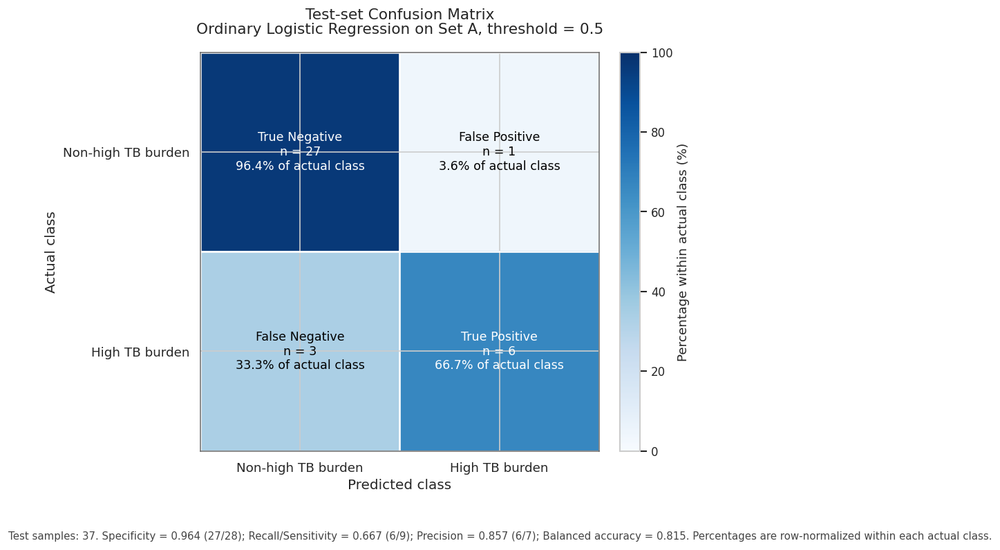

Final thesis-ready Set A confusion matrix figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/32_final_logistic_regression_set_a_test_confusion_matrix.png
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/32_final_logistic_regression_set_a_test_confusion_matrix.pdf

Set A confusion matrix counts:
TN = 27, FP = 1, FN = 3, TP = 6

Row-normalized interpretation:
Specificity for non-high TB burden = 0.9643 (27/28)
Recall/Sensitivity for high TB burden = 0.6667 (6/9)
Precision for predicted high TB burden = 0.8571 (6/7)
Balanced accuracy = 0.8155


In [97]:
# Step 12D1: Final thesis-ready test-set confusion matrix for Set A Logistic Regression

# Purpose:
#   To visualize the test-set confusion matrix for the ordinary Logistic
#   Regression model fitted on Set A.
#
# Important:
#   - This cell uses predictions from Step 12C.
#   - It does not refit the model.
#   - It does not tune the threshold.
#   - The fixed threshold is 0.5.
#   - Cell colors are based on row-normalized percentages.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_set_a_cm_plot = [
    "y_test_logreg_set_a",
    "logreg_set_a_test_pred",
    "FIGURES_DIR"
]

missing_objects_for_set_a_cm_plot = [
    object_name
    for object_name in required_objects_for_set_a_cm_plot
    if object_name not in globals()
]

if missing_objects_for_set_a_cm_plot:
    raise NameError(
        "Missing required objects for Set A confusion matrix plot: "
        f"{missing_objects_for_set_a_cm_plot}. "
        "Run Step 12C first."
    )

if not isinstance(y_test_logreg_set_a, pd.Series):
    raise TypeError("y_test_logreg_set_a must be a pandas Series.")

if not isinstance(logreg_set_a_test_pred, pd.Series):
    raise TypeError("logreg_set_a_test_pred must be a pandas Series.")

if not y_test_logreg_set_a.index.equals(logreg_set_a_test_pred.index):
    raise ValueError(
        "The indices of y_test_logreg_set_a and logreg_set_a_test_pred do not match."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SET_A_CONFUSION_MATRIX_PNG_PATH = (
    FIGURES_DIR / "32_final_logistic_regression_set_a_test_confusion_matrix.png"
)

SET_A_CONFUSION_MATRIX_PDF_PATH = (
    FIGURES_DIR / "32_final_logistic_regression_set_a_test_confusion_matrix.pdf"
)

# -------------------------------------------------------------------
# 2. Calculate confusion matrix
# -------------------------------------------------------------------

cm_counts = confusion_matrix(
    y_test_logreg_set_a.astype(int),
    logreg_set_a_test_pred.astype(int),
    labels=[0, 1]
)

tn, fp, fn, tp = cm_counts.ravel()

row_sums = cm_counts.sum(axis=1, keepdims=True)

cm_row_percentages = np.divide(
    cm_counts,
    row_sums,
    out=np.zeros_like(cm_counts, dtype=float),
    where=row_sums != 0
) * 100

total_test_samples = int(cm_counts.sum())

specificity = tn / (tn + fp) if (tn + fp) > 0 else np.nan
recall_sensitivity = tp / (tp + fn) if (tp + fn) > 0 else np.nan
precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan
balanced_accuracy = np.nanmean([specificity, recall_sensitivity])

# -------------------------------------------------------------------
# 3. Create plot
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.5, 7.0))

image = ax.imshow(
    cm_row_percentages,
    cmap="Blues",
    vmin=0,
    vmax=100
)

class_labels = [
    "Non-high TB burden",
    "High TB burden"
]

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels(class_labels, fontsize=11)
ax.set_yticklabels(class_labels, fontsize=11)

ax.set_xlabel("Predicted class", fontsize=12)
ax.set_ylabel("Actual class", fontsize=12)

title_text = (
    "Test-set Confusion Matrix\n"
    "Ordinary Logistic Regression on Set A, threshold = 0.5"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

cell_names = np.array([
    ["True Negative", "False Positive"],
    ["False Negative", "True Positive"]
])

for i in range(2):
    for j in range(2):
        percentage_value = cm_row_percentages[i, j]
        count_value = cm_counts[i, j]

        text_color = "white" if percentage_value >= 55 else "black"

        ax.text(
            j,
            i,
            (
                f"{cell_names[i, j]}\n"
                f"n = {count_value}\n"
                f"{percentage_value:.1f}% of actual class"
            ),
            ha="center",
            va="center",
            fontsize=10.5,
            color=text_color
        )

# Grid lines between cells
ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 2, 1), minor=True)

ax.grid(
    which="minor",
    color="white",
    linestyle="-",
    linewidth=1.6
)

ax.tick_params(
    which="minor",
    bottom=False,
    left=False
)

# Colorbar
cbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Percentage within actual class (%)",
    fontsize=11
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

# Note under the figure
figure_note = (
    f"Test samples: {total_test_samples}. "
    f"Specificity = {specificity:.3f} ({tn}/{tn + fp}); "
    f"Recall/Sensitivity = {recall_sensitivity:.3f} ({tp}/{tp + fn}); "
    f"Precision = {precision:.3f} ({tp}/{tp + fp}); "
    f"Balanced accuracy = {balanced_accuracy:.3f}. "
    "Percentages are row-normalized within each actual class."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.075, 1, 0.96])

plt.savefig(
    SET_A_CONFUSION_MATRIX_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    SET_A_CONFUSION_MATRIX_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("Final thesis-ready Set A confusion matrix figure saved to:")
print(SET_A_CONFUSION_MATRIX_PNG_PATH)
print(SET_A_CONFUSION_MATRIX_PDF_PATH)

print()
print("Set A confusion matrix counts:")
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")

print()
print("Row-normalized interpretation:")
print(f"Specificity for non-high TB burden = {specificity:.4f} ({tn}/{tn + fp})")
print(f"Recall/Sensitivity for high TB burden = {recall_sensitivity:.4f} ({tp}/{tp + fn})")
print(f"Precision for predicted high TB burden = {precision:.4f} ({tp}/{tp + fp})")
print(f"Balanced accuracy = {balanced_accuracy:.4f}")

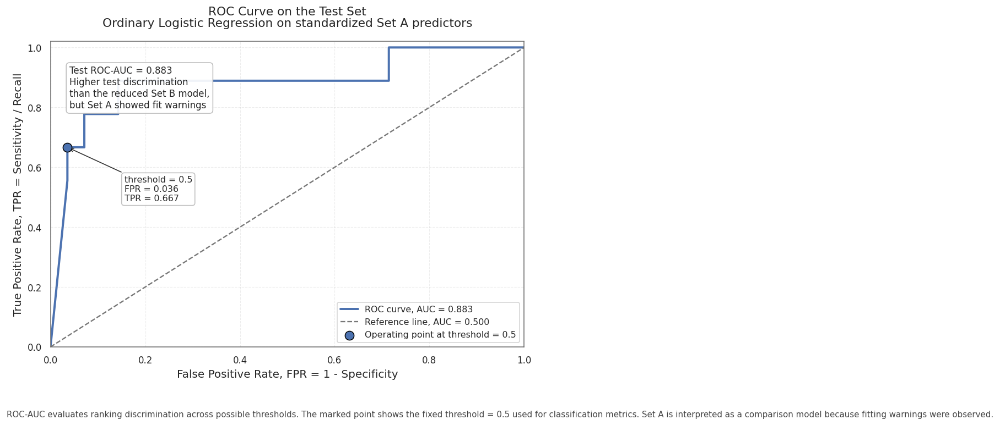

Final thesis-ready Set A ROC figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/33_final_logistic_regression_set_a_test_roc_curve.png
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/33_final_logistic_regression_set_a_test_roc_curve.pdf

Set A ROC threshold table saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/33_logistic_regression_set_a_test_roc_thresholds.csv

Set A test ROC-AUC = 0.8829
Threshold = 0.5 FPR = 0.0357
Threshold = 0.5 TPR / Recall = 0.6667
Threshold = 0.5 Specificity = 0.9643


In [98]:
# Step 12D2: Final thesis-ready ROC curve for Set A Logistic Regression

# Purpose:
#   To visualize the ROC curve on the test set for the ordinary Logistic
#   Regression model fitted on Set A.
#
# Important:
#   - This cell uses predicted probabilities from Step 12C.
#   - It does not refit the model.
#   - It does not tune the threshold.
#   - ROC curve evaluates discrimination across possible thresholds.
#   - The fixed threshold = 0.5 operating point is marked for reference.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    roc_curve,
    auc,
    confusion_matrix
)

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_set_a_roc_plot = [
    "y_test_logreg_set_a",
    "logreg_set_a_test_pred_proba",
    "FIGURES_DIR"
]

missing_objects_for_set_a_roc_plot = [
    object_name
    for object_name in required_objects_for_set_a_roc_plot
    if object_name not in globals()
]

if missing_objects_for_set_a_roc_plot:
    raise NameError(
        "Missing required objects for Set A ROC plot: "
        f"{missing_objects_for_set_a_roc_plot}. "
        "Run Step 12C first."
    )

if not isinstance(y_test_logreg_set_a, pd.Series):
    raise TypeError("y_test_logreg_set_a must be a pandas Series.")

if not isinstance(logreg_set_a_test_pred_proba, pd.Series):
    raise TypeError("logreg_set_a_test_pred_proba must be a pandas Series.")

if not y_test_logreg_set_a.index.equals(logreg_set_a_test_pred_proba.index):
    raise ValueError(
        "The indices of y_test_logreg_set_a and logreg_set_a_test_pred_proba do not match."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if "TABLES_DIR" in globals():
    TABLES_DIR = Path(TABLES_DIR)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
else:
    TABLES_DIR = Path("results") / "tables"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)

SET_A_ROC_FIGURE_PNG_PATH = (
    FIGURES_DIR / "33_final_logistic_regression_set_a_test_roc_curve.png"
)

SET_A_ROC_FIGURE_PDF_PATH = (
    FIGURES_DIR / "33_final_logistic_regression_set_a_test_roc_curve.pdf"
)

SET_A_ROC_THRESHOLDS_CSV_PATH = (
    TABLES_DIR / "33_logistic_regression_set_a_test_roc_thresholds.csv"
)

# -------------------------------------------------------------------
# 2. Compute ROC curve and AUC
# -------------------------------------------------------------------

y_test_true = y_test_logreg_set_a.astype(int).copy()
y_test_probability = logreg_set_a_test_pred_proba.astype(float).copy()

if sorted(y_test_true.dropna().unique().tolist()) != [0, 1]:
    raise ValueError("y_test_logreg_set_a must contain binary values [0, 1].")

if (
    (y_test_probability < -1e-12).any()
    or (y_test_probability > 1 + 1e-12).any()
):
    raise ValueError("Predicted probabilities must be between 0 and 1.")

y_test_probability = y_test_probability.clip(0, 1)

fpr, tpr, roc_thresholds = roc_curve(
    y_test_true,
    y_test_probability
)

roc_auc_value = auc(
    fpr,
    tpr
)

roc_threshold_table = pd.DataFrame({
    "false_positive_rate": fpr,
    "true_positive_rate_sensitivity": tpr,
    "threshold": roc_thresholds
})

roc_threshold_table.to_csv(
    SET_A_ROC_THRESHOLDS_CSV_PATH,
    index=False
)

# -------------------------------------------------------------------
# 3. Calculate operating point at threshold = 0.5
# -------------------------------------------------------------------

FIXED_CLASSIFICATION_THRESHOLD = 0.5

y_test_pred_threshold_05 = (
    y_test_probability >= FIXED_CLASSIFICATION_THRESHOLD
).astype(int)

cm_threshold_05 = confusion_matrix(
    y_test_true,
    y_test_pred_threshold_05,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_threshold_05.ravel()

threshold_05_fpr = (
    fp / (fp + tn)
    if (fp + tn) > 0
    else np.nan
)

threshold_05_tpr = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else np.nan
)

threshold_05_specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else np.nan
)

threshold_05_recall = threshold_05_tpr

# -------------------------------------------------------------------
# 4. Create thesis-ready ROC plot
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.2, 6.8))

# ROC curve
ax.plot(
    fpr,
    tpr,
    linewidth=2.4,
    label=f"ROC curve, AUC = {roc_auc_value:.3f}"
)

# Reference line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.4,
    color="#777777",
    label="Reference line, AUC = 0.500"
)

# Threshold = 0.5 operating point
ax.scatter(
    threshold_05_fpr,
    threshold_05_tpr,
    s=95,
    edgecolor="black",
    linewidth=0.9,
    zorder=4,
    label="Operating point at threshold = 0.5"
)

# Annotation
ax.annotate(
    (
        "threshold = 0.5\n"
        f"FPR = {threshold_05_fpr:.3f}\n"
        f"TPR = {threshold_05_tpr:.3f}"
    ),
    xy=(threshold_05_fpr, threshold_05_tpr),
    xytext=(min(threshold_05_fpr + 0.12, 0.72), max(threshold_05_tpr - 0.18, 0.10)),
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.0,
        color="#333333"
    ),
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.30",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.90
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xlabel(
    "False Positive Rate, FPR = 1 - Specificity",
    fontsize=12
)

ax.set_ylabel(
    "True Positive Rate, TPR = Sensitivity / Recall",
    fontsize=12
)

title_text = (
    "ROC Curve on the Test Set\n"
    "Ordinary Logistic Regression on standardized Set A predictors"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

ax.legend(
    loc="lower right",
    fontsize=9.5,
    frameon=True
)

# AUC interpretation box
auc_interpretation_text = (
    f"Test ROC-AUC = {roc_auc_value:.3f}\n"
    "Higher test discrimination\n"
    "than the reduced Set B model,\n"
    "but Set A showed fit warnings"
)

ax.text(
    0.04,
    0.92,
    auc_interpretation_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.92
    )
)

# Figure note
figure_note = (
    "ROC-AUC evaluates ranking discrimination across possible thresholds. "
    "The marked point shows the fixed threshold = 0.5 used for classification metrics. "
    "Set A is interpreted as a comparison model because fitting warnings were observed."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.075, 1, 0.96])

plt.savefig(
    SET_A_ROC_FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    SET_A_ROC_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 5. Display outputs
# -------------------------------------------------------------------

print("Final thesis-ready Set A ROC figure saved to:")
print(SET_A_ROC_FIGURE_PNG_PATH)
print(SET_A_ROC_FIGURE_PDF_PATH)

print()
print("Set A ROC threshold table saved to:")
print(SET_A_ROC_THRESHOLDS_CSV_PATH)

print()
print(f"Set A test ROC-AUC = {roc_auc_value:.4f}")
print(f"Threshold = 0.5 FPR = {threshold_05_fpr:.4f}")
print(f"Threshold = 0.5 TPR / Recall = {threshold_05_tpr:.4f}")
print(f"Threshold = 0.5 Specificity = {threshold_05_specificity:.4f}")

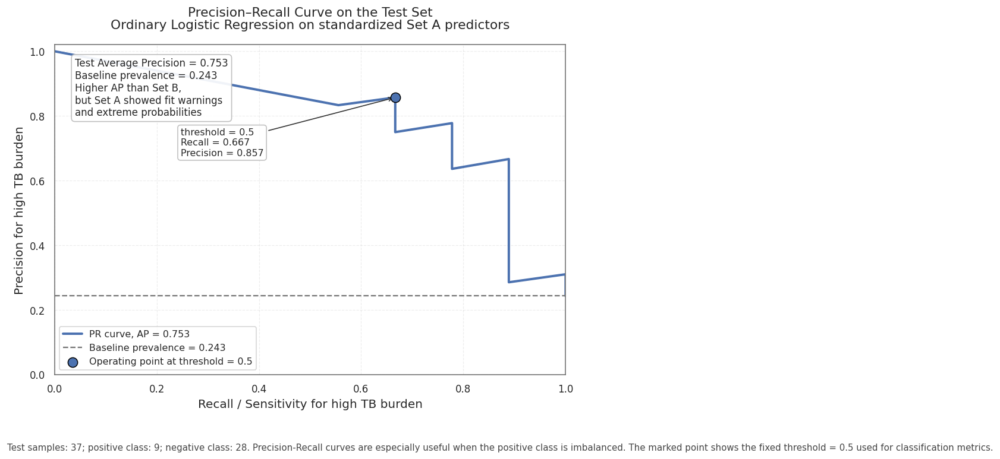

Final thesis-ready Set A Precision-Recall figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/34_final_logistic_regression_set_a_test_precision_recall_curve.png
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/34_final_logistic_regression_set_a_test_precision_recall_curve.pdf

Set A Precision-Recall threshold table saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/34_logistic_regression_set_a_test_precision_recall_thresholds.csv

Set A test Average Precision = 0.7532
Baseline positive prevalence = 0.2432
Threshold = 0.5 Precision = 0.8571
Threshold = 0.5 Recall / Sensitivity = 0.6667
Threshold = 0.5 F1-score = 0.7500
Test positives = 9
Test negatives = 28


In [96]:
# Step 12D3: Final thesis-ready Precision-Recall curve for Set A Logistic Regression

# Purpose:
#   To visualize the Precision-Recall curve on the test set for the ordinary
#   Logistic Regression model fitted on Set A.
#
# Important:
#   - This cell uses predicted probabilities from Step 12C.
#   - It does not refit the model.
#   - It does not tune the threshold.
#   - Precision-Recall curve focuses on the positive class.
#   - The fixed threshold = 0.5 operating point is marked for reference.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score,
    confusion_matrix
)

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_set_a_pr_plot = [
    "y_test_logreg_set_a",
    "logreg_set_a_test_pred_proba",
    "FIGURES_DIR"
]

missing_objects_for_set_a_pr_plot = [
    object_name
    for object_name in required_objects_for_set_a_pr_plot
    if object_name not in globals()
]

if missing_objects_for_set_a_pr_plot:
    raise NameError(
        "Missing required objects for Set A Precision-Recall plot: "
        f"{missing_objects_for_set_a_pr_plot}. "
        "Run Step 12C first."
    )

if not isinstance(y_test_logreg_set_a, pd.Series):
    raise TypeError("y_test_logreg_set_a must be a pandas Series.")

if not isinstance(logreg_set_a_test_pred_proba, pd.Series):
    raise TypeError("logreg_set_a_test_pred_proba must be a pandas Series.")

if not y_test_logreg_set_a.index.equals(logreg_set_a_test_pred_proba.index):
    raise ValueError(
        "The indices of y_test_logreg_set_a and logreg_set_a_test_pred_proba do not match."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if "TABLES_DIR" in globals():
    TABLES_DIR = Path(TABLES_DIR)
    TABLES_DIR.mkdir(parents=True, exist_ok=True)
else:
    TABLES_DIR = Path("results") / "tables"
    TABLES_DIR.mkdir(parents=True, exist_ok=True)

SET_A_PR_FIGURE_PNG_PATH = (
    FIGURES_DIR / "34_final_logistic_regression_set_a_test_precision_recall_curve.png"
)

SET_A_PR_FIGURE_PDF_PATH = (
    FIGURES_DIR / "34_final_logistic_regression_set_a_test_precision_recall_curve.pdf"
)

SET_A_PR_THRESHOLDS_CSV_PATH = (
    TABLES_DIR / "34_logistic_regression_set_a_test_precision_recall_thresholds.csv"
)

# -------------------------------------------------------------------
# 2. Prepare data
# -------------------------------------------------------------------

y_test_true = y_test_logreg_set_a.astype(int).copy()
y_test_probability = logreg_set_a_test_pred_proba.astype(float).copy()

if sorted(y_test_true.dropna().unique().tolist()) != [0, 1]:
    raise ValueError("y_test_logreg_set_a must contain binary values [0, 1].")

if (
    (y_test_probability < -1e-12).any()
    or (y_test_probability > 1 + 1e-12).any()
):
    raise ValueError("Predicted probabilities must be between 0 and 1.")

y_test_probability = y_test_probability.clip(0, 1)

# -------------------------------------------------------------------
# 3. Compute Precision-Recall curve and Average Precision
# -------------------------------------------------------------------

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test_true,
    y_test_probability
)

average_precision_value = average_precision_score(
    y_test_true,
    y_test_probability
)

positive_prevalence = float(
    np.mean(y_test_true)
)

actual_positive_count = int(
    y_test_true.sum()
)

actual_negative_count = int(
    (y_test_true == 0).sum()
)

total_test_samples = int(
    y_test_true.shape[0]
)

# Threshold table has one fewer threshold than precision/recall arrays.
pr_threshold_table = pd.DataFrame({
    "threshold": pr_thresholds,
    "precision": precision_values[:-1],
    "recall_sensitivity": recall_values[:-1]
})

pr_threshold_table.to_csv(
    SET_A_PR_THRESHOLDS_CSV_PATH,
    index=False
)

# -------------------------------------------------------------------
# 4. Calculate operating point at threshold = 0.5
# -------------------------------------------------------------------

FIXED_CLASSIFICATION_THRESHOLD = 0.5

y_test_pred_threshold_05 = (
    y_test_probability >= FIXED_CLASSIFICATION_THRESHOLD
).astype(int)

cm_threshold_05 = confusion_matrix(
    y_test_true,
    y_test_pred_threshold_05,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_threshold_05.ravel()

threshold_05_precision = (
    tp / (tp + fp)
    if (tp + fp) > 0
    else np.nan
)

threshold_05_recall = (
    tp / (tp + fn)
    if (tp + fn) > 0
    else np.nan
)

threshold_05_f1 = (
    2 * threshold_05_precision * threshold_05_recall
    / (threshold_05_precision + threshold_05_recall)
    if (
        pd.notna(threshold_05_precision)
        and pd.notna(threshold_05_recall)
        and (threshold_05_precision + threshold_05_recall) > 0
    )
    else np.nan
)

# -------------------------------------------------------------------
# 5. Create thesis-ready Precision-Recall plot
# -------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.2, 6.8))

# Precision-Recall curve
ax.plot(
    recall_values,
    precision_values,
    linewidth=2.4,
    label=f"PR curve, AP = {average_precision_value:.3f}"
)

# Baseline prevalence
ax.axhline(
    y=positive_prevalence,
    linestyle="--",
    linewidth=1.4,
    color="#777777",
    label=f"Baseline prevalence = {positive_prevalence:.3f}"
)

# Threshold = 0.5 operating point
ax.scatter(
    threshold_05_recall,
    threshold_05_precision,
    s=95,
    edgecolor="black",
    linewidth=0.9,
    zorder=4,
    label="Operating point at threshold = 0.5"
)

# Annotation
ax.annotate(
    (
        "threshold = 0.5\n"
        f"Recall = {threshold_05_recall:.3f}\n"
        f"Precision = {threshold_05_precision:.3f}"
    ),
    xy=(threshold_05_recall, threshold_05_precision),
    xytext=(max(threshold_05_recall - 0.42, 0.05), max(threshold_05_precision - 0.18, 0.10)),
    arrowprops=dict(
        arrowstyle="->",
        linewidth=1.0,
        color="#333333"
    ),
    fontsize=9.5,
    bbox=dict(
        boxstyle="round,pad=0.30",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.90
    )
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.set_xlabel(
    "Recall / Sensitivity for high TB burden",
    fontsize=12
)

ax.set_ylabel(
    "Precision for high TB burden",
    fontsize=12
)

title_text = (
    "Precision–Recall Curve on the Test Set\n"
    "Ordinary Logistic Regression on standardized Set A predictors"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

ax.legend(
    loc="lower left",
    fontsize=9.5,
    frameon=True
)

# Interpretation box
ap_interpretation_text = (
    f"Test Average Precision = {average_precision_value:.3f}\n"
    f"Baseline prevalence = {positive_prevalence:.3f}\n"
    "Higher AP than Set B,\n"
    "but Set A showed fit warnings\n"
    "and extreme probabilities"
)

ax.text(
    0.04,
    0.96,
    ap_interpretation_text,
    transform=ax.transAxes,
    ha="left",
    va="top",
    fontsize=10,
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#BBBBBB",
        alpha=0.92
    )
)

# Figure note
figure_note = (
    f"Test samples: {total_test_samples}; positive class: {actual_positive_count}; "
    f"negative class: {actual_negative_count}. "
    "Precision-Recall curves are especially useful when the positive class is imbalanced. "
    "The marked point shows the fixed threshold = 0.5 used for classification metrics."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.075, 1, 0.96])

plt.savefig(
    SET_A_PR_FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    SET_A_PR_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 6. Display outputs
# -------------------------------------------------------------------

print("Final thesis-ready Set A Precision-Recall figure saved to:")
print(SET_A_PR_FIGURE_PNG_PATH)
print(SET_A_PR_FIGURE_PDF_PATH)

print()
print("Set A Precision-Recall threshold table saved to:")
print(SET_A_PR_THRESHOLDS_CSV_PATH)

print()
print(f"Set A test Average Precision = {average_precision_value:.4f}")
print(f"Baseline positive prevalence = {positive_prevalence:.4f}")
print(f"Threshold = 0.5 Precision = {threshold_05_precision:.4f}")
print(f"Threshold = 0.5 Recall / Sensitivity = {threshold_05_recall:.4f}")
print(f"Threshold = 0.5 F1-score = {threshold_05_f1:.4f}")
print(f"Test positives = {actual_positive_count}")
print(f"Test negatives = {actual_negative_count}")

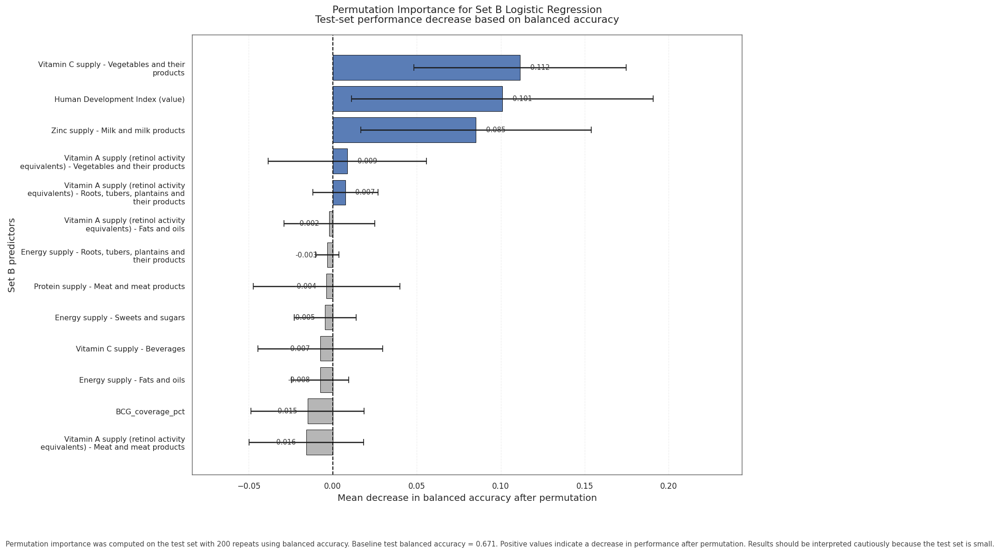

Step 14A completed successfully.
Permutation importance for Set B Logistic Regression was computed.

Model interpreted:
Ordinary Logistic Regression on Set B

Data used for permutation importance:
Test set

Scoring metric:
balanced_accuracy

Number of repeats:
200

Baseline Set B test balanced accuracy:
0.670635

Permutation importance table saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/35_logistic_regression_set_b_permutation_importance_balanced_accuracy.csv
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/35_logistic_regression_set_b_permutation_importance_balanced_accuracy.xlsx

Permutation importance figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/35_final_logistic_regression_set_b_permutation_importance_balanced_accuracy.png
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/35_final_logistic_regression_set_b_permutation_importance_balanced_accuracy.pdf

Set B permuta

,importance_rank,feature,importance_mean_decrease_in_balanced_accuracy,importance_std,importance_min,importance_max,absolute_importance_mean,importance_direction
0,1,Vitamin C supply - Vegetables and their products,0.111528,0.063123,-0.035714,0.313492,0.111528,Performance decreases when permuted
1,2,Human Development Index (value),0.100942,0.089820,-0.126984,0.313492,0.100942,Performance decreases when permuted
2,3,Zinc supply - Milk and milk products,0.085258,0.068527,-0.109127,0.277778,0.085258,Performance decreases when permuted
3,4,Vitamin A supply (retinol activity equivalents...,0.008690,0.047099,-0.111111,0.126984,0.008690,Performance decreases when permuted
4,5,Vitamin A supply (retinol activity equivalents...,0.007480,0.019425,-0.017857,0.073413,0.007480,Performance decreases when permuted
5,6,Vitamin A supply (retinol activity equivalents...,-0.002083,0.027046,-0.075397,0.035714,0.002083,Performance increases when permuted
6,7,"Energy supply - Roots, tubers, plantains and t...",-0.003214,0.006860,-0.017857,0.000000,0.003214,Performance increases when permuted
7,8,Protein supply - Meat and meat products,-0.003671,0.043697,-0.091270,0.111111,0.003671,Performance increases when permuted
8,9,Energy supply - Sweets and sugars,-0.004593,0.018434,-0.073413,0.055556,0.004593,Performance increases when permuted
9,10,Vitamin C supply - Beverages,-0.007440,0.037064,-0.128968,0.053571,0.007440,Performance increases when permuted


In [100]:
# Step 14A: Permutation importance for the Set B Logistic Regression model

# Purpose:
#   To estimate the predictive importance of Set B predictors using
#   permutation importance on the test set.
#
# Important:
#   - This cell uses the already fitted Set B logistic regression model.
#   - It does not refit the model.
#   - It does not perform feature selection.
#   - It does not tune the threshold.
#   - Permutation importance is computed on the test set.
#   - Balanced accuracy is used as the scoring metric.
#   - Results are interpreted as predictive importance, not statistical significance.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import textwrap

from sklearn.inspection import permutation_importance
from sklearn.metrics import balanced_accuracy_score
import statsmodels.api as sm

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_set_b_permutation_importance = [
    "logreg_set_b_results",
    "X_test_logreg_set_b",
    "y_test_logreg_set_b",
    "FIGURES_DIR",
    "TABLES_DIR"
]

missing_objects_for_set_b_permutation_importance = [
    object_name
    for object_name in required_objects_for_set_b_permutation_importance
    if object_name not in globals()
]

if missing_objects_for_set_b_permutation_importance:
    raise NameError(
        "Missing required objects for Set B permutation importance: "
        f"{missing_objects_for_set_b_permutation_importance}. "
        "Run the Set B logistic regression fitting and evaluation cells first."
    )

if not isinstance(X_test_logreg_set_b, pd.DataFrame):
    raise TypeError("X_test_logreg_set_b must be a pandas DataFrame.")

if not isinstance(y_test_logreg_set_b, pd.Series):
    raise TypeError("y_test_logreg_set_b must be a pandas Series.")

if not X_test_logreg_set_b.index.equals(y_test_logreg_set_b.index):
    raise ValueError(
        "The indices of X_test_logreg_set_b and y_test_logreg_set_b do not match."
    )

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

SET_B_PERMUTATION_IMPORTANCE_CSV_PATH = (
    TABLES_DIR / "35_logistic_regression_set_b_permutation_importance_balanced_accuracy.csv"
)

SET_B_PERMUTATION_IMPORTANCE_EXCEL_PATH = (
    TABLES_DIR / "35_logistic_regression_set_b_permutation_importance_balanced_accuracy.xlsx"
)

SET_B_PERMUTATION_IMPORTANCE_FIGURE_PNG_PATH = (
    FIGURES_DIR / "35_final_logistic_regression_set_b_permutation_importance_balanced_accuracy.png"
)

SET_B_PERMUTATION_IMPORTANCE_FIGURE_PDF_PATH = (
    FIGURES_DIR / "35_final_logistic_regression_set_b_permutation_importance_balanced_accuracy.pdf"
)

# -------------------------------------------------------------------
# 3. Wrapper for statsmodels Logit model
# -------------------------------------------------------------------

class StatsmodelsLogitWrapper:
    """
    Minimal sklearn-compatible wrapper for a fitted statsmodels Logit model.

    This wrapper allows sklearn's permutation_importance function to use
    the statsmodels logistic regression results.

    The fit method is included only for sklearn compatibility.
    It does not refit the model.
    """

    def __init__(self, fitted_results, threshold=0.5):
        self.fitted_results = fitted_results
        self.threshold = threshold

        self.design_columns = list(
            fitted_results.model.exog_names
        )

        self.feature_columns = [
            column
            for column in self.design_columns
            if column != "const"
        ]

        # sklearn-compatible attributes
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = len(self.feature_columns)
        self.feature_names_in_ = np.array(self.feature_columns)

    def fit(self, X, y=None):
        """
        Dummy fit method required by sklearn.

        The statsmodels model is already fitted in the earlier Set B
        logistic regression step, so this method intentionally does not
        refit anything.
        """
        return self

    def predict_proba(self, X):
        """
        Returns predicted probabilities in sklearn format:
        column 0 = probability for class 0
        column 1 = probability for class 1
        """

        X = pd.DataFrame(
            X,
            columns=self.feature_columns,
            index=getattr(X, "index", None)
        )

        X_with_constant = sm.add_constant(
            X,
            has_constant="add"
        )

        X_with_constant = X_with_constant.reindex(
            columns=self.design_columns,
            fill_value=1.0
        )

        predicted_probability_positive = self.fitted_results.predict(
            X_with_constant
        )

        predicted_probability_positive = np.asarray(
            predicted_probability_positive,
            dtype=float
        )

        predicted_probability_positive = np.clip(
            predicted_probability_positive,
            0,
            1
        )

        predicted_probability_negative = 1 - predicted_probability_positive

        return np.column_stack([
            predicted_probability_negative,
            predicted_probability_positive
        ])

    def predict(self, X):
        """
        Converts predicted probabilities into class predictions using
        the fixed classification threshold.
        """

        predicted_probability_positive = self.predict_proba(X)[:, 1]

        return (
            predicted_probability_positive >= self.threshold
        ).astype(int)


set_b_logit_sklearn_wrapper = StatsmodelsLogitWrapper(
    fitted_results=logreg_set_b_results,
    threshold=0.5
)

# -------------------------------------------------------------------
# 4. Feature alignment
# -------------------------------------------------------------------

expected_set_b_features = set_b_logit_sklearn_wrapper.feature_columns

missing_features_in_test = [
    feature
    for feature in expected_set_b_features
    if feature not in X_test_logreg_set_b.columns
]

if missing_features_in_test:
    raise KeyError(
        "The following Set B model features are missing from X_test_logreg_set_b: "
        f"{missing_features_in_test}"
    )

X_test_set_b_for_permutation = (
    X_test_logreg_set_b[expected_set_b_features]
    .copy()
)

y_test_set_b_for_permutation = (
    y_test_logreg_set_b
    .astype(int)
    .copy()
)

# -------------------------------------------------------------------
# 5. Baseline test performance before permutation
# -------------------------------------------------------------------

baseline_set_b_test_predictions = set_b_logit_sklearn_wrapper.predict(
    X_test_set_b_for_permutation
)

baseline_set_b_balanced_accuracy = balanced_accuracy_score(
    y_test_set_b_for_permutation,
    baseline_set_b_test_predictions
)

# -------------------------------------------------------------------
# 6. Permutation importance
# -------------------------------------------------------------------

PERMUTATION_N_REPEATS = 200
PERMUTATION_RANDOM_STATE = 42
PERMUTATION_SCORING = "balanced_accuracy"

set_b_permutation_result = permutation_importance(
    estimator=set_b_logit_sklearn_wrapper,
    X=X_test_set_b_for_permutation,
    y=y_test_set_b_for_permutation,
    scoring=PERMUTATION_SCORING,
    n_repeats=PERMUTATION_N_REPEATS,
    random_state=PERMUTATION_RANDOM_STATE,
    n_jobs=1
)

set_b_permutation_importance_table = pd.DataFrame({
    "feature": expected_set_b_features,
    "importance_mean_decrease_in_balanced_accuracy": set_b_permutation_result.importances_mean,
    "importance_std": set_b_permutation_result.importances_std,
    "importance_min": set_b_permutation_result.importances.min(axis=1),
    "importance_max": set_b_permutation_result.importances.max(axis=1)
})

set_b_permutation_importance_table["absolute_importance_mean"] = (
    set_b_permutation_importance_table[
        "importance_mean_decrease_in_balanced_accuracy"
    ]
    .abs()
)

set_b_permutation_importance_table["importance_direction"] = np.where(
    set_b_permutation_importance_table[
        "importance_mean_decrease_in_balanced_accuracy"
    ] > 0,
    "Performance decreases when permuted",
    np.where(
        set_b_permutation_importance_table[
            "importance_mean_decrease_in_balanced_accuracy"
        ] < 0,
        "Performance increases when permuted",
        "No average change"
    )
)

set_b_permutation_importance_table = (
    set_b_permutation_importance_table
    .sort_values(
        by="importance_mean_decrease_in_balanced_accuracy",
        ascending=False
    )
    .reset_index(drop=True)
)

set_b_permutation_importance_table.insert(
    0,
    "importance_rank",
    range(1, len(set_b_permutation_importance_table) + 1)
)

# -------------------------------------------------------------------
# 7. Save permutation importance table
# -------------------------------------------------------------------

set_b_permutation_importance_table.to_csv(
    SET_B_PERMUTATION_IMPORTANCE_CSV_PATH,
    index=False
)

set_b_permutation_importance_table.to_excel(
    SET_B_PERMUTATION_IMPORTANCE_EXCEL_PATH,
    index=False
)

# -------------------------------------------------------------------
# 8. Create thesis-ready visualization
# -------------------------------------------------------------------

plot_table = (
    set_b_permutation_importance_table
    .sort_values(
        by="importance_mean_decrease_in_balanced_accuracy",
        ascending=True
    )
    .copy()
)

def wrap_feature_name(feature_name, width=46):
    return "\n".join(
        textwrap.wrap(
            str(feature_name),
            width=width
        )
    )

plot_table["feature_wrapped"] = plot_table["feature"].apply(
    wrap_feature_name
)

bar_colors = np.where(
    plot_table["importance_mean_decrease_in_balanced_accuracy"] > 0,
    "#4C72B0",
    "#B0B0B0"
)

fig_height = max(
    8.5,
    0.62 * len(plot_table) + 2.4
)

fig, ax = plt.subplots(
    figsize=(13.5, fig_height)
)

y_positions = np.arange(len(plot_table))

ax.barh(
    y_positions,
    plot_table["importance_mean_decrease_in_balanced_accuracy"],
    xerr=plot_table["importance_std"],
    color=bar_colors,
    edgecolor="black",
    linewidth=0.6,
    alpha=0.92,
    capsize=4
)

ax.axvline(
    x=0,
    color="black",
    linestyle="--",
    linewidth=1.2
)

ax.set_yticks(y_positions)

ax.set_yticklabels(
    plot_table["feature_wrapped"],
    fontsize=9.5
)

ax.set_xlabel(
    "Mean decrease in balanced accuracy after permutation",
    fontsize=12
)

ax.set_ylabel(
    "Set B predictors",
    fontsize=12
)

title_text = (
    "Permutation Importance for Set B Logistic Regression\n"
    "Test-set performance decrease based on balanced accuracy"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.grid(
    axis="y",
    visible=False
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

# -------------------------------------------------------------------
# 9. Add value labels and axis limits
# -------------------------------------------------------------------

x_values = plot_table["importance_mean_decrease_in_balanced_accuracy"].values
x_errors = plot_table["importance_std"].values

x_min = min(
    0,
    np.nanmin(x_values - x_errors)
)

x_max = max(
    0,
    np.nanmax(x_values + x_errors)
)

x_range = x_max - x_min if x_max > x_min else 1

ax.set_xlim(
    x_min - 0.14 * x_range,
    x_max + 0.22 * x_range
)

for y_pos, (_, row) in enumerate(plot_table.iterrows()):
    value = row["importance_mean_decrease_in_balanced_accuracy"]

    label_x = (
        value + 0.025 * x_range
        if value >= 0
        else value - 0.025 * x_range
    )

    label_ha = "left" if value >= 0 else "right"

    ax.text(
        label_x,
        y_pos,
        f"{value:.3f}",
        va="center",
        ha=label_ha,
        fontsize=8.8,
        color="#333333"
    )

# -------------------------------------------------------------------
# 10. Figure note
# -------------------------------------------------------------------

figure_note = (
    f"Permutation importance was computed on the test set with "
    f"{PERMUTATION_N_REPEATS} repeats using balanced accuracy. "
    f"Baseline test balanced accuracy = {baseline_set_b_balanced_accuracy:.3f}. "
    "Positive values indicate a decrease in performance after permutation. "
    "Results should be interpreted cautiously because the test set is small."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.075, 1, 0.96])

plt.savefig(
    SET_B_PERMUTATION_IMPORTANCE_FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    SET_B_PERMUTATION_IMPORTANCE_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 11. Display outputs
# -------------------------------------------------------------------

def format_permutation_importance_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(include=[np.number]).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(6)

    return display_table


print("Step 14A completed successfully.")
print("Permutation importance for Set B Logistic Regression was computed.")
print()

print("Model interpreted:")
print("Ordinary Logistic Regression on Set B")
print()

print("Data used for permutation importance:")
print("Test set")
print()

print("Scoring metric:")
print(PERMUTATION_SCORING)
print()

print("Number of repeats:")
print(PERMUTATION_N_REPEATS)
print()

print("Baseline Set B test balanced accuracy:")
print(round(baseline_set_b_balanced_accuracy, 6))
print()

print("Permutation importance table saved to:")
print(SET_B_PERMUTATION_IMPORTANCE_CSV_PATH)
print(SET_B_PERMUTATION_IMPORTANCE_EXCEL_PATH)
print()

print("Permutation importance figure saved to:")
print(SET_B_PERMUTATION_IMPORTANCE_FIGURE_PNG_PATH)
print(SET_B_PERMUTATION_IMPORTANCE_FIGURE_PDF_PATH)
print()

print("Set B permutation importance results:")
display(
    format_permutation_importance_display_table(
        set_b_permutation_importance_table
    )
)

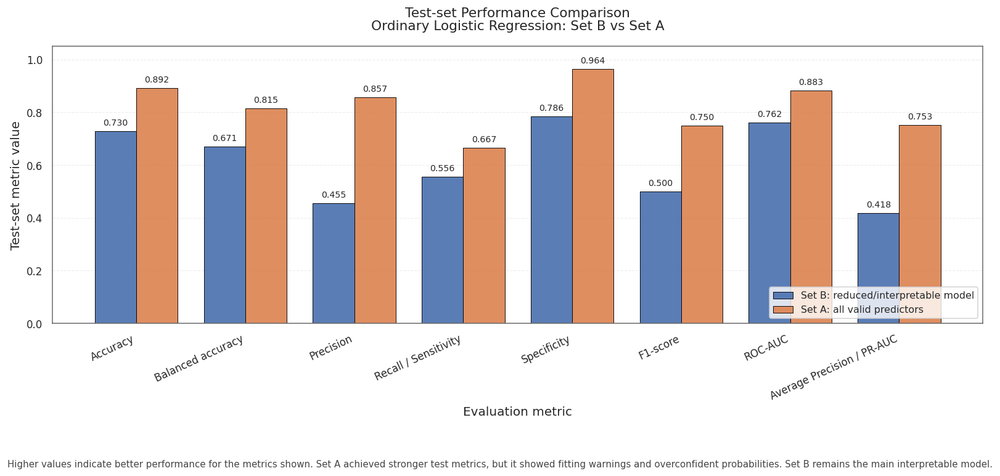

Step 15A completed successfully.
Set B vs Set A logistic regression comparison completed.

Test metrics comparison saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/36_logistic_regression_set_b_vs_set_a_test_metrics_comparison.csv
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/36_logistic_regression_set_b_vs_set_a_test_metrics_comparison.xlsx

Train-test gap comparison saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/36_logistic_regression_set_b_vs_set_a_train_test_gap_comparison.csv
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/tables/36_logistic_regression_set_b_vs_set_a_train_test_gap_comparison.xlsx

Comparison figure saved to:
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/36_final_logistic_regression_set_b_vs_set_a_test_metrics_comparison.png
/content/drive/MyDrive/TB_Burden_Classification_Thesis/results/figures/36_final_logistic_regression_set_b_vs_set_a_t

,metric,set_b_test_value,set_a_test_value,set_a_minus_set_b,higher_is_better,better_test_value
0,Accuracy,0.729730,0.891892,0.162162,True,Set A
1,Balanced accuracy,0.670635,0.815476,0.144841,True,Set A
2,Precision,0.454545,0.857143,0.402597,True,Set A
3,Recall / Sensitivity,0.555556,0.666667,0.111111,True,Set A
4,Specificity,0.785714,0.964286,0.178571,True,Set A
5,F1-score,0.500000,0.750000,0.250000,True,Set A
6,ROC-AUC,0.761905,0.882937,0.121032,True,Set A
7,Average Precision / PR-AUC,0.418175,0.753178,0.335002,True,Set A
8,Log loss,0.625031,3.733943,3.108913,False,Set B
9,Brier score,0.195873,0.108108,-0.087765,False,Set A


Train-test gap comparison:


,metric,set_b_train_value,set_b_test_value,set_b_train_minus_test,set_a_train_value,set_a_test_value,set_a_train_minus_test,higher_is_better
0,Accuracy,0.815068,0.729730,0.085339,1.000000,0.891892,0.108108,True
1,Balanced accuracy,0.733325,0.670635,0.062690,1.000000,0.815476,0.184524,True
2,Precision,0.656250,0.454545,0.201705,1.000000,0.857143,0.142857,True
3,Recall / Sensitivity,0.567568,0.555556,0.012012,1.000000,0.666667,0.333333,True
4,Specificity,0.899083,0.785714,0.113368,1.000000,0.964286,0.035714,True
5,F1-score,0.608696,0.500000,0.108696,1.000000,0.750000,0.250000,True
6,ROC-AUC,0.904786,0.761905,0.142881,1.000000,0.882937,0.117063,True
7,Average Precision / PR-AUC,0.742424,0.418175,0.324248,1.000000,0.753178,0.246822,True
8,Log loss,0.330976,0.625031,-0.294055,0.000012,3.733943,-3.733931,False
9,Brier score,0.111381,0.195873,-0.084493,0.000000,0.108108,-0.108108,False


Model role summary:


,item,value
0,Set B role,Main reduced/interpretable model
1,Set B predictor set,"13 predictors after training-only screening, S..."
2,Set B model interpretation,"Suitable for cautious coefficient, odds ratio ..."
3,Set A role,Comparison model
4,Set A predictor set,46 valid predictors before Spearman pruning
5,Set A model interpretation,Predictive comparison only because fitting war...
6,Main thesis interpretation model,Set B
7,Main predictive comparison model,Set A and Set B comparison on the test set
8,Main caution,Set A has stronger test metrics but is less st...


In [101]:
# Step 15A: Compare Logistic Regression Set B vs Set A

# Purpose:
#   To compare the ordinary logistic regression models fitted on:
#   - Set B: reduced/interpretable predictor set
#   - Set A: all valid predictors before Spearman pruning
#
# Important:
#   - This cell does not refit any model.
#   - This cell does not perform feature selection.
#   - This cell compares already computed metrics.
#   - Test-set metrics are used for final predictive comparison.
#   - Train-set metrics are used only as overfitting diagnostics.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -------------------------------------------------------------------
# 1. Required object validation
# -------------------------------------------------------------------

required_objects_for_logreg_comparison = [
    "logreg_set_b_metrics",
    "logreg_set_a_metrics",
    "TABLES_DIR",
    "FIGURES_DIR"
]

missing_objects_for_logreg_comparison = [
    object_name
    for object_name in required_objects_for_logreg_comparison
    if object_name not in globals()
]

if missing_objects_for_logreg_comparison:
    raise NameError(
        "Missing required objects for Set B vs Set A comparison: "
        f"{missing_objects_for_logreg_comparison}. "
        "Run Set B evaluation and Set A evaluation cells first."
    )

if not isinstance(logreg_set_b_metrics, pd.DataFrame):
    raise TypeError("logreg_set_b_metrics must be a pandas DataFrame.")

if not isinstance(logreg_set_a_metrics, pd.DataFrame):
    raise TypeError("logreg_set_a_metrics must be a pandas DataFrame.")

TABLES_DIR = Path(TABLES_DIR)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

FIGURES_DIR = Path(FIGURES_DIR)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------------------------
# 2. Output paths
# -------------------------------------------------------------------

LOGREG_SET_A_B_COMPARISON_CSV_PATH = (
    TABLES_DIR / "36_logistic_regression_set_b_vs_set_a_test_metrics_comparison.csv"
)

LOGREG_SET_A_B_COMPARISON_EXCEL_PATH = (
    TABLES_DIR / "36_logistic_regression_set_b_vs_set_a_test_metrics_comparison.xlsx"
)

LOGREG_SET_A_B_TRAIN_TEST_GAP_CSV_PATH = (
    TABLES_DIR / "36_logistic_regression_set_b_vs_set_a_train_test_gap_comparison.csv"
)

LOGREG_SET_A_B_TRAIN_TEST_GAP_EXCEL_PATH = (
    TABLES_DIR / "36_logistic_regression_set_b_vs_set_a_train_test_gap_comparison.xlsx"
)

LOGREG_SET_A_B_COMPARISON_FIGURE_PNG_PATH = (
    FIGURES_DIR / "36_final_logistic_regression_set_b_vs_set_a_test_metrics_comparison.png"
)

LOGREG_SET_A_B_COMPARISON_FIGURE_PDF_PATH = (
    FIGURES_DIR / "36_final_logistic_regression_set_b_vs_set_a_test_metrics_comparison.pdf"
)

# -------------------------------------------------------------------
# 3. Required metric columns
# -------------------------------------------------------------------

required_metric_columns = [
    "dataset",
    "accuracy",
    "balanced_accuracy",
    "precision_positive_class",
    "recall_sensitivity_positive_class",
    "specificity_negative_class",
    "f1_positive_class",
    "roc_auc",
    "average_precision_pr_auc",
    "log_loss",
    "brier_score"
]

missing_set_b_metric_columns = [
    column
    for column in required_metric_columns
    if column not in logreg_set_b_metrics.columns
]

missing_set_a_metric_columns = [
    column
    for column in required_metric_columns
    if column not in logreg_set_a_metrics.columns
]

if missing_set_b_metric_columns:
    raise KeyError(
        "Missing required columns in logreg_set_b_metrics: "
        f"{missing_set_b_metric_columns}"
    )

if missing_set_a_metric_columns:
    raise KeyError(
        "Missing required columns in logreg_set_a_metrics: "
        f"{missing_set_a_metric_columns}"
    )

# -------------------------------------------------------------------
# 4. Extract train and test rows
# -------------------------------------------------------------------

def extract_single_dataset_row(metrics_table, dataset_name, model_name):
    matching_rows = metrics_table[
        metrics_table["dataset"].astype(str).str.lower() == dataset_name.lower()
    ]

    if matching_rows.shape[0] != 1:
        raise ValueError(
            f"Expected exactly one '{dataset_name}' row for {model_name}, "
            f"but found {matching_rows.shape[0]}."
        )

    return matching_rows.iloc[0]


set_b_train_row = extract_single_dataset_row(
    logreg_set_b_metrics,
    dataset_name="train",
    model_name="Set B"
)

set_b_test_row = extract_single_dataset_row(
    logreg_set_b_metrics,
    dataset_name="test",
    model_name="Set B"
)

set_a_train_row = extract_single_dataset_row(
    logreg_set_a_metrics,
    dataset_name="train",
    model_name="Set A"
)

set_a_test_row = extract_single_dataset_row(
    logreg_set_a_metrics,
    dataset_name="test",
    model_name="Set A"
)

# -------------------------------------------------------------------
# 5. Create test-set comparison table
# -------------------------------------------------------------------

comparison_metrics = [
    {
        "metric": "Accuracy",
        "column": "accuracy",
        "higher_is_better": True
    },
    {
        "metric": "Balanced accuracy",
        "column": "balanced_accuracy",
        "higher_is_better": True
    },
    {
        "metric": "Precision",
        "column": "precision_positive_class",
        "higher_is_better": True
    },
    {
        "metric": "Recall / Sensitivity",
        "column": "recall_sensitivity_positive_class",
        "higher_is_better": True
    },
    {
        "metric": "Specificity",
        "column": "specificity_negative_class",
        "higher_is_better": True
    },
    {
        "metric": "F1-score",
        "column": "f1_positive_class",
        "higher_is_better": True
    },
    {
        "metric": "ROC-AUC",
        "column": "roc_auc",
        "higher_is_better": True
    },
    {
        "metric": "Average Precision / PR-AUC",
        "column": "average_precision_pr_auc",
        "higher_is_better": True
    },
    {
        "metric": "Log loss",
        "column": "log_loss",
        "higher_is_better": False
    },
    {
        "metric": "Brier score",
        "column": "brier_score",
        "higher_is_better": False
    }
]

test_comparison_rows = []

for metric_info in comparison_metrics:
    metric_name = metric_info["metric"]
    column_name = metric_info["column"]
    higher_is_better = metric_info["higher_is_better"]

    set_b_value = float(set_b_test_row[column_name])
    set_a_value = float(set_a_test_row[column_name])

    difference_set_a_minus_set_b = set_a_value - set_b_value

    if higher_is_better:
        better_model = (
            "Set A"
            if set_a_value > set_b_value
            else "Set B"
            if set_b_value > set_a_value
            else "Tie"
        )
    else:
        better_model = (
            "Set A"
            if set_a_value < set_b_value
            else "Set B"
            if set_b_value < set_a_value
            else "Tie"
        )

    test_comparison_rows.append({
        "metric": metric_name,
        "set_b_test_value": set_b_value,
        "set_a_test_value": set_a_value,
        "set_a_minus_set_b": difference_set_a_minus_set_b,
        "higher_is_better": higher_is_better,
        "better_test_value": better_model
    })

logreg_set_b_vs_set_a_test_comparison = pd.DataFrame(
    test_comparison_rows
)

# -------------------------------------------------------------------
# 6. Create train-test gap comparison table
# -------------------------------------------------------------------

gap_rows = []

for metric_info in comparison_metrics:
    metric_name = metric_info["metric"]
    column_name = metric_info["column"]
    higher_is_better = metric_info["higher_is_better"]

    set_b_train_value = float(set_b_train_row[column_name])
    set_b_test_value = float(set_b_test_row[column_name])
    set_a_train_value = float(set_a_train_row[column_name])
    set_a_test_value = float(set_a_test_row[column_name])

    gap_rows.append({
        "metric": metric_name,
        "set_b_train_value": set_b_train_value,
        "set_b_test_value": set_b_test_value,
        "set_b_train_minus_test": set_b_train_value - set_b_test_value,
        "set_a_train_value": set_a_train_value,
        "set_a_test_value": set_a_test_value,
        "set_a_train_minus_test": set_a_train_value - set_a_test_value,
        "higher_is_better": higher_is_better
    })

logreg_set_b_vs_set_a_train_test_gap_comparison = pd.DataFrame(
    gap_rows
)

# -------------------------------------------------------------------
# 7. Add model-level methodological summary
# -------------------------------------------------------------------

model_role_summary = pd.DataFrame({
    "item": [
        "Set B role",
        "Set B predictor set",
        "Set B model interpretation",
        "Set A role",
        "Set A predictor set",
        "Set A model interpretation",
        "Main thesis interpretation model",
        "Main predictive comparison model",
        "Main caution"
    ],
    "value": [
        "Main reduced/interpretable model",
        "13 predictors after training-only screening, Spearman pruning and VIF diagnostics",
        "Suitable for cautious coefficient, odds ratio and permutation importance interpretation",
        "Comparison model",
        "46 valid predictors before Spearman pruning",
        "Predictive comparison only because fitting warnings and overconfident probabilities were observed",
        "Set B",
        "Set A and Set B comparison on the test set",
        "Set A has stronger test metrics but is less stable for coefficient-level interpretation"
    ]
})

# -------------------------------------------------------------------
# 8. Save tables
# -------------------------------------------------------------------

logreg_set_b_vs_set_a_test_comparison.to_csv(
    LOGREG_SET_A_B_COMPARISON_CSV_PATH,
    index=False
)

logreg_set_b_vs_set_a_test_comparison.to_excel(
    LOGREG_SET_A_B_COMPARISON_EXCEL_PATH,
    index=False
)

logreg_set_b_vs_set_a_train_test_gap_comparison.to_csv(
    LOGREG_SET_A_B_TRAIN_TEST_GAP_CSV_PATH,
    index=False
)

logreg_set_b_vs_set_a_train_test_gap_comparison.to_excel(
    LOGREG_SET_A_B_TRAIN_TEST_GAP_EXCEL_PATH,
    index=False
)

# -------------------------------------------------------------------
# 9. Create thesis-ready test metrics comparison visualization
# -------------------------------------------------------------------

plot_metrics = [
    "Accuracy",
    "Balanced accuracy",
    "Precision",
    "Recall / Sensitivity",
    "Specificity",
    "F1-score",
    "ROC-AUC",
    "Average Precision / PR-AUC"
]

plot_table = logreg_set_b_vs_set_a_test_comparison[
    logreg_set_b_vs_set_a_test_comparison["metric"].isin(plot_metrics)
].copy()

plot_table["metric"] = pd.Categorical(
    plot_table["metric"],
    categories=plot_metrics,
    ordered=True
)

plot_table = plot_table.sort_values("metric")

x_positions = np.arange(plot_table.shape[0])
bar_width = 0.38

fig, ax = plt.subplots(figsize=(13.5, 6.8))

ax.bar(
    x_positions - bar_width / 2,
    plot_table["set_b_test_value"],
    width=bar_width,
    label="Set B: reduced/interpretable model",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.92
)

ax.bar(
    x_positions + bar_width / 2,
    plot_table["set_a_test_value"],
    width=bar_width,
    label="Set A: all valid predictors",
    edgecolor="black",
    linewidth=0.6,
    alpha=0.92
)

ax.set_xticks(x_positions)
ax.set_xticklabels(
    plot_table["metric"],
    rotation=25,
    ha="right",
    fontsize=10
)

ax.set_ylabel(
    "Test-set metric value",
    fontsize=12
)

ax.set_xlabel(
    "Evaluation metric",
    fontsize=12
)

ax.set_ylim(0, 1.05)

title_text = (
    "Test-set Performance Comparison\n"
    "Ordinary Logistic Regression: Set B vs Set A"
)

title_object = ax.set_title(
    title_text,
    fontsize=13,
    fontweight="normal",
    pad=16
)

title_object.set_linespacing(1.08)

ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.35
)

ax.grid(
    axis="x",
    visible=False
)

for spine_name in ["top", "right", "bottom", "left"]:
    ax.spines[spine_name].set_visible(True)
    ax.spines[spine_name].set_linewidth(0.9)
    ax.spines[spine_name].set_color("#666666")

ax.legend(
    loc="lower right",
    fontsize=9.5,
    frameon=True
)

# Add value labels
for bar_container in ax.containers:
    for bar in bar_container:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.3f}",
            ha="center",
            va="bottom",
            fontsize=8.5
        )

figure_note = (
    "Higher values indicate better performance for the metrics shown. "
    "Set A achieved stronger test metrics, but it showed fitting warnings and overconfident probabilities. "
    "Set B remains the main interpretable model."
)

fig.text(
    0.01,
    0.015,
    figure_note,
    ha="left",
    va="bottom",
    fontsize=9,
    color="#444444"
)

plt.tight_layout(rect=[0, 0.09, 1, 0.96])

plt.savefig(
    LOGREG_SET_A_B_COMPARISON_FIGURE_PNG_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    LOGREG_SET_A_B_COMPARISON_FIGURE_PDF_PATH,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# -------------------------------------------------------------------
# 10. Display outputs
# -------------------------------------------------------------------

def format_comparison_display_table(display_table):
    display_table = display_table.copy()

    numeric_columns = display_table.select_dtypes(include=[np.number]).columns

    for column in numeric_columns:
        display_table[column] = display_table[column].round(6)

    return display_table


print("Step 15A completed successfully.")
print("Set B vs Set A logistic regression comparison completed.")
print()

print("Test metrics comparison saved to:")
print(LOGREG_SET_A_B_COMPARISON_CSV_PATH)
print(LOGREG_SET_A_B_COMPARISON_EXCEL_PATH)
print()

print("Train-test gap comparison saved to:")
print(LOGREG_SET_A_B_TRAIN_TEST_GAP_CSV_PATH)
print(LOGREG_SET_A_B_TRAIN_TEST_GAP_EXCEL_PATH)
print()

print("Comparison figure saved to:")
print(LOGREG_SET_A_B_COMPARISON_FIGURE_PNG_PATH)
print(LOGREG_SET_A_B_COMPARISON_FIGURE_PDF_PATH)
print()

print("Test-set metrics comparison:")
display(
    format_comparison_display_table(
        logreg_set_b_vs_set_a_test_comparison
    )
)

print("Train-test gap comparison:")
display(
    format_comparison_display_table(
        logreg_set_b_vs_set_a_train_test_gap_comparison
    )
)

print("Model role summary:")
display(model_role_summary)